In [ ]:
# MB Data Visualization

In [3]:

# ============================================================
# STEP 1: CONNECT GOOGLE DRIVE
# ============================================================
# PURPOSE:
# Connect Google Colab to Google Drive so that Python can
# access the forest inventory datasets and Excel workbook.
#
# WHY THIS IS NECESSARY:
# Colab runs in a cloud environment. It cannot automatically
# access files stored in your personal Google Drive.
# Mounting Drive makes those files accessible to Python.
# ============================================================

from google.colab import drive

# Authenticate and mount Google Drive.
# After running this line, follow the authorization prompts.
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:

# ============================================================
# STEP 2: IMPORT ANALYTICAL AND VISUALIZATION LIBRARIES
# ============================================================
# PURPOSE:
# Load the Python libraries needed to organize, analyze,
# manipulate, and visualize the forest inventory data.
# ============================================================

# pandas: Import, organize, filter, and analyze tabular data.
import pandas as pd

# numpy: Perform numerical calculations and handle missing data.
import numpy as np

# matplotlib: Create figures, graphs, and multi-panel layouts.
import matplotlib.pyplot as plt

# seaborn: Create statistical visualizations using matplotlib.
import seaborn as sns

# pathlib: Manage file paths and locate datasets in Google Drive.
from pathlib import Path


In [5]:

# ============================================================
# STEP 3: IDENTIFY FILES IN GOOGLE DRIVE
# ============================================================
# PURPOSE:
# Display the contents of the main Google Drive directory
# so we can identify the folder containing the inventory data.
# ============================================================

# Define the location of the main Google Drive directory.
drive_directory = Path('/content/drive/MyDrive')

# Display all files and folders within that directory.
for item in drive_directory.iterdir():
    print(item.name)


Getting started.pdf
Mina: Soccer
Campfire
Dad and Mina
Halloween 2013
Mina
mina and i 
hardwood placerville
Pool
Pool 2
NOLA
new floors placerville office
Part One: Short Answers .gdoc
Collage .gdoc
collage .gdoc
collage 3.gdoc
Untitled document (67).gdoc
 Eco-Friendly Funeral Options: A Rising Tide of Diverse Memorialization .gdoc
image0.jpeg
Volunteer.gdoc
Video (1).mov
Video.mov
Untitled document (66).gdoc
Untitled document (65).gdoc
MVI_0179.MP4
Untitled document (64).gdoc
9 28 Class.gdoc
11 28.gdoc
28.docx
Textproduktion 1.gdoc
Resume (4).gdoc
Resume (3).gdoc
Resume (2).gdoc
Resume (1).gdoc
Pet resume (1).gdoc
Pet resume.gdoc
Letter of Support - Ed Bixby.gdoc
Ed Bixby Resume.gdoc
Ed Bixby - Links, Media, Etc.gdoc
fy24-heritage-fellowship-notice-of-intent-form.gdoc
Untitled document (63).gdoc
Letter of Reccomendation.gdoc
Untitled document (62).gdoc
Untitled form.gform
Untitled form (Responses).gsheet
Imagination Theater.gdoc
UNH Academics & Cost vs Colby Sawyer College .gdoc
Untit

In [8]:

# ============================================================
# STEP 4: CHECK THE PROJECT FOLDER
# ============================================================
# PURPOSE:
# Confirm that Python can locate the "data" folder and
# determine whether it contains our inventory datasets.
# ============================================================

from pathlib import Path

# Identify the project folder in Google Drive.
project_dir = Path('/content/drive/MyDrive/data')

# Check whether the folder actually exists.
print("Folder exists:", project_dir.exists())

# Check whether the path points to a folder.
print("Is a directory:", project_dir.is_dir())

# List all files and folders inside it.
print("\nContents of project folder:")

for item in project_dir.iterdir():
    print(item.name)


Folder exists: True
Is a directory: True

Contents of project folder:


In [9]:

# ============================================================
# STEP 5: SET THE FOREST INVENTORY PROJECT DIRECTORY
# ============================================================
# PURPOSE:
# Direct Python to the ENV301 folder containing the
# forest inventory datasets and Excel workbook.
# ============================================================

from pathlib import Path

# Define the location of the ENV301 project folder.
project_dir = Path('/content/drive/MyDrive/ENV301')

# Confirm that Python can locate the folder.
print("Project folder exists:", project_dir.exists())

# Display all files and folders inside ENV301.
print("\nFiles in ENV301:")

for item in project_dir.iterdir():
    print(item.name)


Project folder exists: True

Files in ENV301:
script
data


In [10]:

# ============================================================
# STEP 6: INSPECT THE INVENTORY DATA DIRECTORY
# ============================================================
# PURPOSE:
# Navigate into ENV301/data and identify all available
# forest inventory datasets.
#
# WHY THIS IS NECESSARY:
# We need the exact filenames before importing the data.
# This also helps prevent file-not-found errors later.
# ============================================================

# Define the directory containing the inventory datasets.
data_dir = project_dir / 'data'

# Confirm that the directory exists.
print("Data directory exists:", data_dir.exists())

# Display all files in the directory.
print("\nAvailable inventory datasets:")

for file in data_dir.iterdir():
    print(file.name)


Data directory exists: True

Available inventory datasets:
11.13.2026 MB Datasheet (EDIT ME!).xlsx
11.11.2026 CWD.csv
11.11.2026 FWD.csv
11.11.2026 Herbaceous.csv
11.11.2026 Hydrology and Surface.csv
11.11.2026 Microplot.csv
11.11.2026 Plot Metadata.csv
11.11.2026 Subplot Metadata.csv
11.11.2026 Woody Cover.csv
11.11.2026 Woody Species.csv


In [11]:

# ============================================================
# STEP 7: IMPORT THE FOREST INVENTORY DATASETS
# ============================================================
# PURPOSE:
# Import each CSV file into Python as a pandas DataFrame.
#
# WHAT IS A DATAFRAME?
# A DataFrame is a table containing rows and columns.
# Each dataset will have its own DataFrame so we can analyze
# different components of forest composition and structure.
#
# WHY KEEP THE DATASETS SEPARATE?
# Each dataset represents a different sampling component.
# We will connect them later using shared identifiers such
# as Stand ID, Plot ID, and Subplot ID.
#
# IMPORTANT:
# We are importing the original data without modifying it.
# ============================================================

# Import woody tree measurements.
woody = pd.read_csv(data_dir / '11.11.2026 Woody Species.csv')

# Import overstory and understory woody vegetation cover.
woody_cover = pd.read_csv(data_dir / '11.11.2026 Woody Cover.csv')

# Import plot-level information, including natural community
# classification and stand characteristics.
plot_metadata = pd.read_csv(data_dir / '11.11.2026 Plot Metadata.csv')

# Import subplot-level information, including elevation,
# slope, aspect, and dominant cover.
subplot_metadata = pd.read_csv(data_dir / '11.11.2026 Subplot Metadata.csv')

# Import herbaceous vegetation observations.
herbaceous = pd.read_csv(data_dir / '11.11.2026 Herbaceous.csv')

# Import seedling and sapling observations.
microplot = pd.read_csv(data_dir / '11.11.2026 Microplot.csv')

# Import hydrology and forest-floor surface measurements.
hydrology_surface = pd.read_csv(
    data_dir / '11.11.2026 Hydrology and Surface.csv'
)

# Import fine woody debris measurements.
fwd = pd.read_csv(data_dir / '11.11.2026 FWD.csv')

# Import coarse woody debris measurements.
cwd = pd.read_csv(data_dir / '11.11.2026 CWD.csv')

# Import the Excel workbook containing species abbreviation keys.
workbook = data_dir / '11.13.2026 MB Datasheet (EDIT ME!).xlsx'

# ============================================================
# VERIFY THE DATA IMPORTS
# ============================================================
# PURPOSE:
# Confirm that every dataset was successfully imported.
#
# len() returns the number of rows in each DataFrame.
# This allows us to check that the datasets contain records.
# ============================================================

datasets = {
    'Woody Species': woody,
    'Woody Cover': woody_cover,
    'Plot Metadata': plot_metadata,
    'Subplot Metadata': subplot_metadata,
    'Herbaceous': herbaceous,
    'Microplot': microplot,
    'Hydrology and Surface': hydrology_surface,
    'Fine Woody Debris': fwd,
    'Coarse Woody Debris': cwd
}

for name, dataframe in datasets.items():
    print(f'{name}: {len(dataframe)} rows')

Woody Species: 499 rows
Woody Cover: 244 rows
Plot Metadata: 13 rows
Subplot Metadata: 58 rows
Herbaceous: 213 rows
Microplot: 163 rows
Hydrology and Surface: 58 rows
Fine Woody Debris: 175 rows
Coarse Woody Debris: 150 rows


In [12]:

# ============================================================
# STEP 8: STANDARDIZE COLUMN NAMES
# ============================================================
# PURPOSE:
# Remove accidental spaces from the beginning or end of
# column names in every dataset.
#
# WHY THIS IS NECESSARY:
# Python treats column names with different spacing as
# different variables.
#
# For example:
# 'Species Code ' is not the same as 'Species Code'.
#
# We are changing column labels only, NOT the actual data.
# ============================================================

# Loop through every DataFrame in our datasets dictionary.
for name, dataframe in datasets.items():

    # Remove leading and trailing spaces from column names.
    dataframe.columns = dataframe.columns.str.strip()

    # Print the dataset name to confirm it was processed.
    print(f'{name}: column names standardized')


Woody Species: column names standardized
Woody Cover: column names standardized
Plot Metadata: column names standardized
Subplot Metadata: column names standardized
Herbaceous: column names standardized
Microplot: column names standardized
Hydrology and Surface: column names standardized
Fine Woody Debris: column names standardized
Coarse Woody Debris: column names standardized


In [13]:

# ============================================================
# STEP 9: INSPECT DATASET STRUCTURE
# ============================================================
# PURPOSE:
# Display the column names for each dataset.
#
# WHY THIS IS NECESSARY:
# We need to identify the variables available for analysis,
# understand how datasets relate to one another, and
# determine which measurements can be used in our figures.
# ============================================================

# Loop through each dataset and display its column names.
for name, dataframe in datasets.items():

    print('\n' + '=' * 60)
    print(name.upper())
    print('=' * 60)

    # Display each column name on its own line.
    for column in dataframe.columns:
        print(column)



WOODY SPECIES
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Tree ID
Species Code
Tree Status
DBH (in)
Estimated Tree Height (m)
Estimated Tree Height (ft)
Crown Class Code
Damage Type Code
Snag Decay Class (If Applicable)
Notes

WOODY COVER
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Species ID
Overstory Cover (%) Code
Understory Cover (%) Code
Notes

PLOT METADATA
Stand
Plot ID
Date
Team Member(s)
Natural Community Code
Stand Age Code
Topography Code
Water (Absent/Present)
Water Type (If Applicable)
Disturbance Code
Notes

SUBPLOT METADATA
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Elevation (ft)
Slope (%)
Aspect
Dominant Cover Code
Notes

HERBACEOUS
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Species ID
Invasive (Y/N)
General Phenological State
Damage Type Code
Percent Cover (%)
Notes
Unnamed: 11
Unnamed: 12

MICROPLOT
Stand ID
Plot ID
Subplot ID
Microplot ID
Date
Team Member(s)
Species ID
Seedling/Sapling?
Count
Damage Type Code
Notes

HYDROLOGY AND SURFACE
Stand ID


In [14]:

# ============================================================
# STEP 10: EXAMINE THE SAMPLING HIERARCHY
# ============================================================
# PURPOSE:
# Determine how many stands, plots, and subplots are
# represented in each inventory dataset.
#
# WHY THIS IS NECESSARY:
# Our observations are organized hierarchically:
#
# Stand
#   └── Plot
#         └── Subplot
#               └── Individual observations
#
# Understanding this structure is essential for calculating
# meaningful stand-level ecological summaries.
#
# IMPORTANT:
# Plot Metadata uses "Stand" rather than "Stand ID".
# We account for that difference below.
# ============================================================

# Identify the stand identifier column in each dataset.
stand_columns = {
    'Woody Species': 'Stand ID',
    'Woody Cover': 'Stand ID',
    'Plot Metadata': 'Stand',
    'Subplot Metadata': 'Stand ID',
    'Herbaceous': 'Stand ID',
    'Microplot': 'Stand ID',
    'Hydrology and Surface': 'Stand ID',
    'Fine Woody Debris': 'Stand ID',
    'Coarse Woody Debris': 'Stand ID'
}

# Examine the sampling structure of each dataset.
for name, dataframe in datasets.items():

    # Retrieve the appropriate stand identifier column.
    stand_col = stand_columns[name]

    print('\n' + '=' * 60)
    print(name.upper())
    print('=' * 60)

    # Count the number of distinct stands.
    print("Number of stands:", dataframe[stand_col].nunique())

    # Count the number of distinct plots.
    print("Number of plots:", dataframe['Plot ID'].nunique())

    # Count the number of distinct stand-plot combinations.
    print(
        "Stand-plot combinations:",
        dataframe[[stand_col, 'Plot ID']].drop_duplicates().shape[0]
    )

    # Count distinct stand-plot-subplot combinations,
    # when subplot identifiers are available.
    if 'Subplot ID' in dataframe.columns:

        print(
            "Stand-plot-subplot combinations:",
            dataframe[[stand_col, 'Plot ID', 'Subplot ID']]
            .drop_duplicates()
            .shape[0]
        )



WOODY SPECIES
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 14
Stand-plot-subplot combinations: 59

WOODY COVER
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 14
Stand-plot-subplot combinations: 57

PLOT METADATA
Number of stands: 6
Number of plots: 4
Stand-plot combinations: 12

SUBPLOT METADATA
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 14
Stand-plot-subplot combinations: 58

HERBACEOUS
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 13
Stand-plot-subplot combinations: 53

MICROPLOT
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 15
Stand-plot-subplot combinations: 57

HYDROLOGY AND SURFACE
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 14
Stand-plot-subplot combinations: 58

FINE WOODY DEBRIS
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 14
Stand-plot-subplot combinations: 58

COARSE WOODY DEBRIS
Number of stands: 8
Number of plots: 4
Stand-plot combinations: 1

In [15]:

# ============================================================
# STEP 13: COUNT OBSERVATIONS WITHIN EACH STAND
# ============================================================
# PURPOSE:
# Determine how many records each stand contributes to
# each ecological dataset.
#
# WHY THIS IS NECESSARY:
# Different stands may have different numbers of completed
# sampling observations.
#
# These counts will help us interpret stand-level summaries
# and identify differences in sampling effort.
#
# IMPORTANT:
# These are record counts, NOT necessarily counts of trees,
# species, or sampling locations.
# ============================================================

# Examine each dataset separately.
for name, dataframe in datasets.items():

    # Identify the correct stand column.
    stand_col = stand_columns[name]

    print('\n' + '=' * 60)
    print(name.upper())
    print('=' * 60)

    # Count the number of records associated with each stand.
    records_per_stand = (
        dataframe.groupby(stand_col)
        .size()
        .reset_index(name='Number of Records')
    )

    # Display the results.
    print(records_per_stand.to_string(index=False))



WOODY SPECIES
 Stand ID  Number of Records
        1                 21
        2                104
        3                 32
        4                208
        5                 40
        6                 61
        7                 29
        9                  4

WOODY COVER
 Stand ID  Number of Records
        1                  6
        2                 63
        3                 24
        4                 81
        5                  9
        6                 34
        7                 22
        9                  5

PLOT METADATA
 Stand  Number of Records
     1                  1
     2                  4
     3                  2
     4                  3
     5                  2
     6                  1

SUBPLOT METADATA
 Stand ID  Number of Records
        1                  1
        2                 15
        3                  6
        4                 22
        5                  3
        6                  7
        7                  3
   

In [16]:

# ============================================================
# STEP 14: LOAD SPECIES IDENTIFICATION KEYS
# ============================================================
# PURPOSE:
# Import the species abbreviation tables from the Excel
# workbook so that field codes can be translated into
# readable species names.
#
# WHY THIS IS NECESSARY:
# Our inventory datasets contain abbreviated species codes.
# Translating these codes will allow us to calculate species
# composition and produce figures with readable labels.
#
# We are loading the keys separately from the observations
# to preserve the original inventory data.
# ============================================================

# Load the woody species identification key.
woody_key = pd.read_excel(
    workbook,
    sheet_name='Woody Species Data Abb. Key'
)

# Load the herbaceous species identification key.
herbaceous_key = pd.read_excel(
    workbook,
    sheet_name='Herbaceous Species Abb. Key'
)

# Remove accidental spaces from the key column names.
woody_key.columns = woody_key.columns.str.strip()
herbaceous_key.columns = herbaceous_key.columns.str.strip()

# Display the woody species key structure.
print("WOODY SPECIES KEY")
print(woody_key.head(10).to_string(index=False))

# Display the herbaceous species key structure.
print("\nHERBACEOUS SPECIES KEY")
print(herbaceous_key.head(10).to_string(index=False))


WOODY SPECIES KEY
     Hardwood Species      Common Name Standard FIA Code Code  Unnamed: 4              Crown Class                                                                                                                                                              Definition Code
      Acer saccharum       Sugar Maple              ACSA   SM         NaN               Open Grown                                                                         Trees with crowns that receive full light above and at their sides; wolf trees / few neighbors.    1
          Acer rubrum        Red Maple              ACRU   RM         NaN                Dominant  Trees with crowns extending above the general level of the canopy. Full light above; partial light on the sides. Generally larger than the average trees in the stand.     2
Betula alleghaniensis     Yellow Birch              BEAL   YB         NaN             Co-Dominant                   Trees with crowns forming the general level of the

In [19]:

# ============================================================
# STEP 15: CREATE SPECIES LOOKUP DICTIONARIES
# ============================================================
# PURPOSE:
# Extract the correct species codes and common names from
# the Excel reference tables.
#
# IMPORTANT:
# The woody key contains two columns named "Code".
# We select the first one by position because it contains
# the woody species abbreviations.
# ============================================================

# ------------------------------------------------------------
# 1. WOODY SPECIES LOOKUP
# ------------------------------------------------------------

# Select columns by position:
# Column 1 = Common Name
# Column 3 = Woody species field Code
woody_key_clean = woody_key.iloc[:, [3, 1]].copy()

# Give the selected columns unique, descriptive names.
woody_key_clean.columns = ['Species Code', 'Common Name']

# Remove rows where either species code or name is missing.
woody_key_clean = woody_key_clean.dropna(
    subset=['Species Code', 'Common Name']
)

# Remove accidental spaces from both columns.
for column in ['Species Code', 'Common Name']:
    woody_key_clean[column] = (
        woody_key_clean[column].astype(str).str.strip()
    )

# Create the woody species lookup dictionary.
woody_species_lookup = dict(
    zip(
        woody_key_clean['Species Code'],
        woody_key_clean['Common Name']
    )
)


# ------------------------------------------------------------
# 2. HERBACEOUS SPECIES LOOKUP
# ------------------------------------------------------------

# Select the herbaceous field codes and common names.
herbaceous_key_clean = herbaceous_key[
    ['Common Field Code', 'Common Name']
].copy()

# Remove rows with missing codes or names.
herbaceous_key_clean = herbaceous_key_clean.dropna(
    subset=['Common Field Code', 'Common Name']
)

# Remove accidental spaces.
for column in ['Common Field Code', 'Common Name']:
    herbaceous_key_clean[column] = (
        herbaceous_key_clean[column].astype(str).str.strip()
    )

# Create the herbaceous species lookup dictionary.
herbaceous_species_lookup = dict(
    zip(
        herbaceous_key_clean['Common Field Code'],
        herbaceous_key_clean['Common Name']
    )
)


# ------------------------------------------------------------
# 3. VERIFY THE LOOKUP DICTIONARIES
# ------------------------------------------------------------

print("Woody species codes:", len(woody_species_lookup))
print("Herbaceous species codes:", len(herbaceous_species_lookup))

print("\nWoody species examples:")
for code, name in list(woody_species_lookup.items())[:10]:
    print(f"{code} = {name}")

print("\nHerbaceous species examples:")
for code, name in list(herbaceous_species_lookup.items())[:10]:
    print(f"{code} = {name}")


Woody species codes: 23
Herbaceous species codes: 32

Woody species examples:
SM = Sugar Maple
RM = Red Maple
YB = Yellow Birch
WB = White Birch
BB = Black Birch
AB = American Beech
WO = White Oak
RO = Northern Red Oak
WA = White Ash
BTA = Bigtooth Aspen

Herbaceous species examples:
CM = Canada Mayflower
SF = Starflower
RT = Red / Purple Trillium
PT = Painted Trillium
TL = Trout Lily
BL = Bluebead Lily
IC = Indian Cucumber-Root
WS = Mountain Wood-Sorrel
GT = Goldthread
SS = Hairy Solomon's-Seal


In [20]:

# ============================================================
# STEP 16: TRANSLATE SPECIES CODES INTO COMMON NAMES
# ============================================================
# PURPOSE:
# Use our species lookup dictionaries to translate field
# abbreviations into readable species names.
#
# DATASETS BEING UPDATED:
# 1. Woody Species
# 2. Woody Cover
# 3. Herbaceous
# 4. Microplot
#
# WHY THIS IS NECESSARY:
# Common names will make our graphs easier to interpret.
#
# IMPORTANT:
# We preserve the original species codes in their existing
# columns and create NEW columns called "Species Name".
# If a code cannot be matched, its original value is retained.
# ============================================================


# ------------------------------------------------------------
# 1. TRANSLATE WOODY TREE SPECIES
# ------------------------------------------------------------

# Convert woody species codes into common names.
woody['Species Name'] = (
    woody['Species Code']
    .astype('string')
    .str.strip()
    .map(woody_species_lookup)
    .fillna(woody['Species Code'])
)


# ------------------------------------------------------------
# 2. TRANSLATE WOODY COVER SPECIES
# ------------------------------------------------------------

# Woody Cover uses the column "Species ID" for species codes.
woody_cover['Species Name'] = (
    woody_cover['Species ID']
    .astype('string')
    .str.strip()
    .map(woody_species_lookup)
    .fillna(woody_cover['Species ID'])
)


# ------------------------------------------------------------
# 3. TRANSLATE HERBACEOUS SPECIES
# ------------------------------------------------------------

# Translate herbaceous field codes into common names.
herbaceous['Species Name'] = (
    herbaceous['Species ID']
    .astype('string')
    .str.strip()
    .map(herbaceous_species_lookup)
    .fillna(herbaceous['Species ID'])
)


# ------------------------------------------------------------
# 4. TRANSLATE SEEDLING AND SAPLING SPECIES
# ------------------------------------------------------------

# Microplot contains woody regeneration species.
# Therefore, we use the woody species lookup dictionary.
microplot['Species Name'] = (
    microplot['Species ID']
    .astype('string')
    .str.strip()
    .map(woody_species_lookup)
    .fillna(microplot['Species ID'])
)


# ------------------------------------------------------------
# 5. VERIFY THE SPECIES TRANSLATIONS
# ------------------------------------------------------------

# Display examples of the original codes and translated names.
print("WOODY TREE SPECIES")
print(
    woody[['Species Code', 'Species Name']]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)

print("\nHERBACEOUS SPECIES")
print(
    herbaceous[['Species ID', 'Species Name']]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)

print("\nSEEDLING AND SAPLING SPECIES")
print(
    microplot[['Species ID', 'Species Name']]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)


WOODY TREE SPECIES
Species Code       Species Name
          YB       Yellow Birch
          EH    Eastern Hemlock
          AB     American Beech
          RM          Red Maple
          WO          White Oak
          SM        Sugar Maple
          WB        White Birch
        UNKH               UNKH
          WA          White Ash
          Wo                 Wo
          RO   Northern Red Oak
          WP Eastern White Pine
Silver Maple       Silver Maple
          GB                 GB
         WP  Eastern White Pine

HERBACEOUS SPECIES
              Species ID                     Species Name
                     PRP Princess Pine / Tree Ground-Pine
                      SF                       Starflower
                     XMF                   Christmas Fern
                     INT                 Interrupted Fern
    Northern Wild Raisin             Northern Wild Raisin
    Rattlesnake Plantain             Rattlesnake Plantain
  Intermediate Wood Fern           Intermed

In [21]:

# ============================================================
# STEP 17: STANDARDIZE SPECIES IDENTIFIERS AND CHECK MATCHES
# ============================================================
# PURPOSE:
# Resolve capitalization differences and identify species
# entries that are not represented in our lookup dictionaries.
#
# WHY THIS IS NECESSARY:
# "WO" and "Wo" should identify the same species.
# However, full species names should remain unchanged.
#
# We will not delete or discard any observations.
# ============================================================


# ------------------------------------------------------------
# 1. CREATE CASE-INSENSITIVE LOOKUP DICTIONARIES
# ------------------------------------------------------------

# Convert woody lookup codes to uppercase.
woody_lookup_normalized = {
    code.upper(): name
    for code, name in woody_species_lookup.items()
}

# Convert herbaceous lookup codes to uppercase.
herbaceous_lookup_normalized = {
    code.upper(): name
    for code, name in herbaceous_species_lookup.items()
}


# ------------------------------------------------------------
# 2. DEFINE A FUNCTION TO TRANSLATE SPECIES IDENTIFIERS
# ------------------------------------------------------------

def translate_species(values, lookup):
    """
    Translate abbreviated species codes into common names.

    Existing full species names and unidentified codes are
    preserved if they do not match a lookup entry.
    """

    return (
        values.astype('string')
        .str.strip()
        .str.upper()
        .map(lookup)
        .fillna(values)
    )


# ------------------------------------------------------------
# 3. UPDATE SPECIES NAME COLUMNS
# ------------------------------------------------------------

# Apply case-insensitive matching to woody species.
woody['Species Name'] = translate_species(
    woody['Species Code'],
    woody_lookup_normalized
)

# Apply matching to woody cover.
woody_cover['Species Name'] = translate_species(
    woody_cover['Species ID'],
    woody_lookup_normalized
)

# Apply matching to herbaceous species.
herbaceous['Species Name'] = translate_species(
    herbaceous['Species ID'],
    herbaceous_lookup_normalized
)

# Apply matching to seedlings and saplings.
microplot['Species Name'] = translate_species(
    microplot['Species ID'],
    woody_lookup_normalized
)


# ------------------------------------------------------------
# 4. IDENTIFY ENTRIES NOT FOUND IN THE LOOKUP DICTIONARIES
# ------------------------------------------------------------

# Build sets of recognized common names.
woody_common_names = {
    name.strip().casefold()
    for name in woody_species_lookup.values()
}

herbaceous_common_names = {
    name.strip().casefold()
    for name in herbaceous_species_lookup.values()
}


# Check woody species entries.
print("WOODY SPECIES ENTRIES NOT IN LOOKUP")

woody_unmatched = sorted(
    value for value in woody['Species Code'].dropna().astype(str).unique()
    if value.strip().upper() not in woody_lookup_normalized
    and value.strip().casefold() not in woody_common_names
)

print(woody_unmatched)


# Check herbaceous species entries.
print("\nHERBACEOUS SPECIES ENTRIES NOT IN LOOKUP")

herbaceous_unmatched = sorted(
    value for value in herbaceous['Species ID'].dropna().astype(str).unique()
    if value.strip().upper() not in herbaceous_lookup_normalized
    and value.strip().casefold() not in herbaceous_common_names
)

print(herbaceous_unmatched)


# Check regeneration species entries.
print("\nMICROPLOT SPECIES ENTRIES NOT IN LOOKUP")

microplot_unmatched = sorted(
    value for value in microplot['Species ID'].dropna().astype(str).unique()
    if value.strip().upper() not in woody_lookup_normalized
    and value.strip().casefold() not in woody_common_names
)

print(microplot_unmatched)


WOODY SPECIES ENTRIES NOT IN LOOKUP
['American Hophornbean', 'GB', 'Scarlet Oak', 'Silver Maple', 'UNKH']

HERBACEOUS SPECIES ENTRIES NOT IN LOOKUP
['American Royal Fern', 'Beech Drops ', 'Beech drops', 'Bluestem Goldenrod ', 'Calico Aster', 'Cinnamon Willowherb', 'Common Cinquefoil ', 'Common Marsh Bedstraw', 'Creeping Foam Flower ', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Horsetail', 'Dwarf Raspberry', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw ', 'Heath Speedwell', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Largeleaf White Violet ', 'Long Awned Wood Grass', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Spurred Violet ', 'Meadow Rue', 'Northern Wild Raisin', 'PBG', 'PTB', 'Poverty Oatgrass', 'Prickly Tree Clubmoss', 'Rattlesnake Plantain', 'Sensitive Fern', 'Shinleaf', 'Shinleaf ', 'Side Flowering Skullcap', 'Small Flowered Buttercup', 'Spinulosa Wood Fern', 'Striped Wintergreen', 'Swamp Dewberry', 'Trailing Arbutus', 

In [22]:

# ============================================================
# STEP 18: STANDARDIZE ALL SPECIES IDENTIFIERS
# ============================================================
# PURPOSE:
# Convert abbreviations into full common names while
# preserving species names that are already written out.
#
# This creates consistent species labels across all datasets.
# ============================================================

# ------------------------------------------------------------
# 1. ADD CONFIRMED WOODY SPECIES IDENTIFICATIONS
# ------------------------------------------------------------

woody_lookup_normalized.update({
    'GB': 'Gray Birch',
    'STM': 'Striped Maple',
    'UNKH': 'Unknown Hardwood'
})

# Add the confirmed names to the original lookup as well.
woody_species_lookup.update(woody_lookup_normalized)


# ------------------------------------------------------------
# 2. DEFINE ADDITIONAL KNOWN SPECIES NAME CORRECTIONS
# ------------------------------------------------------------

# These entries are already full names, or are spelling
# corrections, rather than abbreviations.
species_name_corrections = {
    'American Hophornbean': 'American Hophornbeam',
    'Beech drops': 'Beech Drops',
    'Shinleaf': 'Shinleaf'
}


# ------------------------------------------------------------
# 3. CREATE A UNIVERSAL STANDARDIZATION FUNCTION
# ------------------------------------------------------------

def standardize_species(values, lookup, corrections=None):

    # Convert values to strings and remove surrounding spaces.
    standardized = values.astype('string').str.strip()

    # Normalize capitalization for matching abbreviations.
    normalized_codes = standardized.str.upper()

    # Translate abbreviations into full common names.
    standardized = normalized_codes.map(lookup).fillna(standardized)

    # Apply spelling and naming corrections.
    if corrections is not None:

        # Match corrections without regard to capitalization.
        correction_lookup = {
            key.casefold(): value
            for key, value in corrections.items()
        }

        standardized = standardized.map(
            lambda value: correction_lookup.get(
                str(value).casefold(), value
            )
        )

    return standardized


# ------------------------------------------------------------
# 4. APPLY STANDARDIZATION TO ALL FOUR DATASETS
# ------------------------------------------------------------

# Standardize established woody tree species.
woody['Species Name'] = standardize_species(
    woody['Species Code'],
    woody_lookup_normalized,
    species_name_corrections
)

# Standardize woody cover species.
woody_cover['Species Name'] = standardize_species(
    woody_cover['Species ID'],
    woody_lookup_normalized,
    species_name_corrections
)

# Standardize herbaceous species.
herbaceous['Species Name'] = standardize_species(
    herbaceous['Species ID'],
    herbaceous_lookup_normalized,
    species_name_corrections
)

# Standardize seedling and sapling species.
microplot['Species Name'] = standardize_species(
    microplot['Species ID'],
    woody_lookup_normalized,
    species_name_corrections
)


# ------------------------------------------------------------
# 5. VERIFY THE STANDARDIZED SPECIES NAMES
# ------------------------------------------------------------

print("WOODY TREE SPECIES")
print(sorted(woody['Species Name'].dropna().unique()))

print("\nHERBACEOUS SPECIES")
print(sorted(herbaceous['Species Name'].dropna().unique()))

print("\nREGENERATION SPECIES")
print(sorted(microplot['Species Name'].dropna().unique()))


WOODY TREE SPECIES
['American Beech', 'American Hophornbeam', 'Balsam Fir', 'Eastern Hemlock', 'Eastern White Pine', 'Gray Birch', 'Northern Red Oak', 'Red Maple', 'Scarlet Oak', 'Silver Maple', 'Sugar Maple', 'Unknown Hardwood', 'White Ash', 'White Birch', 'White Oak', 'Yellow Birch']

HERBACEOUS SPECIES
['American Royal Fern', 'Beech Drops', 'Bluestem Goldenrod', 'Bracken Fern', 'Bunchberry', 'Calico Aster', 'Canada Mayflower', 'Christmas Fern', 'Cinnamon Fern', 'Cinnamon Willowherb', 'Common Cinquefoil', 'Common Marsh Bedstraw', 'Creeping Foam Flower', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Horsetail', 'Dwarf Raspberry', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw', 'Goldthread', 'Heath Speedwell', 'Hobblebush', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Interrupted Fern', 'Largeleaf White Violet', 'Long Awned Wood Grass', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Awned Wood Grass', 'Long-Spurred Violet', 'Lowbush

In [23]:
#STEP 19

# Display the rows in the herbaceous species key that contain the
# unresolved abbreviations, so we can identify their full common names.

# Convert the key's field-code column to strings and remove extra spaces.
herb_codes = herbaceous_key_clean['Common Field Code'].astype(str).str.strip()

# Select only the rows whose codes match PBG, PTB, or WTB.
unresolved_herb_codes = herbaceous_key_clean[
    herb_codes.str.upper().isin(['PBG', 'PTB', 'WTB'])
]

# Print the matching rows from the key.
print("Unresolved herbaceous codes in the key:")
display(unresolved_herb_codes)


# Check whether AM and EWP appear in the woody species key.
# These are the two unresolved regeneration codes.
woody_codes = woody_key_clean['Species Code'].astype(str).str.strip()

unresolved_regeneration_codes = woody_key_clean[
    woody_codes.str.upper().isin(['AM', 'EWP'])
]

# Print any matching woody-key entries.
print("\nUnresolved regeneration codes in the woody key:")
display(unresolved_regeneration_codes)

Unresolved herbaceous codes in the key:


,Common Field Code,Common Name



Unresolved regeneration codes in the woody key:


,Species Code,Common Name


In [24]:
# STEP 20: STANDARDIZE HERBACEOUS SPECIES NAMES
#
# Goal:
# Make the three herbaceous species labels consistent throughout
# the dataset by removing unnecessary wording and standardizing
# punctuation.

# Create a dictionary that connects each current name to its
# preferred standardized name.
herbaceous_name_corrections = {
    'Long Awned Wood Grass': 'Long-Awned Wood Grass',
    'Wintergreen / Teaberry': 'Wintergreen',
    'Princess Pine / Tree Ground-Pine': 'Princess Pine'
}

# Apply the name corrections to the Species Name column.
# All other species names and observations remain unchanged.
herbaceous['Species Name'] = (
    herbaceous['Species Name']
    .replace(herbaceous_name_corrections)
)

# Print the unique species names in alphabetical order.
# This allows us to verify that the corrections worked.
print("Standardized herbaceous species:")
print(sorted(herbaceous['Species Name'].dropna().unique()))

Standardized herbaceous species:
['American Royal Fern', 'Beech Drops', 'Bluestem Goldenrod', 'Bracken Fern', 'Bunchberry', 'Calico Aster', 'Canada Mayflower', 'Christmas Fern', 'Cinnamon Fern', 'Cinnamon Willowherb', 'Common Cinquefoil', 'Common Marsh Bedstraw', 'Creeping Foam Flower', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Horsetail', 'Dwarf Raspberry', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw', 'Goldthread', 'Heath Speedwell', 'Hobblebush', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Interrupted Fern', 'Largeleaf White Violet', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Awned Wood Grass', 'Long-Spurred Violet', 'Lowbush Blueberry', 'Marginal Wood Fern', 'Meadow Rue', 'Mountain Wood-Sorrel', 'Northern Wild Raisin', 'PBG', 'PTB', 'Partridgeberry', 'Poverty Oatgrass', 'Prickly Tree Clubmoss', 'Princess Pine', 'Rattlesnake Plantain', 'Sensitive Fern', 'Shinleaf', 'Side Flowering Skullcap', 'Small Flowered Buttercup',

In [25]:
# STEP 21: IDENTIFY REMAINING HERBACEOUS SPECIES CODES
#
# Goal:
# Find species names that may still be field abbreviations
# rather than full common names.

# Store the three codes that have not yet been identified.
unresolved_herbaceous_codes = ['PBG', 'PTB', 'WTB']

# Filter the herbaceous dataset to show only observations
# associated with those unresolved codes.
unresolved_herbaceous = herbaceous[
    herbaceous['Species Name'].isin(unresolved_herbaceous_codes)
]

# Display the number of observations for each unresolved code.
# This helps us understand how frequently each code occurs.
print("Counts of unresolved herbaceous codes:")
print(unresolved_herbaceous['Species Name'].value_counts())

# Display the corresponding rows so we can inspect their
# stand, plot, and subplot information.
display(unresolved_herbaceous)

Counts of unresolved herbaceous codes:
Species Name
PTB    3
WTB    2
PBG    2
Name: count, dtype: int64


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Invasive (Y/N),General Phenological State,Damage Type Code,Percent Cover (%),Notes,Unnamed: 11,Unnamed: 12,Species Name
77,4,1,1,30-Oct,"LA, EJ",PTB,N,1,NaN,1,NaN,NaN,NaN,PTB
80,4,1,2,30-Oct,EJ,WTB,N,1,NaN,1,NaN,NaN,NaN,WTB
85,4,1,3,30-Oct,"EJ, LA",WTB,N,1,NaN,1,NaN,NaN,NaN,WTB
87,4,1,4,30-Oct,EJ,PTB,N,1,NaN,1,NaN,NaN,NaN,PTB
89,4,1,5,30-Oct,EJ,PTB,N,1,NaN,1,NaN,NaN,NaN,PTB
153,5,2,1,30-Oct,"JW, LW, EJ",PBG,N,1,NaN,1,NaN,NaN,NaN,PBG
158,5,2,2,30-Oct,"EJ, HP",PBG,N,1,NaN,2,NaN,NaN,NaN,PBG


In [26]:
# STEP 22: RESOLVE REMAINING HERBACEOUS SPECIES CODES
#
# Goal:
# Replace the three remaining field abbreviations with their
# confirmed common names while preserving all observations.

# Create a dictionary linking each field abbreviation to its
# confirmed common name.
remaining_herbaceous_corrections = {
    'WTB': 'Winterberry',
    'PBG': 'Partridgeberry',
    'PTB': 'Partridgeberry'
}

# Replace the abbreviations in the standardized Species Name column.
# PBG and PTB will now be grouped under the same species name.
herbaceous['Species Name'] = (
    herbaceous['Species Name']
    .replace(remaining_herbaceous_corrections)
)

# Update identification status because these codes have now
# been identified and standardized.
herbaceous['Identification Status'] = 'Identified'

# Print the unique species names to verify the corrections.
print("Updated herbaceous species:")
print(sorted(herbaceous['Species Name'].dropna().unique()))

# Confirm that the original abbreviations no longer appear.
print("\nRemaining unresolved codes:")
print(
    herbaceous[
        herbaceous['Species Name'].isin(['WTB', 'PBG', 'PTB'])
    ]['Species Name'].unique()
)

Updated herbaceous species:
['American Royal Fern', 'Beech Drops', 'Bluestem Goldenrod', 'Bracken Fern', 'Bunchberry', 'Calico Aster', 'Canada Mayflower', 'Christmas Fern', 'Cinnamon Fern', 'Cinnamon Willowherb', 'Common Cinquefoil', 'Common Marsh Bedstraw', 'Creeping Foam Flower', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Horsetail', 'Dwarf Raspberry', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw', 'Goldthread', 'Heath Speedwell', 'Hobblebush', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Interrupted Fern', 'Largeleaf White Violet', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Awned Wood Grass', 'Long-Spurred Violet', 'Lowbush Blueberry', 'Marginal Wood Fern', 'Meadow Rue', 'Mountain Wood-Sorrel', 'Northern Wild Raisin', 'Partridgeberry', 'Poverty Oatgrass', 'Prickly Tree Clubmoss', 'Princess Pine', 'Rattlesnake Plantain', 'Sensitive Fern', 'Shinleaf', 'Side Flowering Skullcap', 'Small Flowered Buttercup', 'Spinulosa Wood Fe

In [27]:
# STEP 23: SUMMARIZE UNIQUE SPECIES COUNTS
#
# Goal:
# Count the number of unique standardized species names
# in the woody, herbaceous, and regeneration datasets.

# Create a dictionary linking each dataset to its species-name column.
species_datasets = {
    'Woody Trees': woody,
    'Herbaceous': herbaceous,
    'Regeneration': microplot
}

# Loop through each dataset and count its unique, non-missing
# species names.
for category, dataframe in species_datasets.items():

    # Count distinct species names, excluding missing values.
    species_count = dataframe['Species Name'].nunique()

    # Print the category and its unique species count.
    print(f"{category}: {species_count} unique species/categories")

Woody Trees: 16 unique species/categories
Herbaceous: 61 unique species/categories
Regeneration: 19 unique species/categories


In [28]:
# STEP 25: STANDARDIZE REGENERATION SPECIES NAMES
#
# Goal:
# Replace the two remaining regeneration abbreviations with
# their confirmed common names.

# Create a dictionary connecting the field codes to their
# confirmed species names.
regeneration_name_corrections = {
    'AM': 'American Beech',
    'EWP': 'Eastern White Pine'
}

# Apply the corrections to the standardized Species Name column.
microplot['Species Name'] = (
    microplot['Species Name']
    .replace(regeneration_name_corrections)
)

# Print the unique regeneration species names to verify the changes.
print("Standardized regeneration species:")
print(sorted(microplot['Species Name'].dropna().unique()))

# Check that neither abbreviation remains.
print("\nRemaining unresolved codes:")
print(
    microplot[
        microplot['Species Name'].isin(['AM', 'EWP'])
    ]['Species Name'].unique()
)

Standardized regeneration species:
['American Beech', 'Balsam Fir', 'Bigtooth Aspen', 'Black Birch', 'Eastern Hemlock', 'Eastern White Pine', 'Northern Red Oak', 'Red Maple', 'Red Spruce', 'Speckled Alder', 'Striped Maple', 'Sugar Maple', 'White Birch', 'White Oak', 'Winter Berry Holly', 'Witch-hazel', 'Yellow Birch']

Remaining unresolved codes:
[]


In [29]:
# STEP 26: FINAL VEGETATION DATASET VERIFICATION
#
# Goal:
# Summarize the three vegetation datasets after species-name
# standardization. This provides a baseline for later analyses.

# Create a dictionary containing the three vegetation datasets.
vegetation_datasets = {
    'Woody Trees': woody,
    'Herbaceous': herbaceous,
    'Regeneration': microplot
}

# Create an empty list to store the summary statistics.
vegetation_summary = []

# Loop through each vegetation dataset.
for category, dataframe in vegetation_datasets.items():

    # Count the total number of observation records.
    total_observations = len(dataframe)

    # Count the number of unique, non-missing species names.
    unique_species = dataframe['Species Name'].nunique()

    # Count how many observations have a missing species name.
    missing_species = dataframe['Species Name'].isna().sum()

    # Add the results for this dataset to the summary list.
    vegetation_summary.append({
        'Dataset': category,
        'Total Observations': total_observations,
        'Unique Species/Categories': unique_species,
        'Missing Species Names': missing_species
    })

# Convert the summary list into a pandas DataFrame for display.
vegetation_summary_df = pd.DataFrame(vegetation_summary)

# Display the completed verification table.
display(vegetation_summary_df)

,Dataset,Total Observations,Unique Species/Categories,Missing Species Names
0,Woody Trees,499,16,0
1,Herbaceous,213,61,0
2,Regeneration,163,17,1


In [30]:
# STEP 27: EXPORT COMPLETE QA/QC'D DATASET
#
# Goal:
# Export all nine cleaned datasets and the vegetation summary
# into one Excel workbook with separate worksheets.
#
# IMPORTANT:
# We use the current DataFrames, not the original CSV files.
# This preserves the species-name corrections made during QA/QC.

# Define a dictionary connecting worksheet names to the current
# cleaned DataFrames in the notebook.
cleaned_datasets = {
    'Woody Species': woody,
    'Woody Cover': woody_cover,
    'Plot Metadata': plot_metadata,
    'Subplot Metadata': subplot_metadata,
    'Herbaceous': herbaceous,
    'Regeneration': microplot,
    'Hydrology Surface': hydrology_surface,
    'Fine Woody Debris': fwd,
    'Coarse Woody Debris': cwd,
    'Vegetation Summary': vegetation_summary_df
}

# Create the exports folder in the ENV301 project directory
# if it does not already exist.
export_dir = project_dir / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)

# Define the name and location of the Excel workbook.
excel_export_path = export_dir / 'ENV301_QAQC_Cleaned_Datasets.xlsx'

# Open an Excel writer so all datasets can be saved into
# one workbook, with each DataFrame assigned to its own sheet.
with pd.ExcelWriter(excel_export_path, engine='openpyxl') as writer:

    # Loop through each dataset in the dictionary.
    for sheet_name, dataframe in cleaned_datasets.items():

        # Write the current DataFrame to its own Excel worksheet.
        # index=False prevents pandas from exporting row numbers
        # as an additional column.
        dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

# Print a confirmation and the full saved-file location.
print("Complete QA/QC'd dataset exported successfully!")
print(excel_export_path)

Complete QA/QC'd dataset exported successfully!
/content/drive/MyDrive/ENV301/exports/ENV301_QAQC_Cleaned_Datasets.xlsx


In [31]:
# STEP 28: VERIFY EXPORTED EXCEL WORKBOOK
#
# Goal:
# Confirm that the Excel workbook was successfully created,
# inspect its worksheets, and verify the exported record counts.

# Check whether the Excel workbook exists at the expected location.
if excel_export_path.exists():

    # Print the file name and its size in megabytes.
    print("Workbook successfully created:")
    print(excel_export_path.name)
    print(f"File size: {excel_export_path.stat().st_size / (1024**2):.2f} MB")

    # Open the workbook and retrieve its worksheet names.
    exported_workbook = pd.ExcelFile(excel_export_path)
    print("\nWorksheets included:")
    print(exported_workbook.sheet_names)

    # Create an empty list to store the exported dataset checks.
    export_verification = []

    # Loop through each cleaned dataset and read its exported worksheet.
    for sheet_name, original_dataframe in cleaned_datasets.items():

        # Read the worksheet back into pandas.
        exported_dataframe = pd.read_excel(
            excel_export_path,
            sheet_name=sheet_name
        )

        # Record the original and exported row counts.
        export_verification.append({
            'Worksheet': sheet_name,
            'Original Rows': len(original_dataframe),
            'Exported Rows': len(exported_dataframe),
            'Row Counts Match': len(original_dataframe) == len(exported_dataframe)
        })

    # Convert the verification results into a DataFrame.
    export_verification_df = pd.DataFrame(export_verification)

    # Display the verification table.
    display(export_verification_df)

else:
    # Display an error if the workbook could not be found.
    print("Workbook not found. Check the export path.")

Workbook successfully created:
ENV301_QAQC_Cleaned_Datasets.xlsx
File size: 0.09 MB

Worksheets included:
['Woody Species', 'Woody Cover', 'Plot Metadata', 'Subplot Metadata', 'Herbaceous', 'Regeneration', 'Hydrology Surface', 'Fine Woody Debris', 'Coarse Woody Debris', 'Vegetation Summary']


,Worksheet,Original Rows,Exported Rows,Row Counts Match
0,Woody Species,499,499,True
1,Woody Cover,244,244,True
2,Plot Metadata,13,13,True
3,Subplot Metadata,58,58,True
4,Herbaceous,213,213,True
5,Regeneration,163,162,False
6,Hydrology Surface,58,58,True
7,Fine Woody Debris,175,175,True
8,Coarse Woody Debris,150,150,True
9,Vegetation Summary,3,3,True


In [32]:
# STEP 29: INVESTIGATE REGENERATION EXPORT DISCREPANCY
#
# Goal:
# Determine whether the missing row is completely blank or
# whether an actual regeneration observation was lost.

# Identify rows in the regeneration DataFrame where every column
# contains a missing value.
fully_blank_rows = microplot[microplot.isna().all(axis=1)]

# Display the number of completely blank rows.
print("Number of completely blank rows:", len(fully_blank_rows))

# Display their original DataFrame indices.
print("\nIndices of completely blank rows:")
print(fully_blank_rows.index.tolist())

# Display the blank rows, if any, for inspection.
display(fully_blank_rows)

# Read the exported regeneration worksheet back into pandas.
regeneration_exported = pd.read_excel(
    excel_export_path,
    sheet_name='Regeneration'
)

# Compare the original and exported row counts.
print("\nOriginal regeneration rows:", len(microplot))
print("Exported regeneration rows:", len(regeneration_exported))

# Count non-empty species observations in both versions.
print("\nOriginal non-missing species names:",
      microplot['Species Name'].notna().sum())

print("Exported non-missing species names:",
      regeneration_exported['Species Name'].notna().sum())

Number of completely blank rows: 1

Indices of completely blank rows:
[162]


,Stand ID,Plot ID,Subplot ID,Microplot ID,Date,Team Member(s),Species ID,Seedling/Sapling?,Count,Damage Type Code,Notes,Species Name
162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>



Original regeneration rows: 163
Exported regeneration rows: 162

Original non-missing species names: 162
Exported non-missing species names: 162


In [33]:
# STEP 30: REMOVE COMPLETELY BLANK REGENERATION ROW
#
# Goal:
# Remove the one row containing no data in any column.
# This does not remove any actual regeneration observations.

# Remove rows where every column is missing.
# The original DataFrame index is reset afterward so the records
# have a continuous index beginning at zero.
microplot = microplot.dropna(how='all').reset_index(drop=True)

# Print the updated number of regeneration observations.
print("Regeneration records after removing blank row:", len(microplot))

# Confirm that no completely blank rows remain.
print(
    "Remaining completely blank rows:",
    microplot.isna().all(axis=1).sum()
)

# Confirm the number of non-missing species names.
print(
    "Non-missing species names:",
    microplot['Species Name'].notna().sum()
)

Regeneration records after removing blank row: 162
Remaining completely blank rows: 0
Non-missing species names: 162


In [34]:
# STEP 31: RE-EXPORT CORRECTED QA/QC DATASETS
#
# Goal:
# Update the Excel workbook using all current cleaned DataFrames.
# The regeneration worksheet will now contain 162 valid records.

# Open the existing Excel file in write mode.
# This replaces the previous workbook with the updated version.
with pd.ExcelWriter(excel_export_path, engine='openpyxl') as writer:

    # Loop through all nine cleaned datasets and the summary table.
    for sheet_name, dataframe in cleaned_datasets.items():

        # Export each DataFrame to its corresponding worksheet.
        # index=False prevents pandas from adding row numbers.
        dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

# Confirm that the updated workbook exists.
print("Updated QA/QC workbook saved successfully!")
print(excel_export_path)

Updated QA/QC workbook saved successfully!
/content/drive/MyDrive/ENV301/exports/ENV301_QAQC_Cleaned_Datasets.xlsx


In [35]:
# Update the dictionary so the export uses the corrected DataFrame.
cleaned_datasets['Regeneration'] = microplot

In [36]:
# STEP 32: VERIFY FINAL QA/QC WORKBOOK
#
# Goal:
# Read every worksheet from the updated Excel workbook and
# compare its row count against the current cleaned DataFrame.

# Refresh the regeneration entry in the dataset dictionary
# to ensure it reflects the corrected 162-row DataFrame.
cleaned_datasets['Regeneration'] = microplot

# Create an empty list to store verification results.
final_verification = []

# Loop through every dataset and its corresponding worksheet.
for sheet_name, dataframe in cleaned_datasets.items():

    # Read the exported worksheet from the Excel workbook.
    exported_data = pd.read_excel(
        excel_export_path,
        sheet_name=sheet_name
    )

    # Compare the number of rows in the notebook and Excel file.
    final_verification.append({
        'Worksheet': sheet_name,
        'Notebook Rows': len(dataframe),
        'Exported Rows': len(exported_data),
        'Match': len(dataframe) == len(exported_data)
    })

# Convert the verification results into a DataFrame.
final_verification_df = pd.DataFrame(final_verification)

# Display the results.
display(final_verification_df)

# Report whether every worksheet passed the row-count check.
print(
    "All worksheets match:",
    final_verification_df['Match'].all()
)

,Worksheet,Notebook Rows,Exported Rows,Match
0,Woody Species,499,499,True
1,Woody Cover,244,244,True
2,Plot Metadata,13,13,True
3,Subplot Metadata,58,58,True
4,Herbaceous,213,213,True
5,Regeneration,162,162,True
6,Hydrology Surface,58,58,True
7,Fine Woody Debris,175,175,True
8,Coarse Woody Debris,150,150,True
9,Vegetation Summary,3,3,True


All worksheets match: True


In [37]:
# STEP 33: INCORPORATE STAND AREA AND CALCULATE SAMPLING INTENSITY
#
# Goal:
# Account for differences in stand size when evaluating sampling effort.
# Larger stands may appropriately have more sampling locations.
# Therefore, we will calculate sampling intensity relative to area.

# ------------------------------------------------------------
# 1. ENTER GIS-DERIVED STAND AREAS
# ------------------------------------------------------------

# Create a DataFrame containing the stand areas supplied from GIS.
# Areas are recorded in square feet.
stand_areas = pd.DataFrame({
    'Stand ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Area_sq_ft': [
        125527.43,
        1708776.52,
        763770.82,
        3555814.43,
        344275.73,
        1119336.45,
        1275858.49,
        797001.66,
        424878.79,
        89378.51
    ]
})

# ------------------------------------------------------------
# 2. CONVERT STAND AREAS INTO ACRES AND HECTARES
# ------------------------------------------------------------

# One acre contains 43,560 square feet.
stand_areas['Area_acres'] = stand_areas['Area_sq_ft'] / 43560

# One hectare contains approximately 107,639.104 square feet.
stand_areas['Area_hectares'] = stand_areas['Area_sq_ft'] / 107639.104

# ------------------------------------------------------------
# 3. COUNT DISTINCT PLOTS AND SUBPLOTS
# ------------------------------------------------------------

# Count the number of unique plots within each stand.
plot_counts = (
    subplot_metadata
    .groupby('Stand ID')['Plot ID']
    .nunique()
    .reset_index(name='Number_of_Plots')
)

# Count unique combinations of Plot ID and Subplot ID.
# This is important because subplot numbers may repeat across plots.
subplot_counts = (
    subplot_metadata[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .drop_duplicates()
    .groupby('Stand ID')
    .size()
    .reset_index(name='Number_of_Subplots')
)

# ------------------------------------------------------------
# 4. COMBINE AREA AND SAMPLING INFORMATION
# ------------------------------------------------------------

# Start with all ten stands so none are accidentally excluded.
stand_sampling = stand_areas.merge(
    plot_counts,
    on='Stand ID',
    how='left'
)

# Add the subplot counts for each stand.
stand_sampling = stand_sampling.merge(
    subplot_counts,
    on='Stand ID',
    how='left'
)

# Replace missing sampling counts with zero.
# A zero here means no corresponding records were found
# in the current Subplot Metadata dataset.
stand_sampling[
    ['Number_of_Plots', 'Number_of_Subplots']
] = stand_sampling[
    ['Number_of_Plots', 'Number_of_Subplots']
].fillna(0).astype(int)

# ------------------------------------------------------------
# 5. CALCULATE SAMPLING INTENSITY
# ------------------------------------------------------------

# Calculate the number of plots sampled per hectare.
stand_sampling['Plots_per_Hectare'] = (
    stand_sampling['Number_of_Plots'] /
    stand_sampling['Area_hectares']
)

# Calculate the number of subplots sampled per hectare.
stand_sampling['Subplots_per_Hectare'] = (
    stand_sampling['Number_of_Subplots'] /
    stand_sampling['Area_hectares']
)

# ------------------------------------------------------------
# 6. DISPLAY THE STAND-LEVEL SAMPLING INVENTORY
# ------------------------------------------------------------

# Round area and sampling-intensity values for easier interpretation.
stand_sampling = stand_sampling.round({
    'Area_acres': 2,
    'Area_hectares': 2,
    'Plots_per_Hectare': 3,
    'Subplots_per_Hectare': 3
})

# Display the completed table.
display(stand_sampling)

,Stand ID,Area_sq_ft,Area_acres,Area_hectares,Number_of_Plots,Number_of_Subplots,Plots_per_Hectare,Subplots_per_Hectare
0,1,125527.43,2.88,1.17,1,1,0.857,0.857
1,2,1708776.52,39.23,15.88,4,15,0.252,0.945
2,3,763770.82,17.53,7.10,2,6,0.282,0.846
3,4,3555814.43,81.63,33.03,2,22,0.061,0.666
4,5,344275.73,7.90,3.20,2,3,0.625,0.938
5,6,1119336.45,25.70,10.40,1,7,0.096,0.673
6,7,1275858.49,29.29,11.85,1,3,0.084,0.253
7,8,797001.66,18.30,7.40,0,0,0.000,0.000
8,9,424878.79,9.75,3.95,1,1,0.253,0.253
9,10,89378.51,2.05,0.83,0,0,0.000,0.000


In [38]:
# STEP 35: FILTER DATASETS TO INCLUDE COMPLETE STANDS
#
# Goal:
# Restrict the primary ecological analysis to Stands 1–6.
# Stands 7 and 9 are excluded because sampling is incomplete.
# Stands 8 and 10 have no sampling records in the current data.
#
# IMPORTANT:
# We create new filtered DataFrames so the original QA/QC datasets
# remain unchanged.

# Define the stand IDs to include in the primary analysis.
included_stands = [1, 2, 3, 4, 5, 6]

# Create filtered copies of each vegetation and environmental dataset.
woody_analysis = woody[
    woody['Stand ID'].isin(included_stands)
].copy()

woody_cover_analysis = woody_cover[
    woody_cover['Stand ID'].isin(included_stands)
].copy()

herbaceous_analysis = herbaceous[
    herbaceous['Stand ID'].isin(included_stands)
].copy()

regeneration_analysis = microplot[
    microplot['Stand ID'].isin(included_stands)
].copy()

hydrology_analysis = hydrology_surface[
    hydrology_surface['Stand ID'].isin(included_stands)
].copy()

fwd_analysis = fwd[
    fwd['Stand ID'].isin(included_stands)
].copy()

cwd_analysis = cwd[
    cwd['Stand ID'].isin(included_stands)
].copy()

subplot_metadata_analysis = subplot_metadata[
    subplot_metadata['Stand ID'].isin(included_stands)
].copy()

# Plot Metadata uses the column name 'Stand' rather than 'Stand ID'.
plot_metadata_analysis = plot_metadata[
    plot_metadata['Stand'].isin(included_stands)
].copy()

# Filter the stand-area inventory to the six included stands.
stand_sampling_analysis = stand_sampling[
    stand_sampling['Stand ID'].isin(included_stands)
].copy()

# Print the number of records retained in each filtered dataset.
filtered_datasets = {
    'Woody Species': woody_analysis,
    'Woody Cover': woody_cover_analysis,
    'Herbaceous': herbaceous_analysis,
    'Regeneration': regeneration_analysis,
    'Hydrology and Surface': hydrology_analysis,
    'Fine Woody Debris': fwd_analysis,
    'Coarse Woody Debris': cwd_analysis,
    'Subplot Metadata': subplot_metadata_analysis,
    'Plot Metadata': plot_metadata_analysis
}

print("RECORD COUNTS AFTER STAND FILTERING")

for dataset_name, dataframe in filtered_datasets.items():
    print(f"{dataset_name}: {len(dataframe)} records")

# Display the stand-level area and sampling inventory for the
# six stands retained in the primary analysis.
display(stand_sampling_analysis)

RECORD COUNTS AFTER STAND FILTERING
Woody Species: 466 records
Woody Cover: 217 records
Herbaceous: 183 records
Regeneration: 149 records
Hydrology and Surface: 54 records
Fine Woody Debris: 163 records
Coarse Woody Debris: 137 records
Subplot Metadata: 54 records
Plot Metadata: 13 records


,Stand ID,Area_sq_ft,Area_acres,Area_hectares,Number_of_Plots,Number_of_Subplots,Plots_per_Hectare,Subplots_per_Hectare
0,1,125527.43,2.88,1.17,1,1,0.857,0.857
1,2,1708776.52,39.23,15.88,4,15,0.252,0.945
2,3,763770.82,17.53,7.10,2,6,0.282,0.846
3,4,3555814.43,81.63,33.03,2,22,0.061,0.666
4,5,344275.73,7.90,3.20,2,3,0.625,0.938
5,6,1119336.45,25.70,10.40,1,7,0.096,0.673


In [39]:
# STEP 36: CREATE A COMPLETE SAMPLING-EFFORT SUMMARY
#
# Goal:
# Combine stand area, plot/subplot counts, and vegetation
# observation counts into one stand-level reference table.

# Start with the area and sampling information for Stands 1–6.
sampling_effort_summary = stand_sampling_analysis[
    [
        'Stand ID',
        'Area_hectares',
        'Number_of_Plots',
        'Number_of_Subplots',
        'Plots_per_Hectare',
        'Subplots_per_Hectare'
    ]
].copy()

# Define the datasets for which we want stand-level record counts.
datasets_for_counts = {
    'Woody Species': woody_analysis,
    'Woody Cover': woody_cover_analysis,
    'Herbaceous': herbaceous_analysis,
    'Regeneration': regeneration_analysis,
    'Fine Woody Debris': fwd_analysis,
    'Coarse Woody Debris': cwd_analysis
}

# Loop through each dataset and calculate its number of records
# within each stand.
for dataset_name, dataframe in datasets_for_counts.items():

    # Count records by Stand ID.
    # The resulting count is a record count, not an ecological
    # abundance or density measurement.
    record_counts = (
        dataframe.groupby('Stand ID')
        .size()
        .reset_index(name=f'{dataset_name}_Records')
    )

    # Add the record counts to the sampling-effort summary.
    sampling_effort_summary = sampling_effort_summary.merge(
        record_counts,
        on='Stand ID',
        how='left'
    )

# Replace missing record counts with zero where no records exist.
sampling_effort_summary = sampling_effort_summary.fillna(0)

# Display the combined summary table.
display(sampling_effort_summary)

,Stand ID,Area_hectares,Number_of_Plots,Number_of_Subplots,Plots_per_Hectare,Subplots_per_Hectare,Woody Species_Records,Woody Cover_Records,Herbaceous_Records,Regeneration_Records,Fine Woody Debris_Records,Coarse Woody Debris_Records
0,1,1.17,1,1,0.857,0.857,21,6,4,4,3,1
1,2,15.88,4,15,0.252,0.945,104,63,55,40,43,35
2,3,7.10,2,6,0.282,0.846,32,24,16,17,18,7
3,4,33.03,2,22,0.061,0.666,208,81,77,65,66,77
4,5,3.20,2,3,0.625,0.938,40,9,12,7,12,3
5,6,10.40,1,7,0.096,0.673,61,34,19,16,21,14


In [40]:
# STEP 37: CALCULATE OBSERVED SPECIES RICHNESS BY STAND
#
# Goal:
# Calculate the number of distinct species recorded in each stand
# for woody trees, herbaceous vegetation, and regeneration.
#
# IMPORTANT:
# These are observed richness values, not estimates of total
# stand-level richness. Differences in sampling effort may affect
# the number of species detected.

# ------------------------------------------------------------
# 1. DEFINE A FUNCTION TO CALCULATE SPECIES RICHNESS
# ------------------------------------------------------------

# This function groups observations by Stand ID and counts
# the number of unique species names within each stand.
def calculate_species_richness(dataframe, output_column):

    # Group observations by stand and count unique species names.
    richness = (
        dataframe
        .groupby('Stand ID')['Species Name']
        .nunique()
        .reset_index(name=output_column)
    )

    # Return the resulting stand-level richness table.
    return richness


# ------------------------------------------------------------
# 2. CALCULATE WOODY TREE SPECIES RICHNESS
# ------------------------------------------------------------

# Create a copy of the woody dataset that excludes Unknown Hardwood.
# Unknown Hardwood is an identification category, not a confirmed
# species, so it should not contribute to confirmed species richness.
woody_identified = woody_analysis[
    woody_analysis['Species Name'] != 'Unknown Hardwood'
].copy()

# Count distinct identified woody species in each stand.
woody_richness = calculate_species_richness(
    woody_identified,
    'Woody_Species_Richness'
)

# ------------------------------------------------------------
# 3. CALCULATE HERBACEOUS SPECIES RICHNESS
# ------------------------------------------------------------

# Count distinct herbaceous species recorded in each stand.
herbaceous_richness = calculate_species_richness(
    herbaceous_analysis,
    'Herbaceous_Species_Richness'
)

# ------------------------------------------------------------
# 4. CALCULATE REGENERATION SPECIES RICHNESS
# ------------------------------------------------------------

# Count distinct regeneration species recorded in each stand.
regeneration_richness = calculate_species_richness(
    regeneration_analysis,
    'Regeneration_Species_Richness'
)

# ------------------------------------------------------------
# 5. COMBINE THE THREE RICHNESS TABLES
# ------------------------------------------------------------

# Start with all six stands from the sampling-effort inventory.
# This ensures every stand remains represented in the final table.
species_richness_by_stand = stand_sampling_analysis[
    ['Stand ID', 'Area_hectares', 'Number_of_Subplots']
].copy()

# Merge woody richness into the table.
species_richness_by_stand = species_richness_by_stand.merge(
    woody_richness,
    on='Stand ID',
    how='left'
)

# Merge herbaceous richness into the table.
species_richness_by_stand = species_richness_by_stand.merge(
    herbaceous_richness,
    on='Stand ID',
    how='left'
)

# Merge regeneration richness into the table.
species_richness_by_stand = species_richness_by_stand.merge(
    regeneration_richness,
    on='Stand ID',
    how='left'
)

# Replace missing richness values with zero only if a stand has
# no records in that dataset. These are observed counts.
richness_columns = [
    'Woody_Species_Richness',
    'Herbaceous_Species_Richness',
    'Regeneration_Species_Richness'
]

species_richness_by_stand[richness_columns] = (
    species_richness_by_stand[richness_columns].fillna(0).astype(int)
)

# Display the final stand-level observed richness table.
print("OBSERVED SPECIES RICHNESS BY STAND")
display(species_richness_by_stand)

OBSERVED SPECIES RICHNESS BY STAND


,Stand ID,Area_hectares,Number_of_Subplots,Woody_Species_Richness,Herbaceous_Species_Richness,Regeneration_Species_Richness
0,1,1.17,1,7,4,3
1,2,15.88,15,10,21,11
2,3,7.10,6,9,7,4
3,4,33.03,22,10,27,10
4,5,3.20,3,6,7,4
5,6,10.40,7,12,7,7


In [41]:
# STEP 38: CALCULATE SPECIES RICHNESS WITHIN INDIVIDUAL SUBPLOTS
#
# Goal:
# Calculate observed species richness at the subplot level
# and summarize its distribution within each stand.
#
# Subplots are identified using Stand ID, Plot ID, and Subplot ID.
# This avoids combining subplots that share the same subplot number
# in different plots.

# ------------------------------------------------------------
# 1. DEFINE A FUNCTION TO CALCULATE SUBPLOT RICHNESS
# ------------------------------------------------------------

def calculate_subplot_richness(dataframe, category_name):

    # Exclude records without a species name because they cannot
    # contribute to an identified-species richness calculation.
    identified_records = dataframe.dropna(
        subset=['Species Name']
    ).copy()

    # Count the number of distinct species within each subplot.
    # Grouping by all three identifiers preserves the sampling hierarchy.
    subplot_richness = (
        identified_records
        .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])
        ['Species Name']
        .nunique()
        .reset_index(name='Species_Richness')
    )

    # Summarize the distribution of subplot richness within each stand.
    # Each row in this table represents one stand.
    stand_summary = (
        subplot_richness
        .groupby('Stand ID')['Species_Richness']
        .agg(
            Mean_Subplot_Richness='mean',
            Median_Subplot_Richness='median',
            Minimum_Subplot_Richness='min',
            Maximum_Subplot_Richness='max',
            Subplots_With_Records='count'
        )
        .reset_index()
    )

    # Add a column identifying the vegetation category.
    stand_summary['Vegetation_Category'] = category_name

    # Return both the individual-subplot results and stand summary.
    return subplot_richness, stand_summary


# ------------------------------------------------------------
# 2. CALCULATE WOODY TREE SUBPLOT RICHNESS
# ------------------------------------------------------------

# Exclude Unknown Hardwood because it is not a confirmed species.
woody_identified_analysis = woody_analysis[
    woody_analysis['Species Name'] != 'Unknown Hardwood'
].copy()

# Calculate woody species richness within each subplot.
woody_subplot_richness, woody_subplot_summary = (
    calculate_subplot_richness(
        woody_identified_analysis,
        'Woody Trees'
    )
)


# ------------------------------------------------------------
# 3. CALCULATE HERBACEOUS SUBPLOT RICHNESS
# ------------------------------------------------------------

# Calculate herbaceous species richness within each subplot.
herbaceous_subplot_richness, herbaceous_subplot_summary = (
    calculate_subplot_richness(
        herbaceous_analysis,
        'Herbaceous'
    )
)


# ------------------------------------------------------------
# 4. CALCULATE REGENERATION SUBPLOT RICHNESS
# ------------------------------------------------------------

# Pool regeneration observations across microplots belonging
# to the same subplot before calculating unique species richness.
regeneration_subplot_richness, regeneration_subplot_summary = (
    calculate_subplot_richness(
        regeneration_analysis,
        'Regeneration'
    )
)


# ------------------------------------------------------------
# 5. COMBINE THE THREE STAND-LEVEL SUMMARIES
# ------------------------------------------------------------

# Combine the results into one table for comparison.
subplot_richness_summary = pd.concat(
    [
        woody_subplot_summary,
        herbaceous_subplot_summary,
        regeneration_subplot_summary
    ],
    ignore_index=True
)

# Round mean richness to two decimal places for readability.
subplot_richness_summary['Mean_Subplot_Richness'] = (
    subplot_richness_summary['Mean_Subplot_Richness'].round(2)
)

# Display the results.
print("SUBPLOT-LEVEL SPECIES RICHNESS BY STAND")
display(subplot_richness_summary)

SUBPLOT-LEVEL SPECIES RICHNESS BY STAND


,Stand ID,Mean_Subplot_Richness,Median_Subplot_Richness,Minimum_Subplot_Richness,Maximum_Subplot_Richness,Subplots_With_Records,Vegetation_Category
0,1.0,7.00,7.0,7,7,1,Woody Trees
1,2.0,3.53,4.0,1,6,15,Woody Trees
2,3.0,3.00,3.0,2,4,6,Woody Trees
3,4.0,3.55,4.0,2,6,22,Woody Trees
4,5.0,3.33,2.0,2,6,3,Woody Trees
5,6.0,3.38,3.5,1,5,8,Woody Trees
6,1.0,4.00,4.0,4,4,1,Herbaceous
7,2.0,3.93,3.5,2,7,14,Herbaceous
8,3.0,2.67,3.0,2,3,6,Herbaceous
9,4.0,3.85,3.0,1,10,20,Herbaceous


In [42]:
# STEP 39: INVESTIGATE STAND 6 SUBPLOT DISCREPANCY
#
# Goal:
# Identify why Stand 6 has 8 woody-species subplots in the
# richness summary but only 7 subplots in Subplot Metadata.
#
# We will compare unique Stand ID + Plot ID + Subplot ID
# combinations between the two datasets.

# ------------------------------------------------------------
# 1. EXTRACT STAND 6 SUBPLOTS FROM THE WOODY DATA
# ------------------------------------------------------------

# Select records belonging to Stand 6.
stand6_woody = woody_analysis[
    woody_analysis['Stand ID'] == 6
].copy()

# Keep only the identifiers needed to distinguish subplots.
# Drop duplicate combinations so each subplot appears once.
stand6_woody_subplots = (
    stand6_woody[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .drop_duplicates()
    .sort_values(['Plot ID', 'Subplot ID'])
)

# ------------------------------------------------------------
# 2. EXTRACT STAND 6 SUBPLOTS FROM THE METADATA
# ------------------------------------------------------------

# Select records belonging to Stand 6 in Subplot Metadata.
stand6_metadata = subplot_metadata_analysis[
    subplot_metadata_analysis['Stand ID'] == 6
].copy()

# Keep the unique plot-subplot combinations from the metadata.
stand6_metadata_subplots = (
    stand6_metadata[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .drop_duplicates()
    .sort_values(['Plot ID', 'Subplot ID'])
)

# ------------------------------------------------------------
# 3. DISPLAY BOTH SUBPLOT LISTS
# ------------------------------------------------------------

# Print the number of distinct subplot combinations in each dataset.
print("Stand 6 woody dataset subplot count:",
      len(stand6_woody_subplots))

print("Stand 6 metadata subplot count:",
      len(stand6_metadata_subplots))

# Display the woody dataset subplot identifiers.
print("\nSubplots recorded in Woody Species:")
display(stand6_woody_subplots)

# Display the official metadata subplot identifiers.
print("\nSubplots recorded in Subplot Metadata:")
display(stand6_metadata_subplots)

# ------------------------------------------------------------
# 4. IDENTIFY SUBPLOTS THAT DO NOT MATCH
# ------------------------------------------------------------

# Merge the two lists using an outer join.
# The indicator column identifies whether each subplot appears
# in both datasets or only one of them.
stand6_comparison = stand6_woody_subplots.merge(
    stand6_metadata_subplots,
    on=['Stand ID', 'Plot ID', 'Subplot ID'],
    how='outer',
    indicator=True
)

# Display the comparison.
print("\nStand 6 subplot comparison:")
display(stand6_comparison)

Stand 6 woody dataset subplot count: 8
Stand 6 metadata subplot count: 7

Subplots recorded in Woody Species:


,Stand ID,Plot ID,Subplot ID
405,6,1,1
412,6,1,2
419,6,1,3
427,6,1,4
434,6,1,5
442,6,1,6
451,6,1,7
465,6,1,12



Subplots recorded in Subplot Metadata:


,Stand ID,Plot ID,Subplot ID
47,6,1,1
48,6,1,2
49,6,1,3
50,6,1,4
51,6,1,5
52,6,1,6
53,6,1,7



Stand 6 subplot comparison:


,Stand ID,Plot ID,Subplot ID,_merge
0,6,1,1,both
1,6,1,2,both
2,6,1,3,both
3,6,1,4,both
4,6,1,5,both
5,6,1,6,both
6,6,1,7,both
7,6,1,12,left_only


In [43]:
# STEP 40: REMOVE INVALID STAND 6 SUBPLOT 12 RECORDS
#
# Goal:
# Remove woody-species records incorrectly assigned to Subplot 12
# in Stand 6. This subplot does not exist in the sampling design.

# Record the number of woody observations before filtering.
records_before = len(woody_analysis)

# Remove records where Stand ID is 6 AND Subplot ID is 12.
# All other stands and subplots remain unchanged.
woody_analysis = woody_analysis[
    ~(
        (woody_analysis['Stand ID'] == 6) &
        (woody_analysis['Subplot ID'] == 12)
    )
].copy()

# Reset the DataFrame index after removing the records.
woody_analysis = woody_analysis.reset_index(drop=True)

# Record the number of observations after filtering.
records_after = len(woody_analysis)

# Report how many records were removed.
print("Woody records before:", records_before)
print("Woody records after:", records_after)
print("Records removed:", records_before - records_after)

# Verify that Stand 6, Subplot 12 no longer exists.
print(
    "\nRemaining Stand 6, Subplot 12 records:",
    len(
        woody_analysis[
            (woody_analysis['Stand ID'] == 6) &
            (woody_analysis['Subplot ID'] == 12)
        ]
    )
)

Woody records before: 466
Woody records after: 465
Records removed: 1

Remaining Stand 6, Subplot 12 records: 0


In [44]:
# STEP 42: RESTORE AND INSPECT THE MISASSIGNED RECORD
#
# Goal:
# Restore woody_analysis from the original woody dataset,
# then inspect the record currently identified as Stand 6, Subplot 12.

# Rebuild the filtered analysis dataset from the original data.
# This restores the record we just removed.
woody_analysis = woody[
    woody['Stand ID'].isin(included_stands)
].copy()

# Display the record that was previously identified as Stand 6, Subplot 12.
# We need to verify its actual Stand ID, Plot ID, and Subplot ID
# before making any correction.
display(
    woody_analysis[
        (woody_analysis['Stand ID'] == 6) &
        (woody_analysis['Subplot ID'] == 12)
    ]
)

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name
465,6,1,12,4-Nov,"JW, LW, JM",6.0,GB,AL,5.1,11.3,37.07,Intermediate,NaN,NaN,NaN,Gray Birch


In [45]:
# STEP 43: CORRECT THE MISASSIGNED STAND ID
#
# Goal:
# Reassign the Gray Birch observation from Stand 6 to Stand 4.
# Its Plot ID (1) and Subplot ID (12) remain unchanged.

# Identify the specific record using its current Stand, Plot, Subplot,
# Tree ID, and species so no other observations are changed.
incorrect_record = (
    (woody_analysis['Stand ID'] == 6) &
    (woody_analysis['Plot ID'] == 1) &
    (woody_analysis['Subplot ID'] == 12) &
    (woody_analysis['Tree ID'] == 6.0) &
    (woody_analysis['Species Name'] == 'Gray Birch')
)

# Change the Stand ID from 6 to 4 for this record only.
woody_analysis.loc[incorrect_record, 'Stand ID'] = 4

# Display the corrected record to verify the change.
display(woody_analysis.loc[incorrect_record])

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name
465,4,1,12,4-Nov,"JW, LW, JM",6.0,GB,AL,5.1,11.3,37.07,Intermediate,NaN,NaN,NaN,Gray Birch


In [46]:
# STEP 44: VERIFY THE CORRECTED SUBPLOT ASSIGNMENT
#
# Goal:
# Check the unique subplot combinations in the corrected woody dataset
# and compare them with the subplot metadata.

# Count unique subplots in the woody observations for Stands 4 and 6.
woody_subplot_counts = (
    woody_analysis[woody_analysis['Stand ID'].isin([4, 6])]
    .groupby('Stand ID')['Subplot ID']
    .nunique()
)

# Count unique subplots in the metadata for the same stands.
metadata_subplot_counts = (
    subplot_metadata_analysis[
        subplot_metadata_analysis['Stand ID'].isin([4, 6])
    ]
    .groupby('Stand ID')['Subplot ID']
    .nunique()
)

# Combine the counts into one comparison table.
subplot_verification = pd.DataFrame({
    'Woody Observation Subplots': woody_subplot_counts,
    'Metadata Subplots': metadata_subplot_counts
}).fillna(0).astype(int)

# Display the comparison.
display(subplot_verification)

# Display the corrected Stand 4, Subplot 12 observation.
display(
    woody_analysis[
        (woody_analysis['Stand ID'] == 4) &
        (woody_analysis['Plot ID'] == 1) &
        (woody_analysis['Subplot ID'] == 12)
    ][['Stand ID', 'Plot ID', 'Subplot ID', 'Species Name', 'DBH (in)']]
)

,Woody Observation Subplots,Metadata Subplots
Stand ID,,
4,13,13
6,7,7


,Stand ID,Plot ID,Subplot ID,Species Name,DBH (in)
273,4,1,12,Eastern Hemlock,9.1
274,4,1,12,Eastern Hemlock,13.6
275,4,1,12,Red Maple,9.6
276,4,1,12,Eastern Hemlock,5.9
277,4,1,12,Northern Red Oak,19.5
278,4,1,12,Gray Birch,6.1
279,4,1,12,Gray Birch,9.3
280,4,1,12,Eastern Hemlock,10.2
281,4,1,12,Gray Birch,16.4
282,4,1,12,Gray Birch,12.7


In [47]:
# STEP 45: RECALCULATE WOODY SUBPLOT RICHNESS
#
# Goal:
# Calculate the number of confirmed woody species in each subplot,
# then summarize subplot-level richness for each stand.

# Exclude Unknown Hardwood because it is not a confirmed species.
# Group by stand, plot, and subplot so each subplot is summarized separately.
woody_subplot_richness = (
    woody_analysis[
        woody_analysis['Species Name'] != 'Unknown Hardwood'
    ]
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])['Species Name']
    .nunique()
    .reset_index(name='Woody Species Richness')
)

# Summarize the subplot richness values within each stand.
# The count represents the number of subplots with woody observations.
woody_richness_summary = (
    woody_subplot_richness
    .groupby('Stand ID')['Woody Species Richness']
    .agg(
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Subplots='count'
    )
    .reset_index()
)

# Display the updated summary, rounded to two decimal places.
display(woody_richness_summary.round(2))

,Stand ID,Mean,Median,Minimum,Maximum,Subplots
0,1,7.00,7.0,7,7,1
1,2,3.53,4.0,1,6,15
2,3,3.00,3.0,2,4,6
3,4,3.55,4.0,2,6,22
4,5,3.33,2.0,2,6,3
5,6,3.71,4.0,3,5,7


In [48]:
# STEP 46: COMBINE STAND-LEVEL AND SUBPLOT-LEVEL WOODY RICHNESS
#
# Goal:
# Compare the total number of woody species observed across each stand
# with the average number of species observed within individual subplots.

# Extract total observed woody species richness by stand.
# Unknown Hardwood is excluded because it is not a confirmed species.
woody_total_richness = (
    woody_analysis[
        woody_analysis['Species Name'] != 'Unknown Hardwood'
    ]
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reset_index(name='Total Stand Woody Richness')
)

# Merge total stand richness with the corrected subplot richness summary.
# Stand ID is used to match the two summaries.
woody_richness_comparison = woody_total_richness.merge(
    woody_richness_summary,
    on='Stand ID',
    how='left'
)

# Display the combined comparison.
display(woody_richness_comparison.round(2))

,Stand ID,Total Stand Woody Richness,Mean,Median,Minimum,Maximum,Subplots
0,1,7,7.00,7.0,7,7,1
1,2,10,3.53,4.0,1,6,15
2,3,9,3.00,3.0,2,4,6
3,4,10,3.55,4.0,2,6,22
4,5,6,3.33,2.0,2,6,3
5,6,11,3.71,4.0,3,5,7


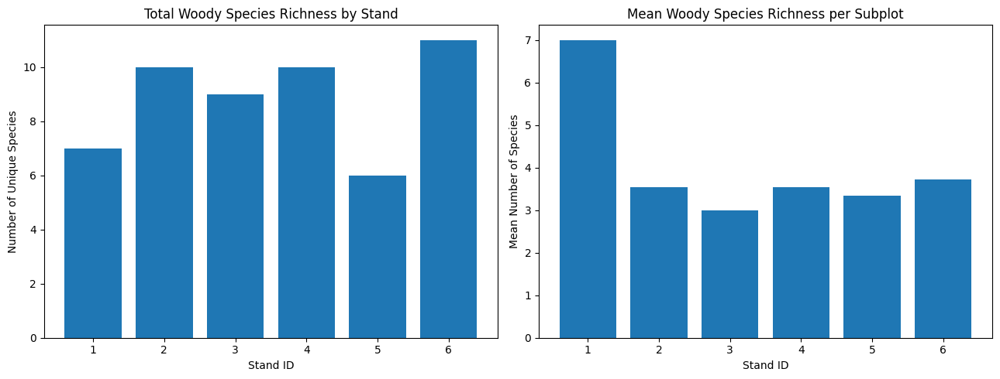

In [49]:
# STEP 47: VISUALIZE WOODY SPECIES RICHNESS
#
# Goal:
# Compare total observed woody species richness with mean subplot
# richness across the six included stands.

# Create a figure with two panels so the measures have separate axes.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# First panel: total number of unique woody species observed per stand.
axes[0].bar(
    woody_richness_comparison['Stand ID'].astype(str),
    woody_richness_comparison['Total Stand Woody Richness']
)

# Label the first panel.
axes[0].set_title('Total Woody Species Richness by Stand')
axes[0].set_xlabel('Stand ID')
axes[0].set_ylabel('Number of Unique Species')

# Second panel: mean number of woody species per subplot.
axes[1].bar(
    woody_richness_comparison['Stand ID'].astype(str),
    woody_richness_comparison['Mean']
)

# Label the second panel.
axes[1].set_title('Mean Woody Species Richness per Subplot')
axes[1].set_xlabel('Stand ID')
axes[1].set_ylabel('Mean Number of Species')

# Keep the two panels visually organized.
plt.tight_layout()

# Display the figure.
plt.show()

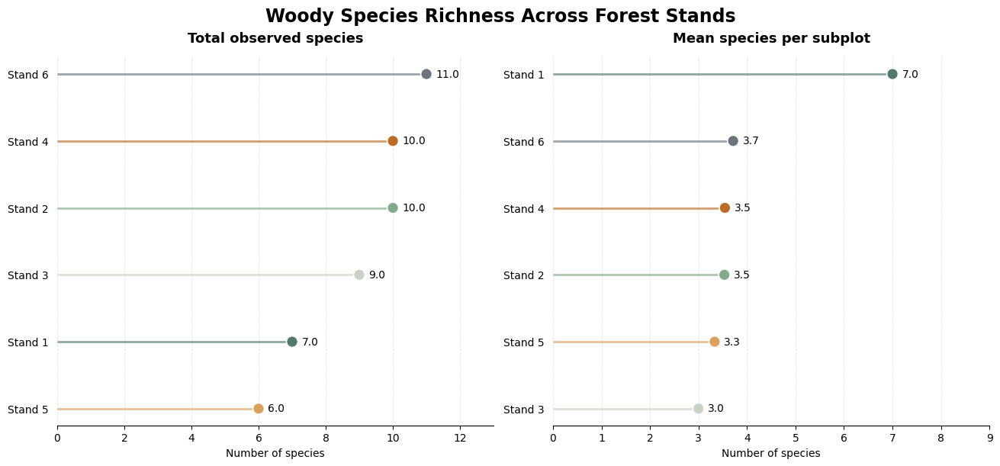

In [50]:
# STEP 48: CREATE A STAND-LEVEL WOODY RICHNESS FIGURE
#
# Goal:
# Create a coordinated, publication-style figure using horizontal
# lollipop plots, with a distinct color representing each stand.
#
# The left panel shows total observed woody species richness.
# The right panel shows mean woody species richness per subplot.

# Define a distinct color for each stand.
# These muted, nature-inspired colors remain distinguishable.
stand_colors = {
    1: '#52796F',  # Muted forest green
    2: '#84A98C',  # Sage green
    3: '#CAD2C5',  # Pale sage
    4: '#BC6C25',  # Warm brown
    5: '#DDA15E',  # Golden ochre
    6: '#6C757D'   # Slate gray
}

# Create a figure with two side-by-side panels.
# The constrained layout helps prevent labels from overlapping.
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    constrained_layout=True
)

# Define the two richness measurements and their corresponding panels.
richness_columns = [
    ('Total Stand Woody Richness', 'Total observed species'),
    ('Mean', 'Mean species per subplot')
]

# Loop through both panels to apply a consistent visual design.
for ax, (column, title) in zip(axes, richness_columns):

    # Sort stands by their richness values within each panel.
    # This makes differences easier to identify.
    plot_data = woody_richness_comparison.sort_values(column).copy()

    # Assign a horizontal position to each stand.
    # This controls the vertical ordering of the observations.
    y_positions = range(len(plot_data))

    # Draw a thin horizontal line from zero to each richness value.
    # These lines form the stems of the lollipop plots.
    for y, (_, row) in zip(y_positions, plot_data.iterrows()):
        ax.hlines(
            y=y,
            xmin=0,
            xmax=row[column],
            color=stand_colors[row['Stand ID']],
            linewidth=2,
            alpha=0.65
        )

    # Draw a colored circle at the end of each line.
    # Each stand retains the same color in both panels.
    ax.scatter(
        plot_data[column],
        y_positions,
        s=115,
        c=[stand_colors[stand] for stand in plot_data['Stand ID']],
        edgecolor='white',
        linewidth=1.2,
        zorder=3
    )

    # Add the numerical richness value beside each circle.
    # Values are formatted to one decimal place.
    for y, (_, row) in zip(y_positions, plot_data.iterrows()):
        ax.annotate(
            f"{row[column]:.1f}",
            xy=(row[column], y),
            xytext=(9, 0),
            textcoords='offset points',
            va='center',
            fontsize=10
        )

    # Label each horizontal position with its stand identifier.
    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(
        [f"Stand {int(stand)}" for stand in plot_data['Stand ID']]
    )

    # Add a descriptive panel title and x-axis label.
    ax.set_title(title, fontsize=13, fontweight='bold', pad=14)
    ax.set_xlabel('Number of species', fontsize=10)

    # Start the x-axis at zero and leave room for numerical annotations.
    ax.set_xlim(0, plot_data[column].max() + 2)

    # Add subtle vertical gridlines to help compare values.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Place gridlines behind the data points.
    ax.set_axisbelow(True)

    # Remove unnecessary borders for a cleaner appearance.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Remove small tick marks beside the stand labels.
    ax.tick_params(axis='y', length=0, pad=8)

# Add an overall figure title.
fig.suptitle(
    'Woody Species Richness Across Forest Stands',
    fontsize=17,
    fontweight='bold'
)

# Display the completed figure.
plt.show()

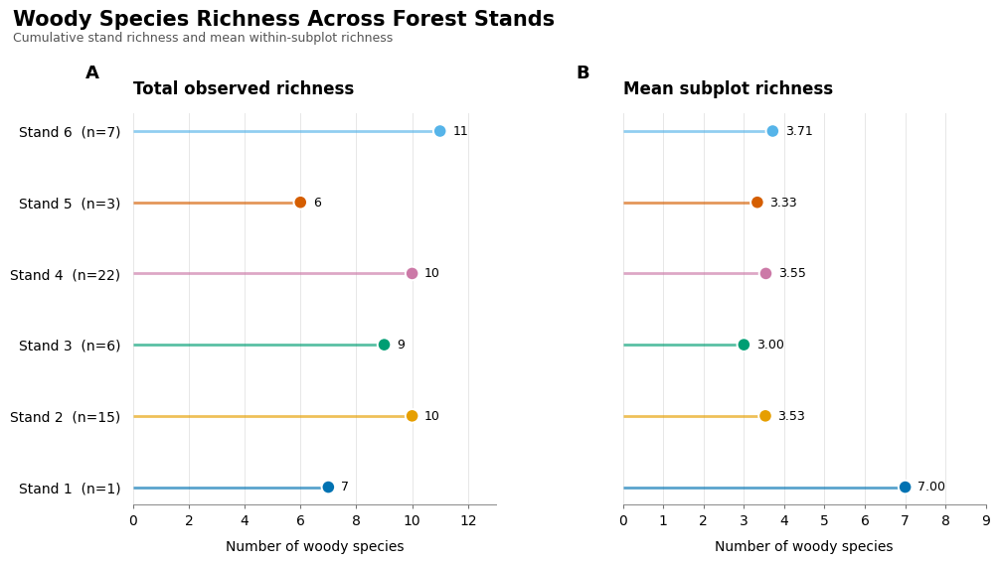

In [51]:
# STEP 49: CREATE A PUBLICATION-STYLE WOODY RICHNESS FIGURE
#
# Goal:
# Produce a polished, two-panel scientific figure comparing:
# (A) Total observed woody species richness per stand.
# (B) Mean woody species richness per subplot.
#
# Each stand receives a distinct color that remains consistent
# across both panels.
#
# Sampling effort is included to provide context for interpreting
# differences in cumulative species richness.

# Define a colorblind-conscious palette with six distinct colors.
# Each stand keeps its assigned color in both panels.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Set the order in which stands will appear in both panels.
# Keeping the same order makes the two measurements easier to compare.
stand_order = [1, 2, 3, 4, 5, 6]

# Create a copy of the comparison table in the desired stand order.
# This avoids modifying the underlying analytical DataFrame.
plot_data = (
    woody_richness_comparison
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Set up the figure's dimensions and resolution.
# The figure is designed for a two-column scientific presentation.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 5.8),
    sharey=True
)

# Set consistent scientific typography and visual defaults.
# These settings apply only while this figure is being created.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Define the two measurements and their panel labels.
    panels = [
        {
            'column': 'Total Stand Woody Richness',
            'title': 'Total observed richness',
            'panel': 'A'
        },
        {
            'column': 'Mean',
            'title': 'Mean subplot richness',
            'panel': 'B'
        }
    ]

    # Assign one vertical position to each stand.
    # This creates aligned observations across both panels.
    y_positions = np.arange(len(plot_data))

    # Loop through the two panels and construct each plot.
    for ax, panel in zip(axes, panels):

        # Identify which richness measurement belongs in this panel.
        column = panel['column']

        # Extract the richness values for this measurement.
        richness_values = plot_data[column].to_numpy()

        # Draw thin horizontal stems connecting zero to each observation.
        # These provide a visual reference without the visual weight of bars.
        for y, value, stand in zip(
            y_positions,
            richness_values,
            plot_data['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add a circular marker at the observed richness value.
        # Each marker uses the corresponding stand's assigned color.
        ax.scatter(
            richness_values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in plot_data['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Add numerical labels just beyond each marker.
        # Total richness is displayed as an integer;
        # mean richness is displayed to two decimal places.
        for y, value in zip(y_positions, richness_values):

            if column == 'Total Stand Woody Richness':
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Add the stand labels, including the number of sampled subplots.
        # This makes differences in sampling effort visible to the reader.
        stand_labels = [
            f"Stand {int(row['Stand ID'])}  (n={int(row['Subplots'])})"
            for _, row in plot_data.iterrows()
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Reverse the vertical axis so Stand 1 appears at the top.
        ax.invert_yaxis()

        # Add a descriptive title to the panel.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=14
        )

        # Add the panel identifier (A or B) in the upper-left corner.
        ax.text(
            -0.13,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

        # Label the horizontal axis.
        ax.set_xlabel('Number of woody species', labelpad=9)

        # Start the horizontal axis at zero.
        ax.set_xlim(0, max(richness_values) + 2)

        # Use subtle vertical gridlines for easier value comparison.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            linestyle='-',
            alpha=0.65
        )

        # Keep gridlines behind the data markers.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Make the bottom axis line subtle.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        # Remove unnecessary tick marks beside the stand labels.
        ax.tick_params(axis='y', length=0, pad=9)

        # Keep the horizontal axis ticks unobtrusive.
        ax.tick_params(axis='x', length=3, color='#777777')

    # Add an overall title above both panels.
    fig.suptitle(
        'Woody Species Richness Across Forest Stands',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=1.02
    )

    # Add a concise explanation of the two measurements.
    fig.text(
        0.08,
        0.965,
        'Cumulative stand richness and mean within-subplot richness',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust spacing between panels and reserve room for the title.
    fig.subplots_adjust(
        left=0.19,
        right=0.97,
        bottom=0.16,
        top=0.84,
        wspace=0.35
    )

    # Ensure the export directory exists before saving.
    export_dir.mkdir(parents=True, exist_ok=True)

    # Save a high-resolution raster image for presentations and documents.
    fig.savefig(
        export_dir / 'Woody_Richness_Publication.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save a vector PDF so the figure can be enlarged without losing quality.
    fig.savefig(
        export_dir / 'Woody_Richness_Publication.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the finished figure.
    plt.show()

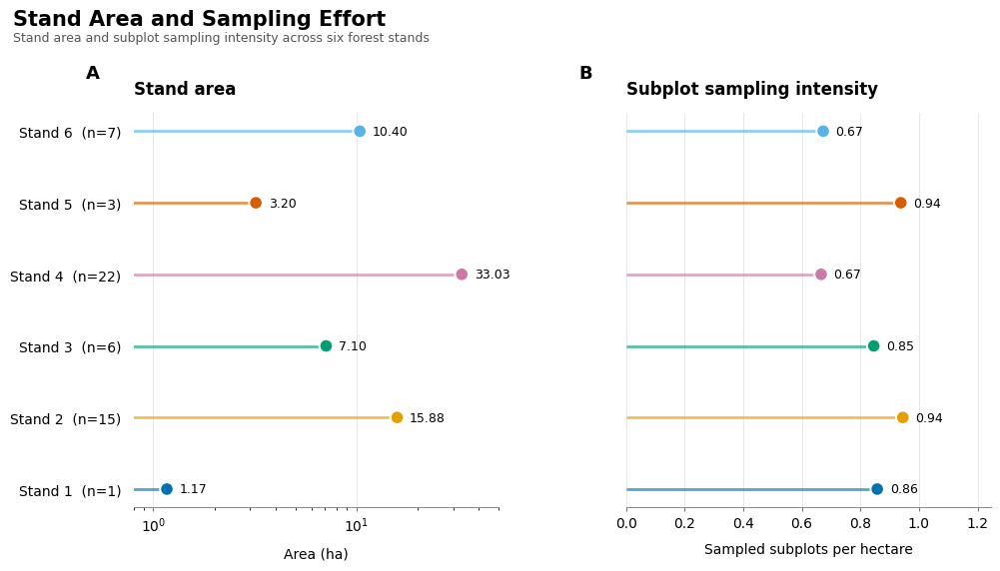

,Stand ID,Area_hectares,Sampled Subplots,Subplots per hectare
0,1,1.166,1,0.857
1,2,15.875,15,0.945
2,3,7.096,6,0.846
3,4,33.035,22,0.666
4,5,3.198,3,0.938
5,6,10.399,7,0.673


In [52]:
# STEP 50: CREATE A PUBLICATION-STYLE SAMPLING EFFORT FIGURE
#
# Goal:
# Visualize stand area and subplot sampling intensity for the
# six stands included in the primary analysis.
#
# Panel A: Stand area in hectares.
# Panel B: Number of sampled subplots per hectare.
#
# The same colors used in the woody richness figure identify each stand.

# Define the order of stands used in the analysis.
stand_order = [1, 2, 3, 4, 5, 6]

# Create a fresh copy of the stand area data for plotting.
# Filter out stands that are not part of the primary analysis.
effort_plot = (
    stand_areas[
        stand_areas['Stand ID'].isin(stand_order)
    ][['Stand ID', 'Area_hectares']]
    .copy()
)

# Count unique sampled plot-subplot combinations in each stand.
# Using both identifiers prevents repeated subplot numbers in
# different plots from being counted as the same sampling location.
subplot_counts = (
    subplot_metadata_analysis
    .groupby('Stand ID')
    .apply(
        lambda group: group[['Plot ID', 'Subplot ID']]
        .drop_duplicates()
        .shape[0],
        include_groups=False
    )
    .reset_index(name='Sampled Subplots')
)

# Merge the subplot counts with the stand area information.
# This gives each stand its area and total number of sampled subplots.
effort_plot = effort_plot.merge(
    subplot_counts,
    on='Stand ID',
    how='left'
)

# Calculate subplot sampling intensity.
# This expresses the number of sampled subplots relative to stand area.
effort_plot['Subplots per hectare'] = (
    effort_plot['Sampled Subplots'] /
    effort_plot['Area_hectares']
)

# Arrange the stands in numerical order.
effort_plot = (
    effort_plot
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Create two coordinated horizontal panels.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 5.8),
    sharey=True
)

# Establish vertical positions for the six stands.
y_positions = np.arange(len(effort_plot))

# Define the two measurements for the figure.
effort_panels = [
    {
        'column': 'Area_hectares',
        'title': 'Stand area',
        'xlabel': 'Area (ha)',
        'panel': 'A'
    },
    {
        'column': 'Subplots per hectare',
        'title': 'Subplot sampling intensity',
        'xlabel': 'Sampled subplots per hectare',
        'panel': 'B'
    }
]

# Apply a consistent scientific figure style.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Construct each panel.
    for ax, panel in zip(axes, effort_panels):

        # Select the measurement for the current panel.
        column = panel['column']

        # Extract values for plotting.
        values = effort_plot[column].to_numpy()

        # Draw horizontal stems from zero to each observation.
        for y, value, stand in zip(
            y_positions,
            values,
            effort_plot['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add a circular marker at each observation.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in effort_plot['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Label each marker with its numerical value.
        for y, value in zip(y_positions, values):

            # Use two decimal places for both measurements.
            ax.annotate(
                f'{value:.2f}',
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Label stands and show their actual subplot sample counts.
        stand_labels = [
            f"Stand {int(row['Stand ID'])}  (n={int(row['Sampled Subplots'])})"
            for _, row in effort_plot.iterrows()
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Put Stand 1 at the top of both panels.
        ax.invert_yaxis()

        # Add panel titles and axis labels.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=14
        )

        ax.set_xlabel(panel['xlabel'], labelpad=9)

        # Use a logarithmic axis for stand area.
        # This makes differences between small and large stands
        # easier to interpret without compressing the smaller stands.
        if column == 'Area_hectares':
            ax.set_xscale('log')
            ax.set_xlim(0.8, 50)

        # Use a linear axis for subplot sampling intensity.
        else:
            ax.set_xlim(0, effort_plot[column].max() + 0.3)

        # Add subtle gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        # Keep gridlines behind the observations.
        ax.set_axisbelow(True)

        # Remove unnecessary borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine the remaining axis line and tick marks.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)
        ax.tick_params(axis='y', length=0, pad=9)
        ax.tick_params(axis='x', length=3, color='#777777')

        # Add panel identifiers.
        ax.text(
            -0.13,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # Add an overall title.
    fig.suptitle(
        'Stand Area and Sampling Effort',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=1.02
    )

    # Add a subtitle explaining the two measurements.
    fig.text(
        0.08,
        0.965,
        'Stand area and subplot sampling intensity across six forest stands',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust panel spacing and reserve room for the title.
    fig.subplots_adjust(
        left=0.19,
        right=0.97,
        bottom=0.16,
        top=0.84,
        wspace=0.35
    )

    # Save the figure as a high-resolution PNG.
    fig.savefig(
        export_dir / 'Stand_Area_Sampling_Effort.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save a vector PDF for publication and manuscript use.
    fig.savefig(
        export_dir / 'Stand_Area_Sampling_Effort.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the figure.
    plt.show()

# Display the underlying values for verification.
display(
    effort_plot.round(3)
)

In [53]:
# STEP 51: CALCULATE HERBACEOUS SPECIES RICHNESS
#
# Goal:
# Calculate herbaceous species richness at two spatial scales:
# (1) Total observed richness across each stand.
# (2) Mean richness within individual subplots.
#
# We use herbaceous_analysis, which contains only Stands 1–6.

# Group herbaceous observations by stand, plot, and subplot.
# Count the number of unique herbaceous species in each subplot.
herbaceous_subplot_richness = (
    herbaceous_analysis
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])['Species Name']
    .nunique()
    .reset_index(name='Herbaceous Species Richness')
)

# Summarize subplot richness within each stand.
# Each row in this summary represents one stand.
herbaceous_richness_summary = (
    herbaceous_subplot_richness
    .groupby('Stand ID')['Herbaceous Species Richness']
    .agg(
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Subplots='count'
    )
    .reset_index()
)

# Calculate total unique herbaceous species observed in each stand.
# Repeated observations of the same species are counted only once.
herbaceous_total_richness = (
    herbaceous_analysis
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reset_index(name='Total Stand Herbaceous Richness')
)

# Combine cumulative richness and subplot-level richness.
# Stand ID connects the two summaries.
herbaceous_richness_comparison = (
    herbaceous_total_richness
    .merge(
        herbaceous_richness_summary,
        on='Stand ID',
        how='left'
    )
)

# Display the combined results, rounded to two decimal places.
display(herbaceous_richness_comparison.round(2))

,Stand ID,Total Stand Herbaceous Richness,Mean,Median,Minimum,Maximum,Subplots
0,1,4,4.00,4.0,4,4,1
1,2,21,3.93,3.5,2,7,14
2,3,7,2.67,3.0,2,3,6
3,4,27,3.85,3.0,1,10,20
4,5,7,6.00,6.0,6,6,2
5,6,7,3.17,3.0,2,4,6


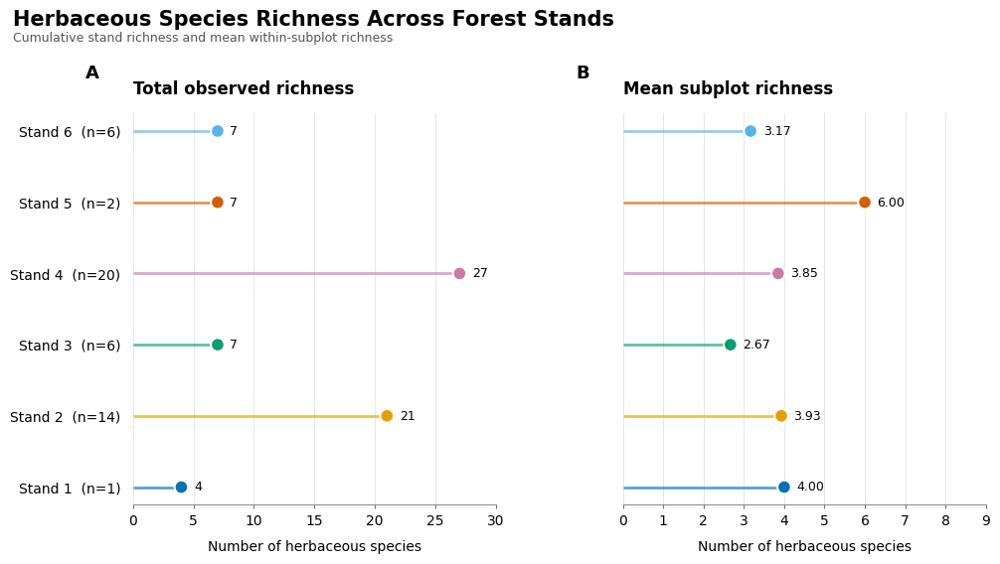

In [54]:
# STEP 52: CREATE A PUBLICATION-STYLE HERBACEOUS RICHNESS FIGURE
#
# Goal:
# Visualize cumulative herbaceous species richness and mean
# subplot-level herbaceous richness across the six stands.
#
# The layout and colors match the woody richness figure.

# Arrange stands in numerical order.
herbaceous_plot_data = (
    herbaceous_richness_comparison
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Create two side-by-side panels with a shared vertical axis.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 5.8),
    sharey=True
)

# Define the two richness measurements and panel labels.
herbaceous_panels = [
    {
        'column': 'Total Stand Herbaceous Richness',
        'title': 'Total observed richness',
        'panel': 'A'
    },
    {
        'column': 'Mean',
        'title': 'Mean subplot richness',
        'panel': 'B'
    }
]

# Assign one vertical position to each stand.
y_positions = np.arange(len(herbaceous_plot_data))

# Apply the same publication-style formatting as the woody figure.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Construct both richness panels.
    for ax, panel in zip(axes, herbaceous_panels):

        # Select the richness measurement for this panel.
        column = panel['column']

        # Extract the values to be plotted.
        values = herbaceous_plot_data[column].to_numpy()

        # Draw a horizontal line from zero to each richness value.
        for y, value, stand in zip(
            y_positions,
            values,
            herbaceous_plot_data['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add a circular marker at each observed richness value.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in herbaceous_plot_data['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Add numerical labels beside each marker.
        for y, value in zip(y_positions, values):

            # Display cumulative richness as an integer.
            # Display mean richness to two decimal places.
            if column == 'Total Stand Herbaceous Richness':
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Include the number of contributing subplots in each stand label.
        stand_labels = [
            f"Stand {int(row['Stand ID'])}  (n={int(row['Subplots'])})"
            for _, row in herbaceous_plot_data.iterrows()
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Put Stand 1 at the top of both panels.
        ax.invert_yaxis()

        # Add panel titles and axis labels.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=14
        )

        ax.set_xlabel('Number of herbaceous species', labelpad=9)

        # Start the horizontal axis at zero and leave space for labels.
        ax.set_xlim(0, max(values) + 3)

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        # Keep gridlines behind the observations.
        ax.set_axisbelow(True)

        # Remove unnecessary borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine the remaining axis line and tick marks.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)
        ax.tick_params(axis='y', length=0, pad=9)
        ax.tick_params(axis='x', length=3, color='#777777')

        # Add the panel identifier.
        ax.text(
            -0.13,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # Add the overall figure title.
    fig.suptitle(
        'Herbaceous Species Richness Across Forest Stands',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=1.02
    )

    # Add a subtitle describing the two richness measurements.
    fig.text(
        0.08,
        0.965,
        'Cumulative stand richness and mean within-subplot richness',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust spacing and reserve space for the title.
    fig.subplots_adjust(
        left=0.19,
        right=0.97,
        bottom=0.16,
        top=0.84,
        wspace=0.35
    )

    # Save a high-resolution PNG.
    fig.savefig(
        export_dir / 'Herbaceous_Richness_Publication.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save a vector PDF.
    fig.savefig(
        export_dir / 'Herbaceous_Richness_Publication.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the finished figure.
    plt.show()

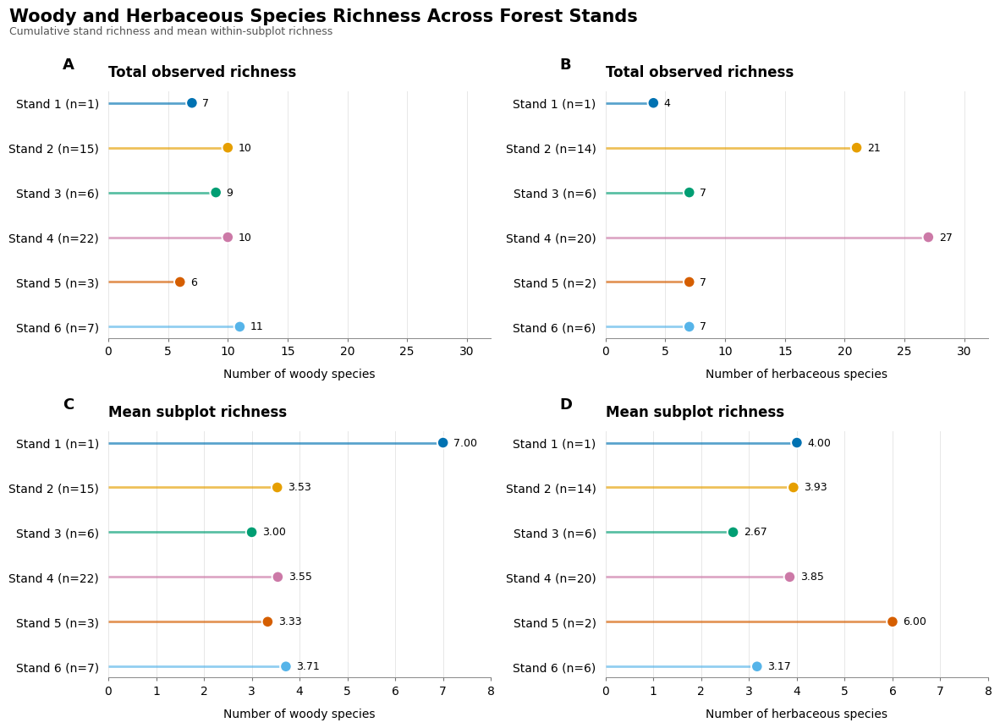

In [56]:
# STEP 53: COMBINE WOODY AND HERBACEOUS RICHNESS FIGURES
#
# Panel A: Total woody species richness.
# Panel B: Total herbaceous species richness.
# Panel C: Mean woody species richness per subplot.
# Panel D: Mean herbaceous species richness per subplot.
#
# The figure preserves the original lollipop design, stand colors,
# numerical labels, and subplot sample counts.

# Combine the woody and herbaceous richness summaries.
# Rename columns so both vegetation layers can be distinguished.
comparative_richness = (
    woody_richness_comparison[
        ['Stand ID', 'Total Stand Woody Richness', 'Mean', 'Subplots']
    ]
    .rename(columns={
        'Mean': 'Mean Woody Richness',
        'Subplots': 'Woody Subplots'
    })
    .merge(
        herbaceous_richness_comparison[
            ['Stand ID', 'Total Stand Herbaceous Richness', 'Mean', 'Subplots']
        ].rename(columns={
            'Mean': 'Mean Herbaceous Richness',
            'Subplots': 'Herbaceous Subplots'
        }),
        on='Stand ID',
        how='inner'
    )
)

# Arrange stands in numerical order.
comparative_richness = (
    comparative_richness
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Define the information displayed in each of the four panels.
panel_definitions = [
    {
        'column': 'Total Stand Woody Richness',
        'count_column': 'Woody Subplots',
        'title': 'Total observed richness',
        'xlabel': 'Number of woody species',
        'panel': 'A',
        'row': 0,
        'col': 0
    },
    {
        'column': 'Total Stand Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Total observed richness',
        'xlabel': 'Number of herbaceous species',
        'panel': 'B',
        'row': 0,
        'col': 1
    },
    {
        'column': 'Mean Woody Richness',
        'count_column': 'Woody Subplots',
        'title': 'Mean subplot richness',
        'xlabel': 'Number of woody species',
        'panel': 'C',
        'row': 1,
        'col': 0
    },
    {
        'column': 'Mean Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Mean subplot richness',
        'xlabel': 'Number of herbaceous species',
        'panel': 'D',
        'row': 1,
        'col': 1
    }
]

# Create a four-panel figure.
# Each panel has an independent horizontal axis.
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

# Apply consistent scientific typography.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Assign a vertical position to each stand.
    y_positions = np.arange(len(comparative_richness))

    # Construct each panel.
    for panel in panel_definitions:

        # Select the appropriate subplot.
        ax = axes[panel['row'], panel['col']]

        # Extract richness values and contributing subplot counts.
        values = comparative_richness[panel['column']].to_numpy()
        sample_counts = comparative_richness[
            panel['count_column']
        ].to_numpy()

        # Draw horizontal stems from zero to each richness value.
        for y, value, stand in zip(
            y_positions,
            values,
            comparative_richness['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add circular markers at the end of each stem.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in comparative_richness['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Add numerical labels beside each marker.
        for y, value in zip(y_positions, values):

            # Cumulative richness is shown as an integer.
            # Mean richness is shown to two decimal places.
            if 'Total' in panel['column']:
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Add stand labels and the number of contributing subplots.
        stand_labels = [
            f"Stand {int(stand)} (n={int(count)})"
            for stand, count in zip(
                comparative_richness['Stand ID'],
                sample_counts
            )
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Place Stand 1 at the top.
        ax.invert_yaxis()

        # Add panel title and x-axis label.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=13
        )

        ax.set_xlabel(panel['xlabel'], labelpad=9)

        # Set appropriate horizontal scales.
        # Cumulative richness uses 0–32 species.
        # Mean subplot richness uses 0–8 species.
        if panel['row'] == 0:
            ax.set_xlim(0, 32)
            ax.set_xticks(np.arange(0, 33, 5))
        else:
            ax.set_xlim(0, 8)
            ax.set_xticks(np.arange(0, 9, 1))

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        # Keep gridlines behind the observations.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine the bottom axis.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        # Refine tick marks and spacing.
        ax.tick_params(axis='y', length=0, pad=8)
        ax.tick_params(axis='x', length=3, color='#777777')

        # Add panel identifiers A, B, C, and D.
        ax.text(
            -0.12,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # Add the overall figure title.
    fig.suptitle(
        'Woody and Herbaceous Species Richness Across Forest Stands',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=0.98
    )

    # Add a descriptive subtitle.
    fig.text(
        0.08,
        0.945,
        'Cumulative stand richness and mean within-subplot richness',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust panel spacing and title placement.
    fig.subplots_adjust(
        left=0.17,
        right=0.97,
        bottom=0.10,
        top=0.87,
        hspace=0.38,
        wspace=0.30
    )

    # Save a high-resolution PNG.
    fig.savefig(
        export_dir / 'Woody_Herbaceous_Comparative_Richness.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save a vector PDF for publication.
    fig.savefig(
        export_dir / 'Woody_Herbaceous_Comparative_Richness.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the completed figure.
    plt.show()

In [57]:
# STEP 54: CALCULATE REGENERATION SPECIES RICHNESS
#
# Goal:
# Calculate regeneration richness at two spatial scales:
# (1) Total unique regeneration species observed across each stand.
# (2) Mean unique regeneration species observed per subplot.
#
# Microplots are nested within subplots, so we combine their
# species observations at the subplot level.

# Group regeneration observations by stand, plot, and subplot.
# Count each species only once within each subplot, even if it
# occurs in multiple microplots.
regeneration_subplot_richness = (
    regeneration_analysis
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])['Species Name']
    .nunique()
    .reset_index(name='Regeneration Species Richness')
)

# Calculate descriptive statistics for subplot richness within each stand.
regeneration_richness_summary = (
    regeneration_subplot_richness
    .groupby('Stand ID')['Regeneration Species Richness']
    .agg(
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Subplots='count'
    )
    .reset_index()
)

# Calculate total unique regeneration species observed across each stand.
regeneration_total_richness = (
    regeneration_analysis
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reset_index(name='Total Stand Regeneration Richness')
)

# Combine cumulative richness with subplot-level richness statistics.
regeneration_richness_comparison = (
    regeneration_total_richness
    .merge(
        regeneration_richness_summary,
        on='Stand ID',
        how='left'
    )
)

# Display the results.
display(regeneration_richness_comparison.round(2))

,Stand ID,Total Stand Regeneration Richness,Mean,Median,Minimum,Maximum,Subplots
0,1.0,3,3.00,3.0,3,3,1
1,2.0,11,2.36,2.0,1,4,14
2,3.0,4,1.83,2.0,1,3,6
3,4.0,10,2.41,2.0,1,5,22
4,5.0,4,2.33,2.0,1,4,3
5,6.0,7,2.50,2.5,1,5,6


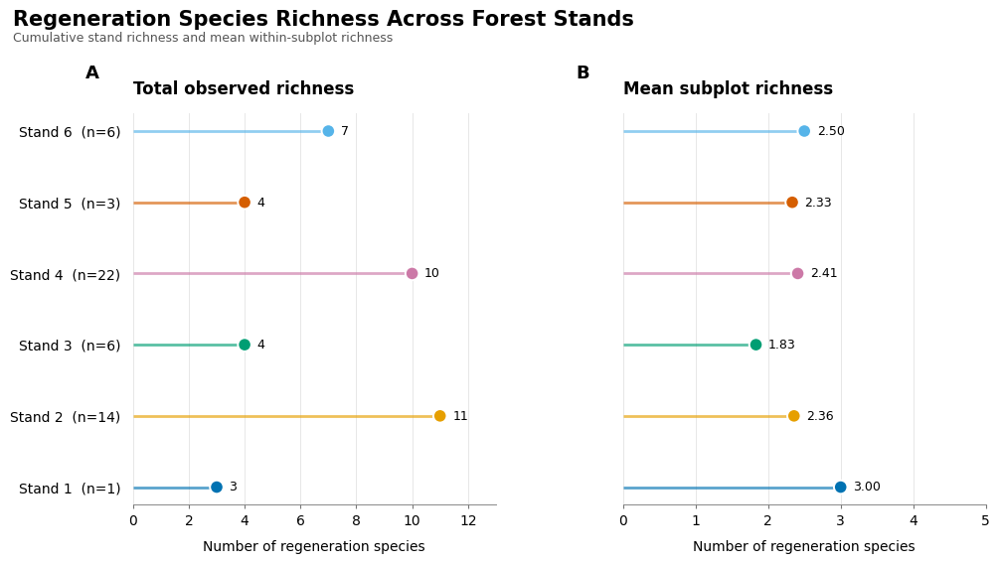

In [58]:
# STEP 55: CREATE A PUBLICATION-STYLE REGENERATION RICHNESS FIGURE
#
# Panel A: Total observed regeneration species richness.
# Panel B: Mean regeneration species richness per subplot.
#
# The same stand colors, lollipop design, typography, and
# subplot labels are retained from the previous figures.

# Arrange stands in numerical order.
regeneration_plot_data = (
    regeneration_richness_comparison
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Create two side-by-side panels.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 5.8),
    sharey=True
)

# Define the two richness measurements.
regeneration_panels = [
    {
        'column': 'Total Stand Regeneration Richness',
        'title': 'Total observed richness',
        'panel': 'A'
    },
    {
        'column': 'Mean',
        'title': 'Mean subplot richness',
        'panel': 'B'
    }
]

# Assign a vertical position to each stand.
y_positions = np.arange(len(regeneration_plot_data))

# Apply the same publication styling as the previous figures.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Construct each panel.
    for ax, panel in zip(axes, regeneration_panels):

        # Extract the richness values for this panel.
        column = panel['column']
        values = regeneration_plot_data[column].to_numpy()

        # Draw horizontal stems from zero to each richness value.
        for y, value, stand in zip(
            y_positions,
            values,
            regeneration_plot_data['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add circular markers at each richness value.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in regeneration_plot_data['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Add numerical labels beside each marker.
        for y, value in zip(y_positions, values):

            # Display total richness as an integer.
            # Display mean richness to two decimal places.
            if 'Total' in column:
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Include the number of contributing subplots in stand labels.
        stand_labels = [
            f"Stand {int(row['Stand ID'])}  (n={int(row['Subplots'])})"
            for _, row in regeneration_plot_data.iterrows()
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Place Stand 1 at the top.
        ax.invert_yaxis()

        # Add panel titles and axis labels.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=14
        )

        ax.set_xlabel('Number of regeneration species', labelpad=9)

        # Set horizontal axis limits with room for labels.
        ax.set_xlim(0, values.max() + 2)

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        # Keep gridlines behind the observations.
        ax.set_axisbelow(True)

        # Remove unnecessary borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine axis lines and tick marks.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)
        ax.tick_params(axis='y', length=0, pad=9)
        ax.tick_params(axis='x', length=3, color='#777777')

        # Add panel identifiers.
        ax.text(
            -0.13,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # Add the overall figure title.
    fig.suptitle(
        'Regeneration Species Richness Across Forest Stands',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=1.02
    )

    # Add a descriptive subtitle.
    fig.text(
        0.08,
        0.965,
        'Cumulative stand richness and mean within-subplot richness',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust panel spacing and reserve room for the title.
    fig.subplots_adjust(
        left=0.19,
        right=0.97,
        bottom=0.16,
        top=0.84,
        wspace=0.35
    )

    # Save a high-resolution PNG.
    fig.savefig(
        export_dir / 'Regeneration_Richness_Publication.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save a vector PDF.
    fig.savefig(
        export_dir / 'Regeneration_Richness_Publication.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the finished figure.
    plt.show()

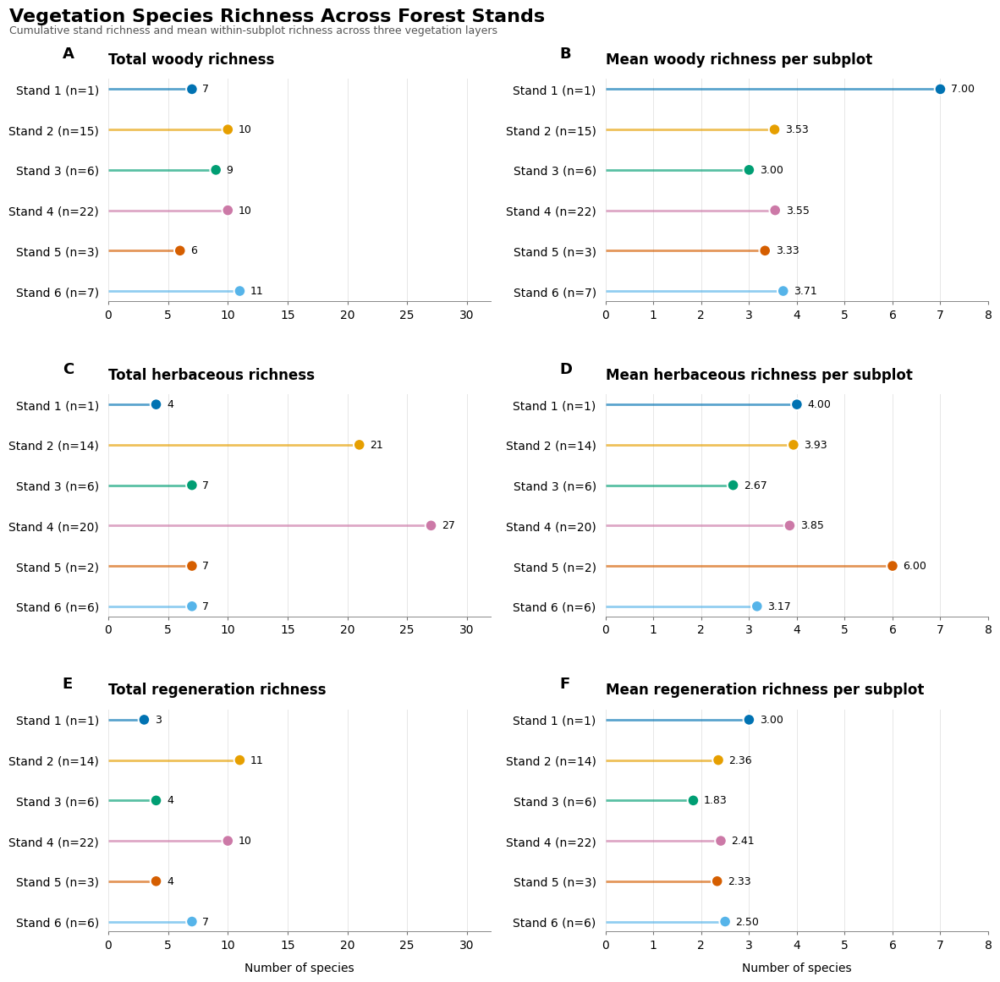

In [59]:
# STEP 56: CREATE A SIX-PANEL VEGETATION RICHNESS FIGURE
#
# Goal:
# Compare woody, herbaceous, and regeneration species richness
# across the six forest stands.
#
# LEFT COLUMN:
# A. Total woody richness.
# C. Total herbaceous richness.
# E. Total regeneration richness.
#
# RIGHT COLUMN:
# B. Mean woody richness per subplot.
# D. Mean herbaceous richness per subplot.
# F. Mean regeneration richness per subplot.
#
# All panels use the same stand colors and publication-style formatting.

# Combine the woody, herbaceous, and regeneration richness summaries.
# Rename columns so the three vegetation layers can be distinguished.

vegetation_richness_comparison = (
    woody_richness_comparison[
        ['Stand ID', 'Total Stand Woody Richness', 'Mean', 'Subplots']
    ]
    .rename(columns={
        'Mean': 'Mean Woody Richness',
        'Subplots': 'Woody Subplots'
    })

    # Add herbaceous richness information.
    .merge(
        herbaceous_richness_comparison[
            ['Stand ID', 'Total Stand Herbaceous Richness', 'Mean', 'Subplots']
        ].rename(columns={
            'Mean': 'Mean Herbaceous Richness',
            'Subplots': 'Herbaceous Subplots'
        }),
        on='Stand ID',
        how='inner'
    )

    # Add regeneration richness information.
    .merge(
        regeneration_richness_comparison[
            ['Stand ID', 'Total Stand Regeneration Richness', 'Mean', 'Subplots']
        ].rename(columns={
            'Mean': 'Mean Regeneration Richness',
            'Subplots': 'Regeneration Subplots'
        }),
        on='Stand ID',
        how='inner'
    )
)

# Arrange the stands in numerical order.
# This ensures consistent ordering throughout all six panels.
vegetation_richness_comparison = (
    vegetation_richness_comparison
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Define the six panels.
# Each panel specifies its richness column, subplot count column,
# title, axis label, panel letter, and position in the figure.

vegetation_panels = [
    {
        'column': 'Total Stand Woody Richness',
        'count_column': 'Woody Subplots',
        'title': 'Total woody richness',
        'panel': 'A',
        'row': 0,
        'col': 0
    },
    {
        'column': 'Mean Woody Richness',
        'count_column': 'Woody Subplots',
        'title': 'Mean woody richness per subplot',
        'panel': 'B',
        'row': 0,
        'col': 1
    },
    {
        'column': 'Total Stand Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Total herbaceous richness',
        'panel': 'C',
        'row': 1,
        'col': 0
    },
    {
        'column': 'Mean Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Mean herbaceous richness per subplot',
        'panel': 'D',
        'row': 1,
        'col': 1
    },
    {
        'column': 'Total Stand Regeneration Richness',
        'count_column': 'Regeneration Subplots',
        'title': 'Total regeneration richness',
        'panel': 'E',
        'row': 2,
        'col': 0
    },
    {
        'column': 'Mean Regeneration Richness',
        'count_column': 'Regeneration Subplots',
        'title': 'Mean regeneration richness per subplot',
        'panel': 'F',
        'row': 2,
        'col': 1
    }
]

# Create a three-row, two-column figure.
# The left column contains cumulative richness.
# The right column contains mean subplot richness.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(13, 12)
)

# Assign a vertical plotting position to each stand.
y_positions = np.arange(len(vegetation_richness_comparison))

# Apply the same typography used in the individual publication figures.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Construct all six panels.
    for panel in vegetation_panels:

        # Select the correct position in the figure.
        ax = axes[panel['row'], panel['col']]

        # Extract richness values and subplot sample counts.
        values = vegetation_richness_comparison[
            panel['column']
        ].to_numpy()

        sample_counts = vegetation_richness_comparison[
            panel['count_column']
        ].to_numpy()

        # Draw horizontal stems from zero to each richness value.
        for y, value, stand in zip(
            y_positions,
            values,
            vegetation_richness_comparison['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add circular markers at the observed richness values.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in vegetation_richness_comparison['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Add numerical labels beside each marker.
        for y, value in zip(y_positions, values):

            # Cumulative richness is displayed as an integer.
            # Mean subplot richness is displayed to two decimals.
            if 'Total' in panel['column']:
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Add stand labels and the number of contributing subplots.
        stand_labels = [
            f"Stand {int(stand)} (n={int(count)})"
            for stand, count in zip(
                vegetation_richness_comparison['Stand ID'],
                sample_counts
            )
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Place Stand 1 at the top of every panel.
        ax.invert_yaxis()

        # Add the panel title.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=13
        )

        # Add the panel identifier.
        ax.text(
            -0.12,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

        # Apply cumulative richness axis limits to the left column.
        # All three cumulative richness panels use the same scale.
        if panel['col'] == 0:
            ax.set_xlim(0, 32)
            ax.set_xticks(np.arange(0, 33, 5))

        # Apply mean richness axis limits to the right column.
        # All three mean richness panels use the same scale.
        else:
            ax.set_xlim(0, 8)
            ax.set_xticks(np.arange(0, 9, 1))

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        # Keep gridlines behind the data.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine the remaining axis line.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        # Refine tick marks and label spacing.
        ax.tick_params(axis='y', length=0, pad=8)
        ax.tick_params(axis='x', length=3, color='#777777')

    # Add x-axis labels to the bottom row only.
    axes[2, 0].set_xlabel('Number of species', labelpad=9)
    axes[2, 1].set_xlabel('Number of species', labelpad=9)

    # Add the overall figure title.
    fig.suptitle(
        'Vegetation Species Richness Across Forest Stands',
        fontsize=16,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=0.99
    )

    # Add a subtitle describing the comparison.
    fig.text(
        0.08,
        0.965,
        'Cumulative stand richness and mean within-subplot richness across three vegetation layers',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust the figure spacing.
    fig.subplots_adjust(
        left=0.17,
        right=0.97,
        bottom=0.08,
        top=0.92,
        hspace=0.42,
        wspace=0.30
    )

    # Save a high-resolution PNG.
    fig.savefig(
        export_dir / 'Three_Layer_Vegetation_Richness.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save a vector PDF for publication.
    fig.savefig(
        export_dir / 'Three_Layer_Vegetation_Richness.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the finished figure.
    plt.show()

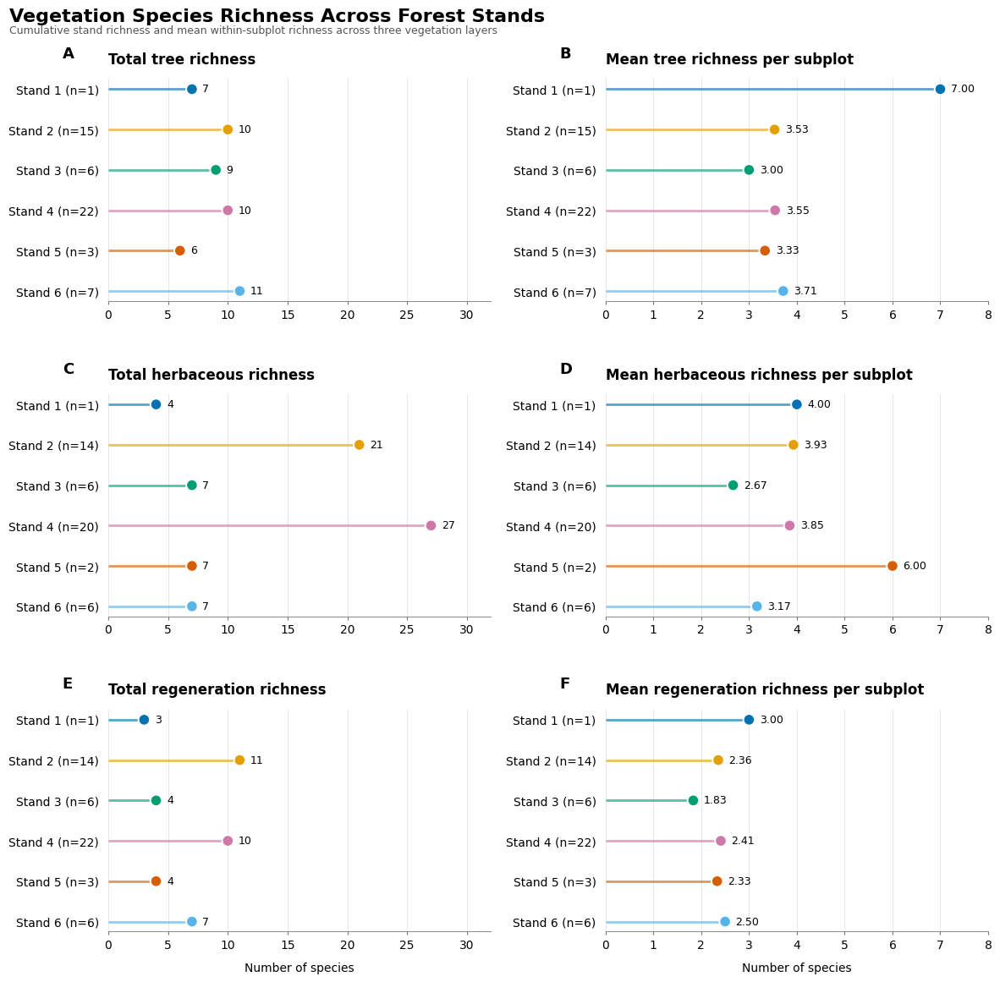

In [60]:
# STEP 56: CREATE A SIX-PANEL VEGETATION RICHNESS FIGURE
#
# Goal:
# Compare tree, herbaceous, and regeneration species richness
# across the six forest stands.
#
# LEFT COLUMN: Total cumulative species richness.
# RIGHT COLUMN: Mean species richness per subplot.
#
# Rows:
# A-B: Tree vegetation.
# C-D: Herbaceous vegetation.
# E-F: Regeneration.
#
# The original analysis DataFrames remain unchanged.
# "Tree" is used as the presentation terminology for woody vegetation.

# Combine the tree, herbaceous, and regeneration richness summaries.
# Rename the presentation columns so the terminology is consistent.

vegetation_richness_comparison = (
    woody_richness_comparison[
        ['Stand ID', 'Total Stand Woody Richness', 'Mean', 'Subplots']
    ]
    .rename(columns={
        'Total Stand Woody Richness': 'Total Stand Tree Richness',
        'Mean': 'Mean Tree Richness',
        'Subplots': 'Tree Subplots'
    })

    # Add herbaceous richness information.
    .merge(
        herbaceous_richness_comparison[
            ['Stand ID', 'Total Stand Herbaceous Richness', 'Mean', 'Subplots']
        ].rename(columns={
            'Mean': 'Mean Herbaceous Richness',
            'Subplots': 'Herbaceous Subplots'
        }),
        on='Stand ID',
        how='inner'
    )

    # Add regeneration richness information.
    .merge(
        regeneration_richness_comparison[
            ['Stand ID', 'Total Stand Regeneration Richness', 'Mean', 'Subplots']
        ].rename(columns={
            'Mean': 'Mean Regeneration Richness',
            'Subplots': 'Regeneration Subplots'
        }),
        on='Stand ID',
        how='inner'
    )
)

# Arrange stands in numerical order.
vegetation_richness_comparison = (
    vegetation_richness_comparison
    .set_index('Stand ID')
    .loc[stand_order]
    .reset_index()
)

# Define the six panels.
vegetation_panels = [
    {
        'column': 'Total Stand Tree Richness',
        'count_column': 'Tree Subplots',
        'title': 'Total tree richness',
        'panel': 'A',
        'row': 0,
        'col': 0
    },
    {
        'column': 'Mean Tree Richness',
        'count_column': 'Tree Subplots',
        'title': 'Mean tree richness per subplot',
        'panel': 'B',
        'row': 0,
        'col': 1
    },
    {
        'column': 'Total Stand Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Total herbaceous richness',
        'panel': 'C',
        'row': 1,
        'col': 0
    },
    {
        'column': 'Mean Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Mean herbaceous richness per subplot',
        'panel': 'D',
        'row': 1,
        'col': 1
    },
    {
        'column': 'Total Stand Regeneration Richness',
        'count_column': 'Regeneration Subplots',
        'title': 'Total regeneration richness',
        'panel': 'E',
        'row': 2,
        'col': 0
    },
    {
        'column': 'Mean Regeneration Richness',
        'count_column': 'Regeneration Subplots',
        'title': 'Mean regeneration richness per subplot',
        'panel': 'F',
        'row': 2,
        'col': 1
    }
]

# Create a three-row, two-column figure.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(13, 12)
)

# Assign one vertical position to each stand.
y_positions = np.arange(len(vegetation_richness_comparison))

# Apply consistent scientific typography.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Construct each of the six panels.
    for panel in vegetation_panels:

        # Select the correct panel position.
        ax = axes[panel['row'], panel['col']]

        # Extract richness values and contributing subplot counts.
        values = vegetation_richness_comparison[
            panel['column']
        ].to_numpy()

        sample_counts = vegetation_richness_comparison[
            panel['count_column']
        ].to_numpy()

        # Draw horizontal stems from zero to each richness value.
        for y, value, stand in zip(
            y_positions,
            values,
            vegetation_richness_comparison['Stand ID']
        ):
            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add circular markers at each richness value.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in vegetation_richness_comparison['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Add numerical richness labels.
        for y, value in zip(y_positions, values):

            # Display cumulative richness as an integer.
            # Display mean subplot richness to two decimal places.
            if 'Total' in panel['column']:
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Add stand labels with the number of contributing subplots.
        stand_labels = [
            f"Stand {int(stand)} (n={int(count)})"
            for stand, count in zip(
                vegetation_richness_comparison['Stand ID'],
                sample_counts
            )
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Place Stand 1 at the top of every panel.
        ax.invert_yaxis()

        # Add panel titles.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=13
        )

        # Apply consistent horizontal axis limits by column.
        if panel['col'] == 0:
            ax.set_xlim(0, 32)
            ax.set_xticks(np.arange(0, 33, 5))
        else:
            ax.set_xlim(0, 8)
            ax.set_xticks(np.arange(0, 9, 1))

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        # Keep gridlines behind the observations.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine the bottom axis.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        # Refine tick marks and spacing.
        ax.tick_params(axis='y', length=0, pad=8)
        ax.tick_params(axis='x', length=3, color='#777777')

        # Add panel identifiers.
        ax.text(
            -0.12,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # Add x-axis labels to the bottom row.
    axes[2, 0].set_xlabel('Number of species', labelpad=9)
    axes[2, 1].set_xlabel('Number of species', labelpad=9)

    # Add the overall figure title.
    fig.suptitle(
        'Vegetation Species Richness Across Forest Stands',
        fontsize=16,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=0.99
    )

    # Add the descriptive subtitle.
    fig.text(
        0.08,
        0.965,
        'Cumulative stand richness and mean within-subplot richness across three vegetation layers',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # Adjust panel spacing.
    fig.subplots_adjust(
        left=0.17,
        right=0.97,
        bottom=0.08,
        top=0.92,
        hspace=0.42,
        wspace=0.30
    )

    # Save the high-resolution PNG.
    fig.savefig(
        export_dir / 'Three_Layer_Vegetation_Richness.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    # Save the vector PDF for publication.
    fig.savefig(
        export_dir / 'Three_Layer_Vegetation_Richness.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the completed figure.
    plt.show()

In [61]:
# STEP 57: CREATE SPECIES-BY-STAND PRESENCE/ABSENCE MATRICES
#
# Goal:
# Create separate species-by-stand matrices for tree, herbaceous,
# and regeneration vegetation.
#
# Each matrix uses:
# Rows = Species
# Columns = Stand IDs
# Values = 1 (present) or 0 (not recorded)
#
# We use presence/absence rather than raw record counts because
# the three vegetation datasets have different sampling units.

# ---------------------------------------------------------
# 1. TREE SPECIES PRESENCE/ABSENCE MATRIX
# ---------------------------------------------------------

# Remove Unknown Hardwood from confirmed species composition.
# This category represents unidentified hardwood observations,
# rather than a confirmed tree species.
tree_composition_data = woody_analysis[
    woody_analysis['Species Name'] != 'Unknown Hardwood'
].copy()

# Create a matrix showing whether each tree species occurs
# in each stand.
tree_presence_matrix = pd.crosstab(
    tree_composition_data['Species Name'],
    tree_composition_data['Stand ID']
)

# Convert all positive observation counts to 1.
# This ensures repeated observations of a species within a stand
# do not inflate its presence value.
tree_presence_matrix = (tree_presence_matrix > 0).astype(int)

# ---------------------------------------------------------
# 2. HERBACEOUS SPECIES PRESENCE/ABSENCE MATRIX
# ---------------------------------------------------------

# Create a species-by-stand matrix for herbaceous vegetation.
herbaceous_presence_matrix = pd.crosstab(
    herbaceous_analysis['Species Name'],
    herbaceous_analysis['Stand ID']
)

# Convert observation counts to binary presence/absence.
herbaceous_presence_matrix = (
    herbaceous_presence_matrix > 0
).astype(int)

# ---------------------------------------------------------
# 3. REGENERATION SPECIES PRESENCE/ABSENCE MATRIX
# ---------------------------------------------------------

# Create a species-by-stand matrix for regeneration.
regeneration_presence_matrix = pd.crosstab(
    regeneration_analysis['Species Name'],
    regeneration_analysis['Stand ID']
)

# Convert observation counts to binary presence/absence.
regeneration_presence_matrix = (
    regeneration_presence_matrix > 0
).astype(int)

# ---------------------------------------------------------
# 4. DISPLAY THE THREE MATRICES
# ---------------------------------------------------------

# Display tree species composition.
print("TREE SPECIES PRESENCE/ABSENCE")
display(tree_presence_matrix)

# Display herbaceous species composition.
print("HERBACEOUS SPECIES PRESENCE/ABSENCE")
display(herbaceous_presence_matrix)

# Display regeneration species composition.
print("REGENERATION SPECIES PRESENCE/ABSENCE")
display(regeneration_presence_matrix)

TREE SPECIES PRESENCE/ABSENCE


Stand ID,1,2,3,4,5,6
Species Name,,,,,,
American Beech,1,1,1,1,1,1
American Hophornbeam,0,0,0,0,0,1
Eastern Hemlock,1,1,1,1,1,1
Eastern White Pine,0,1,0,1,1,1
Gray Birch,0,0,0,1,0,0
Northern Red Oak,0,1,1,1,1,1
Red Maple,1,1,1,1,0,1
Scarlet Oak,0,0,0,0,0,1
Silver Maple,0,0,1,0,0,0


HERBACEOUS SPECIES PRESENCE/ABSENCE


Stand ID,1,2,3,4,5,6
Species Name,,,,,,
American Royal Fern,0,1,0,0,0,0
Beech Drops,0,0,0,1,0,1
Bracken Fern,0,0,0,0,0,1
Bunchberry,0,0,0,1,1,0
Calico Aster,0,1,0,0,0,0
Canada Mayflower,0,0,0,1,0,0
Christmas Fern,1,1,1,1,0,1
Cinnamon Fern,0,1,0,0,0,0
Cinnamon Willowherb,0,0,0,1,0,0


REGENERATION SPECIES PRESENCE/ABSENCE


Stand ID,1.0,2.0,3.0,4.0,5.0,6.0
Species Name,,,,,,
American Beech,1,1,1,1,1,1
Bigtooth Aspen,0,1,0,1,0,0
Black Birch,0,0,0,0,0,1
Eastern Hemlock,1,1,1,1,1,1
Eastern White Pine,0,1,0,1,1,1
Northern Red Oak,0,1,0,0,0,1
Red Maple,0,1,0,1,0,0
Red Spruce,0,0,0,1,1,0
Striped Maple,0,0,1,1,0,1


In [62]:
# STEP 58: CALCULATE SPECIES OCCURRENCE ACROSS STANDS
#
# Goal:
# Determine how many of the six stands contain each species.
#
# A species recorded in all six stands has an occurrence value of 6.
# A species recorded in only one stand has an occurrence value of 1.
#
# We calculate occurrence separately for tree, herbaceous,
# and regeneration vegetation.

# ---------------------------------------------------------
# 1. TREE SPECIES OCCURRENCE
# ---------------------------------------------------------

# Sum the presence/absence values across all six stands.
# Each value represents the number of stands containing that species.
tree_occurrence = (
    tree_presence_matrix
    .sum(axis=1)
    .reset_index(name='Number of Stands')
)

# Calculate the percentage of stands containing each tree species.
tree_occurrence['Occurrence (%)'] = (
    tree_occurrence['Number of Stands'] / len(stand_order) * 100
)

# Sort species from most widespread to least widespread.
tree_occurrence = tree_occurrence.sort_values(
    'Number of Stands',
    ascending=False
)

# ---------------------------------------------------------
# 2. HERBACEOUS SPECIES OCCURRENCE
# ---------------------------------------------------------

# Count the number of stands containing each herbaceous species.
herbaceous_occurrence = (
    herbaceous_presence_matrix
    .sum(axis=1)
    .reset_index(name='Number of Stands')
)

# Calculate the percentage of stands containing each species.
herbaceous_occurrence['Occurrence (%)'] = (
    herbaceous_occurrence['Number of Stands'] / len(stand_order) * 100
)

# Sort from most widespread to least widespread.
herbaceous_occurrence = herbaceous_occurrence.sort_values(
    'Number of Stands',
    ascending=False
)

# ---------------------------------------------------------
# 3. REGENERATION SPECIES OCCURRENCE
# ---------------------------------------------------------

# Count the number of stands containing each regeneration species.
regeneration_occurrence = (
    regeneration_presence_matrix
    .sum(axis=1)
    .reset_index(name='Number of Stands')
)

# Calculate the percentage of stands containing each species.
regeneration_occurrence['Occurrence (%)'] = (
    regeneration_occurrence['Number of Stands'] / len(stand_order) * 100
)

# Sort from most widespread to least widespread.
regeneration_occurrence = regeneration_occurrence.sort_values(
    'Number of Stands',
    ascending=False
)

# ---------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ---------------------------------------------------------

print("TREE SPECIES OCCURRENCE")
display(tree_occurrence.round(1))

print("HERBACEOUS SPECIES OCCURRENCE")
display(herbaceous_occurrence.round(1))

print("REGENERATION SPECIES OCCURRENCE")
display(regeneration_occurrence.round(1))

TREE SPECIES OCCURRENCE


,Species Name,Number of Stands,Occurrence (%)
0,American Beech,6,100.0
2,Eastern Hemlock,6,100.0
5,Northern Red Oak,5,83.3
12,White Oak,5,83.3
9,Sugar Maple,5,83.3
6,Red Maple,5,83.3
11,White Birch,5,83.3
10,White Ash,4,66.7
3,Eastern White Pine,4,66.7
13,Yellow Birch,4,66.7


HERBACEOUS SPECIES OCCURRENCE


,Species Name,Number of Stands,Occurrence (%)
6,Christmas Fern,5,83.3
16,Flat Branched Tree Clubmoss,4,66.7
20,Intermediate Wood Fern,4,66.7
30,Partridgeberry,4,66.7
3,Bunchberry,2,33.3
17,Goldthread,2,33.3
33,Princess Pine,2,33.3
19,Hobblebush,2,33.3
21,Interrupted Fern,2,33.3
24,Long-Awned Wood Grass,2,33.3


REGENERATION SPECIES OCCURRENCE


,Species Name,Number of Stands,Occurrence (%)
0,American Beech,6,100.0
3,Eastern Hemlock,6,100.0
4,Eastern White Pine,4,66.7
14,Yellow Birch,4,66.7
8,Striped Maple,3,50.0
13,Witch-hazel,3,50.0
5,Northern Red Oak,2,33.3
1,Bigtooth Aspen,2,33.3
6,Red Maple,2,33.3
7,Red Spruce,2,33.3


In [63]:
# STEP 59: IDENTIFY STAND-SPECIFIC SPECIES
#
# Goal:
# Identify species recorded in exactly one of the six stands.
#
# These are species exclusive to one sampled stand in our dataset.
# This does not establish that they are absent from other stands
# in the broader landscape.

# ---------------------------------------------------------
# 1. CREATE A FUNCTION TO IDENTIFY EXCLUSIVE SPECIES
# ---------------------------------------------------------

# This function accepts a species-by-stand presence/absence matrix.
# It identifies species whose row sum equals exactly one.
def identify_exclusive_species(presence_matrix, vegetation_layer):

    # Count the number of stands in which each species was recorded.
    number_of_stands = presence_matrix.sum(axis=1)

    # Keep only species occurring in exactly one stand.
    exclusive_species = presence_matrix[number_of_stands == 1].copy()

    # Convert the matrix into a table with one row per species.
    exclusive_species = exclusive_species.reset_index()

    # Identify the stand in which each exclusive species was recorded.
    # The stand column containing 1 indicates its observed stand.
    exclusive_species['Exclusive Stand'] = (
        exclusive_species
        .drop(columns='Species Name')
        .idxmax(axis=1)
    )

    # Retain only the species name and its exclusive stand.
    exclusive_species = exclusive_species[
        ['Species Name', 'Exclusive Stand']
    ]

    # Add a column identifying the vegetation layer.
    exclusive_species['Vegetation Layer'] = vegetation_layer

    # Return the completed table.
    return exclusive_species


# ---------------------------------------------------------
# 2. IDENTIFY EXCLUSIVE TREE SPECIES
# ---------------------------------------------------------

tree_exclusive = identify_exclusive_species(
    tree_presence_matrix,
    'Tree'
)

# ---------------------------------------------------------
# 3. IDENTIFY EXCLUSIVE HERBACEOUS SPECIES
# ---------------------------------------------------------

herbaceous_exclusive = identify_exclusive_species(
    herbaceous_presence_matrix,
    'Herbaceous'
)

# ---------------------------------------------------------
# 4. IDENTIFY EXCLUSIVE REGENERATION SPECIES
# ---------------------------------------------------------

regeneration_exclusive = identify_exclusive_species(
    regeneration_presence_matrix,
    'Regeneration'
)

# ---------------------------------------------------------
# 5. COMBINE AND DISPLAY RESULTS
# ---------------------------------------------------------

# Combine all three vegetation layers into one table.
exclusive_species_summary = pd.concat(
    [
        tree_exclusive,
        herbaceous_exclusive,
        regeneration_exclusive
    ],
    ignore_index=True
)

# Sort the table by vegetation layer and stand.
exclusive_species_summary = exclusive_species_summary.sort_values(
    ['Vegetation Layer', 'Exclusive Stand', 'Species Name']
)

# Display all species exclusive to individual sampled stands.
display(exclusive_species_summary)

Stand ID,Species Name,Exclusive Stand,Vegetation Layer
4,American Royal Fern,2,Herbaceous
6,Calico Aster,2,Herbaceous
8,Cinnamon Fern,2,Herbaceous
12,Dog Bane,2,Herbaceous
15,Evergreen Club Moss,2,Herbaceous
16,Fan Clubmoss,2,Herbaceous
18,Long Down Wood Grass,2,Herbaceous
19,Long Stalked Sedge,2,Herbaceous
22,Meadow Rue,2,Herbaceous
24,Northern Wild Raisin,2,Herbaceous


In [64]:
# STEP 60: CALCULATE SPECIES SHARED BETWEEN STAND PAIRS
#
# Goal:
# Compare species composition between every possible pair of stands.
#
# For each vegetation layer, calculate:
# 1. Number of species shared between two stands.
# 2. Number of species recorded across either stand.
# 3. The names of the shared species.
#
# We will use these results to calculate Jaccard similarity.

# Import combinations so we can generate every unique pair of stands.
from itertools import combinations

# Define the three vegetation layers and their presence/absence matrices.
composition_matrices = {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}

# Create an empty list to store results for every stand pair.
shared_species_results = []

# Loop through each vegetation layer and its corresponding matrix.
for vegetation_layer, presence_matrix in composition_matrices.items():

    # Generate all unique pairs of stands.
    # Six stands produce 15 unique stand pairs.
    for stand_a, stand_b in combinations(stand_order, 2):

        # Identify species recorded in the first stand.
        species_a = set(
            presence_matrix.index[
                presence_matrix[stand_a] == 1
            ]
        )

        # Identify species recorded in the second stand.
        species_b = set(
            presence_matrix.index[
                presence_matrix[stand_b] == 1
            ]
        )

        # Find species present in both stands.
        shared_species = species_a.intersection(species_b)

        # Find all species recorded in either stand.
        combined_species = species_a.union(species_b)

        # Calculate the number of shared species.
        shared_count = len(shared_species)

        # Calculate the number of species in the combined species pool.
        combined_count = len(combined_species)

        # Calculate Jaccard similarity.
        # This is the proportion of shared species relative to
        # the total number of species observed across the pair.
        jaccard_similarity = (
            shared_count / combined_count
            if combined_count > 0
            else np.nan
        )

        # Store the results for this vegetation layer and stand pair.
        shared_species_results.append({
            'Vegetation Layer': vegetation_layer,
            'Stand A': stand_a,
            'Stand B': stand_b,
            'Shared Species': shared_count,
            'Combined Species': combined_count,
            'Jaccard Similarity': jaccard_similarity,
            'Shared Species Names': ', '.join(sorted(shared_species))
        })

# Convert the results into a DataFrame.
shared_species_summary = pd.DataFrame(shared_species_results)

# Sort the results by vegetation layer and stand pair.
shared_species_summary = shared_species_summary.sort_values(
    ['Vegetation Layer', 'Stand A', 'Stand B']
).reset_index(drop=True)

# Display the results with Jaccard similarity rounded to three decimals.
display(
    shared_species_summary.round({
        'Jaccard Similarity': 3
    })
)

,Vegetation Layer,Stand A,Stand B,Shared Species,Combined Species,Jaccard Similarity,Shared Species Names
0,Herbaceous,1,2,2,23,0.087,"Christmas Fern, Princess Pine"
1,Herbaceous,1,3,2,9,0.222,"Christmas Fern, Interrupted Fern"
2,Herbaceous,1,4,2,29,0.069,"Christmas Fern, Starflower"
3,Herbaceous,1,5,0,11,0.000,
4,Herbaceous,1,6,1,10,0.100,Christmas Fern
5,Herbaceous,2,3,5,23,0.217,"Christmas Fern, Flat Branched Tree Clubmoss, I..."
6,Herbaceous,2,4,4,44,0.091,"Christmas Fern, Flat Branched Tree Clubmoss, I..."
7,Herbaceous,2,5,2,26,0.077,"Intermediate Wood Fern, Partridgeberry"
8,Herbaceous,2,6,2,26,0.077,"Christmas Fern, Flat Branched Tree Clubmoss"
9,Herbaceous,3,4,4,30,0.133,"Christmas Fern, Flat Branched Tree Clubmoss, I..."


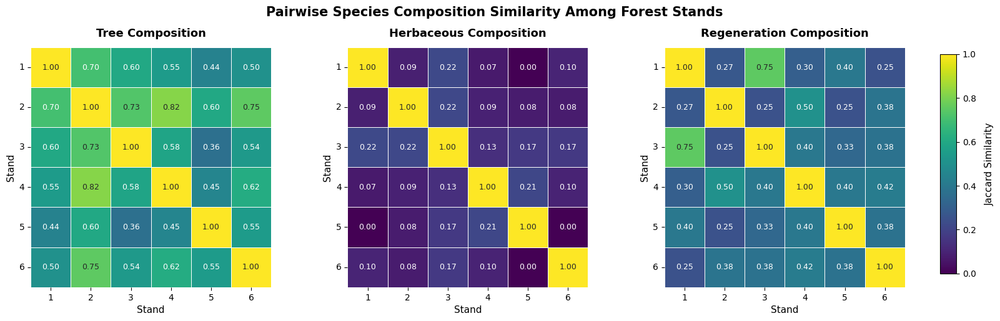

In [67]:
# STEP 61: CREATE PUBLICATION-READY JACCARD SIMILARITY HEATMAPS
#
# Goal:
# Visualize pairwise species-composition similarity among the six forest stands.
#
# Three panels:
# 1. Tree composition
# 2. Herbaceous composition
# 3. Regeneration composition
#
# Each cell displays the Jaccard similarity between two stands.
# Values range from 0 (no shared species) to 1 (identical observed composition).
#
# All three panels use the same color scale so their values can be compared.

# Define the order of stands along both axes.
stand_order = [1, 2, 3, 4, 5, 6]

# Create a dictionary to store the Jaccard matrices.
jaccard_matrices = {}

# Loop through each vegetation layer.
for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:

    # Create an empty matrix with one row and column for each stand.
    similarity_matrix = pd.DataFrame(
        np.nan,
        index=stand_order,
        columns=stand_order
    )

    # Set diagonal values to 1.0 because each stand is identical to itself.
    for stand in stand_order:
        similarity_matrix.loc[stand, stand] = 1.0

    # Retrieve the pairwise comparisons for this vegetation layer.
    layer_results = shared_species_summary[
        shared_species_summary['Vegetation Layer'] == vegetation_layer
    ]

    # Populate the matrix with pairwise Jaccard similarity values.
    for _, row in layer_results.iterrows():

        # Identify the two stands being compared.
        stand_a = row['Stand A']
        stand_b = row['Stand B']

        # Retrieve the calculated Jaccard similarity.
        similarity = row['Jaccard Similarity']

        # Fill both matrix positions because similarity is symmetric.
        similarity_matrix.loc[stand_a, stand_b] = similarity
        similarity_matrix.loc[stand_b, stand_a] = similarity

    # Save the completed matrix for this vegetation layer.
    jaccard_matrices[vegetation_layer] = similarity_matrix


# ------------------------------------------------------------
# CREATE THE THREE-PANEL FIGURE
# ------------------------------------------------------------

# Create three horizontally arranged heatmap panels.
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(17, 5.5)
)

# Define the vegetation layers in display order.
vegetation_layers = ['Tree', 'Herbaceous', 'Regeneration']

# Draw each heatmap.
for ax, vegetation_layer in zip(axes, vegetation_layers):

    # Retrieve the appropriate Jaccard matrix.
    matrix = jaccard_matrices[vegetation_layer]

    # Draw the heatmap.
    sns.heatmap(
        matrix,
        ax=ax,
        annot=True,                 # Display values inside each cell.
        fmt='.2f',                  # Round values to two decimal places.
        cmap='viridis',             # Use a continuous color gradient.
        vmin=0,                     # Set the minimum color-scale value.
        vmax=1,                     # Set the maximum color-scale value.
        square=True,                # Keep cells square.
        linewidths=0.5,             # Separate cells with subtle lines.
        cbar=False,                 # Add one shared colorbar separately.
        annot_kws={'size': 9}       # Set annotation font size.
    )

    # Add a title to each panel.
    ax.set_title(
        f'{vegetation_layer} Composition',
        fontsize=13,
        fontweight='bold',
        pad=12
    )

    # Label the horizontal and vertical axes.
    ax.set_xlabel('Stand', fontsize=11)
    ax.set_ylabel('Stand', fontsize=11)

    # Format the stand numbers along both axes.
    ax.set_xticklabels(stand_order, rotation=0)
    ax.set_yticklabels(stand_order, rotation=0)


# ------------------------------------------------------------
# FIXED COLORBAR POSITION
# ------------------------------------------------------------

# Adjust the figure margins to reserve dedicated space on the right.
# This prevents the colorbar from overlapping the Regeneration heatmap.
fig.subplots_adjust(
    left=0.06,
    right=0.89,
    bottom=0.14,
    top=0.84,
    wspace=0.28
)

# Create a separate axis for the colorbar.
# Values represent [left, bottom, width, height] in figure coordinates.
colorbar_axis = fig.add_axes(
    [0.92, 0.18, 0.015, 0.64]
)

# Add the shared colorbar using the first heatmap's color scale.
colorbar = fig.colorbar(
    axes[0].collections[0],
    cax=colorbar_axis
)

# Label the colorbar.
colorbar.set_label(
    'Jaccard Similarity',
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# FIGURE TITLE AND EXPORT
# ------------------------------------------------------------

# Add a figure-wide title.
fig.suptitle(
    'Pairwise Species Composition Similarity Among Forest Stands',
    fontsize=15,
    fontweight='bold',
    y=0.96
)

# Save a high-resolution PNG for reports and presentations.
plt.savefig(
    export_dir / 'Jaccard_Similarity_Heatmaps.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a PDF version for publication-quality output.
plt.savefig(
    export_dir / 'Jaccard_Similarity_Heatmaps.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

In [68]:
# STEP 62: ASSEMBLE STAND-LEVEL SPECIES COMPOSITION PROFILES
#
# Goal:
# Create one comprehensive species composition profile for each stand.
#
# Each stand profile will contain:
# 1. Tree species and tree richness.
# 2. Herbaceous species and herbaceous richness.
# 3. Regeneration species and regeneration richness.
#
# Species lists are based on observed presence in the corresponding
# presence/absence matrices.
#
# This step organizes existing results; it does not modify the
# original field datasets.

# Identify the vegetation layers and their corresponding matrices.
composition_matrices = {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}

# Create an empty list to store the profile for each stand.
stand_composition_profiles = []

# Loop through each stand.
for stand in stand_order:

    # Create a dictionary to store this stand's information.
    stand_profile = {
        'Stand ID': stand
    }

    # Examine each vegetation layer separately.
    for vegetation_layer, presence_matrix in composition_matrices.items():

        # Select species recorded in this stand.
        # A value of 1 indicates that the species was observed.
        observed_species = sorted(
            presence_matrix.index[
                presence_matrix[stand] == 1
            ].tolist()
        )

        # Calculate observed richness as the number of recorded species.
        observed_richness = len(observed_species)

        # Store the species list and richness value in the profile.
        stand_profile[f'{vegetation_layer} Richness'] = observed_richness

        stand_profile[f'{vegetation_layer} Species'] = observed_species

    # Add the completed stand profile to the overall list.
    stand_composition_profiles.append(stand_profile)

# Convert the profiles into a DataFrame.
stand_composition_profiles_df = pd.DataFrame(
    stand_composition_profiles
)

# Calculate total observed richness across all three vegetation layers.
# Note: A species occurring in multiple layers is counted once in each
# layer-specific richness value, so this is a sum of layer richness,
# not the number of unique species across the entire stand.
stand_composition_profiles_df['Combined Layer Richness'] = (
    stand_composition_profiles_df['Tree Richness']
    + stand_composition_profiles_df['Herbaceous Richness']
    + stand_composition_profiles_df['Regeneration Richness']
)

# Display the richness summary first.
display(
    stand_composition_profiles_df[
        [
            'Stand ID',
            'Tree Richness',
            'Herbaceous Richness',
            'Regeneration Richness',
            'Combined Layer Richness'
        ]
    ]
)

# Print the full species lists for each stand.
for _, profile in stand_composition_profiles_df.iterrows():

    print('\n' + '=' * 65)
    print(f"STAND {int(profile['Stand ID'])}")
    print('=' * 65)

    # Print the species and richness for each vegetation layer.
    for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:

        print(
            f"\n{vegetation_layer} "
            f"({profile[f'{vegetation_layer} Richness']} species):"
        )

        # Print each species on its own line.
        for species in profile[f'{vegetation_layer} Species']:
            print(f"  - {species}")

,Stand ID,Tree Richness,Herbaceous Richness,Regeneration Richness,Combined Layer Richness
0,1,7,4,3,14
1,2,10,21,11,42
2,3,9,7,4,20
3,4,10,27,10,47
4,5,6,7,4,17
5,6,11,7,7,25



STAND 1

Tree (7 species):
  - American Beech
  - Eastern Hemlock
  - Red Maple
  - Sugar Maple
  - White Birch
  - White Oak
  - Yellow Birch

Herbaceous (4 species):
  - Christmas Fern
  - Interrupted Fern
  - Princess Pine
  - Starflower

Regeneration (3 species):
  - American Beech
  - Eastern Hemlock
  - Yellow Birch

STAND 2

Tree (10 species):
  - American Beech
  - Eastern Hemlock
  - Eastern White Pine
  - Northern Red Oak
  - Red Maple
  - Sugar Maple
  - White Ash
  - White Birch
  - White Oak
  - Yellow Birch

Herbaceous (21 species):
  - American Royal Fern
  - Calico Aster
  - Christmas Fern
  - Cinnamon Fern
  - Dog Bane
  - Evergreen Club Moss
  - Fan Clubmoss
  - Flat Branched Tree Clubmoss
  - Intermediate Wood Fern
  - Long Down Wood Grass
  - Long Stalked Sedge
  - Long-Awned Wood Grass
  - Meadow Rue
  - Northern Wild Raisin
  - Partridgeberry
  - Princess Pine
  - Rattlesnake Plantain
  - Sensitive Fern
  - Small Flowered Buttercup
  - White Bear Sedge
  - Wrinkl

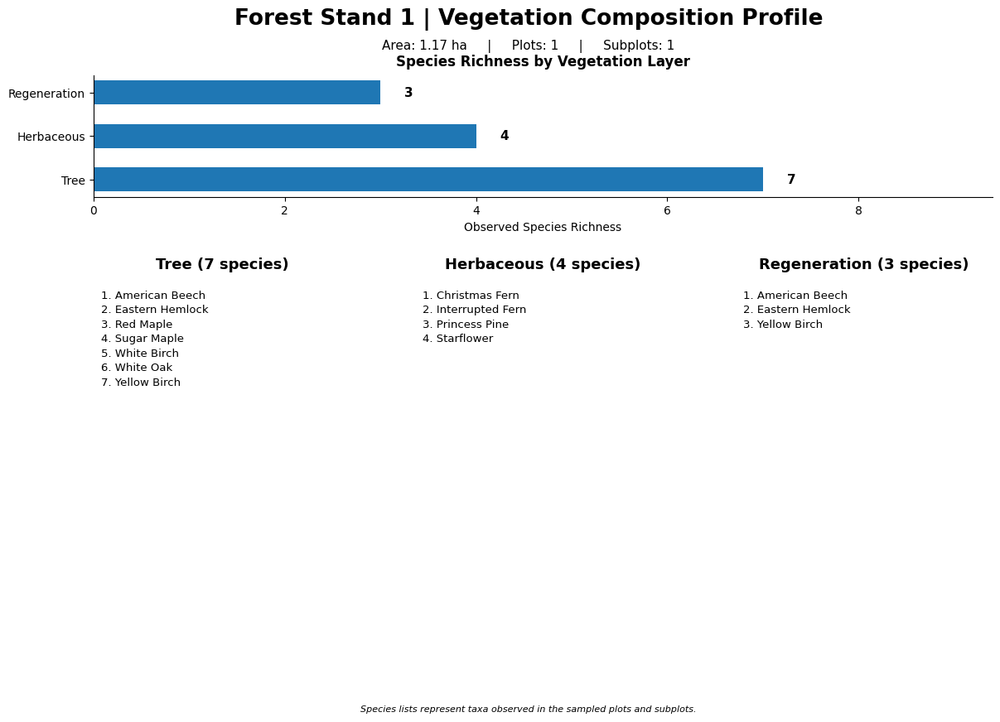

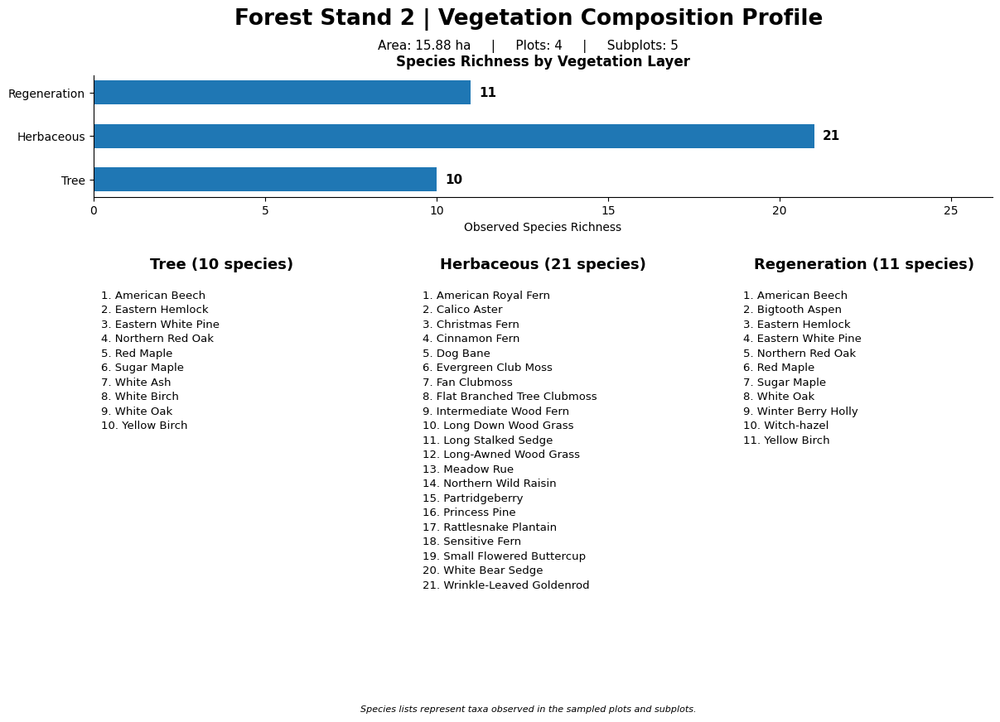

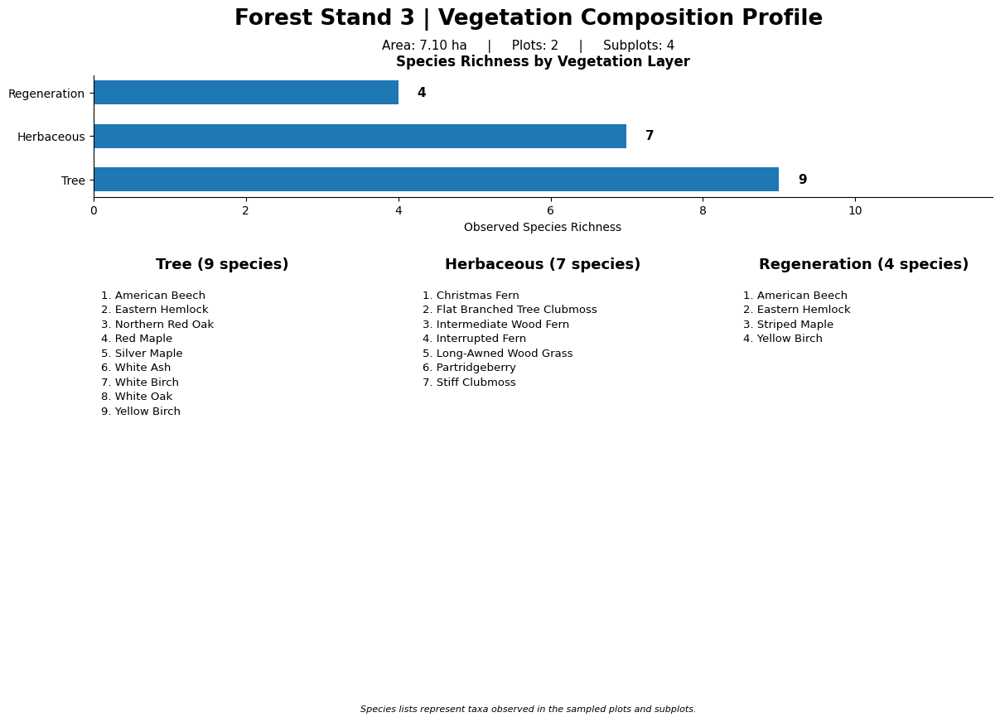

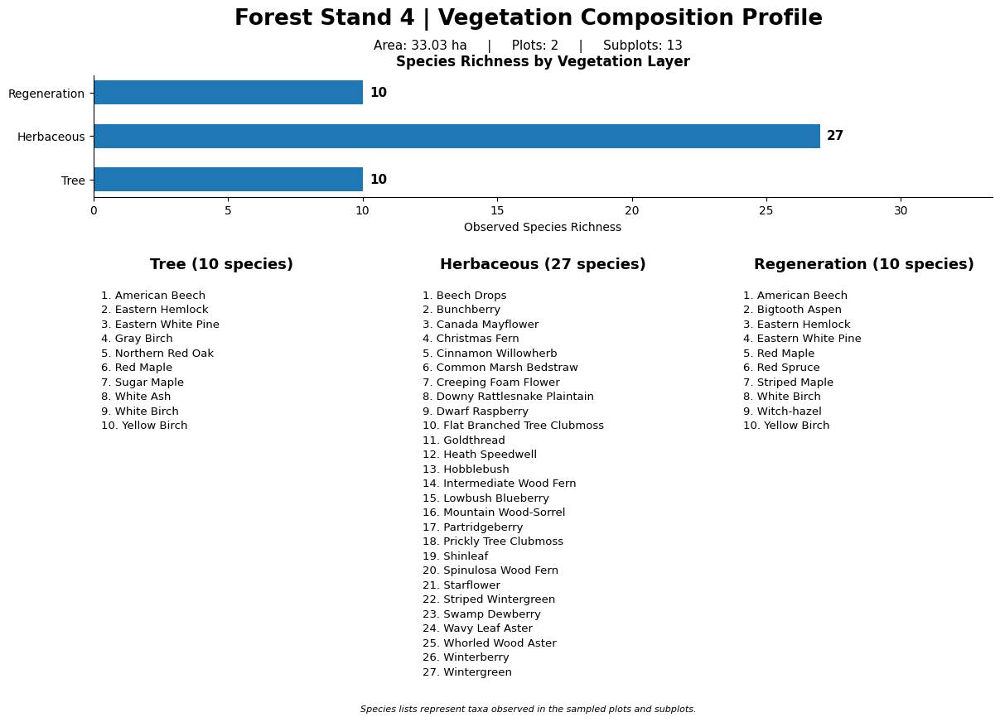

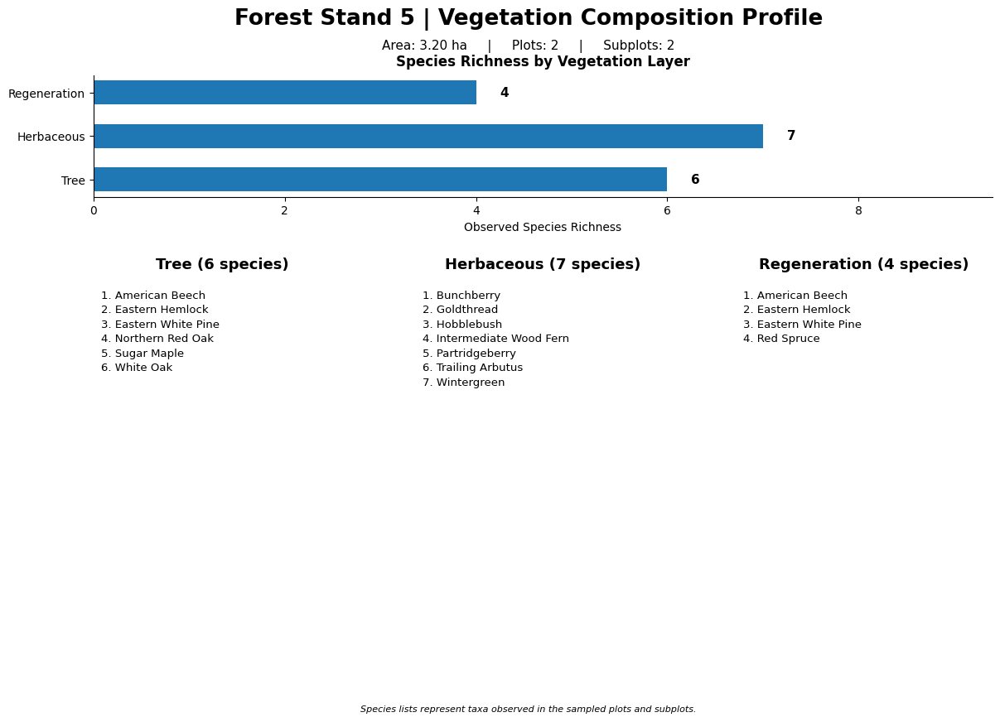

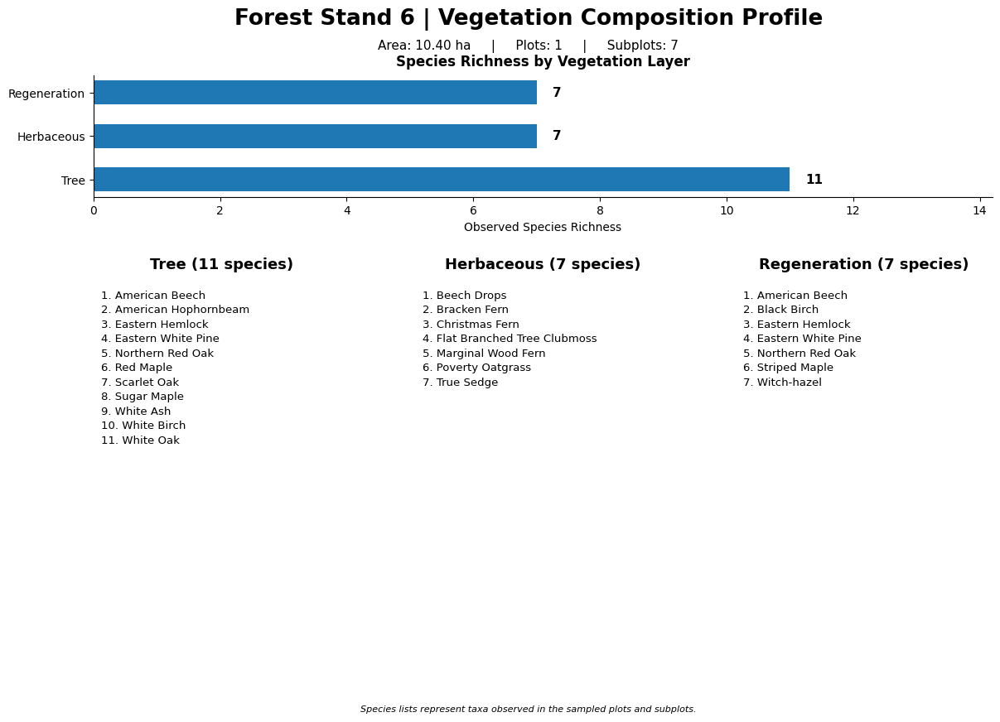

Six-page stand composition report saved to: /content/drive/MyDrive/ENV301/exports/Forest_Stand_Composition_Profiles.pdf


In [69]:
# STEP 63: CREATE INDIVIDUAL STAND COMPOSITION PROFILES
#
# Goal:
# Produce a six-page PDF report, with one page dedicated to each stand.
#
# Each page includes:
# 1. Stand area, number of plots, and number of subplots.
# 2. Tree, herbaceous, and regeneration richness.
# 3. A horizontal bar chart comparing richness among the three layers.
# 4. Complete observed species lists for all three vegetation layers.
#
# The report uses the previously calculated species composition profiles.
# Original field datasets are not modified.

# Import PdfPages so multiple figures can be saved into one PDF document.
from matplotlib.backends.backend_pdf import PdfPages

# Define the order of vegetation layers.
vegetation_layers = ['Tree', 'Herbaceous', 'Regeneration']

# Create a lookup dictionary for stand areas in hectares.
area_lookup = dict(
    zip(stand_areas['Stand ID'], stand_areas['Area_hectares'])
)

# Create a lookup dictionary for the number of unique plots per stand.
plot_count_lookup = (
    plot_metadata_analysis.groupby('Stand')['Plot ID']
    .nunique()
    .to_dict()
)

# Create a lookup dictionary for the number of unique subplots per stand.
subplot_count_lookup = (
    subplot_metadata_analysis.groupby('Stand ID')['Subplot ID']
    .nunique()
    .to_dict()
)

# Define the PDF output location.
profile_pdf = export_dir / 'Forest_Stand_Composition_Profiles.pdf'

# Open a PDF file that will contain all six stand profiles.
with PdfPages(profile_pdf) as pdf:

    # Generate one page for each stand.
    for _, profile in stand_composition_profiles_df.iterrows():

        # Extract the current stand ID.
        stand = int(profile['Stand ID'])

        # Create a landscape page with three species-list panels.
        fig = plt.figure(figsize=(14, 9))

        # Create a grid layout.
        # The upper section contains richness information.
        # The lower section contains the three species lists.
        gs = fig.add_gridspec(
            nrows=2,
            ncols=3,
            height_ratios=[1, 3],
            hspace=0.35,
            wspace=0.25
        )

        # ----------------------------------------------------
        # PAGE TITLE AND STAND INFORMATION
        # ----------------------------------------------------

        # Retrieve the area, plot count, and subplot count.
        stand_area = area_lookup.get(stand, np.nan)
        plot_count = plot_count_lookup.get(stand, 0)
        subplot_count = subplot_count_lookup.get(stand, 0)

        # Add the main stand title.
        fig.suptitle(
            f'Forest Stand {stand} | Vegetation Composition Profile',
            fontsize=19,
            fontweight='bold',
            y=0.97
        )

        # Add stand-level sampling information below the title.
        fig.text(
            0.5,
            0.915,
            (
                f'Area: {stand_area:.2f} ha'
                f'     |     Plots: {plot_count}'
                f'     |     Subplots: {subplot_count}'
            ),
            ha='center',
            fontsize=11
        )

        # ----------------------------------------------------
        # RICHNESS COMPARISON
        # ----------------------------------------------------

        # Create the upper richness chart.
        ax_richness = fig.add_subplot(gs[0, :])

        # Retrieve the richness values for the three layers.
        richness_values = [
            profile['Tree Richness'],
            profile['Herbaceous Richness'],
            profile['Regeneration Richness']
        ]

        # Draw horizontal bars comparing layer richness.
        bars = ax_richness.barh(
            vegetation_layers,
            richness_values,
            height=0.55
        )

        # Add the numerical richness value at the end of each bar.
        for bar, value in zip(bars, richness_values):

            ax_richness.text(
                bar.get_width() + 0.25,
                bar.get_y() + bar.get_height() / 2,
                str(int(value)),
                va='center',
                fontsize=11,
                fontweight='bold'
            )

        # Label the richness axis.
        ax_richness.set_xlabel(
            'Observed Species Richness',
            fontsize=10
        )

        # Set the horizontal axis limit to leave room for the labels.
        ax_richness.set_xlim(
            0,
            max(richness_values) * 1.2 + 1
        )

        # Remove unnecessary chart borders.
        ax_richness.spines['top'].set_visible(False)
        ax_richness.spines['right'].set_visible(False)

        # Add a small heading above the chart.
        ax_richness.set_title(
            'Species Richness by Vegetation Layer',
            fontsize=12,
            fontweight='bold',
            pad=8
        )

        # ----------------------------------------------------
        # SPECIES LISTS
        # ----------------------------------------------------

        # Create one panel for each vegetation layer.
        for column, vegetation_layer in enumerate(vegetation_layers):

            # Add the species-list panel.
            ax_species = fig.add_subplot(gs[1, column])

            # Retrieve the species list for this stand and layer.
            species_list = profile[
                f'{vegetation_layer} Species'
            ]

            # Turn off the axes because this panel is a text-based profile.
            ax_species.axis('off')

            # Add the vegetation-layer heading and richness count.
            ax_species.set_title(
                f'{vegetation_layer} ({len(species_list)} species)',
                fontsize=13,
                fontweight='bold',
                pad=12
            )

            # Create a numbered species list.
            # Each species is placed on its own line.
            species_text = '\n'.join(
                f'{number}. {species}'
                for number, species in enumerate(species_list, start=1)
            )

            # Display the species list within the panel.
            ax_species.text(
                0.03,
                0.98,
                species_text if species_text else 'No species recorded',
                transform=ax_species.transAxes,
                ha='left',
                va='top',
                fontsize=9.5,
                linespacing=1.45
            )

        # Add a subtle footer describing the data.
        fig.text(
            0.5,
            0.025,
            'Species lists represent taxa observed in the sampled plots and subplots.',
            ha='center',
            fontsize=8,
            style='italic'
        )

        # Save the current stand page to the combined PDF.
        pdf.savefig(
            fig,
            bbox_inches='tight'
        )

        # Also save an individual high-resolution PNG for this stand.
        fig.savefig(
            export_dir / f'Stand_{stand}_Composition_Profile.png',
            dpi=400,
            bbox_inches='tight'
        )

        # Display the current stand profile.
        plt.show()

        # Close the figure before generating the next stand.
        plt.close(fig)

# Confirm the PDF export location.
print(f'Six-page stand composition report saved to: {profile_pdf}')

In [70]:
# STEP 64: CALCULATE SPECIES OVERLAP BETWEEN VEGETATION LAYERS
#
# Goal:
# Determine how species are distributed across the tree, herbaceous,
# and regeneration layers within each stand.
#
# This analysis distinguishes:
# 1. Species recorded in one vegetation layer.
# 2. Species recorded in two vegetation layers.
# 3. Species recorded in all three vegetation layers.
#
# It also calculates the total number of unique species per stand.
# A species occurring in multiple layers is counted only once in
# the total unique species calculation.

# Create a list to store the cross-layer overlap results.
layer_overlap_results = []

# Loop through each stand.
for stand in stand_order:

    # Create an empty dictionary to store species sets for this stand.
    stand_species = {}

    # Retrieve the species recorded in each vegetation layer.
    for vegetation_layer, presence_matrix in composition_matrices.items():

        # Identify species with a presence value of 1 in this stand.
        stand_species[vegetation_layer] = set(
            presence_matrix.index[
                presence_matrix[stand] == 1
            ]
        )

    # Combine all three species sets.
    # A set automatically removes duplicate species names.
    all_species = (
        stand_species['Tree']
        | stand_species['Herbaceous']
        | stand_species['Regeneration']
    )

    # Count how many vegetation layers each species occurs in.
    species_layer_counts = {}

    for species in all_species:

        # Count the number of layers in which this species was recorded.
        species_layer_counts[species] = sum(
            species in stand_species[layer]
            for layer in vegetation_layers
        )

    # Calculate the number of species occurring in one, two, or three layers.
    one_layer = sum(
        count == 1 for count in species_layer_counts.values()
    )

    two_layers = sum(
        count == 2 for count in species_layer_counts.values()
    )

    three_layers = sum(
        count == 3 for count in species_layer_counts.values()
    )

    # Store the results for this stand.
    layer_overlap_results.append({
        'Stand ID': stand,
        'Unique Species': len(all_species),
        'One Layer Only': one_layer,
        'Two Layers': two_layers,
        'All Three Layers': three_layers
    })

# Convert the results into a DataFrame.
layer_overlap_summary = pd.DataFrame(layer_overlap_results)

# Display the cross-layer overlap summary.
display(layer_overlap_summary)

# Verify that the three overlap categories sum to total unique richness.
print(
    'Overlap totals correctly account for unique species:',
    (
        layer_overlap_summary['One Layer Only']
        + layer_overlap_summary['Two Layers']
        + layer_overlap_summary['All Three Layers']
        == layer_overlap_summary['Unique Species']
    ).all()
)

,Stand ID,Unique Species,One Layer Only,Two Layers,All Three Layers
0,1,11,8,3,0
1,2,34,26,8,0
2,3,17,14,3,0
3,4,41,35,6,0
4,5,14,11,3,0
5,6,21,17,4,0


Overlap totals correctly account for unique species: True


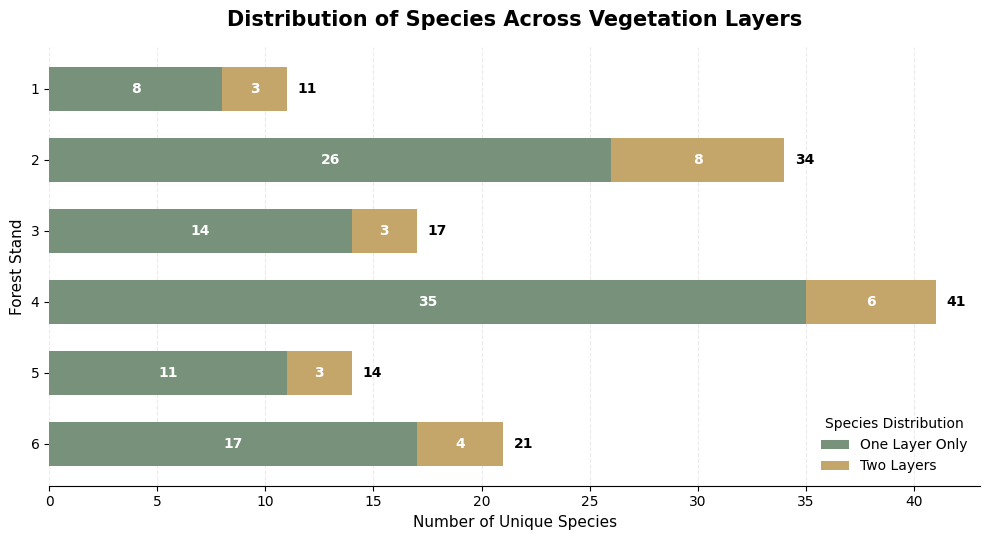

In [71]:
# STEP 65: VISUALIZE SPECIES DISTRIBUTION ACROSS VEGETATION LAYERS
#
# Goal:
# Compare the number of unique species occurring in one versus
# two vegetation layers across the six stands.
#
# The stacked bars show how each stand's unique species richness
# is divided between these two categories.

# Create the figure and axis.
fig, ax = plt.subplots(figsize=(10, 5.5))

# Define the two categories and their corresponding colors.
categories = ['One Layer Only', 'Two Layers']
colors = ['#78917A', '#C5A66A']

# Initialize the left position of each stacked bar.
left_positions = np.zeros(len(layer_overlap_summary))

# Draw the stacked horizontal bars.
for category, color in zip(categories, colors):

    # Retrieve the species counts for this category.
    values = layer_overlap_summary[category].values

    # Draw this category as part of the stacked bar.
    bars = ax.barh(
        layer_overlap_summary['Stand ID'].astype(str),
        values,
        left=left_positions,
        color=color,
        label=category,
        height=0.62
    )

    # Add the numerical count inside each visible bar segment.
    for bar, value in zip(bars, values):

        if value > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                str(int(value)),
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold',
                color='white'
            )

    # Update the starting position for the next segment.
    left_positions += values

# Add the total unique species count at the end of each bar.
for position, total in enumerate(layer_overlap_summary['Unique Species']):

    ax.text(
        total + 0.5,
        position,
        str(int(total)),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

# Add chart title and axis labels.
ax.set_title(
    'Distribution of Species Across Vegetation Layers',
    fontsize=15,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Number of Unique Species', fontsize=11)
ax.set_ylabel('Forest Stand', fontsize=11)

# Place Stand 1 at the top of the chart.
ax.invert_yaxis()

# Remove unnecessary borders for a cleaner report aesthetic.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# Add a subtle vertical grid for easier comparison.
ax.xaxis.grid(
    True,
    linestyle='--',
    alpha=0.25
)

ax.set_axisbelow(True)

# Add the legend.
ax.legend(
    title='Species Distribution',
    frameon=False,
    loc='lower right'
)

# Adjust the layout.
plt.tight_layout()

# Export the figure in high resolution.
plt.savefig(
    export_dir / 'Species_Distribution_Across_Layers.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    export_dir / 'Species_Distribution_Across_Layers.pdf',
    bbox_inches='tight'
)

# Display the figure.
plt.show()

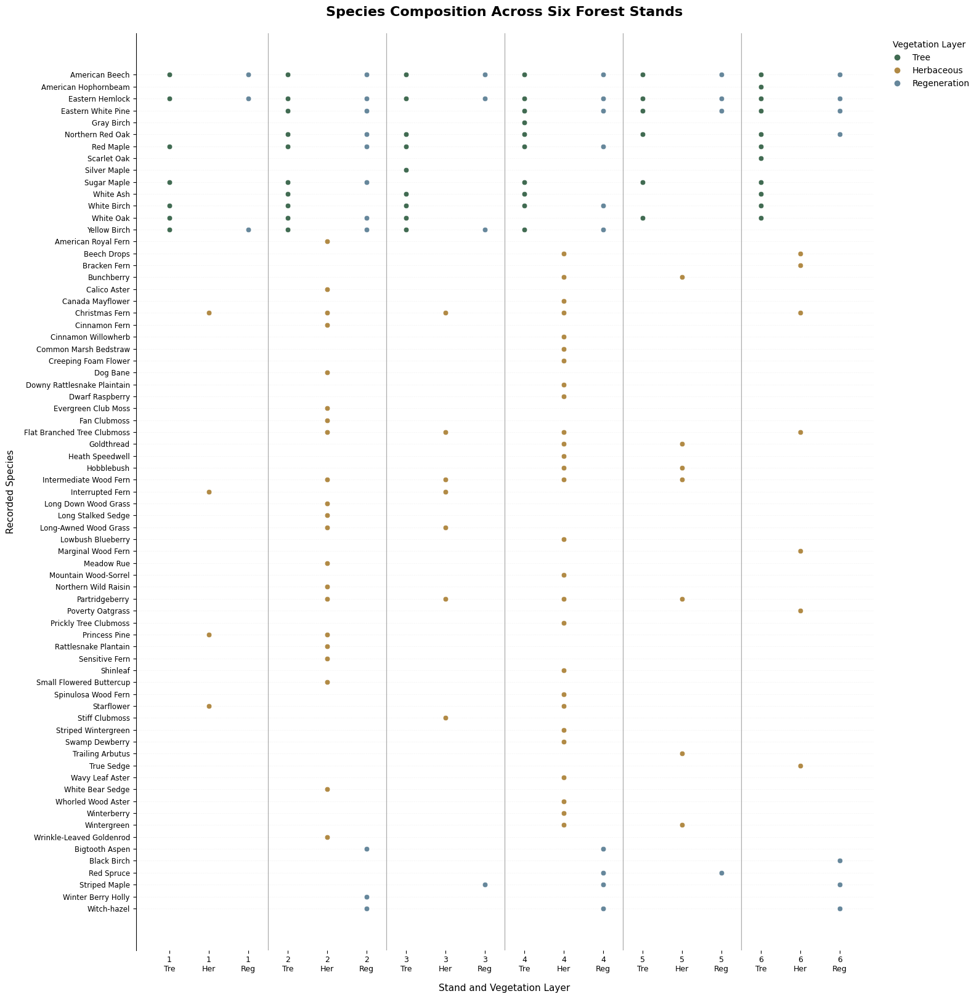

Total unique species represented: 71


In [72]:
# STEP 66: CREATE A MASTER SPECIES-COMPOSITION MATRIX
#
# Goal:
# Visualize the identity and distribution of all recorded species
# across six stands and three vegetation layers.
#
# Each row represents one species.
# Each stand has three columns:
#   Tree, Herbaceous, and Regeneration.
#
# Colored circles indicate that a species was recorded in that
# particular stand and vegetation layer.
#
# Species are listed once, even when they occur in multiple layers.

# Define the vegetation layers and their display colors.
layer_colors = {
    'Tree': '#416B52',
    'Herbaceous': '#B18A45',
    'Regeneration': '#66879B'
}

# Reuse the existing presence/absence matrices.
composition_matrices = {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}

# Create one master list containing every species recorded
# in at least one of the three vegetation layers.
all_species = set()

for matrix in composition_matrices.values():
    all_species.update(matrix.index.tolist())

# Establish a consistent species ordering.
# Species are grouped according to the first vegetation layer
# in which they appear: Tree, Herbaceous, then Regeneration.
species_order = []

for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:

    # Retrieve the species recorded in the current layer.
    layer_species = sorted(
        composition_matrices[vegetation_layer].index.tolist()
    )

    # Add species that have not already been included.
    for species in layer_species:
        if species not in species_order:
            species_order.append(species)

# Create the 18 column labels: six stands multiplied by three layers.
column_labels = []

for stand in stand_order:
    for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:
        column_labels.append((stand, vegetation_layer))

# Create an empty presence/absence matrix.
# Rows represent species and columns represent stand-layer combinations.
master_composition_matrix = pd.DataFrame(
    0,
    index=species_order,
    columns=pd.MultiIndex.from_tuples(
        column_labels,
        names=['Stand', 'Vegetation Layer']
    )
)

# Populate the master matrix using the existing presence/absence data.
for vegetation_layer, matrix in composition_matrices.items():

    # Loop through each stand.
    for stand in stand_order:

        # Identify species present in this stand and layer.
        observed_species = matrix.index[matrix[stand] == 1]

        # Mark those species as present in the master matrix.
        master_composition_matrix.loc[
            observed_species,
            (stand, vegetation_layer)
        ] = 1

# ------------------------------------------------------------
# CREATE THE SPECIES-COMPOSITION VISUALIZATION
# ------------------------------------------------------------

# Set figure height according to the number of species.
# This prevents the species labels from becoming overcrowded.
figure_height = max(12, len(species_order) * 0.23)

fig, ax = plt.subplots(
    figsize=(16, figure_height)
)

# Define the horizontal positions for the 18 columns.
x_positions = np.arange(len(column_labels))

# Define the vertical positions for all species.
y_positions = np.arange(len(species_order))

# Draw one circle for every observed species occurrence.
for column_index, (stand, vegetation_layer) in enumerate(column_labels):

    # Identify species recorded in this stand-layer combination.
    present_species = master_composition_matrix.index[
        master_composition_matrix[(stand, vegetation_layer)] == 1
    ]

    # Convert species names to their vertical plotting positions.
    present_y_positions = [
        species_order.index(species)
        for species in present_species
    ]

    # Draw the observed species as colored circles.
    ax.scatter(
        [column_index] * len(present_y_positions),
        present_y_positions,
        s=38,
        color=layer_colors[vegetation_layer],
        edgecolors='white',
        linewidths=0.4,
        zorder=3
    )

# Add horizontal gridlines to help follow species across the matrix.
ax.set_yticks(y_positions)
ax.set_yticklabels(species_order, fontsize=8.5)

ax.set_xticks(x_positions)

# Label each column with its stand number and vegetation layer.
ax.set_xticklabels(
    [
        f'{stand}\n{layer[:3]}'
        for stand, layer in column_labels
    ],
    fontsize=9
)

# Place the first species at the top of the figure.
ax.invert_yaxis()

# Add vertical separators between stands.
for separator in [2.5, 5.5, 8.5, 11.5, 14.5]:
    ax.axvline(
        separator,
        color='gray',
        linewidth=0.9,
        alpha=0.65
    )

# Add subtle horizontal reference lines.
ax.set_axisbelow(True)
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.4,
    alpha=0.35
)

# Label the axes.
ax.set_ylabel('Recorded Species', fontsize=11, labelpad=10)
ax.set_xlabel('Stand and Vegetation Layer', fontsize=11, labelpad=12)

# Add the figure title.
ax.set_title(
    'Species Composition Across Six Forest Stands',
    fontsize=16,
    fontweight='bold',
    pad=20
)

# Create a legend using the same colors as the matrix.
legend_handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor=layer_colors[layer],
        markeredgecolor='white',
        markersize=8,
        label=layer
    )
    for layer in layer_colors
]

ax.legend(
    handles=legend_handles,
    title='Vegetation Layer',
    loc='upper left',
    bbox_to_anchor=(1.01, 1),
    frameon=False
)

# Remove unnecessary chart borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Adjust spacing to accommodate species labels and legend.
plt.tight_layout()

# Export the figure at publication-quality resolution.
plt.savefig(
    export_dir / 'Master_Species_Composition_Matrix.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    export_dir / 'Master_Species_Composition_Matrix.pdf',
    bbox_inches='tight'
)

# Display the completed visualization.
plt.show()

# Report the number of unique species represented.
print(f'Total unique species represented: {len(species_order)}')

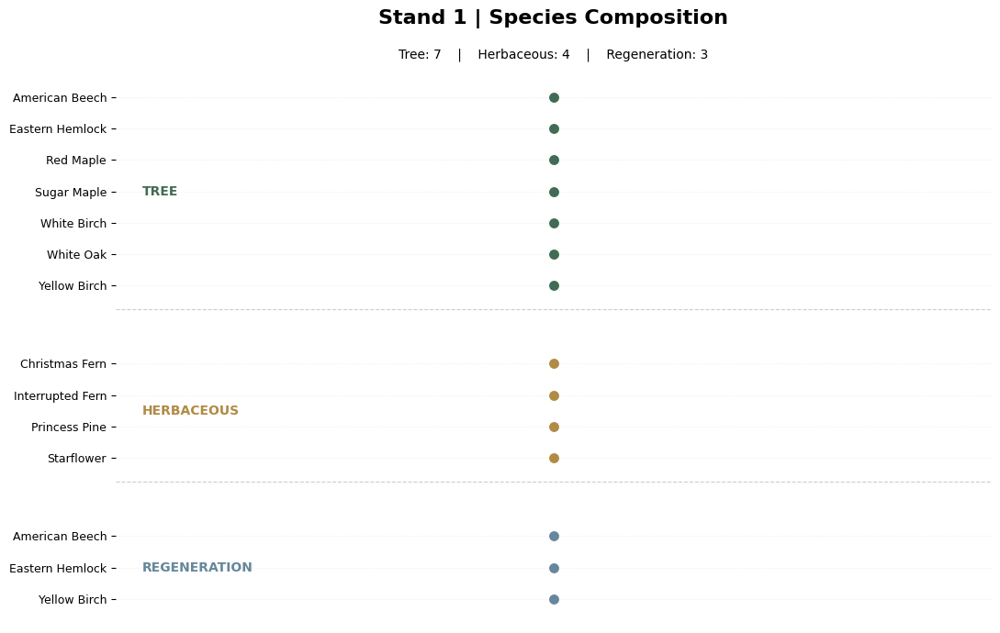

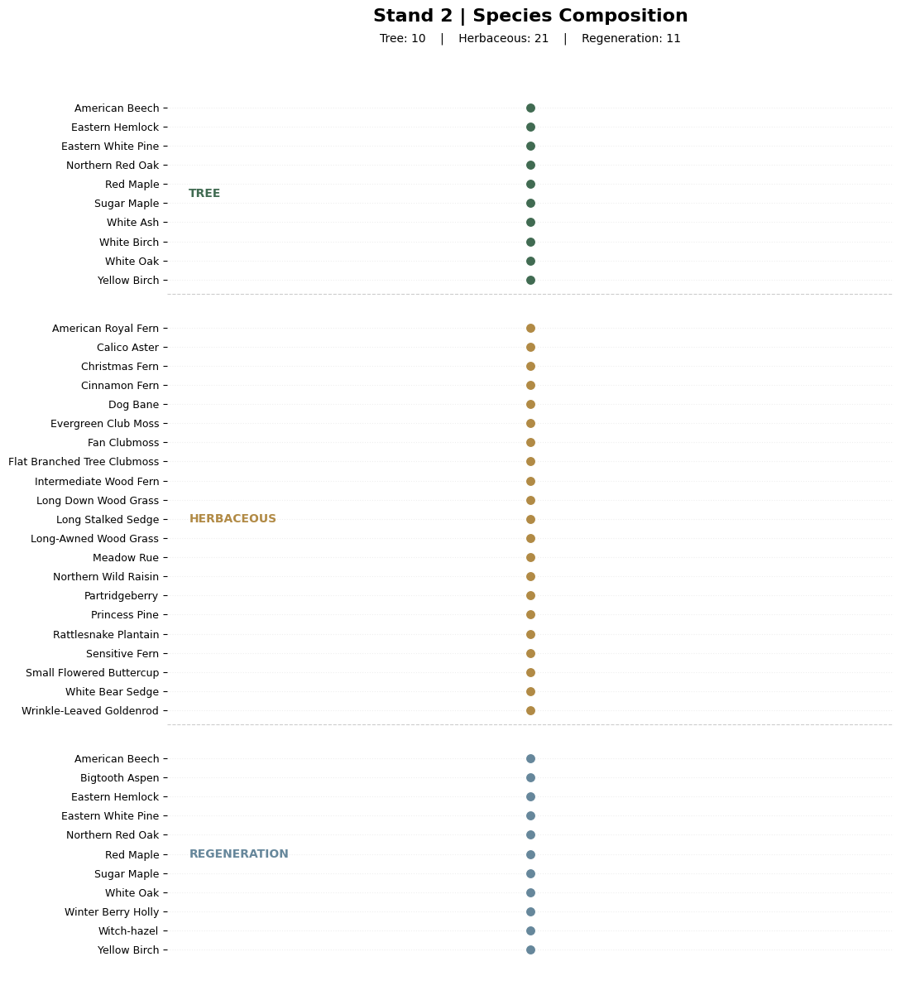

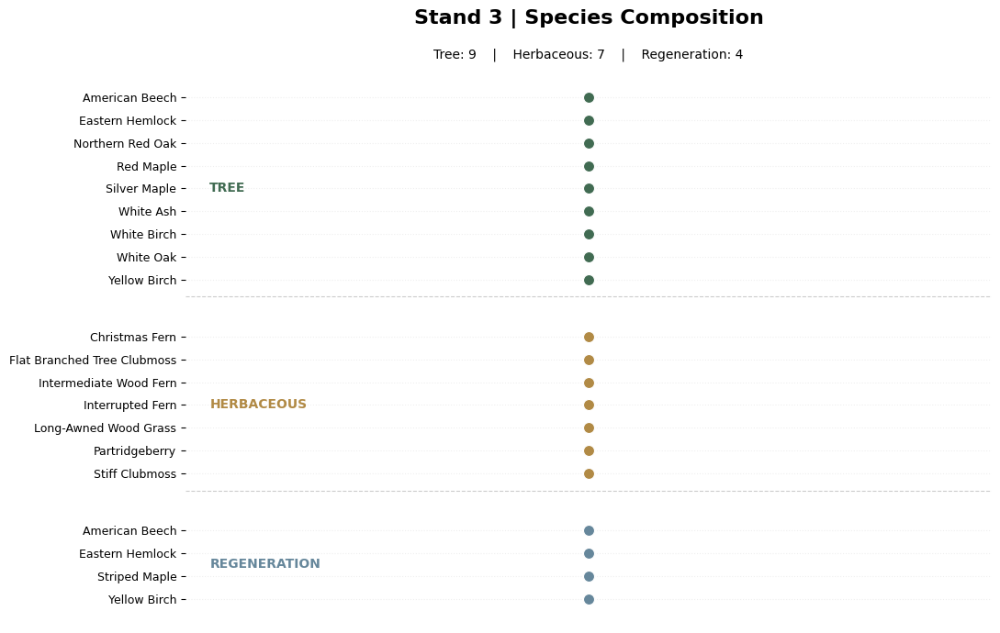

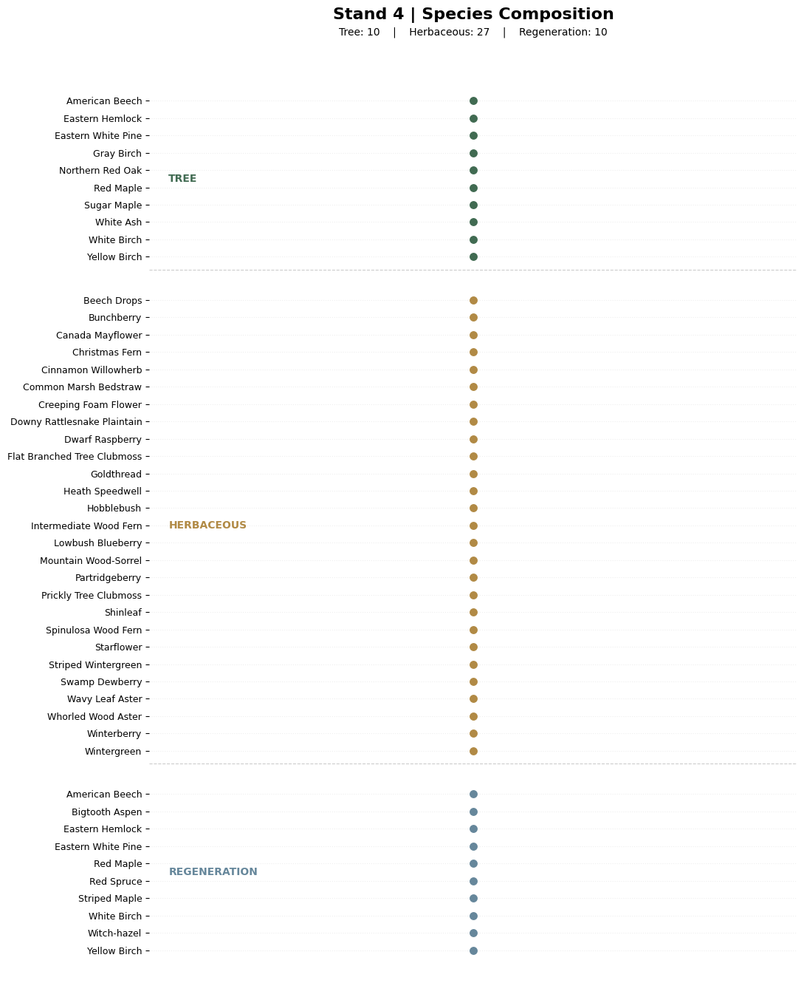

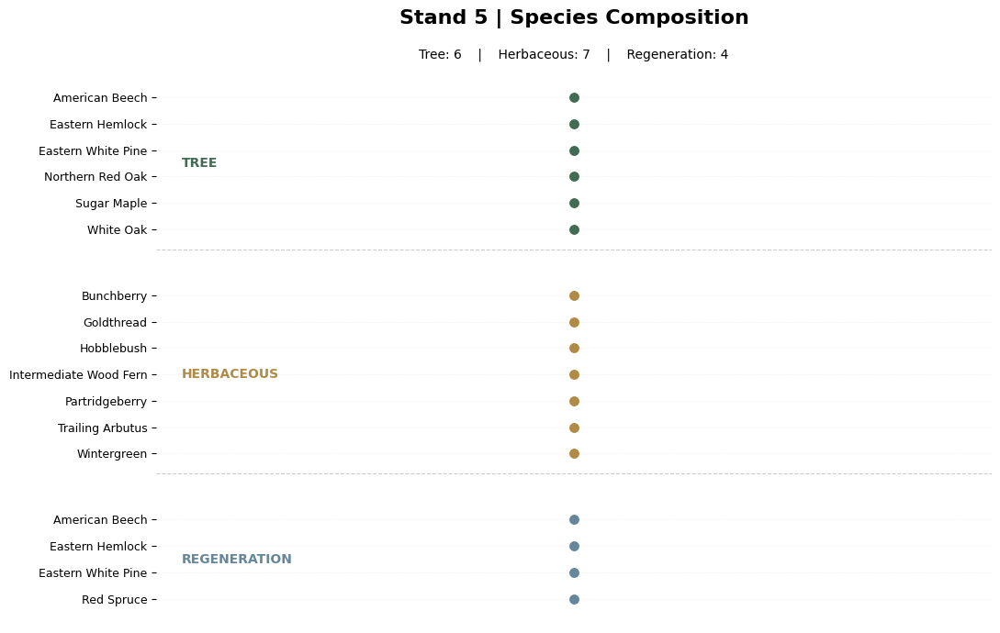

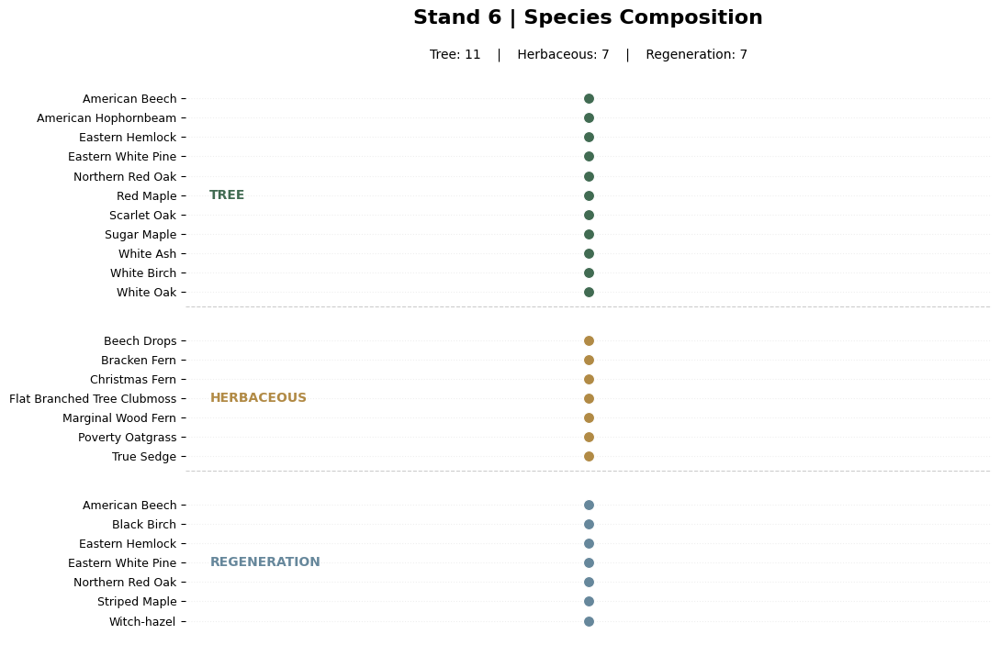

In [75]:
# STEP 67: CREATE INDIVIDUAL SPECIES-COMPOSITION FIGURES
#
# Each stand receives its own figure.
# Species are grouped into Tree, Herbaceous, and Regeneration layers.
# Colored markers identify each vegetation layer.

# Define consistent colors for the vegetation layers.
layer_colors = {
    'Tree': '#416B52',
    'Herbaceous': '#B18A45',
    'Regeneration': '#66879B'
}

# Define the vegetation-layer order.
vegetation_layers = ['Tree', 'Herbaceous', 'Regeneration']

# Loop through the six stand profiles.
for _, profile in stand_composition_profiles_df.iterrows():

    # Retrieve the current stand ID.
    stand = int(profile['Stand ID'])

    # Create a list to hold species, layer labels, and plotting positions.
    plotted_species = []

    # Track the vertical position of each species.
    current_position = 0

    # Store the locations of the section boundaries and headings.
    section_positions = []

    # Collect species separately for each vegetation layer.
    for vegetation_layer in vegetation_layers:

        # Retrieve the species observed in this layer.
        species_list = profile[f'{vegetation_layer} Species']

        # Record the center of this section for its heading.
        section_start = current_position

        # Add each species to the plotting list.
        for species in species_list:

            plotted_species.append({
                'Species': species,
                'Layer': vegetation_layer,
                'Position': current_position
            })

            current_position += 1

        # Store the section's center position.
        if len(species_list) > 0:
            section_positions.append({
                'Layer': vegetation_layer,
                'Center': (section_start + current_position - 1) / 2,
                'End': current_position
            })

        # Add extra vertical space between vegetation layers.
        current_position += 1.5

    # Determine figure height from the number of species.
    figure_height = max(7, len(plotted_species) * 0.29)

    # Create the figure.
    fig, ax = plt.subplots(figsize=(11, figure_height))

    # Plot each species as a colored circle.
    for item in plotted_species:

        ax.scatter(
            x=0,
            y=item['Position'],
            s=75,
            color=layer_colors[item['Layer']],
            edgecolors='white',
            linewidths=0.8,
            zorder=3
        )

    # Add species names along the vertical axis.
    ax.set_yticks([
        item['Position'] for item in plotted_species
    ])

    ax.set_yticklabels(
        [item['Species'] for item in plotted_species],
        fontsize=9
    )

    # Add headings for the three vegetation sections.
    for section in section_positions:

        ax.text(
            0.03,
            section['Center'],
            section['Layer'].upper(),
            transform=ax.get_yaxis_transform(),
            fontsize=10,
            fontweight='bold',
            color=layer_colors[section['Layer']],
            va='center'
        )

    # Add subtle horizontal separators between vegetation sections.
    for section in section_positions[:-1]:

        ax.axhline(
            section['End'] - 0.25,
            color='gray',
            linewidth=0.8,
            alpha=0.4,
            linestyle='--'
        )

    # Hide the horizontal axis.
    ax.set_xticks([])
    ax.set_xlim(-0.12, 0.12)

    # Keep the species in the intended top-to-bottom order.
    ax.invert_yaxis()

    # Add the figure title.
    ax.set_title(
        f'Stand {stand} | Species Composition',
        fontsize=16,
        fontweight='bold',
        pad=38
    )

    # Add the richness summary beneath the title.
    ax.text(
        0.5,
        1.025,
        (
            f"Tree: {int(profile['Tree Richness'])}    |    "
            f"Herbaceous: {int(profile['Herbaceous Richness'])}    |    "
            f"Regeneration: {int(profile['Regeneration Richness'])}"
        ),
        transform=ax.transAxes,
        ha='center',
        fontsize=10
    )

    # Remove unnecessary borders.
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Add a clean background grid.
    ax.set_axisbelow(True)
    ax.grid(
        axis='y',
        linestyle=':',
        alpha=0.2
    )

    # Adjust the layout to accommodate the labels.
    plt.tight_layout()

    # Export the individual stand figure as a PNG.
    plt.savefig(
        export_dir / f'Stand_{stand}_Species_Composition.png',
        dpi=600,
        bbox_inches='tight'
    )

    # Export the individual stand figure as a PDF.
    plt.savefig(
        export_dir / f'Stand_{stand}_Species_Composition.pdf',
        bbox_inches='tight'
    )

    # Display the completed figure.
    plt.show()

    # Close the figure before generating the next stand.
    plt.close(fig)

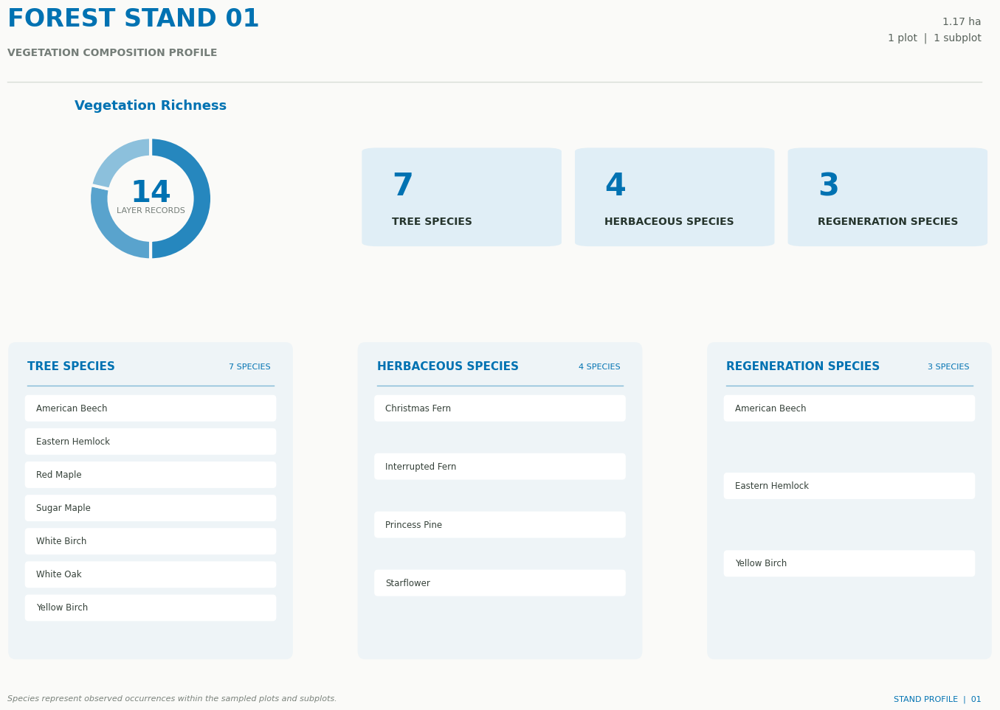

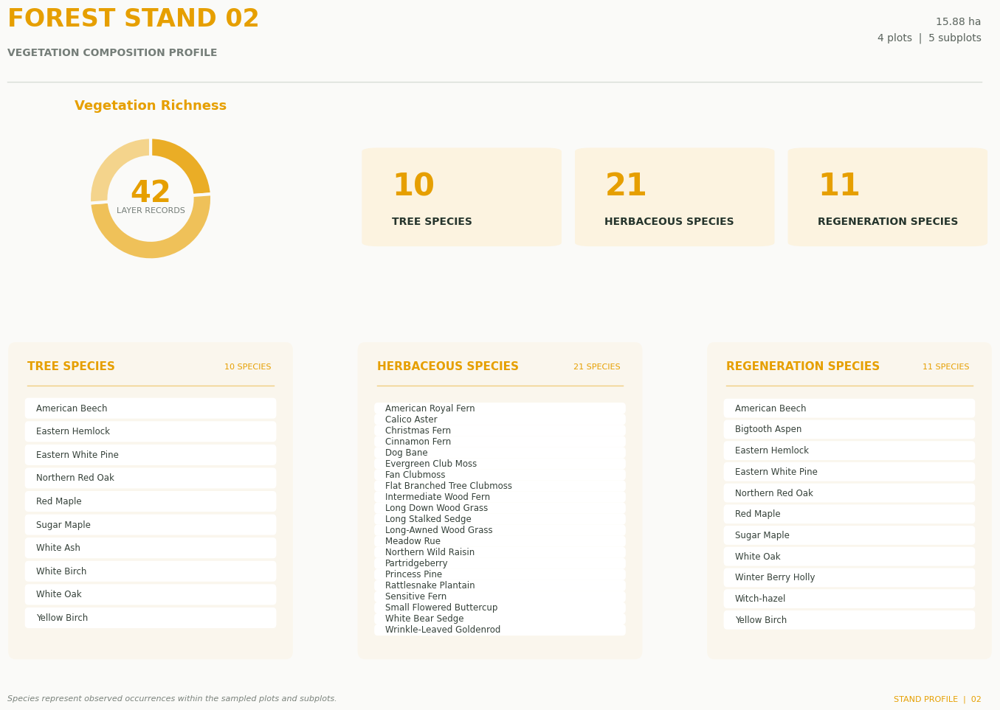

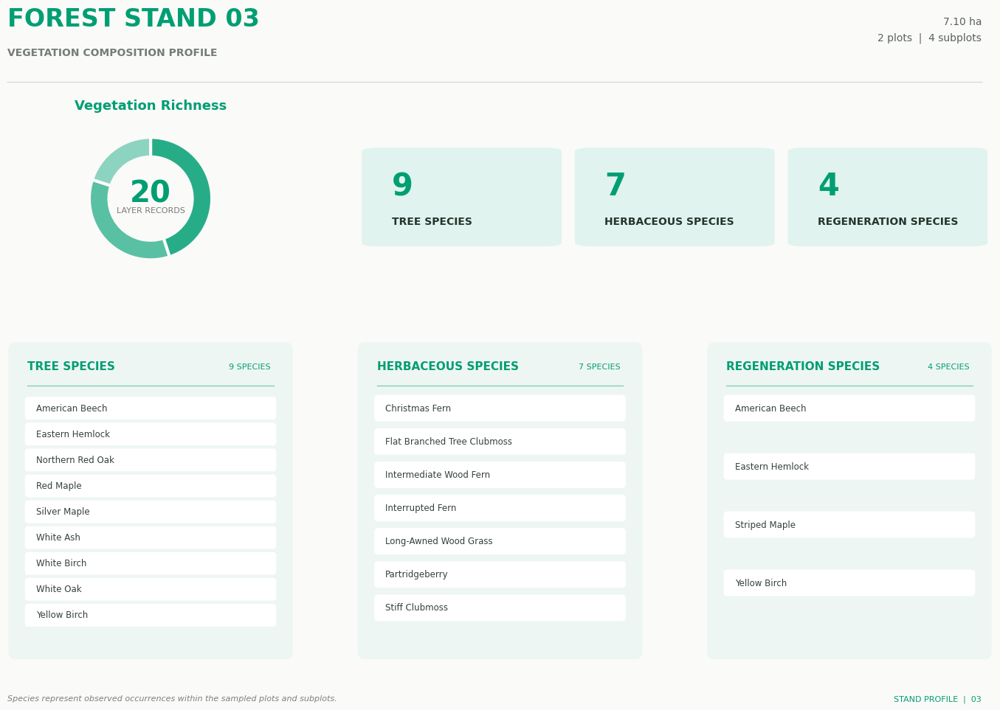

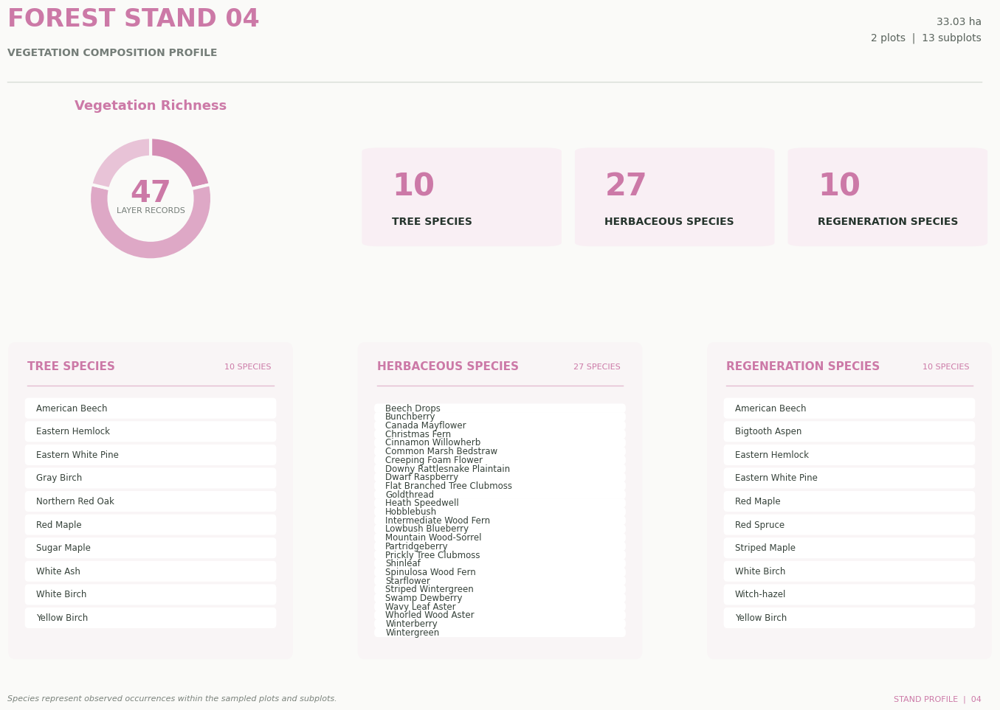

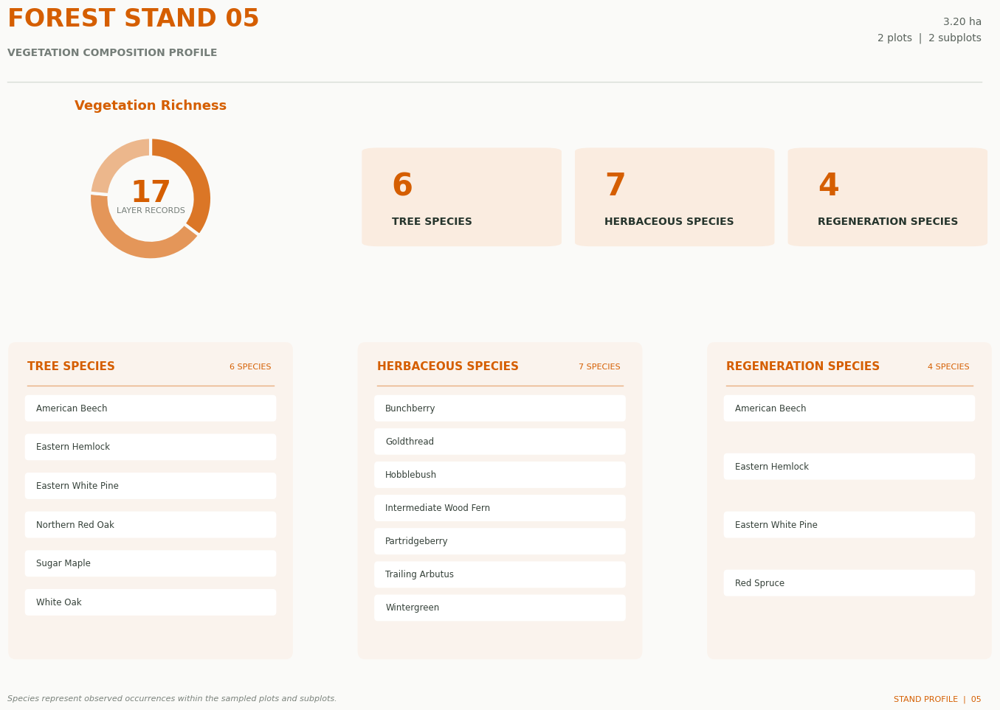

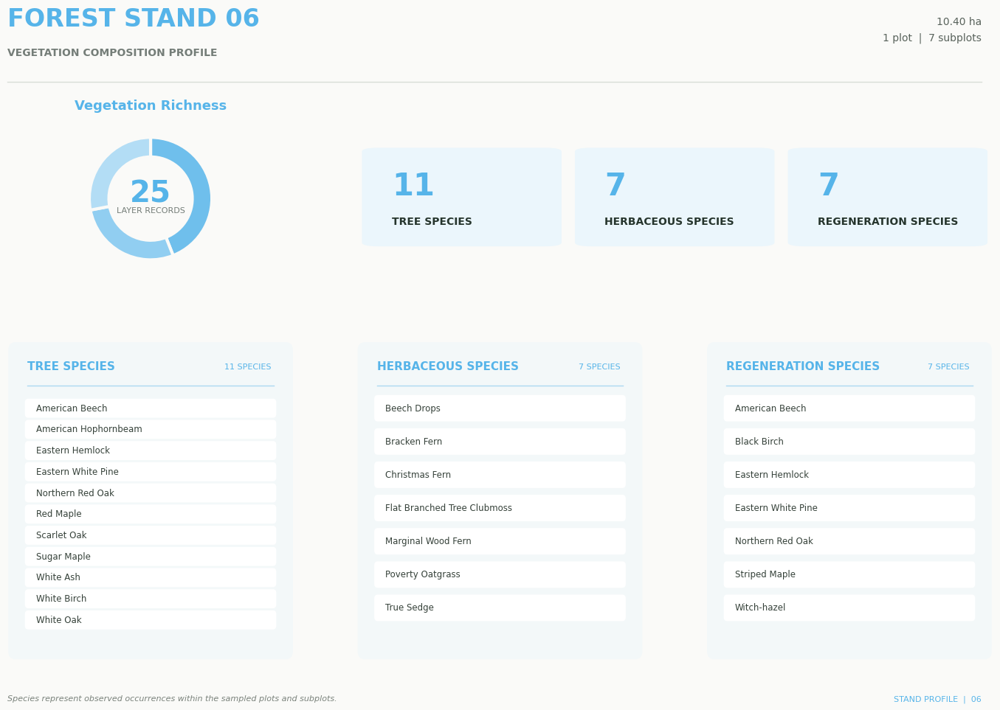

In [79]:
# STEP 68: CREATE PUBLICATION-STYLE STAND VEGETATION COMPOSITION DASHBOARDS
#
# Goal:
# Create six individual ecological composition profiles.
#
# Each profile includes:
# 1. A donut chart showing richness across the three vegetation layers.
# 2. Three richness cards with readable labels.
# 3. Three species panels:
#       Tree Species
#       Herbaceous Species
#       Regeneration Species
# 4. Stand area and sampling effort.
#
# Each stand uses its established color from the original figures.
# Richness cards use pale backgrounds and dark text for readability.
# Sampling information automatically uses singular or plural wording.

# Import color conversion and rounded panel tools.
from matplotlib.colors import to_rgb
from matplotlib.patches import FancyBboxPatch

# ------------------------------------------------------------
# ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

# Use the same colors as the earlier publication figures.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Define the vegetation-layer order.
vegetation_layers = [
    'Tree',
    'Herbaceous',
    'Regeneration'
]

# Define the page background.
page_background = '#FAFAF8'

# Define the full vegetation-layer headings.
layer_headings = {
    'Tree': 'TREE SPECIES',
    'Herbaceous': 'HERBACEOUS SPECIES',
    'Regeneration': 'REGENERATION SPECIES'
}

# ------------------------------------------------------------
# HELPER FUNCTION: CREATE LIGHTER SHADES OF A STAND COLOR
# ------------------------------------------------------------

def create_color_shades(base_color):

    # Convert the original stand color into RGB values.
    rgb = to_rgb(base_color)

    # Blend the original color with white to create lighter shades.
    shades = []

    for blend in [0.15, 0.35, 0.55]:

        lighter_shade = tuple(
            channel * (1 - blend) + blend
            for channel in rgb
        )

        shades.append(lighter_shade)

    return shades


# ------------------------------------------------------------
# GENERATE THE SIX STAND PROFILES
# ------------------------------------------------------------

# Loop through each stand's composition profile.
for _, profile in stand_composition_profiles_df.iterrows():

    # Retrieve the current stand ID.
    stand = int(profile['Stand ID'])

    # Retrieve the established color for this stand.
    stand_color = stand_colors[stand]

    # Generate lighter shades for the donut chart.
    layer_shades = create_color_shades(stand_color)

    # Retrieve richness values for each vegetation layer.
    richness_values = [
        int(profile['Tree Richness']),
        int(profile['Herbaceous Richness']),
        int(profile['Regeneration Richness'])
    ]

    # Calculate the sum of layer-specific richness values.
    # Species recorded in multiple layers are counted once per layer.
    total_layer_richness = sum(richness_values)

    # Retrieve the species recorded in each vegetation layer.
    species_by_layer = {
        layer: profile[f'{layer} Species']
        for layer in vegetation_layers
    }

    # Retrieve stand area and sampling effort.
    stand_area = area_lookup.get(stand, np.nan)
    plot_count = plot_count_lookup.get(stand, 0)
    subplot_count = subplot_count_lookup.get(stand, 0)

    # --------------------------------------------------------
    # FIGURE AND PAGE LAYOUT
    # --------------------------------------------------------

    # Create a landscape-oriented report page.
    fig = plt.figure(
        figsize=(15, 10),
        facecolor=page_background
    )

    # Divide the page into an upper and lower section.
    gs = fig.add_gridspec(
        nrows=2,
        ncols=3,
        height_ratios=[1.2, 2.5],
        hspace=0.28,
        wspace=0.22,
        left=0.06,
        right=0.95,
        top=0.82,
        bottom=0.09
    )

    # --------------------------------------------------------
    # HEADER
    # --------------------------------------------------------

    # Display the stand identification.
    fig.text(
        0.06,
        0.95,
        f'FOREST STAND {stand:02d}',
        fontsize=24,
        fontweight='bold',
        color=stand_color
    )

    # Display the report subtitle.
    fig.text(
        0.06,
        0.91,
        'VEGETATION COMPOSITION PROFILE',
        fontsize=10,
        fontweight='bold',
        color='#747D78'
    )

    # Determine the correct singular or plural wording.
    plot_label = 'plot' if plot_count == 1 else 'plots'
    subplot_label = 'subplot' if subplot_count == 1 else 'subplots'

    # Display stand area and sampling information.
    fig.text(
        0.94,
        0.945,
        (
            f'{stand_area:.2f} ha\n'
            f'{plot_count} {plot_label}  |  '
            f'{subplot_count} {subplot_label}'
        ),
        ha='right',
        va='center',
        fontsize=10,
        color='#59635C',
        linespacing=1.7
    )

    # Add a thin horizontal divider below the header.
    fig.add_artist(
        plt.Line2D(
            [0.06, 0.94],
            [0.875, 0.875],
            transform=fig.transFigure,
            color='#D8DED7',
            linewidth=1
        )
    )

    # --------------------------------------------------------
    # VEGETATION RICHNESS DONUT CHART
    # --------------------------------------------------------

    # Create the donut chart panel.
    ax_donut = fig.add_subplot(gs[0, 0])

    # Draw the three richness categories using shades of the stand color.
    ax_donut.pie(
        richness_values,
        colors=layer_shades,
        startangle=90,
        counterclock=False,
        wedgeprops={
            'width': 0.32,
            'edgecolor': page_background,
            'linewidth': 3
        }
    )

    # Display combined layer richness in the center.
    ax_donut.text(
        0,
        0.08,
        str(total_layer_richness),
        ha='center',
        va='center',
        fontsize=29,
        fontweight='bold',
        color=stand_color
    )

    # Explain what the central number represents.
    ax_donut.text(
        0,
        -0.19,
        'LAYER RECORDS',
        ha='center',
        va='center',
        fontsize=8,
        color='#747D78'
    )

    # Add the donut chart title.
    ax_donut.set_title(
        'Vegetation Richness',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=12
    )

    ax_donut.set_aspect('equal')

    # --------------------------------------------------------
    # RICHNESS CARDS WITH IMPROVED TEXT CONTRAST
    # --------------------------------------------------------

    # Create the richness information panel.
    ax_metrics = fig.add_subplot(gs[0, 1:])

    # Hide the normal plotting axes.
    ax_metrics.axis('off')

    # Define the horizontal positions of the three cards.
    metric_positions = [0.02, 0.355, 0.69]

    # Define the width of each richness card.
    metric_width = 0.29

    # Create a pale background based on the stand color.
    # This retains stand identity without overpowering the text.
    card_background = tuple(
        channel * 0.12 + 0.88
        for channel in to_rgb(stand_color)
    )

    # Use a dark neutral color for the card labels.
    metric_text_color = '#26352D'

    # Create one richness card for each vegetation layer.
    for index, layer in enumerate(vegetation_layers):

        # Draw the rounded card background.
        card = FancyBboxPatch(
            (metric_positions[index], 0.20),
            metric_width,
            0.62,
            boxstyle='round,pad=0.012,rounding_size=0.025',
            transform=ax_metrics.transAxes,
            facecolor=card_background,
            edgecolor='none'
        )

        ax_metrics.add_patch(card)

        # Display the richness count in the stand's assigned color.
        ax_metrics.text(
            metric_positions[index] + 0.035,
            0.58,
            str(richness_values[index]),
            transform=ax_metrics.transAxes,
            fontsize=30,
            fontweight='bold',
            color=stand_color,
            va='center'
        )

        # Display the vegetation-layer name in dark text.
        ax_metrics.text(
            metric_positions[index] + 0.035,
            0.35,
            layer_headings[layer],
            transform=ax_metrics.transAxes,
            fontsize=10,
            fontweight='bold',
            color=metric_text_color,
            va='center'
        )

    # --------------------------------------------------------
    # SPECIES COMPOSITION PANELS
    # --------------------------------------------------------

    # Create one panel for each vegetation layer.
    for column, layer in enumerate(vegetation_layers):

        # Create the species panel.
        ax_species = fig.add_subplot(gs[1, column])

        # Hide the normal plotting axes.
        ax_species.axis('off')

        # Retrieve the species recorded in this layer.
        species_list = species_by_layer[layer]

        # Draw a pale panel background.
        panel = FancyBboxPatch(
            (0.015, 0.015),
            0.97,
            0.97,
            transform=ax_species.transAxes,
            boxstyle='round,pad=0.012,rounding_size=0.025',
            facecolor=card_background,
            edgecolor='none',
            alpha=0.45,
            zorder=0
        )

        ax_species.add_patch(panel)

        # Add the vegetation-layer heading.
        ax_species.text(
            0.07,
            0.92,
            layer_headings[layer],
            transform=ax_species.transAxes,
            fontsize=11,
            fontweight='bold',
            color=stand_color,
            va='center'
        )

        # Add the number of species recorded in this layer.
        ax_species.text(
            0.92,
            0.92,
            f'{len(species_list)} SPECIES',
            transform=ax_species.transAxes,
            fontsize=8,
            color=stand_color,
            ha='right',
            va='center'
        )

        # Add a subtle divider beneath the heading.
        ax_species.plot(
            [0.07, 0.93],
            [0.86, 0.86],
            transform=ax_species.transAxes,
            color=stand_color,
            alpha=0.45,
            linewidth=1
        )

        # Calculate the available vertical space for species labels.
        available_height = 0.73

        # Avoid dividing by zero if no species were recorded.
        species_count = max(len(species_list), 1)

        # Calculate the vertical spacing between species labels.
        vertical_spacing = available_height / species_count

        # Adjust label height according to the number of species.
        label_height = min(
            0.075,
            vertical_spacing * 0.78
        )

        # Display each species as a rounded white label.
        for species_index, species in enumerate(species_list):

            # Calculate the vertical position of this species.
            y_position = (
                0.79 - species_index * vertical_spacing
            )

            # Draw the rounded species-label background.
            label = FancyBboxPatch(
                (0.065, y_position - label_height / 2),
                0.87,
                label_height,
                transform=ax_species.transAxes,
                boxstyle='round,pad=0.004,rounding_size=0.012',
                facecolor='#FFFFFF',
                edgecolor='none',
                zorder=1
            )

            ax_species.add_patch(label)

            # Add the species name.
            ax_species.text(
                0.10,
                y_position,
                species,
                transform=ax_species.transAxes,
                fontsize=8.5,
                color='#354139',
                va='center',
                zorder=2
            )

    # --------------------------------------------------------
    # FOOTER
    # --------------------------------------------------------

    # Add a note explaining the species records.
    fig.text(
        0.06,
        0.035,
        'Species represent observed occurrences within the sampled plots and subplots.',
        fontsize=8,
        color='#7A827B',
        style='italic'
    )

    # Add the stand profile identifier.
    fig.text(
        0.94,
        0.035,
        f'STAND PROFILE  |  {stand:02d}',
        fontsize=8,
        color=stand_color,
        ha='right'
    )

    # --------------------------------------------------------
    # EXPORT
    # --------------------------------------------------------

    # Save the stand profile as a high-resolution PNG.
    plt.savefig(
        export_dir / f'Stand_{stand}_Composition_Dashboard.png',
        dpi=600,
        bbox_inches='tight',
        facecolor=fig.get_facecolor()
    )

    # Save a PDF version suitable for reports and printing.
    plt.savefig(
        export_dir / f'Stand_{stand}_Composition_Dashboard.pdf',
        bbox_inches='tight',
        facecolor=fig.get_facecolor()
    )

    # Display the completed stand profile.
    plt.show()

    # Close the figure before generating the next stand.
    plt.close(fig)

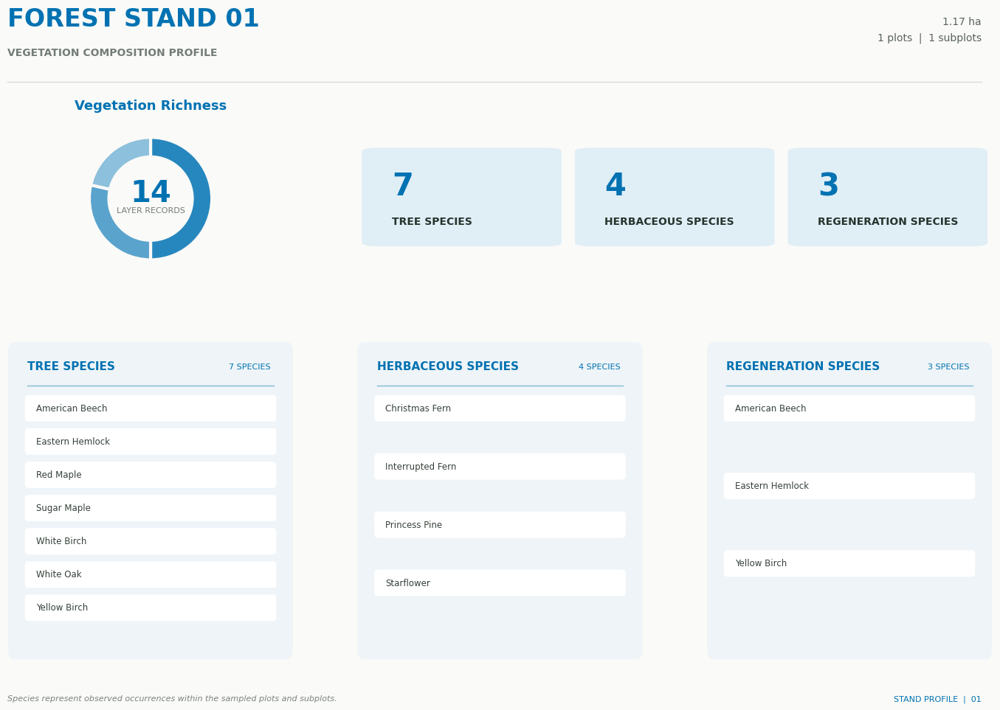

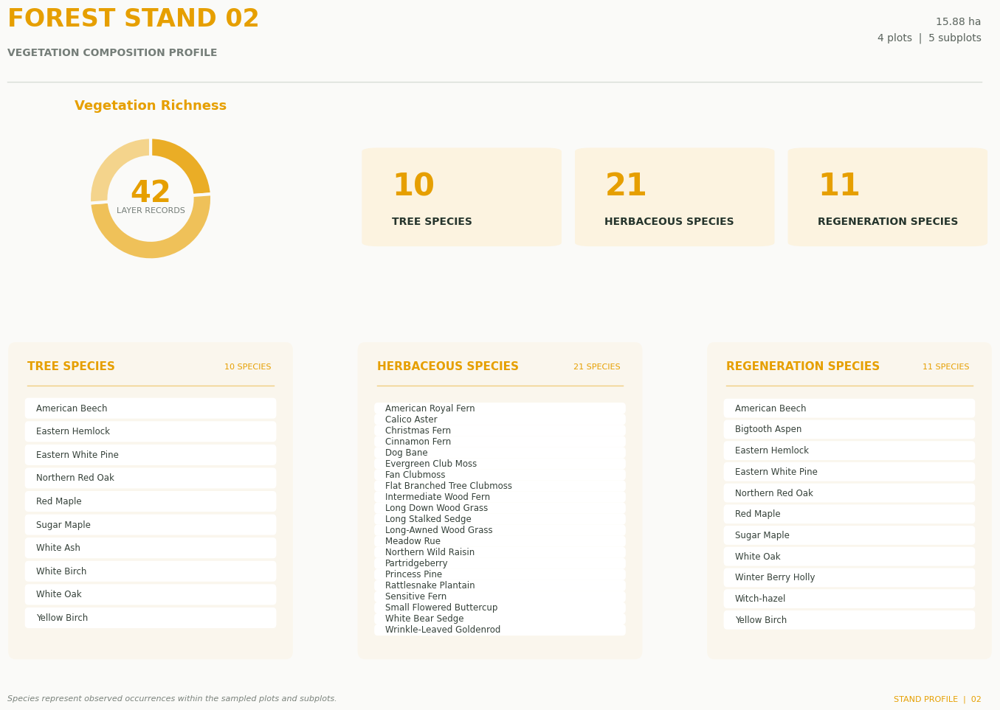

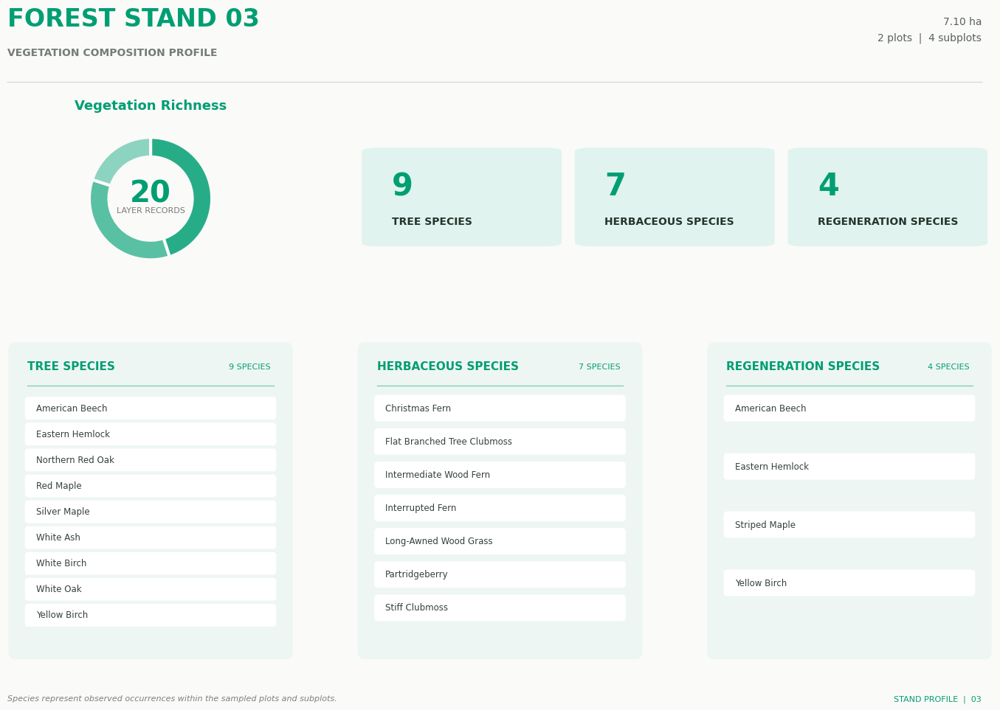

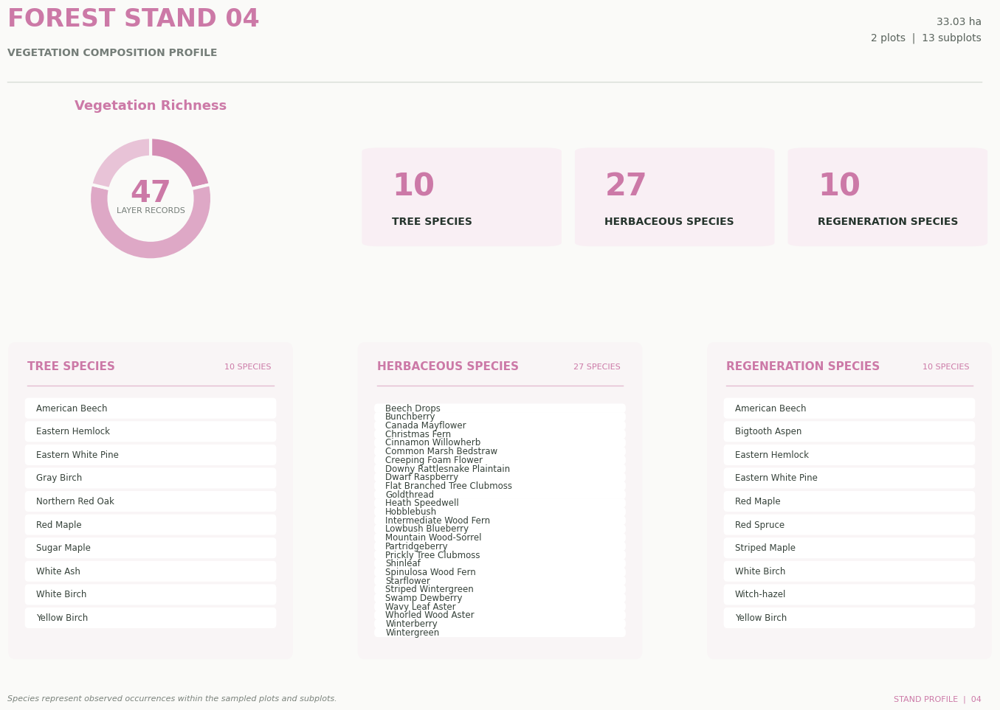

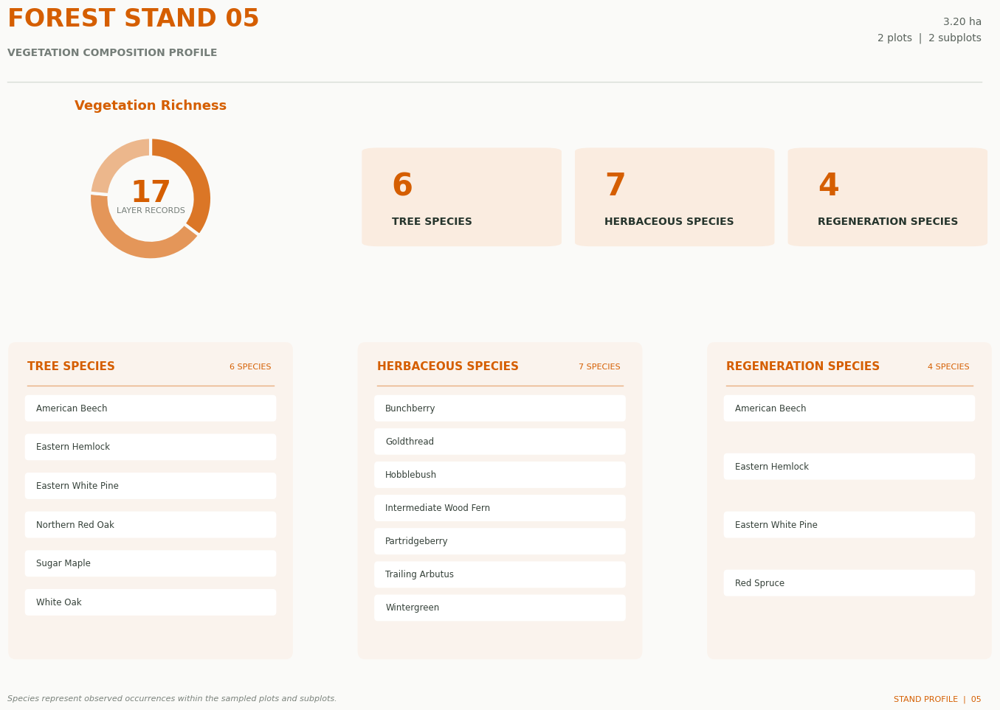

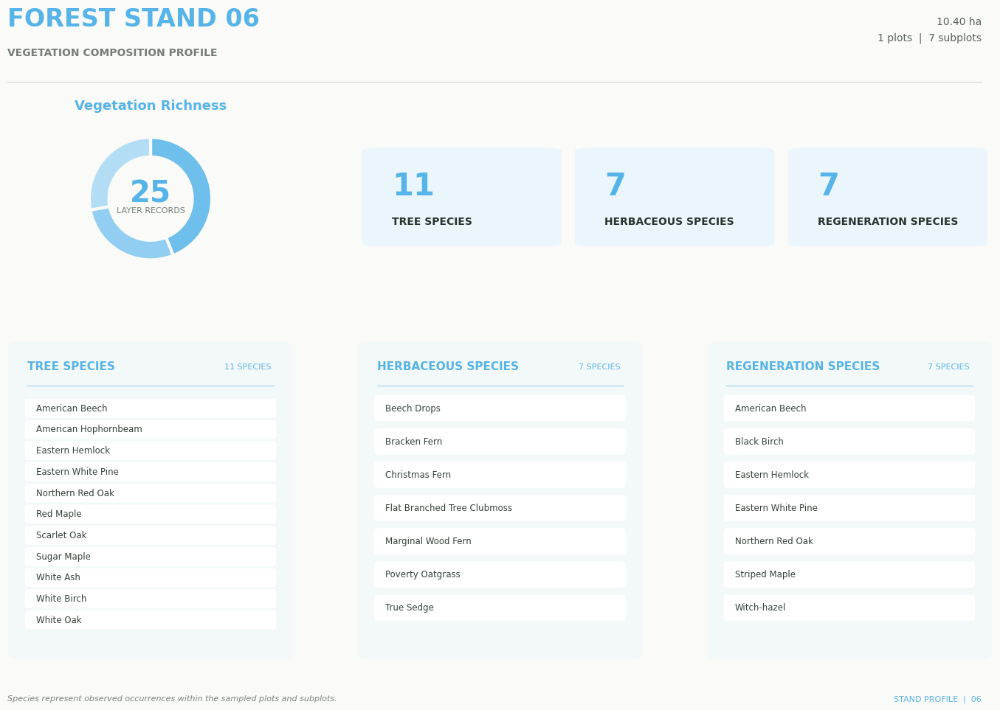

In [78]:
# STEP 68: CREATE PUBLICATION-STYLE STAND COMPOSITION DASHBOARDS
#
# Goal:
# Create six individual ecological composition profiles.
#
# Each profile includes:
# 1. A donut chart showing richness across the three vegetation layers.
# 2. Three richness cards with clearly readable labels.
# 3. Three species panels:
#       Tree Species
#       Herbaceous Species
#       Regeneration Species
# 4. Stand area and sampling effort.
#
# Each stand uses its established color from the original figures.
# Richness cards use pale backgrounds and dark text for readability.

# Import color conversion and rounded panel tools.
from matplotlib.colors import to_rgb
from matplotlib.patches import FancyBboxPatch

# ------------------------------------------------------------
# ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

# Use the same colors as the earlier publication figures.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Define the vegetation-layer order.
vegetation_layers = [
    'Tree',
    'Herbaceous',
    'Regeneration'
]

# Define the page background.
page_background = '#FAFAF8'

# Define the full vegetation-layer headings.
layer_headings = {
    'Tree': 'TREE SPECIES',
    'Herbaceous': 'HERBACEOUS SPECIES',
    'Regeneration': 'REGENERATION SPECIES'
}

# ------------------------------------------------------------
# HELPER FUNCTION: CREATE LIGHTER SHADES OF A STAND COLOR
# ------------------------------------------------------------

def create_color_shades(base_color):
    # Convert the original stand color into RGB values.
    rgb = to_rgb(base_color)

    # Blend the original color with white to create lighter shades.
    shades = []

    for blend in [0.15, 0.35, 0.55]:

        lighter_shade = tuple(
            channel * (1 - blend) + blend
            for channel in rgb
        )

        shades.append(lighter_shade)

    return shades


# ------------------------------------------------------------
# GENERATE THE SIX STAND PROFILES
# ------------------------------------------------------------

# Loop through each stand's composition profile.
for _, profile in stand_composition_profiles_df.iterrows():

    # Retrieve the current stand ID.
    stand = int(profile['Stand ID'])

    # Retrieve the established color for this stand.
    stand_color = stand_colors[stand]

    # Generate lighter shades for the donut chart.
    layer_shades = create_color_shades(stand_color)

    # Retrieve richness values for each vegetation layer.
    richness_values = [
        int(profile['Tree Richness']),
        int(profile['Herbaceous Richness']),
        int(profile['Regeneration Richness'])
    ]

    # Calculate the sum of layer-specific richness values.
    # Species recorded in multiple layers are counted once per layer.
    total_layer_richness = sum(richness_values)

    # Retrieve the species recorded in each vegetation layer.
    species_by_layer = {
        layer: profile[f'{layer} Species']
        for layer in vegetation_layers
    }

    # Retrieve stand area and sampling effort.
    stand_area = area_lookup.get(stand, np.nan)
    plot_count = plot_count_lookup.get(stand, 0)
    subplot_count = subplot_count_lookup.get(stand, 0)

    # --------------------------------------------------------
    # FIGURE AND PAGE LAYOUT
    # --------------------------------------------------------

    # Create a landscape-oriented report page.
    fig = plt.figure(
        figsize=(15, 10),
        facecolor=page_background
    )

    # Divide the page into an upper and lower section.
    gs = fig.add_gridspec(
        nrows=2,
        ncols=3,
        height_ratios=[1.2, 2.5],
        hspace=0.28,
        wspace=0.22,
        left=0.06,
        right=0.95,
        top=0.82,
        bottom=0.09
    )

    # --------------------------------------------------------
    # HEADER
    # --------------------------------------------------------

    # Display the stand identification.
    fig.text(
        0.06,
        0.95,
        f'FOREST STAND {stand:02d}',
        fontsize=24,
        fontweight='bold',
        color=stand_color
    )

    # Display the report subtitle.
    fig.text(
        0.06,
        0.91,
        'VEGETATION COMPOSITION PROFILE',
        fontsize=10,
        fontweight='bold',
        color='#747D78'
    )

    # Display stand area and sampling information.
    fig.text(
        0.94,
        0.945,
        (
            f'{stand_area:.2f} ha\n'
            f'{plot_count} plots  |  {subplot_count} subplots'
        ),
        ha='right',
        va='center',
        fontsize=10,
        color='#59635C',
        linespacing=1.7
    )

    # Add a thin horizontal divider below the header.
    fig.add_artist(
        plt.Line2D(
            [0.06, 0.94],
            [0.875, 0.875],
            transform=fig.transFigure,
            color='#D8DED7',
            linewidth=1
        )
    )

    # --------------------------------------------------------
    # VEGETATION RICHNESS DONUT CHART
    # --------------------------------------------------------

    # Create the donut chart panel.
    ax_donut = fig.add_subplot(gs[0, 0])

    # Draw the three richness categories using shades of the stand color.
    ax_donut.pie(
        richness_values,
        colors=layer_shades,
        startangle=90,
        counterclock=False,
        wedgeprops={
            'width': 0.32,
            'edgecolor': page_background,
            'linewidth': 3
        }
    )

    # Display combined layer richness in the center.
    ax_donut.text(
        0,
        0.08,
        str(total_layer_richness),
        ha='center',
        va='center',
        fontsize=29,
        fontweight='bold',
        color=stand_color
    )

    # Explain what the central number represents.
    ax_donut.text(
        0,
        -0.19,
        'LAYER RECORDS',
        ha='center',
        va='center',
        fontsize=8,
        color='#747D78'
    )

    # Add the donut chart title.
    ax_donut.set_title(
        'Vegetation Richness',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=12
    )

    ax_donut.set_aspect('equal')

    # --------------------------------------------------------
    # RICHNESS CARDS WITH IMPROVED TEXT CONTRAST
    # --------------------------------------------------------

    # Create the richness information panel.
    ax_metrics = fig.add_subplot(gs[0, 1:])

    # Hide the normal plotting axes.
    ax_metrics.axis('off')

    # Define the horizontal positions of the three cards.
    metric_positions = [0.02, 0.355, 0.69]

    # Define the width of each richness card.
    metric_width = 0.29

    # Create pale backgrounds based on the stand color.
    # This retains the stand identity without overpowering the text.
    card_background = tuple(
        channel * 0.12 + 0.88
        for channel in to_rgb(stand_color)
    )

    # Use a dark neutral color for the card labels.
    metric_text_color = '#26352D'

    # Create one richness card for each vegetation layer.
    for index, layer in enumerate(vegetation_layers):

        # Draw the rounded card background.
        card = FancyBboxPatch(
            (metric_positions[index], 0.20),
            metric_width,
            0.62,
            boxstyle='round,pad=0.012,rounding_size=0.025',
            transform=ax_metrics.transAxes,
            facecolor=card_background,
            edgecolor='none'
        )

        ax_metrics.add_patch(card)

        # Display the richness count in the stand's assigned color.
        ax_metrics.text(
            metric_positions[index] + 0.035,
            0.58,
            str(richness_values[index]),
            transform=ax_metrics.transAxes,
            fontsize=30,
            fontweight='bold',
            color=stand_color,
            va='center'
        )

        # Display the vegetation-layer name in dark text.
        ax_metrics.text(
            metric_positions[index] + 0.035,
            0.35,
            layer_headings[layer],
            transform=ax_metrics.transAxes,
            fontsize=10,
            fontweight='bold',
            color=metric_text_color,
            va='center'
        )

    # --------------------------------------------------------
    # SPECIES COMPOSITION PANELS
    # --------------------------------------------------------

    # Create one panel for each vegetation layer.
    for column, layer in enumerate(vegetation_layers):

        # Create the species panel.
        ax_species = fig.add_subplot(gs[1, column])

        # Hide the normal plotting axes.
        ax_species.axis('off')

        # Retrieve the species recorded in this layer.
        species_list = species_by_layer[layer]

        # Draw a pale panel background.
        panel = FancyBboxPatch(
            (0.015, 0.015),
            0.97,
            0.97,
            transform=ax_species.transAxes,
            boxstyle='round,pad=0.012,rounding_size=0.025',
            facecolor=card_background,
            edgecolor='none',
            alpha=0.45,
            zorder=0
        )

        ax_species.add_patch(panel)

        # Add the vegetation-layer heading.
        ax_species.text(
            0.07,
            0.92,
            layer_headings[layer],
            transform=ax_species.transAxes,
            fontsize=11,
            fontweight='bold',
            color=stand_color,
            va='center'
        )

        # Add the number of species recorded in this layer.
        ax_species.text(
            0.92,
            0.92,
            f'{len(species_list)} SPECIES',
            transform=ax_species.transAxes,
            fontsize=8,
            color=stand_color,
            ha='right',
            va='center'
        )

        # Add a subtle divider beneath the heading.
        ax_species.plot(
            [0.07, 0.93],
            [0.86, 0.86],
            transform=ax_species.transAxes,
            color=stand_color,
            alpha=0.45,
            linewidth=1
        )

        # Calculate the available vertical space for species labels.
        available_height = 0.73

        # Avoid dividing by zero if no species were recorded.
        species_count = max(len(species_list), 1)

        # Calculate the vertical spacing between species labels.
        vertical_spacing = available_height / species_count

        # Adjust label height according to the number of species.
        label_height = min(
            0.075,
            vertical_spacing * 0.78
        )

        # Display each species as a rounded white label.
        for species_index, species in enumerate(species_list):

            # Calculate the vertical position of this species.
            y_position = (
                0.79 - species_index * vertical_spacing
            )

            # Draw the rounded species-label background.
            label = FancyBboxPatch(
                (0.065, y_position - label_height / 2),
                0.87,
                label_height,
                transform=ax_species.transAxes,
                boxstyle='round,pad=0.004,rounding_size=0.012',
                facecolor='#FFFFFF',
                edgecolor='none',
                zorder=1
            )

            ax_species.add_patch(label)

            # Add the species name.
            ax_species.text(
                0.10,
                y_position,
                species,
                transform=ax_species.transAxes,
                fontsize=8.5,
                color='#354139',
                va='center',
                zorder=2
            )

    # --------------------------------------------------------
    # FOOTER
    # --------------------------------------------------------

    # Add a note explaining the species records.
    fig.text(
        0.06,
        0.035,
        'Species represent observed occurrences within the sampled plots and subplots.',
        fontsize=8,
        color='#7A827B',
        style='italic'
    )

    # Add the stand profile identifier.
    fig.text(
        0.94,
        0.035,
        f'STAND PROFILE  |  {stand:02d}',
        fontsize=8,
        color=stand_color,
        ha='right'
    )

    # --------------------------------------------------------
    # EXPORT
    # --------------------------------------------------------

    # Save the stand profile as a high-resolution PNG.
    plt.savefig(
        export_dir / f'Stand_{stand}_Composition_Dashboard.png',
        dpi=600,
        bbox_inches='tight',
        facecolor=fig.get_facecolor()
    )

    # Save a PDF version suitable for reports and printing.
    plt.savefig(
        export_dir / f'Stand_{stand}_Composition_Dashboard.pdf',
        bbox_inches='tight',
        facecolor=fig.get_facecolor()
    )

    # Display the completed stand profile.
    plt.show()

    # Close the figure before generating the next stand.
    plt.close(fig)

In [81]:
# Install pypdf, the Python library used to combine PDF documents.
!pip install pypdf

In [82]:
#Step 69

# Import PdfWriter from pypdf.
# PdfWriter allows us to combine multiple PDF files into one document.
from pypdf import PdfWriter

# Create a new PDF writer object.
# This will hold all six stand profiles in the order we add them.
report = PdfWriter()

# Loop through Stands 1–6 in numerical order.
for stand in range(1, 7):

    # Construct the expected filename for the current stand.
    # Example: Stand_1_Composition_Dashboard.pdf
    profile_file = export_dir / f"Stand_{stand}_Composition_Dashboard.pdf"

    # Check that the PDF exists before trying to add it.
    # If a file is missing, stop and identify which stand needs attention.
    if not profile_file.exists():
        raise FileNotFoundError(
            f"Missing PDF for Stand {stand}: {profile_file}"
        )

    # Append the current stand's PDF to the combined report.
    # Each stand profile will become one page in the final document.
    report.append(str(profile_file))

# Define the output path and filename for the combined report.
report_path = export_dir / "Forest_Stand_Vegetation_Composition_Report.pdf"

# Open the destination file in binary write mode.
# Write the combined PDF to this location.
with open(report_path, "wb") as output_file:
    report.write(output_file)

# Close the PDF writer after the report has been saved.
report.close()

# Reopen the completed PDF to verify that it contains six pages.
from pypdf import PdfReader

# Read the saved report.
completed_report = PdfReader(str(report_path))

# Print the output location and page count.
print(f"Report saved to: {report_path}")
print(f"Number of pages: {len(completed_report.pages)}")

Report saved to: /content/drive/MyDrive/ENV301/exports/Forest_Stand_Vegetation_Composition_Report.pdf
Number of pages: 6


In [ ]:
# Import pandas for organizing and summarizing the stand-level data.
import pandas as pd

# Select the richness columns and stand identifiers from the existing profiles.
# Each row represents one stand.
report_richness_summary = stand_composition_profiles_df[
    [
        'Stand ID',
        'Tree Richness',
        'Herbaceous Richness',
        'Regeneration Richness',
        'Combined Layer Richness'
    ]
].copy()

# Rename the columns to make the table easier to read in the report.
report_richness_summary = report_richness_summary.rename(columns={
    'Stand ID': 'Stand',
    'Tree Richness': 'Tree Species Richness',
    'Herbaceous Richness': 'Herbaceous Species Richness',
    'Regeneration Richness': 'Regeneration Species Richness',
    'Combined Layer Richness': 'Combined Layer Richness'
})

# Sort the table by stand number to ensure consistent ordering.
report_richness_summary = report_richness_summary.sort_values(
    'Stand'
).reset_index(drop=True)

# Display the completed summary table.
display(report_richness_summary)

In [83]:
# STEP 70: Inspect the woody vegetation dataset before beginning
# the DBH (diameter at breast height) analysis.

# Display all column names so we can identify the stand,
# species, plot, subplot, and DBH fields.
print("Woody vegetation columns:")
print(woody_analysis.columns.tolist())

# Display column data types to determine which measurements
# are already numeric and which may need conversion.
print("\nColumn data types:")
print(woody_analysis.dtypes)

# Display the first five observations to inspect the
# organization and structure of the dataset.
print("\nFirst five observations:")
display(woody_analysis.head())

Woody vegetation columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Tree ID', 'Species Code', 'Tree Status', 'DBH (in)', 'Estimated Tree Height (m)', 'Estimated Tree Height (ft)', 'Crown Class Code', 'Damage Type Code', 'Snag Decay Class (If Applicable)', 'Notes', 'Species Name']

Column data types:
Stand ID                              int64
Plot ID                               int64
Subplot ID                            int64
Date                                 object
Team Member(s)                       object
Tree ID                             float64
Species Code                         object
Tree Status                          object
DBH (in)                            float64
Estimated Tree Height (m)           float64
Estimated Tree Height (ft)          float64
Crown Class Code                     object
Damage Type Code                     object
Snag Decay Class (If Applicable)    float64
Notes                                object
Species Name    

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name
0,1,1,1,23-Oct,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.02,Dominant,NaN,NaN,NaN,Yellow Birch
1,1,1,1,23-Oct,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.81,Suppressed,NaN,NaN,NaN,Eastern Hemlock
2,1,1,1,23-Oct,"LW, AB, HB",3.0,AB,DA,13.52,13.5,44.29,Dominant,20,NaN,Base of trunk split,American Beech
3,1,1,1,23-Oct,"EC, HP, AB, LW",4.0,AB,DA,5.98,10.0,32.81,Codominant,20,NaN,Bark split,American Beech
4,1,1,1,23-Oct,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.04,Overtopped,NaN,NaN,NaN,Eastern Hemlock


In [84]:
# STEP 71: Standardize crown class terminology.

# Count how many records are currently labeled "Overtopped".
overtopped_before = (
    woody_analysis['Crown Class Code']
    .astype('string')
    .str.strip()
    .eq('Overtopped')
    .sum()
)

# Replace "Overtopped" with "Suppressed".
# This only changes the Crown Class Code column in woody_analysis.
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code']
    .replace('Overtopped', 'Suppressed')
)

# Display the number of replacements made.
print(f"Records changed: {overtopped_before}")

# Display the updated crown class categories and their counts.
print("\nUpdated crown class categories:")
display(
    woody_analysis['Crown Class Code']
    .value_counts(dropna=False)
    .rename_axis('Crown Class')
    .reset_index(name='Number of Observations')
)

Records changed: 1

Updated crown class categories:


,Crown Class,Number of Observations
0,Codominant,195
1,Intermediate,97
2,Suppressed,61
3,Dominant,56
4,Codominant,28
5,Dominant,14
6,NaN,7
7,Intermediate,5
8,Suppressed,3


In [85]:
# STEP 72: Remove inconsistent whitespace and standardize crown class labels.

# Convert the Crown Class Code column to pandas' string type.
# This preserves missing values rather than converting them to the text "nan".
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code'].astype('string')
)

# Remove leading and trailing spaces from every crown class entry.
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code'].str.strip()
)

# Replace any remaining "Overtopped" entries with "Suppressed".
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code'].replace(
        'Overtopped', 'Suppressed'
    )
)

# Display the cleaned crown class categories and their counts.
# Each category should now appear only once.
print("Cleaned crown class categories:")
display(
    woody_analysis['Crown Class Code']
    .value_counts(dropna=False)
    .rename_axis('Crown Class')
    .reset_index(name='Number of Observations')
)

# Confirm that no "Overtopped" entries remain.
print(
    "\nRemaining Overtopped entries:",
    woody_analysis['Crown Class Code'].eq('Overtopped').sum()
)

Cleaned crown class categories:


,Crown Class,Number of Observations
0,Codominant,223
1,Intermediate,102
2,Dominant,70
3,Suppressed,64
4,<NA>,7



Remaining Overtopped entries: 0


In [86]:
# STEP 73: Evaluate DBH completeness and tree status.

# Count the total number of woody vegetation observations.
print("Total woody vegetation observations:")
print(len(woody_analysis))

# Count observations with recorded DBH measurements.
print("\nRecords with DBH measurements:")
print(woody_analysis['DBH (in)'].notna().sum())

# Count observations without recorded DBH measurements.
print("\nRecords missing DBH measurements:")
print(woody_analysis['DBH (in)'].isna().sum())

# Summarize the tree status categories and their frequencies.
# This helps determine how many live and dead trees are represented.
print("\nTree status counts:")
display(
    woody_analysis['Tree Status']
    .value_counts(dropna=False)
    .rename_axis('Tree Status')
    .reset_index(name='Number of Observations')
)

# Calculate descriptive DBH statistics for each stand.
# These include sample size, mean, median, standard deviation,
# minimum, and maximum diameter in inches.
print("\nDBH summary by stand (inches):")
display(
    woody_analysis.groupby('Stand ID')['DBH (in)']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

Total woody vegetation observations:
466

Records with DBH measurements:
466

Records missing DBH measurements:
0

Tree status counts:


,Tree Status,Number of Observations
0,AL,354
1,DA,65
2,DE,37
3,DY,8
4,Al,2



DBH summary by stand (inches):


,count,mean,median,std,min,max
Stand ID,,,,,,
1,21,9.71,9.87,3.04,5.0,15.14
2,104,10.73,9.20,4.75,5.0,24.70
3,32,11.95,11.75,4.12,5.2,20.00
4,209,10.62,10.15,3.98,5.0,20.90
5,40,8.11,7.75,2.96,5.0,17.90
6,60,10.90,10.40,4.75,5.2,22.30


In [87]:
# STEP 74: Standardize capitalization in the Tree Status column.

# Convert tree status entries to pandas string format.
# This preserves missing values as missing.
woody_analysis['Tree Status'] = (
    woody_analysis['Tree Status'].astype('string')
)

# Remove leading and trailing whitespace from each entry.
woody_analysis['Tree Status'] = (
    woody_analysis['Tree Status'].str.strip()
)

# Convert all status codes to uppercase.
# This standardizes "Al" and "AL" into the same category.
woody_analysis['Tree Status'] = (
    woody_analysis['Tree Status'].str.upper()
)

# Display the standardized status codes and their counts.
print("Standardized tree status categories:")
display(
    woody_analysis['Tree Status']
    .value_counts(dropna=False)
    .rename_axis('Tree Status')
    .reset_index(name='Number of Observations')
)

# Display the number of unique non-missing status codes.
print(
    "\nNumber of unique tree status codes:",
    woody_analysis['Tree Status'].nunique()
)

Standardized tree status categories:


,Tree Status,Number of Observations
0,AL,356
1,DA,65
2,DE,37
3,DY,8



Number of unique tree status codes: 4


In [88]:
# STEP 75: Inspect the workbook for tree status definitions.

# Load the Excel workbook to identify its available worksheets.
# This allows us to locate the field key or data dictionary.
excel_file = pd.ExcelFile(workbook)

# Display all worksheet names in the workbook.
print("Available workbook worksheets:")
for sheet in excel_file.sheet_names:
    print(sheet)

Available workbook worksheets:
Plot Metadata
Plot Metadata Abb. Key
Subplot Metadata
Subplot Metadata Abb. Key
Subplot Woody Species Data
Woody Species Data Abb. Key
Subplot Woody Cover Data
Subplot Woody Cover Abb. Key
Subplot Herbaceous Species Data
Herbaceous Species Abb. Key
Subplot Hydrology and Surface
Hydrology and Surface Abb. Key
Subplot CWD Data
Subplot CWD Abb. Key
Subplot FWD Data
Subplot FWD Data Abb. Key
Microplot Data
Microplot Key


In [89]:
# STEP 76: Locate the definitions of the tree status codes.

# Read the abbreviation key from the original Excel workbook.
# This worksheet should contain the definitions for the woody field codes.
tree_status_key = pd.read_excel(
    workbook,
    sheet_name='Woody Species Data Abb. Key'
)

# Display the complete abbreviation key.
# We want to identify the definitions of AL, DA, DE, and DY.
display(tree_status_key)

,Hardwood Species,Common Name,Standard FIA Code,Code,Unnamed: 4,Crown Class,Definition,Code
0,Acer saccharum,Sugar Maple,ACSA,SM,NaN,Open Grown,Trees with crowns that receive full light abov...,1
1,Acer rubrum,Red Maple,ACRU,RM,NaN,Dominant,Trees with crowns extending above the general ...,2
2,Betula alleghaniensis,Yellow Birch,BEAL,YB,NaN,Co-Dominant,Trees with crowns forming the general level of...,3
3,Betula papyrifera,White Birch,BEPA,WB,NaN,Intermediate,"Trees shorter than dominants and co-dominants,...",4
4,Betula lenta,Black Birch,BELE,BB,NaN,Overtopped / Suppressed,Trees with crowns entirely below the general l...,5
5,Fagus grandifolia,American Beech,FAGR,AB,NaN,NaN,NaN,NaN
6,Quercus alba,White Oak,QUAL,WO,NaN,Damage,Code,NaN
7,Quercus rubra,Northern Red Oak,QURU,RO,NaN,Insect,10,NaN
8,Fraxinus americana,White Ash,FRAM,WA,NaN,Fungal / Disease,20,NaN
9,Populus grandidentata,Bigtooth Aspen,POGR,BTA,NaN,Fire,30,NaN


In [90]:
# STEP 77: Add readable tree status labels.
# The original Tree Status codes remain unchanged.

# Create a dictionary connecting each field code to its official definition.
tree_status_labels = {
    'AL': 'Alive',
    'DA': 'Damaged',
    'DY': 'Dying',
    'DE': 'Dead'
}

# Create a new column containing the readable status descriptions.
# The original Tree Status column is retained for traceability.
woody_analysis['Tree Status Label'] = (
    woody_analysis['Tree Status'].map(tree_status_labels)
)

# Summarize the readable status categories by observation count.
print("Tree status summary:")
display(
    woody_analysis['Tree Status Label']
    .value_counts(dropna=False)
    .rename_axis('Tree Status')
    .reset_index(name='Number of Observations')
)

Tree status summary:


,Tree Status,Number of Observations
0,Alive,356
1,Damaged,65
2,Dead,37
3,Dying,8


In [91]:
# STEP 78: Create a dataset containing living trees only.

# Filter the woody vegetation dataset to retain observations
# classified as Alive.
# Damaged, dying, and dead trees remain in woody_analysis.
live_trees_analysis = woody_analysis[
    woody_analysis['Tree Status Label'] == 'Alive'
].copy()

# Reset the row index after filtering.
live_trees_analysis = live_trees_analysis.reset_index(drop=True)

# Display the total number of living trees included in the analysis.
print("Total living tree observations:")
print(len(live_trees_analysis))

# Display the number of living trees recorded in each stand.
# This provides the sample size context for subsequent comparisons.
print("\nLiving tree observations by stand:")
display(
    live_trees_analysis.groupby('Stand ID')
    .size()
    .reset_index(name='Number of Living Trees')
)

# Display the first five records to verify the filtered dataset.
print("\nFirst five living tree observations:")
display(live_trees_analysis.head())

Total living tree observations:
356

Living tree observations by stand:


,Stand ID,Number of Living Trees
0,1,11
1,2,79
2,3,25
3,4,162
4,5,32
5,6,47



First five living tree observations:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name,Tree Status Label
0,1,1,1,23-Oct,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.02,Dominant,NaN,NaN,NaN,Yellow Birch,Alive
1,1,1,1,23-Oct,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.81,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
2,1,1,1,23-Oct,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.04,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
3,1,1,1,23-Oct,"JW, JR, JM, HP",7.0,EH,AL,10.80,12.0,39.37,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
4,1,1,1,23-Oct,"JW, JR, JM, HP, EC, AB, LA, LW",8.0,YB,AL,11.99,10.5,34.45,Codominant,NaN,NaN,NaN,Yellow Birch,Alive


In [92]:
# STEP 79: Calculate descriptive DBH statistics for living trees.

# Group living-tree observations by stand and calculate
# descriptive statistics for DBH, measured in inches.
live_dbh_summary = (
    live_trees_analysis
    .groupby('Stand ID')['DBH (in)']
    .agg(
        Sample_Size='count',
        Mean_DBH='mean',
        Median_DBH='median',
        Standard_Deviation='std',
        Minimum='min',
        First_Quartile=lambda x: x.quantile(0.25),
        Third_Quartile=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reset_index()
)

# Round the numerical results to two decimal places
# for easier interpretation and reporting.
live_dbh_summary = live_dbh_summary.round(2)

# Display the completed summary table.
display(live_dbh_summary)

,Stand ID,Sample_Size,Mean_DBH,Median_DBH,Standard_Deviation,Minimum,First_Quartile,Third_Quartile,Maximum
0,1,11,10.07,10.10,2.57,5.0,8.75,11.30,15.14
1,2,79,10.89,9.36,4.91,5.0,6.68,13.94,24.70
2,3,25,12.17,12.20,4.20,5.2,8.50,15.60,20.00
3,4,162,10.95,10.38,4.11,5.0,7.39,14.20,20.90
4,5,32,8.30,8.15,3.23,5.0,5.38,9.70,17.90
5,6,47,11.20,10.80,4.66,5.3,7.10,14.05,22.10


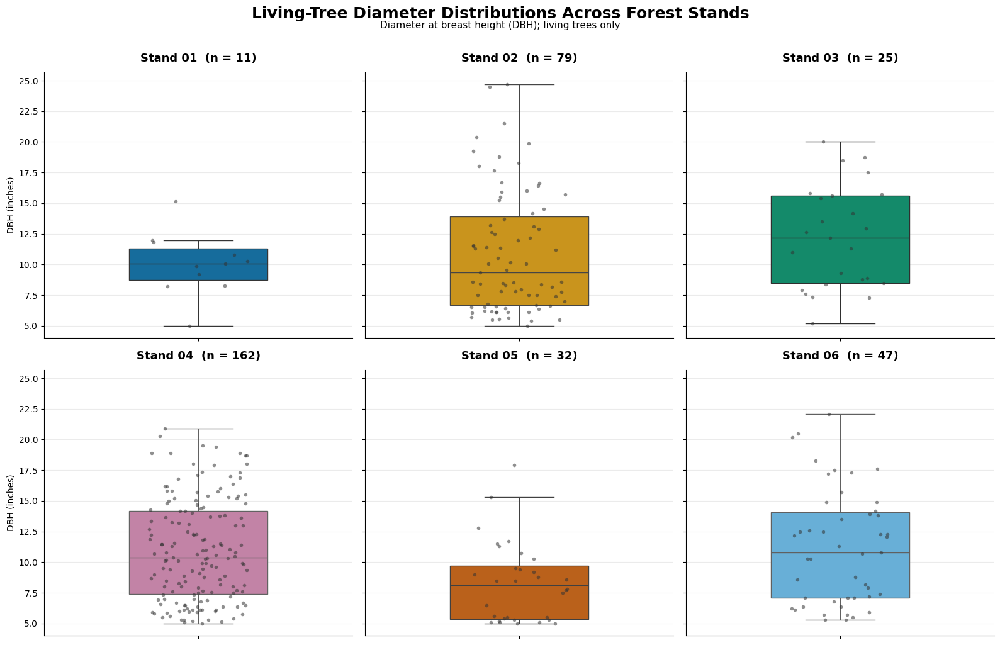

In [93]:
# STEP 80: Create a six-panel comparison of living-tree DBH distributions.

# Import the plotting libraries needed for the figure.
import matplotlib.pyplot as plt
import seaborn as sns

# Define the six-stand color palette used throughout the project.
stand_colors = {
    1: '#0072B2',  # Stand 1: Blue
    2: '#E69F00',  # Stand 2: Orange
    3: '#009E73',  # Stand 3: Bluish green
    4: '#CC79A7',  # Stand 4: Reddish purple
    5: '#D55E00',  # Stand 5: Vermillion
    6: '#56B4E9'   # Stand 6: Sky blue
}

# Create a figure with six panels arranged in two rows and three columns.
# Sharing the y-axis makes DBH distributions directly comparable.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 10),
    sharey=True
)

# Flatten the axes array so we can loop through the six panels.
axes = axes.flatten()

# Loop through each stand and its corresponding subplot.
for stand, ax in zip(range(1, 7), axes):

    # Filter the living-tree dataset to the current stand.
    stand_data = live_trees_analysis[
        live_trees_analysis['Stand ID'] == stand
    ]

    # Create a boxplot showing the median, quartiles, and distribution.
    sns.boxplot(
        data=stand_data,
        y='DBH (in)',
        color=stand_colors[stand],
        width=0.45,
        showfliers=False,
        ax=ax
    )

    # Overlay individual tree DBH measurements.
    # Jitter separates overlapping points so the distribution is visible.
    sns.stripplot(
        data=stand_data,
        y='DBH (in)',
        color='#333333',
        size=4,
        alpha=0.55,
        jitter=0.16,
        ax=ax
    )

    # Add the stand number and sample size to the panel title.
    ax.set_title(
        f'Stand {stand:02d}  (n = {len(stand_data)})',
        fontsize=13,
        fontweight='bold',
        pad=12
    )

    # Label the vertical axis in inches.
    ax.set_ylabel('DBH (inches)', fontsize=10)

    # Remove the unnecessary horizontal axis label.
    ax.set_xlabel('')

    # Use a subtle horizontal grid to make diameter values easier to read.
    ax.grid(axis='y', alpha=0.25)

    # Remove the upper and right plot borders for a cleaner appearance.
    sns.despine(ax=ax)

# Add an overall figure title.
fig.suptitle(
    'Living-Tree Diameter Distributions Across Forest Stands',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

# Add a brief subtitle describing the measurement and sample population.
fig.text(
    0.5,
    0.985,
    'Diameter at breast height (DBH); living trees only',
    ha='center',
    fontsize=11
)

# Adjust spacing so the panels and titles do not overlap.
plt.tight_layout()

# Save the figure in high-resolution PNG and publication-quality PDF formats.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Distributions.png',
    dpi=400,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Living_Tree_DBH_Distributions.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

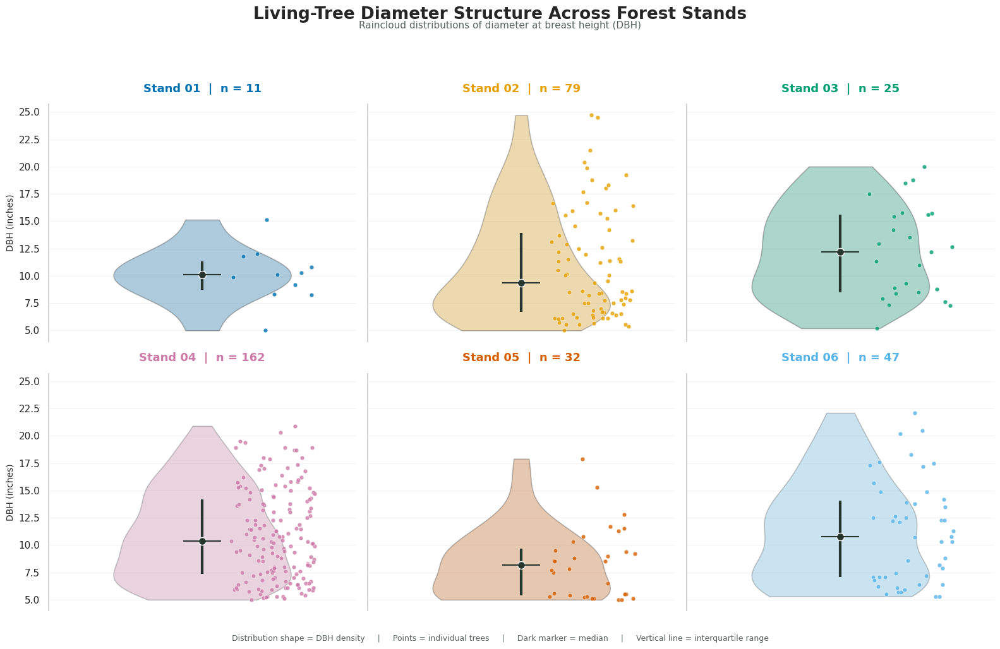

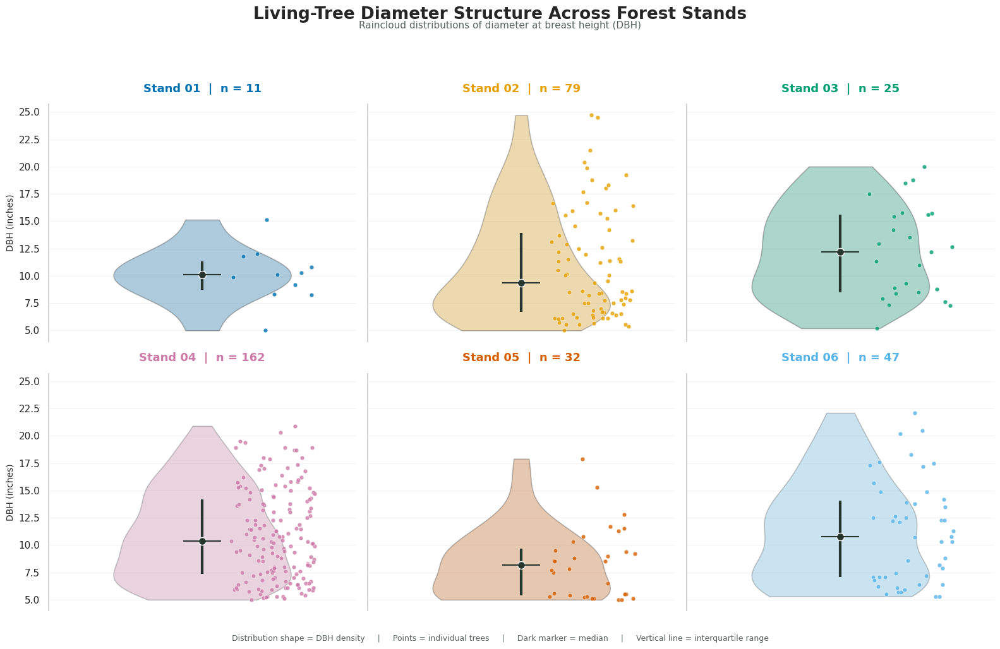

In [94]:
# STEP 81: Create publication-quality raincloud plots of living-tree DBH.
#
# Each panel combines:
# 1. A violin distribution showing the density of DBH measurements.
# 2. Individual observations showing the actual tree measurements.
# 3. A median marker showing the central DBH value.
# 4. An interquartile range line showing the middle 50% of observations.

# Import the plotting and numerical libraries.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Define the original six-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Set a consistent, publication-oriented plotting style.
sns.set_theme(
    style='whitegrid',
    context='notebook',
    font_scale=1.0
)

# Create a six-panel figure arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharey=True
)

# Flatten the axes array to simplify iteration.
axes = axes.flatten()

# Set a consistent horizontal position for the distribution in each panel.
distribution_position = 0

# Loop through the six stands.
for stand, ax in zip(range(1, 7), axes):

    # Extract the DBH measurements for the current stand.
    stand_data = live_trees_analysis.loc[
        live_trees_analysis['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    # Convert the DBH measurements to a numerical array.
    dbh_values = stand_data.to_numpy()

    # Retrieve the color assigned to the current stand.
    stand_color = stand_colors[stand]

    # Calculate the first quartile, median, and third quartile.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw a violin plot to show the distribution and density of DBH.
    # The violin is placed slightly to the left of the individual observations.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.2,
        width=0.75,
        ax=ax
    )

    # Make the violin partially transparent so the distribution
    # remains visually soft rather than overpowering the observations.
    for collection in ax.collections:
        collection.set_alpha(0.35)

    # Generate a reproducible random-number generator for point jitter.
    # Using a fixed seed makes the figure consistent when rerun.
    rng = np.random.default_rng(seed=stand)

    # Generate small horizontal offsets so overlapping observations
    # can be distinguished from one another.
    jitter = rng.uniform(
        0.12,
        0.48,
        size=len(dbh_values)
    )

    # Plot individual observations to the right of the violin.
    ax.scatter(
        distribution_position + jitter,
        dbh_values,
        s=24,
        color=stand_color,
        edgecolor='white',
        linewidth=0.45,
        alpha=0.8,
        zorder=3
    )

    # Draw a vertical line representing the interquartile range.
    ax.vlines(
        distribution_position,
        q1,
        q3,
        color='#26352D',
        linewidth=3,
        zorder=4
    )

    # Add a prominent marker at the median DBH.
    ax.scatter(
        distribution_position,
        median,
        s=75,
        color='#26352D',
        edgecolor='white',
        linewidth=1.0,
        zorder=5
    )

    # Add a horizontal reference line at the median.
    ax.hlines(
        median,
        -0.08,
        0.08,
        color='#26352D',
        linewidth=1.5,
        zorder=5
    )

    # Add the stand number and sample size to the panel title.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=14
    )

    # Remove the horizontal axis ticks and labels.
    ax.set_xticks([])

    # Label the vertical axis with the DBH measurement units.
    ax.set_ylabel('DBH (inches)', fontsize=10)

    # Set the horizontal limits to accommodate the violin and observations.
    ax.set_xlim(-0.65, 0.65)

    # Add subtle horizontal gridlines for easier comparison.
    ax.grid(
        axis='y',
        alpha=0.22,
        linewidth=0.8
    )

    # Remove unnecessary plot borders.
    sns.despine(ax=ax, bottom=True)

# Add the overall figure title.
fig.suptitle(
    'Living-Tree Diameter Structure Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=1.02
)

# Add a subtitle describing the visualization.
fig.text(
    0.5,
    0.985,
    'Raincloud distributions of diameter at breast height (DBH)',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add a legend explaining the visual elements.
fig.text(
    0.5,
    0.015,
    'Distribution shape = DBH density     '
    '|     Points = individual trees     '
    '|     Dark marker = median     '
    '|     Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust panel spacing to avoid overlapping titles and labels.
plt.tight_layout(rect=[0, 0.045, 1, 0.96])

# Save the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a vector PDF suitable for inclusion in the final report.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the completed visualization.
plt.show()# STEP 81: Create publication-quality raincloud plots of living-tree DBH.
#
# Each panel combines:
# 1. A violin distribution showing the density of DBH measurements.
# 2. Individual observations showing the actual tree measurements.
# 3. A median marker showing the central DBH value.
# 4. An interquartile range line showing the middle 50% of observations.

# Import the plotting and numerical libraries.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Define the original six-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Set a consistent, publication-oriented plotting style.
sns.set_theme(
    style='whitegrid',
    context='notebook',
    font_scale=1.0
)

# Create a six-panel figure arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharey=True
)

# Flatten the axes array to simplify iteration.
axes = axes.flatten()

# Set a consistent horizontal position for the distribution in each panel.
distribution_position = 0

# Loop through the six stands.
for stand, ax in zip(range(1, 7), axes):

    # Extract the DBH measurements for the current stand.
    stand_data = live_trees_analysis.loc[
        live_trees_analysis['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    # Convert the DBH measurements to a numerical array.
    dbh_values = stand_data.to_numpy()

    # Retrieve the color assigned to the current stand.
    stand_color = stand_colors[stand]

    # Calculate the first quartile, median, and third quartile.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw a violin plot to show the distribution and density of DBH.
    # The violin is placed slightly to the left of the individual observations.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.2,
        width=0.75,
        ax=ax
    )

    # Make the violin partially transparent so the distribution
    # remains visually soft rather than overpowering the observations.
    for collection in ax.collections:
        collection.set_alpha(0.35)

    # Generate a reproducible random-number generator for point jitter.
    # Using a fixed seed makes the figure consistent when rerun.
    rng = np.random.default_rng(seed=stand)

    # Generate small horizontal offsets so overlapping observations
    # can be distinguished from one another.
    jitter = rng.uniform(
        0.12,
        0.48,
        size=len(dbh_values)
    )

    # Plot individual observations to the right of the violin.
    ax.scatter(
        distribution_position + jitter,
        dbh_values,
        s=24,
        color=stand_color,
        edgecolor='white',
        linewidth=0.45,
        alpha=0.8,
        zorder=3
    )

    # Draw a vertical line representing the interquartile range.
    ax.vlines(
        distribution_position,
        q1,
        q3,
        color='#26352D',
        linewidth=3,
        zorder=4
    )

    # Add a prominent marker at the median DBH.
    ax.scatter(
        distribution_position,
        median,
        s=75,
        color='#26352D',
        edgecolor='white',
        linewidth=1.0,
        zorder=5
    )

    # Add a horizontal reference line at the median.
    ax.hlines(
        median,
        -0.08,
        0.08,
        color='#26352D',
        linewidth=1.5,
        zorder=5
    )

    # Add the stand number and sample size to the panel title.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=14
    )

    # Remove the horizontal axis ticks and labels.
    ax.set_xticks([])

    # Label the vertical axis with the DBH measurement units.
    ax.set_ylabel('DBH (inches)', fontsize=10)

    # Set the horizontal limits to accommodate the violin and observations.
    ax.set_xlim(-0.65, 0.65)

    # Add subtle horizontal gridlines for easier comparison.
    ax.grid(
        axis='y',
        alpha=0.22,
        linewidth=0.8
    )

    # Remove unnecessary plot borders.
    sns.despine(ax=ax, bottom=True)

# Add the overall figure title.
fig.suptitle(
    'Living-Tree Diameter Structure Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=1.02
)

# Add a subtitle describing the visualization.
fig.text(
    0.5,
    0.985,
    'Raincloud distributions of diameter at breast height (DBH)',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add a legend explaining the visual elements.
fig.text(
    0.5,
    0.015,
    'Distribution shape = DBH density     '
    '|     Points = individual trees     '
    '|     Dark marker = median     '
    '|     Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust panel spacing to avoid overlapping titles and labels.
plt.tight_layout(rect=[0, 0.045, 1, 0.96])

# Save the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a vector PDF suitable for inclusion in the final report.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the completed visualization.
plt.show()

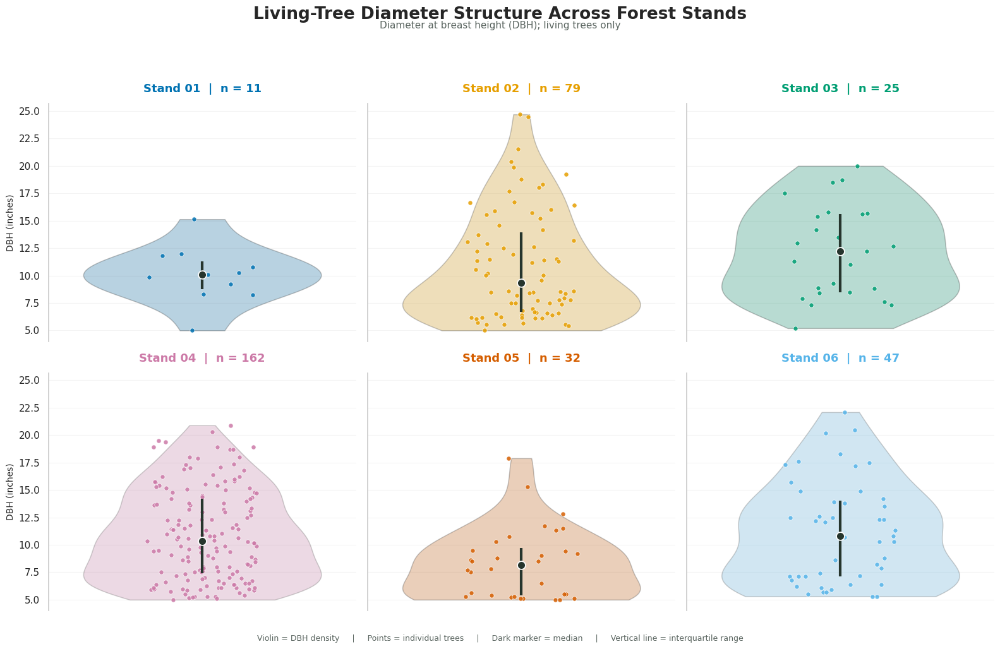

In [95]:
# STEP 82: Create raincloud-style DBH distributions with observations
# positioned inside their respective violin distributions.

# Import plotting and numerical libraries.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Retain the original six-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Apply a clean plotting style.
sns.set_theme(style='whitegrid', context='notebook')

# Create six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharey=True
)

# Flatten the axes array for convenient iteration.
axes = axes.flatten()

# Loop through each stand.
for stand, ax in zip(range(1, 7), axes):

    # Extract the living-tree DBH observations for this stand.
    stand_data = live_trees_analysis.loc[
        live_trees_analysis['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    # Convert the DBH observations into a numerical array.
    dbh_values = stand_data.to_numpy()

    # Retrieve the corresponding stand color.
    stand_color = stand_colors[stand]

    # Calculate the first quartile, median, and third quartile.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw the violin distribution centered at horizontal position zero.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make the violin slightly transparent so the individual
    # observations remain easy to distinguish.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate reproducible horizontal jitter.
    # The points will now be placed within the violin rather than outside it.
    rng = np.random.default_rng(seed=stand)

    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(dbh_values)
    )

    # Plot individual tree measurements inside the violin.
    ax.scatter(
        jitter,
        dbh_values,
        s=27,
        color=stand_color,
        edgecolor='white',
        linewidth=0.55,
        alpha=0.85,
        zorder=4
    )

    # Draw a vertical line representing the interquartile range.
    ax.vlines(
        0,
        q1,
        q3,
        color='#26352D',
        linewidth=3,
        zorder=5
    )

    # Mark the median DBH with a contrasting central point.
    ax.scatter(
        0,
        median,
        s=85,
        color='#26352D',
        edgecolor='white',
        linewidth=1.2,
        zorder=6
    )

    # Add the stand identifier and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=13
    )

    # Label the vertical axis with DBH units.
    ax.set_ylabel('DBH (inches)', fontsize=10)

    # Remove unnecessary horizontal axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlim(-0.55, 0.55)

    # Add subtle horizontal gridlines.
    ax.grid(
        axis='y',
        alpha=0.20,
        linewidth=0.8
    )

    # Remove unnecessary plot borders.
    sns.despine(ax=ax, bottom=True)

# Add the overall figure title.
fig.suptitle(
    'Living-Tree Diameter Structure Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=1.02
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.985,
    'Diameter at breast height (DBH); living trees only',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add a legend explaining the visual elements.
fig.text(
    0.5,
    0.015,
    'Violin = DBH density     |     '
    'Points = individual trees     |     '
    'Dark marker = median     |     '
    'Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust spacing to prevent overlapping elements.
plt.tight_layout(rect=[0, 0.045, 1, 0.96])

# Export the updated figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=400,
    bbox_inches='tight'
)

# Export a PDF version for the final report.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the updated figure.
plt.show()

In [96]:
# STEP 83: Calculate crown class composition among living trees.

# Create a working copy of the living-tree dataset.
# This preserves the existing live_trees_analysis DataFrame.
crown_analysis = live_trees_analysis.copy()

# Remove observations without a recorded crown class.
# Missing crown classes should not be treated as a fifth canopy category.
crown_analysis = crown_analysis.dropna(
    subset=['Crown Class Code']
).copy()

# Count observations in each crown class within each stand.
crown_counts = pd.crosstab(
    crown_analysis['Stand ID'],
    crown_analysis['Crown Class Code']
)

# Convert the counts into percentages within each stand.
# Each stand's crown class percentages will sum to 100%.
crown_percentages = (
    crown_counts
    .div(crown_counts.sum(axis=1), axis=0)
    * 100
)

# Display the number of trees in each crown class.
print("Crown class counts by stand:")
display(crown_counts)

# Display the percentage composition of crown classes.
print("\nCrown class composition by stand (%):")
display(crown_percentages.round(1))

Crown class counts by stand:


Crown Class Code,Codominant,Dominant,Intermediate,Suppressed
Stand ID,,,,
1,3,3,1,4
2,45,17,10,7
3,15,3,3,0
4,84,22,38,18
5,13,4,7,8
6,18,7,21,1



Crown class composition by stand (%):


Crown Class Code,Codominant,Dominant,Intermediate,Suppressed
Stand ID,,,,
1,27.3,27.3,9.1,36.4
2,57.0,21.5,12.7,8.9
3,71.4,14.3,14.3,0.0
4,51.9,13.6,23.5,11.1
5,40.6,12.5,21.9,25.0
6,38.3,14.9,44.7,2.1


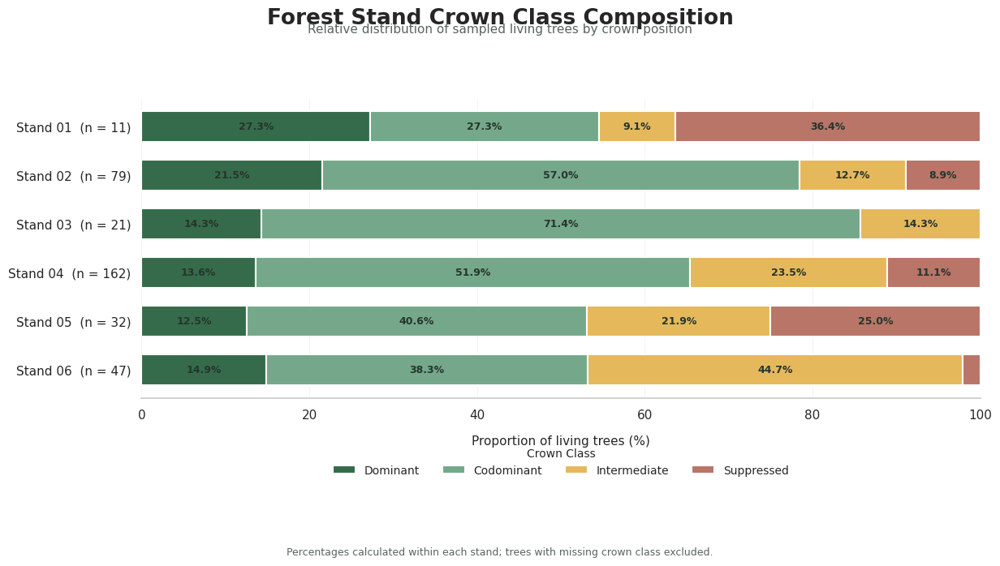

In [97]:
# STEP 84: Create a publication-quality crown class composition figure.

# Import matplotlib for figure construction.
import matplotlib.pyplot as plt
import numpy as np

# Define a consistent color for each crown class.
# These colors distinguish canopy positions rather than individual stands.
crown_colors = {
    'Dominant': '#356B4A',
    'Codominant': '#75A88A',
    'Intermediate': '#E6B85C',
    'Suppressed': '#B87568'
}

# Define the order in which crown classes will appear in the figure.
# This places the upper canopy classes first, followed by lower classes.
crown_order = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Reorder the percentage table to match the desired visual order.
crown_plot_data = crown_percentages[crown_order].copy()

# Calculate the number of trees with recorded crown classes in each stand.
# These sample sizes will be displayed beside the stand labels.
crown_sample_sizes = crown_counts.sum(axis=1)

# Create a horizontal figure with one bar for each stand.
fig, ax = plt.subplots(figsize=(13, 7))

# Define the vertical positions for the six stand bars.
y_positions = np.arange(len(crown_plot_data))

# Initialize the left position of each stacked bar at zero.
left_positions = np.zeros(len(crown_plot_data))

# Draw each crown class as a segment of the 100% stacked bars.
for crown_class in crown_order:

    # Retrieve the percentage values for the current crown class.
    values = crown_plot_data[crown_class].to_numpy()

    # Draw the current crown class segment.
    ax.barh(
        y_positions,
        values,
        left=left_positions,
        color=crown_colors[crown_class],
        edgecolor='white',
        linewidth=1.5,
        height=0.62,
        label=crown_class
    )

    # Add percentage labels inside segments when there is enough room.
    for i, value in enumerate(values):

        # Avoid placing labels in very small segments.
        if value >= 7:

            # Position the percentage label in the center of its segment.
            ax.text(
                left_positions[i] + value / 2,
                y_positions[i],
                f'{value:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                fontweight='bold',
                color='#26352D'
            )

    # Update the left positions for the next stacked segment.
    left_positions += values

# Add stand labels and their corresponding sample sizes.
stand_labels = [
    f'Stand {stand:02d}  (n = {crown_sample_sizes.loc[stand]})'
    for stand in crown_plot_data.index
]

ax.set_yticks(y_positions)
ax.set_yticklabels(stand_labels, fontsize=11)

# Reverse the vertical axis so Stand 01 appears at the top.
ax.invert_yaxis()

# Set the horizontal axis to span the full percentage range.
ax.set_xlim(0, 100)

# Label the horizontal axis.
ax.set_xlabel(
    'Proportion of living trees (%)',
    fontsize=11,
    labelpad=12
)

# Add the figure title and subtitle.
fig.suptitle(
    'Forest Stand Crown Class Composition',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

fig.text(
    0.5,
    0.935,
    'Relative distribution of sampled living trees by crown position',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add subtle vertical gridlines for percentage comparisons.
ax.set_axisbelow(True)
ax.grid(
    axis='x',
    alpha=0.20,
    linewidth=0.8
)

# Remove unnecessary plot borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# Place the legend below the chart.
ax.legend(
    title='Crown Class',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.13),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=10
)

# Add a methodological note below the visualization.
fig.text(
    0.5,
    0.015,
    'Percentages calculated within each stand; trees with missing crown class excluded.',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust spacing to accommodate the title, legend, and footer.
plt.tight_layout(rect=[0.02, 0.09, 0.98, 0.91])

# Export the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Crown_Class_Composition.png',
    dpi=400,
    bbox_inches='tight'
)

# Export a PDF version for the final report.
fig.savefig(
    export_dir / 'Crown_Class_Composition.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

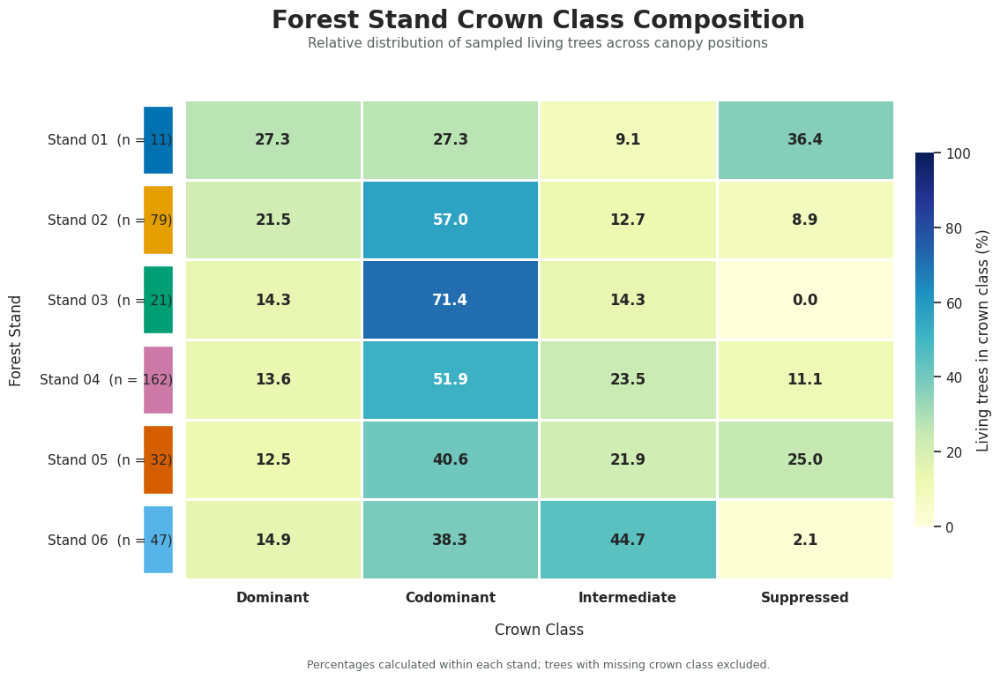

In [98]:
# STEP 85: Create a publication-quality crown class composition heatmap.

# Import the libraries needed to construct the heatmap.
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np

# Retain the original six-stand color palette used throughout the project.
stand_colors = {
    1: '#0072B2',  # Stand 1: Blue
    2: '#E69F00',  # Stand 2: Orange
    3: '#009E73',  # Stand 3: Bluish green
    4: '#CC79A7',  # Stand 4: Reddish purple
    5: '#D55E00',  # Stand 5: Vermillion
    6: '#56B4E9'   # Stand 6: Sky blue
}

# Define the order of crown classes in the figure.
# This follows the same upper-to-lower canopy organization
# used in the previous crown class visualization.
crown_order = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Arrange the percentage data in the desired stand and crown class order.
heatmap_data = crown_percentages.loc[
    [1, 2, 3, 4, 5, 6],
    crown_order
].copy()

# Calculate the number of living trees with recorded crown classes.
# This ensures the sample sizes correspond to the displayed percentages.
crown_sample_sizes = crown_counts.sum(axis=1)

# Create descriptive stand labels that include the relevant sample sizes.
stand_labels = [
    f'Stand {stand:02d}  (n = {crown_sample_sizes.loc[stand]})'
    for stand in heatmap_data.index
]

# Create a figure with two aligned sections:
# a narrow stand-color strip on the left and the main heatmap on the right.
fig = plt.figure(figsize=(14, 8))

# Define the relative widths of the color strip and heatmap.
# The heatmap receives most of the available figure width.
gs = gridspec.GridSpec(
    1,
    2,
    width_ratios=[0.035, 1],
    wspace=0.025
)

# Create the narrow color-strip axis.
color_ax = fig.add_subplot(gs[0])

# Create the main heatmap axis.
heat_ax = fig.add_subplot(gs[1])

# Draw one colored rectangle for each stand.
# Each rectangle uses the established stand-specific color.
for position, stand in enumerate(heatmap_data.index):

    color_ax.barh(
        position,
        1,
        color=stand_colors[stand],
        height=0.85
    )

# Configure the color strip to align with the six heatmap rows.
color_ax.set_ylim(len(heatmap_data) - 0.5, -0.5)
color_ax.set_xlim(0, 1)
color_ax.axis('off')

# Create the heatmap using a sequential color scale.
# Darker cells indicate higher percentages within the displayed data.
sns.heatmap(
    heatmap_data,
    ax=heat_ax,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    vmin=0,
    vmax=100,
    linewidths=2,
    linecolor='white',
    cbar_kws={
        'label': 'Living trees in crown class (%)',
        'shrink': 0.78,
        'pad': 0.025
    },
    annot_kws={
        'fontsize': 12,
        'fontweight': 'bold'
    }
)

# Apply descriptive stand labels to the vertical axis.
heat_ax.set_yticklabels(
    stand_labels,
    rotation=0,
    fontsize=11
)

# Apply descriptive crown class labels to the horizontal axis.
heat_ax.set_xticklabels(
    crown_order,
    rotation=0,
    fontsize=11,
    fontweight='bold'
)

# Label the horizontal axis.
heat_ax.set_xlabel(
    'Crown Class',
    fontsize=12,
    labelpad=14
)

# Label the vertical axis.
heat_ax.set_ylabel(
    'Forest Stand',
    fontsize=12,
    labelpad=12
)

# Add a clear report-quality title.
fig.suptitle(
    'Forest Stand Crown Class Composition',
    fontsize=20,
    fontweight='bold',
    y=0.97
)

# Add a subtitle explaining what the percentages represent.
fig.text(
    0.5,
    0.915,
    'Relative distribution of sampled living trees across canopy positions',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add a methodological note beneath the figure.
fig.text(
    0.5,
    0.035,
    'Percentages calculated within each stand; trees with missing crown class excluded.',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust the layout to provide sufficient space for the title,
# axis labels, color scale, and methodological note.
fig.subplots_adjust(
    left=0.18,
    right=0.91,
    top=0.84,
    bottom=0.16
)

# Save the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Heatmap.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a PDF version for the final ecological report.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Heatmap.pdf',
    bbox_inches='tight'
)

# Display the completed heatmap.
plt.show()

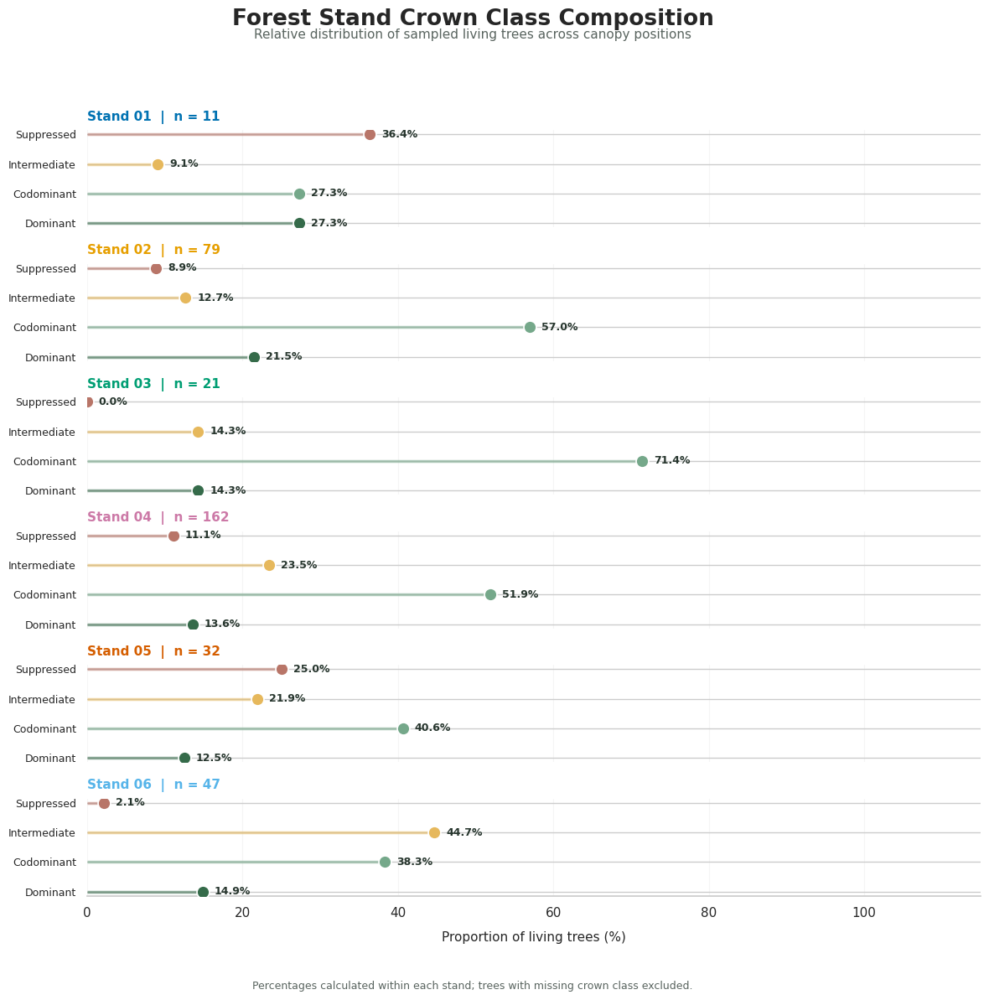

In [99]:
# STEP 86: Create a faceted lollipop plot of crown class composition.

# Import plotting and numerical libraries.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Retain the original six-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Assign a consistent color to each crown class.
# These colors will remain the same across all six stand panels.
crown_colors = {
    'Dominant': '#356B4A',
    'Codominant': '#75A88A',
    'Intermediate': '#E6B85C',
    'Suppressed': '#B87568'
}

# Define the crown class order.
crown_order = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Create a figure with six horizontal panels.
# Each row represents one stand.
fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(13, 12),
    sharex=True
)

# Loop through the six stands and their corresponding panels.
for stand, ax in zip(range(1, 7), axes):

    # Retrieve the crown class percentages for the current stand.
    stand_percentages = crown_percentages.loc[stand, crown_order]

    # Retrieve the sample size for the current stand.
    sample_size = int(crown_sample_sizes.loc[stand])

    # Draw a horizontal reference line for each crown class.
    # The line extends from zero to the observed percentage.
    for position, crown_class in enumerate(crown_order):

        # Retrieve the percentage for the current crown class.
        value = stand_percentages[crown_class]

        # Draw a thin line from zero to the percentage value.
        ax.hlines(
            y=position,
            xmin=0,
            xmax=value,
            color=crown_colors[crown_class],
            linewidth=2.5,
            alpha=0.55
        )

        # Draw a prominent circular marker at the percentage value.
        ax.scatter(
            value,
            position,
            s=115,
            color=crown_colors[crown_class],
            edgecolor='white',
            linewidth=1.2,
            zorder=3
        )

        # Display the percentage beside the marker.
        # Position the label to the right of the marker.
        ax.text(
            value + 1.5,
            position,
            f'{value:.1f}%',
            va='center',
            fontsize=9,
            fontweight='bold',
            color='#26352D'
        )

    # Add a stand-specific colored accent beside the panel title.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {sample_size}',
        loc='left',
        fontsize=11,
        fontweight='bold',
        color=stand_colors[stand],
        pad=8
    )

    # Apply the crown class labels to the vertical axis.
    ax.set_yticks(range(len(crown_order)))
    ax.set_yticklabels(crown_order, fontsize=9)

    # Set the horizontal axis limits.
    # The extra space allows percentage labels to remain visible.
    ax.set_xlim(0, 115)

    # Add subtle vertical gridlines for percentage comparisons.
    ax.grid(
        axis='x',
        alpha=0.18,
        linewidth=0.8
    )

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Remove the bottom border from all panels except the last.
    if stand != 6:
        ax.spines['bottom'].set_visible(False)
        ax.tick_params(axis='x', bottom=False, labelbottom=False)

# Label the horizontal axis on the final panel.
axes[-1].set_xlabel(
    'Proportion of living trees (%)',
    fontsize=11,
    labelpad=10
)

# Add the overall figure title.
fig.suptitle(
    'Forest Stand Crown Class Composition',
    fontsize=19,
    fontweight='bold',
    y=0.99
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.96,
    'Relative distribution of sampled living trees across canopy positions',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add a methodological note below the figure.
fig.text(
    0.5,
    0.015,
    'Percentages calculated within each stand; trees with missing crown class excluded.',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust the layout to accommodate the title and footer.
plt.tight_layout(rect=[0.06, 0.045, 0.98, 0.94])

# Save the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Lollipop.png',
    dpi=400,
    bbox_inches='tight'
)

# Save the figure as a PDF for the final report.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Lollipop.pdf',
    bbox_inches='tight'
)

# Display the completed visualization.
plt.show()

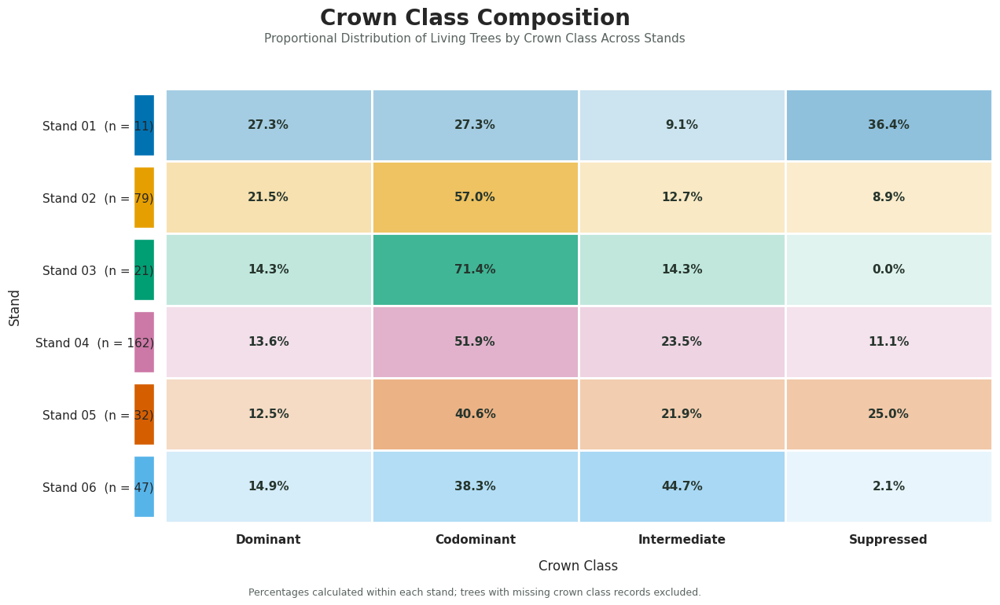

In [103]:
# STEP 87: Create a publication-quality crown class composition heatmap.

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

# Import matplotlib for figure construction.
import matplotlib.pyplot as plt

# Import color utilities for creating stand-specific gradients.
import matplotlib.colors as mcolors

# Import numpy for positioning heatmap cells.
import numpy as np


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

# Preserve the colors established in the earlier project figures.
stand_colors = {
    1: '#0072B2',  # Stand 1: Blue
    2: '#E69F00',  # Stand 2: Orange
    3: '#009E73',  # Stand 3: Bluish green
    4: '#CC79A7',  # Stand 4: Reddish purple
    5: '#D55E00',  # Stand 5: Vermillion
    6: '#56B4E9'   # Stand 6: Sky blue
}


# ------------------------------------------------------------
# 3. ORGANIZE THE CROWN CLASS DATA
# ------------------------------------------------------------

# Establish a consistent order for the four crown classes.
crown_order = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Arrange the percentage data by stand and crown class.
heatmap_data = crown_percentages.loc[
    [1, 2, 3, 4, 5, 6],
    crown_order
].copy()

# Retrieve the number of observations used in each stand's
# crown class percentage calculations.
crown_sample_sizes = crown_counts.sum(axis=1)


# ------------------------------------------------------------
# 4. CREATE THE FIGURE LAYOUT
# ------------------------------------------------------------

# Create the overall figure.
fig = plt.figure(figsize=(14, 8))

# Divide the figure into two sections:
# a narrow stand-color strip and the main heatmap.
gs = fig.add_gridspec(
    1,
    2,
    width_ratios=[0.025, 1],
    wspace=0.025
)

# Create the stand-color identification axis.
color_ax = fig.add_subplot(gs[0])

# Create the main heatmap axis.
heat_ax = fig.add_subplot(gs[1])


# ------------------------------------------------------------
# 5. DRAW THE STAND COLOR IDENTIFICATION STRIP
# ------------------------------------------------------------

# Draw one colored rectangle for each stand.
for position, stand in enumerate(heatmap_data.index):

    color_ax.barh(
        position,
        1,
        color=stand_colors[stand],
        height=0.85
    )

# Align the color strip with the six heatmap rows.
color_ax.set_ylim(
    len(heatmap_data) - 0.5,
    -0.5
)

# Set the horizontal boundaries of the color strip.
color_ax.set_xlim(0, 1)

# Remove unnecessary axis elements.
color_ax.axis('off')


# ------------------------------------------------------------
# 6. CREATE THE STAND-SPECIFIC HEATMAP CELLS
# ------------------------------------------------------------

# Loop through each stand to create its individual color gradient.
for position, stand in enumerate(heatmap_data.index):

    # Convert the original stand color into RGB values.
    base_color = mcolors.to_rgb(stand_colors[stand])

    # Create a pale background shade of the stand color.
    pale_color = tuple(
        channel * 0.12 + 0.88
        for channel in base_color
    )

    # Create a gradient from the pale shade to the original color.
    stand_cmap = mcolors.LinearSegmentedColormap.from_list(
        f'stand_{stand}_gradient',
        [pale_color, stand_colors[stand]]
    )

    # Loop through the four crown classes.
    for column_position, crown_class in enumerate(crown_order):

        # Retrieve the percentage for the current stand and crown class.
        value = heatmap_data.loc[stand, crown_class]

        # Normalize the percentage to determine color intensity.
        intensity = value / 100

        # Retrieve the corresponding shade from the stand gradient.
        cell_color = stand_cmap(intensity)

        # Draw the heatmap cell.
        heat_ax.add_patch(
            plt.Rectangle(
                (column_position, position),
                1,
                1,
                facecolor=cell_color,
                edgecolor='white',
                linewidth=2
            )
        )

        # Calculate cell brightness to determine text contrast.
        luminance = (
            0.2126 * cell_color[0]
            + 0.7152 * cell_color[1]
            + 0.0722 * cell_color[2]
        )

        # Use white text on darker cells and dark text on lighter cells.
        text_color = (
            'white'
            if luminance < 0.58
            else '#26352D'
        )

        # Display the exact percentage in the center of the cell.
        heat_ax.text(
            column_position + 0.5,
            position + 0.5,
            f'{value:.1f}%',
            ha='center',
            va='center',
            fontsize=11,
            fontweight='bold',
            color=text_color
        )


# ------------------------------------------------------------
# 7. FORMAT THE HEATMAP AXES
# ------------------------------------------------------------

# Set the horizontal boundaries to include all four crown classes.
heat_ax.set_xlim(0, len(crown_order))

# Set the vertical boundaries to include all six stands.
heat_ax.set_ylim(len(heatmap_data), 0)

# Position crown class labels at the center of each column.
heat_ax.set_xticks(
    np.arange(len(crown_order)) + 0.5
)

# Apply crown class names to the horizontal axis.
heat_ax.set_xticklabels(
    crown_order,
    fontsize=11,
    fontweight='bold'
)

# Create stand labels with their corresponding sample sizes.
stand_labels = [
    f'Stand {stand:02d}  (n = {crown_sample_sizes.loc[stand]})'
    for stand in heatmap_data.index
]

# Position stand labels at the center of each row.
heat_ax.set_yticks(
    np.arange(len(stand_labels)) + 0.5
)

# Apply the stand labels to the vertical axis.
heat_ax.set_yticklabels(
    stand_labels,
    fontsize=11
)

# Label the horizontal axis.
heat_ax.set_xlabel(
    'Crown Class',
    fontsize=12,
    labelpad=12
)

# Use the simplified vertical axis label.
heat_ax.set_ylabel(
    'Stand',
    fontsize=12,
    labelpad=12
)

# Remove unnecessary tick marks and adjust label spacing.
heat_ax.tick_params(
    axis='both',
    length=0,
    pad=10
)

# Remove surrounding plot borders.
for spine in heat_ax.spines.values():
    spine.set_visible(False)


# ------------------------------------------------------------
# 8. ADD THE FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the simplified main figure title.
fig.suptitle(
    'Crown Class Composition',
    fontsize=20,
    fontweight='bold',
    y=0.97
)

# Add the revised descriptive subtitle.
fig.text(
    0.5,
    0.915,
    'Proportional Distribution of Living Trees by Crown Class Across Stands',
    ha='center',
    fontsize=11,
    color='#59645F'
)


# ------------------------------------------------------------
# 9. ADD THE METHODOLOGICAL FOOTNOTE
# ------------------------------------------------------------

# Explain how percentages were calculated and how missing
# crown class observations were handled.
fig.text(
    0.5,
    0.035,
    'Percentages calculated within each stand; trees with missing crown class records excluded.',
    ha='center',
    fontsize=9,
    color='#59645F'
)


# ------------------------------------------------------------
# 10. FINALIZE THE FIGURE LAYOUT
# ------------------------------------------------------------

# Adjust margins to accommodate the title, subtitle,
# axis labels, and methodological footnote.
fig.subplots_adjust(
    left=0.19,
    right=0.97,
    top=0.84,
    bottom=0.15
)


# ------------------------------------------------------------
# 11. EXPORT THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Heatmap.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a PDF version for the final ecological report.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Heatmap.pdf',
    bbox_inches='tight'
)


# ------------------------------------------------------------
# 12. DISPLAY THE COMPLETED FIGURE
# ------------------------------------------------------------

# Display the final heatmap in the notebook.
plt.show()

In [105]:
# STEP 88: Evaluate estimated tree height among living trees (feet).

# ------------------------------------------------------------
# 1. CHECK HEIGHT DATA COMPLETENESS
# ------------------------------------------------------------

# Count the total number of living-tree observations.
print("Total living-tree observations:", len(live_trees_analysis))

# Count observations with recorded height in feet.
print(
    "Records with height measurements:",
    live_trees_analysis['Estimated Tree Height (ft)'].notna().sum()
)

# Count observations missing height measurements.
print(
    "Records missing height measurements:",
    live_trees_analysis['Estimated Tree Height (ft)'].isna().sum()
)

# Display the first five height observations for verification.
display(
    live_trees_analysis[
        ['Stand ID', 'Species Name', 'DBH (in)', 'Estimated Tree Height (ft)']
    ].head()
)


# ------------------------------------------------------------
# 2. CALCULATE HEIGHT SUMMARY STATISTICS BY STAND
# ------------------------------------------------------------

# Group living-tree observations by stand and calculate
# descriptive statistics for estimated tree height in feet.
live_height_summary = (
    live_trees_analysis
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .agg(
        Sample_Size='count',
        Mean_Height='mean',
        Median_Height='median',
        Standard_Deviation='std',
        Minimum='min',
        First_Quartile=lambda x: x.quantile(0.25),
        Third_Quartile=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reset_index()
)

# Round the results to two decimal places for readability.
live_height_summary = live_height_summary.round(2)

# Display the height summary table.
print("\nLiving-tree height statistics by stand (feet):")
display(live_height_summary)

Total living-tree observations: 356
Records with height measurements: 356
Records missing height measurements: 0


,Stand ID,Species Name,DBH (in),Estimated Tree Height (ft)
0,1,Yellow Birch,8.30,82.02
1,1,Eastern Hemlock,8.25,32.81
2,1,Eastern Hemlock,11.80,18.04
3,1,Eastern Hemlock,10.80,39.37
4,1,Yellow Birch,11.99,34.45



Living-tree height statistics by stand (feet):


,Stand ID,Sample_Size,Mean_Height,Median_Height,Standard_Deviation,Minimum,First_Quartile,Third_Quartile,Maximum
0,1,11,60.13,45.93,40.37,18.04,36.42,71.03,157.84
1,2,79,60.69,48.39,31.00,22.47,40.80,74.47,182.28
2,3,25,47.24,43.18,13.39,28.71,34.78,56.10,73.49
3,4,162,44.56,37.89,19.94,12.14,30.65,58.98,126.48
4,5,32,34.82,32.32,14.36,11.48,24.61,44.82,69.55
5,6,47,42.80,42.65,16.18,18.54,30.18,54.13,76.61


In [106]:
# STEP 89: Investigate unusually large living-tree height measurements.

# ------------------------------------------------------------
# 1. CHECK CONVERSION CONSISTENCY
# ------------------------------------------------------------

# Calculate the expected height in feet from the recorded
# height in meters using the standard conversion factor.
live_trees_analysis['Calculated Height (ft)'] = (
    live_trees_analysis['Estimated Tree Height (m)'] * 3.28084
)

# Calculate the difference between the recorded and calculated
# height in feet.
live_trees_analysis['Height Difference (ft)'] = (
    live_trees_analysis['Estimated Tree Height (ft)']
    - live_trees_analysis['Calculated Height (ft)']
)

# Display the largest absolute conversion difference.
print("Largest difference between recorded and calculated feet:")
print(
    live_trees_analysis['Height Difference (ft)']
    .abs()
    .max()
)


# ------------------------------------------------------------
# 2. IDENTIFY THE 15 TALLEST LIVING TREES
# ------------------------------------------------------------

# Sort living trees from tallest to shortest using the recorded
# height in feet.
tallest_trees = (
    live_trees_analysis
    .sort_values(
        by='Estimated Tree Height (ft)',
        ascending=False
    )
    .head(15)
)

# Select the fields needed to investigate the tallest observations.
tallest_trees_review = tallest_trees[
    [
        'Stand ID',
        'Plot ID',
        'Subplot ID',
        'Species Name',
        'DBH (in)',
        'Estimated Tree Height (m)',
        'Estimated Tree Height (ft)',
        'Height Difference (ft)'
    ]
].round(2)

# Display the 15 tallest trees.
print("\nFifteen tallest living trees:")
display(tallest_trees_review)


# ------------------------------------------------------------
# 3. SUMMARIZE HEIGHT EXTREMES BY STAND
# ------------------------------------------------------------

# Calculate the maximum recorded height for each stand.
height_maximums = (
    live_trees_analysis
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .max()
    .reset_index(name='Maximum Height (ft)')
)

# Display the maximum height recorded in each stand.
print("\nMaximum living-tree height by stand:")
display(height_maximums.round(2))

Largest difference between recorded and calculated feet:
0.004989600000016026

Fifteen tallest living trees:


,Stand ID,Plot ID,Subplot ID,Species Name,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Height Difference (ft)
14,2,1,3,White Oak,10.52,55.56,182.28,-0.0
5,1,1,1,Red Maple,15.14,48.11,157.84,-0.0
35,2,2,2,White Oak,6.21,42.45,139.27,-0.0
69,2,3,5,Eastern Hemlock,20.38,40.80,133.86,0.0
27,2,2,2,White Ash,13.21,40.65,133.37,0.0
23,2,2,1,White Oak,19.89,39.85,130.74,-0.0
70,2,3,5,White Birch,12.90,38.75,127.13,-0.0
158,4,1,6,Northern Red Oak,17.90,38.55,126.48,0.0
155,4,1,6,Northern Red Oak,13.25,33.70,110.56,-0.0
208,4,1,12,Northern Red Oak,19.50,31.50,103.35,0.0



Maximum living-tree height by stand:


,Stand ID,Maximum Height (ft)
0,1,157.84
1,2,182.28
2,3,73.49
3,4,126.48
4,5,69.55
5,6,76.61


In [107]:
# STEP 90: Verify the original tree height measurement units.

# ------------------------------------------------------------
# 1. IDENTIFY THE ORIGINAL WORKSHEET
# ------------------------------------------------------------

# Read the original woody species worksheet from the workbook.
# We use header=None initially so that we can inspect the original
# worksheet labels and instructions without assuming their row positions.
original_woody_sheet = pd.read_excel(
    workbook,
    sheet_name='Subplot Woody Species Data',
    header=None
)

# ------------------------------------------------------------
# 2. SEARCH FOR HEIGHT-RELATED LABELS
# ------------------------------------------------------------

# Search every cell in the worksheet for labels containing "height".
# This may identify measurement units, instructions, or column headings.
height_references = []

for row_index in range(len(original_woody_sheet)):

    # Examine every column in the current row.
    for column_index in range(original_woody_sheet.shape[1]):

        # Retrieve the cell value.
        cell_value = original_woody_sheet.iloc[row_index, column_index]

        # Check whether the cell contains the word "height".
        if pd.notna(cell_value) and 'height' in str(cell_value).lower():

            # Record the row, column, and original cell value.
            height_references.append({
                'Row': row_index,
                'Column': column_index,
                'Cell Value': cell_value
            })

# Convert the search results into a DataFrame.
height_reference_df = pd.DataFrame(height_references)

# Display all height-related labels and instructions.
print("Original workbook height references:")
display(height_reference_df)


# ------------------------------------------------------------
# 3. DISPLAY THE ORIGINAL WORKSHEET HEADER AREA
# ------------------------------------------------------------

# Display the first 12 rows of the original worksheet.
# This helps us see whether the workbook specifies feet or meters
# in its column headings or measurement instructions.
print("\nOriginal worksheet header and instruction area:")
display(original_woody_sheet.head(12))

Original workbook height references:


,Row,Column,Cell Value
0,0,9,Estimated Tree Height (m)
1,0,10,Estimated Tree Height (ft)
2,245,14,Protrusion at breast height
3,366,14,Height is off



Original worksheet header and instruction area:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes
1,1,1,1,2026-10-23 00:00:00,"EJ, TQ",1,YB,AL,8.3,25,82.020998,Dominant,NaN,NaN,NaN
2,1,1,1,2026-10-23 00:00:00,"EJ, TQ",2,EH,AL,8.25,10,32.808399,Suppressed,NaN,NaN,NaN
3,1,1,1,2026-10-23 00:00:00,"LW, AB, HB",3,AB,DA,13.52,13.5,44.291339,Dominant,20,NaN,Base of trunk split
4,1,1,1,2026-10-23 00:00:00,"EC, HP, AB, LW",4,AB,DA,5.98,10,32.808399,Codominant,20,NaN,Bark split
5,1,1,1,2026-10-23 00:00:00,"JW, JR, HP",5,EH,AL,11.8,5.5,18.044619,Overtopped,NaN,NaN,NaN
6,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP",6,AB,DA,5.73,25.5,83.661417,Codominant,20,NaN,Bark split
7,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP",7,EH,AL,10.8,12,39.370079,Suppressed,NaN,NaN,NaN
8,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP, EC, AB, LA, LW",8,YB,AL,11.99,10.5,34.448819,Codominant,NaN,NaN,NaN
9,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP, EC, AB, LA, LW",9,AB,DA,9.2,8.3,27.230971,Suppressed,20,NaN,Beech bark disease


In [108]:
# STEP 91: Identify unusually large estimated tree heights.

# Create a separate DataFrame containing living trees taller than 100 feet.
# The original height measurements remain unchanged.
unusual_height_records = live_trees_analysis[
    live_trees_analysis['Estimated Tree Height (ft)'] > 100
].copy()

# Sort the flagged observations from tallest to shortest.
unusual_height_records = unusual_height_records.sort_values(
    'Estimated Tree Height (ft)',
    ascending=False
)

# Select the fields needed to investigate each observation.
height_review = unusual_height_records[
    [
        'Stand ID',
        'Plot ID',
        'Subplot ID',
        'Tree ID',
        'Species Name',
        'DBH (in)',
        'Estimated Tree Height (m)',
        'Estimated Tree Height (ft)'
    ]
].copy()

# Round measurements for easier inspection.
height_review = height_review.round(2)

# Display the flagged observations.
print("Living trees taller than 100 feet:")
display(height_review)

# Count how many observations exceeded the screening threshold.
print("\nNumber of flagged observations:", len(height_review))

# Display the number of flagged observations in each stand.
print("\nFlagged observations by stand:")
display(
    unusual_height_records.groupby('Stand ID')
    .size()
    .reset_index(name='Number of Trees')
)

Living trees taller than 100 feet:


,Stand ID,Plot ID,Subplot ID,Tree ID,Species Name,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft)
14,2,1,3,26.0,White Oak,10.52,55.56,182.28
5,1,1,1,10.0,Red Maple,15.14,48.11,157.84
35,2,2,2,9.0,White Oak,6.21,42.45,139.27
69,2,3,5,2.0,Eastern Hemlock,20.38,40.80,133.86
27,2,2,2,1.0,White Ash,13.21,40.65,133.37
23,2,2,1,4.0,White Oak,19.89,39.85,130.74
70,2,3,5,3.0,White Birch,12.90,38.75,127.13
158,4,1,6,11.0,Northern Red Oak,17.90,38.55,126.48
155,4,1,6,8.0,Northern Red Oak,13.25,33.70,110.56
8,1,1,1,13.0,Sugar Maple,10.10,31.50,103.35



Number of flagged observations: 12

Flagged observations by stand:


,Stand ID,Number of Trees
0,1,2
1,2,6
2,4,4


In [109]:
# STEP 93: Temporarily exclude unusually tall observations from
# the living-tree height visualization.
#
# IMPORTANT:
# - The original woody_analysis DataFrame remains unchanged.
# - The live_trees_analysis DataFrame remains unchanged.
# - Only the new height_visualization_df excludes the 12 flagged records.
# - These observations are not deleted from the project dataset.

# ------------------------------------------------------------
# 1. CREATE A WORKING DATAFRAME WITHOUT THE FLAGGED RECORDS
# ------------------------------------------------------------

# Identify the unique tree records that exceeded the 100-foot
# screening threshold using their stand, plot, subplot, and tree IDs.
flagged_tree_keys = unusual_height_records[
    ['Stand ID', 'Plot ID', 'Subplot ID', 'Tree ID']
].drop_duplicates()

# Create a copy of the living-tree dataset for height visualization.
height_visualization_df = live_trees_analysis.copy()

# Exclude records matching all four identifiers in flagged_tree_keys.
# The original living-tree dataset is not modified.
height_visualization_df = height_visualization_df.merge(
    flagged_tree_keys.assign(Exclude=True),
    on=['Stand ID', 'Plot ID', 'Subplot ID', 'Tree ID'],
    how='left'
)

# Retain only observations that were not flagged.
height_visualization_df = height_visualization_df[
    height_visualization_df['Exclude'].isna()
].drop(columns='Exclude').copy()

# ------------------------------------------------------------
# 2. VERIFY THE FILTERED DATASET
# ------------------------------------------------------------

# Display the number of living trees before and after exclusion.
print("Living trees before exclusion:", len(live_trees_analysis))
print("Living trees excluded:", len(flagged_tree_keys))
print("Living trees remaining:", len(height_visualization_df))

# Confirm that no observations above 100 feet remain.
print(
    "\nRemaining observations above 100 feet:",
    (height_visualization_df['Estimated Tree Height (ft)'] > 100).sum()
)

# Summarize the remaining height observations by stand.
height_visualization_summary = (
    height_visualization_df
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
    .reset_index()
)

display(height_visualization_summary)

Living trees before exclusion: 356
Living trees excluded: 12
Living trees remaining: 344

Remaining observations above 100 feet: 0


,Stand ID,count,mean,median,min,max
0,1,9,44.47,39.37,18.04,82.02
1,2,73,54.08,47.83,22.47,96.78
2,3,25,47.24,43.18,28.71,73.49
3,4,158,42.89,37.56,12.14,91.21
4,5,32,34.82,32.32,11.48,69.55
5,6,47,42.80,42.65,18.54,76.61


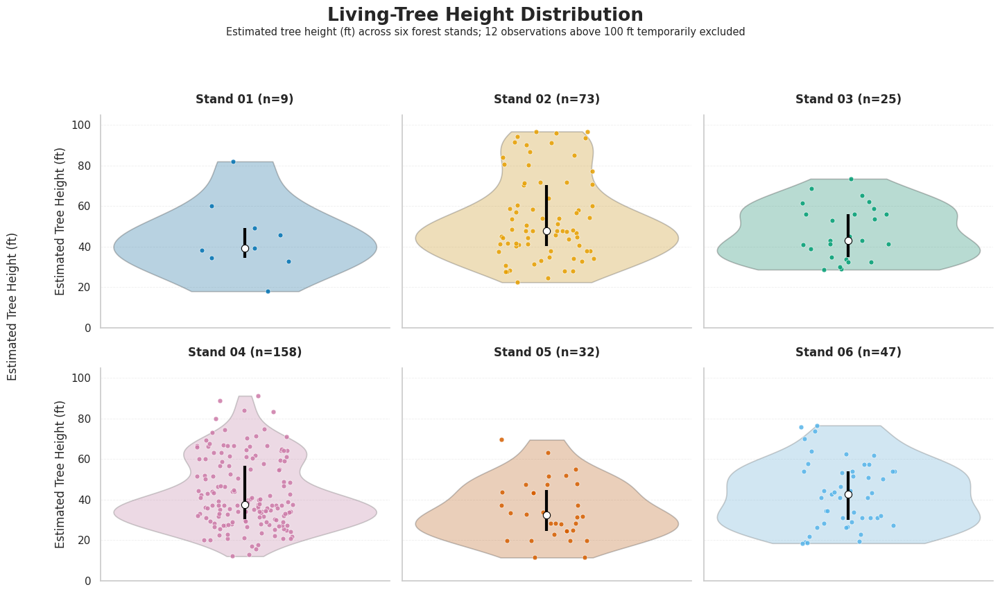

In [111]:

# STEP 95: Create the revised six-panel living-tree height
# distribution figure with semi-transparent violin plots.
#
# This figure uses the filtered height_visualization_df dataset,
# which excludes the 12 unusually tall observations temporarily.
#
# Visual elements:
# - Violin distributions: 30% opacity
# - Individual tree observations: 85% opacity
# - White median marker
# - Black interquartile range (IQR) line
# - Original six-stand color palette

# ------------------------------------------------------------
# 1. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a figure with six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9),
    sharey=True
)

# Flatten the axes array so each stand can be assigned to one panel.
axes = axes.flatten()

# Set a consistent random seed so horizontal point jitter is reproducible.
np.random.seed(42)


# ------------------------------------------------------------
# 2. CREATE THE HEIGHT DISTRIBUTION PANELS
# ------------------------------------------------------------

# Loop through the six stands and their corresponding plotting panels.
for stand, ax in zip(included_stands, axes):

    # Select living-tree observations belonging to the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ]

    # Extract estimated tree heights in feet and remove missing values.
    heights = stand_data['Estimated Tree Height (ft)'].dropna()

    # Retrieve the established color assigned to this stand.
    stand_color = stand_colors[stand]

    # Draw the violin plot to represent the distribution of tree heights.
    # cut=0 keeps the violin within the observed measurement range.
    # inner=None removes the default internal summary statistics.
    sns.violinplot(
        y=heights,
        ax=ax,
        color=stand_color,
        inner=None,
        cut=0,
        width=0.65,
        linewidth=1.2
    )

    # Apply 30% opacity to the violin distribution.
    # This matches the transparency used in the approved DBH figure.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate small horizontal offsets to prevent individual points
    # from overlapping exactly.
    jitter = np.random.uniform(
        -0.12,
        0.12,
        size=len(heights)
    )

    # Plot individual tree height measurements inside the violin.
    ax.scatter(
        jitter,
        heights,
        color=stand_color,
        edgecolor='white',
        linewidth=0.5,
        alpha=0.85,
        s=25,
        zorder=3
    )

    # Calculate the first quartile, median, and third quartile.
    q1 = heights.quantile(0.25)
    median = heights.median()
    q3 = heights.quantile(0.75)

    # Draw a black vertical line representing the interquartile range.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='black',
        linewidth=3,
        zorder=4
    )

    # Add a white marker representing the median tree height.
    ax.scatter(
        0,
        median,
        color='white',
        edgecolor='black',
        linewidth=0.8,
        s=55,
        zorder=5
    )

    # Add the stand number and sample size to the panel heading.
    ax.set_title(
        f'Stand {stand:02d} (n={len(heights)})',
        fontsize=12,
        fontweight='bold',
        pad=12
    )

    # Remove unnecessary horizontal-axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Add subtle horizontal gridlines to support height comparisons.
    ax.grid(
        axis='y',
        linestyle='--',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep gridlines behind the plotted observations.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


# ------------------------------------------------------------
# 3. ADD FIGURE TITLES AND AXIS LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Height Distribution',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Add a subtitle describing the measurements and temporary exclusion.
fig.text(
    0.5,
    0.935,
    'Estimated tree height (ft) across six forest stands; '
    '12 observations above 100 ft temporarily excluded',
    ha='center',
    fontsize=10.5
)

# Add a shared vertical-axis label.
fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=12,
    x=0.04
)

# Apply the same vertical-axis limits to every panel.
axes[0].set_ylim(0, 105)

# Adjust spacing to prevent titles and labels from overlapping.
plt.tight_layout(
    rect=[0.05, 0.03, 1, 0.91]
)


# ------------------------------------------------------------
# 4. SAVE AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
plt.savefig(
    export_dir / 'Living_Tree_Height_Raincloud.png',
    dpi=300,
    bbox_inches='tight'
)

# Save a PDF version for publication-quality output.
plt.savefig(
    export_dir / 'Living_Tree_Height_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


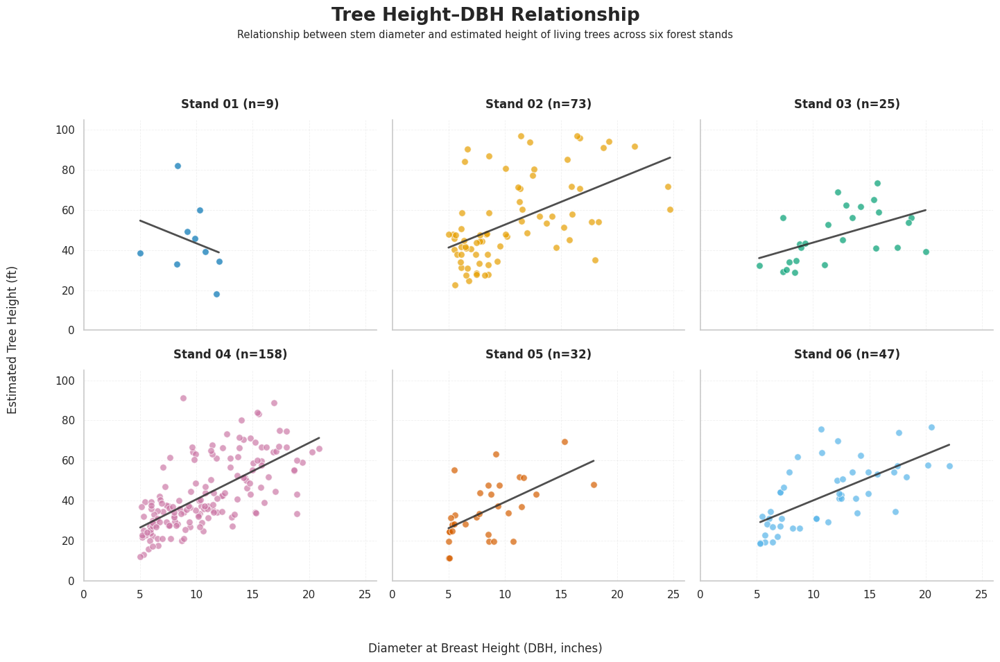

In [112]:

# STEP 96: Create a publication-style six-panel figure showing
# the relationship between living-tree DBH and estimated height.
#
# X-axis: DBH (inches)
# Y-axis: Estimated tree height (feet)
#
# Each panel represents one stand.
# Individual observations use the established stand colors.
# A dark linear trend line provides a visual summary of the
# height-diameter relationship within each stand.
#
# Uses height_visualization_df, which excludes the 12 unusually
# tall observations temporarily pending verification.

# ------------------------------------------------------------
# 1. SET UP THE FIGURE AND VISUAL STYLE
# ------------------------------------------------------------

# Create a 2-row by 3-column layout with one panel per stand.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 10),
    sharex=True,
    sharey=True
)

# Flatten the axes array to make iteration easier.
axes = axes.flatten()

# Set a consistent random seed for reproducibility.
np.random.seed(42)


# ------------------------------------------------------------
# 2. CREATE THE HEIGHT-DBH SCATTERPLOTS
# ------------------------------------------------------------

# Loop through the six stands and their corresponding panels.
for stand, ax in zip(included_stands, axes):

    # Select living-tree observations for the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ].copy()

    # Remove observations missing either DBH or estimated height.
    stand_data = stand_data.dropna(
        subset=[
            'DBH (in)',
            'Estimated Tree Height (ft)'
        ]
    )

    # Extract DBH measurements for the horizontal axis.
    dbh = stand_data['DBH (in)']

    # Extract estimated tree heights for the vertical axis.
    height = stand_data['Estimated Tree Height (ft)']

    # Retrieve the established color assigned to this stand.
    stand_color = stand_colors[stand]

    # --------------------------------------------------------
    # 2A. PLOT INDIVIDUAL TREE OBSERVATIONS
    # --------------------------------------------------------

    # Plot each tree as an individual point.
    # Transparency helps reveal overlapping observations.
    ax.scatter(
        dbh,
        height,
        color=stand_color,
        alpha=0.70,
        edgecolor='white',
        linewidth=0.7,
        s=48,
        zorder=3
    )

    # --------------------------------------------------------
    # 2B. ADD A LINEAR TREND LINE
    # --------------------------------------------------------

    # Fit a simple linear relationship between DBH and height.
    # This line is descriptive and is not intended to represent
    # a complete biological height-diameter model.
    if len(stand_data) >= 2 and dbh.nunique() >= 2:

        # Estimate the slope and intercept of the linear relationship.
        slope, intercept = np.polyfit(
            dbh,
            height,
            deg=1
        )

        # Generate evenly spaced DBH values across the observed range.
        dbh_line = np.linspace(
            dbh.min(),
            dbh.max(),
            100
        )

        # Calculate predicted heights along the fitted line.
        height_line = slope * dbh_line + intercept

        # Draw the fitted line in a dark neutral color.
        ax.plot(
            dbh_line,
            height_line,
            color='#303030',
            linewidth=2,
            alpha=0.85,
            zorder=4
        )

    # --------------------------------------------------------
    # 2C. FORMAT EACH PANEL
    # --------------------------------------------------------

    # Add the stand identifier and sample size.
    ax.set_title(
        f'Stand {stand:02d} (n={len(stand_data)})',
        fontsize=12,
        fontweight='bold',
        pad=12
    )

    # Add subtle horizontal and vertical gridlines.
    ax.grid(
        True,
        linestyle='--',
        linewidth=0.6,
        alpha=0.30
    )

    # Keep gridlines behind the points and trend line.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


# ------------------------------------------------------------
# 3. APPLY CONSISTENT AXIS LIMITS AND LABELS
# ------------------------------------------------------------

# Use identical horizontal-axis limits across all panels.
axes[0].set_xlim(0, 26)

# Use identical vertical-axis limits across all panels.
axes[0].set_ylim(0, 105)

# Add a shared horizontal-axis label.
fig.supxlabel(
    'Diameter at Breast Height (DBH, inches)',
    fontsize=12,
    y=0.045
)

# Add a shared vertical-axis label.
fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=12,
    x=0.04
)


# ------------------------------------------------------------
# 4. ADD THE MAIN TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Tree Height–DBH Relationship',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Add a subtitle explaining the observations and trend lines.
fig.text(
    0.5,
    0.935,
    'Relationship between stem diameter and estimated height '
    'of living trees across six forest stands',
    ha='center',
    fontsize=10.5
)


# ------------------------------------------------------------
# 5. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate the shared labels and titles.
plt.tight_layout(
    rect=[0.05, 0.07, 1, 0.91]
)

# Save a high-resolution PNG for reports and presentations.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship.png',
    dpi=300,
    bbox_inches='tight'
)

# Save a PDF version for publication-quality output.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


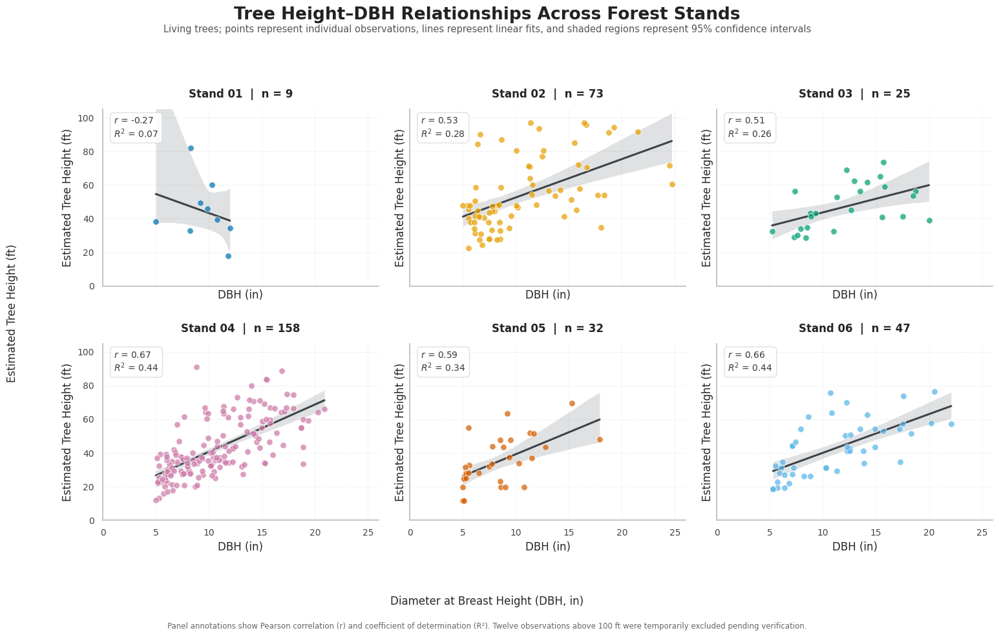

In [113]:

# STEP 98: Create a refined publication-style figure showing
# the relationship between living-tree DBH and estimated height.
#
# Figure features:
# - Six panels, one per forest stand
# - Original stand-specific color palette
# - Semi-transparent individual observations
# - Linear regression trend lines
# - 95% confidence intervals
# - Pearson correlation coefficient (r)
# - Coefficient of determination (R-squared)
# - Consistent axes across all six stands
#
# Uses height_visualization_df, which temporarily excludes
# the 12 unusually tall observations pending verification.

# ------------------------------------------------------------
# 1. IMPORT STATISTICAL FUNCTIONS
# ------------------------------------------------------------

# Import Pearson correlation to calculate the strength and
# direction of the linear relationship within each stand.
from scipy.stats import pearsonr


# ------------------------------------------------------------
# 2. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a two-row by three-column figure.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

# Flatten the axes array for easier iteration.
axes = axes.flatten()

# Set a consistent random seed for reproducibility.
np.random.seed(42)

# Define a dark neutral color for the regression lines.
regression_color = '#343A40'


# ------------------------------------------------------------
# 3. CREATE THE SIX STAND PANELS
# ------------------------------------------------------------

# Loop through each stand and its corresponding panel.
for stand, ax in zip(included_stands, axes):

    # Select observations belonging to the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ].copy()

    # Remove observations missing either DBH or estimated height.
    stand_data = stand_data.dropna(
        subset=[
            'DBH (in)',
            'Estimated Tree Height (ft)'
        ]
    )

    # Extract DBH measurements for the horizontal axis.
    dbh = stand_data['DBH (in)']

    # Extract estimated tree heights for the vertical axis.
    height = stand_data['Estimated Tree Height (ft)']

    # Retrieve the established color assigned to this stand.
    stand_color = stand_colors[stand]

    # --------------------------------------------------------
    # 3A. PLOT INDIVIDUAL TREE OBSERVATIONS
    # --------------------------------------------------------

    # Plot individual trees using the stand-specific color.
    # Semi-transparent points help reveal overlapping observations.
    ax.scatter(
        dbh,
        height,
        color=stand_color,
        alpha=0.72,
        edgecolor='white',
        linewidth=0.75,
        s=48,
        zorder=3
    )

    # --------------------------------------------------------
    # 3B. ADD LINEAR REGRESSION AND 95% CONFIDENCE INTERVAL
    # --------------------------------------------------------

    # Fit a linear regression line and display its 95% confidence
    # interval. The confidence interval describes uncertainty
    # around the estimated mean relationship, not individual trees.
    sns.regplot(
        data=stand_data,
        x='DBH (in)',
        y='Estimated Tree Height (ft)',
        scatter=False,
        ci=95,
        n_boot=1000,
        color=regression_color,
        line_kws={
            'linewidth': 2.2,
            'alpha': 0.95
        },
        ax=ax
    )

    # --------------------------------------------------------
    # 3C. CALCULATE AND ANNOTATE THE RELATIONSHIP
    # --------------------------------------------------------

    # Calculate Pearson's correlation when there are enough
    # observations and sufficient variation in both variables.
    if (
        len(stand_data) >= 3
        and dbh.nunique() > 1
        and height.nunique() > 1
    ):

        # Calculate Pearson's correlation coefficient and p-value.
        r_value, p_value = pearsonr(dbh, height)

        # Calculate the coefficient of determination.
        # For simple linear regression with an intercept,
        # R-squared is equal to Pearson's r squared.
        r_squared = r_value ** 2

        # Format the statistical annotation.
        annotation = (
            f'$r$ = {r_value:.2f}\n'
            f'$R^2$ = {r_squared:.2f}'
        )

    else:

        # Avoid reporting statistics when there is insufficient
        # variation or too few observations.
        annotation = 'Insufficient variation'

    # Position the annotation in the upper-left corner of the panel.
    ax.text(
        0.04,
        0.96,
        annotation,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        color='#343A40',
        bbox={
            'boxstyle': 'round,pad=0.4',
            'facecolor': 'white',
            'edgecolor': '#D9DDE1',
            'alpha': 0.90
        }
    )

    # --------------------------------------------------------
    # 3D. FORMAT EACH PANEL
    # --------------------------------------------------------

    # Add the stand identifier and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(stand_data)}',
        fontsize=12,
        fontweight='bold',
        pad=13,
        color='#252525'
    )

    # Add subtle gridlines.
    ax.grid(
        True,
        linestyle=':',
        linewidth=0.65,
        color='#BFC5CA',
        alpha=0.55
    )

    # Keep gridlines behind the plotted data.
    ax.set_axisbelow(True)

    # Remove the top and right borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Soften the remaining axis borders.
    ax.spines['left'].set_color('#B8BEC4')
    ax.spines['bottom'].set_color('#B8BEC4')

    # Standardize tick label appearance.
    ax.tick_params(
        axis='both',
        labelsize=10,
        colors='#444444'
    )


# ------------------------------------------------------------
# 4. APPLY CONSISTENT AXIS LIMITS AND TICKS
# ------------------------------------------------------------

# Use identical DBH limits across all six panels.
axes[0].set_xlim(0, 26)

# Use identical tree-height limits across all six panels.
axes[0].set_ylim(0, 105)

# Apply consistent DBH tick intervals.
for ax in axes:
    ax.set_xticks(np.arange(0, 27, 5))

# Apply consistent height tick intervals.
for ax in axes:
    ax.set_yticks(np.arange(0, 101, 20))


# ------------------------------------------------------------
# 5. ADD FIGURE TITLE AND SHARED AXIS LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Tree Height–DBH Relationships Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    color='#222222',
    y=0.975
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.935,
    'Living trees; points represent individual observations, '
    'lines represent linear fits, and shaded regions represent 95% confidence intervals',
    ha='center',
    fontsize=10.5,
    color='#555555'
)

# Add the shared horizontal-axis label.
# DBH units are expressed as inches (in).
fig.supxlabel(
    'Diameter at Breast Height (DBH, in)',
    fontsize=12,
    fontweight='medium',
    y=0.045
)

# Add the shared vertical-axis label.
fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=12,
    fontweight='medium',
    x=0.035
)


# ------------------------------------------------------------
# 6. ADD A FIGURE FOOTNOTE
# ------------------------------------------------------------

# Explain the statistical annotations and temporary exclusions.
fig.text(
    0.5,
    0.012,
    'Panel annotations show Pearson correlation (r) and coefficient of determination (R²). '
    'Twelve observations above 100 ft were temporarily excluded pending verification.',
    ha='center',
    fontsize=8.5,
    color='#666666'
)


# ------------------------------------------------------------
# 7. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate titles, labels, and footnote.
plt.tight_layout(
    rect=[0.055, 0.075, 1, 0.91],
    h_pad=2.0,
    w_pad=1.5
)

# Save a high-resolution PNG for the final report.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship_Refined.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save a publication-quality PDF.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship_Refined.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


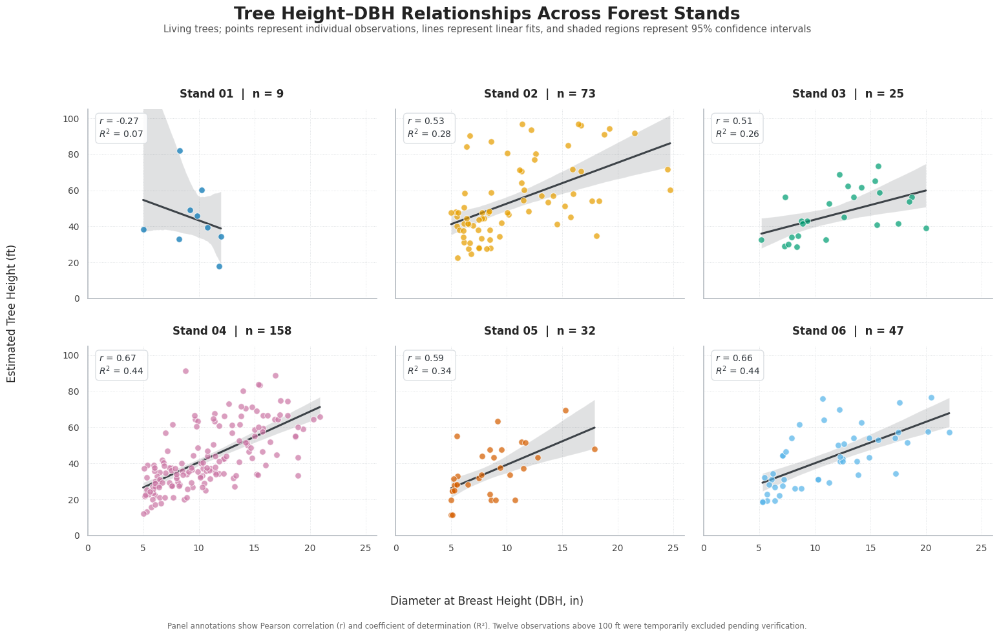

In [114]:

# STEP 99: Create the final refined height-DBH relationship figure.
#
# Improvements:
# - One shared x-axis label across the entire figure.
# - One shared y-axis label across the entire figure.
# - No repeated axis labels within individual panels.
# - Original stand-specific colors.
# - Semi-transparent individual observations.
# - Linear regression lines with 95% confidence intervals.
# - Pearson correlation and R-squared annotations.
# - Consistent axes and publication-style formatting.

# ------------------------------------------------------------
# 1. IMPORT STATISTICAL FUNCTIONS
# ------------------------------------------------------------

# Import Pearson correlation to quantify the linear association
# between DBH and estimated tree height within each stand.
from scipy.stats import pearsonr


# ------------------------------------------------------------
# 2. SET UP THE FIGURE
# ------------------------------------------------------------

# Create six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

# Flatten the axes array to simplify iteration.
axes = axes.flatten()

# Set a reproducible random seed.
np.random.seed(42)

# Define a dark neutral color for regression lines.
regression_color = '#343A40'


# ------------------------------------------------------------
# 3. CREATE THE SIX STAND PANELS
# ------------------------------------------------------------

# Loop through the six stands and their corresponding panels.
for stand, ax in zip(included_stands, axes):

    # Select observations belonging to the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ].copy()

    # Remove observations missing either DBH or estimated height.
    stand_data = stand_data.dropna(
        subset=[
            'DBH (in)',
            'Estimated Tree Height (ft)'
        ]
    )

    # Extract DBH measurements.
    dbh = stand_data['DBH (in)']

    # Extract estimated tree heights.
    height = stand_data['Estimated Tree Height (ft)']

    # Retrieve the established color for the current stand.
    stand_color = stand_colors[stand]

    # --------------------------------------------------------
    # 3A. PLOT INDIVIDUAL TREE OBSERVATIONS
    # --------------------------------------------------------

    # Plot individual trees using their stand-specific color.
    # Transparency helps reveal overlapping observations.
    ax.scatter(
        dbh,
        height,
        color=stand_color,
        alpha=0.72,
        edgecolor='white',
        linewidth=0.75,
        s=48,
        zorder=3
    )

    # --------------------------------------------------------
    # 3B. ADD LINEAR REGRESSION AND 95% CONFIDENCE INTERVAL
    # --------------------------------------------------------

    # Fit a linear regression line and display its 95% confidence
    # interval around the estimated mean relationship.
    sns.regplot(
        data=stand_data,
        x='DBH (in)',
        y='Estimated Tree Height (ft)',
        scatter=False,
        ci=95,
        n_boot=1000,
        color=regression_color,
        line_kws={
            'linewidth': 2.2,
            'alpha': 0.95
        },
        ax=ax
    )

    # --------------------------------------------------------
    # 3C. CALCULATE AND ANNOTATE CORRELATION STATISTICS
    # --------------------------------------------------------

    # Calculate Pearson's correlation when there are enough
    # observations and variation in both variables.
    if (
        len(stand_data) >= 3
        and dbh.nunique() > 1
        and height.nunique() > 1
    ):

        # Calculate Pearson's correlation coefficient and p-value.
        r_value, p_value = pearsonr(dbh, height)

        # Calculate the coefficient of determination.
        r_squared = r_value ** 2

        # Format the statistical annotation.
        annotation = (
            f'$r$ = {r_value:.2f}\n'
            f'$R^2$ = {r_squared:.2f}'
        )

    else:

        # Report insufficient variation if the relationship
        # cannot be calculated reliably.
        annotation = 'Insufficient variation'

    # Position the statistical annotation in the upper-left corner.
    ax.text(
        0.04,
        0.96,
        annotation,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        color='#343A40',
        bbox={
            'boxstyle': 'round,pad=0.4',
            'facecolor': 'white',
            'edgecolor': '#D9DDE1',
            'alpha': 0.90
        }
    )

    # --------------------------------------------------------
    # 3D. FORMAT EACH PANEL
    # --------------------------------------------------------

    # Add the stand identifier and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(stand_data)}',
        fontsize=12,
        fontweight='bold',
        pad=13,
        color='#252525'
    )

    # Remove individual axis labels because shared labels
    # will be added to the overall figure.
    ax.set_xlabel('')
    ax.set_ylabel('')

    # Add subtle gridlines.
    ax.grid(
        True,
        linestyle=':',
        linewidth=0.65,
        color='#BFC5CA',
        alpha=0.55
    )

    # Keep gridlines behind the observations.
    ax.set_axisbelow(True)

    # Remove the top and right borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Soften the remaining axis borders.
    ax.spines['left'].set_color('#B8BEC4')
    ax.spines['bottom'].set_color('#B8BEC4')

    # Standardize tick label appearance.
    ax.tick_params(
        axis='both',
        labelsize=10,
        colors='#444444'
    )


# ------------------------------------------------------------
# 4. APPLY CONSISTENT AXIS LIMITS AND TICKS
# ------------------------------------------------------------

# Use identical DBH limits across all six panels.
axes[0].set_xlim(0, 26)

# Use identical tree-height limits across all six panels.
axes[0].set_ylim(0, 105)

# Apply consistent DBH tick intervals.
for ax in axes:
    ax.set_xticks(np.arange(0, 27, 5))

# Apply consistent height tick intervals.
for ax in axes:
    ax.set_yticks(np.arange(0, 101, 20))


# ------------------------------------------------------------
# 5. ADD FIGURE TITLE AND SHARED AXIS LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Tree Height–DBH Relationships Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    color='#222222',
    y=0.975
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.935,
    'Living trees; points represent individual observations, '
    'lines represent linear fits, and shaded regions represent 95% confidence intervals',
    ha='center',
    fontsize=10.5,
    color='#555555'
)

# Add one shared horizontal-axis label.
fig.supxlabel(
    'Diameter at Breast Height (DBH, in)',
    fontsize=12,
    fontweight='medium',
    y=0.045
)

# Add one shared vertical-axis label.
fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=12,
    fontweight='medium',
    x=0.035
)


# ------------------------------------------------------------
# 6. ADD THE FIGURE FOOTNOTE
# ------------------------------------------------------------

# Explain the statistical annotations and temporary exclusions.
fig.text(
    0.5,
    0.012,
    'Panel annotations show Pearson correlation (r) and coefficient of determination (R²). '
    'Twelve observations above 100 ft were temporarily excluded pending verification.',
    ha='center',
    fontsize=8.5,
    color='#666666'
)


# ------------------------------------------------------------
# 7. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate the shared labels and footnote.
plt.tight_layout(
    rect=[0.055, 0.075, 1, 0.91],
    h_pad=2.0,
    w_pad=1.5
)

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship_Refined.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save the publication-quality PDF.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship_Refined.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


In [115]:

# STEP 100: Calculate individual living-tree basal area.
#
# Basal area represents the cross-sectional area of a tree stem
# at breast height (4.5 feet above the ground).
#
# DBH is recorded in inches.
# Basal area will be calculated in square feet per tree.
#
# This step creates a separate working DataFrame and does not
# modify the original woody species dataset.

# ------------------------------------------------------------
# 1. CREATE A WORKING COPY
# ------------------------------------------------------------

# Copy the living-tree dataset so the original analysis data
# remains unchanged.
basal_area_analysis = live_trees_analysis.copy()

# ------------------------------------------------------------
# 2. CALCULATE INDIVIDUAL TREE BASAL AREA
# ------------------------------------------------------------

# Calculate basal area using DBH in inches.
# Dividing by 576 converts the squared-inch measurement
# into square feet.
basal_area_analysis['Basal Area (sq ft)'] = (
    np.pi * basal_area_analysis['DBH (in)']**2 / 576
)

# ------------------------------------------------------------
# 3. SUMMARIZE BASAL AREA BY STAND
# ------------------------------------------------------------

# Group individual tree measurements by stand.
# Calculate the number of trees, mean basal area, median
# basal area, and total sampled basal area.
basal_area_summary = (
    basal_area_analysis
    .groupby('Stand ID')['Basal Area (sq ft)']
    .agg(
        Tree_Count='count',
        Mean_Basal_Area='mean',
        Median_Basal_Area='median',
        Total_Basal_Area='sum'
    )
    .round(3)
    .reset_index()
)

# ------------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ------------------------------------------------------------

# Display the stand-level basal area summary.
display(basal_area_summary)


,Stand ID,Tree_Count,Mean_Basal_Area,Median_Basal_Area,Total_Basal_Area
0,1,11,0.585,0.556,6.438
1,2,79,0.776,0.478,61.302
2,3,25,0.900,0.812,22.506
3,4,162,0.746,0.587,120.847
4,5,32,0.431,0.363,13.787
5,6,47,0.800,0.636,37.579


In [116]:

# STEP 101: Inspect subplot metadata to identify the
# sampling dimensions needed for basal area per acre.
#
# We need to establish the area sampled for each subplot
# before converting sampled basal area into a per-acre estimate.

# ------------------------------------------------------------
# 1. INSPECT SUBPLOT METADATA COLUMNS
# ------------------------------------------------------------

# Display the available fields in the subplot metadata.
print("Subplot metadata columns:")
print(subplot_metadata_analysis.columns.tolist())

# ------------------------------------------------------------
# 2. DISPLAY SUBPLOT METADATA RECORDS
# ------------------------------------------------------------

# Display the first 15 records to inspect the sampling design.
display(subplot_metadata_analysis.head(15))

# ------------------------------------------------------------
# 3. INSPECT PLOT METADATA
# ------------------------------------------------------------

# Display the available fields in the plot metadata.
print("Plot metadata columns:")
print(plot_metadata_analysis.columns.tolist())

# Display the first 10 plot metadata records.
display(plot_metadata_analysis.head(10))


Subplot metadata columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Elevation (ft)', 'Slope (%)', 'Aspect', 'Dominant Cover Code', 'Notes']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Elevation (ft),Slope (%),Aspect,Dominant Cover Code,Notes
0,1,1,1,23-Oct,"EC, AB, TQ, EJ, JW, LA, HP, JR, LW, JM",715,-8.3,344.0,Tree,NaN
1,2,1,1,23-Oct,"AB, HP, EC, JR",760,-9.5,26.0,Tree,NaN
2,2,1,2,23-Oct,"LW, JM, JW",748,-1.0,11.0,Tree,NaN
3,2,1,3,23-Oct,"EC, AB, HP, JR",730,-6.7,235.0,Tree,NaN
4,2,2,1,28-Oct,"EC, HP, AB, LA",781,-4.2,18.0,Tree,NaN
5,2,2,2,28-Oct,"EC, HP, AB",768,-3.5,3.0,Tree,NaN
6,2,2,3,28-Oct,"EC, HP, AB",789,-1.2,12.0,Tree,NaN
7,2,2,4,30-Oct,"LA, AB",736,-7.5,202.0,Tree,NaN
8,2,3,1,30-Oct,"AB, EC, LA",738,-13.5,195.0,Tree,NaN
9,2,3,2,30-Oct,EC,739,-10.2,175.0,Tree,Stream present


Plot metadata columns:
['Stand', 'Plot ID', 'Date', 'Team Member(s)', 'Natural Community Code', 'Stand Age Code', 'Topography Code', 'Water (Absent/Present)', 'Water Type (If Applicable)', 'Disturbance Code', 'Notes']


,Stand,Plot ID,Date,Team Member(s),Natural Community Code,Stand Age Code,Topography Code,Water (Absent/Present),Water Type (If Applicable),Disturbance Code,Notes
0,1,1,23-Oct,"JW, LA, JR, EJ, TQ, LW, AB, JM, EC, HP",HNH,T,P,Absent,NaN,"7, 11, 13",NaN
1,2,1,23-Oct,"JW, LA, JR, LW, AB, JM, EC, HP",NH,T,P,Present,Permanent Stream,"7, 11, 13, 17","Beech bark disease, stumps found (advanced dec..."
2,2,2,30-Oct,"AB, EC, LA, TQ, JM",HNH,T,P,Present,Ephemeral Stream,"5, 13","Beech bark disease, wind"
3,2,3,30-Oct,"AB, EC, LA, TQ, JM",HNH,T,"CE, CX",Present,Ephemeral and Permanent Streams,4,Beech bark disease
4,2,4,5-Nov,"TQ,EC,JW,KC,LW",HNH,T,CE,Present,Wetland,"4,11,7,13",NaN
5,3,1,6-Nov,AB,HNH,T,P,Absent,NaN,"7, 13, 17",Beech bark disease
6,3,2,6-Nov,AB,HNH,T,P,Absent,NaN,"7, 13, 17",NaN
7,4,1,4-Nov,AB,HNH,T,"CX, CE, P",Present,"Ephemeral and Permanent Streams, Wetlands","7, 11, 13, 17",Beech bark disease
8,4,2,6-Nov,"TQ, AB",HNH,T,"P, CE, CX",Present,Emphemeral Stream,"6, 11, 13, 17","BBD, browse, bumper trees"
9,4,2,6-Nov,"TQ, AB",HNH,T,"P, CE, CX",Present,Ephemeral Stream,"6, 11, 17, 13","BBD, deer browse, bumper trees"


In [117]:

# STEP 102: Calculate sampled area and subplot-level basal area.
#
# Sampling design:
# - Circular tree-sampling areas
# - Radius = 48 feet
# - Basal area calculated from living trees
#
# Basal area per acre will be calculated using the actual
# number of sampled subplots in each stand.

# ------------------------------------------------------------
# 1. CALCULATE THE AREA OF ONE CIRCULAR SAMPLING SUBPLOT
# ------------------------------------------------------------

# Define the radius of each tree-sampling area in feet.
subplot_radius_ft = 48

# Calculate the area of one circular subplot in square feet.
subplot_area_sq_ft = np.pi * subplot_radius_ft**2

# Convert the subplot area from square feet to acres.
subplot_area_acres = subplot_area_sq_ft / 43560

# Display the sampling area.
print("Area per subplot (sq ft):", round(subplot_area_sq_ft, 2))
print("Area per subplot (acres):", round(subplot_area_acres, 4))


# ------------------------------------------------------------
# 2. SUM BASAL AREA WITHIN EACH SUBPLOT
# ------------------------------------------------------------

# Group living-tree basal area measurements by their unique
# stand, plot, and subplot identifiers.
subplot_basal_area = (
    basal_area_analysis
    .groupby(
        ['Stand ID', 'Plot ID', 'Subplot ID']
    )['Basal Area (sq ft)']
    .sum()
    .reset_index()
)

# Rename the summed basal area column for clarity.
subplot_basal_area = subplot_basal_area.rename(
    columns={
        'Basal Area (sq ft)': 'Total Basal Area (sq ft)'
    }
)

# Calculate basal area per acre for each sampled subplot.
subplot_basal_area['Basal Area (sq ft/acre)'] = (
    subplot_basal_area['Total Basal Area (sq ft)']
    / subplot_area_acres
)

# Round the calculated values for easier inspection.
subplot_basal_area = subplot_basal_area.round(3)


# ------------------------------------------------------------
# 3. COUNT THE SAMPLED SUBPLOTS IN EACH STAND
# ------------------------------------------------------------

# Count the unique subplots represented in the tree dataset.
subplot_counts = (
    subplot_basal_area
    .groupby('Stand ID')['Subplot ID']
    .count()
    .reset_index(name='Subplots with Living Trees')
)

# Display the subplot counts.
display(subplot_counts)


# ------------------------------------------------------------
# 4. DISPLAY SUBPLOT-LEVEL BASAL AREA
# ------------------------------------------------------------

# Sort the results by stand, plot, and subplot.
subplot_basal_area = subplot_basal_area.sort_values(
    ['Stand ID', 'Plot ID', 'Subplot ID']
)

# Display the subplot-level basal area calculations.
display(subplot_basal_area)


Area per subplot (sq ft): 7238.23
Area per subplot (acres): 0.1662


,Stand ID,Subplots with Living Trees
0,1,1
1,2,15
2,3,6
3,4,22
4,5,3
5,6,7


,Stand ID,Plot ID,Subplot ID,Total Basal Area (sq ft),Basal Area (sq ft/acre)
0,1,1,1,6.438,38.743
1,2,1,1,1.382,8.319
2,2,1,2,1.882,11.328
3,2,1,3,1.710,10.290
4,2,2,1,9.699,58.369
5,2,2,2,5.360,32.258
6,2,2,3,3.077,18.516
7,2,2,4,2.687,16.171
8,2,3,1,2.456,14.779
9,2,3,2,6.487,39.040


In [118]:

# STEP 103: Calculate stand-level basal area per acre.
#
# Each subplot has the same sampling area (48-ft radius).
# We calculate the mean, median, standard deviation, and range
# of subplot-level basal area per acre within each stand.
#
# This allows comparisons among stands while accounting
# for differences in the number of sampled subplots.

# ------------------------------------------------------------
# 1. CALCULATE TOTAL SAMPLED AREA BY STAND
# ------------------------------------------------------------

# Count the number of sampled subplots in each stand.
stand_subplot_counts = (
    subplot_basal_area
    .groupby('Stand ID')
    .size()
    .reset_index(name='Number of Subplots')
)

# Calculate the total sampled area in acres for each stand.
stand_subplot_counts['Sampled Area (acres)'] = (
    stand_subplot_counts['Number of Subplots']
    * subplot_area_acres
)

# ------------------------------------------------------------
# 2. SUMMARIZE SUBPLOT BASAL AREA PER ACRE
# ------------------------------------------------------------

# Calculate descriptive statistics for subplot-level
# basal area per acre within each stand.
stand_basal_area_summary = (
    subplot_basal_area
    .groupby('Stand ID')['Basal Area (sq ft/acre)']
    .agg(
        Mean_BA_per_Acre='mean',
        Median_BA_per_Acre='median',
        SD_BA_per_Acre='std',
        Minimum_BA_per_Acre='min',
        Maximum_BA_per_Acre='max'
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. COMBINE SAMPLING EFFORT AND BASAL AREA SUMMARIES
# ------------------------------------------------------------

# Merge the sampling effort information with the basal area
# statistics using Stand ID.
stand_basal_area_summary = stand_basal_area_summary.merge(
    stand_subplot_counts,
    on='Stand ID',
    how='left'
)

# Round numerical values for easier interpretation.
stand_basal_area_summary = stand_basal_area_summary.round(2)

# Arrange columns in a logical reporting order.
stand_basal_area_summary = stand_basal_area_summary[
    [
        'Stand ID',
        'Number of Subplots',
        'Sampled Area (acres)',
        'Mean_BA_per_Acre',
        'Median_BA_per_Acre',
        'SD_BA_per_Acre',
        'Minimum_BA_per_Acre',
        'Maximum_BA_per_Acre'
    ]
]

# ------------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ------------------------------------------------------------

# Display the stand-level basal area summary.
display(stand_basal_area_summary)


,Stand ID,Number of Subplots,Sampled Area (acres),Mean_BA_per_Acre,Median_BA_per_Acre,SD_BA_per_Acre,Minimum_BA_per_Acre,Maximum_BA_per_Acre
0,1,1,0.17,38.74,38.74,NaN,38.74,38.74
1,2,15,2.49,24.59,16.17,16.74,8.32,58.37
2,3,6,1.00,22.57,22.71,9.15,11.54,37.27
3,4,22,3.66,33.06,33.64,14.05,6.06,62.69
4,5,3,0.50,27.66,23.36,15.15,15.12,44.49
5,6,7,1.16,32.31,28.79,15.14,18.07,62.69


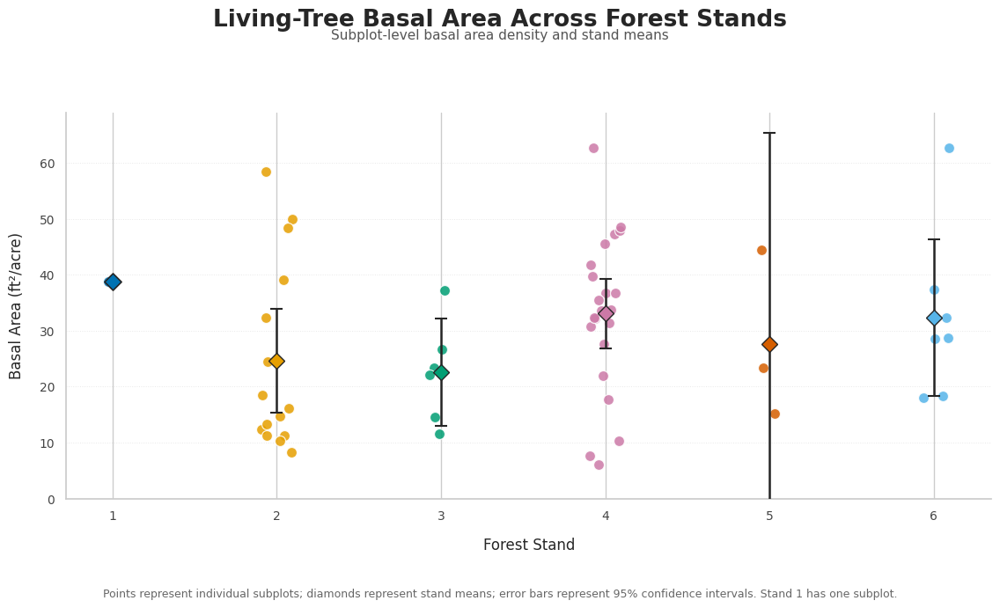

In [119]:

# STEP 104: Create a publication-style figure comparing
# subplot-level basal area per acre across six forest stands.
#
# Individual points represent sampled subplots.
# Large markers represent stand means.
# Error bars represent 95% confidence intervals around
# the mean, calculated using the t distribution.
#
# Stand 1 has only one subplot, so no confidence interval
# can be calculated for that stand.

# ------------------------------------------------------------
# 1. IMPORT STATISTICAL FUNCTIONS
# ------------------------------------------------------------

# Import the t distribution to calculate confidence intervals
# that account for the sample size within each stand.
from scipy.stats import t


# ------------------------------------------------------------
# 2. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a wide figure for a clear comparison among stands.
fig, ax = plt.subplots(
    figsize=(12, 7)
)

# Set a consistent random seed for reproducible point jitter.
np.random.seed(42)


# ------------------------------------------------------------
# 3. PLOT INDIVIDUAL SUBPLOT OBSERVATIONS
# ------------------------------------------------------------

# Loop through each stand.
for stand in included_stands:

    # Select basal area measurements for the current stand.
    stand_data = subplot_basal_area[
        subplot_basal_area['Stand ID'] == stand
    ]

    # Extract the subplot-level basal area values.
    values = stand_data['Basal Area (sq ft/acre)'].dropna()

    # Calculate the mean basal area for this stand.
    mean_value = values.mean()

    # Retrieve the established color for this stand.
    stand_color = stand_colors[stand]

    # Generate small horizontal offsets to separate points visually.
    jitter = np.random.uniform(
        -0.10,
        0.10,
        size=len(values)
    )

    # Plot each subplot as an individual observation.
    ax.scatter(
        stand + jitter,
        values,
        color=stand_color,
        edgecolor='white',
        linewidth=0.9,
        alpha=0.85,
        s=75,
        zorder=3
    )

    # --------------------------------------------------------
    # 3A. CALCULATE THE 95% CONFIDENCE INTERVAL
    # --------------------------------------------------------

    # Calculate a confidence interval only when at least
    # two subplot observations are available.
    if len(values) >= 2:

        # Calculate the sample standard deviation.
        standard_deviation = values.std(ddof=1)

        # Calculate the standard error of the mean.
        standard_error = standard_deviation / np.sqrt(len(values))

        # Calculate the critical t value for a 95% interval.
        critical_t = t.ppf(
            0.975,
            df=len(values) - 1
        )

        # Calculate the lower and upper confidence limits.
        lower_ci = mean_value - critical_t * standard_error
        upper_ci = mean_value + critical_t * standard_error

        # Calculate the lower and upper error distances.
        lower_error = mean_value - lower_ci
        upper_error = upper_ci - mean_value

        # Plot the mean and confidence interval.
        ax.errorbar(
            stand,
            mean_value,
            yerr=[[lower_error], [upper_error]],
            fmt='D',
            color='#252525',
            markerfacecolor=stand_color,
            markeredgecolor='#252525',
            markersize=9,
            capsize=5,
            capthick=1.5,
            linewidth=1.8,
            zorder=5
        )

    else:

        # For a single subplot, show the mean without a confidence interval.
        ax.scatter(
            stand,
            mean_value,
            marker='D',
            color=stand_color,
            edgecolor='#252525',
            linewidth=1.2,
            s=95,
            zorder=5
        )


# ------------------------------------------------------------
# 4. FORMAT THE AXES
# ------------------------------------------------------------

# Set stand numbers as the horizontal-axis positions.
ax.set_xticks(included_stands)

# Label the horizontal axis.
ax.set_xlabel(
    'Forest Stand',
    fontsize=12,
    labelpad=12
)

# Label the vertical axis.
ax.set_ylabel(
    'Basal Area (ft²/acre)',
    fontsize=12,
    labelpad=12
)

# Set the vertical-axis range to accommodate the confidence intervals.
ax.set_ylim(bottom=0)

# Add subtle horizontal gridlines.
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.7,
    alpha=0.45
)

# Keep gridlines behind the observations.
ax.set_axisbelow(True)

# Remove the top and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Standardize tick label appearance.
ax.tick_params(
    axis='both',
    labelsize=10,
    colors='#444444'
)


# ------------------------------------------------------------
# 5. ADD TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Basal Area Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.97
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.92,
    'Subplot-level basal area density and stand means',
    ha='center',
    fontsize=11,
    color='#555555'
)

# Add a footnote explaining the points and confidence intervals.
fig.text(
    0.5,
    0.015,
    'Points represent individual subplots; diamonds represent stand means; '
    'error bars represent 95% confidence intervals. Stand 1 has one subplot.',
    ha='center',
    fontsize=9,
    color='#666666'
)


# ------------------------------------------------------------
# 6. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust the layout to accommodate the title and footnote.
plt.tight_layout(
    rect=[0.02, 0.06, 0.98, 0.89]
)

# Save a high-resolution PNG.
plt.savefig(
    export_dir / 'Living_Tree_Basal_Area_by_Stand.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save a publication-quality PDF.
plt.savefig(
    export_dir / 'Living_Tree_Basal_Area_by_Stand.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


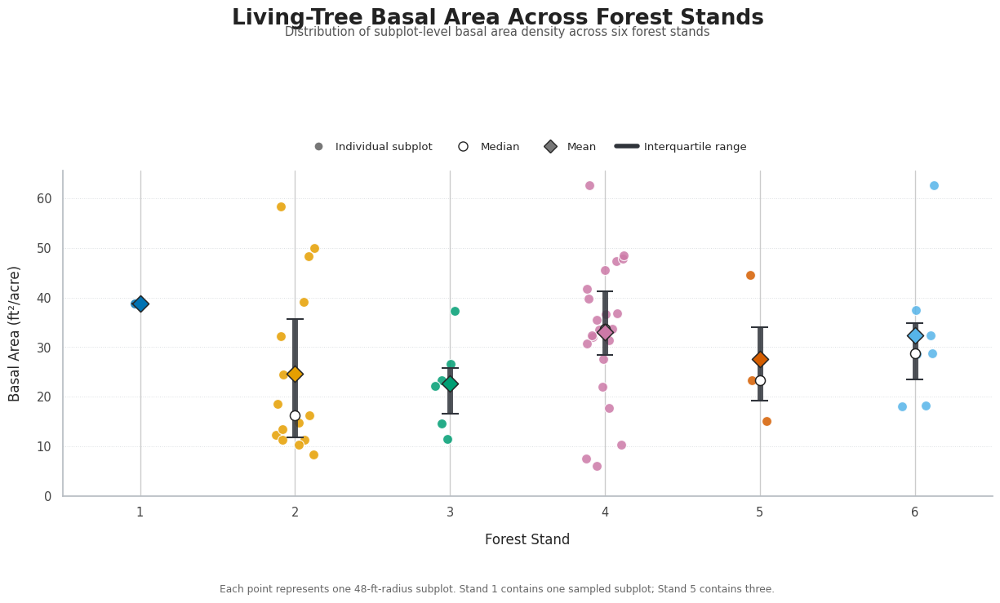

In [120]:

# STEP 105: Create a refined publication-style basal area figure.
#
# Figure design:
# - Individual points represent sampled subplots.
# - Point colors follow the original six-stand palette.
# - Horizontal jitter separates overlapping observations.
# - Thick black lines represent the interquartile range (IQR).
# - White circles represent subplot medians.
# - Dark diamonds represent stand means.
#
# Confidence intervals are omitted because some stands have
# relatively few sampled subplots, making their intervals
# highly uncertain and visually disproportionate.

# ------------------------------------------------------------
# 1. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a wide figure with sufficient space for six stand groups.
fig, ax = plt.subplots(
    figsize=(13, 7.5)
)

# Set a consistent random seed so point positions are reproducible.
np.random.seed(42)


# ------------------------------------------------------------
# 2. PLOT SUBPLOT OBSERVATIONS AND DISTRIBUTION SUMMARIES
# ------------------------------------------------------------

# Loop through each stand.
for stand in included_stands:

    # Select subplot-level basal area observations for this stand.
    stand_data = subplot_basal_area[
        subplot_basal_area['Stand ID'] == stand
    ]

    # Extract basal area values and remove missing observations.
    values = stand_data['Basal Area (sq ft/acre)'].dropna()

    # Retrieve the established color assigned to this stand.
    stand_color = stand_colors[stand]

    # Calculate the mean, median, and quartiles.
    mean_value = values.mean()
    median_value = values.median()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    # --------------------------------------------------------
    # 2A. PLOT INDIVIDUAL SUBPLOT OBSERVATIONS
    # --------------------------------------------------------

    # Generate small horizontal offsets to prevent overlapping points.
    jitter = np.random.uniform(
        -0.13,
        0.13,
        size=len(values)
    )

    # Plot individual subplot measurements.
    ax.scatter(
        stand + jitter,
        values,
        color=stand_color,
        edgecolor='white',
        linewidth=0.9,
        alpha=0.85,
        s=75,
        zorder=3
    )

    # --------------------------------------------------------
    # 2B. DISPLAY THE INTERQUARTILE RANGE
    # --------------------------------------------------------

    # Draw a thick vertical line showing the middle 50% of observations.
    # This represents the distance between the first and third quartiles.
    ax.vlines(
        stand,
        q1,
        q3,
        color='#30343B',
        linewidth=5,
        alpha=0.85,
        zorder=4
    )

    # Add small horizontal caps to the interquartile range.
    ax.hlines(
        [q1, q3],
        stand - 0.055,
        stand + 0.055,
        color='#30343B',
        linewidth=1.5,
        zorder=4
    )

    # --------------------------------------------------------
    # 2C. DISPLAY THE MEDIAN
    # --------------------------------------------------------

    # Add a white circular marker representing the median.
    ax.scatter(
        stand,
        median_value,
        color='white',
        edgecolor='#252525',
        linewidth=1.1,
        s=75,
        zorder=5
    )

    # --------------------------------------------------------
    # 2D. DISPLAY THE MEAN
    # --------------------------------------------------------

    # Add a colored diamond representing the mean.
    # The dark outline distinguishes it from individual observations.
    ax.scatter(
        stand,
        mean_value,
        marker='D',
        color=stand_color,
        edgecolor='#252525',
        linewidth=1.1,
        s=105,
        zorder=6
    )


# ------------------------------------------------------------
# 3. FORMAT THE AXES
# ------------------------------------------------------------

# Set the horizontal-axis positions to the six stand identifiers.
ax.set_xticks(included_stands)

# Set the horizontal-axis limits to provide space around the groups.
ax.set_xlim(0.5, 6.5)

# Begin the vertical axis at zero.
ax.set_ylim(bottom=0)

# Label the horizontal axis.
ax.set_xlabel(
    'Forest Stand',
    fontsize=12,
    labelpad=12
)

# Label the vertical axis.
ax.set_ylabel(
    'Basal Area (ft²/acre)',
    fontsize=12,
    labelpad=12
)

# Use subtle horizontal gridlines.
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.7,
    color='#BFC5CA',
    alpha=0.55
)

# Keep gridlines behind the observations.
ax.set_axisbelow(True)

# Remove the top and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Soften the remaining axis borders.
ax.spines['left'].set_color('#B8BEC4')
ax.spines['bottom'].set_color('#B8BEC4')

# Standardize tick label appearance.
ax.tick_params(
    axis='both',
    labelsize=10.5,
    colors='#444444'
)


# ------------------------------------------------------------
# 4. ADD FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Basal Area Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    color='#222222',
    y=0.97
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.925,
    'Distribution of subplot-level basal area density across six forest stands',
    ha='center',
    fontsize=10.5,
    color='#555555'
)


# ------------------------------------------------------------
# 5. ADD A LEGEND
# ------------------------------------------------------------

# Import legend marker tools.
from matplotlib.lines import Line2D

# Define the visual elements used in the figure legend.
legend_elements = [

    # Individual subplot observations.
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='white',
        markersize=8,
        label='Individual subplot'
    ),

    # Median marker.
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='white',
        markeredgecolor='#252525',
        markersize=8,
        label='Median'
    ),

    # Mean marker.
    Line2D(
        [0], [0],
        marker='D',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='#252525',
        markersize=8,
        label='Mean'
    ),

    # Interquartile range.
    Line2D(
        [0], [0],
        color='#30343B',
        linewidth=4,
        label='Interquartile range'
    )
]

# Place the legend above the plotting area.
ax.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=4,
    frameon=False,
    fontsize=9.5,
    handletextpad=0.6,
    columnspacing=1.8
)


# ------------------------------------------------------------
# 6. ADD A FIGURE FOOTNOTE
# ------------------------------------------------------------

# Explain the sampling design and limitations.
fig.text(
    0.5,
    0.015,
    'Each point represents one 48-ft-radius subplot. '
    'Stand 1 contains one sampled subplot; Stand 5 contains three.',
    ha='center',
    fontsize=8.8,
    color='#666666'
)


# ------------------------------------------------------------
# 7. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate the title, legend, and footnote.
plt.tight_layout(
    rect=[0.025, 0.065, 0.98, 0.87]
)

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Living_Tree_Basal_Area_by_Stand.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save the publication-quality PDF.
plt.savefig(
    export_dir / 'Living_Tree_Basal_Area_by_Stand.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


In [121]:

# STEP 108: Summarize individual tree basal area by species and stand.
#
# This analysis identifies which species contribute most
# to the structural composition of each forest stand.
#
# All 356 living trees are included.
# The 12 temporarily excluded height observations remain included
# because their DBH measurements are still being retained.

# ------------------------------------------------------------
# 1. SUMMARIZE TREE BASAL AREA BY SPECIES AND STAND
# ------------------------------------------------------------

# Group individual tree basal area measurements by stand and species.
species_basal_area_summary = (
    basal_area_analysis
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Tree_Count=('Basal Area (sq ft)', 'count'),
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Mean_Tree_Basal_Area=('Basal Area (sq ft)', 'mean'),
        Median_Tree_Basal_Area=('Basal Area (sq ft)', 'median')
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. CALCULATE EACH STAND'S TOTAL BASAL AREA
# ------------------------------------------------------------

# Calculate the total basal area contributed by all species
# within each stand.
species_basal_area_summary['Stand_Total_Basal_Area'] = (
    species_basal_area_summary
    .groupby('Stand ID')['Total_Basal_Area']
    .transform('sum')
)

# ------------------------------------------------------------
# 3. CALCULATE PERCENT CONTRIBUTION
# ------------------------------------------------------------

# Calculate the percentage of stand basal area represented
# by each species.
species_basal_area_summary['Basal_Area_Percent'] = (
    species_basal_area_summary['Total_Basal_Area']
    / species_basal_area_summary['Stand_Total_Basal_Area']
    * 100
)

# ------------------------------------------------------------
# 4. CALCULATE SPECIES-SPECIFIC BASAL AREA PER ACRE
# ------------------------------------------------------------

# Attach the number of sampled subplots to each stand-species record.
species_basal_area_summary = species_basal_area_summary.merge(
    stand_subplot_counts,
    on='Stand ID',
    how='left'
)

# Calculate the total sampled area for each stand.
species_basal_area_summary['Sampled_Area_Acres'] = (
    species_basal_area_summary['Number of Subplots']
    * subplot_area_acres
)

# Calculate species-specific basal area per acre.
species_basal_area_summary['Species_BA_per_Acre'] = (
    species_basal_area_summary['Total_Basal_Area']
    / species_basal_area_summary['Sampled_Area_Acres']
)

# ------------------------------------------------------------
# 5. SORT SPECIES WITHIN EACH STAND
# ------------------------------------------------------------

# Sort species from greatest to smallest basal area contribution
# within each stand.
species_basal_area_summary = species_basal_area_summary.sort_values(
    ['Stand ID', 'Basal_Area_Percent'],
    ascending=[True, False]
).reset_index(drop=True)

# Round numerical values for easier interpretation.
species_basal_area_summary = species_basal_area_summary.round(2)

# ------------------------------------------------------------
# 6. DISPLAY SPECIES-LEVEL RESULTS
# ------------------------------------------------------------

# Display the species-level basal area contribution table.
display(
    species_basal_area_summary[
        [
            'Stand ID',
            'Species Name',
            'Tree_Count',
            'Total_Basal_Area',
            'Species_BA_per_Acre',
            'Basal_Area_Percent'
        ]
    ]
)


,Stand ID,Species Name,Tree_Count,Total_Basal_Area,Species_BA_per_Acre,Basal_Area_Percent
0,1,Eastern Hemlock,4,2.30,13.83,35.70
1,1,Red Maple,2,1.71,10.30,26.59
2,1,Yellow Birch,3,1.30,7.80,20.13
3,1,White Oak,1,0.58,3.46,8.94
4,1,Sugar Maple,1,0.56,3.35,8.64
5,2,Northern Red Oak,18,18.00,7.22,29.36
6,2,Eastern Hemlock,21,15.70,6.30,25.62
7,2,White Oak,9,8.03,3.22,13.10
8,2,Sugar Maple,5,5.72,2.30,9.34
9,2,Red Maple,10,5.30,2.13,8.65


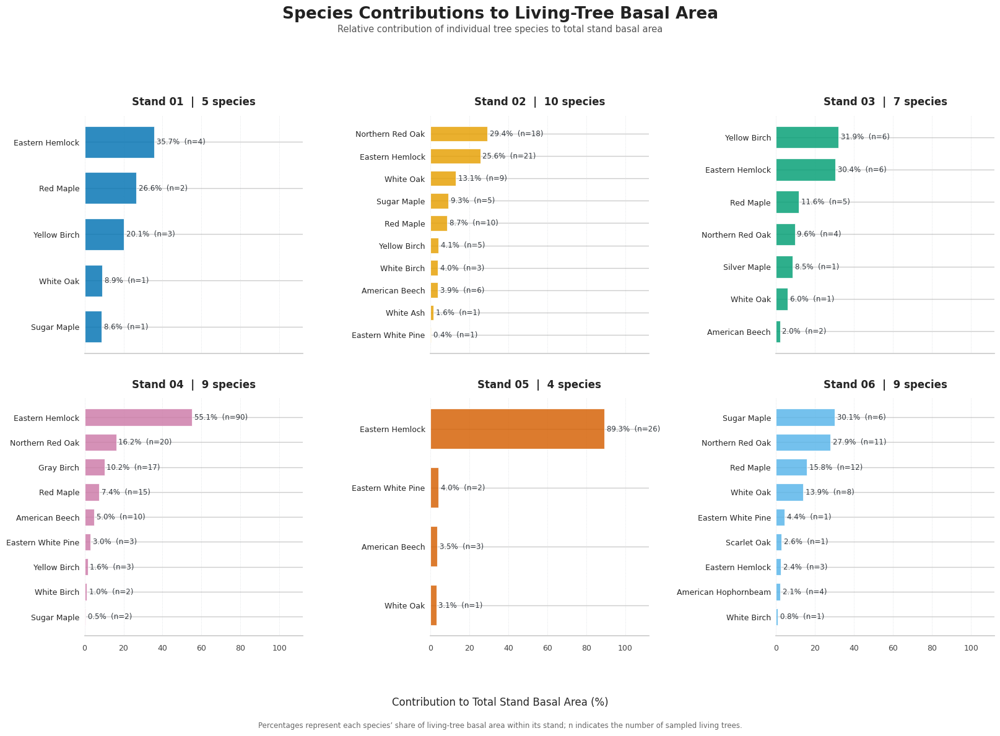

In [122]:

# STEP 109: Visualize species contributions to living-tree basal area.
#
# Figure design:
# - Six panels, one per forest stand.
# - Horizontal bars represent species contributions (%).
# - Species are ranked from lowest to highest within each panel.
# - Original stand-specific colors are preserved.
# - Each bar is annotated with its percentage and tree count.
#
# All 356 living trees are included.
# Percentages describe each species' contribution to the
# total living-tree basal area within its stand.

# ------------------------------------------------------------
# 1. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a two-row by three-column figure.
fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 12),
    sharex=True
)

# Flatten the axes array for easier iteration.
axes = axes.flatten()


# ------------------------------------------------------------
# 2. CREATE ONE SPECIES CONTRIBUTION PANEL PER STAND
# ------------------------------------------------------------

# Loop through each stand and its corresponding panel.
for stand, ax in zip(included_stands, axes):

    # Select species-level basal area results for the current stand.
    stand_data = species_basal_area_summary[
        species_basal_area_summary['Stand ID'] == stand
    ].copy()

    # Sort species from lowest to highest contribution.
    # This places the most important contributors at the top.
    stand_data = stand_data.sort_values(
        'Basal_Area_Percent',
        ascending=True
    )

    # Retrieve the established color for this stand.
    stand_color = stand_colors[stand]

    # Create horizontal positions for the species labels.
    y_positions = np.arange(len(stand_data))

    # --------------------------------------------------------
    # 2A. DRAW SPECIES CONTRIBUTION BARS
    # --------------------------------------------------------

    # Draw one horizontal bar for each species.
    bars = ax.barh(
        y_positions,
        stand_data['Basal_Area_Percent'],
        color=stand_color,
        alpha=0.82,
        edgecolor='white',
        linewidth=0.8,
        height=0.68,
        zorder=3
    )

    # --------------------------------------------------------
    # 2B. ANNOTATE PERCENTAGE AND TREE COUNT
    # --------------------------------------------------------

    # Add the percentage and number of trees beside each bar.
    for bar, (_, row) in zip(bars, stand_data.iterrows()):

        # Retrieve the bar's horizontal endpoint.
        bar_width = bar.get_width()

        # Position the annotation just beyond the bar.
        ax.text(
            bar_width + 1.2,
            bar.get_y() + bar.get_height() / 2,
            f"{row['Basal_Area_Percent']:.1f}%  (n={int(row['Tree_Count'])})",
            va='center',
            ha='left',
            fontsize=8.5,
            color='#343A40'
        )

    # --------------------------------------------------------
    # 2C. FORMAT SPECIES LABELS
    # --------------------------------------------------------

    # Use species names as the vertical-axis labels.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        stand_data['Species Name'],
        fontsize=9
    )

    # Add the stand identifier and number of species.
    ax.set_title(
        f"Stand {stand:02d}  |  {len(stand_data)} species",
        fontsize=12,
        fontweight='bold',
        pad=12,
        color='#252525'
    )

    # Set a consistent horizontal scale across all panels.
    ax.set_xlim(0, 112)

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.65,
        color='#BFC5CA',
        alpha=0.55
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Remove tick marks beside species labels.
    ax.tick_params(
        axis='y',
        length=0,
        pad=6
    )

    # Standardize horizontal-axis tick labels.
    ax.tick_params(
        axis='x',
        labelsize=9,
        colors='#444444'
    )


# ------------------------------------------------------------
# 3. ADD FIGURE TITLE AND SHARED AXIS LABEL
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Species Contributions to Living-Tree Basal Area',
    fontsize=19,
    fontweight='bold',
    color='#222222',
    y=0.98
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.945,
    'Relative contribution of individual tree species to total stand basal area',
    ha='center',
    fontsize=10.5,
    color='#555555'
)

# Add one shared horizontal-axis label.
fig.supxlabel(
    'Contribution to Total Stand Basal Area (%)',
    fontsize=12,
    fontweight='medium',
    y=0.035
)


# ------------------------------------------------------------
# 4. ADD A FIGURE FOOTNOTE
# ------------------------------------------------------------

# Clarify the meaning of percentages and sample sizes.
fig.text(
    0.5,
    0.008,
    'Percentages represent each species’ share of living-tree basal area within its stand; '
    'n indicates the number of sampled living trees.',
    ha='center',
    fontsize=8.5,
    color='#666666'
)


# ------------------------------------------------------------
# 5. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate species names and annotations.
plt.tight_layout(
    rect=[0.02, 0.065, 0.98, 0.91],
    h_pad=2.5,
    w_pad=2.0
)

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Species_Basal_Area_Contributions.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save the publication-quality PDF.
plt.savefig(
    export_dir / 'Species_Basal_Area_Contributions.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


In [123]:

# STEP 110: Inspect the variables available for relative
# species composition in the three vegetation layers.
#
# We will examine:
# 1. Living tree observations
# 2. Herbaceous vegetation observations
# 3. Regeneration observations
#
# The purpose is to identify whether each layer contains
# individual counts, cover measurements, or other variables
# that should determine how relative composition is calculated.

# ------------------------------------------------------------
# 1. INSPECT TREE SPECIES DATA
# ------------------------------------------------------------

# Display the available tree dataset columns.
print("TREE DATA COLUMNS:")
print(live_trees_analysis.columns.tolist())

# Display representative living-tree records.
display(live_trees_analysis.head(5))


# ------------------------------------------------------------
# 2. INSPECT HERBACEOUS SPECIES DATA
# ------------------------------------------------------------

# Display the available herbaceous dataset columns.
print("\nHERBACEOUS DATA COLUMNS:")
print(herbaceous_analysis.columns.tolist())

# Display representative herbaceous records.
display(herbaceous_analysis.head(5))


# ------------------------------------------------------------
# 3. INSPECT REGENERATION SPECIES DATA
# ------------------------------------------------------------

# Display the available regeneration dataset columns.
print("\nREGENERATION DATA COLUMNS:")
print(regeneration_analysis.columns.tolist())

# Display representative regeneration records.
display(regeneration_analysis.head(5))


TREE DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Tree ID', 'Species Code', 'Tree Status', 'DBH (in)', 'Estimated Tree Height (m)', 'Estimated Tree Height (ft)', 'Crown Class Code', 'Damage Type Code', 'Snag Decay Class (If Applicable)', 'Notes', 'Species Name', 'Tree Status Label', 'Calculated Height (ft)', 'Height Difference (ft)']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name,Tree Status Label,Calculated Height (ft),Height Difference (ft)
0,1,1,1,23-Oct,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.02,Dominant,NaN,NaN,NaN,Yellow Birch,Alive,82.02100,-0.00100
1,1,1,1,23-Oct,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.81,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive,32.80840,0.00160
2,1,1,1,23-Oct,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.04,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive,18.04462,-0.00462
3,1,1,1,23-Oct,"JW, JR, JM, HP",7.0,EH,AL,10.80,12.0,39.37,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive,39.37008,-0.00008
4,1,1,1,23-Oct,"JW, JR, JM, HP, EC, AB, LA, LW",8.0,YB,AL,11.99,10.5,34.45,Codominant,NaN,NaN,NaN,Yellow Birch,Alive,34.44882,0.00118



HERBACEOUS DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Invasive (Y/N)', 'General Phenological State', 'Damage Type Code', 'Percent Cover (%)', 'Notes', 'Unnamed: 11', 'Unnamed: 12', 'Species Name', 'Identification Status']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Invasive (Y/N),General Phenological State,Damage Type Code,Percent Cover (%),Notes,Unnamed: 11,Unnamed: 12,Species Name,Identification Status
0,1,1,1,23-Oct,"EC, HP, JM, LW, AB, JW, JR, LA",PRP,N,1,NaN,1,NaN,NaN,NaN,Princess Pine,Identified
1,1,1,1,23-Oct,"EC, HP, JM, LW, AB, JW, JR, LA",SF,N,1,NaN,1,NaN,NaN,NaN,Starflower,Identified
2,1,1,1,23-Oct,"EC, HP, JM, LW, AB, JW, JR, LA",XMF,N,1,NaN,1,NaN,NaN,NaN,Christmas Fern,Identified
3,1,1,1,23-Oct,"EC, HP, JM, LW, AB, JW, JR, LA",INT,N,1,NaN,1,NaN,NaN,NaN,Interrupted Fern,Identified
4,2,1,1,23-Oct,"AB, JR, EC, HP",PRP,N,1,NaN,1,NaN,NaN,NaN,Princess Pine,Identified



REGENERATION DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Microplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Seedling/Sapling?', 'Count', 'Damage Type Code', 'Notes', 'Species Name']


,Stand ID,Plot ID,Subplot ID,Microplot ID,Date,Team Member(s),Species ID,Seedling/Sapling?,Count,Damage Type Code,Notes,Species Name
0,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",AB,Seedling,2.0,40.0,NaN,American Beech
1,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",AB,Sapling,1.0,40.0,NaN,American Beech
2,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",YB,Sapling,1.0,NaN,NaN,Yellow Birch
3,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",EH,Seedling,1.0,NaN,NaN,Eastern Hemlock
4,2.0,1.0,1.0,1.0,23-Oct,"JM, LW, JW",WO,Sapling,3.0,NaN,NaN,White Oak


In [124]:

# STEP 111: Inspect herbaceous cover and regeneration counts.
#
# This step checks the measurement fields that will determine
# relative species composition in the herbaceous and regeneration layers.
#
# We will not modify or exclude any observations.

# ------------------------------------------------------------
# 1. INSPECT HERBACEOUS PERCENT COVER
# ------------------------------------------------------------

# Display the frequency of recorded herbaceous percent-cover values.
print("Herbaceous percent-cover values:")
display(
    herbaceous_analysis['Percent Cover (%)']
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('Percent Cover (%)')
    .reset_index(name='Number of Records')
)

# Count missing herbaceous cover measurements.
print(
    "\nMissing herbaceous cover measurements:",
    herbaceous_analysis['Percent Cover (%)'].isna().sum()
)

# Count total herbaceous records.
print(
    "Total herbaceous records:",
    len(herbaceous_analysis)
)


# ------------------------------------------------------------
# 2. INSPECT REGENERATION COUNTS
# ------------------------------------------------------------

# Display the frequency of recorded regeneration counts.
print("\nRegeneration count values:")
display(
    regeneration_analysis['Count']
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('Count')
    .reset_index(name='Number of Records')
)

# Count missing regeneration measurements.
print(
    "\nMissing regeneration counts:",
    regeneration_analysis['Count'].isna().sum()
)

# Count total regeneration records.
print(
    "Total regeneration records:",
    len(regeneration_analysis)
)


# ------------------------------------------------------------
# 3. INSPECT REGENERATION LIFE STAGES
# ------------------------------------------------------------

# Determine how regeneration observations are distributed
# between seedlings and saplings.
print("\nRegeneration life-stage records:")
display(
    regeneration_analysis['Seedling/Sapling?']
    .value_counts(dropna=False)
    .rename_axis('Life Stage')
    .reset_index(name='Number of Records')
)


# ------------------------------------------------------------
# 4. CHECK FOR MISSING SPECIES IDENTIFICATIONS
# ------------------------------------------------------------

# Check whether herbaceous species names are missing.
print(
    "\nHerbaceous records missing species names:",
    herbaceous_analysis['Species Name'].isna().sum()
)

# Check whether regeneration species names are missing.
print(
    "Regeneration records missing species names:",
    regeneration_analysis['Species Name'].isna().sum()
)


Herbaceous percent-cover values:


,Percent Cover (%),Number of Records
0,1,173
1,2,9
2,3,1



Missing herbaceous cover measurements: 0
Total herbaceous records: 183

Regeneration count values:


,Count,Number of Records
0,1.0,50
1,2.0,31
2,3.0,19
3,4.0,8
4,5.0,9
5,6.0,7
6,7.0,3
7,8.0,4
8,9.0,3
9,10.0,1



Missing regeneration counts: 0
Total regeneration records: 149

Regeneration life-stage records:


,Life Stage,Number of Records
0,Seedling,70
1,Sapling,35
2,Sapling,26
3,Seedling,18



Herbaceous records missing species names: 0
Regeneration records missing species names: 0


In [125]:

# STEP 112: Inspect woody-cover records and classification fields.
#
# This step identifies:
# - Available woody-cover variables
# - Species recorded in the dataset
# - Overstory and understory categories
# - Cover-class frequencies
# - Missing cover classifications
#
# No observations are modified or removed.

# ------------------------------------------------------------
# 1. INSPECT DATASET STRUCTURE
# ------------------------------------------------------------

# Display all available woody-cover columns.
print("WOODY COVER DATA COLUMNS:")
print(woody_cover_analysis.columns.tolist())

# Display the first ten woody-cover records.
display(woody_cover_analysis.head(10))


# ------------------------------------------------------------
# 2. IDENTIFY COVER CLASSIFICATION COLUMNS
# ------------------------------------------------------------

# Display the unique values in each column that may contain
# a vegetation layer or cover classification.
for column in woody_cover_analysis.columns:

    # Print unique values for columns with a manageable
    # number of distinct categories.
    if woody_cover_analysis[column].nunique(dropna=False) <= 20:

        print(f"\n{column}:")
        print(
            woody_cover_analysis[column]
            .value_counts(dropna=False)
        )


# ------------------------------------------------------------
# 3. INSPECT SPECIES REPRESENTATION
# ------------------------------------------------------------

# Count woody-cover records by species.
woody_cover_species = (
    woody_cover_analysis
    .groupby('Species Name')
    .size()
    .reset_index(name='Number of Records')
    .sort_values(
        'Number of Records',
        ascending=False
    )
)

# Display the species represented in the woody-cover dataset.
print("\nWoody-cover records by species:")
display(woody_cover_species)


# ------------------------------------------------------------
# 4. INSPECT COVER RECORDS BY STAND
# ------------------------------------------------------------

# Display the number of woody-cover records in each stand.
print("\nWoody-cover records by stand:")
display(
    woody_cover_analysis
    .groupby('Stand ID')
    .size()
    .reset_index(name='Number of Records')
)


# ------------------------------------------------------------
# 5. CHECK FOR MISSING SPECIES IDENTIFICATIONS
# ------------------------------------------------------------

# Count records without an identified species name.
print(
    "\nRecords missing species names:",
    woody_cover_analysis['Species Name'].isna().sum()
)


WOODY COVER DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Overstory Cover (%) Code', 'Understory Cover (%) Code', 'Notes', 'Species Name']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Overstory Cover (%) Code,Understory Cover (%) Code,Notes,Species Name
0,1,1,1,23-Oct,"EC, AB, JM, JW, JR, HP, LA, LW",EH,2,1,NaN,Eastern Hemlock
1,1,1,1,23-Oct,"EC, AB, JM, JW, JR, HP, LA, LW",RM,1,1,NaN,Red Maple
2,1,1,1,23-Oct,"EC, AB, JM, JW, JR, HP, LA, LW",AB,2,3,NaN,American Beech
3,1,1,1,23-Oct,"EC, AB, JM, JW, JR, HP, LA, LW",YB,1,1,NaN,Yellow Birch
4,1,1,1,23-Oct,"EC, AB, JM, JW, JR, HP, LA, LW",GB,1,2,NaN,Gray Birch
5,1,1,1,23-Oct,"EC, AB, JM, JW, JR, HP, LA, LW",AB,2,2,NaN,American Beech
6,2,1,1,23-Oct,"LW, JM, LA, JW",RO,1,1,NaN,Northern Red Oak
7,2,1,1,23-Oct,"LW, JM, LA, JW",WO,1,1,NaN,White Oak
8,2,1,1,23-Oct,"LW, JM, LA, JW",EH,1,1,NaN,Eastern Hemlock
9,2,1,2,23-Oct,"JW, JM, LW",WA,1,1,NaN,White Ash



Stand ID:
Stand ID
4    81
2    63
6    34
3    24
5     9
1     6
Name: count, dtype: int64

Plot ID:
Plot ID
1    128
2     63
3     13
4     13
Name: count, dtype: int64

Subplot ID:
Subplot ID
1     50
2     43
3     34
4     22
5     13
6     12
7     10
8     10
9      8
10     4
11     4
12     4
13     3
Name: count, dtype: int64

Date:
Date
6-Nov     51
30-Oct    47
4-Nov     34
11-Nov    34
23-Oct    20
28-Oct    18
5-Nov     13
Name: count, dtype: int64

Species ID:
Species ID
AB                      50
EH                      45
RO                      24
RM                      15
YB                      13
WP                      12
WO                      11
GB                      10
SM                       9
STM                      9
WA                       6
WB                       4
PB                       2
WH                       2
BTA                      1
Silver Maple             1
Ab                       1
American Hophornbeam     1
Scarlet Oak         

,Species Name,Number of Records
0,American Beech,51
3,Eastern Hemlock,45
6,Northern Red Oak,24
8,Red Maple,15
17,Yellow Birch,13
4,Eastern White Pine,12
15,White Oak,11
5,Gray Birch,10
12,Sugar Maple,9
11,Striped Maple,9



Woody-cover records by stand:


,Stand ID,Number of Records
0,1,6
1,2,63
2,3,24
3,4,81
4,5,9
5,6,34



Records missing species names: 0


In [126]:

# STEP 113: Summarize woody-cover classification by stand.
#
# We will calculate the distribution of the four cover classes
# separately for overstory and understory vegetation.
#
# Percentages represent the proportion of recorded woody-cover
# observations in each classification category within each stand.
#
# Cover codes are treated as ordinal categories, not continuous
# percentage measurements.

# ------------------------------------------------------------
# 1. DEFINE THE COVER CLASSIFICATION CATEGORIES
# ------------------------------------------------------------

# Define the four recorded cover classes in their proper order.
cover_classes = [1, 2, 3, 4]

# Define the two woody vegetation layers and their corresponding columns.
cover_columns = {
    'Overstory': 'Overstory Cover (%) Code',
    'Understory': 'Understory Cover (%) Code'
}


# ------------------------------------------------------------
# 2. CALCULATE COVER-CLASS FREQUENCIES BY STAND
# ------------------------------------------------------------

# Create an empty dictionary to store the frequency tables.
woody_cover_distributions = {}

# Loop through overstory and understory cover classifications.
for layer, column in cover_columns.items():

    # Count the number of records in each cover class within
    # each stand.
    class_counts = pd.crosstab(
        woody_cover_analysis['Stand ID'],
        woody_cover_analysis[column]
    )

    # Ensure all four cover classes appear in the table,
    # even if a stand has no records in a particular class.
    class_counts = class_counts.reindex(
        columns=cover_classes,
        fill_value=0
    )

    # Rename the columns to identify the cover class.
    class_counts.columns = [
        f'Class {category}'
        for category in cover_classes
    ]

    # Calculate the percentage of observations in each class
    # within each stand.
    class_percentages = (
        class_counts
        .div(class_counts.sum(axis=1), axis=0)
        * 100
    )

    # Store both counts and percentages for later use.
    woody_cover_distributions[layer] = {
        'counts': class_counts,
        'percentages': class_percentages
    }

    # --------------------------------------------------------
    # 2A. DISPLAY FREQUENCY TABLES
    # --------------------------------------------------------

    print(f"\n{layer.upper()} COVER CLASS COUNTS:")
    display(class_counts)

    print(f"\n{layer.upper()} COVER CLASS DISTRIBUTION (%):")
    display(class_percentages.round(1))


# ------------------------------------------------------------
# 3. INSPECT THE RECORD WITH THE OVERSTORY NOTE
# ------------------------------------------------------------

# Find woody-cover observations with a note indicating
# that no overstory was present.
overstory_note_records = woody_cover_analysis[
    woody_cover_analysis['Notes']
    .astype(str)
    .str.contains('None in overstory', case=False, na=False)
]

# Display the complete records for review.
print("\nRecords noting no overstory:")
display(overstory_note_records)


# ------------------------------------------------------------
# 4. CHECK FOR UNRESOLVED SPECIES LABELS
# ------------------------------------------------------------

# Display species names that occur in the woody-cover dataset.
print("\nSpecies names requiring identification review:")
display(
    woody_cover_analysis['Species Name']
    .value_counts()
    .loc[lambda counts: counts.index.isin(['PB'])]
)



OVERSTORY COVER CLASS COUNTS:


,Class 1,Class 2,Class 3,Class 4
Stand ID,,,,
1,3,3,0,0
2,46,15,1,1
3,15,8,0,1
4,38,24,16,3
5,5,2,0,2
6,24,10,0,0



OVERSTORY COVER CLASS DISTRIBUTION (%):


,Class 1,Class 2,Class 3,Class 4
Stand ID,,,,
1,50.0,50.0,0.0,0.0
2,73.0,23.8,1.6,1.6
3,62.5,33.3,0.0,4.2
4,46.9,29.6,19.8,3.7
5,55.6,22.2,0.0,22.2
6,70.6,29.4,0.0,0.0



UNDERSTORY COVER CLASS COUNTS:


,Class 1,Class 2,Class 3,Class 4
Stand ID,,,,
1,3,2,1,0
2,40,20,2,1
3,18,3,3,0
4,56,11,9,5
5,4,2,2,1
6,27,4,3,0


... (2 outputs left out)


Records noting no overstory:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Overstory Cover (%) Code,Understory Cover (%) Code,Notes,Species Name
34,2,2,3,28-Oct,AB,EH,1,2,None in overstory,Eastern Hemlock



Species names requiring identification review:


,count
Species Name,
PB,2


In [127]:

# STEP 114: Create percentage-range labels for woody cover classes.
#
# The original numeric cover codes are preserved.
# New categorical columns are created for visualization.
#
# These are classification ranges, not exact measured
# percentage-cover values.

# ------------------------------------------------------------
# 1. DEFINE THE COVER CLASSIFICATION KEY
# ------------------------------------------------------------

# Map each original cover code to its corresponding percentage range.
cover_range_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Define the desired order of the percentage-range categories.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]


# ------------------------------------------------------------
# 2. CREATE READABLE OVERSTORY COVER LABELS
# ------------------------------------------------------------

# Convert overstory cover codes into percentage-range labels.
woody_cover_analysis['Overstory Cover Range'] = (
    woody_cover_analysis['Overstory Cover (%) Code']
    .map(cover_range_labels)
)

# Set the labels as an ordered categorical variable.
woody_cover_analysis['Overstory Cover Range'] = pd.Categorical(
    woody_cover_analysis['Overstory Cover Range'],
    categories=cover_range_order,
    ordered=True
)


# ------------------------------------------------------------
# 3. CREATE READABLE UNDERSTORY COVER LABELS
# ------------------------------------------------------------

# Convert understory cover codes into percentage-range labels.
woody_cover_analysis['Understory Cover Range'] = (
    woody_cover_analysis['Understory Cover (%) Code']
    .map(cover_range_labels)
)

# Set the labels as an ordered categorical variable.
woody_cover_analysis['Understory Cover Range'] = pd.Categorical(
    woody_cover_analysis['Understory Cover Range'],
    categories=cover_range_order,
    ordered=True
)


# ------------------------------------------------------------
# 4. VERIFY THE CONVERSION
# ------------------------------------------------------------

# Display original codes alongside their new percentage ranges.
display(
    woody_cover_analysis[
        [
            'Stand ID',
            'Species Name',
            'Overstory Cover (%) Code',
            'Overstory Cover Range',
            'Understory Cover (%) Code',
            'Understory Cover Range'
        ]
    ].head(15)
)

# Confirm that all records received a valid classification label.
print(
    "\nMissing overstory range labels:",
    woody_cover_analysis['Overstory Cover Range'].isna().sum()
)

print(
    "Missing understory range labels:",
    woody_cover_analysis['Understory Cover Range'].isna().sum()
)


,Stand ID,Species Name,Overstory Cover (%) Code,Overstory Cover Range,Understory Cover (%) Code,Understory Cover Range
0,1,Eastern Hemlock,2,25–50%,1,0–25%
1,1,Red Maple,1,0–25%,1,0–25%
2,1,American Beech,2,25–50%,3,50–75%
3,1,Yellow Birch,1,0–25%,1,0–25%
4,1,Gray Birch,1,0–25%,2,25–50%
5,1,American Beech,2,25–50%,2,25–50%
6,2,Northern Red Oak,1,0–25%,1,0–25%
7,2,White Oak,1,0–25%,1,0–25%
8,2,Eastern Hemlock,1,0–25%,1,0–25%
9,2,White Ash,1,0–25%,1,0–25%



Missing overstory range labels: 0
Missing understory range labels: 0


In [128]:

# STEP 115: Correct the unresolved PB species abbreviation.
#
# Based on your identification, PB represents White Birch.
# This updates the working analysis dataset without changing
# the original woody_cover source DataFrame.

# Replace PB with White Birch in the analysis dataset.
woody_cover_analysis['Species Name'] = (
    woody_cover_analysis['Species Name']
    .replace({'PB': 'White Birch'})
)

# Verify the correction.
print("Updated species counts:")
display(woody_cover_analysis['Species Name'].value_counts())

# Confirm that no PB records remain.
print(
    "\nRemaining PB records:",
    (woody_cover_analysis['Species Name'] == 'PB').sum()
)

# Display the corrected White Birch records.
display(
    woody_cover_analysis[
        woody_cover_analysis['Species Name'] == 'White Birch'
    ]
)


Updated species counts:


,count
Species Name,
American Beech,51
Eastern Hemlock,45
Northern Red Oak,24
Red Maple,15
Yellow Birch,13
Eastern White Pine,12
White Oak,11
Gray Birch,10
Sugar Maple,9



Remaining PB records: 0


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Overstory Cover (%) Code,Understory Cover (%) Code,Notes,Species Name,Overstory Cover Range,Understory Cover Range
13,2,1,3,23-Oct,"JW, JM, LW",PB,1,1,NaN,White Birch,0–25%,0–25%
25,2,2,2,28-Oct,AB,WB,1,1,NaN,White Birch,0–25%,0–25%
59,2,4,1,5-Nov,"KC, LW, JW",PB,1,1,NaN,White Birch,0–25%,0–25%
87,3,2,1,6-Nov,"JW, JM",WB,1,1,NaN,White Birch,0–25%,0–25%
99,4,1,2,30-Oct,"JW, LW, LA",WB,2,2,NaN,White Birch,25–50%,25–50%
212,6,1,6,11-Nov,"JM, LW, JW",WB,1,1,NaN,White Birch,0–25%,0–25%


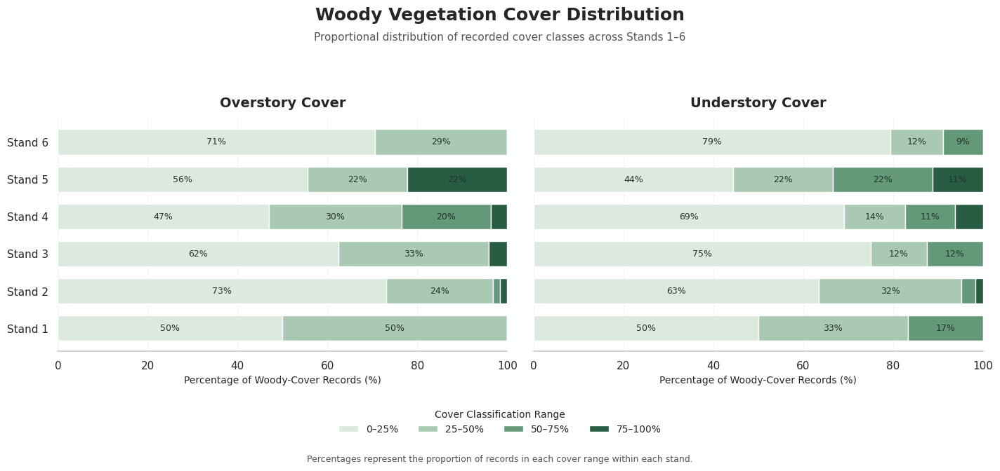

In [129]:

# STEP 116: Create a two-panel figure comparing overstory
# and understory cover-class distributions across six stands.
#
# Each horizontal bar represents 100% of the woody-cover
# observations recorded within a stand.
#
# The four segments represent the percentage of records
# classified within each cover range.
#
# IMPORTANT:
# These values describe the distribution of recorded cover
# classifications. They are not estimates of total canopy
# cover across the stand.

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. DEFINE THE COVER CLASSIFICATION AND COLORS
# ------------------------------------------------------------

# Establish the four percentage-range categories in order.
cover_range_order = ['0–25%', '25–50%', '50–75%', '75–100%']

# Assign a progressively darker color to higher cover classes.
# These colors distinguish cover ranges rather than stands.
cover_range_colors = {
    '0–25%': '#DCE9DF',
    '25–50%': '#A9C9B2',
    '50–75%': '#639879',
    '75–100%': '#285C43'
}

# Define the six stands in numerical order.
stand_order = [1, 2, 3, 4, 5, 6]


# ------------------------------------------------------------
# 2. CALCULATE THE DISTRIBUTIONS FROM THE CURRENT DATA
# ------------------------------------------------------------

# Recalculate distributions using the updated analysis dataset.
# This ensures the figure reflects the current working data.
cover_distribution = {}

for layer, column in {
    'Overstory': 'Overstory Cover Range',
    'Understory': 'Understory Cover Range'
}.items():

    # Count records in each cover range for every stand.
    counts = pd.crosstab(
        woody_cover_analysis['Stand ID'],
        woody_cover_analysis[column]
    )

    # Ensure all stands and cover ranges are represented.
    counts = counts.reindex(
        index=stand_order,
        columns=cover_range_order,
        fill_value=0
    )

    # Convert counts into percentages within each stand.
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    # Store the percentage distributions for plotting.
    cover_distribution[layer] = percentages


# ------------------------------------------------------------
# 3. CREATE THE TWO-PANEL FIGURE
# ------------------------------------------------------------

# Create two side-by-side panels with a shared horizontal axis.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6.8),
    sharey=True
)

# Set the overall figure title.
fig.suptitle(
    'Woody Vegetation Cover Distribution',
    fontsize=18,
    fontweight='bold',
    y=0.98
)

# Define the two vegetation layers and their corresponding axes.
layers = ['Overstory', 'Understory']

for ax, layer in zip(axes, layers):

    # Retrieve the stand-level percentage distribution.
    percentages = cover_distribution[layer]

    # Initialize the left position of each stacked bar.
    left_positions = np.zeros(len(stand_order))

    # Add one horizontal segment for each cover range.
    for cover_range in cover_range_order:

        # Retrieve the percentage values for this cover range.
        values = percentages[cover_range].to_numpy()

        # Draw the stacked horizontal bars.
        bars = ax.barh(
            stand_order,
            values,
            left=left_positions,
            height=0.68,
            color=cover_range_colors[cover_range],
            edgecolor='white',
            linewidth=1.0,
            label=cover_range
        )

        # Add percentage labels when a segment is large enough.
        for bar, value in zip(bars, values):

            if value >= 8:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.0f}%',
                    ha='center',
                    va='center',
                    fontsize=9,
                    color='#26332B',
                    fontweight='medium'
                )

        # Move the next segment to the right of this one.
        left_positions += values

    # Format the panel title and axes.
    ax.set_title(
        f'{layer} Cover',
        fontsize=14,
        fontweight='bold',
        pad=12
    )

    ax.set_xlabel(
        'Percentage of Woody-Cover Records (%)',
        fontsize=10
    )

    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.set_yticks(stand_order)
    ax.set_yticklabels([f'Stand {stand}' for stand in stand_order])

    # Put Stand 1 at the top of each panel.
    ax.invert_yaxis()

    # Use subtle vertical gridlines to aid comparisons.
    ax.set_axisbelow(True)
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.35
    )

    # Remove unnecessary plot borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)


# ------------------------------------------------------------
# 4. ADD A SHARED LEGEND AND FIGURE NOTES
# ------------------------------------------------------------

# Create one shared legend for both panels.
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Cover Classification Range',
    loc='lower center',
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.065),
    fontsize=10,
    title_fontsize=10
)

# Add a subtitle explaining the comparison.
fig.text(
    0.5,
    0.91,
    'Proportional distribution of recorded cover classes across Stands 1–6',
    ha='center',
    fontsize=11,
    color='#555555'
)

# Add a note clarifying the interpretation.
fig.text(
    0.5,
    0.025,
    'Percentages represent the proportion of records in each cover range within each stand.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# Adjust spacing to accommodate the title, legend, and note.
plt.tight_layout(rect=[0.02, 0.16, 0.98, 0.88])

# ------------------------------------------------------------
# 5. SAVE AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
plt.savefig(
    export_dir / 'Woody_Cover_Distributions.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a vector PDF for publication-quality use.
plt.savefig(
    export_dir / 'Woody_Cover_Distributions.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()



OVERSTORY SPECIES-LEVEL COVER DISTRIBUTION (%)


Overstory Cover Range          0–25%  25–50%  50–75%  75–100%
Stand ID Species Name                                        
1        American Beech          0.0   100.0     0.0      0.0
         American Hophornbeam    NaN     NaN     NaN      NaN
         Bigtooth Aspen          NaN     NaN     NaN      NaN
         Eastern Hemlock         0.0   100.0     0.0      0.0
         Eastern White Pine      NaN     NaN     NaN      NaN
...                              ...     ...     ...      ...
6        White Ash             100.0     0.0     0.0      0.0
         White Birch           100.0     0.0     0.0      0.0
         White Oak              75.0    25.0     0.0      0.0
         Witch-hazel           100.0     0.0     0.0      0.0
         Yellow Birch            NaN     NaN     NaN      NaN

[102 rows x 4 columns]


UNDERSTORY SPECIES-LEVEL COVER DISTRIBUTION (%)


Understory Cover Range         0–25%  25–50%  50–75%  75–100%
Stand ID Species Name                                        
1        American Beech          0.0    50.0    50.0      0.0
         American Hophornbeam    NaN     NaN     NaN      NaN
         Bigtooth Aspen          NaN     NaN     NaN      NaN
         Eastern Hemlock       100.0     0.0     0.0      0.0
         Eastern White Pine      NaN     NaN     NaN      NaN
...                              ...     ...     ...      ...
6        White Ash             100.0     0.0     0.0      0.0
         White Birch           100.0     0.0     0.0      0.0
         White Oak             100.0     0.0     0.0      0.0
         Witch-hazel           100.0     0.0     0.0      0.0
         Yellow Birch            NaN     NaN     NaN      NaN

[102 rows x 4 columns]

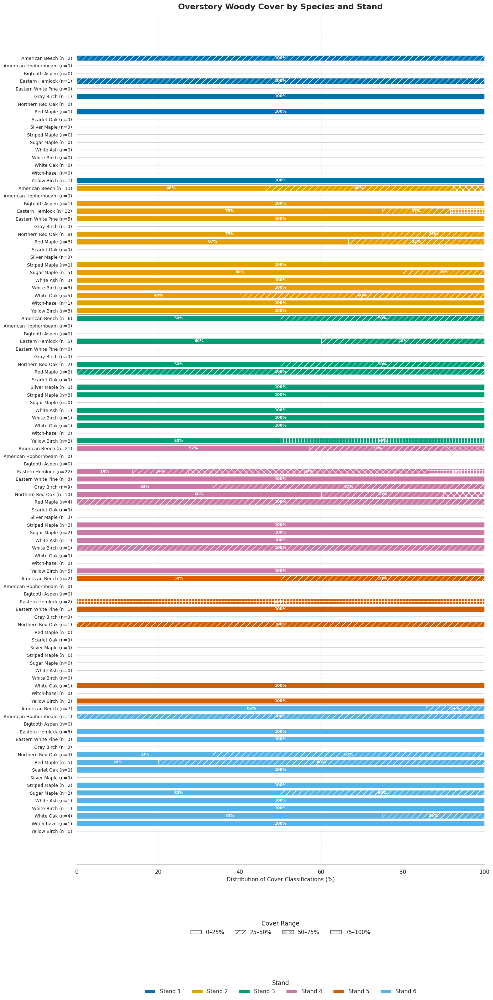

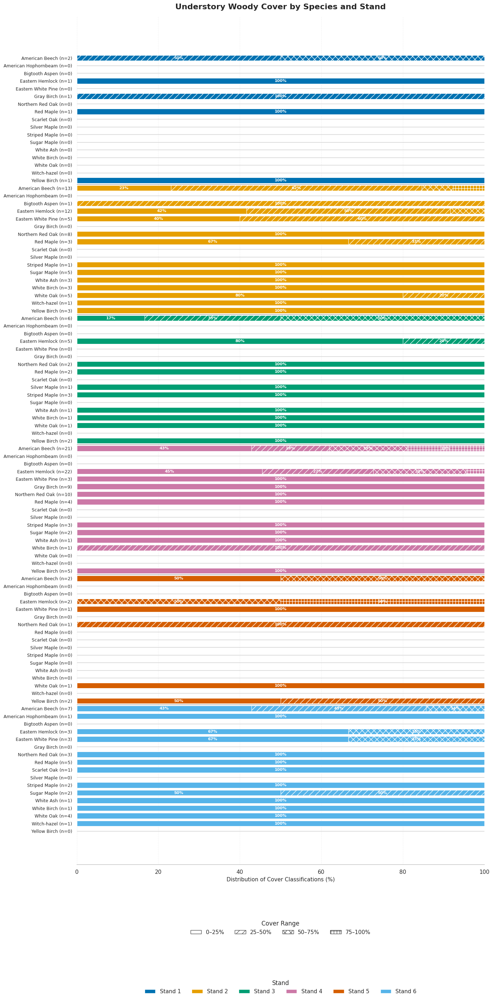

In [130]:

# STEP 116: Calculate and visualize woody cover distributions
# separately for each species within each stand.
#
# Each species will have its own 100% stacked bar.
# Segment widths represent the proportion of that species'
# woody-cover records assigned to each cover range.
#
# Overstory and understory will be displayed separately.
# The original six-stand color scheme is retained.

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. DEFINE THE ORIGINAL STAND COLOR SCHEME
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Define the four percentage-cover ranges in their
# correct ordinal order.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

# Define hatch patterns to distinguish the four ranges.
cover_hatches = {
    '0–25%': '',
    '25–50%': '//',
    '50–75%': 'xx',
    '75–100%': '++'
}

# ------------------------------------------------------------
# 2. CALCULATE SPECIES-LEVEL COVER DISTRIBUTIONS
# ------------------------------------------------------------

# Create a dictionary to store the results for each layer.
species_cover_distributions = {}

# Analyze overstory and understory independently.
cover_columns = {
    'Overstory': 'Overstory Cover Range',
    'Understory': 'Understory Cover Range'
}

for layer, column in cover_columns.items():

    # Count records for each species, stand, and cover range.
    counts = (
        woody_cover_analysis
        .groupby(
            ['Stand ID', 'Species Name', column],
            observed=False
        )
        .size()
        .unstack(column, fill_value=0)
    )

    # Ensure all four cover ranges appear in the results.
    counts = counts.reindex(
        columns=cover_range_order,
        fill_value=0
    )

    # Calculate the total number of records for each
    # species within each stand.
    species_totals = counts.sum(axis=1)

    # Convert counts to percentages within each
    # species-and-stand combination.
    percentages = counts.div(species_totals, axis=0) * 100

    # Store both the raw counts and percentages.
    species_cover_distributions[layer] = {
        'counts': counts,
        'percentages': percentages
    }

    # Display the resulting table for inspection.
    print(f'\n{layer.upper()} SPECIES-LEVEL COVER DISTRIBUTION (%)')
    display(percentages.round(1))


# ------------------------------------------------------------
# 3. CREATE SPECIES-LEVEL FIGURES
# ------------------------------------------------------------

# Create one figure for overstory and one for understory.
for layer in ['Overstory', 'Understory']:

    # Retrieve the species-level percentage table.
    percentages = species_cover_distributions[layer]['percentages']

    # Retrieve the corresponding raw counts.
    counts = species_cover_distributions[layer]['counts']

    # Build a plotting table with stand and species labels.
    plot_data = percentages.reset_index()

    # Sort species within each stand alphabetically.
    plot_data = plot_data.sort_values(
        ['Stand ID', 'Species Name']
    ).reset_index(drop=True)

    # Assign one horizontal position to each species record.
    y_positions = np.arange(len(plot_data))

    # Create a figure tall enough to display all species.
    fig_height = max(8, len(plot_data) * 0.32)

    fig, ax = plt.subplots(
        figsize=(14, fig_height)
    )

    # --------------------------------------------------------
    # 4. DRAW THE STACKED BARS
    # --------------------------------------------------------

    # Draw one bar for each species within each stand.
    for position, row in plot_data.iterrows():

        # Identify the stand for the current species.
        stand = row['Stand ID']

        # Track the left edge of each stacked segment.
        left_position = 0

        # Draw each cover-range segment.
        for cover_range in cover_range_order:

            # Retrieve the percentage for this species,
            # stand, and cover classification.
            value = row[cover_range]

            # Draw the segment using the established
            # color assigned to its stand.
            ax.barh(
                position,
                value,
                left=left_position,
                height=0.72,
                color=stand_colors[stand],
                edgecolor='white',
                linewidth=0.8,
                hatch=cover_hatches[cover_range]
            )

            # Label segments that are large enough.
            if value >= 12:
                ax.text(
                    left_position + value / 2,
                    position,
                    f'{value:.0f}%',
                    ha='center',
                    va='center',
                    fontsize=8,
                    color='white',
                    fontweight='bold'
                )

            # Advance the starting position.
            left_position += value

    # --------------------------------------------------------
    # 5. FORMAT SPECIES LABELS AND STAND SEPARATORS
    # --------------------------------------------------------

    # Create labels combining species name and sample size.
    species_labels = []

    for _, row in plot_data.iterrows():

        # Retrieve the stand and species name.
        stand = row['Stand ID']
        species = row['Species Name']

        # Retrieve the number of observations supporting
        # this species-level distribution.
        n_records = int(
            counts.loc[(stand, species)].sum()
        )

        species_labels.append(
            f'{species} (n={n_records})'
        )

    # Assign species labels to the vertical axis.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(species_labels, fontsize=9)

    # Reverse the vertical axis so the first stand appears
    # at the top.
    ax.invert_yaxis()

    # Add separators between stand groups.
    for position in range(1, len(plot_data)):

        # Identify whether the stand changes at this position.
        if (
            plot_data.loc[position, 'Stand ID']
            != plot_data.loc[position - 1, 'Stand ID']
        ):
            ax.axhline(
                position - 0.5,
                color='#555555',
                linewidth=1.0,
                alpha=0.6
            )

    # Add stand labels along the right side of the figure.
    stand_midpoints = []

    for stand in sorted(plot_data['Stand ID'].unique()):

        # Find the vertical positions belonging to this stand.
        positions = np.where(
            plot_data['Stand ID'].to_numpy() == stand
        )[0]

        # Calculate the midpoint of the stand's species group.
        midpoint = (positions.min() + positions.max()) / 2

        stand_midpoints.append((stand, midpoint))

    # Format the main axis.
    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.set_xlabel(
        'Distribution of Cover Classifications (%)',
        fontsize=11
    )

    ax.set_title(
        f'{layer} Woody Cover by Species and Stand',
        fontsize=16,
        fontweight='bold',
        pad=15
    )

    # Add subtle vertical gridlines.
    ax.set_axisbelow(True)
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # --------------------------------------------------------
    # 6. ADD LEGENDS
    # --------------------------------------------------------

    # Create a legend for the four cover classifications.
    cover_legend = [
        Patch(
            facecolor='white',
            edgecolor='#555555',
            hatch=cover_hatches[cover_range],
            label=cover_range
        )
        for cover_range in cover_range_order
    ]

    # Create a legend for the six stand colors.
    stand_legend = [
        Patch(
            facecolor=stand_colors[stand],
            label=f'Stand {stand}'
        )
        for stand in sorted(stand_colors)
    ]

    # Place the legends below the figure.
    first_legend = ax.legend(
        handles=cover_legend,
        title='Cover Range',
        loc='upper center',
        bbox_to_anchor=(0.5, -0.06),
        ncol=4,
        frameon=False
    )

    ax.add_artist(first_legend)

    ax.legend(
        handles=stand_legend,
        title='Stand',
        loc='upper center',
        bbox_to_anchor=(0.5, -0.13),
        ncol=6,
        frameon=False
    )

    # Adjust spacing for the long species labels and legends.
    plt.tight_layout(rect=[0, 0.13, 1, 1])

    # Save the figure as a high-resolution PNG.
    plt.savefig(
        export_dir / f'{layer}_Woody_Cover_by_Species.png',
        dpi=400,
        bbox_inches='tight'
    )

    # Save a vector PDF.
    plt.savefig(
        export_dir / f'{layer}_Woody_Cover_by_Species.pdf',
        bbox_inches='tight'
    )

    # Display the figure.
    plt.show()


In [133]:

# STEP 120: Combine woody-cover classifications for species-level analysis.
#
# Overstory and understory are not separated because the available
# records do not provide a sufficiently reliable basis for
# distinguishing the two vegetation layers.
#
# Both original cover-code columns are retained.
# Each valid classification is counted as one observation.
# No averages, interpolated percentages, or new classes are created.

# ------------------------------------------------------------
# 1. COMBINE THE TWO COVER CLASSIFICATION COLUMNS
# ------------------------------------------------------------

# Copy the working woody-cover dataset so the original data
# and its two separate cover columns remain unchanged.
combined_woody_cover = woody_cover_analysis.copy()

# Convert the overstory codes into a common analysis column.
overstory_records = combined_woody_cover[
    ['Stand ID', 'Species Name', 'Overstory Cover (%) Code']
].copy()

overstory_records = overstory_records.rename(
    columns={'Overstory Cover (%) Code': 'Cover Code'}
)

# Identify the source of each original observation.
overstory_records['Source Column'] = 'Overstory field'

# Convert the understory codes into the same common structure.
understory_records = combined_woody_cover[
    ['Stand ID', 'Species Name', 'Understory Cover (%) Code']
].copy()

understory_records = understory_records.rename(
    columns={'Understory Cover (%) Code': 'Cover Code'}
)

understory_records['Source Column'] = 'Understory field'

# Combine the two sets of observations.
combined_woody_cover_records = pd.concat(
    [overstory_records, understory_records],
    ignore_index=True
)

# Retain only records with a valid species and cover code.
combined_woody_cover_records = (
    combined_woody_cover_records
    .dropna(subset=['Stand ID', 'Species Name', 'Cover Code'])
    .copy()
)

# Convert the cover codes to integers for consistent counting.
combined_woody_cover_records['Cover Code'] = (
    combined_woody_cover_records['Cover Code'].astype(int)
)

# ------------------------------------------------------------
# 2. ASSIGN THE ORIGINAL FOUR CLASSIFICATION LABELS
# ------------------------------------------------------------

# Map the original numeric codes to their classification ranges.
cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Add readable classification labels without changing the codes.
combined_woody_cover_records['Cover Classification'] = (
    combined_woody_cover_records['Cover Code']
    .map(cover_class_labels)
)

# Define the classification order.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

# ------------------------------------------------------------
# 3. COUNT CLASSIFICATIONS BY SPECIES AND STAND
# ------------------------------------------------------------

# Count the number of observations in each cover class
# for each species within each stand.
species_cover_counts = pd.crosstab(
    [
        combined_woody_cover_records['Stand ID'],
        combined_woody_cover_records['Species Name']
    ],
    combined_woody_cover_records['Cover Classification']
)

# Ensure that all four original classifications are present.
species_cover_counts = species_cover_counts.reindex(
    columns=cover_range_order,
    fill_value=0
)

# Remove species with no observations.
species_cover_counts = species_cover_counts.loc[
    species_cover_counts.sum(axis=1) > 0
]

# ------------------------------------------------------------
# 4. DISPLAY THE SPECIES-RESOLVED RESULTS
# ------------------------------------------------------------

print('COMBINED WOODY COVER CLASSIFICATION COUNTS')

display(species_cover_counts)

# Display the total number of records contributing to
# each species-level distribution.
species_cover_sample_sizes = species_cover_counts.sum(axis=1)

print('\nTOTAL OBSERVATIONS BY SPECIES AND STAND')

display(species_cover_sample_sizes.rename('Number of Records').to_frame())

# Verify the total number of observations included.
print(
    '\nTotal combined cover observations:',
    len(combined_woody_cover_records)
)


COMBINED WOODY COVER CLASSIFICATION COUNTS


Cover Classification           0–25%  25–50%  50–75%  75–100%
Stand ID Species Name                                        
1        American Beech            0       3       1        0
         Eastern Hemlock           1       1       0        0
         Gray Birch                1       1       0        0
         Red Maple                 2       0       0        0
         Yellow Birch              2       0       0        0
2        American Beech            9      14       2        1
         Bigtooth Aspen            1       1       0        0
         Eastern Hemlock          14       8       1        1
         Eastern White Pine        7       3       0        0
         Northern Red Oak         14       2       0        0
         Red Maple                 4       2       0        0
         Striped Maple             2       0       0        0
         Sugar Maple               9       1       0        0
         White Ash                 6       0       0        0
         White Birch               6       0       0        0
         White Oak                 6       4       0        0
         Witch-hazel               2       0       0        0
         Yellow Birch              6       0       0        0
3        American Beech            4       5       3        0
         Eastern Hemlock           7       3       0        0
         Northern Red Oak          3       1       0        0
         Red Maple                 2       2       0        0
         Silver Maple              2       0       0        0
         Striped Maple             6       0       0        0
         White Ash                 2       0       0        0
         White Birch               2       0       0        0
         White Oak                 2       0       0        0
         Yellow Birch              3       0       0        1
4        American Beech           21      11       6        4
         Eastern Hemlock          13       9      18        4
         Eastern White Pine        6       0       0        0
         Gray Birch               12       6       0        0
         Northern Red Oak         16       3       1        0
         Red Maple                 4       4       0        0
         Striped Maple             6       0       0        0
         Sugar Maple               4       0       0        0
         White Ash                 2       0       0        0
         White Birch               0       2       0        0
         Yellow Birch             10       0       0        0
5        American Beech            2       1       1        0
         Eastern Hemlock           0       0       1        3
         Eastern White Pine        2       0       0        0
         Northern Red Oak          0       2       0        0
         White Oak                 2       0       0        0
         Yellow Birch              3       1       0        0
6        American Beech            9       4       1        0
         American Hophornbeam      1       1       0        0
         Eastern Hemlock           5       0       1        0
         Eastern White Pine        5       0       1        0
         Northern Red Oak          4       2       0        0
         Red Maple                 6       4       0        0
         Scarlet Oak               2       0       0        0
         Striped Maple             4       0       0        0
         Sugar Maple               2       2       0        0
         White Ash                 2       0       0        0
         White Birch               2       0       0        0
         White Oak                 7       1       0        0
         Witch-hazel               2       0       0        0


TOTAL OBSERVATIONS BY SPECIES AND STAND


Number of Records
Stand ID Species Name                           
1        American Beech                        4
         Eastern Hemlock                       2
         Gray Birch                            2
         Red Maple                             2
         Yellow Birch                          2
2        American Beech                       26
         Bigtooth Aspen                        2
         Eastern Hemlock                      24
         Eastern White Pine                   10
         Northern Red Oak                     16
         Red Maple                             6
         Striped Maple                         2
         Sugar Maple                          10
         White Ash                             6
         White Birch                           6
         White Oak                            10
         Witch-hazel                           2
         Yellow Birch                          6
3        American Beech                       12
         Eastern Hemlock                      10
         Northern Red Oak                      4
         Red Maple                             4
         Silver Maple                          2
         Striped Maple                         6
         White Ash                             2
         White Birch                           2
         White Oak                             2
         Yellow Birch                          4
4        American Beech                       42
         Eastern Hemlock                      44
         Eastern White Pine                    6
         Gray Birch                           18
         Northern Red Oak                     20
         Red Maple                             8
         Striped Maple                         6
         Sugar Maple                           4
         White Ash                             2
         White Birch                           2
         Yellow Birch                         10
5        American Beech                        4
         Eastern Hemlock                       4
         Eastern White Pine                    2
         Northern Red Oak                      2
         White Oak                             2
         Yellow Birch                          4
6        American Beech                       14
         American Hophornbeam                  2
         Eastern Hemlock                       6
         Eastern White Pine                    6
         Northern Red Oak                      6
         Red Maple                            10
         Scarlet Oak                           2
         Striped Maple                         4
         Sugar Maple                           4
         White Ash                             2
         White Birch                           2
         White Oak                             8
         Witch-hazel                           2


Total combined cover observations: 434


In [134]:

# STEP 121: Convert original woody-cover codes into percentage ranges.
#
# Combine the two cover fields into one species-level dataset.
# Preserve each original observation and its assigned classification.
# Do not calculate averages or new percentage values.

# ------------------------------------------------------------
# 1. DEFINE THE ORIGINAL CLASSIFICATION KEY
# ------------------------------------------------------------

cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# ------------------------------------------------------------
# 2. CONVERT OVERSTORY RECORDS
# ------------------------------------------------------------

# Select the stand, species, and original overstory code.
overstory_records = woody_cover_analysis[
    ['Stand ID', 'Species Name', 'Overstory Cover (%) Code']
].copy()

# Rename the cover field so it can be combined with understory.
overstory_records = overstory_records.rename(
    columns={'Overstory Cover (%) Code': 'Cover Code'}
)

# Convert numeric codes into their actual percentage ranges.
overstory_records['Cover Classification'] = (
    overstory_records['Cover Code'].map(cover_class_labels)
)

# ------------------------------------------------------------
# 3. CONVERT UNDERSTORY RECORDS
# ------------------------------------------------------------

# Select the stand, species, and original understory code.
understory_records = woody_cover_analysis[
    ['Stand ID', 'Species Name', 'Understory Cover (%) Code']
].copy()

# Use the same column name as the overstory records.
understory_records = understory_records.rename(
    columns={'Understory Cover (%) Code': 'Cover Code'}
)

# Convert numeric codes into their actual percentage ranges.
understory_records['Cover Classification'] = (
    understory_records['Cover Code'].map(cover_class_labels)
)

# ------------------------------------------------------------
# 4. COMBINE THE TWO SETS OF CLASSIFICATIONS
# ------------------------------------------------------------

# Retain one row per original cover-field observation.
combined_woody_cover = pd.concat(
    [
        overstory_records,
        understory_records
    ],
    ignore_index=True
)

# Remove records without a species or valid classification.
combined_woody_cover = combined_woody_cover.dropna(
    subset=['Stand ID', 'Species Name', 'Cover Classification']
).copy()

# Define the classification order from lowest to highest cover.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

# Make the classifications ordered categories.
combined_woody_cover['Cover Classification'] = pd.Categorical(
    combined_woody_cover['Cover Classification'],
    categories=cover_range_order,
    ordered=True
)

# ------------------------------------------------------------
# 5. SUMMARIZE CLASSIFICATIONS BY SPECIES AND STAND
# ------------------------------------------------------------

# Count observations within each original percentage range.
species_cover_summary = pd.crosstab(
    [
        combined_woody_cover['Stand ID'],
        combined_woody_cover['Species Name']
    ],
    combined_woody_cover['Cover Classification']
)

# Ensure all four classification ranges are displayed.
species_cover_summary = species_cover_summary.reindex(
    columns=cover_range_order,
    fill_value=0
)

# Display the species-resolved classification counts.
display(species_cover_summary)

# ------------------------------------------------------------
# 6. VERIFY THE CONVERSION
# ------------------------------------------------------------

print('\nCLASSIFICATION LABELS:')
print(combined_woody_cover['Cover Classification'].value_counts(
    sort=False
))

print('\nTOTAL COMBINED OBSERVATIONS:')
print(len(combined_woody_cover))

print('\nSAMPLE CONVERTED RECORDS:')
display(combined_woody_cover.head(15))


Cover Classification           0–25%  25–50%  50–75%  75–100%
Stand ID Species Name                                        
1        American Beech            0       3       1        0
         Eastern Hemlock           1       1       0        0
         Gray Birch                1       1       0        0
         Red Maple                 2       0       0        0
         Yellow Birch              2       0       0        0
2        American Beech            9      14       2        1
         Bigtooth Aspen            1       1       0        0
         Eastern Hemlock          14       8       1        1
         Eastern White Pine        7       3       0        0
         Northern Red Oak         14       2       0        0
         Red Maple                 4       2       0        0
         Striped Maple             2       0       0        0
         Sugar Maple               9       1       0        0
         White Ash                 6       0       0        0
         White Birch               6       0       0        0
         White Oak                 6       4       0        0
         Witch-hazel               2       0       0        0
         Yellow Birch              6       0       0        0
3        American Beech            4       5       3        0
         Eastern Hemlock           7       3       0        0
         Northern Red Oak          3       1       0        0
         Red Maple                 2       2       0        0
         Silver Maple              2       0       0        0
         Striped Maple             6       0       0        0
         White Ash                 2       0       0        0
         White Birch               2       0       0        0
         White Oak                 2       0       0        0
         Yellow Birch              3       0       0        1
4        American Beech           21      11       6        4
         Eastern Hemlock          13       9      18        4
         Eastern White Pine        6       0       0        0
         Gray Birch               12       6       0        0
         Northern Red Oak         16       3       1        0
         Red Maple                 4       4       0        0
         Striped Maple             6       0       0        0
         Sugar Maple               4       0       0        0
         White Ash                 2       0       0        0
         White Birch               0       2       0        0
         Yellow Birch             10       0       0        0
5        American Beech            2       1       1        0
         Eastern Hemlock           0       0       1        3
         Eastern White Pine        2       0       0        0
         Northern Red Oak          0       2       0        0
         White Oak                 2       0       0        0
         Yellow Birch              3       1       0        0
6        American Beech            9       4       1        0
         American Hophornbeam      1       1       0        0
         Eastern Hemlock           5       0       1        0
         Eastern White Pine        5       0       1        0
         Northern Red Oak          4       2       0        0
         Red Maple                 6       4       0        0
         Scarlet Oak               2       0       0        0
         Striped Maple             4       0       0        0
         Sugar Maple               2       2       0        0
         White Ash                 2       0       0        0
         White Birch               2       0       0        0
         White Oak                 7       1       0        0
         Witch-hazel               2       0       0        0


CLASSIFICATION LABELS:
Cover Classification
0–25%      279
25–50%     104
50–75%      37
75–100%     14
Name: count, dtype: int64

TOTAL COMBINED OBSERVATIONS:
434

SAMPLE CONVERTED RECORDS:


,Stand ID,Species Name,Cover Code,Cover Classification
0,1,Eastern Hemlock,2,25–50%
1,1,Red Maple,1,0–25%
2,1,American Beech,2,25–50%
3,1,Yellow Birch,1,0–25%
4,1,Gray Birch,1,0–25%
5,1,American Beech,2,25–50%
6,2,Northern Red Oak,1,0–25%
7,2,White Oak,1,0–25%
8,2,Eastern Hemlock,1,0–25%
9,2,White Ash,1,0–25%


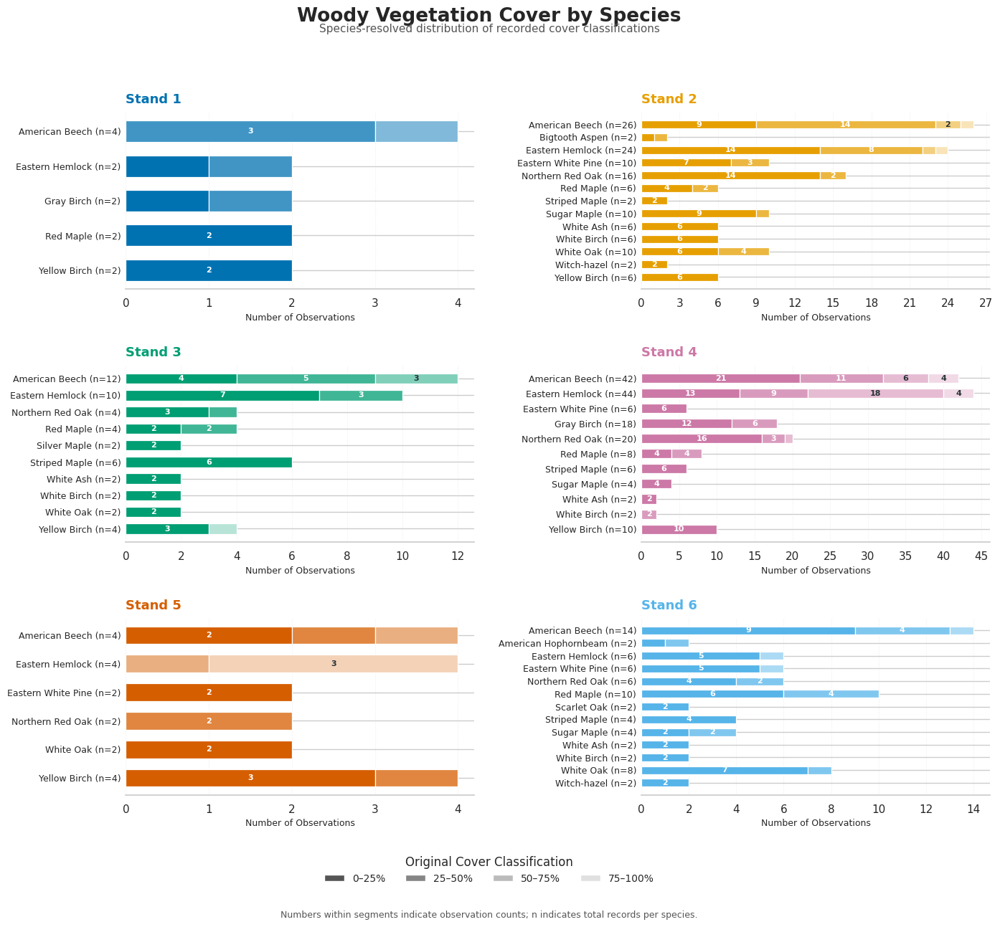

In [135]:

# STEP 122: Create a six-panel species-resolved woody-cover figure.
#
# Each panel represents one stand.
# Each species has one stacked horizontal bar.
# Segment lengths represent actual observation counts.
# The four original percentage-range classifications are retained.

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. DEFINE THE ORIGINAL STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Preserve the four original classification categories.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

# ------------------------------------------------------------
# 2. CREATE A COLOR GRADIENT FOR EACH STAND
# ------------------------------------------------------------

# Each stand retains its established base color.
# Increasingly lighter shades distinguish the four classes.

def create_cover_shades(base_color):

    # Convert the stand color to RGB.
    base = np.array(plt.matplotlib.colors.to_rgb(base_color))

    # Define the intensity of each classification shade.
    strengths = [1.0, 0.75, 0.50, 0.28]

    # Blend each shade with white.
    return [
        tuple(strength * base + (1 - strength) * np.ones(3))
        for strength in strengths
    ]

# Generate the four shades for each stand.
stand_cover_colors = {
    stand: create_cover_shades(color)
    for stand, color in stand_colors.items()
}

# ------------------------------------------------------------
# 3. CREATE THE SIX-PANEL FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 13)
)

axes = axes.flatten()

fig.suptitle(
    'Woody Vegetation Cover by Species',
    fontsize=19,
    fontweight='bold',
    y=0.985
)

fig.text(
    0.5,
    0.958,
    'Species-resolved distribution of recorded cover classifications',
    ha='center',
    fontsize=11,
    color='#555555'
)

# ------------------------------------------------------------
# 4. PLOT EACH STAND
# ------------------------------------------------------------

for ax, stand in zip(axes, range(1, 7)):

    # Select the current stand's species-level classification counts.
    stand_data = species_cover_summary.xs(
        stand,
        level='Stand ID'
    ).copy()

    # Sort species alphabetically.
    stand_data = stand_data.sort_index()

    # Extract species names.
    species_names = stand_data.index.tolist()

    # Calculate the total number of records per species.
    sample_sizes = stand_data.sum(axis=1)

    # Assign one horizontal position per species.
    y_positions = np.arange(len(species_names))

    # Retrieve the four shades for this stand.
    shades = stand_cover_colors[stand]

    # --------------------------------------------------------
    # 5. DRAW THE STACKED OBSERVATION COUNTS
    # --------------------------------------------------------

    for position, species in enumerate(species_names):

        # Start the bar at zero.
        left_position = 0

        # Draw the four classification segments.
        for index, cover_range in enumerate(cover_range_order):

            # Retrieve the actual number of observations.
            value = int(stand_data.loc[species, cover_range])

            # Draw the segment only when observations exist.
            if value > 0:

                ax.barh(
                    position,
                    value,
                    left=left_position,
                    height=0.62,
                    color=shades[index],
                    edgecolor='white',
                    linewidth=0.9
                )

                # Label segments when they are wide enough.
                if value >= 2:
                    ax.text(
                        left_position + value / 2,
                        position,
                        str(value),
                        ha='center',
                        va='center',
                        fontsize=8,
                        color='white' if index < 2 else '#263238',
                        fontweight='bold'
                    )

            # Advance to the next classification segment.
            left_position += value

    # --------------------------------------------------------
    # 6. FORMAT SPECIES LABELS
    # --------------------------------------------------------

    species_labels = [
        f'{species} (n={int(sample_sizes.loc[species])})'
        for species in species_names
    ]

    ax.set_yticks(y_positions)
    ax.set_yticklabels(species_labels, fontsize=9)

    # Place the first species at the top.
    ax.invert_yaxis()

    # --------------------------------------------------------
    # 7. FORMAT EACH STAND PANEL
    # --------------------------------------------------------

    ax.set_title(
        f'Stand {stand}',
        fontsize=13,
        fontweight='bold',
        color=stand_colors[stand],
        loc='left',
        pad=9
    )

    ax.set_xlabel('Number of Observations', fontsize=9)

    # Use integer tick marks for count data.
    ax.xaxis.set_major_locator(
        plt.MaxNLocator(integer=True)
    )

    # Add subtle vertical gridlines.
    ax.set_axisbelow(True)
    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.8,
        alpha=0.35
    )

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.tick_params(axis='y', length=0, pad=5)

# ------------------------------------------------------------
# 8. ADD THE CLASSIFICATION LEGEND
# ------------------------------------------------------------

# Use neutral colors in the legend so that the four
# classification ranges are easy to distinguish.
legend_colors = [
    '#555555',
    '#858585',
    '#BBBBBB',
    '#E0E0E0'
]

legend_handles = [
    Patch(
        facecolor=legend_colors[index],
        edgecolor='white',
        label=cover_range_order[index]
    )
    for index in range(4)
]

fig.legend(
    handles=legend_handles,
    title='Original Cover Classification',
    loc='lower center',
    bbox_to_anchor=(0.5, 0.035),
    ncol=4,
    frameon=False,
    fontsize=10
)

fig.text(
    0.5,
    0.008,
    'Numbers within segments indicate observation counts; n indicates total records per species.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# Adjust spacing around panels and legend.
plt.tight_layout(
    rect=[0.04, 0.09, 0.98, 0.94],
    h_pad=2,
    w_pad=2
)

# ------------------------------------------------------------
# 9. SAVE AND DISPLAY
# ------------------------------------------------------------

plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification.png',
    dpi=400,
    bbox_inches='tight'
)

plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification.pdf',
    bbox_inches='tight'
)

plt.show()


QA/QC CHECK
---------------------------------------------
Total observations: 434
Number of species-stand combinations: 58
Cover classes: ['0–25%', '25–50%', '50–75%', '75–100%']

Cover-class totals:
Cover Classification
0–25%      279
25–50%     104
50–75%      37
75–100%     14
dtype: int64


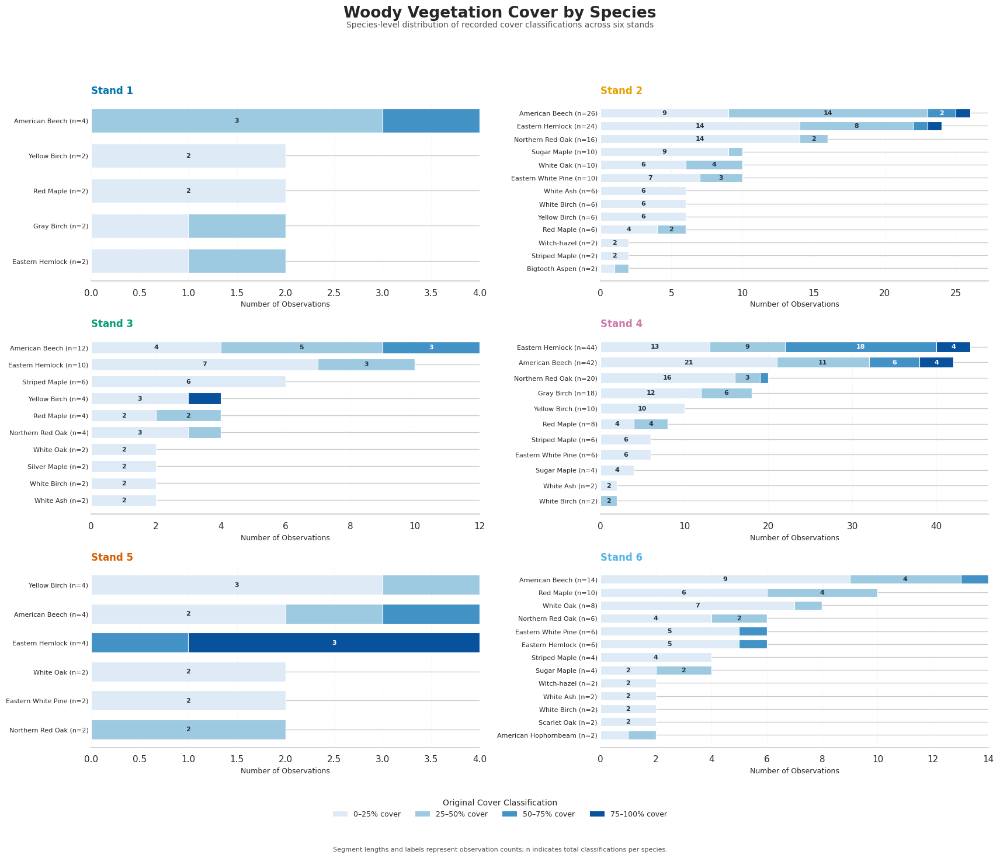

In [136]:
# STEP 123 — Standardize cover-class colors and validate species counts

# Import the plotting tools needed for the figure and legend.
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Define the four cover classes in their original ordinal order.
cover_class_order = ['0–25%', '25–50%', '50–75%', '75–100%']

# Assign one consistent sequential color to each cover class.
# Lighter colors represent lower cover classes; darker colors represent higher classes.
cover_class_colors = {
    '0–25%': '#DEEBF7',
    '25–50%': '#9ECAE1',
    '50–75%': '#4292C6',
    '75–100%': '#08519C'
}

# Preserve the original stand-specific colors for panel titles.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Make a copy of the species summary so the original summary remains unchanged.
plot_data = species_cover_summary.copy()

# Ensure all four cover-class columns exist, even if a class has zero observations.
plot_data = plot_data.reindex(columns=cover_class_order, fill_value=0)

# Convert the cover-class counts to numeric values for reliable validation and plotting.
plot_data[cover_class_order] = plot_data[cover_class_order].apply(
    lambda column: pd.to_numeric(column, errors='coerce').fillna(0)
)

# Calculate the total number of observations for each species within each stand.
plot_data['n'] = plot_data[cover_class_order].sum(axis=1)

# Check that no negative or fractional observation counts are present.
assert (plot_data[cover_class_order] >= 0).all().all(), \
    "QA/QC failed: negative cover-class counts were found."

assert np.allclose(
    plot_data[cover_class_order].to_numpy(),
    np.round(plot_data[cover_class_order].to_numpy())
), "QA/QC failed: non-integer cover-class counts were found."

# Confirm that the summary contains exactly the six intended stands.
observed_stands = sorted(plot_data.index.get_level_values('Stand ID').unique())
assert observed_stands == [1, 2, 3, 4, 5, 6], \
    f"Unexpected stand IDs found: {observed_stands}"

# Print the total number of observations represented in the figure.
print("QA/QC CHECK")
print("-" * 45)
print(f"Total observations: {int(plot_data['n'].sum())}")
print(f"Number of species-stand combinations: {len(plot_data)}")
print(f"Cover classes: {cover_class_order}")

# Print the total count for each cover class across all six stands.
print("\nCover-class totals:")
print(plot_data[cover_class_order].sum().astype(int))

# Create a figure with six panels arranged in three rows and two columns.
fig, axes = plt.subplots(3, 2, figsize=(18, 15))

# Flatten the axes array so each stand can be plotted using a simple loop.
axes = axes.flatten()

# Loop through each stand and its corresponding panel.
for stand, ax in zip(range(1, 7), axes):

    # Extract the species-level cover counts for the current stand.
    stand_data = plot_data.xs(stand, level='Stand ID').copy()

    # Sort species by their total number of recorded classifications.
    stand_data = stand_data.sort_values('n', ascending=True)

    # Create the vertical positions for the horizontal bars.
    y_positions = np.arange(len(stand_data))

    # Initialize the left-hand starting position for each stacked bar.
    left_positions = np.zeros(len(stand_data))

    # Draw one segment for each of the four cover classes.
    for cover_class in cover_class_order:

        # Retrieve the observation counts for the current cover class.
        values = stand_data[cover_class].to_numpy()

        # Draw the horizontal bar segments using the same color across every stand.
        ax.barh(
            y_positions,
            values,
            left=left_positions,
            height=0.68,
            color=cover_class_colors[cover_class],
            edgecolor='white',
            linewidth=0.8
        )

        # Add observation-count labels to segments that are large enough to read.
        for position, value, left in zip(y_positions, values, left_positions):

            # Only label segments containing at least two observations.
            if value >= 2:

                # Place the count at the center of its segment.
                ax.text(
                    left + value / 2,
                    position,
                    f'{int(value)}',
                    ha='center',
                    va='center',
                    fontsize=8,
                    color='white' if cover_class in ['50–75%', '75–100%'] else '#263238',
                    fontweight='bold'
                )

        # Update the left-hand position before drawing the next stacked segment.
        left_positions += values

    # Create species labels that include the total number of observations.
    species_labels = [
        f'{species} (n={int(total)})'
        for species, total in zip(stand_data.index, stand_data['n'])
    ]

    # Apply the species labels to the vertical axis.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(species_labels, fontsize=8)

    # Label the horizontal axis with the count-based measurement.
    ax.set_xlabel('Number of Observations', fontsize=9)

    # Use a stand-specific title color while keeping the cover-class colors consistent.
    ax.set_title(
        f'Stand {stand}',
        loc='left',
        fontsize=12,
        fontweight='bold',
        color=stand_colors[stand],
        pad=8
    )

    # Set the horizontal axis to begin at zero.
    ax.set_xlim(left=0)

    # Add subtle vertical gridlines to help compare observation counts.
    ax.xaxis.grid(True, linestyle=':', linewidth=0.6, alpha=0.35)

    # Keep the gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary plot borders for a cleaner appearance.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Keep the horizontal baseline subtle.
    ax.spines['bottom'].set_color('#CCCCCC')

    # Remove the small tick marks beside species labels.
    ax.tick_params(axis='y', length=0)

# Add a shared legend using the same four colors in every panel.
legend_handles = [
    Patch(
        facecolor=cover_class_colors[cover_class],
        edgecolor='none',
        label=f'{cover_class} cover'
    )
    for cover_class in cover_class_order
]

# Position the legend below all six panels.
fig.legend(
    handles=legend_handles,
    title='Original Cover Classification',
    loc='lower center',
    ncol=4,
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    bbox_to_anchor=(0.5, 0.045)
)

# Add a figure title and clarify what the bars represent.
fig.suptitle(
    'Woody Vegetation Cover by Species',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Explain that segment lengths represent counts, not measured percentages.
fig.text(
    0.5,
    0.955,
    'Species-level distribution of recorded cover classifications across six stands',
    ha='center',
    fontsize=10,
    color='#555555'
)

# Add a methodological note beneath the legend.
fig.text(
    0.5,
    0.015,
    'Segment lengths and labels represent observation counts; n indicates total classifications per species.',
    ha='center',
    fontsize=8,
    color='#555555'
)

# Adjust spacing to prevent labels and panels from overlapping.
plt.tight_layout(rect=[0.02, 0.09, 0.98, 0.93])

# Save a high-resolution PNG for reports and presentations.
plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification_Refined.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a vector PDF suitable for publication or printing.
plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification_Refined.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

QA/QC CHECK
---------------------------------------------
Total observations: 434
Species-stand combinations: 58

Cover-class totals:
Cover Classification
0–25%      279
25–50%     104
50–75%      37
75–100%     14
dtype: int64


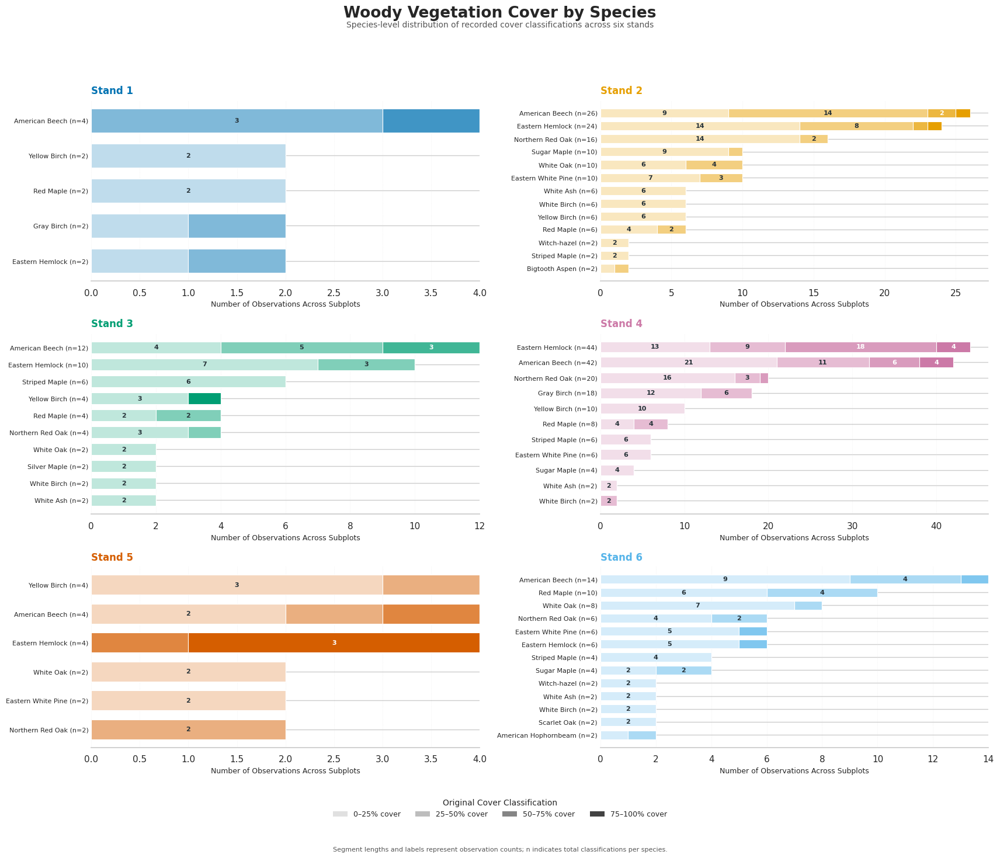

In [137]:
# STEP 124 — Restore original stand-specific colors with four cover-class shades

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

# Define the original cover-class order.
cover_class_order = ['0–25%', '25–50%', '50–75%', '75–100%']

# Restore the original six-stand color palette.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Define the proportion of the original stand color used for each cover class.
# Lower cover classes are lighter; higher cover classes are darker.
shade_strength = {
    '0–25%': 0.25,
    '25–50%': 0.50,
    '50–75%': 0.75,
    '75–100%': 1.00
}

# Create a helper function that blends each stand color with white.
def create_stand_shade(base_color, strength):

    # Convert the original stand color into RGB values.
    base_rgb = np.array(to_rgb(base_color))

    # Blend the stand color with white according to the desired strength.
    shaded_rgb = (1 - strength) * np.ones(3) + strength * base_rgb

    # Return the resulting RGB color.
    return shaded_rgb

# Generate a separate set of four shades for each stand.
stand_cover_colors = {
    stand: {
        cover_class: create_stand_shade(
            stand_color,
            shade_strength[cover_class]
        )
        for cover_class in cover_class_order
    }
    for stand, stand_color in stand_colors.items()
}

# Copy the existing species-level summary.
plot_data = species_cover_summary.copy()

# Ensure that all four cover-class columns are available.
plot_data = plot_data.reindex(columns=cover_class_order, fill_value=0)

# Convert cover-class counts to numeric values.
plot_data[cover_class_order] = plot_data[cover_class_order].apply(
    lambda column: pd.to_numeric(column, errors='coerce').fillna(0)
)

# Recalculate the total observations for each species and stand.
plot_data['n'] = plot_data[cover_class_order].sum(axis=1)

# Validate that all counts are nonnegative.
assert (plot_data[cover_class_order] >= 0).all().all(), \
    "QA/QC failed: negative counts detected."

# Validate that all counts are whole numbers.
assert np.allclose(
    plot_data[cover_class_order].to_numpy(),
    np.round(plot_data[cover_class_order].to_numpy())
), "QA/QC failed: non-integer counts detected."

# Validate that the six intended stands are represented.
observed_stands = sorted(plot_data.index.get_level_values('Stand ID').unique())
assert observed_stands == [1, 2, 3, 4, 5, 6], \
    f"Unexpected stand IDs: {observed_stands}"

# Print a summary of the QA/QC checks.
print("QA/QC CHECK")
print("-" * 45)
print(f"Total observations: {int(plot_data['n'].sum())}")
print(f"Species-stand combinations: {len(plot_data)}")
print("\nCover-class totals:")
print(plot_data[cover_class_order].sum().astype(int))

# Create the six-panel figure.
fig, axes = plt.subplots(3, 2, figsize=(18, 15))

# Flatten the axes to make plotting each stand easier.
axes = axes.flatten()

# Loop through the six stands.
for stand, ax in zip(range(1, 7), axes):

    # Select the species-level observations for the current stand.
    stand_data = plot_data.xs(stand, level='Stand ID').copy()

    # Sort species by their total number of observations.
    stand_data = stand_data.sort_values('n', ascending=True)

    # Create one vertical position for each species.
    y_positions = np.arange(len(stand_data))

    # Initialize the starting position of each stacked bar.
    left_positions = np.zeros(len(stand_data))

    # Draw the four cover-class segments.
    for cover_class in cover_class_order:

        # Retrieve the counts for the current cover class.
        values = stand_data[cover_class].to_numpy()

        # Draw the segments using the current stand's shade for this class.
        ax.barh(
            y_positions,
            values,
            left=left_positions,
            height=0.68,
            color=stand_cover_colors[stand][cover_class],
            edgecolor='white',
            linewidth=0.8
        )

        # Add observation-count labels to sufficiently large segments.
        for position, value, left in zip(
            y_positions,
            values,
            left_positions
        ):

            # Avoid labels in segments too narrow to read.
            if value >= 2:

                # Use dark text for lighter shades and white for darker shades.
                label_color = (
                    '#263238'
                    if shade_strength[cover_class] <= 0.50
                    else 'white'
                )

                # Place the count in the center of the segment.
                ax.text(
                    left + value / 2,
                    position,
                    f'{int(value)}',
                    ha='center',
                    va='center',
                    fontsize=8,
                    color=label_color,
                    fontweight='bold'
                )

        # Move the next segment to the right of the current segment.
        left_positions += values

    # Create species labels with their total observation counts.
    species_labels = [
        f'{species} (n={int(total)})'
        for species, total in zip(stand_data.index, stand_data['n'])
    ]

    # Apply species names to the vertical axis.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(species_labels, fontsize=8)

    # Label the horizontal axis.
    ax.set_xlabel('Number of Observations Across Subplots', fontsize=9)

    # Use the original stand color for the panel title.
    ax.set_title(
        f'Stand {stand}',
        loc='left',
        fontsize=12,
        fontweight='bold',
        color=stand_colors[stand],
        pad=8
    )

    # Ensure the horizontal axis starts at zero.
    ax.set_xlim(left=0)

    # Add subtle vertical gridlines.
    ax.xaxis.grid(
        True,
        linestyle=':',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary plot borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Keep the bottom axis line subtle.
    ax.spines['bottom'].set_color('#CCCCCC')

    # Remove y-axis tick marks.
    ax.tick_params(axis='y', length=0)

# Create a neutral grayscale legend to represent the light-to-dark class order.
# The bar colors themselves retain the original stand-specific palette.
legend_shades = {
    '0–25%': '#E0E0E0',
    '25–50%': '#BDBDBD',
    '50–75%': '#858585',
    '75–100%': '#424242'
}

# Build the legend handles.
legend_handles = [
    Patch(
        facecolor=legend_shades[cover_class],
        edgecolor='none',
        label=f'{cover_class} cover'
    )
    for cover_class in cover_class_order
]

# Add the shared legend below the six panels.
fig.legend(
    handles=legend_handles,
    title='Original Cover Classification',
    loc='lower center',
    ncol=4,
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    bbox_to_anchor=(0.5, 0.045)
)

# Add the main figure title.
fig.suptitle(
    'Woody Vegetation Cover by Species',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Add a subtitle explaining the figure.
fig.text(
    0.5,
    0.955,
    'Species-level distribution of recorded cover classifications across six stands',
    ha='center',
    fontsize=10,
    color='#555555'
)

# Add a note explaining the numbers inside the bars.
fig.text(
    0.5,
    0.015,
    'Segment lengths and labels represent observation counts; n indicates total classifications per species.',
    ha='center',
    fontsize=8,
    color='#555555'
)

# Adjust the layout to accommodate the title and legend.
plt.tight_layout(rect=[0.02, 0.09, 0.98, 0.93])

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification_Original_Colors.png',
    dpi=400,
    bbox_inches='tight'
)

# Save the vector PDF.
plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification_Original_Colors.pdf',
    bbox_inches='tight'
)

# Display the finished figure.
plt.show()

In [140]:
# STEP 125 — Inspect the column names in the woody inventory

# Print every column name in the woody analysis dataset.
print("WOODY ANALYSIS COLUMN NAMES")
print("-" * 45)

for column in woody_analysis.columns:
    print(repr(column))

# Identify columns whose names may refer to tree condition or status.
print("\nPOSSIBLE TREE STATUS OR CONDITION FIELDS")
print("-" * 45)

for column in woody_analysis.columns:
    if any(
        term in column.lower()
        for term in ['status', 'condition', 'live', 'dead', 'alive']
    ):
        print(repr(column))

WOODY ANALYSIS COLUMN NAMES
---------------------------------------------
'Stand ID'
'Plot ID'
'Subplot ID'
'Date'
'Team Member(s)'
'Tree ID'
'Species Code'
'Tree Status'
'DBH (in)'
'Estimated Tree Height (m)'
'Estimated Tree Height (ft)'
'Crown Class Code'
'Damage Type Code'
'Snag Decay Class (If Applicable)'
'Notes'
'Species Name'
'Tree Status Label'

POSSIBLE TREE STATUS OR CONDITION FIELDS
---------------------------------------------
'Tree Status'
'Tree Status Label'


In [141]:
# STEP 126 — Inspect living-tree species composition using the correct status field

# Select only records identified as alive in the descriptive status field.
live_trees_analysis = woody_analysis[
    woody_analysis['Tree Status Label']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq('alive')
].copy()

# Remove records without a usable species name.
live_trees_analysis = live_trees_analysis.dropna(
    subset=['Species Name']
).copy()

# Remove accidental whitespace from species names.
live_trees_analysis['Species Name'] = (
    live_trees_analysis['Species Name'].astype(str).str.strip()
)

# Display the number of living trees recorded in each stand.
print("LIVING TREE RECORDS BY STAND")
print("-" * 45)

print(
    live_trees_analysis.groupby('Stand ID')
    .size()
    .reindex(included_stands, fill_value=0)
)

# Count individual living trees by species within each stand.
tree_species_counts = (
    live_trees_analysis
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .rename('Tree Count')
    .reset_index()
)

# Display species-level counts separately for each stand.
print("\nSPECIES COUNTS WITHIN EACH STAND")
print("-" * 45)

for stand in included_stands:

    # Select the species counts for the current stand.
    stand_counts = tree_species_counts[
        tree_species_counts['Stand ID'] == stand
    ].sort_values('Tree Count', ascending=False)

    # Print the species counts.
    print(f"\nStand {stand}")
    print(
        stand_counts[['Species Name', 'Tree Count']]
        .to_string(index=False)
    )

# Display the total number of living trees.
print("\nTOTAL LIVING TREES:", len(live_trees_analysis))

# Display the number of unique species across the six stands.
print(
    "TOTAL UNIQUE TREE SPECIES:",
    live_trees_analysis['Species Name'].nunique()
)

LIVING TREE RECORDS BY STAND
---------------------------------------------
Stand ID
1     11
2     79
3     25
4    162
5     32
6     47
dtype: int64

SPECIES COUNTS WITHIN EACH STAND
---------------------------------------------

Stand 1
   Species Name  Tree Count
Eastern Hemlock           4
   Yellow Birch           3
      Red Maple           2
    Sugar Maple           1
      White Oak           1

Stand 2
      Species Name  Tree Count
   Eastern Hemlock          21
  Northern Red Oak          18
         Red Maple          10
         White Oak           9
    American Beech           6
       Sugar Maple           5
      Yellow Birch           5
       White Birch           3
Eastern White Pine           1
         White Ash           1

Stand 3
    Species Name  Tree Count
 Eastern Hemlock           6
    Yellow Birch           6
       Red Maple           5
Northern Red Oak           4
  American Beech           2
    Silver Maple           1
       White Oak           1



In [142]:
# STEP 127 — Calculate tree species relative abundance within each stand

# Start with the species-level tree counts calculated in Step 126.
tree_relative_abundance = tree_species_counts.copy()

# Calculate the total number of living trees recorded in each stand.
tree_relative_abundance['Stand Total'] = (
    tree_relative_abundance
    .groupby('Stand ID')['Tree Count']
    .transform('sum')
)

# Calculate each species' percentage of the living trees in its stand.
tree_relative_abundance['Relative Abundance (%)'] = (
    tree_relative_abundance['Tree Count'] /
    tree_relative_abundance['Stand Total']
) * 100

# Sort the results by stand and descending relative abundance.
tree_relative_abundance = tree_relative_abundance.sort_values(
    ['Stand ID', 'Relative Abundance (%)'],
    ascending=[True, False]
).reset_index(drop=True)

# Display the relative abundance results separately for each stand.
print("TREE SPECIES RELATIVE ABUNDANCE")
print("-" * 60)

for stand in included_stands:

    # Select the relative abundance results for the current stand.
    stand_data = tree_relative_abundance[
        tree_relative_abundance['Stand ID'] == stand
    ]

    # Display species, individual counts, and relative abundance.
    print(f"\nStand {stand}")
    print(
        stand_data[
            ['Species Name', 'Tree Count', 'Relative Abundance (%)']
        ].round(2).to_string(index=False)
    )

# Verify that relative abundances sum to approximately 100% in every stand.
stand_abundance_totals = (
    tree_relative_abundance
    .groupby('Stand ID')['Relative Abundance (%)']
    .sum()
)

print("\nQA/QC: RELATIVE ABUNDANCE TOTALS")
print("-" * 45)
print(stand_abundance_totals.round(4))

# Confirm that all six stands sum to 100%, allowing for rounding precision.
assert np.allclose(
    stand_abundance_totals.values,
    100
), "QA/QC failed: relative abundance does not sum to 100% in every stand."

print("\nQA/QC PASSED: Relative abundance sums to 100% in all six stands.")

TREE SPECIES RELATIVE ABUNDANCE
------------------------------------------------------------

Stand 1
   Species Name  Tree Count  Relative Abundance (%)
Eastern Hemlock           4                   36.36
   Yellow Birch           3                   27.27
      Red Maple           2                   18.18
    Sugar Maple           1                    9.09
      White Oak           1                    9.09

Stand 2
      Species Name  Tree Count  Relative Abundance (%)
   Eastern Hemlock          21                   26.58
  Northern Red Oak          18                   22.78
         Red Maple          10                   12.66
         White Oak           9                   11.39
    American Beech           6                    7.59
       Sugar Maple           5                    6.33
      Yellow Birch           5                    6.33
       White Birch           3                    3.80
Eastern White Pine           1                    1.27
         White Ash         

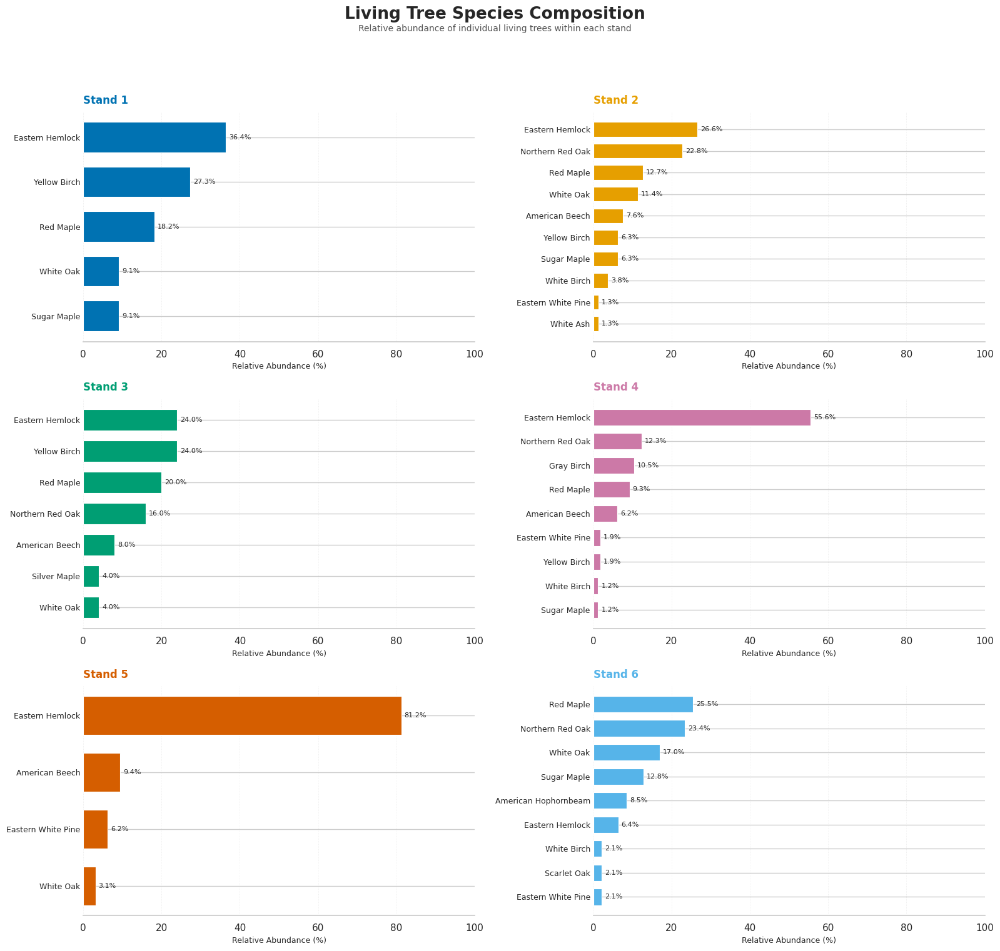

In [143]:
# STEP 128 — Create six-panel tree species relative abundance figure

import matplotlib.pyplot as plt
import numpy as np

# Preserve the original six-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

# Create a figure with six panels arranged in three rows and two columns.
fig, axes = plt.subplots(3, 2, figsize=(17, 16))

# Flatten the axes array for easier iteration.
axes = axes.flatten()

# Loop through each stand and its corresponding panel.
for stand, ax in zip(included_stands, axes):

    # Extract relative abundance data for the current stand.
    stand_data = tree_relative_abundance[
        tree_relative_abundance['Stand ID'] == stand
    ].copy()

    # Sort species from lowest to highest relative abundance.
    stand_data = stand_data.sort_values(
        'Relative Abundance (%)',
        ascending=True
    )

    # Generate vertical positions for the species bars.
    y_positions = np.arange(len(stand_data))

    # Draw horizontal bars using the original color assigned to the stand.
    bars = ax.barh(
        y_positions,
        stand_data['Relative Abundance (%)'],
        color=stand_colors[stand],
        height=0.68,
        edgecolor='white',
        linewidth=0.8
    )

    # Add species names to the vertical axis.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        stand_data['Species Name'],
        fontsize=9
    )

    # Add percentage labels at the end of each bar.
    for bar, percentage in zip(
        bars,
        stand_data['Relative Abundance (%)']
    ):

        # Position each label just beyond its bar.
        ax.text(
            bar.get_width() + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f'{percentage:.1f}%',
            va='center',
            ha='left',
            fontsize=8
        )

    # Set the panel title using the stand's original color.
    ax.set_title(
        f'Stand {stand}',
        loc='left',
        fontsize=12,
        fontweight='bold',
        color=stand_colors[stand],
        pad=9
    )

    # Set the horizontal axis range consistently across all stands.
    ax.set_xlim(0, 100)

    # Add subtle vertical gridlines for easier comparison.
    ax.xaxis.grid(
        True,
        linestyle=':',
        linewidth=0.7,
        alpha=0.35
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Keep the bottom axis line subtle.
    ax.spines['bottom'].set_color('#CCCCCC')

    # Remove y-axis tick marks.
    ax.tick_params(axis='y', length=0)

    # Label the horizontal axis.
    ax.set_xlabel('Relative Abundance (%)', fontsize=9)

# Add the main figure title.
fig.suptitle(
    'Living Tree Species Composition',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Add a subtitle explaining the calculation.
fig.text(
    0.5,
    0.955,
    'Relative abundance of individual living trees within each stand',
    ha='center',
    fontsize=10,
    color='#555555'
)

# Adjust spacing to prevent overlap between panels.
plt.tight_layout(rect=[0.03, 0.03, 0.98, 0.93])

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Living_Tree_Species_Relative_Abundance.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a vector PDF for reports and printing.
plt.savefig(
    export_dir / 'Living_Tree_Species_Relative_Abundance.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

In [144]:
# STEP 129 — Include Alive, Damaged, and Dying trees

# Define the tree-status categories that will be treated as living.
included_tree_statuses = ['alive', 'damaged', 'dying']

# Select all trees belonging to the three included status categories.
live_trees_analysis = woody_analysis[
    woody_analysis['Tree Status Label']
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(included_tree_statuses)
].copy()

# Remove records without an identified species.
live_trees_analysis = live_trees_analysis.dropna(
    subset=['Species Name']
).copy()

# Standardize whitespace in species names.
live_trees_analysis['Species Name'] = (
    live_trees_analysis['Species Name'].astype(str).str.strip()
)

# Display the number of included trees by status and stand.
print("INCLUDED TREE STATUS COUNTS BY STAND")
print("-" * 55)

print(
    pd.crosstab(
        live_trees_analysis['Stand ID'],
        live_trees_analysis['Tree Status Label']
    ).reindex(included_stands, fill_value=0)
)

# Count trees by species within each stand.
tree_species_counts = (
    live_trees_analysis
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .rename('Tree Count')
    .reset_index()
)

# Calculate the total number of included trees within each stand.
tree_species_counts['Stand Total'] = (
    tree_species_counts
    .groupby('Stand ID')['Tree Count']
    .transform('sum')
)

# Calculate relative abundance within each stand.
tree_species_counts['Relative Abundance (%)'] = (
    tree_species_counts['Tree Count'] /
    tree_species_counts['Stand Total']
) * 100

# Display the revised species composition for each stand.
print("\nREVISED TREE SPECIES COMPOSITION")
print("-" * 55)

for stand in included_stands:

    # Select the species counts for the current stand.
    stand_data = tree_species_counts[
        tree_species_counts['Stand ID'] == stand
    ].sort_values('Relative Abundance (%)', ascending=False)

    # Print the revised species counts and relative abundances.
    print(f"\nStand {stand}")
    print(
        stand_data[
            ['Species Name', 'Tree Count', 'Relative Abundance (%)']
        ].round(2).to_string(index=False)
    )

# Print the updated total number of included trees.
print("\nTOTAL INCLUDED TREES:", len(live_trees_analysis))

# Print the updated number of unique species.
print(
    "TOTAL UNIQUE SPECIES:",
    live_trees_analysis['Species Name'].nunique()
)

# Verify that relative abundance sums to 100% in each stand.
abundance_check = (
    tree_species_counts
    .groupby('Stand ID')['Relative Abundance (%)']
    .sum()
)

assert np.allclose(abundance_check.values, 100), \
    "QA/QC failed: relative abundance does not sum to 100%."

print("\nQA/QC PASSED: Relative abundance sums to 100% in every stand.")

INCLUDED TREE STATUS COUNTS BY STAND
-------------------------------------------------------
Tree Status Label  Alive  Damaged  Dying
Stand ID                                
1                     11        6      1
2                     79       11      2
3                     25        3      1
4                    162       36      2
5                     32        2      1
6                     47        7      1

REVISED TREE SPECIES COMPOSITION
-------------------------------------------------------

Stand 1
   Species Name  Tree Count  Relative Abundance (%)
 American Beech           6                   33.33
Eastern Hemlock           4                   22.22
      Red Maple           3                   16.67
   Yellow Birch           3                   16.67
    Sugar Maple           1                    5.56
      White Oak           1                    5.56

Stand 2
      Species Name  Tree Count  Relative Abundance (%)
   Eastern Hemlock          27                   29.

In [145]:
# STEP 130 — Recalculate living-tree species richness

# Count the unique species recorded in each stand using the revised dataset.
tree_richness_updated = (
    live_trees_analysis
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reindex(included_stands, fill_value=0)
    .rename('Tree Species Richness')
)

# Display the revised species richness values.
print("UPDATED TREE SPECIES RICHNESS")
print("-" * 45)
print(tree_richness_updated)

# Display the total number of unique species across all six stands.
print(
    "\nTotal unique tree species:",
    live_trees_analysis['Species Name'].nunique()
)

# Identify the species recorded in each stand.
print("\nSPECIES RICHNESS VALIDATION")
print("-" * 45)

for stand in included_stands:

    # Retrieve the unique species recorded in the current stand.
    species = sorted(
        live_trees_analysis.loc[
            live_trees_analysis['Stand ID'] == stand,
            'Species Name'
        ].unique()
    )

    # Display the stand-specific species list.
    print(f"\nStand {stand}: {len(species)} species")
    print(", ".join(species))

UPDATED TREE SPECIES RICHNESS
---------------------------------------------
Stand ID
1     6
2    10
3     7
4     9
5     5
6    10
Name: Tree Species Richness, dtype: int64

Total unique tree species: 14

SPECIES RICHNESS VALIDATION
---------------------------------------------

Stand 1: 6 species
American Beech, Eastern Hemlock, Red Maple, Sugar Maple, White Oak, Yellow Birch

Stand 2: 10 species
American Beech, Eastern Hemlock, Eastern White Pine, Northern Red Oak, Red Maple, Sugar Maple, White Ash, White Birch, White Oak, Yellow Birch

Stand 3: 7 species
American Beech, Eastern Hemlock, Northern Red Oak, Red Maple, Silver Maple, White Oak, Yellow Birch

Stand 4: 9 species
American Beech, Eastern Hemlock, Eastern White Pine, Gray Birch, Northern Red Oak, Red Maple, Sugar Maple, White Birch, Yellow Birch

Stand 5: 5 species
American Beech, Eastern Hemlock, Eastern White Pine, Sugar Maple, White Oak

Stand 6: 10 species
American Beech, American Hophornbeam, Eastern Hemlock, Eastern W

In [148]:

# STEP 133: Reconstruct the publication-quality living-tree DBH figure.
#
# Each panel displays:
# 1. A violin distribution showing the density of DBH measurements.
# 2. Individual tree observations positioned inside the violin.
# 3. A dark central marker showing the median DBH.
# 4. A vertical line showing the interquartile range (IQR).
#
# IMPORTANT:
# This figure uses live_trees_analysis, which contains the 356
# living-tree observations used in the original DBH analysis.
# No height-specific exclusions are applied here.


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES AND DEFINE THE COLOR PALETTE
# ------------------------------------------------------------

# Import Matplotlib for figure creation and formatting.
import matplotlib.pyplot as plt

# Import NumPy for numerical calculations and reproducible jitter.
import numpy as np

# Import Seaborn for violin distributions and plotting aesthetics.
import seaborn as sns


# Define the original six-stand color palette.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}


# ------------------------------------------------------------
# 2. VALIDATE THE DBH DATA
# ------------------------------------------------------------

# Keep only records from the six primary analysis stands.
dbh_analysis_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without a recorded DBH measurement.
dbh_analysis_df = dbh_analysis_df.dropna(
    subset=['DBH (in)']
).copy()

# Confirm that the expected 356 observations are present.
print("Total living-tree DBH observations:", len(dbh_analysis_df))

# Display the number of observations available in each stand.
print("\nDBH observations by stand:")
print(
    dbh_analysis_df.groupby('Stand ID')['DBH (in)']
    .count()
    .reindex(range(1, 7))
)

# Stop execution if the sample sizes differ from the original figure.
expected_sample_sizes = {
    1: 11,
    2: 79,
    3: 25,
    4: 162,
    5: 32,
    6: 47
}

observed_sample_sizes = (
    dbh_analysis_df.groupby('Stand ID')['DBH (in)']
    .count()
    .to_dict()
)

assert observed_sample_sizes == expected_sample_sizes, (
    "The DBH sample sizes do not match the original figure. "
    "Check live_trees_analysis before proceeding."
)


# ------------------------------------------------------------
# 3. ESTABLISH THE FIGURE STYLE AND LAYOUT
# ------------------------------------------------------------

# Apply a clean white-grid plotting theme.
sns.set_theme(
    style='whitegrid',
    context='notebook'
)

# Create six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 10),
    sharey=True
)

# Flatten the axes array so each stand can be assigned to one panel.
axes = axes.flatten()


# ------------------------------------------------------------
# 4. CREATE THE SIX DBH DISTRIBUTION PANELS
# ------------------------------------------------------------

# Loop through each stand and its corresponding plotting panel.
for stand, ax in zip(range(1, 7), axes):

    # Extract the DBH measurements for the current stand.
    stand_data = dbh_analysis_df.loc[
        dbh_analysis_df['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    # Convert the DBH measurements into a numerical array.
    dbh_values = stand_data.to_numpy()

    # Retrieve the original color assigned to this stand.
    stand_color = stand_colors[stand]

    # Calculate the first quartile, median, and third quartile.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw the violin distribution centered at horizontal position zero.
    # The violin represents the density of observed tree diameters.
    # cut=0 prevents the violin from extending beyond observed values.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make the violin partially transparent.
    # This allows individual tree measurements to remain visible.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Create a reproducible random-number generator for point placement.
    # The stand number is used as the seed so the jitter remains consistent.
    rng = np.random.default_rng(seed=stand)

    # Generate small horizontal offsets to distribute individual points.
    # The points remain inside the violin distribution.
    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(dbh_values)
    )

    # Plot each individual tree measurement.
    ax.scatter(
        jitter,
        dbh_values,
        s=27,
        color=stand_color,
        edgecolor='white',
        linewidth=0.55,
        alpha=0.85,
        zorder=4
    )

    # Draw a dark vertical line representing the interquartile range.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='#26352D',
        linewidth=3,
        zorder=5
    )

    # Add a contrasting central marker representing the median DBH.
    ax.scatter(
        0,
        median,
        s=85,
        color='#26352D',
        edgecolor='white',
        linewidth=1.2,
        zorder=6
    )

    # Add the stand identifier and sample size to the panel heading.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=13
    )

    # Label the vertical axis with the DBH measurement units.
    ax.set_ylabel(
        'DBH (inches)',
        fontsize=10
    )

    # Remove unnecessary horizontal-axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Set consistent horizontal limits around the violin.
    ax.set_xlim(-0.55, 0.55)

    # Add subtle horizontal gridlines for easier comparison.
    ax.grid(
        axis='y',
        alpha=0.20,
        linewidth=0.8
    )

    # Keep the gridlines behind the plotted observations.
    ax.set_axisbelow(True)

    # Remove unnecessary plot borders.
    sns.despine(
        ax=ax,
        bottom=True
    )


# ------------------------------------------------------------
# 5. ADD FIGURE TITLES AND EXPLANATORY LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Diameter Structure Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=1.02
)

# Add a subtitle describing the measurements and included observations.
fig.text(
    0.5,
    0.985,
    'Diameter at breast height (DBH); living trees only',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add a figure legend explaining the visual elements.
fig.text(
    0.5,
    0.015,
    'Violin = DBH density     |     '
    'Points = individual trees     |     '
    'Dark marker = median     |     '
    'Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust panel spacing to prevent titles and labels from overlapping.
plt.tight_layout(
    rect=[0, 0.045, 1, 0.96]
)


# ------------------------------------------------------------
# 6. EXPORT AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a vector PDF for publication-quality output.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


Total living-tree DBH observations: 429

DBH observations by stand:
Stand ID
1     18
2     92
3     29
4    200
5     35
6     55
Name: DBH (in), dtype: int64


AssertionError: The DBH sample sizes do not match the original figure. Check live_trees_analysis before proceeding.

In [149]:
# STEP 134: Validate the revised DBH dataset.
# Alive, Damaged, and Dying trees are included.
# Dead trees and records without DBH are excluded from this figure.

# Rebuild the DBH plotting dataset from the updated living-tree records.
dbh_analysis_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].dropna(subset=['DBH (in)']).copy()

# Calculate the number of DBH observations in each stand.
observed_sample_sizes = (
    dbh_analysis_df.groupby('Stand ID')['DBH (in)']
    .count()
    .reindex(range(1, 7), fill_value=0)
)

# Print the updated sample sizes.
print("Updated living-tree DBH sample sizes:")
print(observed_sample_sizes)

# Print the total number of DBH observations.
print("\nTotal DBH observations:", len(dbh_analysis_df))

# Confirm that all 429 observations are represented.
assert len(dbh_analysis_df) == 429, (
    "The total DBH observation count differs from the expected 429."
)

Updated living-tree DBH sample sizes:
Stand ID
1     18
2     92
3     29
4    200
5     35
6     55
Name: DBH (in), dtype: int64

Total DBH observations: 429


Living-tree DBH observations by stand:
Stand ID
1     18
2     92
3     29
4    200
5     35
6     55
Name: DBH (in), dtype: int64

Total DBH observations: 429


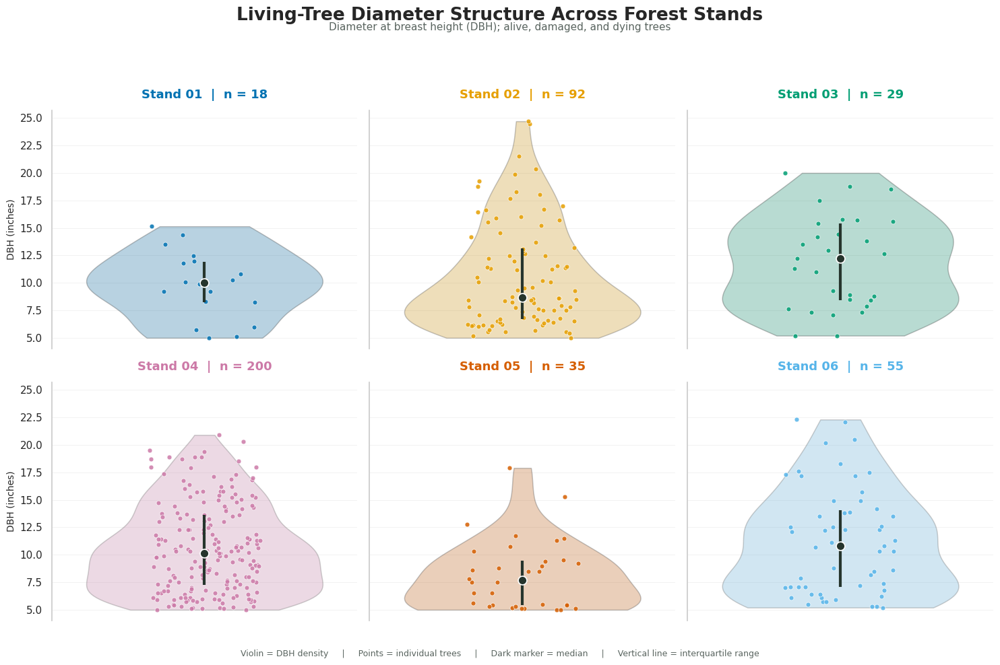

In [150]:

# STEP 135: Reconstruct the living-tree DBH distribution figure.
#
# This figure includes all living-tree status categories:
# Alive (AL), Damaged (DA), and Dying (DY).
#
# Dead trees are excluded.
# Trees without DBH measurements are excluded from this figure only.
#
# Each panel displays:
# - Violin distribution: density of DBH measurements.
# - Individual points: individual tree observations.
# - Dark central marker: median DBH.
# - Vertical line: interquartile range (25th–75th percentile).


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

# Import Matplotlib for figure creation and formatting.
import matplotlib.pyplot as plt

# Import NumPy for calculations and reproducible point placement.
import numpy as np

# Import Seaborn for violin distributions.
import seaborn as sns


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

# Retain the original colors used throughout the forest inventory figures.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}


# ------------------------------------------------------------
# 3. VALIDATE THE UPDATED DBH DATASET
# ------------------------------------------------------------

# Rebuild the plotting dataset from the validated living-tree records.
# This includes Alive, Damaged, and Dying trees.
# It does not apply the separate height-specific exclusions.
dbh_analysis_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].dropna(subset=['DBH (in)']).copy()

# Define the expected sample sizes from the latest validation.
expected_sample_sizes = {
    1: 18,
    2: 92,
    3: 29,
    4: 200,
    5: 35,
    6: 55
}

# Calculate the actual number of DBH observations in each stand.
observed_sample_sizes = (
    dbh_analysis_df.groupby('Stand ID')['DBH (in)']
    .count()
    .reindex(range(1, 7), fill_value=0)
    .to_dict()
)

# Confirm that the current dataset matches the validated sample sizes.
assert observed_sample_sizes == expected_sample_sizes, (
    "DBH sample sizes have changed. Recheck the living-tree dataset."
)

# Confirm that all 429 observations are represented.
assert len(dbh_analysis_df) == 429, (
    "The total number of DBH observations is not 429."
)

# Print the sample sizes used in the figure.
print("Living-tree DBH observations by stand:")
print(
    dbh_analysis_df.groupby('Stand ID')['DBH (in)']
    .count()
    .reindex(range(1, 7))
)

print("\nTotal DBH observations:", len(dbh_analysis_df))


# ------------------------------------------------------------
# 4. ESTABLISH THE FIGURE STYLE AND LAYOUT
# ------------------------------------------------------------

# Apply a clean white plotting background.
sns.set_theme(style='whitegrid', context='notebook')

# Create six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 10),
    sharey=True
)

# Flatten the axes array to simplify the stand-by-stand plotting loop.
axes = axes.flatten()


# ------------------------------------------------------------
# 5. CREATE THE SIX STAND-SPECIFIC DBH DISTRIBUTIONS
# ------------------------------------------------------------

# Loop through the six stands and their corresponding plotting panels.
for stand, ax in zip(range(1, 7), axes):

    # Extract DBH measurements for the current stand.
    stand_data = dbh_analysis_df.loc[
        dbh_analysis_df['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    # Convert the measurements into a numerical array.
    dbh_values = stand_data.to_numpy()

    # Retrieve the original color assigned to this stand.
    stand_color = stand_colors[stand]

    # Calculate the first quartile, median, and third quartile.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw the violin distribution.
    # The violin represents the density of observed tree diameters.
    # cut=0 prevents the violin from extending beyond observed values.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make the violin partially transparent so the observations remain visible.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Create a reproducible random-number generator for horizontal jitter.
    rng = np.random.default_rng(seed=stand)

    # Generate small horizontal offsets to separate overlapping observations.
    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(dbh_values)
    )

    # Plot each individual tree DBH measurement.
    ax.scatter(
        jitter,
        dbh_values,
        s=25,
        color=stand_color,
        edgecolor='white',
        linewidth=0.55,
        alpha=0.85,
        zorder=4
    )

    # Draw the interquartile range as a dark vertical line.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='#26352D',
        linewidth=3,
        zorder=5
    )

    # Add a dark central marker representing the median DBH.
    ax.scatter(
        0,
        median,
        s=85,
        color='#26352D',
        edgecolor='white',
        linewidth=1.2,
        zorder=6
    )

    # Add the stand identifier and updated sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=13
    )

    # Label the vertical axis with DBH units.
    ax.set_ylabel(
        'DBH (inches)',
        fontsize=10
    )

    # Remove unnecessary horizontal-axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Keep consistent horizontal limits around each violin.
    ax.set_xlim(-0.55, 0.55)

    # Add subtle horizontal gridlines for easier comparison.
    ax.grid(
        axis='y',
        alpha=0.25,
        linewidth=0.7
    )

    # Keep gridlines behind the observations.
    ax.set_axisbelow(True)

    # Remove unnecessary plot borders.
    sns.despine(
        ax=ax,
        bottom=True
    )


# ------------------------------------------------------------
# 6. ADD FIGURE TITLE AND EXPLANATORY TEXT
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Diameter Structure Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.99
)

# Add a subtitle describing the measurements and included tree statuses.
fig.text(
    0.5,
    0.955,
    'Diameter at breast height (DBH); alive, damaged, and dying trees',
    ha='center',
    fontsize=11,
    color='#59645F'
)

# Add an explanatory figure legend.
fig.text(
    0.5,
    0.025,
    'Violin = DBH density     |     '
    'Points = individual trees     |     '
    'Dark marker = median     |     '
    'Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust spacing to prevent panel titles and labels from overlapping.
plt.tight_layout(
    rect=[0, 0.06, 1, 0.93]
)


# ------------------------------------------------------------
# 7. EXPORT AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a vector PDF for publication-quality output.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


In [151]:

# STEP 136: Calculate descriptive statistics for DBH by stand.

# Group the updated DBH dataset by Stand ID and calculate the statistics.
dbh_summary = (
    dbh_analysis_df
    .groupby('Stand ID')['DBH (in)']
    .agg(
        n='count',                       # Number of trees measured
        Mean='mean',                     # Average DBH
        Median='median',                 # Middle DBH value
        SD='std',                        # Standard deviation
        Minimum='min',                   # Smallest DBH
        Q1=lambda x: x.quantile(0.25),    # 25th percentile
        Q3=lambda x: x.quantile(0.75),    # 75th percentile
        Maximum='max'                    # Largest DBH
    )
    .reindex(range(1, 7))                # Keep stands in numerical order
)

# Rename the index so the table clearly identifies each stand.
dbh_summary.index.name = 'Stand'

# Round DBH measurements to two decimal places.
dbh_summary = dbh_summary.round(2)

# Display the completed descriptive-statistics table.
display(dbh_summary)

# Display the total number of trees represented in the table.
print("Total living-tree DBH observations:", int(dbh_summary['n'].sum()))


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand,,,,,,,,
1,18,9.84,9.98,3.09,5.0,8.26,11.94,15.14
2,92,10.60,8.68,4.74,5.0,6.69,13.13,24.70
3,29,11.89,12.20,4.23,5.2,8.40,15.40,20.00
4,200,10.64,10.15,4.01,5.0,7.28,13.61,20.90
5,35,8.14,7.70,3.13,5.0,5.40,9.45,17.90
6,55,11.22,10.80,4.81,5.2,7.05,14.05,22.30


Total living-tree DBH observations: 429


Updated crown-class sample sizes by stand:
Stand ID
1     18
2     92
3     25
4    200
5     35
6     55
dtype: int64

Updated crown-class composition (%):


Crown Class Code,Dominant,Codominant,Intermediate,Suppressed
Stand ID,,,,
1,27.8,33.3,11.1,27.8
2,22.8,53.3,15.2,8.7
3,16.0,64.0,20.0,0.0
4,14.5,50.0,23.5,12.0
5,11.4,42.9,20.0,25.7
6,12.7,41.8,40.0,5.5



Total crown-class observations: 425


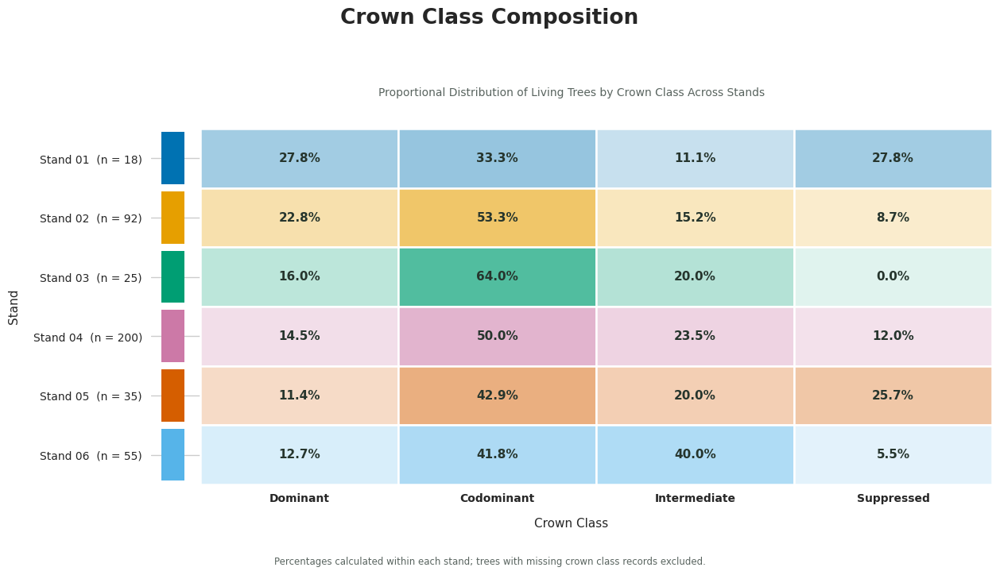

In [152]:

# STEP 137: Recreate the Crown Class Composition heatmap
# using the updated living-tree population (AL, DA, and DY).

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as patches
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}


# ------------------------------------------------------------
# 3. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Use the updated living-tree dataset containing AL, DA, and DY.
# Crown-class records with missing values are excluded from this figure.
crown_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without a recorded crown class.
crown_df = crown_df.dropna(subset=['Crown Class Code'])

# Standardize crown-class labels so categories are consistent.
crown_df['Crown Class Code'] = (
    crown_df['Crown Class Code']
    .astype(str)
    .str.strip()
    .replace({
        'Co-Dominant': 'Codominant',
        'Co-dominant': 'Codominant',
        'Overtopped': 'Suppressed',
        'Overtopped / Suppressed': 'Suppressed'
    })
)

# Define the order used in the original figure.
crown_classes = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Keep only the four crown classes displayed in the original figure.
crown_df = crown_df[
    crown_df['Crown Class Code'].isin(crown_classes)
].copy()


# ------------------------------------------------------------
# 4. CALCULATE COUNTS AND WITHIN-STAND PERCENTAGES
# ------------------------------------------------------------

# Count trees in each crown class within each stand.
crown_counts = pd.crosstab(
    crown_df['Stand ID'],
    crown_df['Crown Class Code']
)

# Ensure all six stands and all four crown classes are represented.
crown_counts = crown_counts.reindex(
    index=range(1, 7),
    columns=crown_classes,
    fill_value=0
)

# Calculate the total number of trees with crown-class records per stand.
crown_sample_sizes = crown_counts.sum(axis=1)

# Calculate percentages within each stand.
# Each stand's four crown-class percentages should sum to 100%.
crown_percentages = (
    crown_counts.div(crown_sample_sizes, axis=0) * 100
).fillna(0)

# Print updated sample sizes for verification.
print("Updated crown-class sample sizes by stand:")
print(crown_sample_sizes)

# Print the updated percentage table.
print("\nUpdated crown-class composition (%):")
display(crown_percentages.round(1))

# Confirm the total number of crown-class observations.
print(
    "\nTotal crown-class observations:",
    int(crown_sample_sizes.sum())
)


# ------------------------------------------------------------
# 5. CREATE A HELPER FUNCTION FOR STAND-SPECIFIC COLORS
# ------------------------------------------------------------

# Blend each stand's original color with white.
# Higher percentages produce stronger versions of that stand's color.
def blend_with_white(color, proportion):
    # Convert the hexadecimal color into RGB values.
    rgb = np.array(mcolors.to_rgb(color))

    # Scale the color intensity according to the percentage.
    # A small baseline keeps zero-value cells visible.
    intensity = 0.12 + 0.88 * (proportion / 100)

    # Blend the stand color with white.
    blended = 1 - intensity * (1 - rgb)

    # Return the resulting RGB color.
    return blended


# ------------------------------------------------------------
# 6. SET UP THE FIGURE
# ------------------------------------------------------------

# Create the figure with dimensions matching the original layout.
fig, ax = plt.subplots(figsize=(13, 7.5))

# Set the figure background to white.
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Define the number of rows and columns.
n_stands = 6
n_classes = len(crown_classes)

# Define the heatmap cell dimensions.
cell_width = 1.0
cell_height = 1.0


# ------------------------------------------------------------
# 7. DRAW THE HEATMAP CELLS
# ------------------------------------------------------------

# Draw one row for each stand.
for row_index, stand in enumerate(range(1, 7)):

    # Retrieve the stand's original color.
    stand_color = stand_colors[stand]

    # Draw a narrow color strip beside the stand label.
    ax.add_patch(
        patches.Rectangle(
            (-0.20, row_index + 0.06),
            0.12,
            0.88,
            facecolor=stand_color,
            edgecolor='none'
        )
    )

    # Draw each crown-class cell in the current stand's row.
    for col_index, crown_class in enumerate(crown_classes):

        # Retrieve the percentage for this stand and crown class.
        percentage = crown_percentages.loc[stand, crown_class]

        # Calculate the cell color using the stand-specific palette.
        cell_color = blend_with_white(
            stand_color,
            percentage
        )

        # Draw the heatmap cell with a white dividing border.
        ax.add_patch(
            patches.Rectangle(
                (col_index, row_index),
                cell_width,
                cell_height,
                facecolor=cell_color,
                edgecolor='white',
                linewidth=1.8
            )
        )

        # Add the percentage label in the center of the cell.
        ax.text(
            col_index + 0.5,
            row_index + 0.5,
            f'{percentage:.1f}%',
            ha='center',
            va='center',
            fontsize=11,
            fontweight='bold',
            color='#26352D'
        )


# ------------------------------------------------------------
# 8. FORMAT THE AXES AND STAND LABELS
# ------------------------------------------------------------

# Place the crown-class labels along the horizontal axis.
ax.set_xticks(
    np.arange(n_classes) + 0.5
)

ax.set_xticklabels(
    crown_classes,
    fontsize=10,
    fontweight='bold'
)

# Place stand labels along the vertical axis.
ax.set_yticks(
    np.arange(n_stands) + 0.5
)

# Include the updated sample size beside each stand.
stand_labels = [
    f'Stand {stand:02d}  (n = {int(crown_sample_sizes.loc[stand])})'
    for stand in range(1, 7)
]

ax.set_yticklabels(
    stand_labels,
    fontsize=10
)

# Reverse the vertical axis so Stand 1 appears at the top.
ax.invert_yaxis()

# Set the limits to include all heatmap cells and the stand color strips.
ax.set_xlim(-0.25, n_classes)
ax.set_ylim(n_stands, 0)

# Label the axes.
ax.set_xlabel(
    'Crown Class',
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    'Stand',
    fontsize=11,
    labelpad=12
)

# Remove unnecessary axis borders and tick marks.
for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis='both',
    length=0,
    pad=8
)


# ------------------------------------------------------------
# 9. ADD THE TITLE AND FIGURE FOOTNOTE
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Crown Class Composition',
    fontsize=19,
    fontweight='bold',
    y=0.97
)

# Add the subtitle.
ax.set_title(
    'Proportional Distribution of Living Trees by Crown Class Across Stands',
    fontsize=10,
    color='#59645F',
    pad=30
)

# Add the explanatory footnote.
fig.text(
    0.5,
    0.035,
    'Percentages calculated within each stand; trees with missing crown class records excluded.',
    ha='center',
    fontsize=8.5,
    color='#59645F'
)

# Adjust the figure spacing.
plt.tight_layout(
    rect=[0.02, 0.07, 1, 0.92]
)


# ------------------------------------------------------------
# 10. SAVE AND DISPLAY THE UPDATED FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG.
fig.savefig(
    export_dir / 'Crown_Class_Composition.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a vector PDF.
fig.savefig(
    export_dir / 'Crown_Class_Composition.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


Height observations excluded above 100 ft:
Stand ID
1    2
2    6
3    0
4    6
5    0
6    0
dtype: int64

Updated height sample sizes by stand:
Stand ID
1     16
2     86
3     29
4    194
5     35
6     55
dtype: int64

Total observations excluded: 14
Total observations included: 415


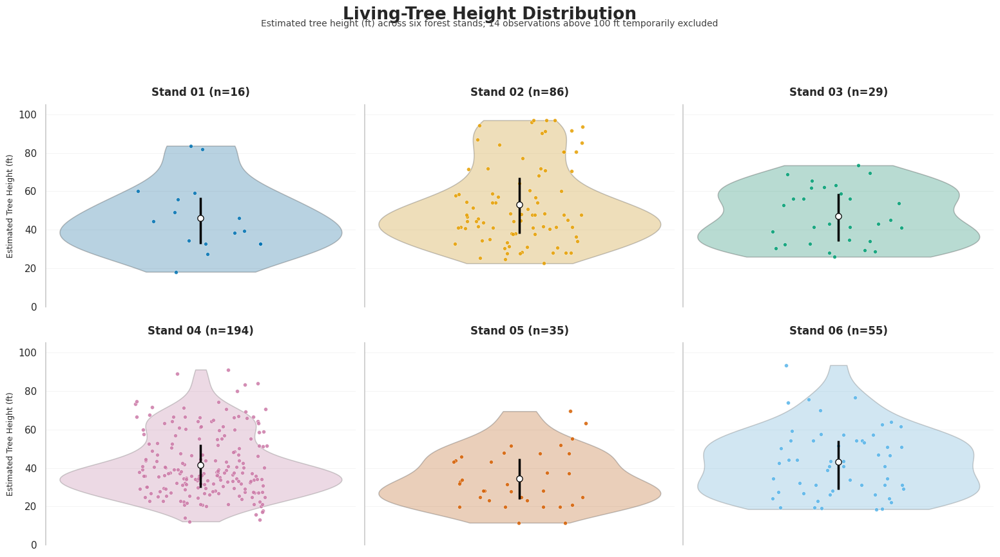

In [153]:

# STEP 138: Reconstruct the living-tree height distribution figure.
#
# Included tree statuses:
# AL = Alive
# DA = Damaged
# DY = Dying
#
# Height-specific exclusion:
# Measurements above 100 ft are excluded from this visualization.
# These exclusions do not affect the DBH or species-richness analyses.


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}


# ------------------------------------------------------------
# 3. PREPARE THE UPDATED LIVING-TREE HEIGHT DATA
# ------------------------------------------------------------

# Start with the updated living-tree dataset.
# This includes Alive, Damaged, and Dying trees.
height_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without a recorded estimated tree height.
height_df = height_df.dropna(
    subset=['Estimated Tree Height (ft)']
)

# Count the number of height observations above 100 ft
# before applying the visualization-specific exclusion.
excluded_height_df = height_df[
    height_df['Estimated Tree Height (ft)'] > 100
].copy()

# Count excluded observations by stand.
excluded_by_stand = (
    excluded_height_df.groupby('Stand ID')
    .size()
    .reindex(range(1, 7), fill_value=0)
)

# Exclude observations above 100 ft from this figure.
height_df = height_df[
    height_df['Estimated Tree Height (ft)'] <= 100
].copy()

# Remove any remaining invalid or nonpositive height measurements.
height_df = height_df[
    height_df['Estimated Tree Height (ft)'] > 0
].copy()


# ------------------------------------------------------------
# 4. VALIDATE THE UPDATED HEIGHT DATA
# ------------------------------------------------------------

# Calculate the number of observations remaining in each stand.
height_sample_sizes = (
    height_df.groupby('Stand ID')
    .size()
    .reindex(range(1, 7), fill_value=0)
)

# Print the number of observations excluded above 100 ft.
print("Height observations excluded above 100 ft:")
print(excluded_by_stand)

# Print the updated sample sizes used in the figure.
print("\nUpdated height sample sizes by stand:")
print(height_sample_sizes)

# Print the total number of excluded observations.
print(
    "\nTotal observations excluded:",
    int(excluded_by_stand.sum())
)

# Print the total number of observations used in the figure.
print(
    "Total observations included:",
    len(height_df)
)


# ------------------------------------------------------------
# 5. SET THE FIGURE STYLE AND CREATE SIX PANELS
# ------------------------------------------------------------

# Apply the clean white-grid plotting theme.
sns.set_theme(
    style='whitegrid',
    context='notebook'
)

# Create a two-row, three-column figure.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9),
    sharey=True
)

# Flatten the axes array for easier iteration.
axes = axes.flatten()


# ------------------------------------------------------------
# 6. PLOT THE HEIGHT DISTRIBUTION FOR EACH STAND
# ------------------------------------------------------------

# Loop through all six stands.
for stand, ax in zip(range(1, 7), axes):

    # Extract height measurements for the current stand.
    stand_data = height_df.loc[
        height_df['Stand ID'] == stand,
        'Estimated Tree Height (ft)'
    ].dropna()

    # Convert measurements into a NumPy array.
    height_values = stand_data.to_numpy()

    # Retrieve the original color for this stand.
    stand_color = stand_colors[stand]

    # Calculate the median height.
    median_height = np.median(height_values)

    # Calculate the first and third quartiles.
    q1 = np.percentile(height_values, 25)
    q3 = np.percentile(height_values, 75)

    # Calculate the mean height.
    mean_height = np.mean(height_values)

    # Draw the violin distribution.
    sns.violinplot(
        y=height_values,
        x=np.zeros(len(height_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make the violin transparent enough to show individual points.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate reproducible horizontal jitter for individual trees.
    rng = np.random.default_rng(seed=stand)

    # Slightly spread points horizontally to reduce overlap.
    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(height_values)
    )

    # Plot individual tree-height observations.
    ax.scatter(
        jitter,
        height_values,
        s=18,
        color=stand_color,
        edgecolor='white',
        linewidth=0.35,
        alpha=0.85,
        zorder=4
    )

    # Draw the interquartile range as a black vertical line.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='black',
        linewidth=2.5,
        zorder=5
    )

    # Add a white circular marker for the mean height.
    ax.scatter(
        0,
        mean_height,
        s=45,
        facecolor='white',
        edgecolor='black',
        linewidth=0.9,
        zorder=6
    )

    # Add the stand number and updated sample size.
    ax.set_title(
        f'Stand {stand:02d} (n={len(height_values)})',
        fontsize=12,
        fontweight='bold',
        pad=10
    )

    # Label the vertical axis.
    ax.set_ylabel(
        'Estimated Tree Height (ft)',
        fontsize=9
    )

    # Remove horizontal-axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Keep the same height scale across all six panels.
    ax.set_ylim(0, 105)

    # Add subtle horizontal gridlines.
    ax.grid(
        axis='y',
        alpha=0.25,
        linewidth=0.6
    )

    # Keep gridlines behind the plotted data.
    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    sns.despine(
        ax=ax,
        bottom=True
    )


# ------------------------------------------------------------
# 7. ADD THE FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main title.
fig.suptitle(
    'Living-Tree Height Distribution',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Add the subtitle with the actual number of excluded observations.
fig.text(
    0.5,
    0.945,
    (
        'Estimated tree height (ft) across six forest stands; '
        f'{len(excluded_height_df)} observations above 100 ft '
        'temporarily excluded'
    ),
    ha='center',
    fontsize=10,
    color='#404040'
)


# ------------------------------------------------------------
# 8. ADJUST SPACING
# ------------------------------------------------------------

# Adjust spacing to prevent titles and axes from overlapping.
plt.tight_layout(
    rect=[0.02, 0.02, 1, 0.91],
    h_pad=1.2,
    w_pad=0.8
)


# ------------------------------------------------------------
# 9. SAVE AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save the updated figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Living_Tree_Height_Distribution.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a vector PDF version.
fig.savefig(
    export_dir / 'Living_Tree_Height_Distribution.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


In [154]:

# STEP 139: Calculate descriptive statistics for living-tree height by stand.

# Group the filtered height dataset by Stand ID.
height_summary = (
    height_df
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .agg(
        n='count',                                      # Number of trees measured
        Mean='mean',                                    # Average tree height
        Median='median',                                # Middle tree height
        SD='std',                                       # Standard deviation
        Minimum='min',                                  # Shortest tree
        Q1=lambda x: x.quantile(0.25),                   # 25th percentile
        Q3=lambda x: x.quantile(0.75),                   # 75th percentile
        Maximum='max'                                   # Tallest tree
    )
    .reindex(range(1, 7))                               # Order stands 1–6
)

# Label the index as Stand.
height_summary.index.name = 'Stand'

# Round measurements to two decimal places.
height_summary = height_summary.round(2)

# Display the summary statistics table.
display(height_summary)

# Print the total number of observations included.
print(
    "Total height observations included:",
    int(height_summary['n'].sum())
)

# Print the total number of observations excluded above 100 ft.
print(
    "Total observations excluded above 100 ft:",
    len(excluded_height_df)
)


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand,,,,,,,,
1,16,45.99,41.83,18.41,18.04,32.81,56.59,83.66
2,86,53.09,47.70,20.86,22.47,37.90,67.05,96.95
3,29,47.15,43.18,14.50,25.89,33.96,58.92,73.49
4,194,41.67,37.40,16.41,12.14,29.69,52.35,91.21
5,35,34.39,31.82,14.19,11.48,23.79,44.92,69.55
6,55,43.06,42.65,17.34,18.54,28.71,54.13,93.50


Total height observations included: 415
Total observations excluded above 100 ft: 14


Observations available: 415


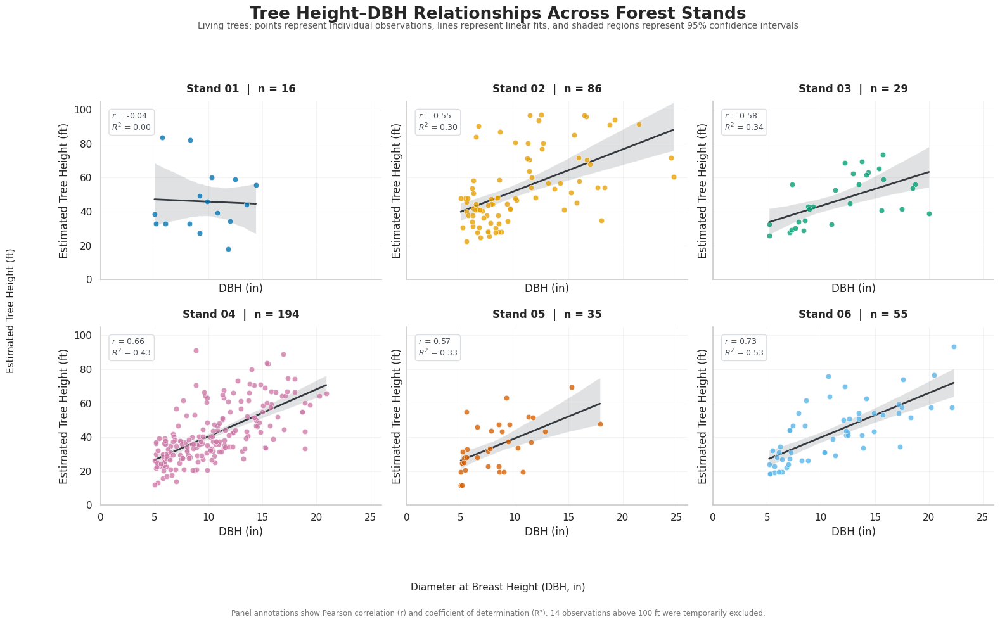

In [158]:

# STEP 142: Rebuild and display the complete height–DBH figure.
# This cell is self-contained and recreates the figure from scratch.

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}


# ------------------------------------------------------------
# 3. CONFIRM THE DATASET
# ------------------------------------------------------------

# Confirm that the prepared dataset contains observations.
print("Observations available:", len(height_dbh_df))


# ------------------------------------------------------------
# 4. CREATE A NEW FIGURE AND SIX PANELS
# ------------------------------------------------------------

# Apply the original plotting theme.
sns.set_theme(style='whitegrid', context='notebook')

# Create a fresh figure so no previous plotting errors carry over.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

# Flatten the axes for the plotting loop.
axes = axes.flatten()


# ------------------------------------------------------------
# 5. PLOT EACH STAND
# ------------------------------------------------------------

for stand, ax in zip(range(1, 7), axes):

    # Select the current stand's observations.
    stand_data = height_dbh_df[
        height_dbh_df['Stand ID'] == stand
    ].copy()

    # Extract DBH and height measurements.
    x = stand_data['DBH (in)']
    y = stand_data['Estimated Tree Height (ft)']

    # Retrieve the stand color.
    stand_color = stand_colors[stand]

    # Determine the sample size.
    n = len(stand_data)

    # Draw the regression line and 95% confidence interval.
    # Scatter is disabled here to avoid the previous error.
    sns.regplot(
        data=stand_data,
        x='DBH (in)',
        y='Estimated Tree Height (ft)',
        scatter=False,
        ci=95,
        color=stand_color,
        line_kws={
            'color': '#343A40',
            'linewidth': 2
        },
        ax=ax
    )

    # Add individual observations separately.
    ax.scatter(
        x,
        y,
        s=38,
        color=stand_color,
        alpha=0.78,
        edgecolors='white',
        linewidths=0.5,
        zorder=4
    )

    # Calculate Pearson correlation and R-squared.
    if n >= 2 and x.nunique() > 1 and y.nunique() > 1:

        r_value, p_value = pearsonr(x, y)
        r_squared = r_value ** 2

        annotation = (
            f'$r$ = {r_value:.2f}\n'
            f'$R^2$ = {r_squared:.2f}'
        )

    else:
        annotation = 'Insufficient data'

    # Add the statistical annotation.
    ax.text(
        0.04, 0.94,
        annotation,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=9,
        color='#495057',
        bbox={
            'boxstyle': 'round,pad=0.35',
            'facecolor': 'white',
            'edgecolor': '#D9DEE3',
            'alpha': 0.95
        }
    )

    # Add the stand title and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {n}',
        fontsize=12,
        fontweight='bold',
        pad=10
    )

    # Apply consistent axis limits.
    ax.set_xlim(0, 26)
    ax.set_ylim(0, 105)

    # Apply consistent tick intervals.
    ax.set_xticks(np.arange(0, 26, 5))
    ax.set_yticks(np.arange(0, 101, 20))

    # Add subtle gridlines.
    ax.grid(
        True,
        alpha=0.25,
        linewidth=0.6
    )

    # Keep gridlines behind the data.
    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    sns.despine(ax=ax)


# ------------------------------------------------------------
# 6. ADD FIGURE TITLES AND SHARED AXIS LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Tree Height–DBH Relationships Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# Add the explanatory subtitle.
fig.text(
    0.5, 0.945,
    'Living trees; points represent individual observations, '
    'lines represent linear fits, and shaded regions represent '
    '95% confidence intervals',
    ha='center',
    fontsize=10,
    color='#555555'
)

# Add shared axis labels.
fig.supxlabel(
    'Diameter at Breast Height (DBH, in)',
    fontsize=11,
    y=0.055
)

fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=11,
    x=0.015
)

# Add the footnote.
fig.text(
    0.5, 0.018,
    f'Panel annotations show Pearson correlation (r) and '
    f'coefficient of determination (R²). '
    f'{len(height_dbh_excluded)} observations above 100 ft '
    f'were temporarily excluded.',
    ha='center',
    fontsize=8.5,
    color='#777777'
)


# ------------------------------------------------------------
# 7. FINALIZE, EXPORT, AND DISPLAY
# ------------------------------------------------------------

# Adjust the layout.
plt.tight_layout(
    rect=[0.035, 0.09, 1, 0.92],
    h_pad=1.4,
    w_pad=1.0
)

# Save the PNG at high resolution.
fig.savefig(
    export_dir / 'Tree_Height_DBH_Relationships.png',
    dpi=600,
    bbox_inches='tight'
)

# Save the PDF version.
fig.savefig(
    export_dir / 'Tree_Height_DBH_Relationships.pdf',
    bbox_inches='tight'
)

# Explicitly render the figure.
plt.show()


Updated species contributions to stand basal area:


,Stand ID,Species Name,Total_Basal_Area,Tree_Count,Contribution (%)
2,1,Red Maple,2.84,3,27.34
0,1,American Beech,2.82,6,27.16
1,1,Eastern Hemlock,2.30,4,22.13
5,1,Yellow Birch,1.30,3,12.48
4,1,White Oak,0.58,1,5.54
3,1,Sugar Maple,0.56,1,5.36
7,2,Eastern Hemlock,18.83,27,27.86
9,2,Northern Red Oak,18.00,18,26.63
11,2,Sugar Maple,8.04,8,11.89
14,2,White Oak,8.03,9,11.89


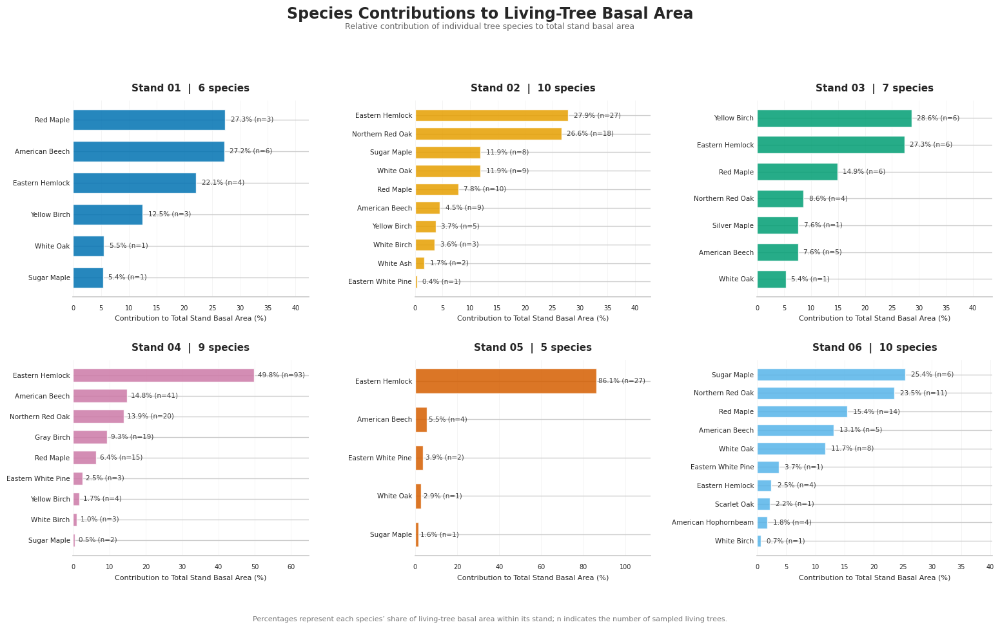

In [159]:

# STEP 143: Species Contributions to Living-Tree Basal Area
#
# Includes Alive (AL), Damaged (DA), and Dying (DY) trees.
# Excludes dead trees and records without DBH measurements.
#
# Basal area per tree is calculated from DBH in inches:
# BA (sq ft) = pi * (DBH / 24)^2


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}


# ------------------------------------------------------------
# 3. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Start with the updated living-tree population.
basal_species_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove trees without DBH or species identification.
basal_species_df = basal_species_df.dropna(
    subset=['DBH (in)', 'Species Name']
)

# Retain positive DBH measurements.
basal_species_df = basal_species_df[
    basal_species_df['DBH (in)'] > 0
].copy()

# Calculate basal area for each individual tree.
# DBH is divided by 24 to convert diameter in inches
# to radius in feet.
basal_species_df['Basal Area (sq ft)'] = (
    np.pi * (basal_species_df['DBH (in)'] / 24) ** 2
)


# ------------------------------------------------------------
# 4. SUM BASAL AREA BY STAND AND SPECIES
# ------------------------------------------------------------

# Sum individual tree basal area for each species in each stand.
species_basal_area = (
    basal_species_df
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Tree_Count=('DBH (in)', 'count')
    )
    .reset_index()
)

# Calculate total basal area within each stand.
stand_basal_totals = (
    species_basal_area
    .groupby('Stand ID')['Total_Basal_Area']
    .transform('sum')
)

# Calculate each species' percentage contribution to its stand.
species_basal_area['Contribution (%)'] = (
    species_basal_area['Total_Basal_Area']
    / stand_basal_totals * 100
)

# Print the updated species contribution table.
print("Updated species contributions to stand basal area:")
display(
    species_basal_area.sort_values(
        ['Stand ID', 'Contribution (%)'],
        ascending=[True, False]
    ).round(2)
)


# ------------------------------------------------------------
# 5. CREATE THE SIX-PANEL FIGURE
# ------------------------------------------------------------

# Create a two-row, three-column layout.
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

# Flatten the axes for easier iteration.
axes = axes.flatten()


# ------------------------------------------------------------
# 6. DRAW SPECIES CONTRIBUTION BARS
# ------------------------------------------------------------

# Plot each stand separately.
for stand, ax in zip(range(1, 7), axes):

    # Select species data for the current stand.
    stand_data = species_basal_area[
        species_basal_area['Stand ID'] == stand
    ].copy()

    # Sort species from greatest to smallest contribution.
    stand_data = stand_data.sort_values(
        'Contribution (%)',
        ascending=True
    )

    # Retrieve the original stand color.
    stand_color = stand_colors[stand]

    # Draw horizontal bars.
    bars = ax.barh(
        stand_data['Species Name'],
        stand_data['Contribution (%)'],
        color=stand_color,
        height=0.65,
        alpha=0.85
    )

    # Add percentage and tree-count labels to each bar.
    for bar, (_, record) in zip(bars, stand_data.iterrows()):

        # Retrieve the bar's endpoint.
        bar_width = bar.get_width()

        # Add the percentage and tree count.
        ax.text(
            bar_width + 1.0,
            bar.get_y() + bar.get_height() / 2,
            f"{record['Contribution (%)']:.1f}% (n={int(record['Tree_Count'])})",
            va='center',
            fontsize=7.5,
            color='#404040'
        )

    # Calculate the number of species in the stand.
    species_count = len(stand_data)

    # Add the stand title.
    ax.set_title(
        f'Stand {stand:02d}  |  {species_count} species',
        fontsize=11,
        fontweight='bold',
        pad=10
    )

    # Label the horizontal axis.
    ax.set_xlabel(
        'Contribution to Total Stand Basal Area (%)',
        fontsize=8
    )

    # Remove the vertical-axis label.
    ax.set_ylabel('')

    # Set the horizontal limit based on the largest contribution.
    max_contribution = stand_data['Contribution (%)'].max()

    ax.set_xlim(
        0,
        max_contribution + max(15, max_contribution * 0.30)
    )

    # Format gridlines.
    ax.grid(
        axis='x',
        alpha=0.25,
        linewidth=0.6
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Format species labels.
    ax.tick_params(
        axis='y',
        labelsize=7.5,
        length=0
    )

    ax.tick_params(
        axis='x',
        labelsize=7
    )

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)


# ------------------------------------------------------------
# 7. ADD FIGURE TITLE AND FOOTNOTE
# ------------------------------------------------------------

fig.suptitle(
    'Species Contributions to Living-Tree Basal Area',
    fontsize=17,
    fontweight='bold',
    y=0.98
)

fig.text(
    0.5,
    0.945,
    'Relative contribution of individual tree species to total stand basal area',
    ha='center',
    fontsize=9,
    color='#666666'
)

fig.text(
    0.5,
    0.025,
    'Percentages represent each species’ share of living-tree basal area within its stand; '
    'n indicates the number of sampled living trees.',
    ha='center',
    fontsize=8,
    color='#777777'
)

# Adjust spacing.
plt.tight_layout(
    rect=[0.02, 0.07, 1, 0.92],
    h_pad=2.0,
    w_pad=2.0
)


# ------------------------------------------------------------
# 8. SAVE AND DISPLAY
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'Species_Contributions_Living_Tree_Basal_Area.png',
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Species_Contributions_Living_Tree_Basal_Area.pdf',
    bbox_inches='tight'
)

plt.show()


Subplot area (sq ft): 7238.23
Expansion factor: 6.018
Subplot-level basal area:


,Stand ID,Plot ID,Subplot ID,Total_Basal_Area,Tree_Count,Basal Area (sq ft/acre)
0,1,1,1,10.387,18,62.509
1,2,1,1,1.382,1,8.319
2,2,1,2,1.882,2,11.328
3,2,1,3,1.710,6,10.290
4,2,2,1,9.699,7,58.369
5,2,2,2,5.360,10,32.258
6,2,2,3,3.496,4,21.041
7,2,2,4,3.424,8,20.605
8,2,3,1,4.032,6,24.265
9,2,3,2,6.487,6,39.040


Basal area density summary by stand:


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand ID,,,,,,,,
1,1,62.51,62.51,NaN,62.51,62.51,62.51,62.51
2,15,27.11,24.27,15.98,8.32,13.61,35.65,58.37
3,6,25.17,23.15,8.57,14.60,20.33,30.89,37.27
4,22,38.52,36.41,13.58,13.57,29.55,46.78,78.41
5,3,29.05,24.32,16.81,15.12,19.72,36.02,47.72
6,7,38.33,37.38,15.26,18.07,29.14,45.94,62.69


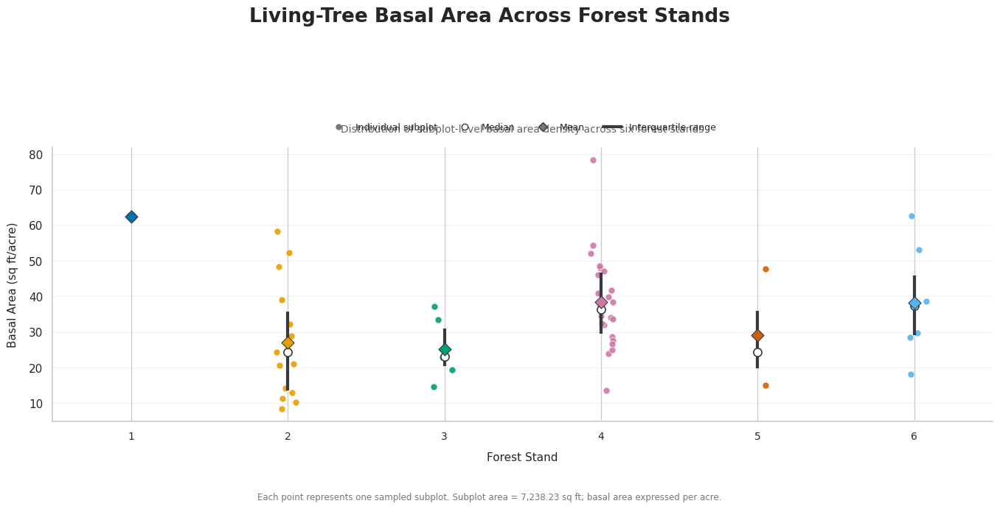

In [160]:

# STEP 144: Living-Tree Basal Area Across Forest Stands
#
# Each point represents one sampled subplot.
# Basal area is calculated from individual living trees,
# then summed within each subplot.
#
# Includes Alive (AL), Damaged (DA), and Dying (DY) trees.
#
# Subplot area = 7,238.23 sq ft
# Basal area density = subplot basal area * 43,560 / subplot area


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}


# ------------------------------------------------------------
# 3. DEFINE THE SUBPLOT AREA
# ------------------------------------------------------------

# Each subplot has an area of 7,238.23 square feet.
subplot_area_sqft = 7238.23

# One acre contains 43,560 square feet.
sqft_per_acre = 43560

# Calculate the expansion factor used to express basal area per acre.
expansion_factor = sqft_per_acre / subplot_area_sqft

print("Subplot area (sq ft):", subplot_area_sqft)
print("Expansion factor:", round(expansion_factor, 4))


# ------------------------------------------------------------
# 4. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Start with the updated living-tree population.
subplot_basal_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without DBH measurements.
subplot_basal_df = subplot_basal_df.dropna(
    subset=['DBH (in)', 'Plot ID', 'Subplot ID']
)

# Retain positive DBH measurements.
subplot_basal_df = subplot_basal_df[
    subplot_basal_df['DBH (in)'] > 0
].copy()

# Calculate basal area for every individual tree in square feet.
subplot_basal_df['Basal Area (sq ft)'] = (
    np.pi * (subplot_basal_df['DBH (in)'] / 24) ** 2
)


# ------------------------------------------------------------
# 5. CALCULATE TOTAL BASAL AREA WITHIN EACH SUBPLOT
# ------------------------------------------------------------

# Sum tree basal area within each unique stand, plot, and subplot.
subplot_basal_summary = (
    subplot_basal_df
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])
    .agg(
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Tree_Count=('DBH (in)', 'count')
    )
    .reset_index()
)

# Convert subplot basal area to basal area per acre.
subplot_basal_summary['Basal Area (sq ft/acre)'] = (
    subplot_basal_summary['Total_Basal_Area']
    * expansion_factor
)

# Display the subplot-level results.
print("Subplot-level basal area:")
display(subplot_basal_summary.round(3))


# ------------------------------------------------------------
# 6. CALCULATE STAND-LEVEL SUMMARY STATISTICS
# ------------------------------------------------------------

# Calculate descriptive statistics for subplot basal area density.
subplot_basal_stats = (
    subplot_basal_summary
    .groupby('Stand ID')['Basal Area (sq ft/acre)']
    .agg(
        n='count',
        Mean='mean',
        Median='median',
        SD='std',
        Minimum='min',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reindex(range(1, 7))
)

# Display the summary table rounded to two decimal places.
print("Basal area density summary by stand:")
display(subplot_basal_stats.round(2))


# ------------------------------------------------------------
# 7. CREATE THE FIGURE
# ------------------------------------------------------------

# Create a wide single-panel figure.
fig, ax = plt.subplots(
    figsize=(14, 7)
)

# Plot each stand separately.
for stand in range(1, 7):

    # Extract basal area values for the current stand.
    stand_values = subplot_basal_summary.loc[
        subplot_basal_summary['Stand ID'] == stand,
        'Basal Area (sq ft/acre)'
    ].dropna().to_numpy()

    # Skip stands without observations.
    if len(stand_values) == 0:
        continue

    # Retrieve the original stand color.
    stand_color = stand_colors[stand]

    # Calculate the median, mean, and quartiles.
    median_value = np.median(stand_values)
    mean_value = np.mean(stand_values)
    q1 = np.percentile(stand_values, 25)
    q3 = np.percentile(stand_values, 75)

    # Generate reproducible horizontal jitter.
    rng = np.random.default_rng(seed=stand)

    jitter = rng.uniform(
        -0.08,
        0.08,
        size=len(stand_values)
    )

    # Plot each subplot as an individual point.
    ax.scatter(
        np.full(len(stand_values), stand) + jitter,
        stand_values,
        s=42,
        color=stand_color,
        alpha=0.90,
        edgecolors='white',
        linewidths=0.5,
        zorder=3
    )

    # Draw the interquartile range.
    ax.vlines(
        stand,
        q1,
        q3,
        color='#343A40',
        linewidth=3,
        zorder=4
    )

    # Add a hollow circle for the median.
    ax.scatter(
        stand,
        median_value,
        s=65,
        marker='o',
        facecolor='white',
        edgecolor='#343A40',
        linewidth=1.2,
        zorder=5
    )

    # Add a diamond for the mean.
    ax.scatter(
        stand,
        mean_value,
        s=75,
        marker='D',
        color=stand_color,
        edgecolor='#343A40',
        linewidth=0.8,
        zorder=6
    )


# ------------------------------------------------------------
# 8. FORMAT THE AXES
# ------------------------------------------------------------

# Label the six stands.
ax.set_xticks(range(1, 7))
ax.set_xticklabels(
    [str(i) for i in range(1, 7)],
    fontsize=10
)

# Set the horizontal axis limits.
ax.set_xlim(0.5, 6.5)

# Label the axes.
ax.set_xlabel(
    'Forest Stand',
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    'Basal Area (sq ft/acre)',
    fontsize=11,
    labelpad=10
)

# Add subtle horizontal gridlines.
ax.grid(
    axis='y',
    alpha=0.25,
    linewidth=0.7
)

# Keep gridlines behind the observations.
ax.set_axisbelow(True)

# Remove unnecessary borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


# ------------------------------------------------------------
# 9. ADD THE LEGEND
# ------------------------------------------------------------

# Create legend handles for each summary statistic.
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='#777777',
        markersize=5,
        label='Individual subplot'
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='white',
        markeredgecolor='#343A40',
        markersize=6,
        label='Median'
    ),
    Line2D(
        [0], [0],
        marker='D',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='#343A40',
        markersize=6,
        label='Mean'
    ),
    Line2D(
        [0], [0],
        color='#343A40',
        linewidth=3,
        label='Interquartile range'
    )
]

# Place the legend above the plotting area.
ax.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=4,
    frameon=False,
    fontsize=9
)


# ------------------------------------------------------------
# 10. ADD THE FIGURE TITLE AND FOOTNOTE
# ------------------------------------------------------------

fig.suptitle(
    'Living-Tree Basal Area Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.98
)

ax.set_title(
    'Distribution of subplot-level basal area density across six forest stands',
    fontsize=10,
    color='#666666',
    pad=15
)

# Add a note explaining the observations.
fig.text(
    0.5,
    0.025,
    (
        'Each point represents one sampled subplot. '
        f'Subplot area = {subplot_area_sqft:,.2f} sq ft; '
        'basal area expressed per acre.'
    ),
    ha='center',
    fontsize=8.5,
    color='#777777'
)

# Adjust spacing.
plt.tight_layout(
    rect=[0.02, 0.07, 1, 0.88]
)


# ------------------------------------------------------------
# 11. SAVE AND DISPLAY
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'Living_Tree_Basal_Area_Across_Stands.png',
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Living_Tree_Basal_Area_Across_Stands.pdf',
    bbox_inches='tight'
)

plt.show()


Subplot area: 7238.23 sq ft
Basal area expansion factor: 6.018

Individual living trees included: 429


,Stand ID,Plot ID,Subplot ID,DBH (in),Basal Area (sq ft)
0,1,1,1,8.30,0.375737
1,1,1,1,8.25,0.371223
2,1,1,1,13.52,0.996967
3,1,1,1,5.98,0.195043
4,1,1,1,11.80,0.759436



Sampled subplots by stand:
Stand ID
1     1
2    15
3     6
4    22
5     3
6     7
dtype: int64

Total sampled subplots: 54

Subplot-level basal area density summary:


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand,,,,,,,,
1,1,62.51,62.51,NaN,62.51,62.51,62.51,62.51
2,15,27.11,24.27,15.98,8.32,13.61,35.65,58.37
3,6,25.17,23.15,8.57,14.60,20.33,30.89,37.27
4,22,38.52,36.41,13.58,13.57,29.55,46.78,78.41
5,3,29.05,24.32,16.81,15.12,19.72,36.02,47.72
6,7,38.33,37.38,15.26,18.07,29.14,45.94,62.69


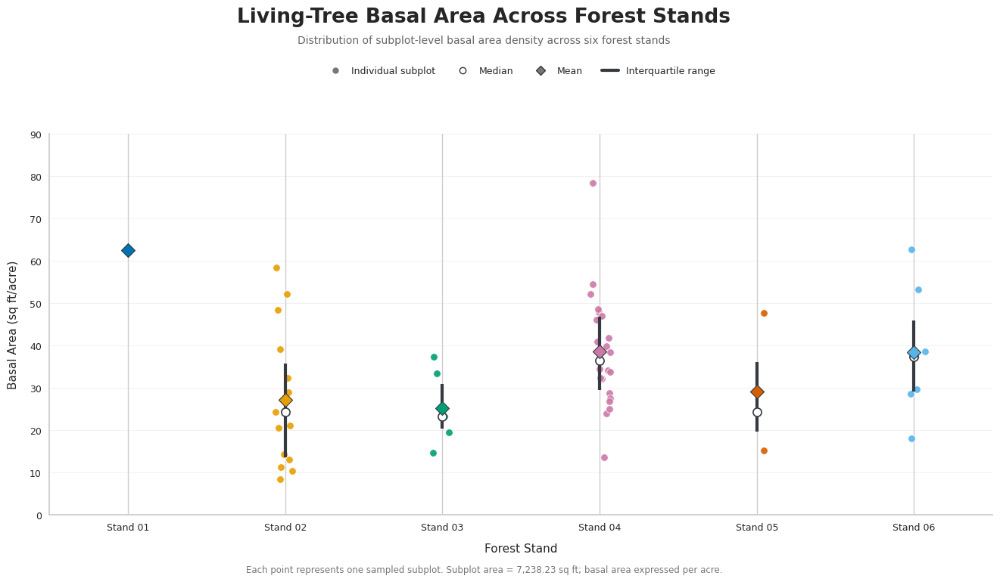

In [161]:

# STEP 146: Living-Tree Basal Area Across Forest Stands
#
# PURPOSE:
# Visualize the distribution of living-tree basal area density
# among sampled subplots across six forest stands.
#
# INCLUDED TREE STATUS CATEGORIES:
# AL = Alive
# DA = Damaged
# DY = Dying
#
# CALCULATIONS:
# Individual tree basal area (sq ft) = pi * (DBH / 24)^2
# Subplot basal area = sum of individual tree basal areas
# Basal area density (sq ft/acre) =
#     subplot basal area * 43,560 / subplot area
#
# Each point represents one sampled subplot.
# Diamond = mean
# Hollow circle = median
# Vertical line = interquartile range


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

# Import Matplotlib for figure creation and formatting.
import matplotlib.pyplot as plt

# Import NumPy for mathematical calculations and point placement.
import numpy as np

# Import Pandas for grouping and summarizing the inventory data.
import pandas as pd

# Import Line2D to create custom legend symbols.
from matplotlib.lines import Line2D


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

# Retain the original six colors used throughout the project.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}


# ------------------------------------------------------------
# 3. DEFINE THE SUBPLOT SAMPLING AREA
# ------------------------------------------------------------

# Set the sampled subplot area in square feet.
subplot_area_sqft = 7238.23

# Define the number of square feet in one acre.
sqft_per_acre = 43560

# Calculate the factor used to expand subplot basal area
# into basal area per acre.
expansion_factor = sqft_per_acre / subplot_area_sqft

# Print the sampling area and expansion factor.
print("Subplot area:", subplot_area_sqft, "sq ft")
print("Basal area expansion factor:", round(expansion_factor, 4))


# ------------------------------------------------------------
# 4. PREPARE THE UPDATED LIVING-TREE DATASET
# ------------------------------------------------------------

# Start with the updated living-tree inventory.
# This dataset should already include AL, DA, and DY trees.
basal_area_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without DBH measurements.
# Trees without DBH cannot contribute a calculated basal area.
basal_area_df = basal_area_df.dropna(
    subset=['DBH (in)']
)

# Remove records with missing plot or subplot identifiers.
# These identifiers are necessary to calculate subplot totals.
basal_area_df = basal_area_df.dropna(
    subset=['Plot ID', 'Subplot ID']
)

# Retain only positive DBH measurements.
basal_area_df = basal_area_df[
    basal_area_df['DBH (in)'] > 0
].copy()

# Print the number of individual trees included.
print(
    "\nIndividual living trees included:",
    len(basal_area_df)
)


# ------------------------------------------------------------
# 5. CALCULATE INDIVIDUAL TREE BASAL AREA
# ------------------------------------------------------------

# Calculate basal area for each individual tree.
# DBH is measured in inches, so dividing by 24 converts
# diameter into radius in feet.
basal_area_df['Basal Area (sq ft)'] = (
    np.pi * (basal_area_df['DBH (in)'] / 24) ** 2
)

# Display the first few calculated records for inspection.
display(
    basal_area_df[
        [
            'Stand ID',
            'Plot ID',
            'Subplot ID',
            'DBH (in)',
            'Basal Area (sq ft)'
        ]
    ].head()
)


# ------------------------------------------------------------
# 6. CALCULATE TOTAL BASAL AREA WITHIN EACH SUBPLOT
# ------------------------------------------------------------

# Group individual trees by stand, plot, and subplot.
# Sum their basal areas to obtain total subplot basal area.
subplot_basal_summary = (
    basal_area_df
    .groupby(
        ['Stand ID', 'Plot ID', 'Subplot ID']
    )
    .agg(
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Tree_Count=('DBH (in)', 'count')
    )
    .reset_index()
)

# Convert subplot basal area into basal area per acre.
subplot_basal_summary['Basal Area (sq ft/acre)'] = (
    subplot_basal_summary['Total_Basal_Area']
    * expansion_factor
)

# Print the number of sampled subplots in each stand.
subplot_counts = (
    subplot_basal_summary
    .groupby('Stand ID')
    .size()
    .reindex(range(1, 7), fill_value=0)
)

print("\nSampled subplots by stand:")
print(subplot_counts)

# Print the total number of sampled subplots.
print(
    "\nTotal sampled subplots:",
    len(subplot_basal_summary)
)


# ------------------------------------------------------------
# 7. CALCULATE STAND-LEVEL SUMMARY STATISTICS
# ------------------------------------------------------------

# Calculate descriptive statistics for subplot basal area density.
subplot_basal_stats = (
    subplot_basal_summary
    .groupby('Stand ID')['Basal Area (sq ft/acre)']
    .agg(
        n='count',
        Mean='mean',
        Median='median',
        SD='std',
        Minimum='min',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reindex(range(1, 7))
)

# Label the table index.
subplot_basal_stats.index.name = 'Stand'

# Round numerical values to two decimal places.
subplot_basal_stats = subplot_basal_stats.round(2)

# Display the completed summary statistics.
print("\nSubplot-level basal area density summary:")
display(subplot_basal_stats)


# ------------------------------------------------------------
# 8. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a wide figure with enough space for the title and legend.
fig, ax = plt.subplots(
    figsize=(14, 8)
)

# Set the figure background to white.
fig.patch.set_facecolor('white')

# Set the plotting background to white.
ax.set_facecolor('white')


# ------------------------------------------------------------
# 9. PLOT INDIVIDUAL SUBPLOT OBSERVATIONS
# ------------------------------------------------------------

# Loop through the six stands.
for stand in range(1, 7):

    # Extract subplot basal area density for the current stand.
    stand_values = subplot_basal_summary.loc[
        subplot_basal_summary['Stand ID'] == stand,
        'Basal Area (sq ft/acre)'
    ].dropna().to_numpy()

    # Skip stands without sampled subplot observations.
    if len(stand_values) == 0:
        continue

    # Retrieve the original color for this stand.
    stand_color = stand_colors[stand]

    # Calculate the mean basal area density.
    mean_value = np.mean(stand_values)

    # Calculate the median basal area density.
    median_value = np.median(stand_values)

    # Calculate the first quartile.
    q1 = np.percentile(stand_values, 25)

    # Calculate the third quartile.
    q3 = np.percentile(stand_values, 75)

    # Generate reproducible horizontal jitter.
    # This prevents observations with similar values from overlapping.
    rng = np.random.default_rng(seed=stand)

    jitter = rng.uniform(
        -0.07,
        0.07,
        size=len(stand_values)
    )

    # Plot each individual subplot observation.
    ax.scatter(
        np.full(len(stand_values), stand) + jitter,
        stand_values,
        s=48,
        color=stand_color,
        alpha=0.90,
        edgecolors='white',
        linewidths=0.6,
        zorder=3
    )

    # Draw the interquartile range as a vertical line.
    ax.vlines(
        stand,
        q1,
        q3,
        color='#343A40',
        linewidth=3,
        zorder=4
    )

    # Add a hollow circle representing the median.
    ax.scatter(
        stand,
        median_value,
        s=65,
        marker='o',
        facecolor='white',
        edgecolor='#343A40',
        linewidth=1.2,
        zorder=5
    )

    # Add a colored diamond representing the mean.
    ax.scatter(
        stand,
        mean_value,
        s=85,
        marker='D',
        color=stand_color,
        edgecolor='#343A40',
        linewidth=0.8,
        zorder=6
    )


# ------------------------------------------------------------
# 10. FORMAT THE HORIZONTAL AXIS
# ------------------------------------------------------------

# Position the six stands at equally spaced locations.
ax.set_xticks(range(1, 7))

# Label each stand with a two-digit identifier.
ax.set_xticklabels(
    [f'Stand {i:02d}' for i in range(1, 7)],
    fontsize=10
)

# Set the horizontal-axis limits.
ax.set_xlim(0.5, 6.5)

# Label the horizontal axis.
ax.set_xlabel(
    'Forest Stand',
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# 11. FORMAT THE VERTICAL AXIS
# ------------------------------------------------------------

# Find the largest subplot basal area density.
maximum_value = subplot_basal_summary[
    'Basal Area (sq ft/acre)'
].max()

# Round the upper limit upward to the next 10-unit interval,
# then add an additional 10 units of visual space.
upper_limit = (
    np.ceil(maximum_value / 10) * 10 + 10
)

# Start the vertical axis at zero.
ax.set_ylim(
    0,
    upper_limit
)

# Set the vertical-axis ticks at 10-unit intervals.
ax.set_yticks(
    np.arange(0, upper_limit + 1, 10)
)

# Label the vertical axis.
ax.set_ylabel(
    'Basal Area (sq ft/acre)',
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# 12. FORMAT GRIDLINES AND AXIS BORDERS
# ------------------------------------------------------------

# Add subtle horizontal gridlines.
ax.grid(
    axis='y',
    alpha=0.25,
    linewidth=0.7
)

# Keep gridlines behind the observations.
ax.set_axisbelow(True)

# Remove the upper and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep the remaining axis borders subtle.
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

# Format tick labels.
ax.tick_params(
    axis='both',
    labelsize=9,
    length=4,
    color='#999999'
)


# ------------------------------------------------------------
# 13. CREATE THE LEGEND
# ------------------------------------------------------------

# Define a custom legend symbol for individual subplot observations.
individual_handle = Line2D(
    [0], [0],
    marker='o',
    linestyle='none',
    markerfacecolor='#777777',
    markeredgecolor='#777777',
    markersize=5,
    label='Individual subplot'
)

# Define a custom legend symbol for the median.
median_handle = Line2D(
    [0], [0],
    marker='o',
    linestyle='none',
    markerfacecolor='white',
    markeredgecolor='#343A40',
    markersize=6,
    label='Median'
)

# Define a custom legend symbol for the mean.
mean_handle = Line2D(
    [0], [0],
    marker='D',
    linestyle='none',
    markerfacecolor='#777777',
    markeredgecolor='#343A40',
    markersize=6,
    label='Mean'
)

# Define a custom legend symbol for the interquartile range.
iqr_handle = Line2D(
    [0], [0],
    color='#343A40',
    linewidth=3,
    label='Interquartile range'
)

# Add the legend above the plotting area.
ax.legend(
    handles=[
        individual_handle,
        median_handle,
        mean_handle,
        iqr_handle
    ],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.20),
    ncol=4,
    frameon=False,
    fontsize=9,
    handlelength=1.8,
    columnspacing=2.0
)


# ------------------------------------------------------------
# 14. ADD THE FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Basal Area Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.97
)

# Add the subtitle separately from the legend.
fig.text(
    0.5,
    0.91,
    'Distribution of subplot-level basal area density across six forest stands',
    ha='center',
    fontsize=10,
    color='#666666'
)


# ------------------------------------------------------------
# 15. ADD THE FIGURE FOOTNOTE
# ------------------------------------------------------------

# Describe the observations and sampling area.
fig.text(
    0.5,
    0.035,
    (
        'Each point represents one sampled subplot. '
        f'Subplot area = {subplot_area_sqft:,.2f} sq ft; '
        'basal area expressed per acre.'
    ),
    ha='center',
    fontsize=8.5,
    color='#777777'
)


# ------------------------------------------------------------
# 16. FINALIZE THE FIGURE LAYOUT
# ------------------------------------------------------------

# Explicitly position the plotting area.
# This prevents the title, subtitle, and legend from overlapping.
fig.subplots_adjust(
    top=0.76,
    bottom=0.13,
    left=0.09,
    right=0.98
)


# ------------------------------------------------------------
# 17. SAVE THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'Living_Tree_Basal_Area_Across_Stands.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a vector PDF for publication-quality use.
fig.savefig(
    export_dir / 'Living_Tree_Basal_Area_Across_Stands.pdf',
    bbox_inches='tight'
)


# ------------------------------------------------------------
# 18. DISPLAY THE COMPLETED FIGURE
# ------------------------------------------------------------

# Render the finished figure in the notebook.
plt.show()


In [162]:

# STEP 147: Generate both living-tree basal-area summary tables.


# ------------------------------------------------------------
# 1. TREE-LEVEL BASAL AREA SUMMARY BY STAND
# ------------------------------------------------------------

# Group individual living trees by stand.
# Calculate the number of trees, mean basal area per tree,
# and total sampled basal area for each stand.
tree_basal_area_stats = (
    basal_area_df
    .groupby('Stand ID')
    .agg(
        Trees=('Basal Area (sq ft)', 'count'),
        Mean_Basal_Area=('Basal Area (sq ft)', 'mean'),
        Total_Sampled_Basal_Area=('Basal Area (sq ft)', 'sum')
    )
    .reindex(range(1, 7))
)

# Rename the stand index.
tree_basal_area_stats.index.name = 'Stand'

# Rename columns for presentation.
tree_basal_area_stats = tree_basal_area_stats.rename(
    columns={
        'Mean_Basal_Area': 'Mean basal area (ft²/tree)',
        'Total_Sampled_Basal_Area': 'Total sampled basal area (ft²)'
    }
)

# Round basal-area measurements to three decimal places.
tree_basal_area_stats = tree_basal_area_stats.round(3)

# Display the tree-level summary table.
print("TREE-LEVEL BASAL AREA SUMMARY")
display(tree_basal_area_stats)

# Print the total number of individual trees.
print(
    "Total living trees:",
    int(tree_basal_area_stats['Trees'].sum())
)


# ------------------------------------------------------------
# 2. SUBPLOT-LEVEL BASAL AREA DENSITY SUMMARY BY STAND
# ------------------------------------------------------------

# Group subplot-level basal area density by stand.
# Calculate the mean basal area per acre and subplot count.
subplot_basal_area_stats = (
    subplot_basal_summary
    .groupby('Stand ID')
    .agg(
        Mean_Basal_Area_per_Acre=(
            'Basal Area (sq ft/acre)',
            'mean'
        ),
        Subplots=('Basal Area (sq ft/acre)', 'count')
    )
    .reindex(range(1, 7))
)

# Rename the stand index.
subplot_basal_area_stats.index.name = 'Stand'

# Rename the mean basal-area column.
subplot_basal_area_stats = subplot_basal_area_stats.rename(
    columns={
        'Mean_Basal_Area_per_Acre': 'Mean basal area (ft²/acre)'
    }
)

# Round basal-area density to two decimal places.
subplot_basal_area_stats = subplot_basal_area_stats.round(2)

# Display the subplot-level summary table.
print("\nSUBPLOT-LEVEL BASAL AREA DENSITY SUMMARY")
display(subplot_basal_area_stats)

# Print the total number of sampled subplots.
print(
    "Total sampled subplots:",
    int(subplot_basal_area_stats['Subplots'].sum())
)


# ------------------------------------------------------------
# 3. EXPORT BOTH TABLES
# ------------------------------------------------------------

# Export the tree-level summary as a CSV file.
tree_basal_area_stats.to_csv(
    export_dir / 'Living_Tree_Basal_Area_Summary.csv'
)

# Export the subplot-level summary as a CSV file.
subplot_basal_area_stats.to_csv(
    export_dir / 'Living_Tree_Subplot_Basal_Area_Summary.csv'
)

print("\nBoth summary tables have been exported.")


TREE-LEVEL BASAL AREA SUMMARY


,Trees,Mean basal area (ft²/tree),Total sampled basal area (ft²)
Stand,,,
1,18,0.577,10.387
2,92,0.735,67.579
3,29,0.865,25.098
4,200,0.704,140.831
5,35,0.414,14.484
6,55,0.811,44.582


Total living trees: 429

SUBPLOT-LEVEL BASAL AREA DENSITY SUMMARY


,Mean basal area (ft²/acre),Subplots
Stand,,
1,62.51,1
2,27.11,15
3,25.17,6
4,38.52,22
5,29.05,3
6,38.33,7


Total sampled subplots: 54

Both summary tables have been exported.


In [163]:

# STEP 148: Calculate tree species relative abundance by stand.
#
# Includes:
# AL = Alive
# DA = Damaged
# DY = Dying
#
# Relative abundance (%) =
# (Number of individuals of a species / Total living trees in stand) * 100


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

# Import Pandas for grouping and summarizing the tree inventory.
import pandas as pd

# Import NumPy for numerical validation.
import numpy as np


# ------------------------------------------------------------
# 2. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Use the updated living-tree dataset containing AL, DA, and DY.
# Restrict the analysis to the six study stands.
tree_composition_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without a species identification.
# Unidentified trees cannot be assigned to a species category.
tree_composition_df = tree_composition_df.dropna(
    subset=['Species Name']
)

# Remove any accidental whitespace from species names.
tree_composition_df['Species Name'] = (
    tree_composition_df['Species Name']
    .astype(str)
    .str.strip()
)

# Remove blank species-name records.
tree_composition_df = tree_composition_df[
    tree_composition_df['Species Name'] != ''
].copy()


# ------------------------------------------------------------
# 3. COUNT INDIVIDUAL TREES BY SPECIES AND STAND
# ------------------------------------------------------------

# Count the number of individual trees belonging to each species
# within each stand.
tree_species_counts = (
    tree_composition_df
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='Tree Count')
)

# Calculate the total number of living trees in each stand.
stand_tree_totals = (
    tree_species_counts
    .groupby('Stand ID')['Tree Count']
    .sum()
    .rename('Stand Total')
)

# Attach each stand's total tree count to the species table.
tree_species_counts = tree_species_counts.merge(
    stand_tree_totals,
    on='Stand ID',
    how='left'
)


# ------------------------------------------------------------
# 4. CALCULATE RELATIVE ABUNDANCE
# ------------------------------------------------------------

# Calculate each species' percentage contribution to the
# total number of living trees within its stand.
tree_species_counts['Relative Abundance (%)'] = (
    tree_species_counts['Tree Count']
    / tree_species_counts['Stand Total']
    * 100
)

# Round relative abundance to two decimal places.
tree_species_counts['Relative Abundance (%)'] = (
    tree_species_counts['Relative Abundance (%)'].round(2)
)


# ------------------------------------------------------------
# 5. SORT THE RESULTS
# ------------------------------------------------------------

# Sort species within each stand from greatest to lowest
# relative abundance.
tree_species_counts = tree_species_counts.sort_values(
    ['Stand ID', 'Relative Abundance (%)'],
    ascending=[True, False]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. DISPLAY THE RELATIVE ABUNDANCE TABLE
# ------------------------------------------------------------

# Display the complete species-level results.
print("TREE SPECIES RELATIVE ABUNDANCE BY STAND")

display(tree_species_counts)


# ------------------------------------------------------------
# 7. VALIDATE THE RESULTS
# ------------------------------------------------------------

# Sum relative abundance within each stand.
# Each stand should total approximately 100%.
relative_abundance_check = (
    tree_species_counts
    .groupby('Stand ID')['Relative Abundance (%)']
    .sum()
)

print("\nRelative abundance totals by stand:")
display(relative_abundance_check.round(2))

# Print the number of individual trees represented.
print(
    "\nTotal trees represented:",
    int(tree_species_counts['Tree Count'].sum())
)

# Print the total number of unique tree species.
print(
    "Total unique tree species:",
    tree_species_counts['Species Name'].nunique()
)

# Check whether relative abundance sums to approximately 100%.
assert np.allclose(
    relative_abundance_check.values,
    100,
    atol=0.1
), "Relative abundance does not sum to approximately 100% in every stand."

print("\nValidation passed: relative abundance sums to approximately 100% per stand.")


TREE SPECIES RELATIVE ABUNDANCE BY STAND


,Stand ID,Species Name,Tree Count,Stand Total,Relative Abundance (%)
0,1,American Beech,6,18,33.33
1,1,Eastern Hemlock,4,18,22.22
2,1,Red Maple,3,18,16.67
3,1,Yellow Birch,3,18,16.67
4,1,Sugar Maple,1,18,5.56
5,1,White Oak,1,18,5.56
6,2,Eastern Hemlock,27,92,29.35
7,2,Northern Red Oak,18,92,19.57
8,2,Red Maple,10,92,10.87
9,2,American Beech,9,92,9.78



Relative abundance totals by stand:


,Relative Abundance (%)
Stand ID,
1,100.01
2,100.00
3,100.00
4,100.00
5,100.00
6,100.00



Total trees represented: 429
Total unique tree species: 14

Validation passed: relative abundance sums to approximately 100% per stand.


In [165]:
# STEP 150: Inspect the actual herbaceous percent-cover values.

# Display the frequency of every recorded percent-cover value.
print("Herbaceous percent-cover values:")
print(
    herbaceous['Percent Cover (%)']
    .value_counts(dropna=False)
    .sort_index()
)

# Display the unique values without their frequencies.
print("\nUnique percent-cover values:")
print(sorted(herbaceous['Percent Cover (%)'].dropna().unique()))

# Count herbaceous records in each stand.
print("\nHerbaceous records by stand:")
print(
    herbaceous['Stand ID']
    .value_counts()
    .sort_index()
)

# Count unique identified species in each stand.
print("\nUnique herbaceous species by stand:")
print(
    herbaceous.dropna(subset=['Species Name'])
    .groupby('Stand ID')['Species Name']
    .nunique()
    .sort_index()
)

# Check for missing species identifications.
print("\nMissing species names:")
print(herbaceous['Species Name'].isna().sum())

Herbaceous percent-cover values:
Percent Cover (%)
1    203
2      9
3      1
Name: count, dtype: int64

Unique percent-cover values:
[np.int64(1), np.int64(2), np.int64(3)]

Herbaceous records by stand:
Stand ID
1     4
2    55
3    16
4    77
5    12
6    19
7    27
9     3
Name: count, dtype: int64

Unique herbaceous species by stand:
Stand ID
1     4
2    21
3     7
4    27
5     7
6     7
7    19
9     3
Name: Species Name, dtype: int64

Missing species names:
0


In [166]:
# STEP 151: Calculate herbaceous species relative frequency by stand.

# Keep only the six stands included in the main analysis.
herbaceous_analysis = herbaceous[
    herbaceous['Stand ID'].isin(range(1, 7))
].copy()

# Remove any accidental whitespace from species names.
herbaceous_analysis['Species Name'] = (
    herbaceous_analysis['Species Name']
    .astype(str)
    .str.strip()
)

# Count the number of records for each species within each stand.
herbaceous_species_counts = (
    herbaceous_analysis
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='Species Records')
)

# Calculate the total number of herbaceous records in each stand.
stand_herbaceous_totals = (
    herbaceous_species_counts
    .groupby('Stand ID')['Species Records']
    .sum()
    .rename('Stand Total')
)

# Add each stand's total record count to the species table.
herbaceous_species_counts = herbaceous_species_counts.merge(
    stand_herbaceous_totals,
    on='Stand ID',
    how='left'
)

# Calculate each species' relative frequency within its stand.
herbaceous_species_counts['Relative Frequency (%)'] = (
    herbaceous_species_counts['Species Records']
    / herbaceous_species_counts['Stand Total']
    * 100
)

# Round the relative frequencies to two decimal places.
herbaceous_species_counts['Relative Frequency (%)'] = (
    herbaceous_species_counts['Relative Frequency (%)'].round(2)
)

# Sort species from most to least frequent within each stand.
herbaceous_species_counts = (
    herbaceous_species_counts
    .sort_values(
        ['Stand ID', 'Relative Frequency (%)'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Display the resulting species composition table.
display(herbaceous_species_counts)

,Stand ID,Species Name,Species Records,Stand Total,Relative Frequency (%)
0,1,Christmas Fern,1,4,25.00
1,1,Interrupted Fern,1,4,25.00
2,1,Princess Pine,1,4,25.00
3,1,Starflower,1,4,25.00
4,2,Christmas Fern,9,55,16.36
...,...,...,...,...,...
68,6,Christmas Fern,3,19,15.79
69,6,Flat Branched Tree Clubmoss,3,19,15.79
70,6,Poverty Oatgrass,2,19,10.53
71,6,Beech Drops,1,19,5.26


In [167]:
# STEP 153: Summarize herbaceous cover-class distribution by stand.

# Keep only observations from Stands 1–6.
herbaceous_cover_analysis = herbaceous[
    herbaceous['Stand ID'].isin(range(1, 7))
].copy()

# Define descriptive labels for the recorded cover-class codes.
# These labels follow the cover-class key in the datasheet.
cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Create a readable cover-class label column.
herbaceous_cover_analysis['Cover Class'] = (
    herbaceous_cover_analysis['Percent Cover (%)']
    .map(cover_class_labels)
)

# Count observations in each cover class within each stand.
herbaceous_cover_counts = (
    herbaceous_cover_analysis
    .groupby(['Stand ID', 'Cover Class'])
    .size()
    .reset_index(name='Observation Count')
)

# Calculate the total number of herbaceous observations in each stand.
herbaceous_stand_totals = (
    herbaceous_cover_analysis
    .groupby('Stand ID')
    .size()
    .rename('Stand Total')
)

# Add the stand totals to the cover-class summary.
herbaceous_cover_counts = herbaceous_cover_counts.merge(
    herbaceous_stand_totals,
    on='Stand ID',
    how='left'
)

# Calculate the percentage of observations in each cover class.
herbaceous_cover_counts['Observation Frequency (%)'] = (
    herbaceous_cover_counts['Observation Count']
    / herbaceous_cover_counts['Stand Total']
    * 100
)

# Round percentages to two decimal places.
herbaceous_cover_counts['Observation Frequency (%)'] = (
    herbaceous_cover_counts['Observation Frequency (%)'].round(2)
)

# Sort the results by stand and cover class.
herbaceous_cover_counts = (
    herbaceous_cover_counts
    .sort_values(['Stand ID', 'Cover Class'])
    .reset_index(drop=True)
)

# Display the cover-class distribution.
display(herbaceous_cover_counts)

,Stand ID,Cover Class,Observation Count,Stand Total,Observation Frequency (%)
0,1,0–25%,4,4,100.00
1,2,0–25%,54,55,98.18
2,2,25–50%,1,55,1.82
3,3,0–25%,12,16,75.00
4,3,25–50%,3,16,18.75
5,3,50–75%,1,16,6.25
6,4,0–25%,76,77,98.70
7,4,25–50%,1,77,1.30
8,5,0–25%,8,12,66.67
9,5,25–50%,4,12,33.33


In [168]:
# STEP 154: Calculate herbaceous cover-class distribution for each species
# within each stand.

# Keep only the six stands included in the main analysis.
herbaceous_species_cover = herbaceous[
    herbaceous['Stand ID'].isin(range(1, 7))
].copy()

# Define readable labels for the four cover-class codes.
cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Convert the numeric cover codes into descriptive categories.
herbaceous_species_cover['Cover Class'] = (
    herbaceous_species_cover['Percent Cover (%)']
    .map(cover_class_labels)
)

# Count observations for each species, stand, and cover class.
species_cover_counts = (
    herbaceous_species_cover
    .groupby(['Stand ID', 'Species Name', 'Cover Class'])
    .size()
    .reset_index(name='Observation Count')
)

# Calculate the total number of observations for each species in each stand.
species_stand_totals = (
    herbaceous_species_cover
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='Species Total')
)

# Attach each species' total observations to its cover-class counts.
species_cover_counts = species_cover_counts.merge(
    species_stand_totals,
    on=['Stand ID', 'Species Name'],
    how='left'
)

# Calculate the percentage of each species' observations in each cover class.
species_cover_counts['Cover Class Frequency (%)'] = (
    species_cover_counts['Observation Count']
    / species_cover_counts['Species Total']
    * 100
)

# Round the calculated frequencies to two decimal places.
species_cover_counts['Cover Class Frequency (%)'] = (
    species_cover_counts['Cover Class Frequency (%)'].round(2)
)

# Sort by stand, species, and cover class.
species_cover_counts = (
    species_cover_counts
    .sort_values(['Stand ID', 'Species Name', 'Cover Class'])
    .reset_index(drop=True)
)

# Display the species-level cover-class results.
display(species_cover_counts)

,Stand ID,Species Name,Cover Class,Observation Count,Species Total,Cover Class Frequency (%)
0,1,Christmas Fern,0–25%,1,1,100.0
1,1,Interrupted Fern,0–25%,1,1,100.0
2,1,Princess Pine,0–25%,1,1,100.0
3,1,Starflower,0–25%,1,1,100.0
4,2,American Royal Fern,0–25%,7,7,100.0
...,...,...,...,...,...,...
73,6,Christmas Fern,0–25%,3,3,100.0
74,6,Flat Branched Tree Clubmoss,0–25%,3,3,100.0
75,6,Marginal Wood Fern,0–25%,4,4,100.0
76,6,Poverty Oatgrass,0–25%,2,2,100.0


In [169]:
# STEP 155: Identify species with observations in multiple cover classes.

# Count how many different cover classes were recorded for each species
# within each stand.
species_cover_class_counts = (
    species_cover_counts
    .groupby(['Stand ID', 'Species Name'])['Cover Class']
    .nunique()
    .reset_index(name='Number of Cover Classes')
)

# Keep species that were recorded in more than one cover class.
multiple_class_species = species_cover_class_counts[
    species_cover_class_counts['Number of Cover Classes'] > 1
].copy()

# Display the species with multiple recorded cover classes.
print("Species recorded in multiple cover classes:")
display(multiple_class_species)

# Report how many species have one versus multiple cover classes.
print("\nNumber of species by number of recorded cover classes:")
print(
    species_cover_class_counts['Number of Cover Classes']
    .value_counts()
    .sort_index()
)

Species recorded in multiple cover classes:


,Stand ID,Species Name,Number of Cover Classes
6,2,Christmas Fern,2
25,3,Christmas Fern,2
31,3,Stiff Clubmoss,2
45,4,Intermediate Wood Fern,2
63,5,Partridgeberry,2



Number of species by number of recorded cover classes:
Number of Cover Classes
1    68
2     5
Name: count, dtype: int64


In [170]:
# STEP 156: Prepare herbaceous species cover data for plotting.

# Convert the cover-class table into a format with one row per species
# and separate columns for each cover class.
herbaceous_cover_plot_df = (
    species_cover_counts
    .pivot_table(
        index=['Stand ID', 'Species Name'],
        columns='Cover Class',
        values='Cover Class Frequency (%)',
        fill_value=0
    )
    .reset_index()
)

# Remove the column index name created by the pivot operation.
herbaceous_cover_plot_df.columns.name = None

# Ensure all four cover classes are represented in the plotting data,
# including classes with no observations.
for cover_class in ['0–25%', '25–50%', '50–75%', '75–100%']:
    if cover_class not in herbaceous_cover_plot_df.columns:
        herbaceous_cover_plot_df[cover_class] = 0

# Arrange the columns in a consistent order.
herbaceous_cover_plot_df = herbaceous_cover_plot_df[
    [
        'Stand ID',
        'Species Name',
        '0–25%',
        '25–50%',
        '50–75%',
        '75–100%'
    ]
]

# Sort species alphabetically within each stand.
herbaceous_cover_plot_df = (
    herbaceous_cover_plot_df
    .sort_values(['Stand ID', 'Species Name'])
    .reset_index(drop=True)
)

# Display the prepared plotting dataset.
display(herbaceous_cover_plot_df)

,Stand ID,Species Name,0–25%,25–50%,50–75%,75–100%
0,1,Christmas Fern,100.0,0.0,0.0,0
1,1,Interrupted Fern,100.0,0.0,0.0,0
2,1,Princess Pine,100.0,0.0,0.0,0
3,1,Starflower,100.0,0.0,0.0,0
4,2,American Royal Fern,100.0,0.0,0.0,0
...,...,...,...,...,...,...
68,6,Christmas Fern,100.0,0.0,0.0,0
69,6,Flat Branched Tree Clubmoss,100.0,0.0,0.0,0
70,6,Marginal Wood Fern,100.0,0.0,0.0,0
71,6,Poverty Oatgrass,100.0,0.0,0.0,0


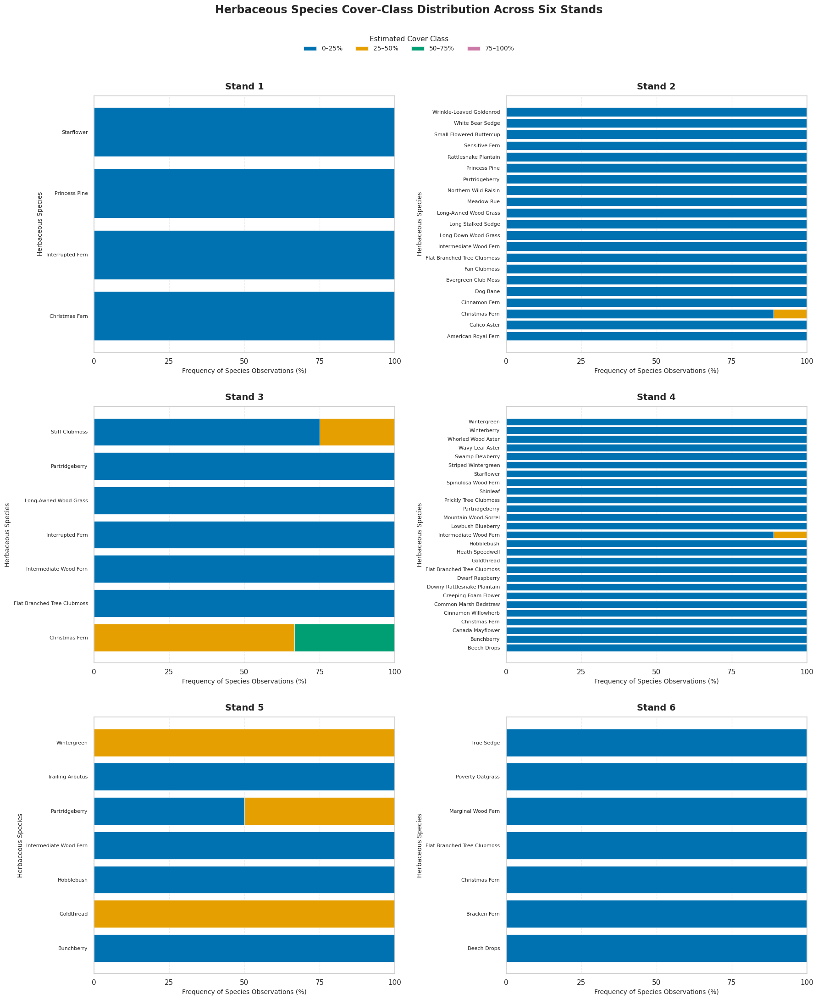

In [171]:
# STEP 157: Create a six-panel herbaceous species cover-class figure.

# Import the plotting library.
import matplotlib.pyplot as plt

# Define the cover-class order and corresponding colors.
cover_classes = ['0–25%', '25–50%', '50–75%', '75–100%']

cover_colors = {
    '0–25%': '#0072B2',
    '25–50%': '#E69F00',
    '50–75%': '#009E73',
    '75–100%': '#CC79A7'
}

# Create a 3-row by 2-column layout for the six stands.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(18, 22)
)

# Flatten the axes array so each stand can be accessed by its position.
axes = axes.flatten()

# Loop through Stands 1–6 and create one panel for each stand.
for stand_id, ax in zip(range(1, 7), axes):

    # Select the species observations for the current stand.
    stand_data = herbaceous_cover_plot_df[
        herbaceous_cover_plot_df['Stand ID'] == stand_id
    ].copy()

    # Sort species alphabetically for consistent presentation.
    stand_data = stand_data.sort_values('Species Name')

    # Set the species names as the y-axis labels.
    species_names = stand_data['Species Name']

    # Initialize the left position of each stacked bar at zero.
    left_positions = [0] * len(stand_data)

    # Draw each cover class as a segment of the horizontal stacked bars.
    for cover_class in cover_classes:

        # Retrieve the percentage of observations in this cover class.
        values = stand_data[cover_class]

        # Draw the cover-class segment.
        ax.barh(
            species_names,
            values,
            left=left_positions,
            color=cover_colors[cover_class],
            edgecolor='white',
            linewidth=0.5,
            label=cover_class
        )

        # Update the left position so the next class stacks beside it.
        left_positions = [
            left + value
            for left, value in zip(left_positions, values)
        ]

    # Set the horizontal axis limits to the full percentage scale.
    ax.set_xlim(0, 100)

    # Add the stand-specific panel title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=14,
        fontweight='bold',
        pad=10
    )

    # Label the horizontal axis.
    ax.set_xlabel(
        'Frequency of Species Observations (%)',
        fontsize=10
    )

    # Label the vertical axis.
    ax.set_ylabel('Herbaceous Species', fontsize=10)

    # Add consistent percentage-axis tick marks.
    ax.set_xticks([0, 25, 50, 75, 100])

    # Add subtle vertical gridlines to help compare values.
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.35
    )

    # Keep the bars and gridlines visually organized.
    ax.set_axisbelow(True)

    # Improve the readability of species labels.
    ax.tick_params(
        axis='y',
        labelsize=8
    )

# Add one shared legend for the four cover classes.
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Estimated Cover Class',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

# Add an overall figure title.
fig.suptitle(
    'Herbaceous Species Cover-Class Distribution Across Six Stands',
    fontsize=17,
    fontweight='bold',
    y=0.99
)

# Adjust spacing to accommodate the title, legend, and species labels.
plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.5, w_pad=2)

# Export a high-resolution version of the figure.
plt.savefig(
    export_dir / 'Herbaceous_Species_Cover_Class_Distribution.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

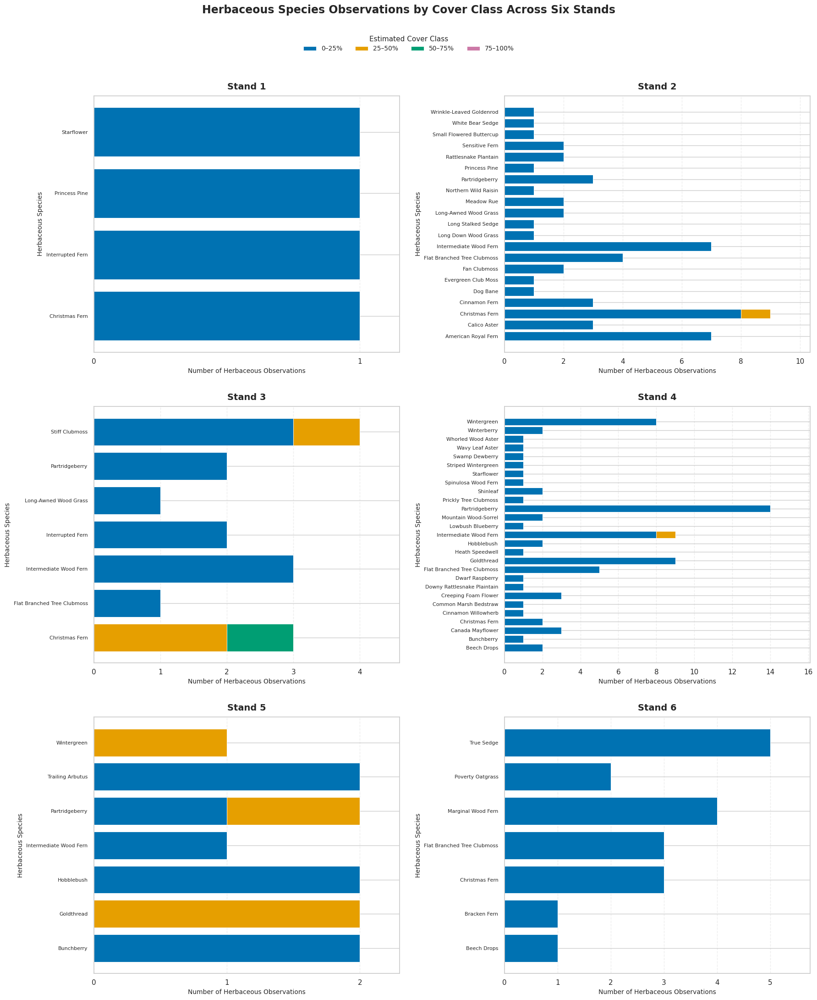

In [172]:
# STEP 158: Create a six-panel figure showing herbaceous species
# observation counts by cover class.

# Import the plotting library.
import matplotlib.pyplot as plt
import pandas as pd

# Define the four cover classes in their natural order.
cover_classes = ['0–25%', '25–50%', '50–75%', '75–100%']

# Retain the cover-class colors used in the previous figure.
cover_colors = {
    '0–25%': '#0072B2',
    '25–50%': '#E69F00',
    '50–75%': '#009E73',
    '75–100%': '#CC79A7'
}

# Pivot the species-level count data so each cover class has its own column.
# Unlike the previous figure, these values are observation counts,
# not percentages normalized to 100%.
herbaceous_count_plot_df = (
    species_cover_counts
    .pivot_table(
        index=['Stand ID', 'Species Name'],
        columns='Cover Class',
        values='Observation Count',
        aggfunc='sum',
        fill_value=0
    )
    .reset_index()
)

# Remove the column index name created by the pivot operation.
herbaceous_count_plot_df.columns.name = None

# Add any cover-class columns that are absent from the observations.
# This ensures all four classes appear consistently in every panel.
for cover_class in cover_classes:
    if cover_class not in herbaceous_count_plot_df.columns:
        herbaceous_count_plot_df[cover_class] = 0

# Arrange the columns in the intended plotting order.
herbaceous_count_plot_df = herbaceous_count_plot_df[
    ['Stand ID', 'Species Name'] + cover_classes
]

# Sort species alphabetically within each stand.
herbaceous_count_plot_df = (
    herbaceous_count_plot_df
    .sort_values(['Stand ID', 'Species Name'])
    .reset_index(drop=True)
)

# Create a 3-row by 2-column layout for the six stands.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(18, 22)
)

# Flatten the axes array so each stand can be assigned to one panel.
axes = axes.flatten()

# Loop through Stands 1–6 and create an individual panel for each stand.
for stand_id, ax in zip(range(1, 7), axes):

    # Select the species observations belonging to the current stand.
    stand_data = herbaceous_count_plot_df[
        herbaceous_count_plot_df['Stand ID'] == stand_id
    ].copy()

    # Sort species alphabetically for consistent presentation.
    stand_data = stand_data.sort_values('Species Name')

    # Store the species names for the y-axis.
    species_names = stand_data['Species Name']

    # Initialize the starting position of each stacked bar at zero.
    left_positions = [0] * len(stand_data)

    # Draw one segment for each cover class.
    for cover_class in cover_classes:

        # Retrieve the number of observations in the current cover class.
        values = stand_data[cover_class]

        # Draw the horizontal bar segment using the actual observation count.
        ax.barh(
            species_names,
            values,
            left=left_positions,
            color=cover_colors[cover_class],
            edgecolor='white',
            linewidth=0.6,
            label=cover_class
        )

        # Update the starting position for the next stacked segment.
        left_positions = [
            left + value
            for left, value in zip(left_positions, values)
        ]

    # Determine the maximum observation count for this stand.
    max_count = max(left_positions) if left_positions else 1

    # Set the x-axis limit with a little extra room beyond the largest bar.
    ax.set_xlim(0, max_count * 1.15)

    # Add the stand number above each panel.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=14,
        fontweight='bold',
        pad=10
    )

    # Label the horizontal axis with the actual observation count.
    ax.set_xlabel(
        'Number of Herbaceous Observations',
        fontsize=10
    )

    # Label the vertical axis with individual species names.
    ax.set_ylabel('Herbaceous Species', fontsize=10)

    # Use integer tick marks because observations are whole counts.
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Add subtle vertical gridlines for easier comparison.
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.35
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Improve the readability of species labels.
    ax.tick_params(
        axis='y',
        labelsize=8
    )

# Create one shared legend for all six panels.
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Estimated Cover Class',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

# Add an overall figure title.
fig.suptitle(
    'Herbaceous Species Observations by Cover Class Across Six Stands',
    fontsize=17,
    fontweight='bold',
    y=0.99
)

# Adjust spacing to accommodate the title, legend, and species labels.
plt.tight_layout(
    rect=[0, 0, 1, 0.94],
    h_pad=2.5,
    w_pad=2
)

# Export the figure at high resolution for the final report.
plt.savefig(
    export_dir / 'Herbaceous_Species_Cover_Counts.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

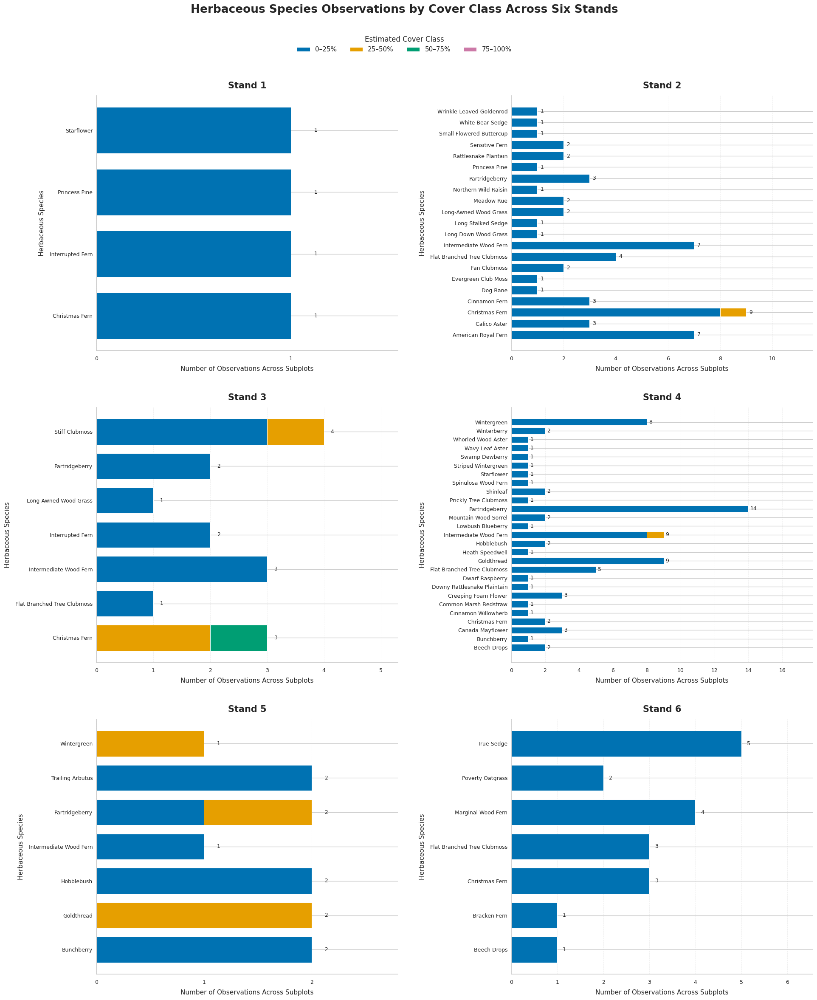

In [175]:
# STEP 159: Refine the herbaceous species cover-count figure.

# Import plotting tools.
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Define the four cover classes in their natural order.
cover_classes = ['0–25%', '25–50%', '50–75%', '75–100%']

# Retain the established cover-class color palette.
cover_colors = {
    '0–25%': '#0072B2',
    '25–50%': '#E69F00',
    '50–75%': '#009E73',
    '75–100%': '#CC79A7'
}

# Create a larger six-panel figure to improve species-label readability.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(20, 24)
)

# Flatten the axes array for easier panel selection.
axes = axes.flatten()

# Process each of the six stands separately.
for stand_id, ax in zip(range(1, 7), axes):

    # Select the observations belonging to the current stand.
    stand_data = herbaceous_count_plot_df[
        herbaceous_count_plot_df['Stand ID'] == stand_id
    ].copy()

    # Sort species alphabetically.
    stand_data = stand_data.sort_values('Species Name')

    # Store the species names for the vertical axis.
    species_names = stand_data['Species Name']

    # Calculate the total number of observations for each species.
    species_totals = stand_data[cover_classes].sum(axis=1)

    # Initialize the left position of each stacked bar.
    left_positions = [0] * len(stand_data)

    # Draw the four cover classes as stacked horizontal bars.
    for cover_class in cover_classes:

        # Retrieve the observation counts for this cover class.
        values = stand_data[cover_class]

        # Draw the horizontal bar segments.
        ax.barh(
            species_names,
            values,
            left=left_positions,
            color=cover_colors[cover_class],
            edgecolor='white',
            linewidth=0.7,
            height=0.75,
            label=cover_class
        )

        # Update the starting position for the next cover-class segment.
        left_positions = [
            left + value
            for left, value in zip(left_positions, values)
        ]

    # Add the total observation count at the end of each species bar.
    for y_position, total in enumerate(species_totals):

        # Position the label slightly beyond the end of its bar.
        ax.text(
            total + 0.12,
            y_position,
            f'{int(total)}',
            va='center',
            ha='left',
            fontsize=9,
            fontweight='medium'
        )

    # Set the x-axis limit to leave space for the count labels.
    max_count = max(species_totals) if len(species_totals) > 0 else 1
    ax.set_xlim(0, max_count * 1.25 + 0.3)

    # Add a descriptive title for the individual stand.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the horizontal axis.
    ax.set_xlabel(
        'Number of Observations Across Subplots',
        fontsize=11,
        labelpad=7
    )

    # Label the vertical axis.
    ax.set_ylabel(
        'Herbaceous Species',
        fontsize=11,
        labelpad=8
    )

    # Use integer tick marks for the observation counts.
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    # Improve the appearance of the species labels.
    ax.tick_params(
        axis='y',
        labelsize=9,
        length=0,
        pad=6
    )

    # Format the horizontal axis.
    ax.tick_params(
        axis='x',
        labelsize=9
    )

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Create a single shared legend for the entire figure.
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Estimated Cover Class',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=4,
    frameon=False,
    fontsize=11,
    title_fontsize=12
)

# Add the overall figure title.
fig.suptitle(
    'Herbaceous Species Observations by Cover Class Across Six Stands',
    fontsize=19,
    fontweight='bold',
    y=0.99
)

# Adjust spacing for the larger panels and shared legend.
plt.tight_layout(
    rect=[0.02, 0.01, 0.99, 0.94],
    h_pad=3.0,
    w_pad=3.0
)

# Save the refined figure at publication-quality resolution.
plt.savefig(
    export_dir / 'Herbaceous_Species_Cover_Counts_Final.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the refined figure.
plt.show()

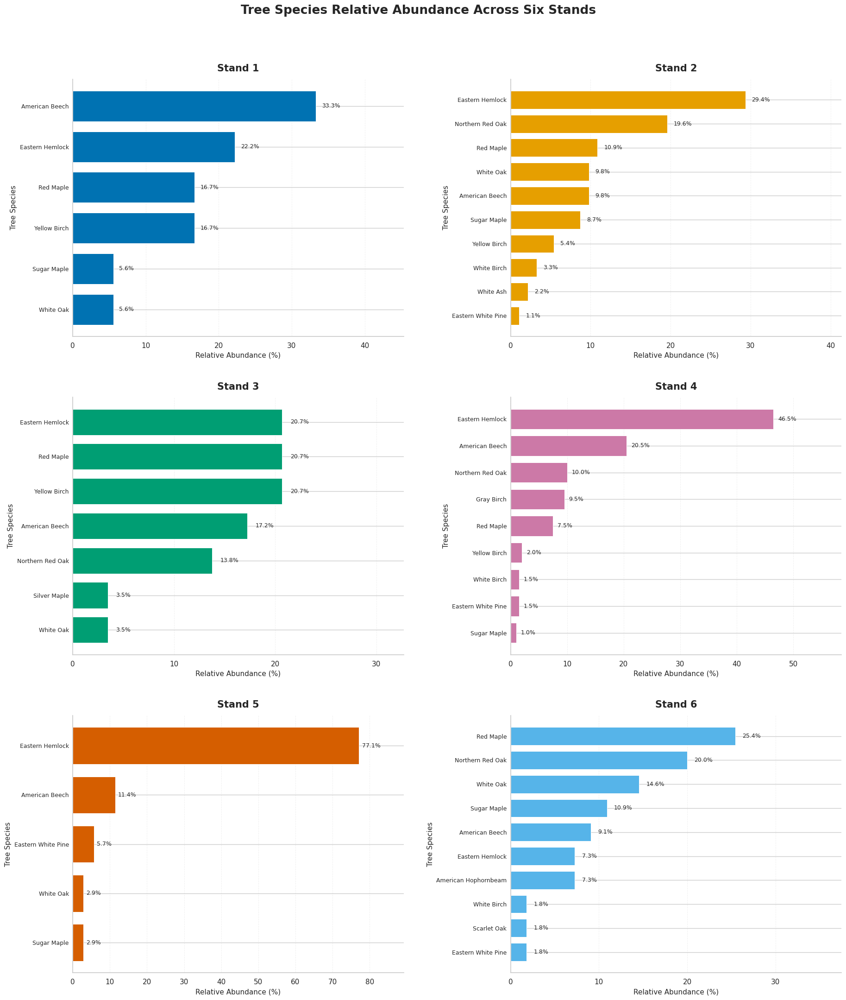

In [177]:
# STEP 160: Create a six-panel tree species relative abundance figure.

# Import plotting tools.
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Create a 3-row by 2-column layout for the six stands.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(19, 22)
)

# Flatten the axes array for easier panel selection.
axes = axes.flatten()

# Loop through Stands 1–6.
for stand_id, ax in zip(range(1, 7), axes):

    # Select relative abundance data for the current stand.
    stand_data = tree_species_counts[
        tree_species_counts['Stand ID'] == stand_id
    ].copy()

    # Sort species from highest to lowest relative abundance.
    stand_data = stand_data.sort_values(
        'Relative Abundance (%)',
        ascending=True
    )

    # Draw horizontal bars using the original stand color.
    bars = ax.barh(
        stand_data['Species Name'],
        stand_data['Relative Abundance (%)'],
        color=stand_colors[stand_id],
        edgecolor='white',
        linewidth=0.7,
        height=0.75
    )

    # Add relative abundance percentages at the end of each bar.
    for bar in bars:

        # Retrieve the relative abundance value.
        abundance = bar.get_width()

        # Position the percentage label just beyond the bar.
        ax.text(
            abundance + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f'{abundance:.1f}%',
            va='center',
            ha='left',
            fontsize=9
        )

    # Set the x-axis limit to accommodate percentage labels.
    ax.set_xlim(
        0,
        stand_data['Relative Abundance (%)'].max() + 12
    )

    # Add the stand title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the axes.
    ax.set_xlabel(
        'Relative Abundance (%)',
        fontsize=11
    )
    ax.set_ylabel(
        'Tree Species',
        fontsize=11
    )

    # Use consistent percentage tick intervals.
    ax.xaxis.set_major_locator(MultipleLocator(10))

    # Improve species-label readability.
    ax.tick_params(
        axis='y',
        labelsize=9,
        length=0,
        pad=6
    )

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary top and right borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Add an overall figure title.
fig.suptitle(
    'Tree Species Relative Abundance Across Six Stands',
    fontsize=19,
    fontweight='bold',
    y=0.99
)

# Adjust panel spacing and margins.
plt.tight_layout(
    rect=[0.02, 0.01, 0.99, 0.96],
    h_pad=3,
    w_pad=3
)

# Export the figure at high resolution.
plt.savefig(
    export_dir / 'Tree_Species_Relative_Abundance.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

In [178]:
# STEP 161: Inspect the tree regeneration dataset.

# Display the available column names.
print("Regeneration dataset columns:")
print(microplot.columns.tolist())

# Display the first 15 records.
print("\nFirst 15 regeneration records:")
display(microplot.head(15))

# Check how many records occur in each stand.
print("\nRecords by stand:")
print(
    microplot['Stand ID']
    .value_counts()
    .sort_index()
)

# Check the unique species recorded.
print("\nUnique regeneration species:")
print(microplot['Species Name'].nunique())

# Inspect the available regeneration count values.
print("\nRegeneration count summary:")
print(microplot['Count'].describe())

Regeneration dataset columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Microplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Seedling/Sapling?', 'Count', 'Damage Type Code', 'Notes', 'Species Name']

First 15 regeneration records:


,Stand ID,Plot ID,Subplot ID,Microplot ID,Date,Team Member(s),Species ID,Seedling/Sapling?,Count,Damage Type Code,Notes,Species Name
0,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",AB,Seedling,2.0,40.0,NaN,American Beech
1,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",AB,Sapling,1.0,40.0,NaN,American Beech
2,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",YB,Sapling,1.0,NaN,NaN,Yellow Birch
3,1.0,1.0,1.0,1.0,23-Oct,"LW, JW, AB",EH,Seedling,1.0,NaN,NaN,Eastern Hemlock
4,2.0,1.0,1.0,1.0,23-Oct,"JM, LW, JW",WO,Sapling,3.0,NaN,NaN,White Oak
5,2.0,1.0,1.0,1.0,23-Oct,"JM, LW, JW",AB,Sapling,4.0,20.0,Beech bark disease,American Beech
6,2.0,1.0,1.0,1.0,23-Oct,"JM, LW, JW",WP,Sapling,1.0,NaN,NaN,Eastern White Pine
7,2.0,1.0,1.0,1.0,23-Oct,"JM, LW, JW",SM,Sapling,5.0,NaN,NaN,Sugar Maple
8,2.0,1.0,1.0,1.0,23-Oct,"JM, LW, JW",AB,Seedling,1.0,NaN,NaN,American Beech
9,2.0,1.0,2.0,2.0,23-Oct,"JW, JM, LA, LW",AB,Sapling,10.0,NaN,NaN,American Beech



Records by stand:
Stand ID
1.0     4
2.0    40
3.0    17
4.0    65
5.0     7
6.0    16
7.0    10
9.0     3
Name: count, dtype: int64

Unique regeneration species:
17

Regeneration count summary:
count    162.000000
mean       4.141975
std        4.901346
min        1.000000
25%        1.000000
50%        2.000000
75%        5.000000
max       37.000000
Name: Count, dtype: float64


In [179]:
# STEP 162: Calculate regeneration species relative abundance by stand.

# Keep only observations from Stands 1–6.
regeneration_analysis = microplot[
    microplot['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without a species identification.
regeneration_analysis = regeneration_analysis.dropna(
    subset=['Species Name', 'Count']
)

# Remove accidental whitespace from species names.
regeneration_analysis['Species Name'] = (
    regeneration_analysis['Species Name']
    .astype(str)
    .str.strip()
)

# Ensure regeneration counts are numeric.
regeneration_analysis['Count'] = pd.to_numeric(
    regeneration_analysis['Count'],
    errors='coerce'
)

# Remove records with missing or nonpositive counts.
regeneration_analysis = regeneration_analysis[
    regeneration_analysis['Count'].notna()
    & (regeneration_analysis['Count'] > 0)
].copy()

# Sum the actual number of seedlings and saplings for each species
# within each stand.
regeneration_species_counts = (
    regeneration_analysis
    .groupby(['Stand ID', 'Species Name'])['Count']
    .sum()
    .reset_index(name='Regeneration Count')
)

# Calculate the total number of regeneration individuals in each stand.
stand_regeneration_totals = (
    regeneration_species_counts
    .groupby('Stand ID')['Regeneration Count']
    .sum()
    .rename('Stand Total')
)

# Attach the stand totals to the species-level table.
regeneration_species_counts = regeneration_species_counts.merge(
    stand_regeneration_totals,
    on='Stand ID',
    how='left'
)

# Calculate each species' relative abundance within its stand.
regeneration_species_counts['Relative Abundance (%)'] = (
    regeneration_species_counts['Regeneration Count']
    / regeneration_species_counts['Stand Total']
    * 100
)

# Round relative abundance to two decimal places.
regeneration_species_counts['Relative Abundance (%)'] = (
    regeneration_species_counts['Relative Abundance (%)'].round(2)
)

# Sort species from most to least abundant within each stand.
regeneration_species_counts = (
    regeneration_species_counts
    .sort_values(
        ['Stand ID', 'Relative Abundance (%)'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Display the regeneration species relative abundance table.
display(regeneration_species_counts)

,Stand ID,Species Name,Regeneration Count,Stand Total,Relative Abundance (%)
0,1.0,American Beech,3.0,5.0,60.00
1,1.0,Eastern Hemlock,1.0,5.0,20.00
2,1.0,Yellow Birch,1.0,5.0,20.00
3,2.0,American Beech,52.0,112.0,46.43
4,2.0,Eastern White Pine,22.0,112.0,19.64
5,2.0,Eastern Hemlock,13.0,112.0,11.61
6,2.0,Sugar Maple,7.0,112.0,6.25
7,2.0,Witch-hazel,5.0,112.0,4.46
8,2.0,White Oak,4.0,112.0,3.57
9,2.0,Yellow Birch,3.0,112.0,2.68


,Stand ID,Seedling/Sapling?,Species Name,Individual Count,Stage Total,Relative Abundance (%)
0,1.0,Sapling,American Beech,1.0,2.0,50.00
1,1.0,Sapling,Yellow Birch,1.0,2.0,50.00
2,1.0,Seedling,American Beech,2.0,3.0,66.67
3,1.0,Seedling,Eastern Hemlock,1.0,3.0,33.33
4,2.0,Sapling,American Beech,25.0,69.0,36.23
5,2.0,Sapling,Eastern White Pine,14.0,69.0,20.29
6,2.0,Sapling,Sugar Maple,7.0,69.0,10.14
7,2.0,Sapling,Eastern Hemlock,5.0,69.0,7.25
8,2.0,Sapling,Witch-hazel,5.0,69.0,7.25
9,2.0,Sapling,White Oak,4.0,69.0,5.80


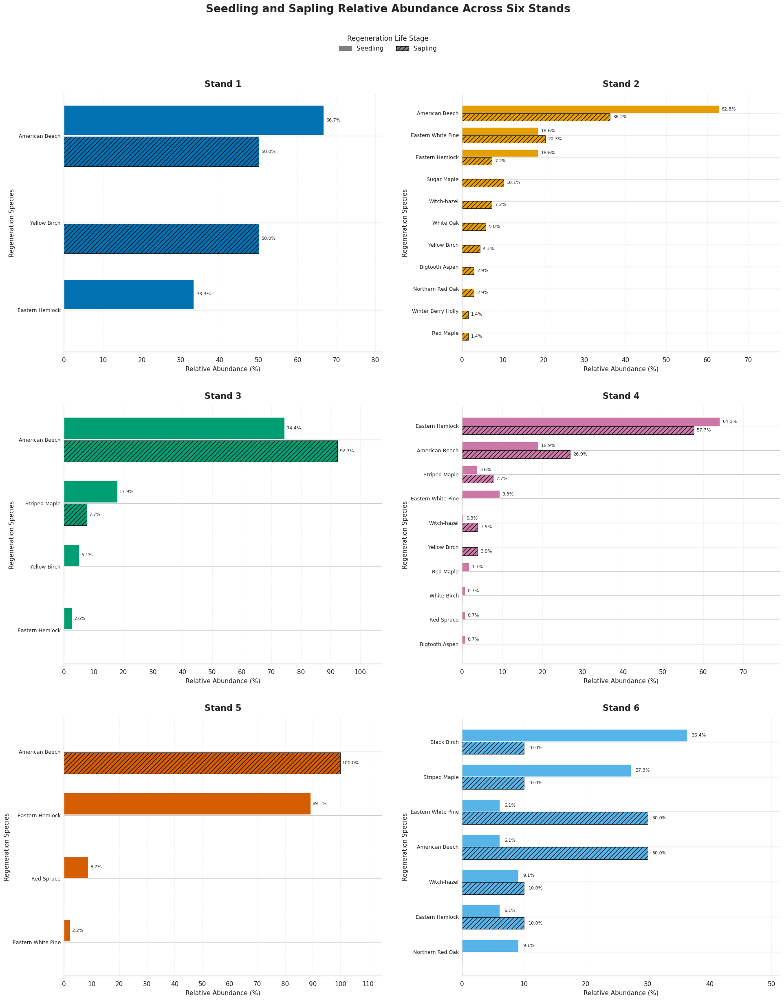

In [180]:
# STEP 164: Compare seedling and sapling relative abundance by species and stand.

# Import plotting tools.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
import pandas as pd

# Make a working copy of the regeneration dataset.
regeneration_separate = microplot.copy()

# Keep only observations from Stands 1–6.
regeneration_separate = regeneration_separate[
    regeneration_separate['Stand ID'].isin(range(1, 7))
].copy()

# Remove records without a species, life-stage classification, or count.
regeneration_separate = regeneration_separate.dropna(
    subset=['Species Name', 'Seedling/Sapling?', 'Count']
)

# Standardize species names and life-stage labels.
regeneration_separate['Species Name'] = (
    regeneration_separate['Species Name'].astype(str).str.strip()
)

regeneration_separate['Seedling/Sapling?'] = (
    regeneration_separate['Seedling/Sapling?']
    .astype(str)
    .str.strip()
    .str.title()
)

# Ensure that regeneration counts are numeric.
regeneration_separate['Count'] = pd.to_numeric(
    regeneration_separate['Count'],
    errors='coerce'
)

# Retain only positive counts and the two intended life stages.
regeneration_separate = regeneration_separate[
    (regeneration_separate['Count'] > 0)
    & regeneration_separate['Seedling/Sapling?'].isin(
        ['Seedling', 'Sapling']
    )
].copy()

# Sum actual individuals by stand, life stage, and species.
regeneration_stage_counts = (
    regeneration_separate
    .groupby(
        ['Stand ID', 'Seedling/Sapling?', 'Species Name']
    )['Count']
    .sum()
    .reset_index(name='Individual Count')
)

# Calculate the total number of individuals for each life stage
# within each stand.
regeneration_stage_totals = (
    regeneration_stage_counts
    .groupby(['Stand ID', 'Seedling/Sapling?'])['Individual Count']
    .sum()
    .reset_index(name='Stage Total')
)

# Attach the appropriate life-stage total to each species record.
regeneration_stage_counts = regeneration_stage_counts.merge(
    regeneration_stage_totals,
    on=['Stand ID', 'Seedling/Sapling?'],
    how='left'
)

# Calculate relative abundance separately for seedlings and saplings.
regeneration_stage_counts['Relative Abundance (%)'] = (
    regeneration_stage_counts['Individual Count']
    / regeneration_stage_counts['Stage Total']
    * 100
)

# Round relative abundance to two decimal places.
regeneration_stage_counts['Relative Abundance (%)'] = (
    regeneration_stage_counts['Relative Abundance (%)'].round(2)
)

# Display the calculated species-level results.
display(
    regeneration_stage_counts.sort_values(
        ['Stand ID', 'Seedling/Sapling?', 'Relative Abundance (%)'],
        ascending=[True, True, False]
    ).reset_index(drop=True)
)

# Create a plotting table with separate columns for seedlings and saplings.
regeneration_stage_plot_df = (
    regeneration_stage_counts
    .pivot_table(
        index=['Stand ID', 'Species Name'],
        columns='Seedling/Sapling?',
        values='Relative Abundance (%)',
        fill_value=0
    )
    .reset_index()
)

# Remove the column index name created by the pivot operation.
regeneration_stage_plot_df.columns.name = None

# Ensure both life-stage columns exist, even if a stand has no records
# for one of the two stages.
for stage in ['Seedling', 'Sapling']:
    if stage not in regeneration_stage_plot_df.columns:
        regeneration_stage_plot_df[stage] = 0

# Create a 3-row by 2-column figure for the six stands.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(20, 25)
)

# Flatten the axes array for easier panel selection.
axes = axes.flatten()

# Loop through Stands 1–6.
for stand_id, ax in zip(range(1, 7), axes):

    # Select the species recorded in the current stand.
    stand_data = regeneration_stage_plot_df[
        regeneration_stage_plot_df['Stand ID'] == stand_id
    ].copy()

    # Calculate the combined relative abundance of both stages
    # for sorting purposes only.
    stand_data['Combined Relative Abundance'] = (
        stand_data['Seedling'] + stand_data['Sapling']
    )

    # Sort species by their combined relative abundance.
    stand_data = stand_data.sort_values(
        'Combined Relative Abundance',
        ascending=True
    ).reset_index(drop=True)

    # Assign a vertical position to each species.
    y_positions = range(len(stand_data))

    # Draw the seedling bars using the stand's original color.
    ax.barh(
        [position + 0.18 for position in y_positions],
        stand_data['Seedling'],
        height=0.34,
        color=stand_colors[stand_id],
        edgecolor='white',
        linewidth=0.6,
        label='Seedling'
    )

    # Draw the sapling bars using the same stand color,
    # but add hatching to distinguish them from seedlings.
    ax.barh(
        [position - 0.18 for position in y_positions],
        stand_data['Sapling'],
        height=0.34,
        color=stand_colors[stand_id],
        edgecolor='black',
        linewidth=0.6,
        hatch='///',
        label='Sapling'
    )

    # Add percentage labels to the seedling bars when the value is nonzero.
    for position, value in zip(y_positions, stand_data['Seedling']):
        if value > 0:
            ax.text(
                value + 0.7,
                position + 0.18,
                f'{value:.1f}%',
                va='center',
                fontsize=8
            )

    # Add percentage labels to the sapling bars when the value is nonzero.
    for position, value in zip(y_positions, stand_data['Sapling']):
        if value > 0:
            ax.text(
                value + 0.7,
                position - 0.18,
                f'{value:.1f}%',
                va='center',
                fontsize=8
            )

    # Set species names as the y-axis labels.
    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(
        stand_data['Species Name'],
        fontsize=9
    )

    # Set the x-axis limit based on the largest relative abundance.
    max_value = max(
        stand_data['Seedling'].max(),
        stand_data['Sapling'].max()
    )

    ax.set_xlim(0, max_value + 15)

    # Add the stand title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the axes.
    ax.set_xlabel('Relative Abundance (%)', fontsize=11)
    ax.set_ylabel('Regeneration Species', fontsize=11)

    # Use percentage-axis tick marks.
    ax.xaxis.set_major_locator(MultipleLocator(10))

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary top and right borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Remove unnecessary tick marks beside species names.
    ax.tick_params(axis='y', length=0, pad=6)

# Create a shared legend explaining the two life stages.
stage_legend = [
    Patch(
        facecolor='gray',
        edgecolor='gray',
        label='Seedling'
    ),
    Patch(
        facecolor='gray',
        edgecolor='black',
        hatch='///',
        label='Sapling'
    )
]

fig.legend(
    handles=stage_legend,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=2,
    frameon=False,
    fontsize=11,
    title='Regeneration Life Stage',
    title_fontsize=12
)

# Add the overall figure title.
fig.suptitle(
    'Seedling and Sapling Relative Abundance Across Six Stands',
    fontsize=19,
    fontweight='bold',
    y=0.99
)

# Adjust spacing for the six panels and shared legend.
plt.tight_layout(
    rect=[0.02, 0.01, 0.99, 0.94],
    h_pad=3,
    w_pad=3
)

# Save the figure at high resolution.
plt.savefig(
    export_dir / 'Seedling_Sapling_Relative_Abundance.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

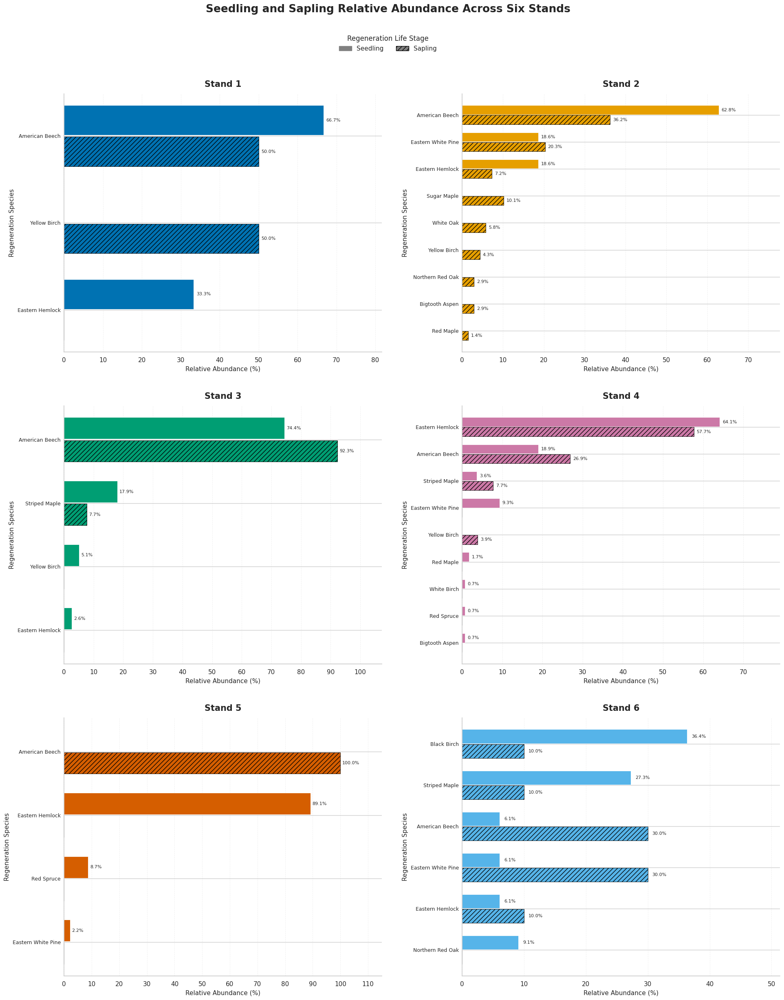

In [181]:
# STEP 165: Recreate the seedling and sapling figure without
# Witch-hazel and Winter Berry Holly.

# Define the species to exclude from the regeneration analysis.
excluded_species = ['Witch-hazel', 'Winter Berry Holly']

# Remove the excluded species from the previously calculated plotting dataset.
regeneration_stage_plot_filtered = regeneration_stage_plot_df[
    ~regeneration_stage_plot_df['Species Name'].isin(excluded_species)
].copy()

# Create a 3-row by 2-column figure for the six stands.
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(20, 25)
)

# Flatten the axes array for easier panel selection.
axes = axes.flatten()

# Loop through Stands 1–6.
for stand_id, ax in zip(range(1, 7), axes):

    # Select the remaining species recorded in the current stand.
    stand_data = regeneration_stage_plot_filtered[
        regeneration_stage_plot_filtered['Stand ID'] == stand_id
    ].copy()

    # Calculate combined abundance for sorting only.
    stand_data['Combined Relative Abundance'] = (
        stand_data['Seedling'] + stand_data['Sapling']
    )

    # Sort species from lowest to highest combined abundance.
    stand_data = stand_data.sort_values(
        'Combined Relative Abundance',
        ascending=True
    ).reset_index(drop=True)

    # Assign a vertical position to each species.
    y_positions = range(len(stand_data))

    # Draw seedling relative abundance using the stand color.
    ax.barh(
        [position + 0.18 for position in y_positions],
        stand_data['Seedling'],
        height=0.34,
        color=stand_colors[stand_id],
        edgecolor='white',
        linewidth=0.6,
        label='Seedling'
    )

    # Draw sapling relative abundance using the same stand color,
    # with hatching to distinguish the life stage.
    ax.barh(
        [position - 0.18 for position in y_positions],
        stand_data['Sapling'],
        height=0.34,
        color=stand_colors[stand_id],
        edgecolor='black',
        linewidth=0.6,
        hatch='///',
        label='Sapling'
    )

    # Add percentage labels to the seedling bars.
    for position, value in zip(y_positions, stand_data['Seedling']):
        if value > 0:
            ax.text(
                value + 0.7,
                position + 0.18,
                f'{value:.1f}%',
                va='center',
                fontsize=8
            )

    # Add percentage labels to the sapling bars.
    for position, value in zip(y_positions, stand_data['Sapling']):
        if value > 0:
            ax.text(
                value + 0.7,
                position - 0.18,
                f'{value:.1f}%',
                va='center',
                fontsize=8
            )

    # Set species names as the y-axis labels.
    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(stand_data['Species Name'], fontsize=9)

    # Set the x-axis limit with room for percentage labels.
    max_value = max(
        stand_data['Seedling'].max(),
        stand_data['Sapling'].max()
    )
    ax.set_xlim(0, max_value + 15)

    # Add the stand title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the axes.
    ax.set_xlabel('Relative Abundance (%)', fontsize=11)
    ax.set_ylabel('Regeneration Species', fontsize=11)

    # Use percentage tick marks.
    ax.xaxis.set_major_locator(MultipleLocator(10))

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary borders and tick marks.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='y', length=0, pad=6)

# Create a shared legend for the two regeneration life stages.
stage_legend = [
    Patch(facecolor='gray', edgecolor='gray', label='Seedling'),
    Patch(
        facecolor='gray',
        edgecolor='black',
        hatch='///',
        label='Sapling'
    )
]

fig.legend(
    handles=stage_legend,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=2,
    frameon=False,
    fontsize=11,
    title='Regeneration Life Stage',
    title_fontsize=12
)

# Add the overall figure title.
fig.suptitle(
    'Seedling and Sapling Relative Abundance Across Six Stands',
    fontsize=19,
    fontweight='bold',
    y=0.99
)

# Adjust panel spacing.
plt.tight_layout(
    rect=[0.02, 0.01, 0.99, 0.94],
    h_pad=3,
    w_pad=3
)

# Save the updated figure.
plt.savefig(
    export_dir / 'Seedling_Sapling_Relative_Abundance_Final.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the updated figure.
plt.show()

In [182]:
# STEP 166: Inspect DBH sample sizes by species and stand.

# Group DBH observations by stand and species.
dbh_species_counts = (
    dbh_analysis_df
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Sample_Size=('DBH (in)', 'count'),
        Mean_DBH=('DBH (in)', 'mean'),
        Median_DBH=('DBH (in)', 'median'),
        SD_DBH=('DBH (in)', 'std')
    )
    .reset_index()
)

# Round descriptive statistics for easier inspection.
dbh_species_counts[
    ['Mean_DBH', 'Median_DBH', 'SD_DBH']
] = dbh_species_counts[
    ['Mean_DBH', 'Median_DBH', 'SD_DBH']
].round(2)

# Sort by stand and descending sample size.
dbh_species_counts = dbh_species_counts.sort_values(
    ['Stand ID', 'Sample_Size'],
    ascending=[True, False]
).reset_index(drop=True)

# Display species-level DBH sample sizes and descriptive statistics.
display(dbh_species_counts)

,Stand ID,Species Name,Sample_Size,Mean_DBH,Median_DBH,SD_DBH
0,1,American Beech,6,8.67,7.59,3.65
1,1,Eastern Hemlock,4,10.18,10.34,1.51
2,1,Red Maple,3,12.91,14.38,3.23
3,1,Yellow Birch,3,8.43,8.30,3.50
4,1,Sugar Maple,1,10.10,10.10,NaN
5,1,White Oak,1,10.27,10.27,NaN
6,2,Eastern Hemlock,27,10.52,9.58,4.21
7,2,Northern Red Oak,18,12.35,10.70,5.72
8,2,Red Maple,10,8.86,6.55,4.57
9,2,American Beech,9,7.60,7.41,2.07


In [183]:
# STEP 167: Prepare species-level DBH data for the distribution figure.

# Make a separate copy of the existing DBH analysis dataset.
dbh_visualization_df = dbh_analysis_df.copy()

# Remove records without a species identification or DBH measurement.
dbh_visualization_df = dbh_visualization_df.dropna(
    subset=['Species Name', 'DBH (in)', 'Stand ID']
)

# Ensure species names are consistently formatted.
dbh_visualization_df['Species Name'] = (
    dbh_visualization_df['Species Name']
    .astype(str)
    .str.strip()
)

# Calculate sample sizes for every species within each stand.
dbh_species_n = (
    dbh_visualization_df
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='n')
)

# Create a species label that includes the sample size.
dbh_species_n['Species Label'] = (
    dbh_species_n['Species Name']
    + ' (n='
    + dbh_species_n['n'].astype(str)
    + ')'
)

# Attach the sample-size labels to the individual DBH observations.
dbh_visualization_df = dbh_visualization_df.merge(
    dbh_species_n[
        ['Stand ID', 'Species Name', 'Species Label']
    ],
    on=['Stand ID', 'Species Name'],
    how='left'
)

# Sort species within each stand by their median DBH.
dbh_species_order = (
    dbh_visualization_df
    .groupby(['Stand ID', 'Species Name'])['DBH (in)']
    .median()
    .reset_index()
    .sort_values(['Stand ID', 'DBH (in)'])
)

# Display the species ordering and sample sizes.
display(
    dbh_species_n.sort_values(
        ['Stand ID', 'n'],
        ascending=[True, False]
    ).reset_index(drop=True)
)

,Stand ID,Species Name,n,Species Label
0,1,American Beech,6,American Beech (n=6)
1,1,Eastern Hemlock,4,Eastern Hemlock (n=4)
2,1,Red Maple,3,Red Maple (n=3)
3,1,Yellow Birch,3,Yellow Birch (n=3)
4,1,Sugar Maple,1,Sugar Maple (n=1)
5,1,White Oak,1,White Oak (n=1)
6,2,Eastern Hemlock,27,Eastern Hemlock (n=27)
7,2,Northern Red Oak,18,Northern Red Oak (n=18)
8,2,Red Maple,10,Red Maple (n=10)
9,2,American Beech,9,American Beech (n=9)


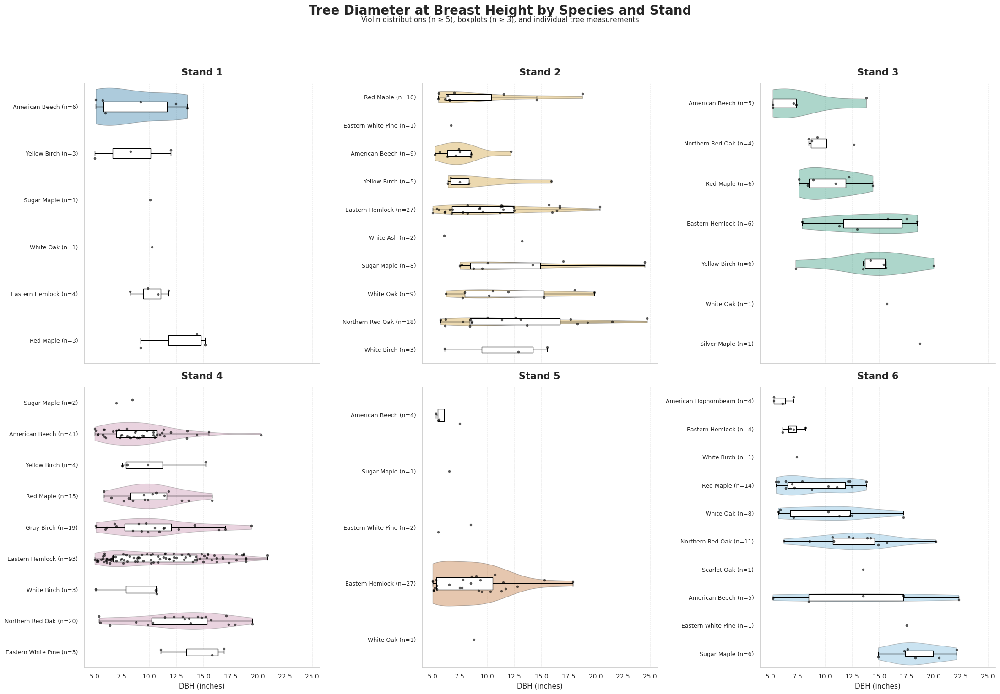

In [184]:
# STEP 168: Create a six-panel, species-resolved DBH distribution figure.

# Import the plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create a figure with six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(22, 15),
    sharex=True
)

# Flatten the axes array so each stand can be plotted in sequence.
axes = axes.flatten()

# Loop through the six stands.
for stand, ax in zip(range(1, 7), axes):

    # Select DBH observations from the current stand.
    stand_data = dbh_visualization_df[
        dbh_visualization_df['Stand ID'] == stand
    ].copy()

    # Determine the species order using median DBH.
    species_order = (
        stand_data.groupby('Species Label')['DBH (in)']
        .median()
        .sort_values()
        .index.tolist()
    )

    # Identify species with at least five observations.
    # These sample sizes are more suitable for displaying violin distributions.
    violin_species = (
        stand_data.groupby('Species Label').size()
    )
    violin_species = violin_species[
        violin_species >= 5
    ].index.tolist()

    # Draw violin distributions for species with sufficient observations.
    if violin_species:

        # Filter the data to include only species with at least five observations.
        violin_data = stand_data[
            stand_data['Species Label'].isin(violin_species)
        ]

        # Draw horizontal violins to show the distribution of DBH values.
        sns.violinplot(
            data=violin_data,
            x='DBH (in)',
            y='Species Label',
            order=species_order,
            orient='h',
            color=stand_colors[stand],
            inner=None,
            cut=0,
            linewidth=1,
            alpha=0.35,
            ax=ax
        )

    # Draw boxplots for species with at least three observations.
    box_species = (
        stand_data.groupby('Species Label').size()
    )
    box_species = box_species[
        box_species >= 3
    ].index.tolist()

    # Filter the data for the boxplots.
    box_data = stand_data[
        stand_data['Species Label'].isin(box_species)
    ]

    # Overlay boxplots to show medians and interquartile ranges.
    if not box_data.empty:
        sns.boxplot(
            data=box_data,
            x='DBH (in)',
            y='Species Label',
            order=species_order,
            orient='h',
            width=0.22,
            showfliers=False,
            color='white',
            boxprops={'edgecolor': 'black', 'zorder': 3},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            medianprops={'color': 'black', 'linewidth': 1.5},
            ax=ax
        )

    # Plot every individual tree as a point.
    # This ensures species with small sample sizes remain visible.
    sns.stripplot(
        data=stand_data,
        x='DBH (in)',
        y='Species Label',
        order=species_order,
        orient='h',
        color='black',
        size=4,
        alpha=0.65,
        jitter=0.16,
        ax=ax,
        zorder=4
    )

    # Add the stand title.
    ax.set_title(
        f'Stand {stand}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the horizontal axis.
    ax.set_xlabel('DBH (inches)', fontsize=11)

    # Label the vertical axis.
    ax.set_ylabel('')

    # Improve the appearance of the axis labels and tick marks.
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=10)

    # Add subtle vertical gridlines for easier comparison.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep the grid behind the plotted data.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    sns.despine(ax=ax)

# Add an overall figure title.
fig.suptitle(
    'Tree Diameter at Breast Height by Species and Stand',
    fontsize=20,
    fontweight='bold',
    y=1.01
)

# Add a brief explanatory subtitle.
fig.text(
    0.5,
    0.985,
    'Violin distributions (n ≥ 5), boxplots (n ≥ 3), and individual tree measurements',
    ha='center',
    fontsize=11
)

# Adjust spacing to prevent overlap between panels.
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save the figure as a high-resolution PNG.
plt.savefig(
    export_dir / 'DBH_Distributions_by_Species_and_Stand.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the finished figure.
plt.show()

In [186]:
# STEP 169A: Inspect the column names in the height dataframe.

# Print all column names so we can identify the correct height field.
print(height_df.columns.tolist())

# Display the first five rows to verify the data structure.
display(height_df.head())

['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Tree ID', 'Species Code', 'Tree Status', 'DBH (in)', 'Estimated Tree Height (m)', 'Estimated Tree Height (ft)', 'Crown Class Code', 'Damage Type Code', 'Snag Decay Class (If Applicable)', 'Notes', 'Species Name', 'Tree Status Label']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name,Tree Status Label
0,1,1,1,23-Oct,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.02,Dominant,NaN,NaN,NaN,Yellow Birch,Alive
1,1,1,1,23-Oct,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.81,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
2,1,1,1,23-Oct,"LW, AB, HB",3.0,AB,DA,13.52,13.5,44.29,Dominant,20,NaN,Base of trunk split,American Beech,Damaged
3,1,1,1,23-Oct,"EC, HP, AB, LW",4.0,AB,DA,5.98,10.0,32.81,Codominant,20,NaN,Bark split,American Beech,Damaged
4,1,1,1,23-Oct,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.04,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive


In [187]:
# STEP 169: Summarize tree height measurements by species and stand.

# Create a separate copy of the existing height analysis dataset.
height_visualization_df = height_df.copy()

# Remove records missing species, stand, or height information.
height_visualization_df = height_visualization_df.dropna(
    subset=[
        'Stand ID',
        'Species Name',
        'Estimated Tree Height (ft)'
    ]
)

# Ensure species names are consistently formatted.
height_visualization_df['Species Name'] = (
    height_visualization_df['Species Name']
    .astype(str)
    .str.strip()
)

# Group observations by stand and species.
# Calculate sample size and descriptive statistics for tree height.
height_species_summary = (
    height_visualization_df
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Sample_Size=('Estimated Tree Height (ft)', 'count'),
        Mean_Height=('Estimated Tree Height (ft)', 'mean'),
        Median_Height=('Estimated Tree Height (ft)', 'median'),
        SD_Height=('Estimated Tree Height (ft)', 'std'),
        Minimum_Height=('Estimated Tree Height (ft)', 'min'),
        Maximum_Height=('Estimated Tree Height (ft)', 'max')
    )
    .reset_index()
)

# Round the descriptive statistics to two decimal places.
numeric_columns = [
    'Mean_Height',
    'Median_Height',
    'SD_Height',
    'Minimum_Height',
    'Maximum_Height'
]

height_species_summary[numeric_columns] = (
    height_species_summary[numeric_columns].round(2)
)

# Sort species within each stand by sample size, largest first.
height_species_summary = (
    height_species_summary
    .sort_values(
        ['Stand ID', 'Sample_Size'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Display the species-level height summary.
display(height_species_summary)

,Stand ID,Species Name,Sample_Size,Mean_Height,Median_Height,SD_Height,Minimum_Height,Maximum_Height
0,1,American Beech,6,46.64,38.55,21.40,27.23,83.66
1,1,Eastern Hemlock,4,34.04,36.09,11.93,18.04,45.93
2,1,Yellow Birch,3,51.62,38.39,26.40,34.45,82.02
3,1,Red Maple,2,52.49,52.49,4.64,49.21,55.77
4,1,White Oak,1,60.04,60.04,NaN,60.04,60.04
5,2,Eastern Hemlock,26,54.10,46.42,24.46,22.47,96.95
6,2,Northern Red Oak,18,60.56,55.50,17.26,37.83,94.32
7,2,Red Maple,10,52.74,41.61,19.43,40.19,91.21
8,2,American Beech,9,41.79,36.42,20.50,27.89,93.67
9,2,Sugar Maple,8,50.10,49.38,22.06,25.43,80.58


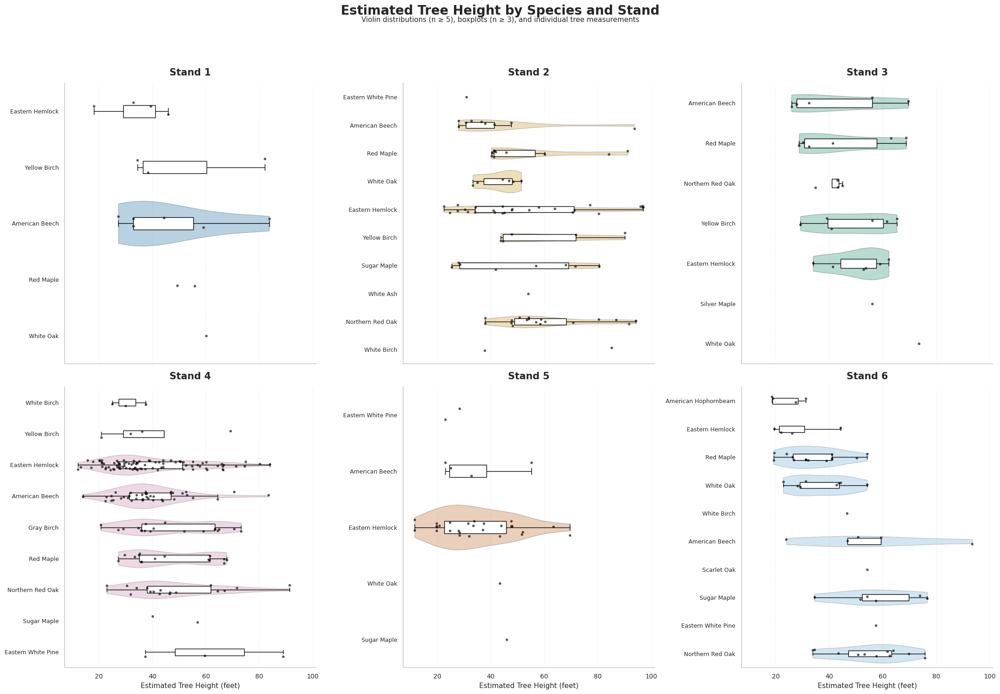

In [191]:

# STEP 170: Create a six-panel, species-resolved tree height distribution figure.

# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the height column once so the code consistently uses the correct field.
height_column = 'Estimated Tree Height (ft)'

# Create a figure with six panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(22, 15),
    sharex=True
)

# Flatten the axes array so each stand can be plotted in sequence.
axes = axes.flatten()

# Loop through the six stands.
for stand, ax in zip(range(1, 7), axes):

    # Select height observations from the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ].copy()

    # Determine the species order using median tree height.
    species_order = (
        stand_data.groupby('Species Name')[height_column]
        .median()
        .sort_values()
        .index.tolist()
    )

    # Identify species with at least five observations.
    # These sample sizes are more suitable for displaying violin distributions.
    violin_species = (
        stand_data.groupby('Species Name').size()
    )
    violin_species = violin_species[
        violin_species >= 5
    ].index.tolist()

    # Draw violin distributions for species with sufficient observations.
    if violin_species:

        # Filter the data to include only species with at least five observations.
        violin_data = stand_data[
            stand_data['Species Name'].isin(violin_species)
        ]

        # Record the number of existing plot collections.
        # This allows us to apply transparency only to the violin shapes.
        collections_before = len(ax.collections)

        # Draw horizontal violins to show the distribution of tree heights.
        sns.violinplot(
            data=violin_data,
            x=height_column,
            y='Species Name',
            order=species_order,
            orient='h',
            color=stand_colors[stand],
            inner=None,
            cut=0,
            linewidth=1,
            ax=ax
        )

        # Apply 30% opacity to the violin distributions.
        for violin in ax.collections[collections_before:]:
            violin.set_alpha(0.30)

    # Identify species with at least three observations for boxplots.
    box_species = (
        stand_data.groupby('Species Name').size()
    )
    box_species = box_species[
        box_species >= 3
    ].index.tolist()

    # Filter the data for the boxplots.
    box_data = stand_data[
        stand_data['Species Name'].isin(box_species)
    ]

    # Overlay boxplots to show medians and interquartile ranges.
    if not box_data.empty:
        sns.boxplot(
            data=box_data,
            x=height_column,
            y='Species Name',
            order=species_order,
            orient='h',
            width=0.22,
            showfliers=False,
            color='white',
            boxprops={'edgecolor': 'black', 'zorder': 3},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            medianprops={'color': 'black', 'linewidth': 1.5},
            ax=ax
        )

    # Plot every individual tree as a point.
    # This keeps species with small sample sizes visible.
    sns.stripplot(
        data=stand_data,
        x=height_column,
        y='Species Name',
        order=species_order,
        orient='h',
        color='black',
        size=4,
        alpha=0.65,
        jitter=0.16,
        ax=ax,
        zorder=4
    )

    # Add the stand title.
    ax.set_title(
        f'Stand {stand}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the horizontal axis.
    ax.set_xlabel('Estimated Tree Height (feet)', fontsize=11)

    # Remove the vertical axis title.
    ax.set_ylabel('')

    # Improve the appearance of axis labels and tick marks.
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=10)

    # Add subtle vertical gridlines for easier comparison.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep gridlines behind the plotted data.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    sns.despine(ax=ax)

# Add an overall figure title.
fig.suptitle(
    'Estimated Tree Height by Species and Stand',
    fontsize=20,
    fontweight='bold',
    y=1.01
)

# Add an explanatory subtitle.
fig.text(
    0.5,
    0.985,
    'Violin distributions (n ≥ 5), boxplots (n ≥ 3), and individual tree measurements',
    ha='center',
    fontsize=11
)

# Adjust spacing to prevent overlap between panels.
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save the figure as a high-resolution PNG.
plt.savefig(
    export_dir / 'Height_Distributions_by_Species_and_Stand.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the finished figure.
plt.show()


In [189]:
# STEP 172: Identify the five largest and five smallest trees in each stand.

# Define the measurement columns for height and DBH.
height_column = 'Estimated Tree Height (ft)'
dbh_column = 'DBH (in)'

# Create a reusable function to identify the largest and smallest trees.
def get_tree_extremes(data, measurement, direction):

    # Create a separate copy of the input data.
    df = data.copy()

    # Remove records missing the measurement, species, stand, or Tree ID.
    df = df.dropna(
        subset=[
            'Stand ID',
            'Tree ID',
            'Species Name',
            measurement
        ]
    )

    # Sort trees within each stand by the selected measurement.
    # Largest trees are ranked in descending order.
    # Smallest trees are ranked in ascending order.
    ascending_order = direction == 'smallest'

    df = df.sort_values(
        ['Stand ID', measurement],
        ascending=[True, ascending_order]
    )

    # Select the five highest or lowest measurements in each stand.
    extremes = (
        df.groupby('Stand ID', group_keys=False)
        .head(5)
        .copy()
    )

    # Add a ranking number from 1 to 5 within each stand.
    extremes['Rank'] = (
        extremes.groupby('Stand ID').cumcount() + 1
    )

    # Return the ranked dataset.
    return extremes


# Identify the five tallest trees in each stand.
tallest_trees = get_tree_extremes(
    height_visualization_df,
    height_column,
    'largest'
)

# Identify the five shortest trees in each stand.
shortest_trees = get_tree_extremes(
    height_visualization_df,
    height_column,
    'smallest'
)

# Identify the five largest-DBH trees in each stand.
largest_dbh_trees = get_tree_extremes(
    dbh_visualization_df,
    dbh_column,
    'largest'
)

# Identify the five smallest-DBH trees in each stand.
smallest_dbh_trees = get_tree_extremes(
    dbh_visualization_df,
    dbh_column,
    'smallest'
)

# Display the tallest trees.
print('FIVE TALLEST TREES PER STAND')
display(
    tallest_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', height_column]
    ]
)

# Display the shortest trees.
print('FIVE SHORTEST TREES PER STAND')
display(
    shortest_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', height_column]
    ]
)

# Display the largest-DBH trees.
print('FIVE LARGEST DBH TREES PER STAND')
display(
    largest_dbh_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', dbh_column]
    ]
)

# Display the smallest-DBH trees.
print('FIVE SMALLEST DBH TREES PER STAND')
display(
    smallest_dbh_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', dbh_column]
    ]
)

FIVE TALLEST TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,Estimated Tree Height (ft)
5,1,1,6.0,American Beech,83.66
0,1,2,1.0,Yellow Birch,82.02
10,1,3,11.0,White Oak,60.04
19,1,4,20.0,American Beech,59.06
15,1,5,16.0,Red Maple,55.77
83,2,1,7.0,Eastern Hemlock,96.95
90,2,2,4.0,Eastern Hemlock,96.78
96,2,3,10.0,Eastern Hemlock,96.78
89,2,4,3.0,Eastern Hemlock,95.96
93,2,5,7.0,Northern Red Oak,94.32


FIVE SHORTEST TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,Estimated Tree Height (ft)
4,1,1,5.0,Eastern Hemlock,18.04
8,1,2,9.0,American Beech,27.23
1,1,3,2.0,Eastern Hemlock,32.81
3,1,4,4.0,American Beech,32.81
14,1,5,15.0,American Beech,32.81
42,2,1,5.0,Eastern Hemlock,22.47
43,2,2,6.0,Eastern Hemlock,24.61
58,2,3,5.0,Sugar Maple,25.43
92,2,4,6.0,Eastern Hemlock,27.56
106,2,5,9.0,Eastern Hemlock,27.56


FIVE LARGEST DBH TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,DBH (in)
9,1,1,10.0,Red Maple,15.14
14,1,2,16.0,Red Maple,14.38
2,1,3,3.0,American Beech,13.52
17,1,4,20.0,American Beech,12.46
7,1,5,8.0,Yellow Birch,11.99
97,2,1,2.0,Northern Red Oak,24.70
28,2,2,2.0,Sugar Maple,24.49
44,2,3,1.0,Northern Red Oak,21.52
87,2,4,2.0,Eastern Hemlock,20.38
30,2,5,4.0,White Oak,19.89


FIVE SMALLEST DBH TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,DBH (in)
11,1,1,12.0,Yellow Birch,5.00
13,1,2,15.0,American Beech,5.10
5,1,3,6.0,American Beech,5.73
3,1,4,4.0,American Beech,5.98
1,1,5,2.0,Eastern Hemlock,8.25
89,2,1,4.0,Eastern Hemlock,5.00
107,2,2,1.0,American Beech,5.20
43,2,3,10.0,Eastern Hemlock,5.40
24,2,4,29.0,Red Maple,5.52
40,2,5,7.0,Red Maple,5.53


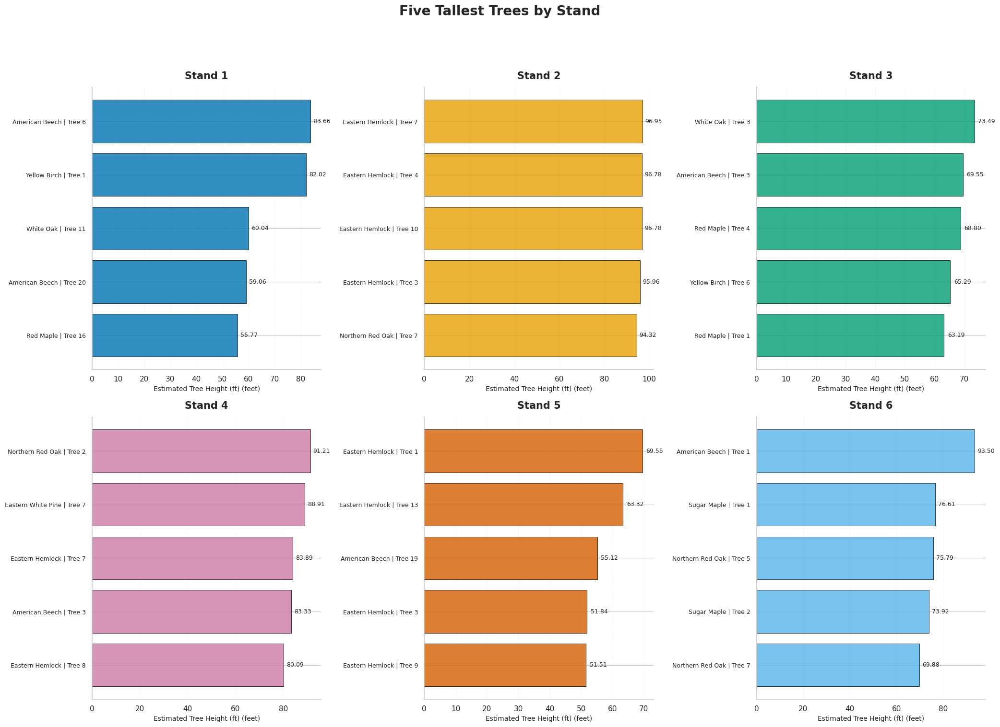

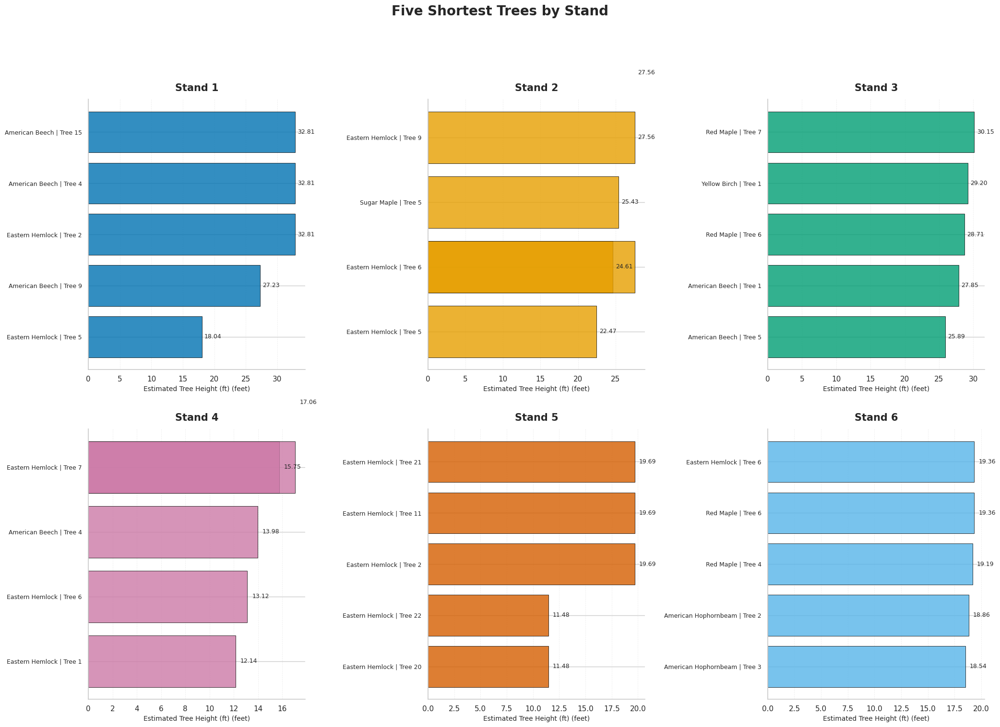

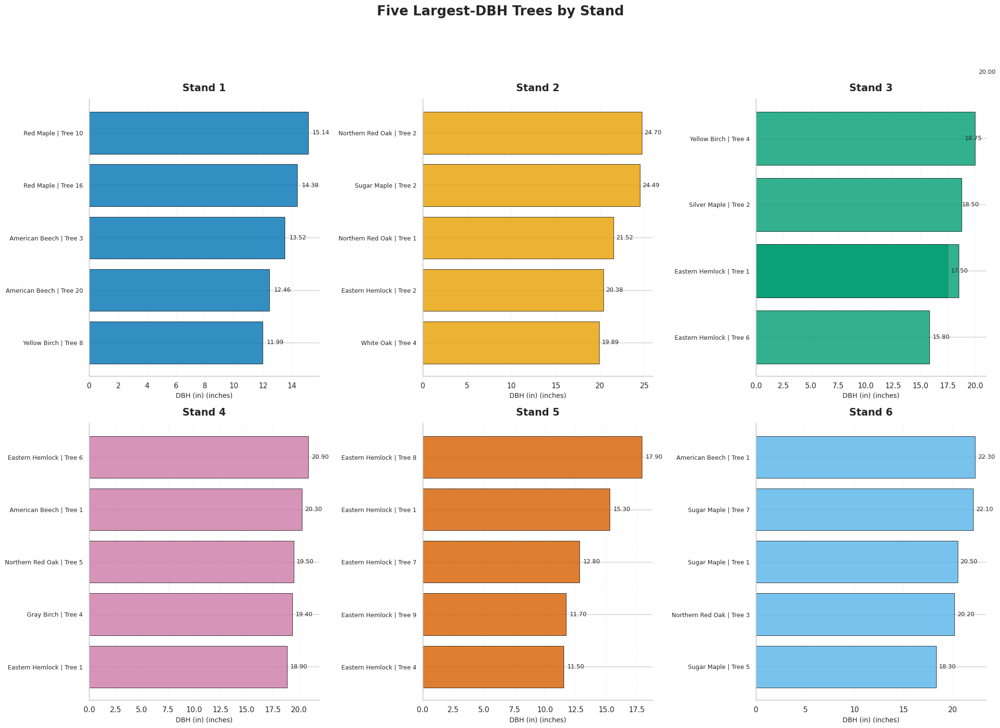

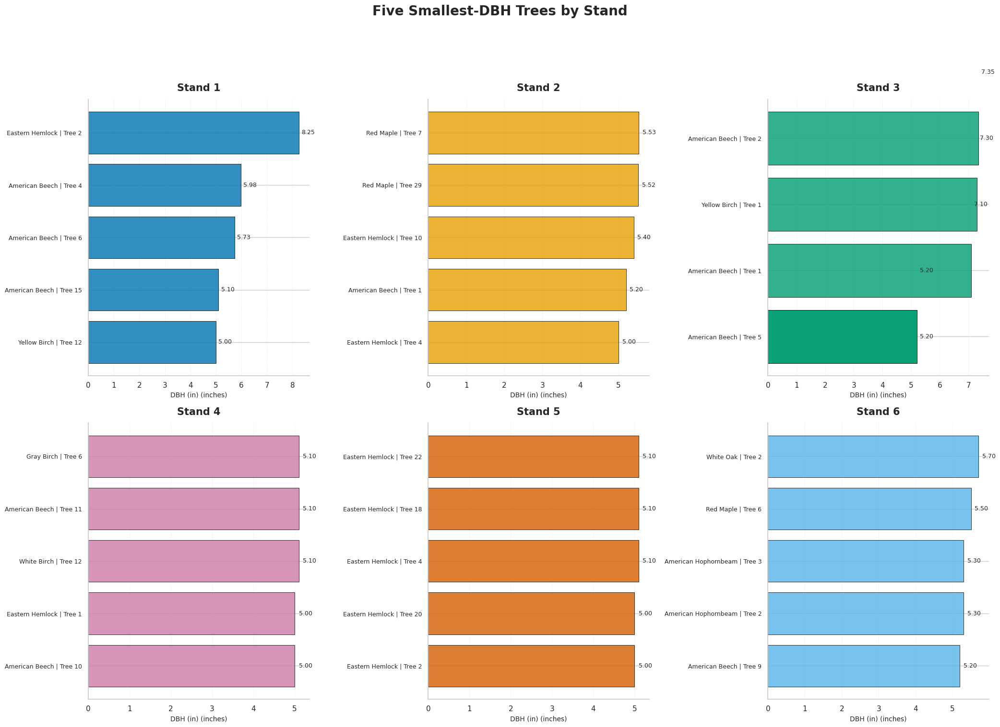

In [190]:
# STEP 173: Create four six-panel figures showing tree measurement extremes.

# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Define a reusable plotting function for the four rankings.
def plot_tree_extremes(data, measurement, title, filename, unit):

    # Create a figure with six panels arranged in two rows and three columns.
    fig, axes = plt.subplots(
        2, 3,
        figsize=(21, 15)
    )

    # Flatten the axes array for easier iteration.
    axes = axes.flatten()

    # Loop through the six stands.
    for stand, ax in zip(range(1, 7), axes):

        # Select the five trees for the current stand.
        stand_data = data[
            data['Stand ID'] == stand
        ].copy()

        # Sort the trees so the highest measurement appears at the top.
        stand_data = stand_data.sort_values(
            measurement,
            ascending=True
        )

        # Create labels identifying each tree by species and Tree ID.
        stand_data['Tree Label'] = (
            stand_data['Species Name']
            + ' | Tree '
            + stand_data['Tree ID'].astype(int).astype(str)
        )

        # Draw horizontal bars using the stand's original color.
        ax.barh(
            stand_data['Tree Label'],
            stand_data[measurement],
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=0.7,
            alpha=0.80
        )

        # Add the measurement value at the end of each bar.
        for y_position, value in enumerate(stand_data[measurement]):

            # Place a numeric label just beyond the bar.
            ax.text(
                value + max(data[measurement]) * 0.012,
                y_position,
                f'{value:.2f}',
                va='center',
                fontsize=9
            )

        # Add the stand title.
        ax.set_title(
            f'Stand {stand}',
            fontsize=15,
            fontweight='bold',
            pad=12
        )

        # Label the horizontal axis.
        ax.set_xlabel(
            f'{measurement} ({unit})',
            fontsize=10
        )

        # Remove the vertical axis title.
        ax.set_ylabel('')

        # Improve the appearance of the species and tree labels.
        ax.tick_params(
            axis='y',
            labelsize=9
        )

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            linestyle='--',
            linewidth=0.6,
            alpha=0.35
        )

        # Keep gridlines behind the bars.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        sns.despine(ax=ax)

    # Add the overall figure title.
    fig.suptitle(
        title,
        fontsize=20,
        fontweight='bold',
        y=1.01
    )

    # Adjust panel spacing.
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    # Save the figure at high resolution.
    plt.savefig(
        export_dir / filename,
        dpi=400,
        bbox_inches='tight'
    )

    # Display the figure.
    plt.show()


# Figure 1: Five tallest trees in each stand.
plot_tree_extremes(
    tallest_trees,
    height_column,
    'Five Tallest Trees by Stand',
    'Five_Tallest_Trees_by_Stand.png',
    'feet'
)

# Figure 2: Five shortest trees in each stand.
plot_tree_extremes(
    shortest_trees,
    height_column,
    'Five Shortest Trees by Stand',
    'Five_Shortest_Trees_by_Stand.png',
    'feet'
)

# Figure 3: Five largest-DBH trees in each stand.
plot_tree_extremes(
    largest_dbh_trees,
    dbh_column,
    'Five Largest-DBH Trees by Stand',
    'Five_Largest_DBH_Trees_by_Stand.png',
    'inches'
)

# Figure 4: Five smallest-DBH trees in each stand.
plot_tree_extremes(
    smallest_dbh_trees,
    dbh_column,
    'Five Smallest-DBH Trees by Stand',
    'Five_Smallest_DBH_Trees_by_Stand.png',
    'inches'
)

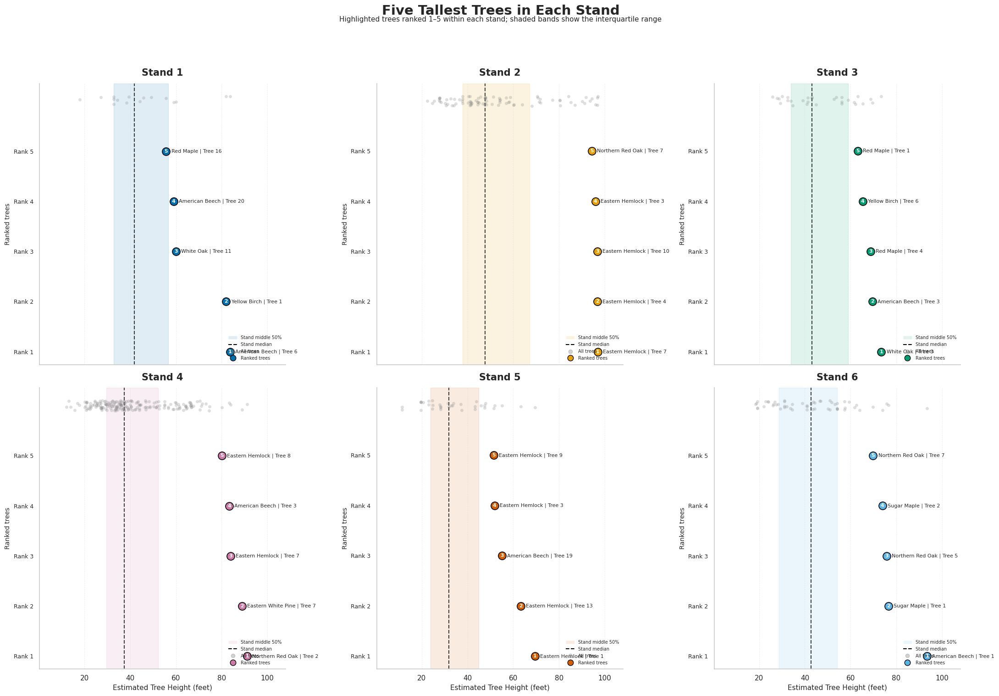

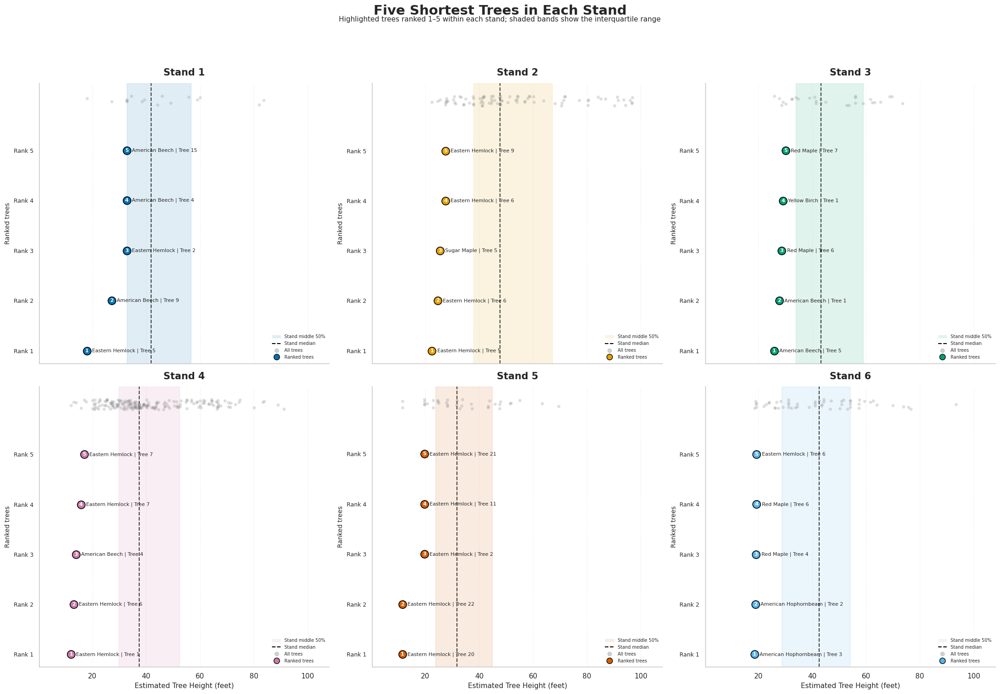

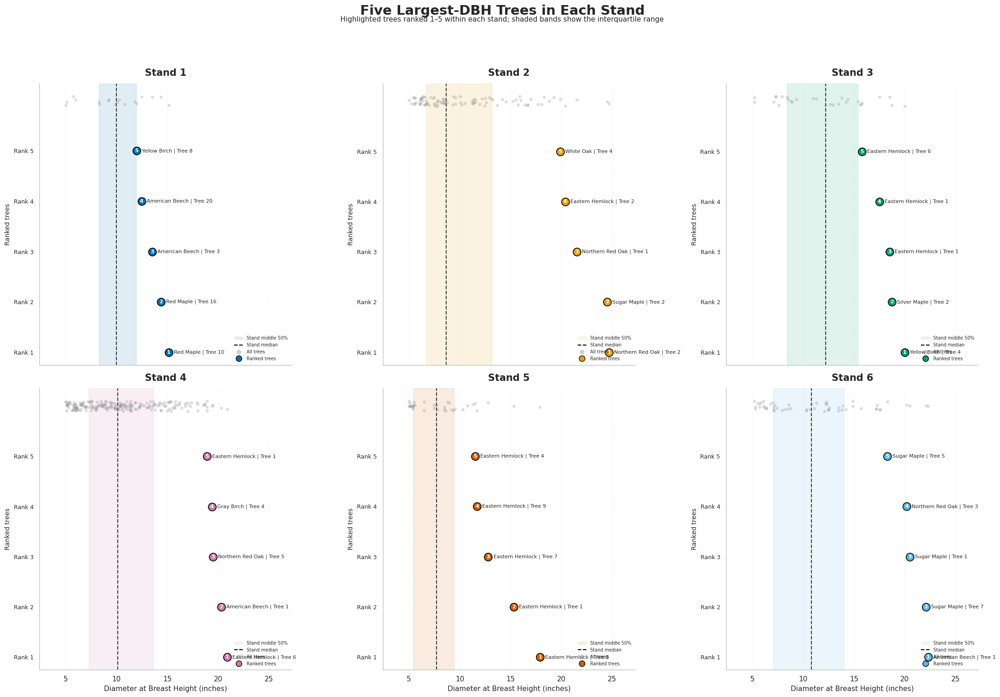

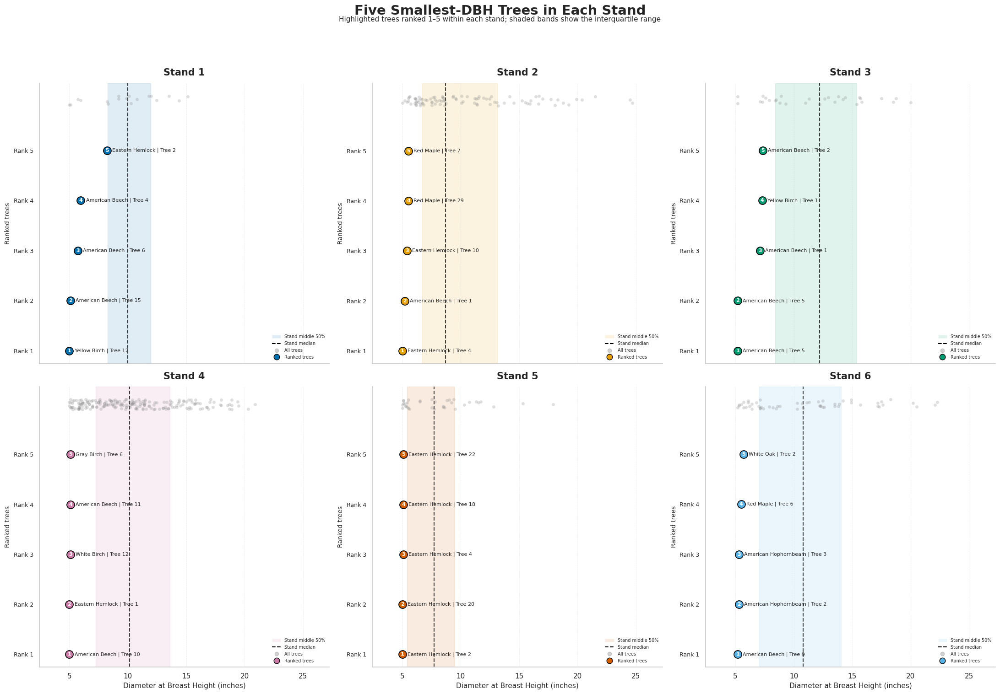

In [192]:

# STEP 174: Create ranked dot plots of the five largest and smallest trees
# by height and DBH in each stand.

# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Define the measurement columns.
height_column = 'Estimated Tree Height (ft)'
dbh_column = 'DBH (in)'


# ------------------------------------------------------------
# PART 1: IDENTIFY THE FIVE LARGEST AND SMALLEST TREES
# ------------------------------------------------------------

# Define a function to rank the five largest or smallest trees
# within each stand.
def get_tree_extremes(data, measurement, direction):

    # Create a separate copy of the input dataframe.
    df = data.copy()

    # Remove records missing essential information.
    df = df.dropna(
        subset=[
            'Stand ID',
            'Tree ID',
            'Species Name',
            measurement
        ]
    )

    # Determine whether the measurements should be sorted
    # from smallest to largest or largest to smallest.
    ascending_order = direction == 'smallest'

    # Sort observations separately within each stand.
    df = df.sort_values(
        ['Stand ID', measurement],
        ascending=[True, ascending_order]
    )

    # Select the five highest or lowest measurements in each stand.
    extremes = (
        df.groupby('Stand ID', group_keys=False)
        .head(5)
        .copy()
    )

    # Assign a rank from 1 through 5 within each stand.
    extremes['Rank'] = (
        extremes.groupby('Stand ID').cumcount() + 1
    )

    # Create a label identifying each tree by species and Tree ID.
    extremes['Tree Label'] = (
        extremes['Species Name']
        + ' | Tree '
        + extremes['Tree ID'].astype(int).astype(str)
    )

    # Return the ranked observations.
    return extremes


# Identify the five tallest trees in each stand.
tallest_trees = get_tree_extremes(
    height_visualization_df,
    height_column,
    'largest'
)

# Identify the five shortest trees in each stand.
shortest_trees = get_tree_extremes(
    height_visualization_df,
    height_column,
    'smallest'
)

# Identify the five largest-DBH trees in each stand.
largest_dbh_trees = get_tree_extremes(
    dbh_visualization_df,
    dbh_column,
    'largest'
)

# Identify the five smallest-DBH trees in each stand.
smallest_dbh_trees = get_tree_extremes(
    dbh_visualization_df,
    dbh_column,
    'smallest'
)


# ------------------------------------------------------------
# PART 2: DEFINE THE RANKED DOT-PLOT FUNCTION
# ------------------------------------------------------------

# Define a function that creates one independent six-panel figure.
def plot_ranked_extremes(
    full_data,
    extreme_data,
    measurement,
    title,
    filename,
    xlabel
):

    # Create six panels arranged in two rows and three columns.
    fig, axes = plt.subplots(
        2, 3,
        figsize=(22, 15),
        sharex=True
    )

    # Flatten the axes array for easier iteration.
    axes = axes.flatten()

    # Determine the overall measurement range.
    # This allows all six panels to use a consistent horizontal scale.
    overall_min = full_data[measurement].min()
    overall_max = full_data[measurement].max()

    # Calculate a small amount of horizontal padding.
    x_padding = (overall_max - overall_min) * 0.13

    # Loop through the six stands.
    for stand, ax in zip(range(1, 7), axes):

        # Select all measurements from the current stand.
        stand_full = full_data[
            full_data['Stand ID'] == stand
        ].copy()

        # Select the five ranked extreme trees from the current stand.
        stand_extremes = extreme_data[
            extreme_data['Stand ID'] == stand
        ].copy()

        # Calculate the stand median.
        stand_median = stand_full[measurement].median()

        # Calculate the first and third quartiles.
        stand_q1 = stand_full[measurement].quantile(0.25)
        stand_q3 = stand_full[measurement].quantile(0.75)

        # Add a shaded band representing the middle 50% of measurements.
        ax.axvspan(
            stand_q1,
            stand_q3,
            color=stand_colors[stand],
            alpha=0.12,
            zorder=0,
            label='Middle 50% of stand'
        )

        # Add a dashed vertical line representing the stand median.
        ax.axvline(
            stand_median,
            color='black',
            linestyle='--',
            linewidth=1.5,
            alpha=0.75,
            zorder=1,
            label='Stand median'
        )

        # Display all trees as faint background points.
        # Small vertical jitter separates overlapping observations.
        sns.stripplot(
            data=stand_full,
            x=measurement,
            y=np.zeros(len(stand_full)),
            orient='h',
            color='gray',
            size=5,
            alpha=0.25,
            jitter=0.10,
            ax=ax,
            zorder=2
        )

        # Assign a separate vertical position to each ranked tree.
        # This makes the five highlighted observations easy to read.
        y_positions = np.arange(
            len(stand_extremes),
            0,
            -1
        )

        # Plot the five selected trees as larger colored points.
        ax.scatter(
            stand_extremes[measurement],
            y_positions,
            s=150,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=1.2,
            zorder=5
        )

        # Add a small rank number inside each highlighted point.
        for x_value, y_value, rank in zip(
            stand_extremes[measurement],
            y_positions,
            stand_extremes['Rank']
        ):

            # Place the rank number in the center of the point.
            ax.text(
                x_value,
                y_value,
                str(rank),
                ha='center',
                va='center',
                fontsize=8,
                fontweight='bold',
                color='white',
                zorder=6
            )

        # Add species and Tree ID labels beside each ranked observation.
        for x_value, y_value, tree_label in zip(
            stand_extremes[measurement],
            y_positions,
            stand_extremes['Tree Label']
        ):

            # Position labels to the right of each point.
            ax.annotate(
                tree_label,
                xy=(x_value, y_value),
                xytext=(8, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=8
            )

        # Add a label identifying the five ranked positions.
        ax.set_yticks(y_positions)
        ax.set_yticklabels(
            [f'Rank {rank}' for rank in stand_extremes['Rank']],
            fontsize=9
        )

        # Add the stand title.
        ax.set_title(
            f'Stand {stand}',
            fontsize=15,
            fontweight='bold',
            pad=12
        )

        # Set the same horizontal measurement range across all panels.
        ax.set_xlim(
            overall_min - x_padding,
            overall_max + x_padding
        )

        # Label the horizontal axis.
        ax.set_xlabel(
            xlabel,
            fontsize=11
        )

        # Label the vertical axis.
        ax.set_ylabel('Ranked trees', fontsize=10)

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            linestyle='--',
            linewidth=0.6,
            alpha=0.35
        )

        # Keep gridlines behind the data.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        sns.despine(ax=ax)

        # Add a small legend to explain the reference elements.
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch

        legend_elements = [
            Patch(
                facecolor=stand_colors[stand],
                alpha=0.12,
                label='Stand middle 50%'
            ),
            Line2D(
                [0], [0],
                color='black',
                linestyle='--',
                linewidth=1.5,
                label='Stand median'
            ),
            Line2D(
                [0], [0],
                marker='o',
                color='gray',
                markerfacecolor='gray',
                alpha=0.35,
                linestyle='None',
                markersize=6,
                label='All trees'
            ),
            Line2D(
                [0], [0],
                marker='o',
                color=stand_colors[stand],
                markeredgecolor='black',
                linestyle='None',
                markersize=9,
                label='Ranked trees'
            )
        ]

        ax.legend(
            handles=legend_elements,
            loc='lower right',
            fontsize=7,
            frameon=False
        )

    # Add the overall figure title.
    fig.suptitle(
        title,
        fontsize=21,
        fontweight='bold',
        y=1.01
    )

    # Add an explanatory subtitle.
    fig.text(
        0.5,
        0.985,
        'Highlighted trees ranked 1–5 within each stand; shaded bands show the interquartile range',
        ha='center',
        fontsize=11
    )

    # Adjust spacing to accommodate species labels and panel titles.
    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    # Save the figure at high resolution.
    plt.savefig(
        export_dir / filename,
        dpi=400,
        bbox_inches='tight'
    )

    # Display the figure.
    plt.show()

    # Close the figure after saving and displaying it.
    plt.close(fig)


# ------------------------------------------------------------
# PART 3: CREATE FOUR INDEPENDENT FIGURES
# ------------------------------------------------------------

# Figure 1: Five tallest trees in each stand.
plot_ranked_extremes(
    full_data=height_visualization_df,
    extreme_data=tallest_trees,
    measurement=height_column,
    title='Five Tallest Trees in Each Stand',
    filename='Five_Tallest_Trees_Ranked.png',
    xlabel='Estimated Tree Height (feet)'
)

# Figure 2: Five shortest trees in each stand.
plot_ranked_extremes(
    full_data=height_visualization_df,
    extreme_data=shortest_trees,
    measurement=height_column,
    title='Five Shortest Trees in Each Stand',
    filename='Five_Shortest_Trees_Ranked.png',
    xlabel='Estimated Tree Height (feet)'
)

# Figure 3: Five largest-DBH trees in each stand.
plot_ranked_extremes(
    full_data=dbh_visualization_df,
    extreme_data=largest_dbh_trees,
    measurement=dbh_column,
    title='Five Largest-DBH Trees in Each Stand',
    filename='Five_Largest_DBH_Trees_Ranked.png',
    xlabel='Diameter at Breast Height (inches)'
)

# Figure 4: Five smallest-DBH trees in each stand.
plot_ranked_extremes(
    full_data=dbh_visualization_df,
    extreme_data=smallest_dbh_trees,
    measurement=dbh_column,
    title='Five Smallest-DBH Trees in Each Stand',
    filename='Five_Smallest_DBH_Trees_Ranked.png',
    xlabel='Diameter at Breast Height (inches)'
)


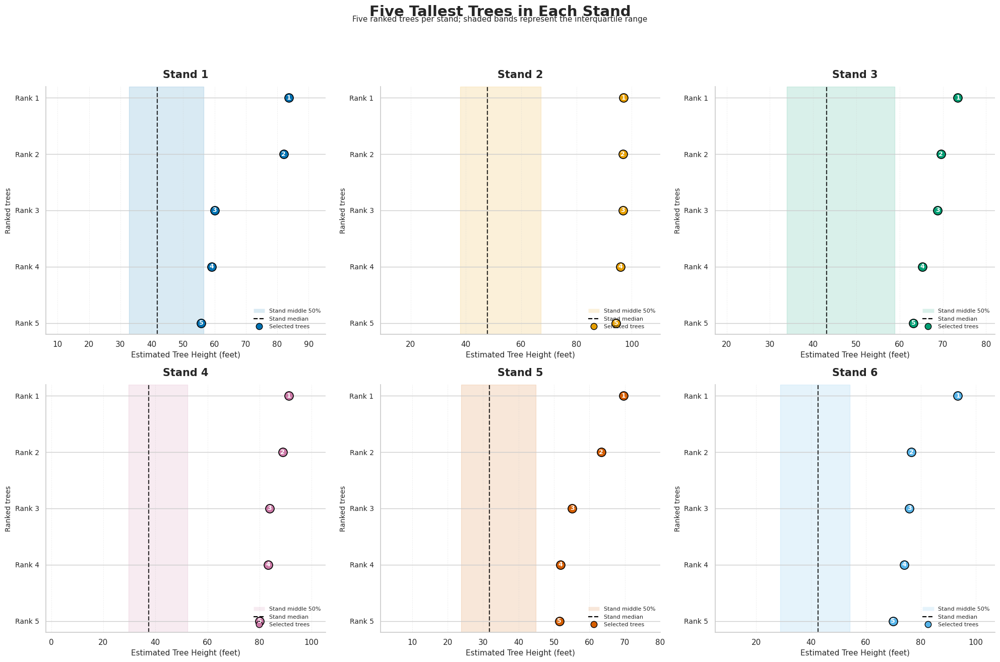

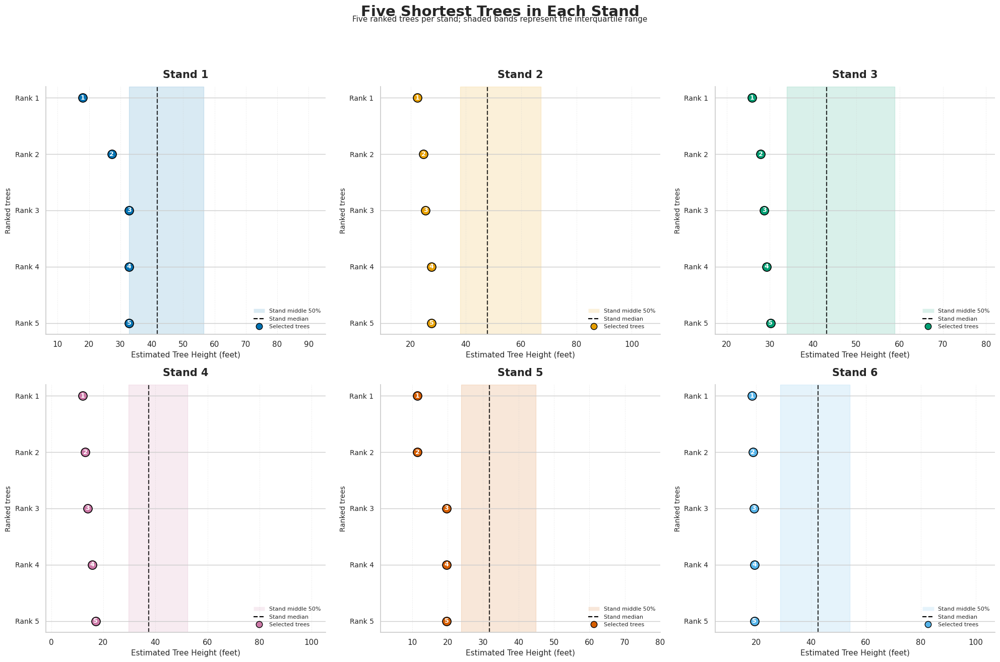

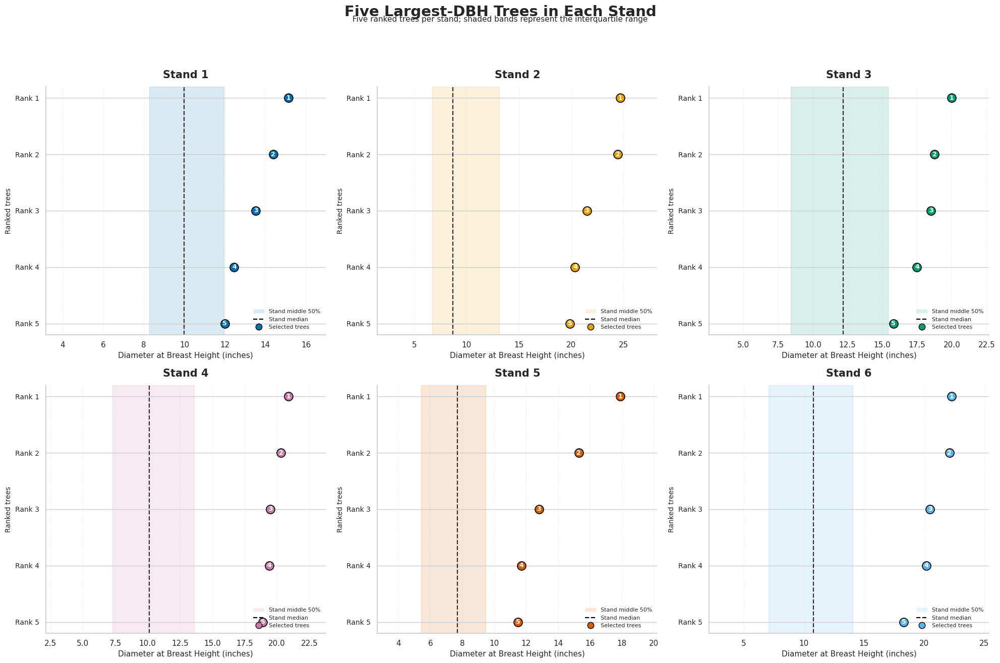

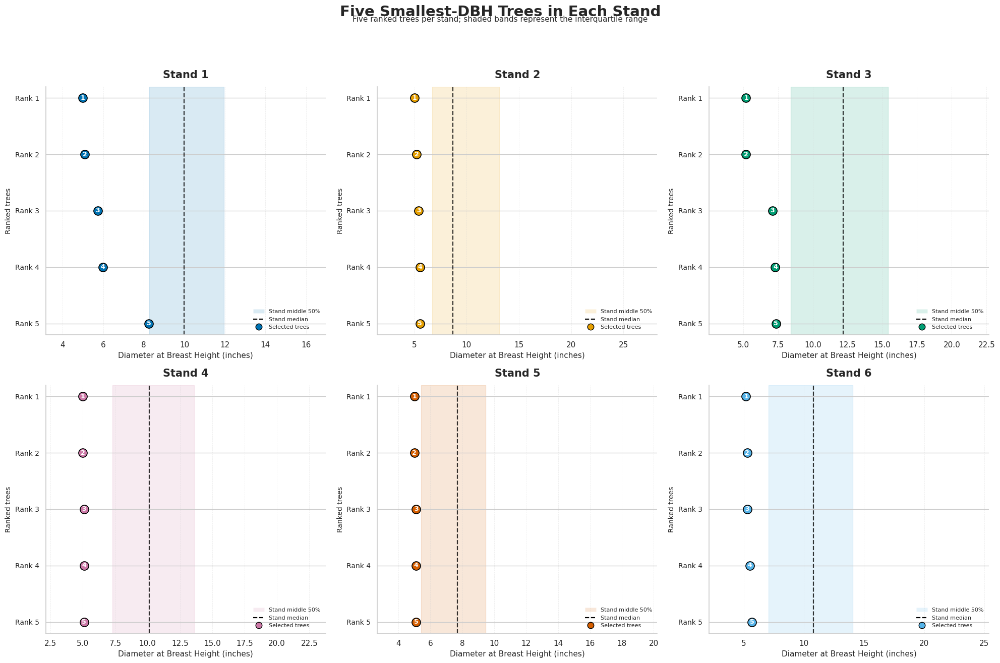

In [193]:

# STEP 175: Create cleaner ranked dot plots with independent stand-specific axes.

# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define a function to create one independent six-panel figure.
def plot_ranked_extremes(
    full_data,
    extreme_data,
    measurement,
    title,
    filename,
    xlabel
):

    # Create six panels arranged in two rows and three columns.
    fig, axes = plt.subplots(
        2, 3,
        figsize=(20, 13),
        sharex=False
    )

    # Flatten the axes array for easier iteration.
    axes = axes.flatten()

    # Loop through the six stands.
    for stand, ax in zip(range(1, 7), axes):

        # Select all measurements from the current stand.
        stand_full = full_data[
            full_data['Stand ID'] == stand
        ].copy()

        # Select the five ranked extreme trees from the current stand.
        stand_extremes = extreme_data[
            extreme_data['Stand ID'] == stand
        ].copy()

        # Calculate the stand median.
        stand_median = stand_full[measurement].median()

        # Calculate the first and third quartiles.
        stand_q1 = stand_full[measurement].quantile(0.25)
        stand_q3 = stand_full[measurement].quantile(0.75)

        # Calculate the observed measurement range for this stand.
        stand_min = stand_full[measurement].min()
        stand_max = stand_full[measurement].max()

        # Calculate padding so the extreme points are not against the axis edges.
        axis_padding = (stand_max - stand_min) * 0.18

        # Use a small minimum padding if measurements have very little variation.
        if axis_padding == 0:
            axis_padding = 1

        # Add a shaded band representing the middle 50% of stand measurements.
        ax.axvspan(
            stand_q1,
            stand_q3,
            color=stand_colors[stand],
            alpha=0.15,
            zorder=0
        )

        # Add a dashed vertical line representing the stand median.
        ax.axvline(
            stand_median,
            color='black',
            linestyle='--',
            linewidth=1.6,
            alpha=0.8,
            zorder=1
        )

        # Assign vertical positions to the five ranked trees.
        # Rank 1 appears at the top of the panel.
        y_positions = np.arange(
            len(stand_extremes),
            0,
            -1
        )

        # Plot the five selected trees as large colored points.
        ax.scatter(
            stand_extremes[measurement],
            y_positions,
            s=150,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=1.2,
            zorder=5
        )

        # Add the rank number inside each highlighted point.
        for x_value, y_value, rank in zip(
            stand_extremes[measurement],
            y_positions,
            stand_extremes['Rank']
        ):

            # Place the rank number in the center of the point.
            ax.text(
                x_value,
                y_value,
                str(rank),
                ha='center',
                va='center',
                fontsize=9,
                fontweight='bold',
                color='white',
                zorder=6
            )

        # Label the vertical positions using rank only.
        ax.set_yticks(y_positions)
        ax.set_yticklabels(
            [f'Rank {rank}' for rank in stand_extremes['Rank']],
            fontsize=10
        )

        # Add the stand title.
        ax.set_title(
            f'Stand {stand}',
            fontsize=15,
            fontweight='bold',
            pad=12
        )

        # Set a stand-specific horizontal axis range.
        ax.set_xlim(
            stand_min - axis_padding,
            stand_max + axis_padding
        )

        # Label the horizontal axis.
        ax.set_xlabel(
            xlabel,
            fontsize=11
        )

        # Label the vertical axis.
        ax.set_ylabel(
            'Ranked trees',
            fontsize=10
        )

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            linestyle='--',
            linewidth=0.6,
            alpha=0.35
        )

        # Keep gridlines behind the plotted data.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        sns.despine(ax=ax)

        # Create a simple legend for the reference elements.
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch

        legend_elements = [
            Patch(
                facecolor=stand_colors[stand],
                alpha=0.15,
                label='Stand middle 50%'
            ),
            Line2D(
                [0], [0],
                color='black',
                linestyle='--',
                linewidth=1.6,
                label='Stand median'
            ),
            Line2D(
                [0], [0],
                marker='o',
                color=stand_colors[stand],
                markeredgecolor='black',
                linestyle='None',
                markersize=9,
                label='Selected trees'
            )
        ]

        # Display the legend in the lower-right corner.
        ax.legend(
            handles=legend_elements,
            loc='lower right',
            fontsize=8,
            frameon=False
        )

    # Add the overall figure title.
    fig.suptitle(
        title,
        fontsize=21,
        fontweight='bold',
        y=1.01
    )

    # Add an explanatory subtitle.
    fig.text(
        0.5,
        0.985,
        'Five ranked trees per stand; shaded bands represent the interquartile range',
        ha='center',
        fontsize=11
    )

    # Adjust spacing to prevent overlapping labels and titles.
    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    # Save the figure at high resolution.
    plt.savefig(
        export_dir / filename,
        dpi=400,
        bbox_inches='tight'
    )

    # Display the finished figure.
    plt.show()

    # Close the figure after saving and displaying it.
    plt.close(fig)


# Figure 1: Five tallest trees in each stand.
plot_ranked_extremes(
    height_visualization_df,
    tallest_trees,
    height_column,
    'Five Tallest Trees in Each Stand',
    'Five_Tallest_Trees_Ranked.png',
    'Estimated Tree Height (feet)'
)

# Figure 2: Five shortest trees in each stand.
plot_ranked_extremes(
    height_visualization_df,
    shortest_trees,
    height_column,
    'Five Shortest Trees in Each Stand',
    'Five_Shortest_Trees_Ranked.png',
    'Estimated Tree Height (feet)'
)

# Figure 3: Five largest-DBH trees in each stand.
plot_ranked_extremes(
    dbh_visualization_df,
    largest_dbh_trees,
    dbh_column,
    'Five Largest-DBH Trees in Each Stand',
    'Five_Largest_DBH_Trees_Ranked.png',
    'Diameter at Breast Height (inches)'
)

# Figure 4: Five smallest-DBH trees in each stand.
plot_ranked_extremes(
    dbh_visualization_df,
    smallest_dbh_trees,
    dbh_column,
    'Five Smallest-DBH Trees in Each Stand',
    'Five_Smallest_DBH_Trees_Ranked.png',
    'Diameter at Breast Height (inches)'
)


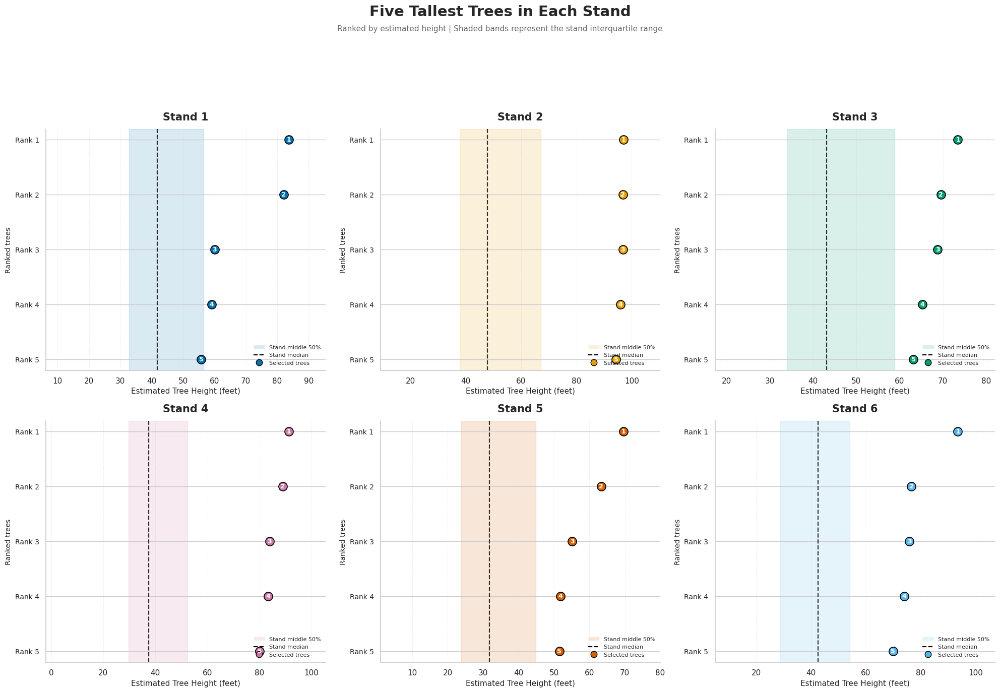

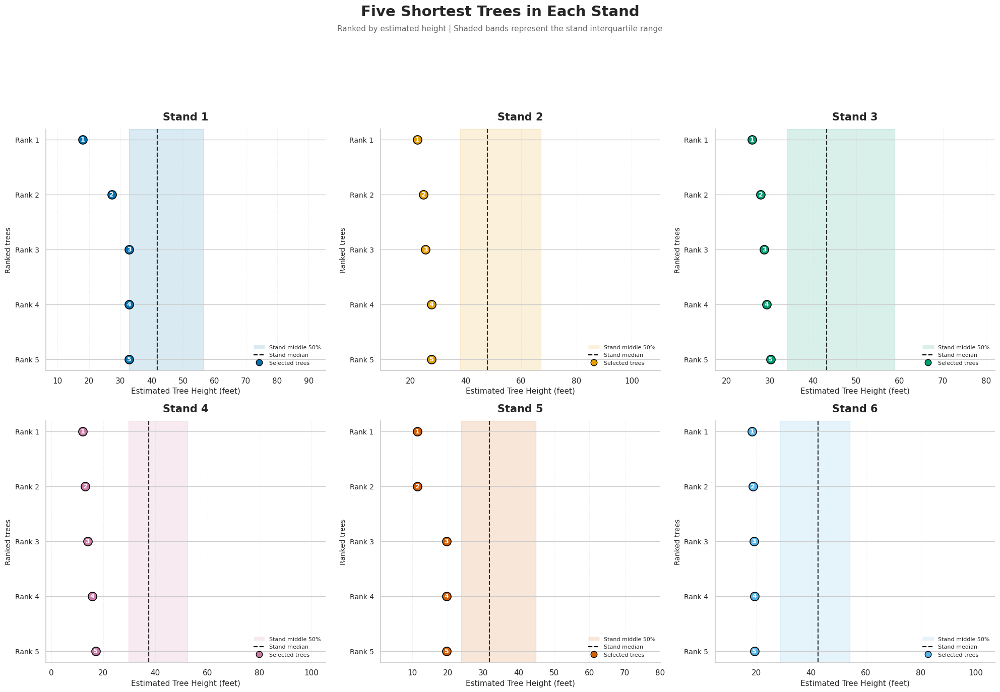

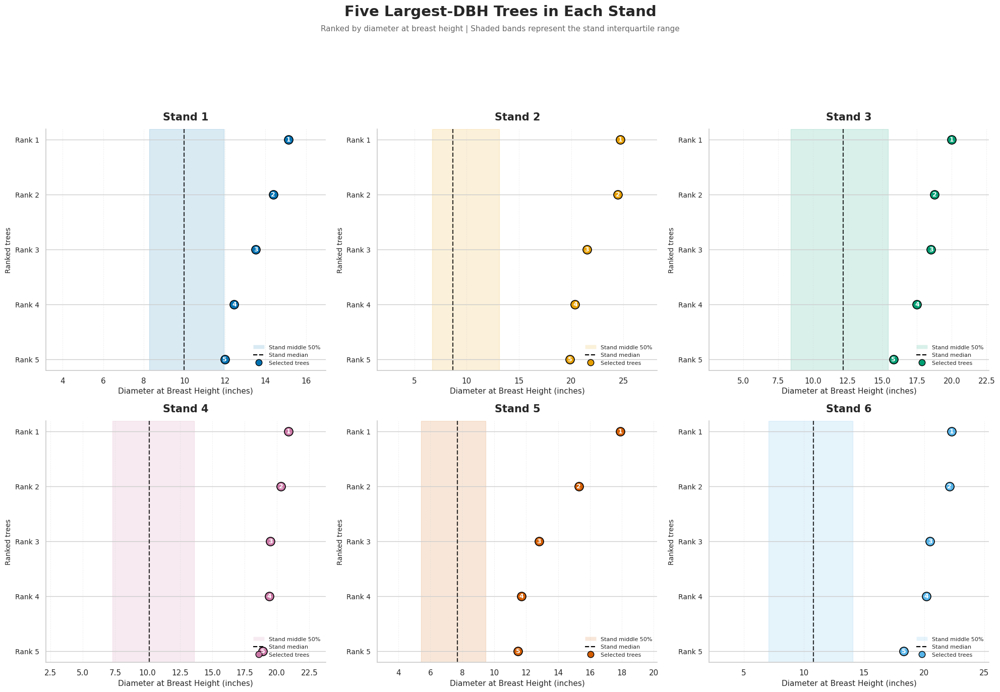

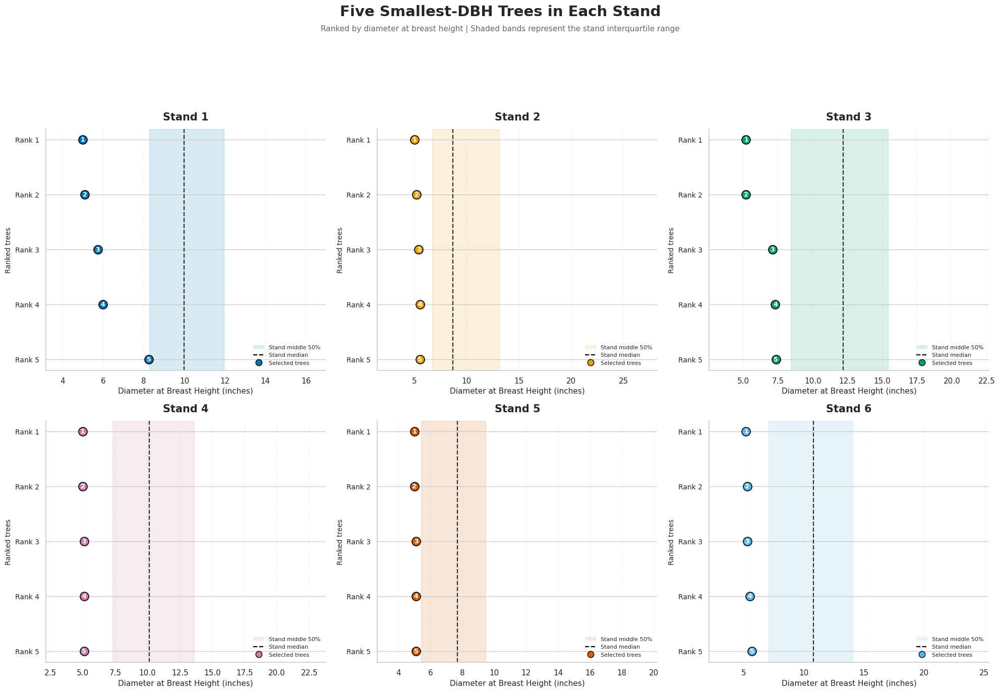

In [194]:

# STEP 175: Create four independent ranked dot plots for tree height and DBH extremes.

# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the measurement columns.
height_column = 'Estimated Tree Height (ft)'
dbh_column = 'DBH (in)'


# ------------------------------------------------------------
# PART 1: DEFINE THE RANKED DOT-PLOT FUNCTION
# ------------------------------------------------------------

# Define a function to create one independent six-panel figure.
def plot_ranked_extremes(
    full_data,
    extreme_data,
    measurement,
    title,
    subtitle,
    filename,
    xlabel
):

    # Create six panels arranged in two rows and three columns.
    fig, axes = plt.subplots(
        2, 3,
        figsize=(20, 13),
        sharex=False
    )

    # Flatten the axes array for easier iteration.
    axes = axes.flatten()

    # Loop through the six stands.
    for stand, ax in zip(range(1, 7), axes):

        # Select all measurements from the current stand.
        stand_full = full_data[
            full_data['Stand ID'] == stand
        ].copy()

        # Select the five ranked extreme trees from the current stand.
        stand_extremes = extreme_data[
            extreme_data['Stand ID'] == stand
        ].copy()

        # Calculate the stand median.
        stand_median = stand_full[measurement].median()

        # Calculate the first and third quartiles.
        stand_q1 = stand_full[measurement].quantile(0.25)
        stand_q3 = stand_full[measurement].quantile(0.75)

        # Calculate the observed measurement range for this stand.
        stand_min = stand_full[measurement].min()
        stand_max = stand_full[measurement].max()

        # Calculate padding so the extreme points are not against the axis edges.
        axis_padding = (stand_max - stand_min) * 0.18

        # Use a small minimum padding if measurements have very little variation.
        if axis_padding == 0:
            axis_padding = 1

        # Add a shaded band representing the middle 50% of stand measurements.
        ax.axvspan(
            stand_q1,
            stand_q3,
            color=stand_colors[stand],
            alpha=0.15,
            zorder=0
        )

        # Add a dashed vertical line representing the stand median.
        ax.axvline(
            stand_median,
            color='black',
            linestyle='--',
            linewidth=1.6,
            alpha=0.8,
            zorder=1
        )

        # Assign vertical positions to the five ranked trees.
        # Rank 1 appears at the top of the panel.
        y_positions = np.arange(
            len(stand_extremes),
            0,
            -1
        )

        # Plot the five selected trees as large colored points.
        ax.scatter(
            stand_extremes[measurement],
            y_positions,
            s=150,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=1.2,
            zorder=5
        )

        # Add the rank number inside each highlighted point.
        for x_value, y_value, rank in zip(
            stand_extremes[measurement],
            y_positions,
            stand_extremes['Rank']
        ):

            # Place the rank number in the center of the point.
            ax.text(
                x_value,
                y_value,
                str(rank),
                ha='center',
                va='center',
                fontsize=9,
                fontweight='bold',
                color='white',
                zorder=6
            )

        # Label the vertical positions using rank only.
        ax.set_yticks(y_positions)
        ax.set_yticklabels(
            [f'Rank {rank}' for rank in stand_extremes['Rank']],
            fontsize=10
        )

        # Add the stand title.
        ax.set_title(
            f'Stand {stand}',
            fontsize=15,
            fontweight='bold',
            pad=12
        )

        # Set a stand-specific horizontal axis range.
        ax.set_xlim(
            stand_min - axis_padding,
            stand_max + axis_padding
        )

        # Label the horizontal axis.
        ax.set_xlabel(
            xlabel,
            fontsize=11
        )

        # Label the vertical axis.
        ax.set_ylabel(
            'Ranked trees',
            fontsize=10
        )

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            linestyle='--',
            linewidth=0.6,
            alpha=0.35
        )

        # Keep gridlines behind the plotted data.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        sns.despine(ax=ax)

        # Import components used to construct the legend.
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch

        # Define the legend elements.
        legend_elements = [
            Patch(
                facecolor=stand_colors[stand],
                alpha=0.15,
                label='Stand middle 50%'
            ),
            Line2D(
                [0], [0],
                color='black',
                linestyle='--',
                linewidth=1.6,
                label='Stand median'
            ),
            Line2D(
                [0], [0],
                marker='o',
                color=stand_colors[stand],
                markeredgecolor='black',
                linestyle='None',
                markersize=9,
                label='Selected trees'
            )
        ]

        # Display the legend in the lower-right corner.
        ax.legend(
            handles=legend_elements,
            loc='lower right',
            fontsize=8,
            frameon=False
        )

    # Add the main figure title.
    fig.suptitle(
        title,
        fontsize=21,
        fontweight='bold',
        y=1.055
    )

    # Add the subtitle as a separate line with additional spacing.
    fig.text(
        0.5,
        1.015,
        subtitle,
        ha='center',
        fontsize=11,
        color='dimgray'
    )

    # Adjust spacing to keep the title, subtitle, and panels separate.
    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    # Save the figure at high resolution.
    plt.savefig(
        export_dir / filename,
        dpi=400,
        bbox_inches='tight'
    )

    # Display the finished figure.
    plt.show()

    # Close the figure after saving and displaying it.
    plt.close(fig)


# ------------------------------------------------------------
# PART 2: CREATE FOUR INDEPENDENT FIGURES
# ------------------------------------------------------------

# Figure 1: Five tallest trees in each stand.
plot_ranked_extremes(
    full_data=height_visualization_df,
    extreme_data=tallest_trees,
    measurement=height_column,
    title='Five Tallest Trees in Each Stand',
    subtitle='Ranked by estimated height | Shaded bands represent the stand interquartile range',
    filename='Five_Tallest_Trees_Ranked.png',
    xlabel='Estimated Tree Height (feet)'
)

# Figure 2: Five shortest trees in each stand.
plot_ranked_extremes(
    full_data=height_visualization_df,
    extreme_data=shortest_trees,
    measurement=height_column,
    title='Five Shortest Trees in Each Stand',
    subtitle='Ranked by estimated height | Shaded bands represent the stand interquartile range',
    filename='Five_Shortest_Trees_Ranked.png',
    xlabel='Estimated Tree Height (feet)'
)

# Figure 3: Five largest-DBH trees in each stand.
plot_ranked_extremes(
    full_data=dbh_visualization_df,
    extreme_data=largest_dbh_trees,
    measurement=dbh_column,
    title='Five Largest-DBH Trees in Each Stand',
    subtitle='Ranked by diameter at breast height | Shaded bands represent the stand interquartile range',
    filename='Five_Largest_DBH_Trees_Ranked.png',
    xlabel='Diameter at Breast Height (inches)'
)

# Figure 4: Five smallest-DBH trees in each stand.
plot_ranked_extremes(
    full_data=dbh_visualization_df,
    extreme_data=smallest_dbh_trees,
    measurement=dbh_column,
    title='Five Smallest-DBH Trees in Each Stand',
    subtitle='Ranked by diameter at breast height | Shaded bands represent the stand interquartile range',
    filename='Five_Smallest_DBH_Trees_Ranked.png',
    xlabel='Diameter at Breast Height (inches)'
)


In [195]:
# STEP 176: Inspect the fine woody debris dataset.

# Print the dimensions of the dataset.
print("FWD dataset dimensions:", fwd.shape)

# Display all available column names.
print("\nFWD columns:")
print(fwd.columns.tolist())

# Display the first five observations.
print("\nFirst five observations:")
display(fwd.head())

# Display the number of missing values in each column.
print("\nMissing values:")
display(fwd.isna().sum())

# Display the number of observations recorded in each stand.
print("\nObservations by stand:")
display(fwd['Stand ID'].value_counts().sort_index())

FWD dataset dimensions: (175, 8)

FWD columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Size Class', 'Count', 'Notes']

First five observations:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Size Class,Count,Notes
0,1,1,1,23-Oct,"EC, HP, LW, AB, LA, JW, JR,JM",1,33,NaN
1,1,1,1,23-Oct,"EC, HP, LW, AB, LA, JW, JR,JM",2,20,NaN
2,1,1,1,23-Oct,"EC, HP, LW, AB, LA, JW, JR,JM",3,6,NaN
3,2,1,1,23-Oct,"AB, EC, JR, HP",1,23,NaN
4,2,1,1,23-Oct,"AB, EC, JR, HP",2,13,NaN



Missing values:


,0
Stand ID,0
Plot ID,0
Subplot ID,0
Date,0
Team Member(s),0
Size Class,0
Count,0
Notes,175



Observations by stand:


,count
Stand ID,
1,3
2,43
3,18
4,66
5,12
6,21
7,9
9,3


In [196]:
# STEP 177: Examine FWD size classes and sampling coverage.

# Create a working copy containing only stands 1–6.
fwd_analysis = fwd[fwd['Stand ID'].isin([1, 2, 3, 4, 5, 6])].copy()

# Display the unique size classes recorded in the dataset.
print("FWD size classes:")
print(sorted(fwd_analysis['Size Class'].unique()))

# Count the number of records within each stand and size class.
print("\nRecords by stand and size class:")
display(
    fwd_analysis.groupby(['Stand ID', 'Size Class'])
    .size()
    .unstack(fill_value=0)
)

# Calculate the total FWD count within each stand and size class.
print("\nFWD counts by stand and size class:")
display(
    fwd_analysis.groupby(['Stand ID', 'Size Class'])['Count']
    .sum()
    .unstack(fill_value=0)
)

# Count the unique plots and subplots sampled within each stand.
print("\nSampling coverage by stand:")
display(
    fwd_analysis.groupby('Stand ID')
    .agg(
        Unique_Plots=('Plot ID', 'nunique'),
        Unique_Subplots=('Subplot ID', 'nunique'),
        Total_Records=('Count', 'size')
    )
)

FWD size classes:
[np.int64(1), np.int64(2), np.int64(3)]

Records by stand and size class:


Size Class,1,2,3
Stand ID,,,
1,1,1,1
2,15,14,14
3,6,6,6
4,22,22,22
5,4,4,4
6,7,7,7



FWD counts by stand and size class:


Size Class,1,2,3
Stand ID,,,
1,33,20,6
2,423,219,123
3,176,52,43
4,633,264,129
5,128,44,13
6,197,114,138



Sampling coverage by stand:


,Unique_Plots,Unique_Subplots,Total_Records
Stand ID,,,
1,1,1,3
2,4,5,43
3,2,4,18
4,2,13,66
5,2,2,12
6,1,7,21


In [197]:
# STEP 178: Check whether each sampled subplot has all three FWD size classes.

# Group records by stand, plot, and subplot.
# Each combination represents one distinct sampling unit.
fwd_subplot_check = (
    fwd_analysis
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])
    .agg(
        Number_of_Size_Classes=('Size Class', 'nunique'),
        Size_Classes_Recorded=('Size Class', lambda x: sorted(x.unique())),
        Total_FWD_Count=('Count', 'sum')
    )
    .reset_index()
)

# Display the number of distinct sampled subplots in each stand.
print("Distinct sampled subplots by stand:")
display(
    fwd_subplot_check.groupby('Stand ID')
    .size()
    .rename('Number of Subplots')
    .to_frame()
)

# Identify any subplots that do not contain all three size classes.
print("\nSubplots with incomplete size-class records:")
display(
    fwd_subplot_check[
        fwd_subplot_check['Number_of_Size_Classes'] != 3
    ]
)

# Summarize total FWD counts across sampled subplots within each stand.
print("\nTotal FWD counts by stand:")
display(
    fwd_subplot_check.groupby('Stand ID')
    .agg(
        Sampled_Subplots=('Total_FWD_Count', 'size'),
        Total_FWD_Count=('Total_FWD_Count', 'sum'),
        Mean_Count_Per_Subplot=('Total_FWD_Count', 'mean'),
        Median_Count_Per_Subplot=('Total_FWD_Count', 'median'),
        SD_Count_Per_Subplot=('Total_FWD_Count', 'std')
    ).round(2)
)

Distinct sampled subplots by stand:


,Number of Subplots
Stand ID,
1,1
2,15
3,6
4,22
5,3
6,7



Subplots with incomplete size-class records:


,Stand ID,Plot ID,Subplot ID,Number_of_Size_Classes,Size_Classes_Recorded,Total_FWD_Count
11,2,3,4,1,[1],35



Total FWD counts by stand:


,Sampled_Subplots,Total_FWD_Count,Mean_Count_Per_Subplot,Median_Count_Per_Subplot,SD_Count_Per_Subplot
Stand ID,,,,,
1,1,59,59.00,59.0,NaN
2,15,765,51.00,48.0,13.38
3,6,271,45.17,41.0,16.12
4,22,1026,46.64,48.5,14.22
5,3,185,61.67,54.0,29.26
6,7,449,64.14,58.0,23.65


In [198]:
# STEP 179: Calculate FWD abundance and size-class composition by stand.

# Reshape the data so each row represents one subplot and each
# size-class column contains the corresponding FWD piece count.
fwd_size_pivot = fwd_analysis.pivot_table(
    index=['Stand ID', 'Plot ID', 'Subplot ID'],
    columns='Size Class',
    values='Count',
    aggfunc='sum'
)

# Retain only subplots with observations for all three size classes.
# Missing size-class records remain missing rather than being treated as zero.
fwd_complete_subplots = fwd_size_pivot.dropna(
    subset=[1, 2, 3]
).copy()

# Calculate the total number of FWD pieces across all three size classes
# within each complete subplot.
fwd_complete_subplots['Total FWD'] = (
    fwd_complete_subplots[1] +
    fwd_complete_subplots[2] +
    fwd_complete_subplots[3]
)

# Calculate mean, median, standard deviation, and sample size
# for each size class within each stand.
print("FWD counts per subplot by size class:")
display(
    fwd_complete_subplots.groupby(level='Stand ID')[[1, 2, 3]]
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

# Calculate total FWD abundance per complete subplot by stand.
print("\nTotal FWD counts per complete subplot:")
display(
    fwd_complete_subplots.groupby(level='Stand ID')['Total FWD']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

# Calculate total counts for each size class within each stand.
fwd_class_totals = (
    fwd_complete_subplots.groupby(level='Stand ID')[[1, 2, 3]]
    .sum()
)

# Calculate each size class as a percentage of the stand's total FWD count.
fwd_class_percentages = (
    fwd_class_totals.div(fwd_class_totals.sum(axis=1), axis=0) * 100
)

# Display the relative contribution of each size class within each stand.
print("\nFWD size-class composition by stand (%):")
display(fwd_class_percentages.round(2))

FWD counts per subplot by size class:


Size Class     1                          2                         3         \
           count   mean median    std count   mean median   std count   mean   
Stand ID                                                                       
1              1  33.00   33.0    NaN     1  20.00   20.0   NaN     1   6.00   
2             14  27.71   26.0   8.05    14  15.64   14.0  4.94    14   8.79   
3              6  29.33   29.5  10.80     6   8.67    7.0  7.45     6   7.17   
4             22  28.77   31.0  11.34    22  12.00   11.5  4.68    22   5.86   
5              3  42.67   32.0  20.23     3  14.67   16.0  8.08     3   4.33   
6              7  28.14   28.0   9.55     7  16.29   17.0  5.59     7  19.71   

Size Class                
           median    std  
Stand ID                  
1             6.0    NaN  
2             8.5   3.49  
3             6.0   4.54  
4             4.5   4.13  
5             6.0   2.89  
6            11.0  22.73


Total FWD counts per complete subplot:


,count,mean,median,std,min,max
Stand ID,,,,,,
1,1,59.00,59.0,NaN,59.0,59.0
2,14,52.14,48.0,13.10,35.0,79.0
3,6,45.17,41.0,16.12,28.0,69.0
4,22,46.64,48.5,14.22,19.0,80.0
5,3,61.67,54.0,29.26,37.0,94.0
6,7,64.14,58.0,23.65,43.0,112.0



FWD size-class composition by stand (%):


Size Class,1,2,3
Stand ID,,,
1,55.93,33.90,10.17
2,53.15,30.00,16.85
3,64.94,19.19,15.87
4,61.70,25.73,12.57
5,69.19,23.78,7.03
6,43.88,25.39,30.73


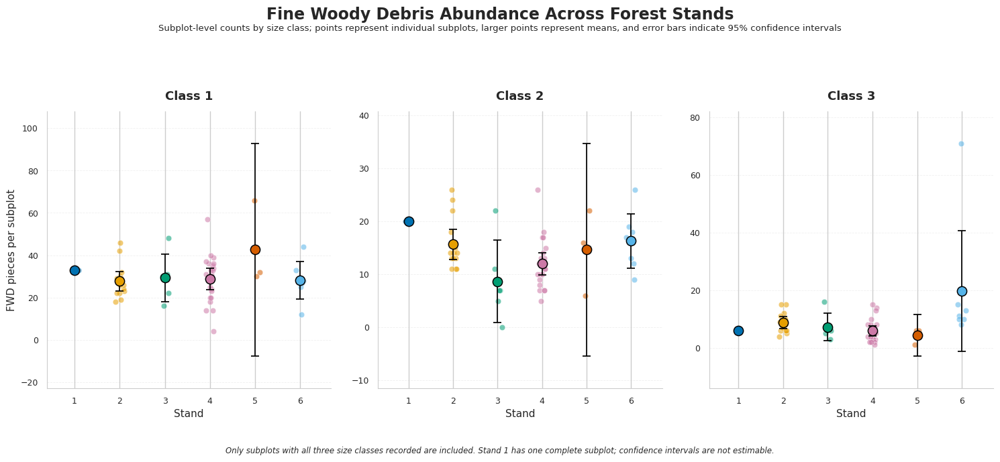

In [199]:
# STEP 181: Create a publication-quality FWD abundance figure.
#
# This figure compares FWD counts per subplot among stands,
# separately for each of the three size classes.
#
# Individual subplot observations are shown to reveal variation.
# Larger points represent stand means.
# Error bars represent 95% confidence intervals where estimable.
#
# Only subplots containing all three size classes are included.
# This avoids treating missing size-class observations as zero.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------------------------------------------
# 1. Prepare the data for plotting
# ------------------------------------------------------------

# Convert the subplot-level pivot table into a long-format dataframe.
# Each row will represent one subplot and one size class.
fwd_long = (
    fwd_complete_subplots[[1, 2, 3]]
    .reset_index()
    .melt(
        id_vars=['Stand ID', 'Plot ID', 'Subplot ID'],
        value_vars=[1, 2, 3],
        var_name='Size Class',
        value_name='FWD Count'
    )
)

# Define the order and descriptive names of the size classes.
size_class_order = [1, 2, 3]

size_class_names = {
    1: 'Class 1',
    2: 'Class 2',
    3: 'Class 3'
}

# Define the six stands in a consistent order.
stand_order = [1, 2, 3, 4, 5, 6]

# ------------------------------------------------------------
# 2. Calculate stand-level means and 95% confidence intervals
# ------------------------------------------------------------

# Summarize the number of observations, mean, and standard deviation
# for each stand and size class.
fwd_summary = (
    fwd_long
    .groupby(['Stand ID', 'Size Class'])['FWD Count']
    .agg(['count', 'mean', 'std'])
    .reset_index()
)

# Calculate 95% confidence intervals using the t distribution.
# Confidence intervals are not calculated for groups with fewer than
# two observations because their variability cannot be estimated.
fwd_summary['CI Lower'] = np.nan
fwd_summary['CI Upper'] = np.nan

for index, row in fwd_summary.iterrows():

    # Retrieve the sample size and standard deviation.
    n = int(row['count'])
    sd = row['std']

    # Calculate the confidence interval when n is at least two.
    if n >= 2 and pd.notna(sd):

        # Calculate the t critical value for a two-sided 95% interval.
        t_critical = stats.t.ppf(0.975, df=n - 1)

        # Calculate the margin of error.
        margin = t_critical * sd / np.sqrt(n)

        # Store the lower and upper confidence limits.
        fwd_summary.loc[index, 'CI Lower'] = row['mean'] - margin
        fwd_summary.loc[index, 'CI Upper'] = row['mean'] + margin

# ------------------------------------------------------------
# 3. Establish a consistent publication-style figure format
# ------------------------------------------------------------

# Use a restrained scientific plotting style.
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 17,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'savefig.dpi': 600
})

# Create three horizontally arranged panels, one for each size class.
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 6.5),
    sharey=False
)

# ------------------------------------------------------------
# 4. Plot individual observations, means, and confidence intervals
# ------------------------------------------------------------

# Use a deterministic horizontal offset to separate observations
# when multiple subplot counts have the same or similar values.
# The offset is small so that the x-axis still represents stand.
for ax, size_class in zip(axes, size_class_order):

    # Select observations belonging to the current size class.
    class_data = fwd_long[
        fwd_long['Size Class'] == size_class
    ]

    # Select the summary statistics for the current size class.
    class_summary = fwd_summary[
        fwd_summary['Size Class'] == size_class
    ]

    # Plot each stand separately using its established color.
    for stand in stand_order:

        # Extract the individual subplot observations for this stand.
        stand_data = class_data[
            class_data['Stand ID'] == stand
        ]['FWD Count'].dropna().to_numpy()

        # Generate small, reproducible horizontal offsets for visibility.
        rng = np.random.default_rng(seed=stand * 100 + size_class)

        jitter = rng.uniform(
            low=-0.10,
            high=0.10,
            size=len(stand_data)
        )

        # Plot individual subplot counts.
        ax.scatter(
            np.full(len(stand_data), stand) + jitter,
            stand_data,
            s=38,
            color=stand_colors[stand],
            alpha=0.55,
            edgecolor='white',
            linewidth=0.55,
            zorder=2
        )

        # Retrieve the corresponding stand-level summary.
        summary_row = class_summary[
            class_summary['Stand ID'] == stand
        ]

        if not summary_row.empty:

            # Extract the mean count.
            mean_value = summary_row['mean'].iloc[0]

            # Extract the confidence interval limits.
            lower = summary_row['CI Lower'].iloc[0]
            upper = summary_row['CI Upper'].iloc[0]

            # Plot the mean as a larger, dark-edged point.
            ax.scatter(
                stand,
                mean_value,
                s=105,
                color=stand_colors[stand],
                edgecolor='black',
                linewidth=1.1,
                zorder=4
            )

            # Add the 95% confidence interval where available.
            if pd.notna(lower) and pd.notna(upper):

                ax.errorbar(
                    stand,
                    mean_value,
                    yerr=np.array([
                        [mean_value - lower],
                        [upper - mean_value]
                    ]),
                    fmt='none',
                    ecolor='black',
                    elinewidth=1.25,
                    capsize=4,
                    capthick=1.25,
                    zorder=3
                )

    # Add the size-class panel title.
    ax.set_title(
        size_class_names[size_class],
        fontweight='bold',
        pad=12
    )

    # Set the stand labels.
    ax.set_xticks(stand_order)
    ax.set_xticklabels([f'{s}' for s in stand_order])

    # Label the horizontal axis.
    ax.set_xlabel('Stand')

    # Add subtle horizontal gridlines.
    ax.grid(
        axis='y',
        linestyle='--',
        linewidth=0.6,
        alpha=0.30
    )

    # Keep gridlines behind the data.
    ax.set_axisbelow(True)

    # Use a small margin around the plotted observations.
    ax.margins(x=0.12, y=0.15)

# Add a shared y-axis label to the first panel.
axes[0].set_ylabel('FWD pieces per subplot')

# ------------------------------------------------------------
# 5. Add the figure title and explanatory subtitle
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Abundance Across Forest Stands',
    fontweight='bold',
    y=1.04
)

fig.text(
    0.5,
    0.985,
    'Subplot-level counts by size class; points represent individual subplots, '
    'larger points represent means, and error bars indicate 95% confidence intervals',
    ha='center',
    fontsize=9.5
)

# Add a note explaining the sample-size limitation.
fig.text(
    0.5,
    0.015,
    'Only subplots with all three size classes recorded are included. '
    'Stand 1 has one complete subplot; confidence intervals are not estimable.',
    ha='center',
    fontsize=8.5,
    style='italic'
)

# Adjust spacing to accommodate the title and note.
fig.tight_layout(rect=[0, 0.07, 1, 0.93], w_pad=2.2)

# ------------------------------------------------------------
# 6. Export the figure
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'FWD_Abundance_by_Size_Class_Publication.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF for publication and further editing.
fig.savefig(
    export_dir / 'FWD_Abundance_by_Size_Class_Publication.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

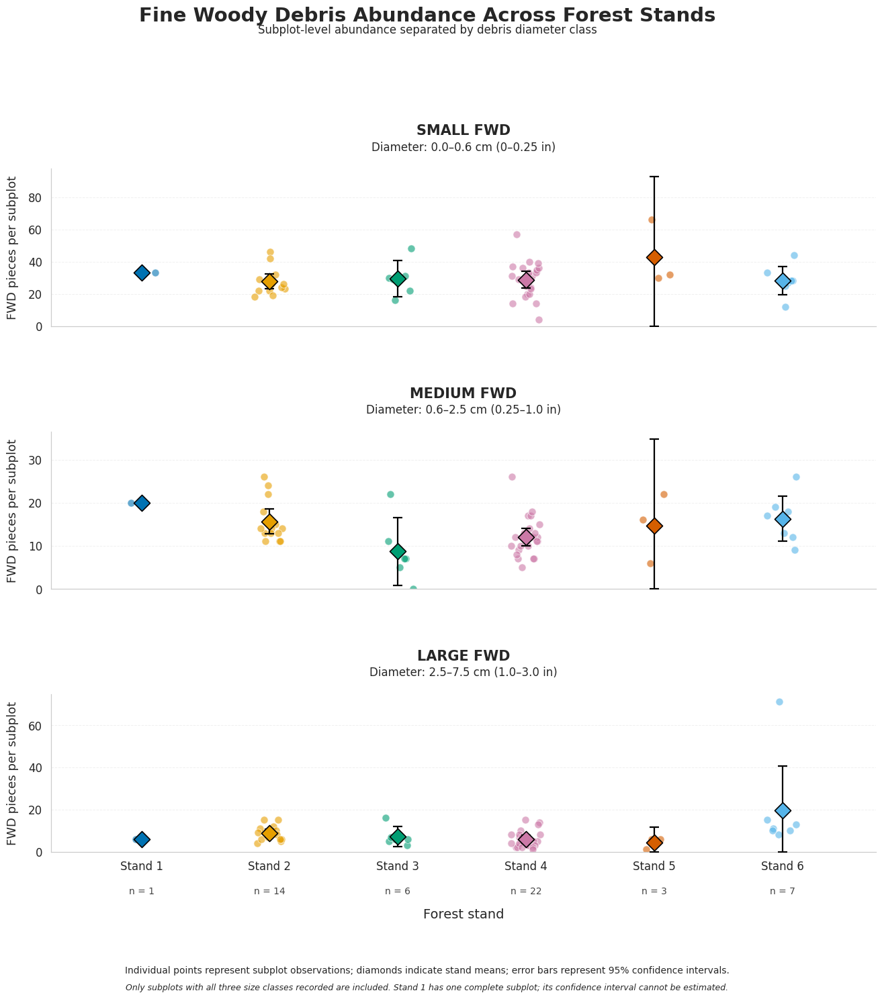

In [200]:
# STEP 183: Create an enlarged, publication-quality FWD abundance figure.
#
# Figure structure:
#   Panel A: Small FWD (0.0–0.6 cm)
#   Panel B: Medium FWD (0.6–2.5 cm)
#   Panel C: Large FWD (2.5–7.5 cm)
#
# Individual points represent subplot-level observations.
# Large black-outlined points represent stand means.
# Error bars represent 95% confidence intervals.
#
# Only complete subplots containing all three size classes are included.

# ------------------------------------------------------------
# 1. Import required packages
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------------------------------------------
# 2. Define size-class descriptions
# ------------------------------------------------------------

# Include both metric and imperial diameter ranges directly
# in the panel headings so readers do not need a separate key.

size_class_information = {
    1: {
        'name': 'SMALL FWD',
        'diameter': 'Diameter: 0.0–0.6 cm (0–0.25 in)'
    },
    2: {
        'name': 'MEDIUM FWD',
        'diameter': 'Diameter: 0.6–2.5 cm (0.25–1.0 in)'
    },
    3: {
        'name': 'LARGE FWD',
        'diameter': 'Diameter: 2.5–7.5 cm (1.0–3.0 in)'
    }
}

# Define the order of stands and size classes.
stand_order = [1, 2, 3, 4, 5, 6]
size_class_order = [1, 2, 3]

# ------------------------------------------------------------
# 3. Prepare the subplot-level dataset
# ------------------------------------------------------------

# Convert the complete-subplot dataframe into long format.
# Each row represents one subplot and one size class.

fwd_long = (
    fwd_complete_subplots[[1, 2, 3]]
    .reset_index()
    .melt(
        id_vars=['Stand ID', 'Plot ID', 'Subplot ID'],
        value_vars=[1, 2, 3],
        var_name='Size Class',
        value_name='FWD Count'
    )
)

# Ensure the size-class variable is stored as an integer.
fwd_long['Size Class'] = fwd_long['Size Class'].astype(int)

# ------------------------------------------------------------
# 4. Calculate stand-level descriptive statistics
# ------------------------------------------------------------

# Calculate the sample size, mean, and standard deviation
# for every stand and size-class combination.

fwd_summary = (
    fwd_long
    .groupby(['Stand ID', 'Size Class'])['FWD Count']
    .agg(
        n='count',
        mean='mean',
        sd='std'
    )
    .reset_index()
)

# Initialize confidence interval columns.
fwd_summary['CI Lower'] = np.nan
fwd_summary['CI Upper'] = np.nan

# Calculate 95% confidence intervals using the t distribution.
# A confidence interval is not estimable when only one subplot
# is available for a stand and size class.

for index, row in fwd_summary.iterrows():

    # Retrieve the sample size and standard deviation.
    n = int(row['n'])
    sd = row['sd']

    # Calculate the confidence interval when at least two
    # independent subplot observations are available.
    if n >= 2 and pd.notna(sd):

        # Determine the critical t value.
        t_critical = stats.t.ppf(0.975, df=n - 1)

        # Calculate the confidence interval margin.
        margin = t_critical * sd / np.sqrt(n)

        # Store the lower and upper confidence limits.
        fwd_summary.loc[index, 'CI Lower'] = row['mean'] - margin
        fwd_summary.loc[index, 'CI Upper'] = row['mean'] + margin

# ------------------------------------------------------------
# 5. Set publication-style formatting
# ------------------------------------------------------------

# Establish consistent typography and restrained figure styling.
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 13,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.titlesize': 21,
    'axes.linewidth': 0.9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'savefig.dpi': 600
})

# ------------------------------------------------------------
# 6. Create three vertically stacked panels
# ------------------------------------------------------------

# A vertical layout gives each size class more space and
# makes the observations, confidence intervals, and labels
# substantially easier to read.

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 15),
    sharex=True
)

# ------------------------------------------------------------
# 7. Plot each size class
# ------------------------------------------------------------

for panel_index, size_class in enumerate(size_class_order):

    # Select the corresponding plotting axis.
    ax = axes[panel_index]

    # Extract observations for the current size class.
    class_data = fwd_long[
        fwd_long['Size Class'] == size_class
    ]

    # Extract summary statistics for the current size class.
    class_summary = fwd_summary[
        fwd_summary['Size Class'] == size_class
    ]

    # Plot each stand separately.
    for stand in stand_order:

        # Retrieve individual subplot counts for this stand.
        stand_data = class_data[
            class_data['Stand ID'] == stand
        ]['FWD Count'].dropna().to_numpy()

        # Create small horizontal offsets so overlapping
        # observations can be distinguished.
        rng = np.random.default_rng(
            seed=stand * 100 + size_class
        )

        jitter = rng.uniform(
            low=-0.12,
            high=0.12,
            size=len(stand_data)
        )

        # Plot individual subplot observations.
        ax.scatter(
            np.full(len(stand_data), stand) + jitter,
            stand_data,
            s=65,
            color=stand_colors[stand],
            alpha=0.60,
            edgecolor='white',
            linewidth=0.8,
            zorder=2
        )

        # Retrieve the stand-level mean and confidence interval.
        summary_row = class_summary[
            class_summary['Stand ID'] == stand
        ]

        if not summary_row.empty:

            # Extract the stand mean.
            mean_value = summary_row['mean'].iloc[0]

            # Extract confidence interval limits.
            lower = summary_row['CI Lower'].iloc[0]
            upper = summary_row['CI Upper'].iloc[0]

            # Plot the stand mean using a large,
            # black-outlined diamond marker.
            ax.scatter(
                stand,
                mean_value,
                s=150,
                marker='D',
                color=stand_colors[stand],
                edgecolor='black',
                linewidth=1.2,
                zorder=5
            )

            # Plot the 95% confidence interval when estimable.
            if pd.notna(lower) and pd.notna(upper):

                # Use the full confidence interval for the error bar.
                # The lower portion is clipped at zero because
                # negative debris counts are not physically possible.
                ax.errorbar(
                    stand,
                    mean_value,
                    yerr=np.array([
                        [mean_value - max(0, lower)],
                        [upper - mean_value]
                    ]),
                    fmt='none',
                    ecolor='black',
                    elinewidth=1.6,
                    capsize=5,
                    capthick=1.6,
                    zorder=4
                )

    # --------------------------------------------------------
    # 8. Add prominent size-class headings and definitions
    # --------------------------------------------------------

    # Display the size-class name as the panel heading.
    ax.text(
        0.5,
        1.20,
        size_class_information[size_class]['name'],
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=15,
        fontweight='bold'
    )

    # Display the actual diameter range directly below the heading.
    ax.text(
        0.5,
        1.10,
        size_class_information[size_class]['diameter'],
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=12
    )

    # --------------------------------------------------------
    # 9. Format axes and gridlines
    # --------------------------------------------------------

    # Set the vertical axis to begin at zero.
    ax.set_ylim(bottom=0)

    # Label the vertical axis.
    ax.set_ylabel(
        'FWD pieces per subplot',
        labelpad=10
    )

    # Display all six stands.
    ax.set_xticks(stand_order)
    ax.set_xticklabels([f'Stand {s}' for s in stand_order])

    # Use subtle horizontal gridlines.
    ax.grid(
        axis='y',
        linestyle='--',
        linewidth=0.7,
        alpha=0.30
    )

    # Keep gridlines behind observations.
    ax.set_axisbelow(True)

    # Add whitespace around the plotted observations.
    ax.margins(x=0.12, y=0.15)

    # Remove unnecessary vertical gridlines.
    ax.grid(axis='x', visible=False)

# ------------------------------------------------------------
# 10. Add sample sizes beneath the stand labels
# ------------------------------------------------------------

# Sample sizes are based on the number of complete subplots
# contributing to each stand's size-class summary.

for stand in stand_order:

    # Count complete subplot observations for this stand.
    sample_size = len(
        fwd_complete_subplots.loc[
            fwd_complete_subplots.index.get_level_values('Stand ID') == stand
        ]
    )

    # Add sample-size information beneath the x-axis.
    axes[-1].text(
        stand,
        -0.22,
        f'n = {sample_size}',
        transform=axes[-1].get_xaxis_transform(),
        ha='center',
        va='top',
        fontsize=10,
        color='#444444'
    )

# Add the shared x-axis label.
axes[-1].set_xlabel(
    'Forest stand',
    fontsize=14,
    labelpad=38
)

# ------------------------------------------------------------
# 11. Add figure title and explanatory information
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Abundance Across Forest Stands',
    fontsize=21,
    fontweight='bold',
    y=0.985
)

# Add a concise subtitle.
fig.text(
    0.5,
    0.958,
    'Subplot-level abundance separated by debris diameter class',
    ha='center',
    fontsize=12
)

# Add an explanatory note beneath the figure.
fig.text(
    0.5,
    0.025,
    'Individual points represent subplot observations; diamonds indicate stand means; '
    'error bars represent 95% confidence intervals.',
    ha='center',
    fontsize=10
)

# Explain the sample-size limitation.
fig.text(
    0.5,
    0.008,
    'Only subplots with all three size classes recorded are included. '
    'Stand 1 has one complete subplot; its confidence interval cannot be estimated.',
    ha='center',
    fontsize=9,
    style='italic'
)

# ------------------------------------------------------------
# 12. Adjust spacing and export
# ------------------------------------------------------------

# Reserve space for the title, panel headings, sample sizes,
# and explanatory notes.
fig.tight_layout(
    rect=[0.04, 0.065, 0.99, 0.925],
    h_pad=3.5
)

# Export a high-resolution PNG.
fig.savefig(
    export_dir / 'FWD_Abundance_by_Size_Class_Publication.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Export a vector PDF suitable for publication workflows.
fig.savefig(
    export_dir / 'FWD_Abundance_by_Size_Class_Publication.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

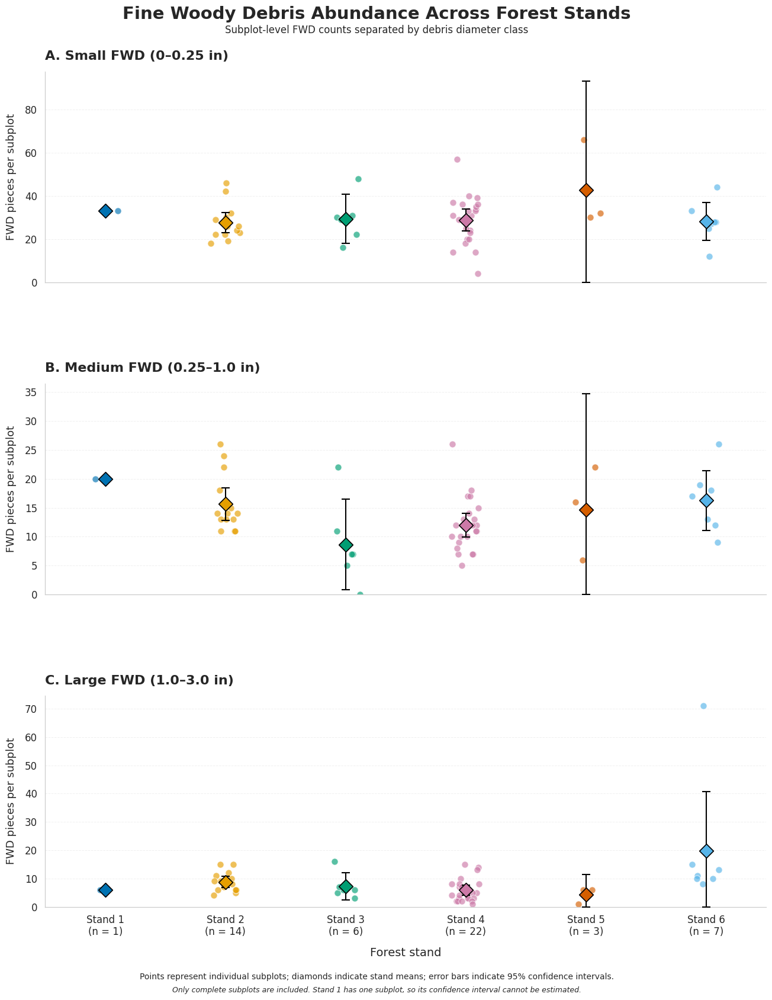

In [201]:
# STEP 184: Create a readable, publication-quality FWD abundance figure.
#
# Three vertically stacked panels:
#   A. Small FWD: 0–0.25 inches
#   B. Medium FWD: 0.25–1.0 inches
#   C. Large FWD: 1.0–3.0 inches
#
# Individual points = subplot observations.
# Diamond markers = stand means.
# Error bars = 95% confidence intervals.
#
# Only complete subplots with all three size classes are included.

# ------------------------------------------------------------
# 1. Import packages
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------------------------------------------
# 2. Define size-class labels in inches only
# ------------------------------------------------------------

size_class_information = {
    1: 'A. Small FWD (0–0.25 in)',
    2: 'B. Medium FWD (0.25–1.0 in)',
    3: 'C. Large FWD (1.0–3.0 in)'
}

stand_order = [1, 2, 3, 4, 5, 6]
size_class_order = [1, 2, 3]

# ------------------------------------------------------------
# 3. Prepare the subplot-level data
# ------------------------------------------------------------

# Convert the complete-subplot dataset into long format.
fwd_long = (
    fwd_complete_subplots[[1, 2, 3]]
    .reset_index()
    .melt(
        id_vars=['Stand ID', 'Plot ID', 'Subplot ID'],
        value_vars=[1, 2, 3],
        var_name='Size Class',
        value_name='FWD Count'
    )
)

# Ensure size-class values are integers.
fwd_long['Size Class'] = fwd_long['Size Class'].astype(int)

# ------------------------------------------------------------
# 4. Calculate stand-level summary statistics
# ------------------------------------------------------------

# Calculate sample size, mean, and standard deviation
# for each stand and size class.
fwd_summary = (
    fwd_long
    .groupby(['Stand ID', 'Size Class'])['FWD Count']
    .agg(
        n='count',
        mean='mean',
        sd='std'
    )
    .reset_index()
)

# Initialize confidence interval columns.
fwd_summary['CI Lower'] = np.nan
fwd_summary['CI Upper'] = np.nan

# Calculate 95% confidence intervals using the t distribution.
for index, row in fwd_summary.iterrows():

    # Retrieve sample size and standard deviation.
    n = int(row['n'])
    sd = row['sd']

    # Confidence intervals require at least two observations.
    if n >= 2 and pd.notna(sd):

        # Calculate the critical t value.
        t_critical = stats.t.ppf(0.975, df=n - 1)

        # Calculate the confidence interval margin.
        margin = t_critical * sd / np.sqrt(n)

        # Store the lower and upper confidence limits.
        fwd_summary.loc[index, 'CI Lower'] = row['mean'] - margin
        fwd_summary.loc[index, 'CI Upper'] = row['mean'] + margin

# ------------------------------------------------------------
# 5. Set publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 16,
    'axes.labelsize': 13,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.linewidth': 0.9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8
})

# ------------------------------------------------------------
# 6. Create the figure
# ------------------------------------------------------------

# Use three large vertically stacked panels.
# A taller figure prevents any panel from being compressed or clipped.
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 17),
    sharex=True
)

# ------------------------------------------------------------
# 7. Plot each size class
# ------------------------------------------------------------

for ax, size_class in zip(axes, size_class_order):

    # Select observations for this size class.
    class_data = fwd_long[
        fwd_long['Size Class'] == size_class
    ]

    # Select summary statistics for this size class.
    class_summary = fwd_summary[
        fwd_summary['Size Class'] == size_class
    ]

    # Plot observations and means for each stand.
    for stand in stand_order:

        # Extract subplot-level counts.
        stand_data = class_data[
            class_data['Stand ID'] == stand
        ]['FWD Count'].dropna().to_numpy()

        # Create reproducible horizontal jitter.
        rng = np.random.default_rng(
            seed=stand * 100 + size_class
        )

        jitter = rng.uniform(
            -0.12,
            0.12,
            size=len(stand_data)
        )

        # Plot individual subplot observations.
        ax.scatter(
            np.full(len(stand_data), stand) + jitter,
            stand_data,
            s=65,
            color=stand_colors[stand],
            alpha=0.65,
            edgecolor='white',
            linewidth=0.8,
            zorder=2
        )

        # Retrieve the stand-level summary.
        summary_row = class_summary[
            class_summary['Stand ID'] == stand
        ]

        if not summary_row.empty:

            # Extract the mean and confidence interval.
            mean_value = summary_row['mean'].iloc[0]
            lower = summary_row['CI Lower'].iloc[0]
            upper = summary_row['CI Upper'].iloc[0]

            # Plot the stand mean as a prominent diamond.
            ax.scatter(
                stand,
                mean_value,
                s=145,
                marker='D',
                color=stand_colors[stand],
                edgecolor='black',
                linewidth=1.2,
                zorder=5
            )

            # Add the 95% confidence interval when estimable.
            if pd.notna(lower) and pd.notna(upper):

                ax.errorbar(
                    stand,
                    mean_value,
                    yerr=[
                        [mean_value - max(0, lower)],
                        [upper - mean_value]
                    ],
                    fmt='none',
                    ecolor='black',
                    elinewidth=1.5,
                    capsize=5,
                    capthick=1.5,
                    zorder=4
                )

    # Add the complete size-class definition directly to the panel.
    # Using the normal axis title avoids the clipping problem caused
    # by manually positioned text above the axes.
    ax.set_title(
        size_class_information[size_class],
        fontsize=16,
        fontweight='bold',
        loc='left',
        pad=14
    )

    # Start the y-axis at zero.
    ax.set_ylim(bottom=0)

    # Label the vertical axis.
    ax.set_ylabel(
        'FWD pieces per subplot',
        labelpad=10
    )

    # Display subtle horizontal gridlines.
    ax.grid(
        axis='y',
        linestyle='--',
        linewidth=0.7,
        alpha=0.30
    )

    # Keep gridlines behind the observations.
    ax.set_axisbelow(True)

    # Remove vertical gridlines.
    ax.grid(axis='x', visible=False)

    # Add horizontal breathing room.
    ax.set_xlim(0.5, 6.5)

# ------------------------------------------------------------
# 8. Format the shared stand axis
# ------------------------------------------------------------

# Put stand labels and sample sizes directly into the bottom axis.
# This avoids separate text annotations being clipped.
sample_sizes = (
    fwd_complete_subplots
    .groupby(level='Stand ID')
    .size()
)

stand_tick_labels = [
    f'Stand {stand}\n(n = {sample_sizes.get(stand, 0)})'
    for stand in stand_order
]

# Apply stand labels to all panels for easy comparison.
for ax in axes:

    ax.set_xticks(stand_order)
    ax.set_xticklabels(stand_tick_labels)

# Label the shared horizontal axis.
axes[-1].set_xlabel(
    'Forest stand',
    fontsize=14,
    labelpad=12
)

# ------------------------------------------------------------
# 9. Add the overall figure title and explanatory note
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Abundance Across Forest Stands',
    fontsize=21,
    fontweight='bold',
    y=0.985
)

fig.text(
    0.5,
    0.958,
    'Subplot-level FWD counts separated by debris diameter class',
    ha='center',
    fontsize=12
)

fig.text(
    0.5,
    0.018,
    'Points represent individual subplots; diamonds indicate stand means; '
    'error bars indicate 95% confidence intervals.',
    ha='center',
    fontsize=10
)

fig.text(
    0.5,
    0.005,
    'Only complete subplots are included. Stand 1 has one subplot, '
    'so its confidence interval cannot be estimated.',
    ha='center',
    fontsize=9,
    style='italic'
)

# ------------------------------------------------------------
# 10. Adjust spacing and export
# ------------------------------------------------------------

# Manually control spacing so all three panels remain visible.
fig.subplots_adjust(
    left=0.10,
    right=0.97,
    top=0.92,
    bottom=0.09,
    hspace=0.48
)

# Save the high-resolution PNG.
fig.savefig(
    export_dir / 'FWD_Abundance_by_Size_Class_Publication.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save the vector PDF.
fig.savefig(
    export_dir / 'FWD_Abundance_by_Size_Class_Publication.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

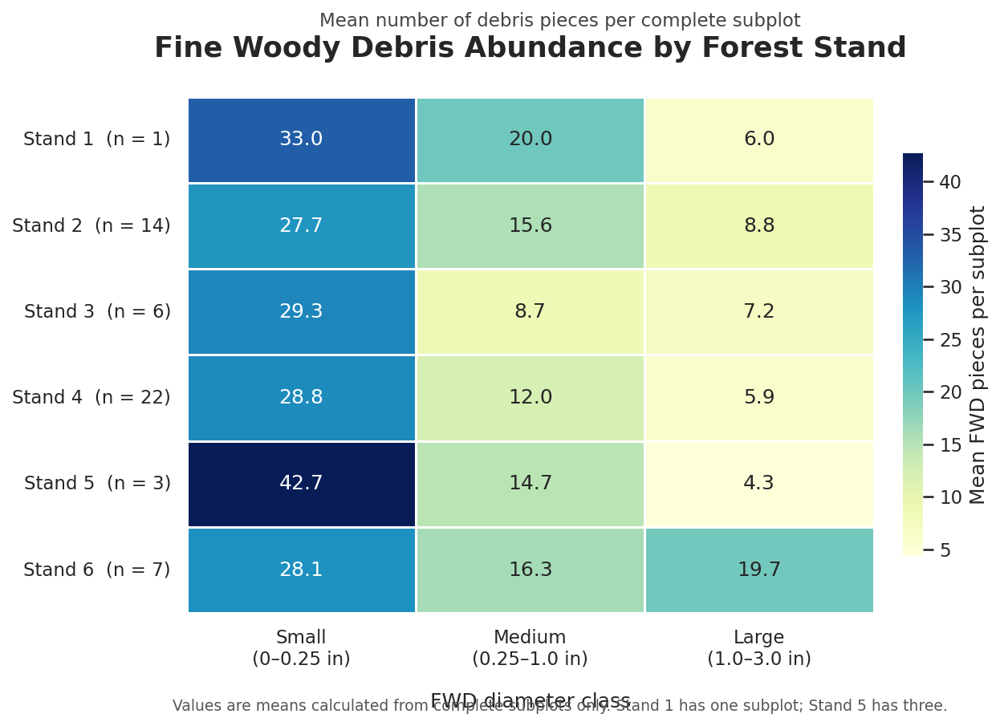

In [202]:
# STEP 185: Create a refined, journal-style FWD abundance heatmap.
#
# Rows represent forest stands.
# Columns represent FWD diameter classes.
# Cell values represent mean FWD pieces per complete subplot.
# Cell shading represents relative abundance.
#
# The heatmap uses mean counts rather than raw totals to account
# for differences in the number of sampled subplots.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize

# ------------------------------------------------------------
# 1. Calculate mean FWD abundance per subplot
# ------------------------------------------------------------

# Calculate the mean count for each size class within each stand.
fwd_heatmap_data = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .mean()
    .reindex([1, 2, 3, 4, 5, 6])
)

# Rename the size-class columns with their diameter ranges.
fwd_heatmap_data.columns = [
    'Small\n(0–0.25 in)',
    'Medium\n(0.25–1.0 in)',
    'Large\n(1.0–3.0 in)'
]

# Calculate the number of complete subplots sampled per stand.
fwd_sample_sizes = (
    fwd_complete_subplots
    .groupby(level='Stand ID')
    .size()
)

# Add sample sizes to the stand labels.
fwd_heatmap_data.index = [
    f'Stand {stand}  (n = {fwd_sample_sizes.loc[stand]})'
    for stand in fwd_heatmap_data.index
]

# ------------------------------------------------------------
# 2. Establish a clean scientific plotting style
# ------------------------------------------------------------

sns.set_theme(style='white', font='DejaVu Sans')

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 17,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.dpi': 150,
    'savefig.dpi': 600
})

# Create a moderately sized figure with balanced proportions.
fig, ax = plt.subplots(figsize=(10, 6.5))

# ------------------------------------------------------------
# 3. Create the heatmap
# ------------------------------------------------------------

# Use a sequential blue-green palette.
# Darker cells represent higher mean FWD abundance.
sns.heatmap(
    fwd_heatmap_data,
    ax=ax,
    cmap='YlGnBu',
    annot=True,
    fmt='.1f',
    annot_kws={
        'fontsize': 12,
        'fontweight': 'medium'
    },
    linewidths=1.2,
    linecolor='white',
    cbar=True,
    cbar_kws={
        'label': 'Mean FWD pieces per subplot',
        'shrink': 0.78,
        'pad': 0.035
    },
    square=False
)

# ------------------------------------------------------------
# 4. Format axes and labels
# ------------------------------------------------------------

# Add a concise title.
ax.set_title(
    'Fine Woody Debris Abundance by Forest Stand',
    fontweight='bold',
    pad=24
)

# Label the axes.
ax.set_xlabel('FWD diameter class', labelpad=14)
ax.set_ylabel('')

# Keep stand labels aligned and readable.
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

# Format column labels.
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0,
    ha='center'
)

# Remove unnecessary axis borders.
for spine in ax.spines.values():
    spine.set_visible(False)

# ------------------------------------------------------------
# 5. Add a short methodological subtitle
# ------------------------------------------------------------

fig.text(
    0.5,
    0.91,
    'Mean number of debris pieces per complete subplot',
    ha='center',
    fontsize=11,
    color='#444444'
)

# Add a concise note beneath the heatmap.
fig.text(
    0.5,
    0.035,
    'Values are means calculated from complete subplots only. '
    'Stand 1 has one subplot; Stand 5 has three.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 6. Adjust layout and export
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.19,
    right=0.89,
    top=0.82,
    bottom=0.16
)

# Export a high-resolution PNG.
fig.savefig(
    export_dir / 'FWD_Abundance_Heatmap_Publication.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Export a vector PDF.
fig.savefig(
    export_dir / 'FWD_Abundance_Heatmap_Publication.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

In [203]:
# STEP 186: Calculate relative FWD abundance by stand and size class.

# ------------------------------------------------------------
# 1. Calculate total counts for each size class within each stand
# ------------------------------------------------------------

# Sum FWD counts across complete subplots for each stand.
fwd_class_totals = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .sum()
    .reindex([1, 2, 3, 4, 5, 6])
)

# ------------------------------------------------------------
# 2. Calculate total FWD abundance within each stand
# ------------------------------------------------------------

# Sum all three size classes to obtain total FWD pieces per stand.
fwd_stand_totals = fwd_class_totals.sum(axis=1)

# ------------------------------------------------------------
# 3. Calculate relative abundance
# ------------------------------------------------------------

# Divide each size-class count by the total FWD count within its stand.
# Multiply by 100 to express relative abundance as a percentage.
fwd_relative_abundance = (
    fwd_class_totals
    .div(fwd_stand_totals, axis=0)
    * 100
)

# ------------------------------------------------------------
# 4. Add descriptive labels
# ------------------------------------------------------------

# Rename columns to identify the diameter classes in inches.
fwd_relative_abundance.columns = [
    'Small (0–0.25 in)',
    'Medium (0.25–1.0 in)',
    'Large (1.0–3.0 in)'
]

# ------------------------------------------------------------
# 5. Display the results
# ------------------------------------------------------------

print("Relative FWD abundance by stand (%):")
display(fwd_relative_abundance.round(2))

print("\nTotal FWD counts by stand (complete subplots):")
display(fwd_stand_totals.rename('Total FWD Pieces').to_frame())

print("\nMean FWD pieces per complete subplot:")
display(
    fwd_complete_subplots
    .groupby(level='Stand ID')['Total FWD']
    .mean()
    .rename('Mean FWD Pieces per Subplot')
    .to_frame()
    .round(2)
)

Relative FWD abundance by stand (%):


,Small (0–0.25 in),Medium (0.25–1.0 in),Large (1.0–3.0 in)
Stand ID,,,
1,55.93,33.90,10.17
2,53.15,30.00,16.85
3,64.94,19.19,15.87
4,61.70,25.73,12.57
5,69.19,23.78,7.03
6,43.88,25.39,30.73



Total FWD counts by stand (complete subplots):


,Total FWD Pieces
Stand ID,
1,59.0
2,730.0
3,271.0
4,1026.0
5,185.0
6,449.0



Mean FWD pieces per complete subplot:


,Mean FWD Pieces per Subplot
Stand ID,
1,59.00
2,52.14
3,45.17
4,46.64
5,61.67
6,64.14


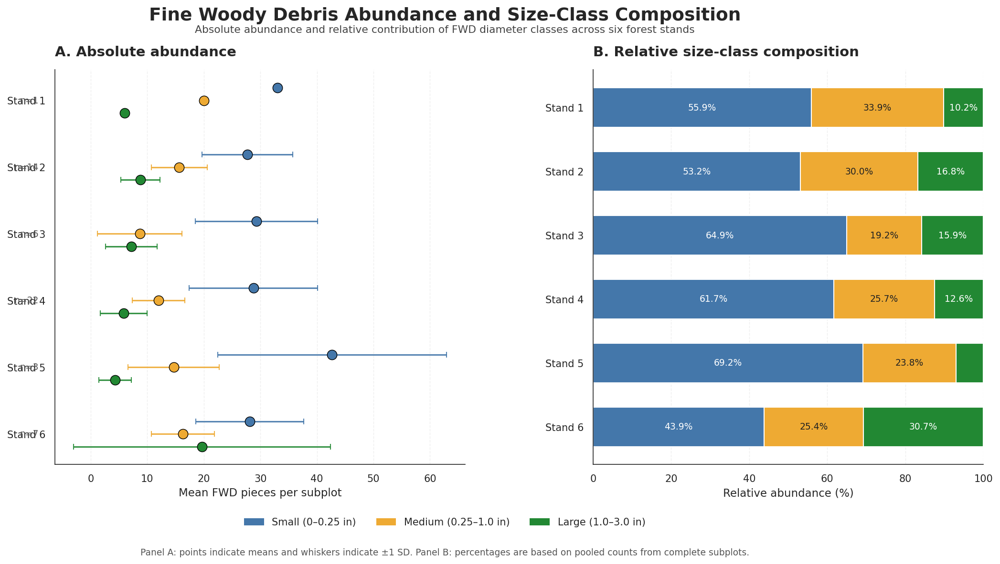

In [204]:
# STEP 187: Create a coordinated publication-quality FWD figure.
#
# Panel A: Mean FWD abundance per complete subplot.
# Panel B: Relative abundance of FWD size classes within each stand.
#
# Diameter classes use consistent colors across both panels.
# The figure distinguishes absolute abundance from relative composition.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define size-class labels and colors
# ------------------------------------------------------------

# Use a restrained, colorblind-friendly palette.
# Keep the same color assigned to each size class in both panels.

size_class_colors = {
    1: '#4477AA',  # Small FWD
    2: '#EEAA33',  # Medium FWD
    3: '#228833'   # Large FWD
}

size_class_labels = {
    1: 'Small (0–0.25 in)',
    2: 'Medium (0.25–1.0 in)',
    3: 'Large (1.0–3.0 in)'
}

stand_order = [1, 2, 3, 4, 5, 6]

# ------------------------------------------------------------
# 2. Calculate absolute abundance summary statistics
# ------------------------------------------------------------

# Calculate mean, standard deviation, and sample size for
# each size class within each stand.
fwd_absolute_summary = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# Calculate the mean and standard deviation of total FWD counts
# across complete subplots within each stand.
fwd_total_summary = (
    fwd_complete_subplots['Total FWD']
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# ------------------------------------------------------------
# 3. Prepare relative abundance data
# ------------------------------------------------------------

# Recalculate relative abundance from complete subplots.
# This ensures both panels use exactly the same sampling units.
fwd_complete_totals = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .sum()
    .reindex(stand_order)
)

# Convert pooled size-class counts to percentages within each stand.
fwd_relative_plot = (
    fwd_complete_totals
    .div(fwd_complete_totals.sum(axis=1), axis=0)
    * 100
)

# ------------------------------------------------------------
# 4. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'savefig.dpi': 600
})

# Create a two-panel figure with balanced proportions.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 8),
    gridspec_kw={'width_ratios': [1.05, 1]}
)

# ------------------------------------------------------------
# 5. PANEL A: Absolute abundance
# ------------------------------------------------------------

# Define vertical positions for each stand.
y_positions = np.arange(len(stand_order))

# Slightly offset the three size classes within each stand.
vertical_offsets = {
    1: -0.19,
    2: 0.00,
    3: 0.19
}

# Plot mean FWD counts for each size class.
for size_class in [1, 2, 3]:

    # Extract mean and standard deviation values.
    means = fwd_absolute_summary[(size_class, 'mean')]
    sds = fwd_absolute_summary[(size_class, 'std')]

    # Plot each stand individually.
    for i, stand in enumerate(stand_order):

        # Calculate the vertical position.
        y = y_positions[i] + vertical_offsets[size_class]

        # Plot the mean as a colored circular marker.
        ax1.scatter(
            means.loc[stand],
            y,
            s=95,
            color=size_class_colors[size_class],
            edgecolor='black',
            linewidth=0.7,
            zorder=3
        )

        # Add standard deviation whiskers when estimable.
        if pd.notna(sds.loc[stand]):

            ax1.errorbar(
                means.loc[stand],
                y,
                xerr=sds.loc[stand],
                fmt='none',
                ecolor=size_class_colors[size_class],
                elinewidth=1.5,
                capsize=3,
                alpha=0.9,
                zorder=2
            )

# Set stand labels.
ax1.set_yticks(y_positions)
ax1.set_yticklabels([f'Stand {s}' for s in stand_order])

# Invert the y-axis so Stand 1 appears at the top.
ax1.invert_yaxis()

# Label the horizontal axis.
ax1.set_xlabel('Mean FWD pieces per subplot')

# Add panel title.
ax1.set_title(
    'A. Absolute abundance',
    loc='left',
    fontweight='bold',
    pad=14
)

# Add subtle vertical gridlines.
ax1.grid(
    axis='x',
    linestyle='--',
    linewidth=0.7,
    alpha=0.3
)

ax1.set_axisbelow(True)

# ------------------------------------------------------------
# 6. PANEL B: Relative abundance
# ------------------------------------------------------------

# Establish the starting position of each stacked bar.
left_positions = np.zeros(len(stand_order))

# Plot each size class as a stacked horizontal segment.
for size_class in [1, 2, 3]:

    # Retrieve the percentage contribution of this size class.
    percentages = (
        fwd_relative_plot[size_class]
        .reindex(stand_order)
        .to_numpy()
    )

    # Plot the stacked bar segments.
    ax2.barh(
        y_positions,
        percentages,
        left=left_positions,
        height=0.62,
        color=size_class_colors[size_class],
        edgecolor='white',
        linewidth=1.0,
        label=size_class_labels[size_class]
    )

    # Add percentage labels inside sufficiently large segments.
    for i, percentage in enumerate(percentages):

        if percentage >= 8:

            # Place the percentage at the center of its segment.
            ax2.text(
                left_positions[i] + percentage / 2,
                y_positions[i],
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                fontweight='medium',
                color='white' if size_class != 2 else '#222222'
            )

    # Update the left position for the next size class.
    left_positions += percentages

# Format the relative abundance axis.
ax2.set_xlim(0, 100)
ax2.set_xticks([0, 20, 40, 60, 80, 100])
ax2.set_xlabel('Relative abundance (%)')

# Add panel title.
ax2.set_title(
    'B. Relative size-class composition',
    loc='left',
    fontweight='bold',
    pad=14
)

# Match the stand ordering used in Panel A.
ax2.set_yticks(y_positions)
ax2.set_yticklabels([f'Stand {s}' for s in stand_order])
ax2.invert_yaxis()

# Add subtle vertical gridlines.
ax2.grid(
    axis='x',
    linestyle='--',
    linewidth=0.7,
    alpha=0.3
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 7. Add sample sizes and shared legend
# ------------------------------------------------------------

# Display the number of complete subplots alongside stand labels.
for i, stand in enumerate(stand_order):

    n = int(fwd_total_summary.loc[stand, 'count'])

    ax1.text(
        -0.04,
        i,
        f'n={n}',
        transform=ax1.get_yaxis_transform(),
        ha='right',
        va='center',
        fontsize=9,
        color='#555555'
    )

# Create a shared legend for the three diameter classes.
legend_handles = [
    Patch(
        facecolor=size_class_colors[size_class],
        edgecolor='none',
        label=size_class_labels[size_class]
    )
    for size_class in [1, 2, 3]
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.045),
    fontsize=10
)

# ------------------------------------------------------------
# 8. Add overall figure title and explanatory notes
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Abundance and Size-Class Composition',
    fontsize=18,
    fontweight='bold',
    y=0.97
)

fig.text(
    0.5,
    0.925,
    'Absolute abundance and relative contribution of FWD diameter classes across six forest stands',
    ha='center',
    fontsize=10.5,
    color='#444444'
)

fig.text(
    0.5,
    0.012,
    'Panel A: points indicate means and whiskers indicate ±1 SD. '
    'Panel B: percentages are based on pooled counts from complete subplots.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 9. Adjust layout and export
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.16,
    right=0.97,
    top=0.86,
    bottom=0.17,
    wspace=0.32
)

# Export the high-resolution PNG.
fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Export the vector PDF.
fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

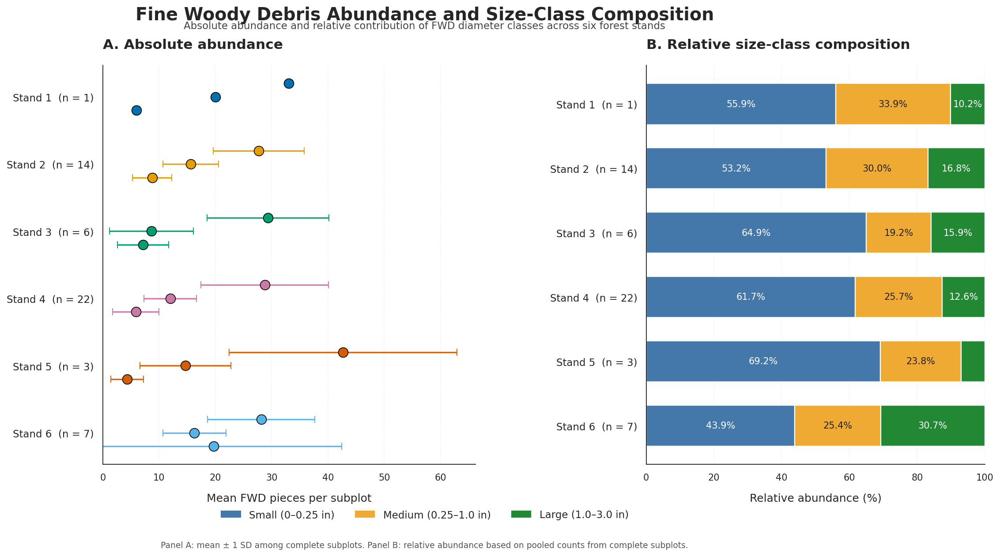

In [205]:
# STEP 188: Publication-style FWD abundance and composition figure.
#
# Panel A: Mean FWD abundance per complete subplot.
# Panel B: Relative abundance of FWD size classes.
#
# Both panels use the original six-stand color palette.
# Stand labels and sample sizes are formatted to prevent overlap.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define the original stand color palette
# ------------------------------------------------------------

# Retain the same stand colors used throughout the project.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9'
}

stand_order = [1, 2, 3, 4, 5, 6]

# ------------------------------------------------------------
# 2. Define size-class labels
# ------------------------------------------------------------

# Use the same restrained size-class distinctions in both panels.
size_class_labels = {
    1: 'Small (0–0.25 in)',
    2: 'Medium (0.25–1.0 in)',
    3: 'Large (1.0–3.0 in)'
}

# Use a neutral palette for the size-class composition panel.
# Stand identity is communicated separately through the y-axis labels.
size_class_colors = {
    1: '#4477AA',
    2: '#EEAA33',
    3: '#228833'
}

# ------------------------------------------------------------
# 3. Calculate absolute abundance statistics
# ------------------------------------------------------------

# Calculate the mean, standard deviation, and sample size
# for each size class within each stand.
fwd_absolute_summary = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# Calculate mean total FWD abundance per complete subplot.
fwd_total_summary = (
    fwd_complete_subplots['Total FWD']
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# ------------------------------------------------------------
# 4. Calculate relative abundance
# ------------------------------------------------------------

# Sum the counts for each size class within each stand.
fwd_class_totals = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .sum()
    .reindex(stand_order)
)

# Calculate the percentage contribution of each size class.
fwd_relative_plot = (
    fwd_class_totals
    .div(fwd_class_totals.sum(axis=1), axis=0)
    * 100
)

# ------------------------------------------------------------
# 5. Set publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9,
    'savefig.dpi': 600
})

# Create a wider figure with additional room for stand labels.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 8.5),
    gridspec_kw={'width_ratios': [1.1, 1]}
)

# ------------------------------------------------------------
# 6. PANEL A: Absolute FWD abundance
# ------------------------------------------------------------

# Define vertical positions for the six stands.
y_positions = np.arange(len(stand_order))

# Offset the three size classes slightly within each stand.
vertical_offsets = {
    1: -0.20,
    2: 0.00,
    3: 0.20
}

# Plot each size class.
for size_class in [1, 2, 3]:

    # Extract the mean and standard deviation for this class.
    means = fwd_absolute_summary[(size_class, 'mean')]
    sds = fwd_absolute_summary[(size_class, 'std')]

    # Plot observations for each stand.
    for i, stand in enumerate(stand_order):

        # Calculate the vertical position.
        y = y_positions[i] + vertical_offsets[size_class]

        # Plot the mean using the original stand color.
        ax1.scatter(
            means.loc[stand],
            y,
            s=110,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=0.8,
            zorder=3
        )

        # Display standard deviation where estimable.
        if pd.notna(sds.loc[stand]):

            ax1.errorbar(
                means.loc[stand],
                y,
                xerr=sds.loc[stand],
                fmt='none',
                ecolor=stand_colors[stand],
                elinewidth=1.6,
                capsize=4,
                alpha=0.95,
                zorder=2
            )

# Set the stand labels on the vertical axis.
ax1.set_yticks(y_positions)

ax1.set_yticklabels(
    [f'Stand {stand}' for stand in stand_order],
    fontsize=11
)

# Display Stand 1 at the top.
ax1.invert_yaxis()

# Label the horizontal axis.
ax1.set_xlabel(
    'Mean FWD pieces per subplot',
    labelpad=12
)

# Add the panel heading.
ax1.set_title(
    'A. Absolute abundance',
    loc='left',
    fontweight='bold',
    pad=18
)

# Add subtle gridlines.
ax1.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax1.set_axisbelow(True)

# Add additional space around the plotted values.
ax1.set_xlim(left=0)

# ------------------------------------------------------------
# 7. PANEL B: Relative FWD abundance
# ------------------------------------------------------------

# Initialize the starting positions of the stacked bars.
left_positions = np.zeros(len(stand_order))

# Plot each size class as a stacked horizontal segment.
for size_class in [1, 2, 3]:

    # Retrieve the percentage values for this size class.
    percentages = (
        fwd_relative_plot[size_class]
        .reindex(stand_order)
        .to_numpy()
    )

    # Plot the horizontal stacked bars.
    ax2.barh(
        y_positions,
        percentages,
        left=left_positions,
        height=0.64,
        color=size_class_colors[size_class],
        edgecolor='white',
        linewidth=1.1,
        label=size_class_labels[size_class]
    )

    # Add percentage labels inside readable segments.
    for i, percentage in enumerate(percentages):

        if percentage >= 8:

            ax2.text(
                left_positions[i] + percentage / 2,
                y_positions[i],
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=10,
                fontweight='medium',
                color='white' if size_class != 2 else '#222222'
            )

    # Update the starting position for the next class.
    left_positions += percentages

# Set percentage-axis limits.
ax2.set_xlim(0, 100)

ax2.set_xticks(
    [0, 20, 40, 60, 80, 100]
)

# Label the horizontal axis.
ax2.set_xlabel(
    'Relative abundance (%)',
    labelpad=12
)

# Add the panel heading.
ax2.set_title(
    'B. Relative size-class composition',
    loc='left',
    fontweight='bold',
    pad=18
)

# Match the stand labels and order from Panel A.
ax2.set_yticks(y_positions)

ax2.set_yticklabels(
    [f'Stand {stand}' for stand in stand_order],
    fontsize=11
)

# Display Stand 1 at the top.
ax2.invert_yaxis()

# Add subtle gridlines.
ax2.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 8. Add sample sizes to stand labels
# ------------------------------------------------------------

# Include sample sizes in both panels, avoiding separate
# annotations that could overlap with the y-axis labels.
sample_sizes = fwd_total_summary['count'].astype(int)

stand_labels_with_n = [
    f'Stand {stand}  (n = {sample_sizes.loc[stand]})'
    for stand in stand_order
]

ax1.set_yticklabels(stand_labels_with_n)
ax2.set_yticklabels(stand_labels_with_n)

# ------------------------------------------------------------
# 9. Create the size-class legend
# ------------------------------------------------------------

# Use a shared legend beneath the two panels.
legend_handles = [
    Patch(
        facecolor=size_class_colors[size_class],
        edgecolor='none',
        label=size_class_labels[size_class]
    )
    for size_class in [1, 2, 3]
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.045),
    fontsize=11
)

# ------------------------------------------------------------
# 10. Add figure title and notes
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Abundance and Size-Class Composition',
    fontsize=19,
    fontweight='bold',
    y=0.975
)

fig.text(
    0.5,
    0.935,
    'Absolute abundance and relative contribution of FWD diameter classes across six forest stands',
    ha='center',
    fontsize=11,
    color='#444444'
)

fig.text(
    0.5,
    0.012,
    'Panel A: mean ± 1 SD among complete subplots. '
    'Panel B: relative abundance based on pooled counts from complete subplots.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 11. Adjust layout and export
# ------------------------------------------------------------

# Increase the left margin so stand labels never overlap.
# Increase spacing between panels for visual separation.
fig.subplots_adjust(
    left=0.23,
    right=0.97,
    top=0.87,
    bottom=0.16,
    wspace=0.48
)

# Save the high-resolution PNG.
fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save the vector PDF.
fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the final figure.
plt.show()

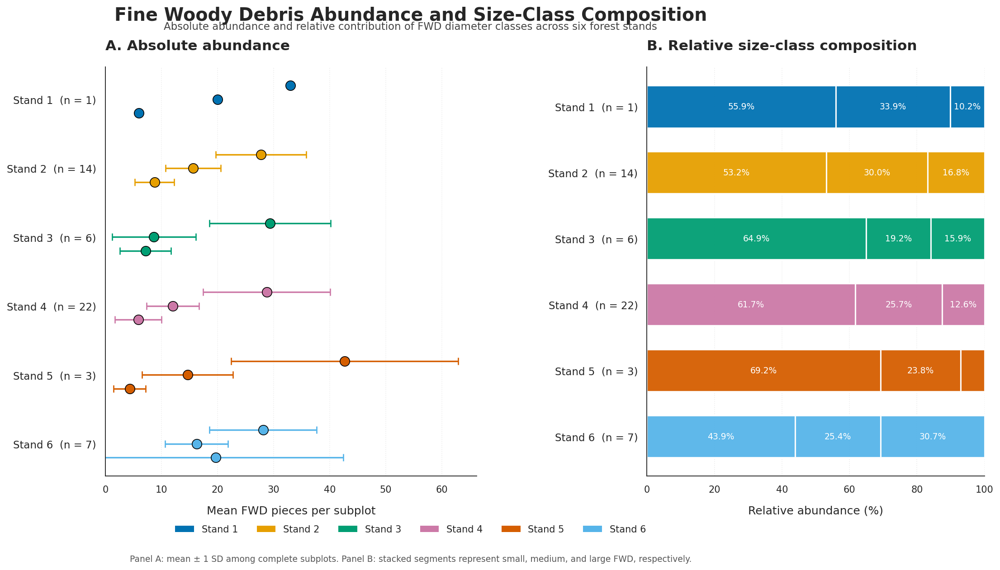

In [206]:
# STEP 189: Create a publication-quality FWD abundance and composition figure.
#
# Panel A: Mean FWD pieces per complete subplot, separated by size class.
# Panel B: Relative abundance of FWD size classes, using the original
#          six-stand color palette.
#
# Both panels use the same stand colors throughout the project.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Green
    4: '#CC79A7',  # Pink
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Define the order of stands and size classes.
stand_order = [1, 2, 3, 4, 5, 6]
size_class_order = [1, 2, 3]

# Define the diameter ranges displayed in the figure.
size_class_labels = {
    1: 'Small (0–0.25 in)',
    2: 'Medium (0.25–1.0 in)',
    3: 'Large (1.0–3.0 in)'
}

# ------------------------------------------------------------
# 2. Calculate absolute abundance statistics
# ------------------------------------------------------------

# Calculate the mean, standard deviation, and sample size
# for each size class within each stand.
fwd_absolute_summary = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# Calculate total FWD abundance per subplot.
# This is used to determine the sample size for each stand.
fwd_total_summary = (
    fwd_complete_subplots['Total FWD']
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# ------------------------------------------------------------
# 3. Calculate relative abundance
# ------------------------------------------------------------

# Sum each size class across complete subplots within each stand.
fwd_class_totals = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .sum()
    .reindex(stand_order)
)

# Calculate the percentage contribution of each size class.
fwd_relative_plot = (
    fwd_class_totals
    .div(fwd_class_totals.sum(axis=1), axis=0)
    * 100
)

# ------------------------------------------------------------
# 4. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9,
    'savefig.dpi': 600
})

# Create the two-panel figure.
# A wider layout provides sufficient room for stand labels.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 8.5),
    gridspec_kw={'width_ratios': [1.1, 1]}
)

# Define the vertical positions for the six stands.
y_positions = np.arange(len(stand_order))

# ------------------------------------------------------------
# 5. PANEL A: Absolute FWD abundance
# ------------------------------------------------------------

# Offset the three size classes slightly within each stand
# so that their mean markers do not overlap.
vertical_offsets = {
    1: -0.20,
    2: 0.00,
    3: 0.20
}

# Plot mean abundance for each size class.
for size_class in size_class_order:

    # Extract the mean and standard deviation for this size class.
    means = fwd_absolute_summary[(size_class, 'mean')]
    sds = fwd_absolute_summary[(size_class, 'std')]

    # Plot each stand using its original stand-specific color.
    for i, stand in enumerate(stand_order):

        # Calculate the vertical position of the mean marker.
        y = y_positions[i] + vertical_offsets[size_class]

        # Plot the mean FWD count.
        ax1.scatter(
            means.loc[stand],
            y,
            s=105,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=0.8,
            zorder=3
        )

        # Add standard deviation whiskers when estimable.
        if pd.notna(sds.loc[stand]):

            ax1.errorbar(
                means.loc[stand],
                y,
                xerr=sds.loc[stand],
                fmt='none',
                ecolor=stand_colors[stand],
                elinewidth=1.6,
                capsize=4,
                capthick=1.3,
                zorder=2
            )

# Format the stand labels.
ax1.set_yticks(y_positions)
ax1.set_yticklabels(
    [f'Stand {s}  (n = {int(fwd_total_summary.loc[s, "count"])})'
     for s in stand_order]
)

# Display Stand 1 at the top.
ax1.invert_yaxis()

# Set the horizontal axis label and panel title.
ax1.set_xlabel('Mean FWD pieces per subplot', labelpad=12)

ax1.set_title(
    'A. Absolute abundance',
    loc='left',
    fontweight='bold',
    pad=18
)

# Use restrained vertical gridlines.
ax1.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax1.set_axisbelow(True)
ax1.set_xlim(left=0)

# ------------------------------------------------------------
# 6. PANEL B: Relative FWD abundance
# ------------------------------------------------------------

# Each stand receives its original stand color.
# The bar length represents the relative abundance of that stand's
# complete-subplot FWD count, rather than a separate size-class color.
for i, stand in enumerate(stand_order):

    # Retrieve the three size-class percentages for this stand.
    percentages = fwd_relative_plot.loc[stand].to_numpy()

    # Draw the stand's stacked bar using its original color.
    # The three segments share the same color, with white boundaries
    # separating the size classes.
    left_position = 0

    for size_class, percentage in zip(size_class_order, percentages):

        ax2.barh(
            y=i,
            width=percentage,
            left=left_position,
            height=0.64,
            color=stand_colors[stand],
            edgecolor='white',
            linewidth=1.5,
            alpha=0.95
        )

        # Add the percentage label within readable segments.
        if percentage >= 8:

            ax2.text(
                left_position + percentage / 2,
                i,
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                fontweight='medium',
                color='white'
            )

        # Advance the starting position for the next segment.
        left_position += percentage

# Format the relative abundance axis.
ax2.set_xlim(0, 100)
ax2.set_xticks([0, 20, 40, 60, 80, 100])
ax2.set_xlabel('Relative abundance (%)', labelpad=12)

# Match the stand labels and order from Panel A.
ax2.set_yticks(y_positions)
ax2.set_yticklabels(
    [f'Stand {s}  (n = {int(fwd_total_summary.loc[s, "count"])})'
     for s in stand_order]
)

ax2.invert_yaxis()

# Add panel title and restrained gridlines.
ax2.set_title(
    'B. Relative size-class composition',
    loc='left',
    fontweight='bold',
    pad=18
)

ax2.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 7. Add a shared legend for the six stands
# ------------------------------------------------------------

# Create legend entries using the original stand colors.
stand_legend_handles = [
    Patch(
        facecolor=stand_colors[stand],
        edgecolor='none',
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

fig.legend(
    handles=stand_legend_handles,
    loc='lower center',
    ncol=6,
    frameon=False,
    bbox_to_anchor=(0.5, 0.045),
    fontsize=10
)

# ------------------------------------------------------------
# 8. Add figure title and explanatory notes
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Abundance and Size-Class Composition',
    fontsize=19,
    fontweight='bold',
    y=0.975
)

fig.text(
    0.5,
    0.935,
    'Absolute abundance and relative contribution of FWD diameter classes across six forest stands',
    ha='center',
    fontsize=11,
    color='#444444'
)

fig.text(
    0.5,
    0.012,
    'Panel A: mean ± 1 SD among complete subplots. '
    'Panel B: stacked segments represent small, medium, and large FWD, respectively.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 9. Adjust layout
# ------------------------------------------------------------

# Provide generous margins to prevent stand labels from overlapping.
fig.subplots_adjust(
    left=0.25,
    right=0.97,
    top=0.87,
    bottom=0.16,
    wspace=0.48
)

# ------------------------------------------------------------
# 10. Export publication-quality files
# ------------------------------------------------------------

# Save a high-resolution PNG.
fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF.
fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

In [207]:
# STEP 190: Inspect the coarse woody debris (CWD) dataset.
#
# This step checks the dataset's dimensions, column names, data types,
# missing values, and the number of observations recorded for each stand.
# We will use these results to determine the appropriate CWD analyses.

# ------------------------------------------------------------
# 1. Display the dataset dimensions
# ------------------------------------------------------------

# Show the number of rows and columns in the CWD dataset.
print("CWD dataset dimensions:")
print(cwd.shape)

# ------------------------------------------------------------
# 2. Display the column names
# ------------------------------------------------------------

# Identify all variables available for the CWD analysis.
print("\nCWD column names:")
print(cwd.columns.tolist())

# ------------------------------------------------------------
# 3. Inspect data types and non-missing observations
# ------------------------------------------------------------

# Show each column's data type and number of non-missing values.
print("\nCWD dataset information:")
cwd.info()

# ------------------------------------------------------------
# 4. Check missing values
# ------------------------------------------------------------

# Count missing observations in each column.
print("\nMissing values by column:")
print(cwd.isnull().sum())

# ------------------------------------------------------------
# 5. Examine the number of observations by stand
# ------------------------------------------------------------

# Display the number of CWD records associated with each stand.
if 'Stand ID' in cwd.columns:

    print("\nCWD observations by stand:")
    print(
        cwd['Stand ID']
        .value_counts(dropna=False)
        .sort_index()
    )

# ------------------------------------------------------------
# 6. Display the first several observations
# ------------------------------------------------------------

# Inspect the actual records to understand how CWD was documented.
print("\nFirst 10 CWD observations:")
display(cwd.head(10))

# ------------------------------------------------------------
# 7. Display numerical summary statistics
# ------------------------------------------------------------

# Summarize numerical columns to identify ranges and potential outliers.
print("\nNumerical summary:")
display(cwd.describe())

CWD dataset dimensions:
(150, 10)

CWD column names:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Log ID', 'CWD Decay Status Code', 'Transect Diameter (in)', 'Notes', 'Unnamed: 9']

CWD dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Stand ID                150 non-null    int64  
 1   Plot ID                 150 non-null    int64  
 2   Subplot ID              150 non-null    int64  
 3   Date                    150 non-null    object 
 4   Team Member(s)          150 non-null    object 
 5   Log ID                  150 non-null    int64  
 6   CWD Decay Status Code   150 non-null    int64  
 7   Transect Diameter (in)  149 non-null    float64
 8   Notes                   16 non-null     object 
 9   Unnamed: 9              0 non-null      float64
dtypes: float64(2), int64(5), ob

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes,Unnamed: 9
0,1,1,1,23-Oct,"LW, JR, JW, JM, LA, EC, AB, HP",1,4,5.70,NaN,NaN
1,2,1,1,23-Oct,"AB, JR, EC, HP",1,4,4.00,NaN,NaN
2,2,1,1,23-Oct,"AB, JR, EC, HP",2,4,3.50,NaN,NaN
3,2,1,1,23-Oct,"AB, JR, EC, HP",3,2,4.25,NaN,NaN
4,2,1,1,23-Oct,"AB, JR, EC, HP",4,2,3.75,NaN,NaN
5,2,1,2,23-Oct,"EC, AB, HP, JR",1,2,4.50,NaN,NaN
6,2,1,2,23-Oct,"EC, AB, HP, JR",2,2,5.40,NaN,NaN
7,2,1,3,23-Oct,"EC, AB, HP, JR",1,4,3.00,NaN,NaN
8,2,1,3,23-Oct,"EC, AB, HP, JR",2,4,3.65,NaN,NaN
9,2,1,3,23-Oct,"EC, AB, HP, JR",3,3,20.80,Not in transect,NaN



Numerical summary:


,Stand ID,Plot ID,Subplot ID,Log ID,CWD Decay Status Code,Transect Diameter (in),Unnamed: 9
count,150.000000,150.000000,150.000000,150.000000,150.000000,149.000000,0.0
mean,3.973333,1.506667,4.333333,3.246667,2.693333,6.080738,NaN
std,1.596753,0.895527,3.278293,3.351723,1.048788,3.231985,NaN
min,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,NaN
25%,3.000000,1.000000,2.000000,1.000000,2.000000,3.710000,NaN
50%,4.000000,1.000000,3.000000,2.000000,3.000000,5.400000,NaN
75%,4.000000,2.000000,6.000000,4.000000,3.000000,7.500000,NaN
max,9.000000,4.000000,13.000000,18.000000,5.000000,25.000000,NaN


In [208]:
# STEP 191: Prepare and inspect the CWD dataset.
#
# This step:
# 1. Restricts the analysis to Stands 1–6.
# 2. Removes empty spreadsheet columns.
# 3. Identifies records marked as outside the transect.
# 4. Identifies missing diameter measurements.
# 5. Examines the distribution of CWD decay-status codes.
#
# We are not permanently deleting any observations from the original
# cwd dataframe. All work is performed on a separate analysis copy.

# ------------------------------------------------------------
# 1. Create an analysis copy for Stands 1–6
# ------------------------------------------------------------

# Keep only observations belonging to the six study stands.
cwd_analysis = cwd[
    cwd['Stand ID'].isin([1, 2, 3, 4, 5, 6])
].copy()

# Remove columns that contain no observations.
# This removes the entirely empty Unnamed: 9 column.
cwd_analysis = cwd_analysis.dropna(axis=1, how='all')

# Display the dimensions after restricting the dataset.
print("CWD analysis dataset dimensions:")
print(cwd_analysis.shape)

# ------------------------------------------------------------
# 2. Identify records marked as outside the transect
# ------------------------------------------------------------

# Search the Notes column for records containing the phrase
# "not in transect", without regard to capitalization.
outside_transect = cwd_analysis[
    cwd_analysis['Notes']
    .fillna('')
    .str.contains('not in transect', case=False)
]

# Display any records identified by this search.
print("\nRecords marked as outside the transect:")
display(outside_transect)

# ------------------------------------------------------------
# 3. Identify missing diameter measurements
# ------------------------------------------------------------

# Find records where Transect Diameter (in) is missing.
missing_cwd_diameter = cwd_analysis[
    cwd_analysis['Transect Diameter (in)'].isna()
]

# Display the records with missing diameter measurements.
print("\nRecords with missing diameter measurements:")
display(missing_cwd_diameter)

# ------------------------------------------------------------
# 4. Examine decay-status code frequencies
# ------------------------------------------------------------

# Count the number of observations assigned to each decay code.
print("\nCWD decay-status code frequencies:")
print(
    cwd_analysis['CWD Decay Status Code']
    .value_counts()
    .sort_index()
)

# Calculate the percentage of observations represented by each code.
print("\nCWD decay-status code percentages:")
print(
    cwd_analysis['CWD Decay Status Code']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# 5. Examine diameter distributions
# ------------------------------------------------------------

# Summarize diameter measurements by stand.
# Missing diameter values are automatically excluded from these statistics.
print("\nCWD diameter summary by stand:")
display(
    cwd_analysis
    .groupby('Stand ID')['Transect Diameter (in)']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

# ------------------------------------------------------------
# 6. Inspect all recorded notes
# ------------------------------------------------------------

# Display unique non-missing notes to identify any additional
# observations that may require special treatment.
print("\nUnique CWD notes:")
print(
    cwd_analysis['Notes']
    .dropna()
    .value_counts()
)

CWD analysis dataset dimensions:
(137, 9)

Records marked as outside the transect:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
9,2,1,3,23-Oct,"EC, AB, HP, JR",3,3,20.8,Not in transect



Records with missing diameter measurements:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
120,5,1,1,30-Oct,"JW, LW, KC, JR",1,2,NaN,NaN



CWD decay-status code frequencies:
CWD Decay Status Code
1    12
2    58
3    33
4    26
5     8
Name: count, dtype: int64

CWD decay-status code percentages:
CWD Decay Status Code
1     8.76
2    42.34
3    24.09
4    18.98
5     5.84
Name: proportion, dtype: float64

CWD diameter summary by stand:


,count,mean,median,std,min,max
Stand ID,,,,,,
1,1,5.70,5.70,NaN,5.70,5.70
2,35,5.53,4.00,3.71,3.00,20.80
3,7,11.57,8.50,6.82,5.00,25.00
4,77,5.89,5.50,2.18,3.00,14.00
5,2,7.40,7.40,5.94,3.20,11.60
6,14,4.97,3.82,2.18,3.11,9.99



Unique CWD notes:
Notes
White birch                                                 4
Downed hemlock                                              1
Estimate, extremly decomposed                               1
Gray birch                                                  1
Not in transect                                             1
Fungi                                                       1
Turkey tail mushroom, honey cap                             1
Covered in moss                                             1
Moss covered & water logged                                 1
Estimated, deacying into ground, cannot wrap tape around    1
Too soft to measure                                         1
Measured half DBH then doubled                              1
Wind blowdown (downed tree DBH = 7.8)                       1
Name: count, dtype: int64


In [209]:
# STEP 192: Remove invalid and incomplete CWD observations.
#
# We will exclude:
# 1. Records explicitly marked as outside the transect.
# 2. Records with missing transect diameter measurements.
#
# The original cwd dataframe remains unchanged.

# ------------------------------------------------------------
# 1. Start with the six-stand analysis dataset
# ------------------------------------------------------------

# Make a copy so that the original dataset is preserved.
cwd_clean = cwd_analysis.copy()

# ------------------------------------------------------------
# 2. Remove records marked as outside the transect
# ------------------------------------------------------------

# Identify notes containing "not in transect".
outside_transect_mask = (
    cwd_clean['Notes']
    .fillna('')
    .str.contains('not in transect', case=False)
)

# Keep only observations that were recorded within the transect.
cwd_clean = cwd_clean.loc[~outside_transect_mask].copy()

# ------------------------------------------------------------
# 3. Remove records with missing diameter measurements
# ------------------------------------------------------------

# Exclude observations without a recorded transect diameter.
cwd_clean = cwd_clean.dropna(
    subset=['Transect Diameter (in)']
).copy()

# ------------------------------------------------------------
# 4. Verify the cleaned dataset
# ------------------------------------------------------------

# Display the number of remaining observations.
print("Cleaned CWD dataset dimensions:")
print(cwd_clean.shape)

# Display the number of observations in each stand.
print("\nCWD observations by stand:")
print(
    cwd_clean['Stand ID']
    .value_counts()
    .sort_index()
)

# Confirm that no diameter measurements are missing.
print("\nMissing diameter measurements:")
print(cwd_clean['Transect Diameter (in)'].isna().sum())

# Confirm that no records marked outside the transect remain.
print("\nRecords marked outside the transect:")
print(
    cwd_clean['Notes']
    .fillna('')
    .str.contains('not in transect', case=False)
    .sum()
)

# Display the cleaned dataset.
display(cwd_clean.head())

Cleaned CWD dataset dimensions:
(135, 9)

CWD observations by stand:
Stand ID
1     1
2    34
3     7
4    77
5     2
6    14
Name: count, dtype: int64

Missing diameter measurements:
0

Records marked outside the transect:
0


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
0,1,1,1,23-Oct,"LW, JR, JW, JM, LA, EC, AB, HP",1,4,5.70,NaN
1,2,1,1,23-Oct,"AB, JR, EC, HP",1,4,4.00,NaN
2,2,1,1,23-Oct,"AB, JR, EC, HP",2,4,3.50,NaN
3,2,1,1,23-Oct,"AB, JR, EC, HP",3,2,4.25,NaN
4,2,1,1,23-Oct,"AB, JR, EC, HP",4,2,3.75,NaN


In [210]:
# STEP 193: Generate descriptive summaries of CWD decay status
# and transect diameter across the six study stands.
#
# This step examines:
# 1. The number of logs in each decay-status class.
# 2. The relative frequency of each decay-status class.
# 3. Diameter distributions within each stand.
# 4. Overall diameter statistics.

# ------------------------------------------------------------
# 1. Count CWD observations by decay-status class and stand
# ------------------------------------------------------------

# Create a contingency table showing the number of logs
# in each decay-status class for every stand.
cwd_decay_counts = pd.crosstab(
    cwd_clean['Stand ID'],
    cwd_clean['CWD Decay Status Code']
).reindex(index=[1, 2, 3, 4, 5, 6], fill_value=0)

# Display the count table.
print("CWD decay-status counts by stand:")
display(cwd_decay_counts)

# ------------------------------------------------------------
# 2. Calculate relative decay-class abundance
# ------------------------------------------------------------

# Calculate the percentage of each decay class within each stand.
# Each stand's percentages will sum to 100%.
cwd_decay_relative = (
    cwd_decay_counts
    .div(cwd_decay_counts.sum(axis=1), axis=0)
    * 100
)

# Round percentages to two decimal places.
cwd_decay_relative = cwd_decay_relative.round(2)

# Display the relative abundance table.
print("\nCWD decay-status relative abundance (%):")
display(cwd_decay_relative)

# ------------------------------------------------------------
# 3. Summarize diameter measurements by stand
# ------------------------------------------------------------

# Calculate sample size, mean, median, standard deviation,
# minimum, quartiles, and maximum diameter for each stand.
cwd_diameter_summary = (
    cwd_clean
    .groupby('Stand ID')['Transect Diameter (in)']
    .describe()
    .reindex([1, 2, 3, 4, 5, 6])
    .round(2)
)

# Display the stand-level diameter summary.
print("\nCWD diameter descriptive statistics (inches):")
display(cwd_diameter_summary)

# ------------------------------------------------------------
# 4. Summarize overall diameter measurements
# ------------------------------------------------------------

# Calculate descriptive statistics across all six stands.
cwd_overall_diameter = (
    cwd_clean['Transect Diameter (in)']
    .describe()
    .round(2)
)

# Display the overall diameter summary.
print("\nOverall CWD diameter statistics (inches):")
display(cwd_overall_diameter)

# ------------------------------------------------------------
# 5. Calculate total logs and mean diameter by stand
# ------------------------------------------------------------

# Create a compact summary table combining log counts
# and average diameter for each stand.
cwd_stand_summary = (
    cwd_clean
    .groupby('Stand ID')
    .agg(
        Log_Count=('Log ID', 'count'),
        Mean_Diameter=('Transect Diameter (in)', 'mean'),
        Median_Diameter=('Transect Diameter (in)', 'median'),
        SD_Diameter=('Transect Diameter (in)', 'std')
    )
    .reindex([1, 2, 3, 4, 5, 6])
    .round(2)
)

# Display the combined summary.
print("\nCWD stand-level summary:")
display(cwd_stand_summary)

CWD decay-status counts by stand:


CWD Decay Status Code,1,2,3,4,5
Stand ID,,,,,
1,0,0,0,1,0
2,1,20,8,4,1
3,1,5,1,0,0
4,8,23,20,20,6
5,0,1,0,0,1
6,2,8,3,1,0



CWD decay-status relative abundance (%):


CWD Decay Status Code,1,2,3,4,5
Stand ID,,,,,
1,0.00,0.00,0.00,100.00,0.00
2,2.94,58.82,23.53,11.76,2.94
3,14.29,71.43,14.29,0.00,0.00
4,10.39,29.87,25.97,25.97,7.79
5,0.00,50.00,0.00,0.00,50.00
6,14.29,57.14,21.43,7.14,0.00



CWD diameter descriptive statistics (inches):


,count,mean,std,min,25%,50%,75%,max
Stand ID,,,,,,,,
1,1.0,5.70,NaN,5.70,5.70,5.70,5.70,5.70
2,34.0,5.08,2.62,3.00,3.42,3.96,5.56,14.12
3,7.0,11.57,6.82,5.00,7.50,8.50,13.75,25.00
4,77.0,5.89,2.18,3.00,4.00,5.50,7.50,14.00
5,2.0,7.40,5.94,3.20,5.30,7.40,9.50,11.60
6,14.0,4.97,2.18,3.11,3.31,3.82,6.55,9.99



Overall CWD diameter statistics (inches):


,Transect Diameter (in)
count,135.00
mean,5.91
std,3.03
min,3.00
25%,3.63
50%,5.10
75%,7.40
max,25.00



CWD stand-level summary:


,Log_Count,Mean_Diameter,Median_Diameter,SD_Diameter
Stand ID,,,,
1,1,5.70,5.70,NaN
2,34,5.08,3.96,2.62
3,7,11.57,8.50,6.82
4,77,5.89,5.50,2.18
5,2,7.40,7.40,5.94
6,14,4.97,3.82,2.18


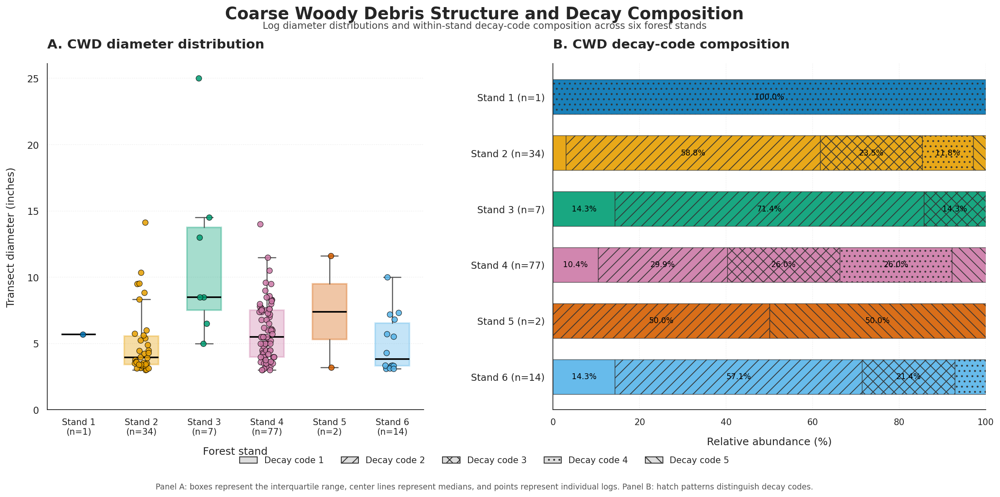

In [211]:
# STEP 194: Visualize CWD diameter distributions and decay composition.
#
# Panel A: Diameter distributions by stand, showing individual logs.
# Panel B: Relative abundance of decay-status codes within each stand.
#
# The original six-stand color palette is retained in both panels.
# Hatch patterns distinguish decay codes without introducing a new
# color palette.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Define the order in which stands and decay codes will appear.
stand_order = [1, 2, 3, 4, 5, 6]
decay_code_order = [1, 2, 3, 4, 5]

# Assign a distinct hatch pattern to each decay code.
# These patterns distinguish the segments while retaining stand colors.
decay_hatches = {
    1: '',
    2: '//',
    3: 'xx',
    4: '..',
    5: '\\\\'
}

# ------------------------------------------------------------
# 2. Set consistent figure formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9
})

# Create the two-panel figure.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(17, 8),
    gridspec_kw={'width_ratios': [1, 1.15]}
)

# ------------------------------------------------------------
# 3. PANEL A: CWD diameter distributions
# ------------------------------------------------------------

# Create a separate diameter distribution for each stand.
diameter_data = [
    cwd_clean.loc[
        cwd_clean['Stand ID'] == stand,
        'Transect Diameter (in)'
    ].dropna().values
    for stand in stand_order
]

# Create boxplots with colored boxes.
boxplot = ax1.boxplot(
    diameter_data,
    positions=np.arange(1, len(stand_order) + 1),
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': 'black',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#555555',
        'linewidth': 1.2
    },
    capprops={
        'color': '#555555',
        'linewidth': 1.2
    }
)

# Apply the original stand color to each box.
for box, stand in zip(boxplot['boxes'], stand_order):
    box.set_facecolor(stand_colors[stand])
    box.set_alpha(0.35)
    box.set_edgecolor(stand_colors[stand])
    box.set_linewidth(1.8)

# Overlay individual log measurements.
# Small horizontal offsets help separate overlapping observations.
rng = np.random.default_rng(42)

for position, stand, values in zip(
    range(1, len(stand_order) + 1),
    stand_order,
    diameter_data
):

    # Generate small random horizontal offsets for visibility.
    jitter = rng.uniform(-0.12, 0.12, size=len(values))

    # Plot individual logs using their stand's original color.
    ax1.scatter(
        position + jitter,
        values,
        s=42,
        color=stand_colors[stand],
        edgecolor='black',
        linewidth=0.55,
        alpha=0.85,
        zorder=3
    )

# Label the x-axis with stand names and sample sizes.
stand_sample_sizes = [
    len(values) for values in diameter_data
]

ax1.set_xticks(range(1, len(stand_order) + 1))

ax1.set_xticklabels([
    f'Stand {stand}\n(n={n})'
    for stand, n in zip(stand_order, stand_sample_sizes)
])

# Add axis labels and panel title.
ax1.set_xlabel('Forest stand', labelpad=12)
ax1.set_ylabel('Transect diameter (inches)', labelpad=12)

ax1.set_title(
    'A. CWD diameter distribution',
    loc='left',
    fontweight='bold',
    pad=18
)

# Add subtle horizontal gridlines.
ax1.grid(
    axis='y',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax1.set_axisbelow(True)
ax1.set_ylim(bottom=0)

# ------------------------------------------------------------
# 4. PANEL B: Relative decay-code composition
# ------------------------------------------------------------

# Calculate the percentage of each decay code within each stand.
# This uses the cleaned dataset and gives each stand its own 100% total.
cwd_decay_counts_plot = (
    cwd_clean
    .groupby(['Stand ID', 'CWD Decay Status Code'])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=stand_order,
        columns=decay_code_order,
        fill_value=0
    )
)

# Convert counts to percentages within each stand.
cwd_decay_relative_plot = (
    cwd_decay_counts_plot
    .div(cwd_decay_counts_plot.sum(axis=1), axis=0)
    * 100
)

# Draw one horizontal stacked bar for each stand.
for y_position, stand in enumerate(stand_order):

    # Start the first decay segment at zero.
    left_position = 0

    # Add the five decay-code segments.
    for decay_code in decay_code_order:

        # Retrieve the percentage represented by this decay code.
        percentage = cwd_decay_relative_plot.loc[
            stand, decay_code
        ]

        # Draw the segment using the stand's original color.
        # Hatch patterns distinguish the decay codes.
        ax2.barh(
            y=y_position,
            width=percentage,
            left=left_position,
            height=0.62,
            color=stand_colors[stand],
            edgecolor='#333333',
            linewidth=0.65,
            hatch=decay_hatches[decay_code],
            alpha=0.9
        )

        # Add percentage labels to sufficiently large segments.
        if percentage >= 10:

            ax2.text(
                left_position + percentage / 2,
                y_position,
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                color='black',
                fontweight='medium'
            )

        # Move the starting position for the next segment.
        left_position += percentage

# Format the horizontal axis.
ax2.set_xlim(0, 100)
ax2.set_xticks([0, 20, 40, 60, 80, 100])
ax2.set_xlabel('Relative abundance (%)', labelpad=12)

# Add stand labels and sample sizes.
ax2.set_yticks(range(len(stand_order)))

ax2.set_yticklabels([
    f'Stand {stand} (n={int(cwd_decay_counts_plot.loc[stand].sum())})'
    for stand in stand_order
])

# Keep the stand order consistent with Panel A.
ax2.invert_yaxis()

# Add the panel title.
ax2.set_title(
    'B. CWD decay-code composition',
    loc='left',
    fontweight='bold',
    pad=18
)

# Add subtle vertical gridlines.
ax2.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 5. Create a legend for decay-code hatch patterns
# ------------------------------------------------------------

# Use neutral gray legend patches so that the legend explains
# hatch patterns without introducing another color palette.
decay_legend_handles = [
    Patch(
        facecolor='#DDDDDD',
        edgecolor='#333333',
        hatch=decay_hatches[code],
        label=f'Decay code {code}'
    )
    for code in decay_code_order
]

fig.legend(
    handles=decay_legend_handles,
    loc='lower center',
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.045),
    fontsize=10
)

# ------------------------------------------------------------
# 6. Add the overall figure title and explanatory note
# ------------------------------------------------------------

fig.suptitle(
    'Coarse Woody Debris Structure and Decay Composition',
    fontsize=19,
    fontweight='bold',
    y=0.975
)

fig.text(
    0.5,
    0.93,
    'Log diameter distributions and within-stand decay-code composition across six forest stands',
    ha='center',
    fontsize=11,
    color='#444444'
)

fig.text(
    0.5,
    0.012,
    'Panel A: boxes represent the interquartile range, center lines represent medians, '
    'and points represent individual logs. Panel B: hatch patterns distinguish decay codes.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 7. Adjust spacing and export
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.86,
    bottom=0.17,
    wspace=0.32
)

# Save the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'CWD_Diameter_and_Decay_Composition.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF for reports and presentations.
fig.savefig(
    export_dir / 'CWD_Diameter_and_Decay_Composition.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

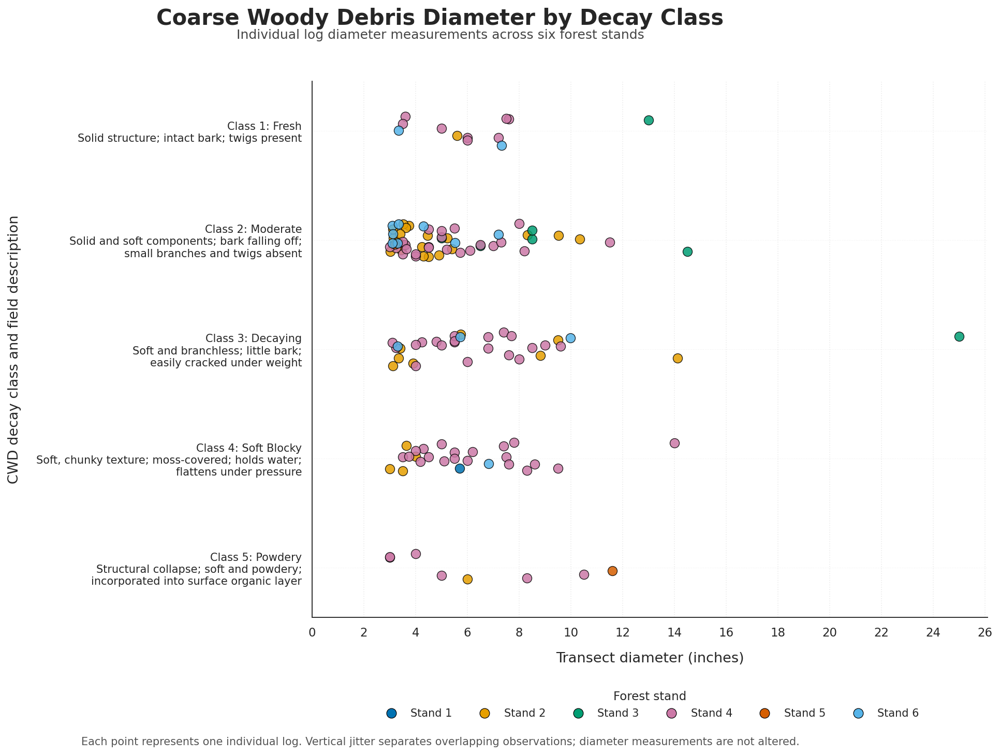

In [213]:
# STEP 196: Visualize individual CWD log diameters by decay class.
#
# Each point represents one individual CWD log.
# The x-axis represents measured transect diameter in inches.
# The y-axis represents the five categorical decay classes.
# Point color represents forest stand, using the original six-stand palette.
#
# A small amount of vertical jitter separates overlapping observations
# without changing the actual diameter measurements.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Define the order of the six stands.
stand_order = [1, 2, 3, 4, 5, 6]

# ------------------------------------------------------------
# 2. Define descriptive CWD decay-class labels
# ------------------------------------------------------------

# These descriptions follow the field definitions in your workbook.
# Each label includes the decay-class name and its identifying characteristics.

decay_class_labels = {
    1: 'Class 1: Fresh\nSolid structure; intact bark; twigs present',
    2: 'Class 2: Moderate\nSolid and soft components; bark falling off;\nsmall branches and twigs absent',
    3: 'Class 3: Decaying\nSoft and branchless; little bark;\neasily cracked under weight',
    4: 'Class 4: Soft Blocky\nSoft, chunky texture; moss-covered; holds water;\nflattens under pressure',
    5: 'Class 5: Powdery\nStructural collapse; soft and powdery;\nincorporated into surface organic layer'
}

# Define the numerical order of the decay classes.
decay_class_order = [1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 3. Prepare the plotting dataframe
# ------------------------------------------------------------

# Create a separate copy of the cleaned CWD dataset.
# This preserves the original cleaned dataframe.
cwd_plot_df = cwd_clean.copy()

# Ensure that decay-status codes are treated as integers.
cwd_plot_df['CWD Decay Status Code'] = (
    cwd_plot_df['CWD Decay Status Code'].astype(int)
)

# Keep only records with valid decay codes and diameter measurements.
cwd_plot_df = cwd_plot_df[
    cwd_plot_df['CWD Decay Status Code'].isin(decay_class_order)
    & cwd_plot_df['Transect Diameter (in)'].notna()
].copy()

# ------------------------------------------------------------
# 4. Calculate vertical jitter positions
# ------------------------------------------------------------

# Set a random generator with a fixed seed.
# This ensures that the point positions remain consistent
# each time the figure is generated.
rng = np.random.default_rng(42)

# Create a numerical y-position for each decay class.
cwd_plot_df['Decay Plot Position'] = (
    cwd_plot_df['CWD Decay Status Code'].astype(float)
)

# Add slight vertical jitter to separate overlapping observations.
# The original decay codes remain unchanged in the dataset.
cwd_plot_df['Decay Plot Position'] += rng.uniform(
    -0.16,
    0.16,
    size=len(cwd_plot_df)
)

# ------------------------------------------------------------
# 5. Establish publication-quality figure formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 17,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9
})

# Create the figure and axis.
fig, ax = plt.subplots(
    figsize=(15, 10)
)

# ------------------------------------------------------------
# 6. Plot individual CWD observations
# ------------------------------------------------------------

# Plot each stand separately so that every stand retains
# its original color throughout the project.
for stand in stand_order:

    # Select observations belonging to the current stand.
    stand_data = cwd_plot_df[
        cwd_plot_df['Stand ID'] == stand
    ]

    # Plot individual log diameters against their decay classes.
    ax.scatter(
        stand_data['Transect Diameter (in)'],
        stand_data['Decay Plot Position'],
        s=75,
        color=stand_colors[stand],
        edgecolor='black',
        linewidth=0.65,
        alpha=0.85,
        zorder=3,
        label=f'Stand {stand}'
    )

# ------------------------------------------------------------
# 7. Format the y-axis with descriptive decay-class labels
# ------------------------------------------------------------

# Position the five decay classes in their correct numerical order.
ax.set_yticks(decay_class_order)

# Replace numerical codes with the descriptive field definitions.
ax.set_yticklabels([
    decay_class_labels[code]
    for code in decay_class_order
])

# Reverse the y-axis so that Fresh appears at the top
# and Powdery appears at the bottom.
ax.invert_yaxis()

# Add a small amount of space above and below the categories.
ax.set_ylim(5.45, 0.55)

# ------------------------------------------------------------
# 8. Format the x-axis
# ------------------------------------------------------------

# Label the diameter axis.
ax.set_xlabel(
    'Transect diameter (inches)',
    labelpad=12
)

# Begin the diameter axis at zero.
ax.set_xlim(left=0)

# Use consistent, readable diameter tick intervals.
ax.set_xticks(np.arange(0, 27, 2))

# ------------------------------------------------------------
# 9. Add axis title and figure title
# ------------------------------------------------------------

# Label the decay-class axis.
ax.set_ylabel(
    'CWD decay class and field description',
    labelpad=14
)

# Add the main figure title.
fig.suptitle(
    'Coarse Woody Debris Diameter by Decay Class',
    fontsize=20,
    fontweight='bold',
    y=0.975
)

# Add a subtitle explaining the observations.
fig.text(
    0.5,
    0.935,
    'Individual log diameter measurements across six forest stands',
    ha='center',
    fontsize=12,
    color='#444444'
)

# ------------------------------------------------------------
# 10. Add gridlines
# ------------------------------------------------------------

# Use subtle vertical gridlines to help compare diameters.
ax.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

# Add faint horizontal reference lines between decay classes.
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.6,
    alpha=0.25
)

# Ensure that gridlines remain behind the observations.
ax.set_axisbelow(True)

# ------------------------------------------------------------
# 11. Create the stand-color legend
# ------------------------------------------------------------

# Create custom legend markers using the original stand colors.
stand_legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor=stand_colors[stand],
        markeredgecolor='black',
        markeredgewidth=0.6,
        markersize=9,
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

# Position the legend below the plotting area.
ax.legend(
    handles=stand_legend_handles,
    title='Forest stand',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=6,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

# ------------------------------------------------------------
# 12. Add explanatory figure note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.025,
    'Each point represents one individual log. '
    'Vertical jitter separates overlapping observations; '
    'diameter measurements are not altered.',
    ha='center',
    fontsize=10,
    color='#555555'
)

# ------------------------------------------------------------
# 13. Adjust layout
# ------------------------------------------------------------

# Provide additional left margin for the descriptive y-axis labels.
fig.subplots_adjust(
    left=0.39,
    right=0.97,
    top=0.88,
    bottom=0.19
)

# ------------------------------------------------------------
# 14. Export the figure
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF for publication-quality output.
fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

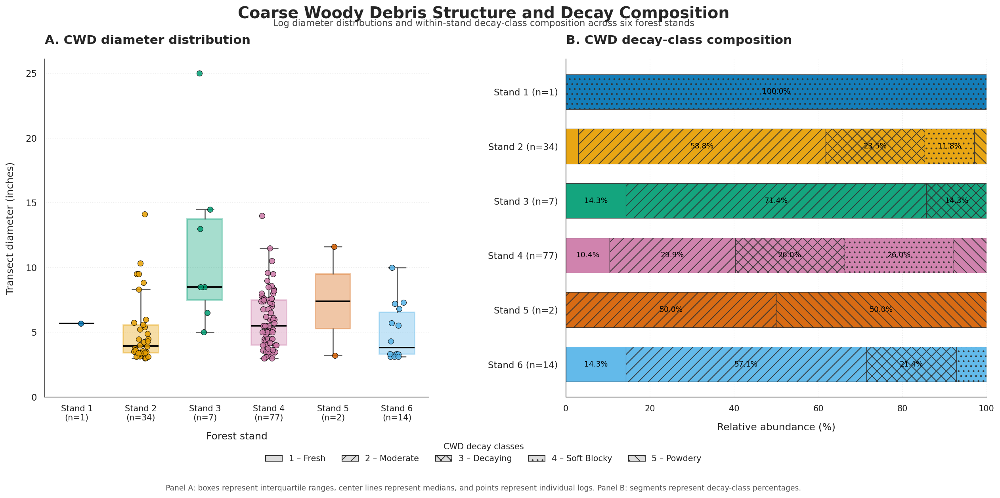

In [214]:
# STEP 197: Create the revised CWD structure and decay composition figure.
#
# Panel A: Individual CWD diameter measurements and boxplots by stand.
# Panel B: Relative abundance of decay-status codes within each stand.
#
# Color represents forest stand throughout both panels.
# Hatch patterns distinguish decay-status codes in Panel B.
# A compact abbreviation key identifies the five decay classes.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

stand_order = [1, 2, 3, 4, 5, 6]
decay_code_order = [1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 2. Define decay-class abbreviations and hatch patterns
# ------------------------------------------------------------

# These short labels will appear in the legend.
decay_abbreviations = {
    1: 'Fresh',
    2: 'Moderate',
    3: 'Decaying',
    4: 'Soft Blocky',
    5: 'Powdery'
}

# Hatch patterns distinguish the decay classes in Panel B.
decay_hatches = {
    1: '',
    2: '//',
    3: 'xx',
    4: '..',
    5: '\\\\'
}

# ------------------------------------------------------------
# 3. Calculate decay-class counts and relative abundance
# ------------------------------------------------------------

# Count observations for each decay code within each stand.
cwd_decay_counts_plot = (
    cwd_clean
    .groupby(['Stand ID', 'CWD Decay Status Code'])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=stand_order,
        columns=decay_code_order,
        fill_value=0
    )
)

# Convert counts to percentages within each stand.
# Each stand's stacked bar will sum to 100%.
cwd_decay_relative_plot = (
    cwd_decay_counts_plot
    .div(cwd_decay_counts_plot.sum(axis=1), axis=0)
    * 100
)

# ------------------------------------------------------------
# 4. Establish figure formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9
})

# Create the two-panel figure.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 8.5),
    gridspec_kw={'width_ratios': [1.05, 1.15]}
)

# ------------------------------------------------------------
# 5. PANEL A: CWD diameter distributions by stand
# ------------------------------------------------------------

# Extract diameter measurements separately for each stand.
diameter_data = [
    cwd_clean.loc[
        cwd_clean['Stand ID'] == stand,
        'Transect Diameter (in)'
    ].dropna().values
    for stand in stand_order
]

# Create boxplots showing the median and interquartile range.
boxplot = ax1.boxplot(
    diameter_data,
    positions=np.arange(1, len(stand_order) + 1),
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': 'black',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#555555',
        'linewidth': 1.2
    },
    capprops={
        'color': '#555555',
        'linewidth': 1.2
    }
)

# Apply the original stand color to each box.
for box, stand in zip(boxplot['boxes'], stand_order):

    box.set_facecolor(stand_colors[stand])
    box.set_alpha(0.35)
    box.set_edgecolor(stand_colors[stand])
    box.set_linewidth(1.8)

# Create a reproducible random generator for point jitter.
rng = np.random.default_rng(42)

# Overlay individual log measurements.
for position, stand, values in zip(
    range(1, len(stand_order) + 1),
    stand_order,
    diameter_data
):

    # Add small horizontal offsets to separate overlapping points.
    jitter = rng.uniform(-0.12, 0.12, size=len(values))

    # Plot each individual log using its stand color.
    ax1.scatter(
        position + jitter,
        values,
        s=45,
        color=stand_colors[stand],
        edgecolor='black',
        linewidth=0.55,
        alpha=0.85,
        zorder=3
    )

# Add stand labels and sample sizes to the x-axis.
ax1.set_xticks(range(1, len(stand_order) + 1))

ax1.set_xticklabels([
    f'Stand {stand}\n(n={len(values)})'
    for stand, values in zip(stand_order, diameter_data)
])

# Add axis labels and panel title.
ax1.set_xlabel('Forest stand', labelpad=12)
ax1.set_ylabel('Transect diameter (inches)', labelpad=12)

ax1.set_title(
    'A. CWD diameter distribution',
    loc='left',
    fontweight='bold',
    pad=18
)

# Add subtle horizontal gridlines.
ax1.grid(
    axis='y',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax1.set_axisbelow(True)
ax1.set_ylim(bottom=0)

# ------------------------------------------------------------
# 6. PANEL B: Relative decay-class composition
# ------------------------------------------------------------

# Create one horizontal stacked bar for each stand.
for y_position, stand in enumerate(stand_order):

    # Start the first segment at zero.
    left_position = 0

    # Add one segment for each decay code.
    for decay_code in decay_code_order:

        # Retrieve the percentage of this decay code.
        percentage = cwd_decay_relative_plot.loc[
            stand, decay_code
        ]

        # Draw the segment using the stand's original color.
        # Hatch patterns identify the decay class.
        ax2.barh(
            y=y_position,
            width=percentage,
            left=left_position,
            height=0.64,
            color=stand_colors[stand],
            edgecolor='#333333',
            linewidth=0.55,
            hatch=decay_hatches[decay_code],
            alpha=0.92
        )

        # Add percentage labels to segments large enough to read.
        if percentage >= 10:

            ax2.text(
                left_position + percentage / 2,
                y_position,
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                color='black',
                fontweight='medium'
            )

        # Advance the position for the next segment.
        left_position += percentage

# Format the relative-abundance axis.
ax2.set_xlim(0, 100)
ax2.set_xticks([0, 20, 40, 60, 80, 100])
ax2.set_xlabel('Relative abundance (%)', labelpad=12)

# Add stand labels and sample sizes.
ax2.set_yticks(range(len(stand_order)))

ax2.set_yticklabels([
    f'Stand {stand} (n={int(cwd_decay_counts_plot.loc[stand].sum())})'
    for stand in stand_order
])

# Match the stand ordering in Panel A.
ax2.invert_yaxis()

# Add the second panel title.
ax2.set_title(
    'B. CWD decay-class composition',
    loc='left',
    fontweight='bold',
    pad=18
)

# Add subtle vertical gridlines.
ax2.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 7. Create the abbreviated decay-class legend
# ------------------------------------------------------------

# Use neutral gray patches so that hatch patterns identify
# decay classes without introducing additional colors.
decay_legend_handles = [
    Patch(
        facecolor='#DDDDDD',
        edgecolor='#333333',
        hatch=decay_hatches[code],
        label=f'{code} – {decay_abbreviations[code]}'
    )
    for code in decay_code_order
]

# Place the decay-class legend beneath the two panels.
fig.legend(
    handles=decay_legend_handles,
    title='CWD decay classes',
    loc='lower center',
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.055),
    fontsize=10,
    title_fontsize=10
)

# ------------------------------------------------------------
# 8. Add figure title and explanatory notes
# ------------------------------------------------------------

fig.suptitle(
    'Coarse Woody Debris Structure and Decay Composition',
    fontsize=19,
    fontweight='bold',
    y=0.975
)

fig.text(
    0.5,
    0.935,
    'Log diameter distributions and within-stand decay-class composition across six forest stands',
    ha='center',
    fontsize=11,
    color='#444444'
)

fig.text(
    0.5,
    0.015,
    'Panel A: boxes represent interquartile ranges, center lines represent medians, '
    'and points represent individual logs. Panel B: segments represent decay-class percentages.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 9. Adjust spacing
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.87,
    bottom=0.20,
    wspace=0.34
)

# ------------------------------------------------------------
# 10. Export the revised figure
# ------------------------------------------------------------

# Save the figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'CWD_Structure_and_Decay_Composition_Final.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF.
fig.savefig(
    export_dir / 'CWD_Structure_and_Decay_Composition_Final.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

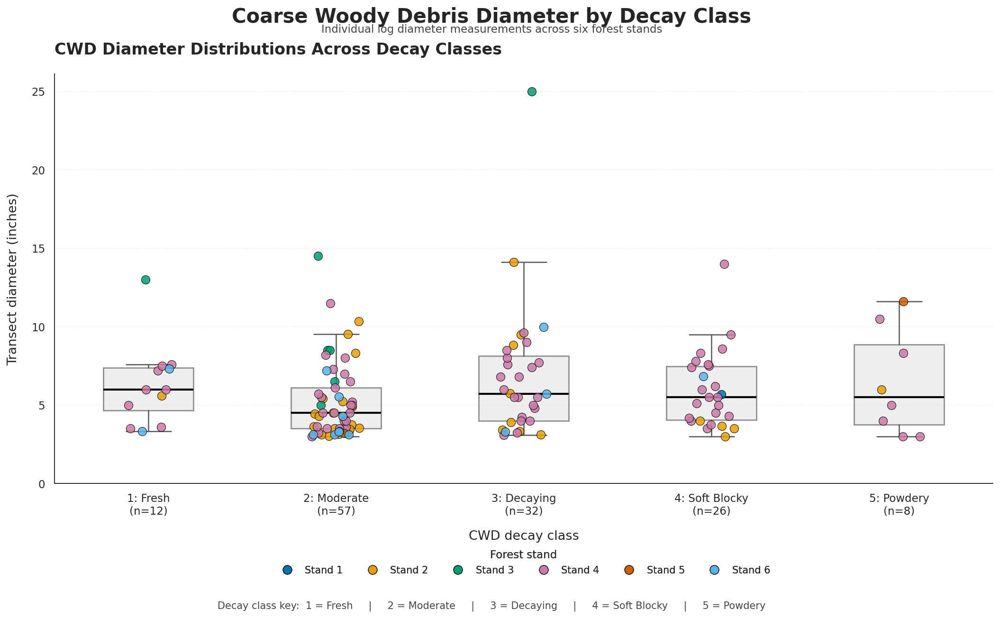

In [215]:
# STEP 198: Visualize CWD diameter distributions across decay classes.
#
# This figure examines whether log diameter varies among decay classes.
# Individual points identify the stand associated with each log.
# Boxplots summarize the diameter distribution within each decay class.
#
# The original six-stand color palette is retained.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

stand_order = [1, 2, 3, 4, 5, 6]
decay_code_order = [1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 2. Define abbreviated decay-class labels
# ------------------------------------------------------------

# These labels correspond to the decay classifications
# in the CWD field key.
decay_abbreviations = {
    1: 'Fresh',
    2: 'Moderate',
    3: 'Decaying',
    4: 'Soft Blocky',
    5: 'Powdery'
}

# ------------------------------------------------------------
# 3. Prepare the plotting data
# ------------------------------------------------------------

# Make a separate copy of the cleaned CWD dataset.
cwd_diameter_decay = cwd_clean.copy()

# Keep only valid decay classes and diameter observations.
cwd_diameter_decay = cwd_diameter_decay[
    cwd_diameter_decay['CWD Decay Status Code'].isin(decay_code_order)
    & cwd_diameter_decay['Transect Diameter (in)'].notna()
].copy()

# Convert decay codes to integers for consistent ordering.
cwd_diameter_decay['CWD Decay Status Code'] = (
    cwd_diameter_decay['CWD Decay Status Code'].astype(int)
)

# ------------------------------------------------------------
# 4. Calculate diameter distributions for each decay class
# ------------------------------------------------------------

# Extract the diameter measurements for each decay class.
diameter_by_decay = [
    cwd_diameter_decay.loc[
        cwd_diameter_decay['CWD Decay Status Code'] == code,
        'Transect Diameter (in)'
    ].values
    for code in decay_code_order
]

# Calculate the number of observations in each decay class.
decay_sample_sizes = [
    len(values) for values in diameter_by_decay
]

# ------------------------------------------------------------
# 5. Establish figure formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 16,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9
})

# Create the figure and plotting axis.
fig, ax = plt.subplots(figsize=(15, 9))

# ------------------------------------------------------------
# 6. Plot boxplots for each decay class
# ------------------------------------------------------------

# Draw boxplots showing the median and interquartile range.
# Individual observations will be overlaid in the next section.
boxplot = ax.boxplot(
    diameter_by_decay,
    positions=decay_code_order,
    widths=0.48,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': 'black',
        'linewidth': 2
    },
    whiskerprops={
        'color': '#555555',
        'linewidth': 1.2
    },
    capprops={
        'color': '#555555',
        'linewidth': 1.2
    }
)

# Use neutral box fills so that stand colors remain the primary
# visual encoding for individual observations.
for box in boxplot['boxes']:
    box.set_facecolor('#E5E5E5')
    box.set_edgecolor('#555555')
    box.set_alpha(0.65)
    box.set_linewidth(1.3)

# ------------------------------------------------------------
# 7. Overlay individual log measurements
# ------------------------------------------------------------

# Use a fixed random seed so that jitter positions are reproducible.
rng = np.random.default_rng(42)

# Plot every log, grouped by decay class and colored by stand.
for code in decay_code_order:

    # Select observations belonging to this decay class.
    class_data = cwd_diameter_decay[
        cwd_diameter_decay['CWD Decay Status Code'] == code
    ]

    # Apply small horizontal jitter to separate overlapping points.
    jitter = rng.uniform(
        -0.13,
        0.13,
        size=len(class_data)
    )

    # Plot the individual observations.
    for stand in stand_order:

        # Select observations for the current stand and decay class.
        stand_data = class_data[
            class_data['Stand ID'] == stand
        ]

        # Plot diameter measurements using the original stand color.
        ax.scatter(
            np.full(len(stand_data), code)
            + jitter[class_data.index.get_indexer(stand_data.index)],
            stand_data['Transect Diameter (in)'],
            s=75,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=0.55,
            alpha=0.85,
            zorder=3
        )

# ------------------------------------------------------------
# 8. Format the decay-class axis
# ------------------------------------------------------------

# Position decay classes in their numerical order.
ax.set_xticks(decay_code_order)

# Use abbreviated decay-class names and sample sizes.
ax.set_xticklabels([
    f'{code}: {decay_abbreviations[code]}\n(n={n})'
    for code, n in zip(decay_code_order, decay_sample_sizes)
])

ax.set_xlabel(
    'CWD decay class',
    labelpad=14
)

ax.set_ylabel(
    'Transect diameter (inches)',
    labelpad=12
)

# Begin the diameter axis at zero.
ax.set_ylim(bottom=0)

# ------------------------------------------------------------
# 9. Add title and gridlines
# ------------------------------------------------------------

ax.set_title(
    'CWD Diameter Distributions Across Decay Classes',
    loc='left',
    fontweight='bold',
    pad=20
)

# Add subtle horizontal gridlines.
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# 10. Create the stand-color legend
# ------------------------------------------------------------

# Create one legend entry for each stand.
stand_legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor=stand_colors[stand],
        markeredgecolor='black',
        markeredgewidth=0.6,
        markersize=9,
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

# Add the stand legend beneath the plot.
stand_legend = ax.legend(
    handles=stand_legend_handles,
    title='Forest stand',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.14),
    ncol=6,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

ax.add_artist(stand_legend)

# ------------------------------------------------------------
# 11. Add a compact decay-class abbreviation key
# ------------------------------------------------------------

# Create a simple text key identifying the decay classes.
decay_key_text = (
    'Decay class key:  '
    '1 = Fresh     |     '
    '2 = Moderate     |     '
    '3 = Decaying     |     '
    '4 = Soft Blocky     |     '
    '5 = Powdery'
)

fig.text(
    0.5,
    0.035,
    decay_key_text,
    ha='center',
    fontsize=10,
    color='#444444'
)

# ------------------------------------------------------------
# 12. Add figure subtitle and explanatory note
# ------------------------------------------------------------

fig.suptitle(
    'Coarse Woody Debris Diameter by Decay Class',
    fontsize=20,
    fontweight='bold',
    y=0.975
)

fig.text(
    0.5,
    0.935,
    'Individual log diameter measurements across six forest stands',
    ha='center',
    fontsize=11,
    color='#444444'
)

# ------------------------------------------------------------
# 13. Adjust layout
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.87,
    bottom=0.23
)

# ------------------------------------------------------------
# 14. Export the figure
# ------------------------------------------------------------

# Save a high-resolution PNG.
fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class_Final.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF.
fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class_Final.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()

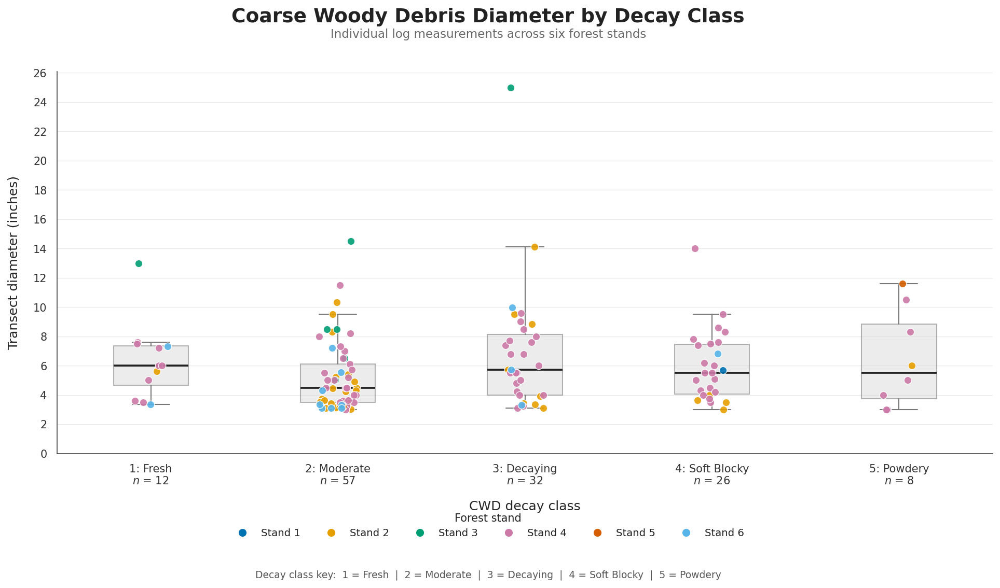

In [216]:

# STEP 199: Refine the CWD diameter-by-decay-class figure.
#
# Each point represents one individual CWD log.
# The x-axis represents decay class.
# The y-axis represents measured transect diameter.
# Point color identifies the forest stand.
# Boxplots summarize the median and interquartile range.
#
# This revision focuses on publication-quality formatting:
# - One clear figure title.
# - Restrained typography and lighter gridlines.
# - Narrower, more transparent boxplots.
# - Smaller individual points with clear outlines.
# - Improved spacing and a complete stand legend.
# - Sample sizes retained beneath each decay class.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

stand_order = [1, 2, 3, 4, 5, 6]
decay_code_order = [1, 2, 3, 4, 5]

# Define abbreviated decay-class names.
decay_abbreviations = {
    1: 'Fresh',
    2: 'Moderate',
    3: 'Decaying',
    4: 'Soft Blocky',
    5: 'Powdery'
}

# ------------------------------------------------------------
# 2. Prepare the plotting dataframe
# ------------------------------------------------------------

# Create a separate copy of the cleaned CWD dataset.
cwd_publication = cwd_clean.copy()

# Retain observations with valid decay codes and diameters.
cwd_publication = cwd_publication[
    cwd_publication['CWD Decay Status Code'].isin(decay_code_order)
    & cwd_publication['Transect Diameter (in)'].notna()
].copy()

# Convert decay codes to integers.
cwd_publication['CWD Decay Status Code'] = (
    cwd_publication['CWD Decay Status Code'].astype(int)
)

# Assign each decay class a numerical plotting position.
cwd_publication['Decay Position'] = (
    cwd_publication['CWD Decay Status Code']
)

# ------------------------------------------------------------
# 3. Calculate sample sizes and diameter distributions
# ------------------------------------------------------------

# Extract diameter observations for each decay class.
diameter_by_decay = [
    cwd_publication.loc[
        cwd_publication['CWD Decay Status Code'] == code,
        'Transect Diameter (in)'
    ].values
    for code in decay_code_order
]

# Calculate the number of logs in each decay class.
decay_sample_sizes = [
    len(values) for values in diameter_by_decay
]

# ------------------------------------------------------------
# 4. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#444444',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'text.color': '#222222',
    'savefig.dpi': 600
})

# Create a wider figure with sufficient room for the legend.
fig, ax = plt.subplots(figsize=(13.5, 7.8))

# ------------------------------------------------------------
# 5. Create the boxplots
# ------------------------------------------------------------

# Draw narrower boxplots to keep attention on individual logs.
boxplot = ax.boxplot(
    diameter_by_decay,
    positions=decay_code_order,
    widths=0.40,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': '#222222',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    capprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    boxprops={
        'edgecolor': '#666666',
        'linewidth': 1.0
    }
)

# Apply a restrained neutral fill to the boxplots.
for box in boxplot['boxes']:
    box.set_facecolor('#D9D9D9')
    box.set_alpha(0.48)
    box.set_edgecolor('#666666')

# ------------------------------------------------------------
# 6. Add horizontal jitter to individual observations
# ------------------------------------------------------------

# Use a fixed random seed for reproducible point positions.
rng = np.random.default_rng(42)

# Generate a small horizontal offset for every observation.
# This helps separate logs with identical or similar diameters.
cwd_publication['Horizontal Jitter'] = rng.uniform(
    -0.105,
    0.105,
    size=len(cwd_publication)
)

# Calculate the final horizontal plotting position.
cwd_publication['Plot X'] = (
    cwd_publication['Decay Position']
    + cwd_publication['Horizontal Jitter']
)

# ------------------------------------------------------------
# 7. Plot individual observations using stand colors
# ------------------------------------------------------------

# Plot each stand separately to preserve the original color scheme.
for stand in stand_order:

    # Select records belonging to the current stand.
    stand_data = cwd_publication[
        cwd_publication['Stand ID'] == stand
    ]

    # Plot the individual diameter measurements.
    ax.scatter(
        stand_data['Plot X'],
        stand_data['Transect Diameter (in)'],
        s=48,
        color=stand_colors[stand],
        edgecolor='white',
        linewidth=0.65,
        alpha=0.90,
        zorder=3
    )

# ------------------------------------------------------------
# 8. Format the decay-class x-axis
# ------------------------------------------------------------

# Position the five decay classes in their numerical order.
ax.set_xticks(decay_code_order)

# Display abbreviated decay names and sample sizes.
ax.set_xticklabels([
    f'{code}: {decay_abbreviations[code]}\n'
    f'$n$ = {sample_size}'
    for code, sample_size in zip(
        decay_code_order,
        decay_sample_sizes
    )
])

# Label the x-axis.
ax.set_xlabel(
    'CWD decay class',
    labelpad=13,
    fontweight='medium'
)

# ------------------------------------------------------------
# 9. Format the diameter y-axis
# ------------------------------------------------------------

# Label the measured diameter axis.
ax.set_ylabel(
    'Transect diameter (inches)',
    labelpad=12,
    fontweight='medium'
)

# Start the diameter axis at zero.
ax.set_ylim(bottom=0)

# Use consistent two-inch intervals.
ax.set_yticks(np.arange(0, 27, 2))

# ------------------------------------------------------------
# 10. Refine gridlines and plot boundaries
# ------------------------------------------------------------

# Use light horizontal gridlines to aid diameter comparisons.
ax.grid(
    axis='y',
    color='#E5E5E5',
    linestyle='-',
    linewidth=0.65,
    alpha=0.8
)

# Remove vertical gridlines to reduce visual clutter.
ax.grid(axis='x', visible=False)

# Keep gridlines behind the data.
ax.set_axisbelow(True)

# Remove unnecessary upper and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ------------------------------------------------------------
# 11. Add one clear figure title and subtitle
# ------------------------------------------------------------

# Use one main title rather than repeating the same title
# as both a figure title and an axis title.
fig.suptitle(
    'Coarse Woody Debris Diameter by Decay Class',
    fontsize=18,
    fontweight='bold',
    y=0.965
)

# Add a short subtitle describing the observations.
fig.text(
    0.5,
    0.915,
    'Individual log measurements across six forest stands',
    ha='center',
    fontsize=11,
    color='#666666'
)

# ------------------------------------------------------------
# 12. Create the six-stand color legend
# ------------------------------------------------------------

# Create custom legend markers for each stand.
stand_legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor=stand_colors[stand],
        markeredgecolor='white',
        markeredgewidth=0.7,
        markersize=8,
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

# Place the legend below the plotting area.
fig.legend(
    handles=stand_legend_handles,
    title='Forest stand',
    loc='lower center',
    bbox_to_anchor=(0.5, 0.075),
    ncol=6,
    frameon=False,
    fontsize=9.5,
    title_fontsize=10
)

# ------------------------------------------------------------
# 13. Add the abbreviated decay-class key
# ------------------------------------------------------------

# Include the five decay-class definitions in a compact text line.
decay_key = (
    'Decay class key:  '
    '1 = Fresh  |  '
    '2 = Moderate  |  '
    '3 = Decaying  |  '
    '4 = Soft Blocky  |  '
    '5 = Powdery'
)

fig.text(
    0.5,
    0.025,
    decay_key,
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 14. Adjust the figure layout
# ------------------------------------------------------------

# Reserve space for the title, subtitle, stand legend,
# and decay-class key.
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.86,
    bottom=0.23
)

# ------------------------------------------------------------
# 15. Export the publication-quality figure
# ------------------------------------------------------------

# Save the high-resolution PNG.
fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class_Publication.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

# Save a vector PDF for reports and manuscripts.
fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class_Publication.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the finished figure.
plt.show()


In [217]:
# STEP 200: Inspect the O horizon dataset.
#
# This step identifies the available O horizon measurements,
# checks missing values, and examines observations by stand.
# We will not modify the original dataset.

# ------------------------------------------------------------
# 1. Inspect dataset dimensions and columns
# ------------------------------------------------------------

print("Hydrology and surface dataset dimensions:")
print(hydrology_surface.shape)

print("\nColumn names:")
print(hydrology_surface.columns.tolist())

# ------------------------------------------------------------
# 2. Inspect data types and missing values
# ------------------------------------------------------------

print("\nDataset information:")
hydrology_surface.info()

print("\nMissing values by column:")
print(hydrology_surface.isnull().sum())

# ------------------------------------------------------------
# 3. Identify O horizon-related columns
# ------------------------------------------------------------

# Find columns whose names contain "horizon" or "organic".
o_horizon_columns = [
    column for column in hydrology_surface.columns
    if 'horizon' in column.lower()
    or 'organic' in column.lower()
]

print("\nPotential O horizon columns:")
print(o_horizon_columns)

# ------------------------------------------------------------
# 4. Display observations and numerical summaries
# ------------------------------------------------------------

print("\nFirst 10 observations:")
display(hydrology_surface.head(10))

print("\nNumerical summary:")
display(hydrology_surface.describe())

# ------------------------------------------------------------
# 5. Examine observations by stand
# ------------------------------------------------------------

if 'Stand ID' in hydrology_surface.columns:

    print("\nObservations by stand:")
    print(
        hydrology_surface['Stand ID']
        .value_counts()
        .sort_index()
    )

Hydrology and surface dataset dimensions:
(58, 11)

Column names:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Water (Present/Absent)', 'Water Type (If Applicable)', 'O Horizon Depth (Litter, Duff, Humus) (in)', 'Surface Organic Cover (%) Code', 'Surface Inorganic Cover (%) Code', 'Notes']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 11 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Stand ID                                    58 non-null     int64  
 1   Plot ID                                     58 non-null     int64  
 2   Subplot ID                                  58 non-null     int64  
 3   Date                                        58 non-null     object 
 4   Team Member(s)                              58 non-null     object 
 5   Water (Present/Absent)                      58 n

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Water (Present/Absent),Water Type (If Applicable),"O Horizon Depth (Litter, Duff, Humus) (in)",Surface Organic Cover (%) Code,Surface Inorganic Cover (%) Code,Notes
0,1,1,1,23-Oct,"TQ, EJ, EC, JM, JW, LA, HP, LW, AB",Absent,NaN,14.0,4,2,NaN
1,2,1,1,23-Oct,"JW, JM, LA, LW",Absent,NaN,3.0,4,1,NaN
2,2,1,2,23-Oct,"JW, JM, LA, LW",Present,Permanent Stream,14.0,2,2,NaN
3,2,1,3,23-Oct,"JW, JM, LA, LW",Absent,NaN,8.5,4,1,NaN
4,2,2,1,28-Oct,LA,Absent,NaN,8.0,4,2,NaN
5,2,2,2,28-Oct,"LA, AB",Absent,NaN,11.5,4,3,NaN
6,2,2,3,28-Oct,"LA, AB",Absent,NaN,5.0,4,3,NaN
7,2,2,4,30-Oct,LA,Present,Ephemeral Stream,3.5,4,1,NaN
8,2,3,1,30-Oct,LA,Absent,NaN,2.3,4,2,NaN
9,2,3,2,30-Oct,"LA, AB",Present,Permanent Stream,5.4,4,2,NaN



Numerical summary:


,Stand ID,Plot ID,Subplot ID,"O Horizon Depth (Litter, Duff, Humus) (in)",Surface Organic Cover (%) Code,Surface Inorganic Cover (%) Code
count,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000
mean,3.862069,1.637931,3.896552,7.553448,3.948276,1.413793
std,1.659087,0.852206,3.059008,4.544023,0.291542,0.622234
min,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000
25%,2.000000,1.000000,2.000000,3.625000,4.000000,1.000000
50%,4.000000,1.000000,3.000000,7.000000,4.000000,1.000000
75%,4.000000,2.000000,5.000000,11.000000,4.000000,2.000000
max,9.000000,4.000000,13.000000,22.000000,4.000000,3.000000



Observations by stand:
Stand ID
1     1
2    15
3     6
4    22
5     3
6     7
7     3
9     1
Name: count, dtype: int64


In [218]:
# STEP 201: Summarize O horizon depth across the six study stands.
#
# This step:
# 1. Restricts the analysis to Stands 1–6.
# 2. Creates a separate O horizon analysis dataframe.
# 3. Calculates descriptive statistics by stand.
# 4. Examines the distribution of O horizon depth across all stands.
#
# O horizon depth is measured in inches.

# ------------------------------------------------------------
# 1. Create the six-stand O horizon analysis dataset
# ------------------------------------------------------------

# Keep observations belonging to the six primary study stands.
o_horizon = hydrology_surface[
    hydrology_surface['Stand ID'].isin([1, 2, 3, 4, 5, 6])
].copy()

# Display the dimensions of the analysis dataset.
print("O horizon analysis dataset dimensions:")
print(o_horizon.shape)

# ------------------------------------------------------------
# 2. Calculate descriptive statistics by stand
# ------------------------------------------------------------

# Summarize O horizon depth for each stand.
# Statistics include sample size, mean, standard deviation,
# median, quartiles, minimum, and maximum.
o_horizon_summary = (
    o_horizon
    .groupby('Stand ID')['O Horizon Depth (Litter, Duff, Humus) (in)']
    .describe()
    .reindex([1, 2, 3, 4, 5, 6])
    .round(2)
)

# Display the stand-level summary.
print("\nO horizon depth by stand (inches):")
display(o_horizon_summary)

# ------------------------------------------------------------
# 3. Calculate overall O horizon statistics
# ------------------------------------------------------------

# Summarize depth measurements across all six stands.
o_horizon_overall = (
    o_horizon['O Horizon Depth (Litter, Duff, Humus) (in)']
    .describe()
    .round(2)
)

# Display the overall summary.
print("\nOverall O horizon depth statistics (inches):")
display(o_horizon_overall)

# ------------------------------------------------------------
# 4. Calculate stand-level sample sizes and means
# ------------------------------------------------------------

# Create a compact comparison table.
o_horizon_stand_summary = (
    o_horizon
    .groupby('Stand ID')
    .agg(
        Subplot_Count=('Subplot ID', 'count'),
        Mean_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'mean'),
        Median_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'median'),
        SD_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'std'),
        Minimum_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'min'),
        Maximum_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'max')
    )
    .reindex([1, 2, 3, 4, 5, 6])
    .round(2)
)

# Display the compact stand-level comparison.
print("\nO horizon stand-level comparison:")
display(o_horizon_stand_summary)

O horizon analysis dataset dimensions:
(54, 11)

O horizon depth by stand (inches):


,count,mean,std,min,25%,50%,75%,max
Stand ID,,,,,,,,
1,1.0,14.00,NaN,14.0,14.00,14.0,14.00,14.0
2,15.0,5.78,3.87,1.0,2.75,5.0,8.25,14.0
3,6.0,5.17,2.40,3.0,3.25,4.5,6.50,9.0
4,22.0,8.36,5.53,1.0,4.25,7.0,12.75,22.0
5,3.0,6.47,3.20,2.8,5.35,7.9,8.30,8.7
6,7.0,9.00,3.18,4.5,7.00,9.5,10.50,14.0



Overall O horizon depth statistics (inches):


,"O Horizon Depth (Litter, Duff, Humus) (in)"
count,54.00
mean,7.37
std,4.59
min,1.00
25%,3.50
50%,7.00
75%,9.88
max,22.00



O horizon stand-level comparison:


,Subplot_Count,Mean_Depth,Median_Depth,SD_Depth,Minimum_Depth,Maximum_Depth
Stand ID,,,,,,
1,1,14.00,14.0,NaN,14.0,14.0
2,15,5.78,5.0,3.87,1.0,14.0
3,6,5.17,4.5,2.40,3.0,9.0
4,22,8.36,7.0,5.53,1.0,22.0
5,3,6.47,7.9,3.20,2.8,8.7
6,7,9.00,9.5,3.18,4.5,14.0


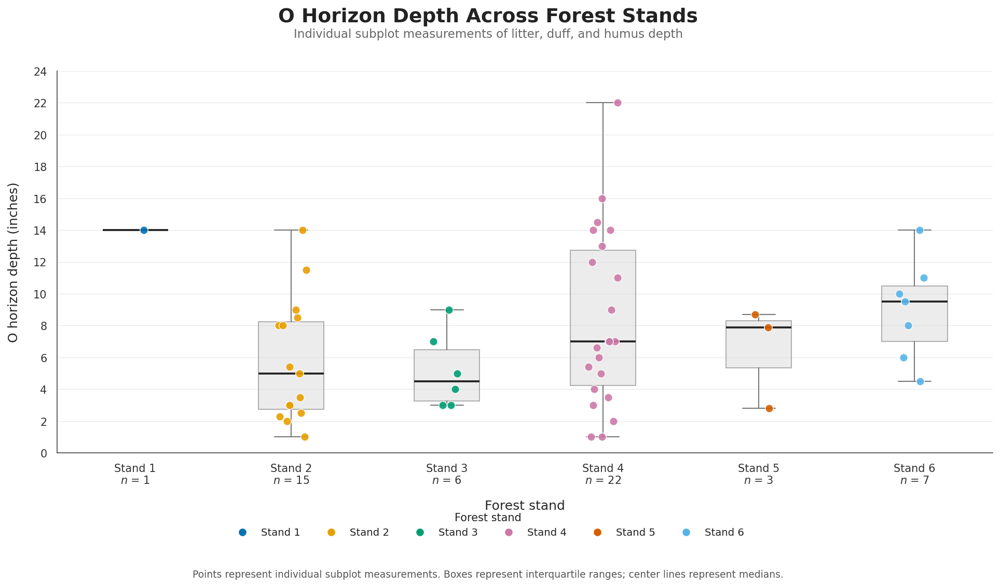

In [219]:
# STEP 202: Visualize O horizon depth across the six forest stands.
#
# Each point represents one subplot measurement.
# Boxplots summarize the median and interquartile range.
# Point colors represent forest stand using the original palette.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Define the original six-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

stand_order = [1, 2, 3, 4, 5, 6]

# ------------------------------------------------------------
# 2. Prepare the O horizon plotting data
# ------------------------------------------------------------

# Create a separate copy of the O horizon analysis dataset.
o_horizon_plot = o_horizon.copy()

# Define the measurement column.
depth_column = 'O Horizon Depth (Litter, Duff, Humus) (in)'

# Extract measurements separately for each stand.
depth_by_stand = [
    o_horizon_plot.loc[
        o_horizon_plot['Stand ID'] == stand,
        depth_column
    ].dropna().values
    for stand in stand_order
]

# Calculate the sample size for each stand.
sample_sizes = [
    len(values) for values in depth_by_stand
]

# ------------------------------------------------------------
# 3. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#444444',
    'text.color': '#222222'
})

# Create the figure.
fig, ax = plt.subplots(figsize=(13.5, 7.8))

# ------------------------------------------------------------
# 4. Create boxplots
# ------------------------------------------------------------

# Draw boxplots to summarize the distribution within each stand.
boxplot = ax.boxplot(
    depth_by_stand,
    positions=np.arange(1, 7),
    widths=0.42,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': '#222222',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    capprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    boxprops={
        'edgecolor': '#666666',
        'linewidth': 1.0
    }
)

# Use a neutral, partially transparent box fill.
for box in boxplot['boxes']:
    box.set_facecolor('#D9D9D9')
    box.set_alpha(0.48)
    box.set_edgecolor('#666666')

# ------------------------------------------------------------
# 5. Plot individual subplot observations
# ------------------------------------------------------------

# Use a fixed random seed for reproducible horizontal jitter.
rng = np.random.default_rng(42)

# Add a small horizontal offset to separate overlapping observations.
o_horizon_plot['Jitter'] = rng.uniform(
    -0.10,
    0.10,
    size=len(o_horizon_plot)
)

# Plot each stand using its original color.
for stand in stand_order:

    # Select observations for the current stand.
    stand_data = o_horizon_plot[
        o_horizon_plot['Stand ID'] == stand
    ]

    # Plot individual O horizon measurements.
    ax.scatter(
        stand + stand_data['Jitter'],
        stand_data[depth_column],
        s=55,
        color=stand_colors[stand],
        edgecolor='white',
        linewidth=0.7,
        alpha=0.9,
        zorder=3
    )

# ------------------------------------------------------------
# 6. Format the x-axis
# ------------------------------------------------------------

# Display stand names and sample sizes.
ax.set_xticks(np.arange(1, 7))

ax.set_xticklabels([
    f'Stand {stand}\n$n$ = {n}'
    for stand, n in zip(stand_order, sample_sizes)
])

ax.set_xlabel(
    'Forest stand',
    labelpad=13,
    fontweight='medium'
)

# ------------------------------------------------------------
# 7. Format the y-axis
# ------------------------------------------------------------

ax.set_ylabel(
    'O horizon depth (inches)',
    labelpad=12,
    fontweight='medium'
)

# Use consistent two-inch intervals.
ax.set_yticks(np.arange(0, 25, 2))

# Set the vertical plotting range.
ax.set_ylim(0, 24)

# ------------------------------------------------------------
# 8. Refine gridlines and plot boundaries
# ------------------------------------------------------------

# Use subtle horizontal gridlines.
ax.grid(
    axis='y',
    color='#E5E5E5',
    linestyle='-',
    linewidth=0.65,
    alpha=0.8
)

# Remove unnecessary vertical gridlines.
ax.grid(axis='x', visible=False)

# Keep gridlines behind the observations.
ax.set_axisbelow(True)

# Remove upper and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ------------------------------------------------------------
# 9. Add title and subtitle
# ------------------------------------------------------------

fig.suptitle(
    'O Horizon Depth Across Forest Stands',
    fontsize=18,
    fontweight='bold',
    y=0.965
)

fig.text(
    0.5,
    0.915,
    'Individual subplot measurements of litter, duff, and humus depth',
    ha='center',
    fontsize=11,
    color='#666666'
)

# ------------------------------------------------------------
# 10. Add the stand-color legend
# ------------------------------------------------------------

stand_legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor=stand_colors[stand],
        markeredgecolor='white',
        markersize=8,
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

fig.legend(
    handles=stand_legend_handles,
    title='Forest stand',
    loc='lower center',
    bbox_to_anchor=(0.5, 0.075),
    ncol=6,
    frameon=False,
    fontsize=9.5,
    title_fontsize=10
)

# ------------------------------------------------------------
# 11. Add an explanatory note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.025,
    'Points represent individual subplot measurements. '
    'Boxes represent interquartile ranges; center lines represent medians.',
    ha='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 12. Adjust layout
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.86,
    bottom=0.23
)

# ------------------------------------------------------------
# 13. Export the figure
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'O_Horizon_Depth_by_Stand.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    export_dir / 'O_Horizon_Depth_by_Stand.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

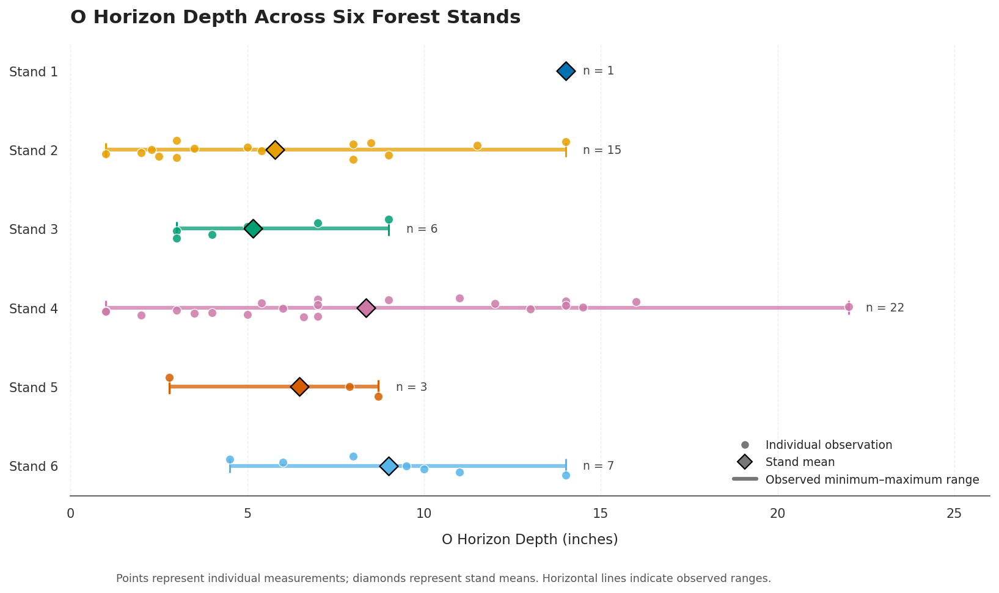

In [220]:

# STEP 203: Create a publication-style mean-and-range plot of O horizon depth

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Identify the column containing O horizon depth measurements.
depth_col = 'O Horizon Depth (Litter, Duff, Humus) (in)'

# Define the original six-stand color palette.
stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9'   # Sky blue
}

# Calculate the mean, minimum, maximum, and sample size for each stand.
depth_summary = (
    o_horizon
    .groupby('Stand ID')[depth_col]
    .agg(['mean', 'min', 'max', 'count'])
    .reindex([1, 2, 3, 4, 5, 6])
)

# Create a figure and axis with a wide layout.
fig, ax = plt.subplots(figsize=(11, 6.5))

# Set the vertical position for each stand.
stand_positions = {stand: position for position, stand in enumerate([1, 2, 3, 4, 5, 6])}

# Plot the observed range, individual measurements, and mean for each stand.
for stand in [1, 2, 3, 4, 5, 6]:

    # Retrieve the measurements for the current stand.
    stand_data = o_horizon[o_horizon['Stand ID'] == stand][depth_col].dropna()

    # Retrieve the summary statistics for the current stand.
    mean_depth = depth_summary.loc[stand, 'mean']
    min_depth = depth_summary.loc[stand, 'min']
    max_depth = depth_summary.loc[stand, 'max']
    sample_size = int(depth_summary.loc[stand, 'count'])

    # Assign the stand's vertical plotting position and original color.
    y_position = stand_positions[stand]
    color = stand_colors[stand]

    # Draw a horizontal line representing the observed minimum-to-maximum range.
    ax.hlines(
        y=y_position,
        xmin=min_depth,
        xmax=max_depth,
        color=color,
        linewidth=3,
        alpha=0.75,
        zorder=1
    )

    # Add small vertical caps to mark the minimum and maximum observations.
    ax.vlines(
        x=[min_depth, max_depth],
        ymin=y_position - 0.09,
        ymax=y_position + 0.09,
        color=color,
        linewidth=1.5,
        zorder=2
    )

    # Plot the individual depth measurements as small circles.
    # A slight vertical offset helps distinguish overlapping observations.
    if sample_size > 1:
        offsets = np.linspace(-0.12, 0.12, sample_size)
    else:
        offsets = np.array([0])

    ax.scatter(
        stand_data,
        y_position + offsets,
        color=color,
        edgecolor='white',
        linewidth=0.7,
        s=48,
        alpha=0.85,
        zorder=3
    )

    # Plot the stand mean as a larger diamond with a dark outline.
    ax.scatter(
        mean_depth,
        y_position,
        marker='D',
        s=105,
        color=color,
        edgecolor='black',
        linewidth=1.1,
        zorder=4
    )

    # Add the sample size to the right of each stand's observed range.
    ax.text(
        max_depth + 0.5,
        y_position,
        f'n = {sample_size}',
        va='center',
        ha='left',
        fontsize=9,
        color='#444444'
    )

# Set stand labels on the vertical axis.
ax.set_yticks(range(6))
ax.set_yticklabels([f'Stand {stand}' for stand in range(1, 7)])

# Label the horizontal axis and provide a descriptive title.
ax.set_xlabel('O Horizon Depth (inches)', fontsize=11, labelpad=10)
ax.set_title(
    'O Horizon Depth Across Six Forest Stands',
    fontsize=15,
    fontweight='bold',
    loc='left',
    pad=16
)

# Add a subtle vertical grid to make depth values easier to compare.
ax.xaxis.grid(True, linestyle='--', linewidth=0.7, alpha=0.3)
ax.set_axisbelow(True)

# Set the horizontal axis limits with room for sample-size labels.
ax.set_xlim(0, depth_summary['max'].max() + 4)

# Reverse the vertical axis so Stand 1 appears at the top.
ax.invert_yaxis()

# Remove unnecessary plot borders for a cleaner report-style appearance.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# Create a legend explaining the three visual elements.
legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='white',
        markersize=7,
        label='Individual observation'
    ),
    Line2D(
        [0], [0],
        marker='D',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='black',
        markersize=8,
        label='Stand mean'
    ),
    Line2D(
        [0], [0],
        color='#777777',
        linewidth=3,
        label='Observed minimum–maximum range'
    )
]

ax.legend(
    handles=legend_elements,
    loc='lower right',
    frameon=False,
    fontsize=9
)

# Add a concise explanatory note below the figure.
fig.text(
    0.12, 0.015,
    'Points represent individual measurements; diamonds represent stand means. '
    'Horizontal lines indicate observed ranges.',
    fontsize=8.5,
    color='#555555'
)

# Adjust spacing so labels, legend, and explanatory text remain readable.
plt.tight_layout(rect=[0, 0.05, 1, 1])

# Save the figure in high-resolution PNG and vector PDF formats.
plt.savefig(
    'O_Horizon_Depth_Mean_Range.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'O_Horizon_Depth_Mean_Range.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()
